## Functions for the main program

In [1]:
import cv2
import numpy as np
def fill_contours(path_mask):
    # Read the mask from the path
    mask = cv2.imread(path_mask, cv2.IMREAD_GRAYSCALE)

    # Get outer contours and draw filled ones as white on a black background
    contours = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = contours[0] if len(contours) == 2 else contours[1]
    result = np.zeros_like(mask)
    
    for contour in contours:
        cv2.drawContours(result, [contour], 0, 255, -1)
    
    result = np.array(result/result.max(), dtype=np.uint8)
    return result

In [2]:
import os
import pandas as pd
import numpy as np
from tifffile import imread
import cv2
def calculate_average_intensity(base_file, unfilled_cytoplasmic_mask, unfilled_nuclear_mask):
    
    # Load the image using tifffile
    img = imread(base_file)

    # Check if the last dimension is less than 512
    if img.shape[-1] < 512:
        # Move the last dimension to the third position
        img = np.moveaxis(img, -1, 2)

    if img.shape[2] != 3:
        print(base_file)
        print(img.shape)
        print('The image does not have 3 channels')
        return np.nan, np.nan, np.nan
    
    # Fill the masks
    filled_cytoplasmic_mask = fill_contours(unfilled_cytoplasmic_mask)
    filled_nuclear_mask = fill_contours(unfilled_nuclear_mask)
    filled_full_cell_mask = filled_cytoplasmic_mask + filled_nuclear_mask


    # Calculate the pixel counts
    pixel_count_whole_cell = np.count_nonzero(filled_full_cell_mask)
    pixel_count_cytoplasm = np.count_nonzero(filled_cytoplasmic_mask)
    pixel_count_nuclear = np.count_nonzero(filled_nuclear_mask)

    # Initialize a list to store the results
    data = []

    # Iterate over each time point
    for t in range(img.shape[0]):
        # Multiply the filled masks by the 488 channel of the image
        mask_cropped_image_whole_cell = img[t, :, 2, :, :] * filled_full_cell_mask
        mask_cropped_image_cytoplasm = img[t, :, 2, :, :] * filled_cytoplasmic_mask
        mask_cropped_image_nuclear = img[t, :, 2, :, :] * filled_nuclear_mask

        # Calculate the total intensity for each group
        total_intensity_whole_cell = np.sum(mask_cropped_image_whole_cell)
        total_intensity_cytoplasm = np.sum(mask_cropped_image_cytoplasm)
        total_intensity_nuclear = np.sum(mask_cropped_image_nuclear)

        # Append the results to the list
        data.append({
            'Time Point': t,
            'Total Intensity of the Cell': total_intensity_whole_cell,
            'Total Intensity of the Cytoplasm': total_intensity_cytoplasm,
            'Total Intensity of the Nucleus': total_intensity_nuclear,
            'Pixel Count of the Cell': pixel_count_whole_cell,
            'Pixel Count of the Cytoplasm': pixel_count_cytoplasm,
            'Pixel Count of the Nucleus': pixel_count_nuclear,
        })

    # Convert the list to a DataFrame
    df = pd.DataFrame(data)

    # Take the first 5 time points and calculate the average total intensity for each group
    first_5_time_points = df.head(5)
    
    # Take the top 3 time points and calculate the average total intensity for each group
    avg_total_intensity_whole_cell = first_5_time_points['Total Intensity of the Cell'].head(3).mean()
    avg_total_intensity_cytoplasm = first_5_time_points['Total Intensity of the Cytoplasm'].head(3).mean()
    avg_total_intensity_nuclear = first_5_time_points['Total Intensity of the Nucleus'].head(3).mean()

    return avg_total_intensity_whole_cell, avg_total_intensity_cytoplasm, avg_total_intensity_nuclear

In [3]:
import numpy as np
import trackpy as tp
import seaborn as sns
import matplotlib.pyplot as plt

def spot_detect_and_qc(img, minmass=6000, size=5):
    """
    Locates features in an image using trackpy locate function and creates a new image with a pixel at the location of the feature closest to the center. This pixel has the signal value of the feature.

    This function is used to identify and highlight the location of features in an image. This is useful for visualizing the features and their signal values from an croparray dataset with the 11x11 pad. This function can be used to identify or quality control the features in the image such as mRNA and translation spots.

    Parameters:
    img (numpy.ndarray): The input image.
    minmass (int, optional): The minimum integrated brightness. Defaults to 6000.
    size (int, optional): The size of the features in pixels. Defaults to 5.

    Returns:
    numpy.ndarray: A new image of the same size as the input image, with a pixel at the location of the feature closest to the center. The pixel value is the signal value of the feature.

    """
    features = tp.locate(img, size, minmass)
    new_img = np.zeros_like(img)
    if len(features) > 0:
        # Calculate the center of the image
        center_x = img.shape[1] / 2
        center_y = img.shape[0] / 2

        if len(features) > 1:
            # Calculate the Euclidean distance from each feature to the center
            distances = np.sqrt((features['x'] - center_x)**2 + (features['y'] - center_y)**2)
            # Find the index of the feature with the smallest distance
            closest_index = np.argmin(distances)
            x_value = features['x'].values[closest_index]
            y_value = features['y'].values[closest_index]
            signal_value = features['signal'].values[closest_index]
        else:
            x_value = features['x'].values[0]
            y_value = features['y'].values[0]
            signal_value = features['signal'].values[0]

        # Set the pixel at (x_value, y_value) to the maximum pixel value
        new_img[int(y_value), int(x_value)] = signal_value
    return new_img

In [4]:
import xarray as xr
from skimage.io import imread

def assign_masks(dataset, mask_paths):
    """
    Assigns mask values to a dataset based on the given mask paths.

    This function takes a dataset and a list of paths to mask images. It applies each mask to the dataset, creating a new variable for each mask. The variable is named according to the localization corresponding to the mask ("Nuclear Periphery", "Cytoplasm", or "Cytoplasmic Periphery"). The value of the variable for each spot is `True` if the mask value for that spot is greater than 0, and `NaN` otherwise.

    Parameters:
    dataset (xarray.Dataset): The dataset to which the masks will be applied. This dataset should have 'xc' and 'yc' coordinates representing the x and y coordinates of each spot, respectively. It should also have a 'xy_pad' variable representing the padding applied to the x and y coordinates.
    mask_paths (list of str): A list of paths to the mask images. The paths should be in the order ["path_to_first3rd_mask_img", "path_to_second3rd_mask_img", "path_to_last3rd_mask_img"].

    Returns:
    dataset (xarray.Dataset): The dataset with the mask values applied. The dataset will have three new variables: "Nuclear Periphery", "Cytoplasm", and "Cytoplasmic Periphery". Each variable will be a boolean indicating whether the corresponding mask has a value greater than 0 for each spot. If the mask value is not greater than 0, the variable value will be `NaN`.

    Example usage:
    mask_paths = ['path_to_first3rd_mask_img', 'path_to_second3rd_mask_img', 'path_to_last3rd_mask_img']
    dataset = assign_masks(testing, mask_paths)
    """

    def in_mask(center_pt, mask):
        my_xc, my_yc = center_pt[0], center_pt[1]
        return mask[my_yc,my_xc]

    mask_names = {
        1: "Nuclear Periphery",
        2: "Cytoplasm",
        3: "Cytoplasmic Periphery"
    }

    temp = xr.concat([dataset.xc-dataset.xy_pad.values,dataset.yc-dataset.xy_pad.values],dim='center_pt').assign_coords(center_pt=['xc','yc'])

    for i, mask_path in enumerate(mask_paths, start=1):
        mask_img = imread(mask_path)
        temp_mask = xr.apply_ufunc(in_mask, temp, input_core_dims=[['center_pt']], kwargs={'mask': mask_img}, vectorize=True)
        dataset[mask_names[i]] = xr.where(temp_mask > 0, True, float('nan'))

    return dataset

In [5]:
import pandas as pd

def calculate_grouped_average(df, average_column, group_by_columns):
    """
    Calculate the average of a specified column in a dataframe based on grouping columns.

    Parameters:
        df (pd.DataFrame): The input dataframe.
        average_column (str): The name of the column to calculate the average for.
        group_by_columns (list of str): The column names to group by.

    Returns:
        pd.DataFrame: A new dataframe containing the grouping columns and the calculated average.
    """
    # Group by the specified columns and calculate the mean
    grouped_df = (
        df.groupby(group_by_columns, as_index=False)
        .agg({average_column: 'mean'})
        .rename(columns={average_column: f'Super {average_column}'})
    )
    return grouped_df


In [6]:
def reduce_dtype(ds):
    for var in ds.data_vars:
        if var in ['RNA_spot_sig', 'translation_spot_sig']:
            ds[var] = ds[var].astype('float32')  # Higher precision for signals
        elif np.issubdtype(ds[var].dtype, np.floating):
            ds[var] = ds[var].astype('float16')
        elif np.issubdtype(ds[var].dtype, np.integer):
            ds[var] = ds[var].astype('int16')
    return ds

In [7]:
import pandas as pd
import numpy as np

def normalize_experimental_group(all_df, ctrl_group='SARS_CTRL', norm_group='Normalization_SARS_CTRL', exp_group='Nsp1_NoCTD_SARS_CTRL'):
    """
    Normalizes the RNA_spot_sig and translation_spot_sig for a given experimental group
    based on a normalization group.
    
    Parameters:
        all_df (pd.DataFrame): The dataframe containing experimental data.
        exp_group (str): The experimental group to be normalized.
        norm_group (str): The normalization group used for normalization.
    
    Returns:
        pd.DataFrame: The dataframe with normalized values for the experimental group.
    """
    
    # Ensure numeric columns
    all_df['RNA_spot_sig'] = pd.to_numeric(all_df['RNA_spot_sig'], errors='coerce')
    all_df['translation_spot_sig'] = pd.to_numeric(all_df['translation_spot_sig'], errors='coerce')

    # 1. Normalize RNA Signal
    # Filter rows where RNA_spot_sig is greater than zero
    norm_rna_df = all_df[(all_df['Exp_G'] == norm_group) & (all_df['RNA_spot_sig'] > 0)]
    ctrl_rna_df = all_df[(all_df['Exp_G'] == ctrl_group) & (all_df['RNA_spot_sig'] > 0)]
    
    print(f"Rows in norm_rna_df: {len(norm_rna_df)}")
    print(f"Rows in ctrl_rna_df: {len(ctrl_rna_df)}")
    
    if len(norm_rna_df) == 0 or len(ctrl_rna_df) == 0:
        print("Warning: One or both RNA DataFrames are empty. Check group names or data.")
        return all_df  # Return unchanged dataframe if no valid data
    
    # Calculate the mean RNA signals
    norm_rna_mean = norm_rna_df['RNA_spot_sig'].mean()
    ctrl_rna_mean = ctrl_rna_df['RNA_spot_sig'].mean()
    
    print(f"Normalization Group RNA Mean: {norm_rna_mean}")
    print(f"Control Group RNA Mean: {ctrl_rna_mean}")

    # Check for invalid means
    if pd.isna(norm_rna_mean) or pd.isna(ctrl_rna_mean) or ctrl_rna_mean == 0:
        print("Error: RNA means are invalid (nan or zero). Cannot compute normalization factor.")
        return all_df
    
    # Compute RNA normalization factor
    norm_rna_factor = norm_rna_mean / ctrl_rna_mean
    print(f"RNA Normalization Factor: {norm_rna_factor}")
    
    # Apply normalization factor
    all_df.loc[all_df['Exp_G'] == exp_group, 'RNA_spot_sig'] /= norm_rna_factor
    all_df.loc[all_df['Exp_G'] == norm_group, 'RNA_spot_sig'] /= norm_rna_factor

    # 2. Normalize Translation Signal
    # Filter rows where translation_spot_sig is greater than zero
    norm_translation_df = all_df[(all_df['Exp_G'] == norm_group) & (all_df['translation_spot_sig'] > 0)]
    ctrl_translation_df = all_df[(all_df['Exp_G'] == ctrl_group) & (all_df['translation_spot_sig'] > 0)]
    
    print(f"Rows in norm_translation_df: {len(norm_translation_df)}")
    print(f"Rows in ctrl_translation_df: {len(ctrl_translation_df)}")
    
    if len(norm_translation_df) == 0 or len(ctrl_translation_df) == 0:
        print("Warning: One or both Translation DataFrames are empty. Check group names or data.")
        return all_df
    
    # Calculate the mean translation signals
    norm_translation_mean = norm_translation_df['translation_spot_sig'].mean()
    ctrl_translation_mean = ctrl_translation_df['translation_spot_sig'].mean()
    
    print(f"Normalization Group Translation Mean: {norm_translation_mean}")
    print(f"Control Group Translation Mean: {ctrl_translation_mean}")

    # Check for invalid means
    if pd.isna(norm_translation_mean) or pd.isna(ctrl_translation_mean) or ctrl_translation_mean == 0:
        print("Error: Translation means are invalid (nan or zero). Cannot compute normalization factor.")
        return all_df
    
    # Compute translation normalization factor
    norm_translation_factor = norm_translation_mean / ctrl_translation_mean
    print(f"Translation Normalization Factor: {norm_translation_factor}")
    
    # Apply normalization factor
    all_df.loc[all_df['Exp_G'] == exp_group, 'translation_spot_sig'] /= norm_translation_factor
    all_df.loc[all_df['Exp_G'] == norm_group, 'translation_spot_sig'] /= norm_translation_factor

    return all_df

In [8]:
# Function to compute jittered x-positions
def compute_jittered_x(data, x_col, order, jitter=0.1, dodge=True, dodge_width=0.4):
    x_positions = []
    for i, category in enumerate(order):
        mask = data[x_col] == category
        n_points = mask.sum()
        if n_points == 0:
            continue
        base_x = i + (dodge_width if dodge else 0)
        jittered = base_x + np.random.uniform(-jitter, jitter, n_points)
        x_positions.extend(jittered)
    return np.array(x_positions)

In [9]:
def plot_open_circles_with_hue(ax, data, x, y, hue, order=None, hue_order=None,
                               size=20, linewidth=2, dodge=True,
                               marker='o', edgecolor='black', zorder=8,
                               jitter=False, jitter_strength=0.06, random_state=None):
    """
    Plot open circle markers on a categorical axis with hue and dodge, aligned with a seaborn plot.

    Parameters:
    - ax: Matplotlib axes object
    - data: DataFrame with the data to plot
    - x: Column name for x-axis
    - y: Column name for y-axis
    - hue: Column name for hue
    - order: List of x-axis categories
    - hue_order: List of hue categories
    - size: Marker size
    - linewidth: Outline thickness
    - dodge: Boolean to separate points by hue
    - marker: Marker style
    - edgecolor: Outline color
    - zorder: Plotting order
    - jitter: Whether to add x-axis jitter
    - jitter_strength: Magnitude of horizontal jitter
    - random_state: Seed for reproducibility
    """
    rng = np.random.default_rng(random_state)

    # Filter data to only include x values in order
    if order is not None:
        data = data[data[x].isin(order)].copy()

    # Set defaults
    if order is None:
        order = list(data[x].dropna().unique())
    if hue_order is None:
        hue_order = list(data[hue].dropna().unique())

    n_hue = len(hue_order)
    bar_width = 0.8 / n_hue if n_hue > 1 and dodge else 0.8

    for i, x_cat in enumerate(order):
        for j, hue_cat in enumerate(hue_order):
            subset = data[(data[x] == x_cat) & (data[hue] == hue_cat)]
            if subset.empty:
                continue

            # Base x-position with dodge
            if dodge and n_hue > 1:
                x_pos = i + (j - (n_hue - 1) / 2) * bar_width
            else:
                x_pos = i

            y_vals = subset[y].values

            # Add optional jitter
            if jitter:
                x_vals = x_pos + rng.uniform(-jitter_strength, jitter_strength, size=len(y_vals))
            else:
                x_vals = np.full(len(y_vals), x_pos)

            ax.scatter(
                x_vals,
                y_vals,
                facecolors='gainsboro',
                edgecolors=edgecolor,
                s=size**2,
                linewidths=linewidth,
                marker=marker,
                zorder=zorder,
                label=hue_cat if i == 0 else None
            )

    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, fontsize=40, rotation=75)
    
blue_palette = sns.color_palette(["#00D8D8", "#029090", "#67FFFF"])
magenta_palette = sns.color_palette(["#Ef1EEF", "#B700B7", "#FF99FF"])

In [133]:
# Paired t-test summary for replicate-average data.
#
# Drop-in replacement for the previous print_paired_ttest_summary().
#
# Updates relative to the older version:
#
#   1. Keeps the original baseline comparisons:
#          first x-level vs every other x-level
#
#      Example:
#          No Nsp1 vs Nsp1
#          No Nsp1 vs NoCTD Nsp1
#
#   2. Adds cross-type comparisons when applicable:
#          all remaining pairwise x-level comparisons
#
#      Example:
#          Nsp1 vs NoCTD Nsp1
#
#   3. Preserves the existing function call pattern.
#
#      Your existing calls do not need to change:
#
#          print_paired_ttest_summary(
#              data=superplot_translation,
#              x="Experimental Type",
#              y="Super Cell Average Translation Signal",
#              hue="Experimental Group",
#              pair_col="Replicate Number",
#              order=order,
#              hue_order=None,
#              compare_x=True,
#              compare_hue=False,
#              verbose=True
#          )

import numpy as np
import pandas as pd

from itertools import combinations
from scipy.stats import ttest_rel


def print_paired_ttest_summary(
    data,
    x,
    y,
    pair_col="Replicate_Number",
    hue=None,
    order=None,
    hue_order=None,
    alternative="two-sided",
    star_thresholds=(
        (1e-4, "****"),
        (1e-3, "***"),
        (1e-2, "**"),
        (5e-2, "*"),
    ),
    hide_ns=False,
    format_p=lambda p: f"{p:.3g}" if pd.notna(p) else "nan",
    printer=print,
    verbose=False,
    compare_x=True,
    compare_hue=True,
    duplicate_policy="mean",
    compare_all_x_pairs=True,
    compare_all_hue_pairs=True,
):
    """
    Paired t-test summary for biological-replicate-average data.

    This function expects one value per biological replicate per
    condition, or it will average duplicate rows when
    duplicate_policy="mean".

    Comparisons
    -----------
    If hue is None:

        A. Across x:
            - baseline x level vs every other x level
            - optionally, all remaining pairwise x comparisons

    If hue is provided:

        A. Across x within each hue:
            - baseline x level vs every other x level
            - optionally, all remaining pairwise x comparisons

        B. Across hue within each x:
            - baseline hue level vs every other hue level
            - optionally, all remaining pairwise hue comparisons

    Notes
    -----
    For the Host UTR plots where:

        x = "Experimental Type"
        hue = "Experimental Group"

    and the order is:

        ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

    this function will test:

        No Nsp1 vs Nsp1
        No Nsp1 vs NoCTD Nsp1
        Nsp1 vs NoCTD Nsp1

    within each Experimental Group.

    Parameters
    ----------
    data : pandas.DataFrame
        Dataframe containing replicate-average values.

    x : str
        Column defining the main condition, usually
        "Experimental Type".

    y : str
        Numeric column to test.

    pair_col : str
        Column defining matched biological replicate identity.

    hue : str or None
        Optional grouping variable, usually "Experimental Group".

    order : list or None
        Desired x-level order. The first level is treated as the
        baseline/control x level.

    hue_order : list or None
        Desired hue-level order. The first level is treated as the
        baseline hue level.

    compare_x : bool
        Whether to compare x levels.

    compare_hue : bool
        Whether to compare hue levels.

    compare_all_x_pairs : bool
        If True, also compare non-baseline x pairs.

    compare_all_hue_pairs : bool
        If True, also compare non-baseline hue pairs.

    duplicate_policy : {"mean", "raise"}
        How to handle duplicate rows for the same replicate and
        condition.
    """

    # ============================================================
    # Prepare dataframe
    # ============================================================

    df = data.copy()

    required_cols = [
        x,
        y,
        pair_col,
    ]

    if hue is not None:

        required_cols.append(
            hue
        )


    missing_cols = [
        col
        for col in required_cols
        if col not in df.columns
    ]

    if missing_cols:

        raise ValueError(
            f"Missing required columns: {missing_cols}"
        )


    df[y] = pd.to_numeric(
        df[y],
        errors="coerce",
    )


    df = (
        df
        .dropna(
            subset=required_cols
        )
        .copy()
    )


    if df.empty:

        if verbose:

            printer(
                "No valid rows remained after removing missing values."
            )

        return pd.DataFrame()


    # ============================================================
    # Determine x and hue levels
    # ============================================================

    if order is None:

        x_levels = list(
            df[x]
            .dropna()
            .unique()
        )

    else:

        x_levels = [
            level
            for level in order
            if level in set(
                df[x]
                .dropna()
                .unique()
            )
        ]


    if hue is None:

        h_levels = [
            None
        ]

    else:

        if hue_order is None:

            h_levels = list(
                df[hue]
                .dropna()
                .unique()
            )

        else:

            h_levels = [
                level
                for level in hue_order
                if level in set(
                    df[hue]
                    .dropna()
                    .unique()
                )
            ]


    # ============================================================
    # Helper functions
    # ============================================================

    def p_to_stars(
        p,
    ):

        if pd.isna(
            p
        ):

            return "nan"

        for threshold, label in star_thresholds:

            if p < threshold:

                return label

        return "ns"


    def _format_level(
        value,
    ):

        if value is None:

            return "None"

        return str(
            value
        )


    def _filter_df(
        fixed_filters,
    ):

        out = df.copy()

        for column, value in fixed_filters.items():

            out = (
                out.loc[
                    out[column].eq(
                        value
                    )
                ]
                .copy()
            )

        return out


    def _paired_vals(
        level_col,
        level0,
        level1,
        fixed_filters=None,
    ):
        """
        Return paired arrays for level0 and level1 within level_col,
        matched by pair_col.
        """

        if fixed_filters is None:

            fixed_filters = {}


        sub = (
            _filter_df(
                fixed_filters
            )
            .loc[
                lambda frame:
                frame[level_col].isin(
                    [
                        level0,
                        level1,
                    ]
                ),
                [
                    pair_col,
                    level_col,
                    y,
                ],
            ]
            .copy()
        )


        sub[y] = pd.to_numeric(
            sub[y],
            errors="coerce",
        )


        sub = (
            sub
            .dropna(
                subset=[
                    pair_col,
                    level_col,
                    y,
                ]
            )
            .copy()
        )


        if sub.empty:

            return (
                np.array([]),
                np.array([]),
                pd.DataFrame(),
            )


        duplicate_mask = sub.duplicated(
            subset=[
                pair_col,
                level_col,
            ],
            keep=False,
        )


        if duplicate_mask.any():

            duplicate_rows = (
                sub.loc[
                    duplicate_mask
                ]
                .sort_values(
                    [
                        pair_col,
                        level_col,
                    ]
                )
            )


            if duplicate_policy == "raise":

                raise ValueError(
                    "Duplicate rows found for the same paired "
                    "replicate/condition. This function expects one "
                    "replicate-average value per condition. Either "
                    "pre-aggregate your dataframe or use "
                    "duplicate_policy='mean'.\n\n"
                    f"{duplicate_rows}"
                )


            elif duplicate_policy == "mean":

                if verbose:

                    printer(
                        "[warn] Duplicate rows found for the same "
                        "paired replicate/condition. Averaging "
                        "duplicates before paired t-test."
                    )


                sub = (
                    sub
                    .groupby(
                        [
                            pair_col,
                            level_col,
                        ],
                        as_index=False,
                    )[y]
                    .mean()
                )


            else:

                raise ValueError(
                    "duplicate_policy must be either "
                    "'mean' or 'raise'."
                )


        wide = (
            sub
            .pivot(
                index=pair_col,
                columns=level_col,
                values=y,
            )
        )


        if (
            level0 not in wide.columns
            or level1 not in wide.columns
        ):

            return (
                np.array([]),
                np.array([]),
                wide,
            )


        wide = (
            wide[
                [
                    level0,
                    level1,
                ]
            ]
            .dropna()
        )


        vals0 = (
            wide[level0]
            .astype(float)
            .values
        )


        vals1 = (
            wide[level1]
            .astype(float)
            .values
        )


        return (
            vals0,
            vals1,
            wide,
        )


    def _run_paired_test(
        vals0,
        vals1,
    ):

        if (
            len(vals0) < 2
            or len(vals1) < 2
        ):

            return np.nan


        if len(vals0) != len(vals1):

            raise ValueError(
                "Paired arrays have unequal length. "
                "This should not happen after alignment."
            )


        return float(
            ttest_rel(
                vals0,
                vals1,
                alternative=alternative,
            )
            .pvalue
        )


    def _append_result(
        results,
        test_group,
        contrast,
        x0,
        x1,
        hue0,
        hue1,
        vals0,
        vals1,
        diff_column,
    ):

        p = _run_paired_test(
            vals0,
            vals1,
        )


        stars = p_to_stars(
            p
        )


        mean0 = float(
            np.mean(
                vals0
            )
        )


        mean1 = float(
            np.mean(
                vals1
            )
        )


        mean_diff = float(
            np.mean(
                vals1
                -
                vals0
            )
        )


        if not (
            hide_ns
            and stars == "ns"
        ):

            printer(
                f"{contrast}: "
                f"n_pairs={vals0.size}, "
                f"mean={mean0:.3g}/{mean1:.3g}, "
                f"mean_diff={mean_diff:.3g}, "
                f"p={format_p(p)}, "
                f"{stars}"
            )


        row = {
            "test_group":
                test_group,

            "contrast":
                contrast,

            "x0":
                x0,

            "x1":
                x1,

            "hue0":
                hue0,

            "hue1":
                hue1,

            "n_pairs":
                int(
                    vals0.size
                ),

            "mean0":
                mean0,

            "mean1":
                mean1,

            "pvalue":
                p,

            "stars":
                stars,

            "paired_by":
                pair_col,
        }


        row[
            diff_column
        ] = mean_diff


        results.append(
            row
        )


    def _baseline_and_cross_pairs(
        levels,
    ):
        """
        Return baseline comparisons first, then non-baseline
        cross comparisons.

        Example:
            [A, B, C]

        returns:
            baseline:
                A vs B
                A vs C

            cross:
                B vs C
        """

        if len(
            levels
        ) < 2:

            return []


        baseline = levels[0]


        baseline_pairs = [
            (
                baseline,
                level,
                "baseline",
            )
            for level in levels[1:]
        ]


        cross_pairs = []

        if compare_all_x_pairs:

            nonbaseline_levels = levels[1:]

            cross_pairs = [
                (
                    level0,
                    level1,
                    "cross",
                )
                for level0, level1
                in combinations(
                    nonbaseline_levels,
                    2,
                )
            ]


        return (
            baseline_pairs
            +
            cross_pairs
        )


    def _baseline_and_cross_hue_pairs(
        levels,
    ):
        """
        Return baseline hue comparisons first, then non-baseline
        hue cross comparisons.
        """

        if len(
            levels
        ) < 2:

            return []


        baseline = levels[0]


        baseline_pairs = [
            (
                baseline,
                level,
                "baseline",
            )
            for level in levels[1:]
        ]


        cross_pairs = []

        if compare_all_hue_pairs:

            nonbaseline_levels = levels[1:]

            cross_pairs = [
                (
                    level0,
                    level1,
                    "cross",
                )
                for level0, level1
                in combinations(
                    nonbaseline_levels,
                    2,
                )
            ]


        return (
            baseline_pairs
            +
            cross_pairs
        )


    # ============================================================
    # Run tests
    # ============================================================

    results = []


    # ============================================================
    # Case 1: No hue
    # ============================================================

    if hue is None:

        if len(
            x_levels
        ) < 2:

            if verbose:

                printer(
                    "Not enough x levels to compare."
                )

            return pd.DataFrame()


        if compare_x:

            printer(
                "Across x, paired by replicate:"
            )


            for level0, level1, comparison_kind in (
                _baseline_and_cross_pairs(
                    x_levels
                )
            ):

                vals0, vals1, wide = _paired_vals(
                    level_col=x,
                    level0=level0,
                    level1=level1,
                )


                if vals0.size < 2:

                    if verbose:

                        printer(
                            f"[skip] {level0} vs {level1}: "
                            f"only {vals0.size} matched pairs."
                        )

                    continue


                test_group = (
                    "x|paired_baseline"
                    if comparison_kind == "baseline"
                    else "x|paired_cross"
                )


                _append_result(
                    results=results,
                    test_group=test_group,
                    contrast=(
                        f"{_format_level(level0)} "
                        f"vs {_format_level(level1)}"
                    ),
                    x0=level0,
                    x1=level1,
                    hue0=None,
                    hue1=None,
                    vals0=vals0,
                    vals1=vals1,
                    diff_column="mean_diff_x1_minus_x0",
                )


    # ============================================================
    # Case 2: With hue
    # ============================================================

    else:

        # --------------------------------------------------------
        # A. Across x within each hue
        # --------------------------------------------------------

        if compare_x:

            header_printed = False


            for hv in h_levels:

                for level0, level1, comparison_kind in (
                    _baseline_and_cross_pairs(
                        x_levels
                    )
                ):

                    vals0, vals1, wide = _paired_vals(
                        level_col=x,
                        level0=level0,
                        level1=level1,
                        fixed_filters={
                            hue:
                                hv
                        },
                    )


                    if vals0.size < 2:

                        if verbose:

                            printer(
                                f"[skip] [hue={hv}] "
                                f"{level0} vs {level1}: "
                                f"only {vals0.size} matched pairs."
                            )

                        continue


                    if not header_printed:

                        printer(
                            "Across x within hue, paired by replicate:"
                        )

                        header_printed = True


                    test_group = (
                        "x|within_hue|paired_baseline"
                        if comparison_kind == "baseline"
                        else "x|within_hue|paired_cross"
                    )


                    _append_result(
                        results=results,
                        test_group=test_group,
                        contrast=(
                            f"[hue={_format_level(hv)}] "
                            f"{_format_level(level0)} "
                            f"vs {_format_level(level1)}"
                        ),
                        x0=level0,
                        x1=level1,
                        hue0=hv,
                        hue1=hv,
                        vals0=vals0,
                        vals1=vals1,
                        diff_column="mean_diff_x1_minus_x0",
                    )


        # --------------------------------------------------------
        # B. Across hue within each x
        # --------------------------------------------------------

        if (
            compare_hue
            and len(
                h_levels
            )
            >= 2
        ):

            header_printed = False


            for xv in x_levels:

                for level0, level1, comparison_kind in (
                    _baseline_and_cross_hue_pairs(
                        h_levels
                    )
                ):

                    vals0, vals1, wide = _paired_vals(
                        level_col=hue,
                        level0=level0,
                        level1=level1,
                        fixed_filters={
                            x:
                                xv
                        },
                    )


                    if vals0.size < 2:

                        if verbose:

                            printer(
                                f"[skip] [x={xv}] "
                                f"{level0} vs {level1}: "
                                f"only {vals0.size} matched pairs."
                            )

                        continue


                    if not header_printed:

                        printer(
                            "\nAcross hue within x, paired by replicate:"
                        )

                        header_printed = True


                    test_group = (
                        "hue|within_x|paired_baseline"
                        if comparison_kind == "baseline"
                        else "hue|within_x|paired_cross"
                    )


                    _append_result(
                        results=results,
                        test_group=test_group,
                        contrast=(
                            f"[x={_format_level(xv)}] "
                            f"{_format_level(level0)} "
                            f"vs {_format_level(level1)}"
                        ),
                        x0=xv,
                        x1=xv,
                        hue0=level0,
                        hue1=level1,
                        vals0=vals0,
                        vals1=vals1,
                        diff_column="mean_diff_hue1_minus_hue0",
                    )


       # ============================================================
    # Return table
    # ============================================================

    results_df = pd.DataFrame(
        results
    )


    if (
        results_df.empty
        and verbose
    ):

        printer(
            "No paired comparisons were performed."
        )


    # ============================================================
    # MANUSCRIPT SUMMARY
    #
    # Print mean ± SEM for every measurement.
    #
    # IMPORTANT:
    # The input dataframe contains biological-replicate averages,
    # so mean and SEM are calculated across biological replicates.
    #
    # If duplicate rows exist for the same biological replicate
    # and condition, they are first averaged so that each
    # biological replicate contributes only one value.
    # ============================================================

    printer(
        "\n"
        + "=" * 70
    )

    printer(
        "MEAN ± SEM ACROSS BIOLOGICAL REPLICATES"
    )

    printer(
        "=" * 70
    )


    # ------------------------------------------------------------
    # Build one value per biological replicate per condition
    # ------------------------------------------------------------

    if hue is None:

        summary_group_columns = [
            x,
            pair_col,
        ]

    else:

        summary_group_columns = [
            hue,
            x,
            pair_col,
        ]


    manuscript_summary_data = (

        df

        .groupby(
            summary_group_columns,
            dropna=False,
            as_index=False,
        )[
            y
        ]

        .mean()
    )


    # ============================================================
    # CASE 1:
    # No hue
    # ============================================================

    if hue is None:


        for xv in x_levels:


            vals = (

                manuscript_summary_data.loc[

                    manuscript_summary_data[
                        x
                    ].eq(
                        xv
                    ),

                    y,
                ]

                .astype(float)

                .dropna()

                .values
            )


            n_replicates = int(
                vals.size
            )


            if n_replicates == 0:

                continue


            mean_value = float(
                np.mean(
                    vals
                )
            )


            if n_replicates > 1:

                sem_value = float(

                    np.std(
                        vals,
                        ddof=1,
                    )

                    /

                    np.sqrt(
                        n_replicates
                    )
                )

            else:

                sem_value = np.nan


            if np.isfinite(
                sem_value
            ):

                printer(

                    f"{_format_level(xv)}: "
                    f"{mean_value:.3g} ± "
                    f"{sem_value:.3g} SEM "
                    f"(n={n_replicates})"
                )

            else:

                printer(

                    f"{_format_level(xv)}: "
                    f"{mean_value:.3g} ± "
                    f"NA SEM "
                    f"(n={n_replicates})"
                )


    # ============================================================
    # CASE 2:
    # Hue present
    # ============================================================

    else:


        for hv in h_levels:


            printer(
                f"\n[hue={_format_level(hv)}]"
            )


            hue_summary_data = (

                manuscript_summary_data.loc[

                    manuscript_summary_data[
                        hue
                    ].eq(
                        hv
                    )

                ]

                .copy()
            )


            for xv in x_levels:


                vals = (

                    hue_summary_data.loc[

                        hue_summary_data[
                            x
                        ].eq(
                            xv
                        ),

                        y,
                    ]

                    .astype(float)

                    .dropna()

                    .values
                )


                n_replicates = int(
                    vals.size
                )


                if n_replicates == 0:

                    continue


                mean_value = float(
                    np.mean(
                        vals
                    )
                )


                if n_replicates > 1:

                    sem_value = float(

                        np.std(
                            vals,
                            ddof=1,
                        )

                        /

                        np.sqrt(
                            n_replicates
                        )
                    )

                else:

                    sem_value = np.nan


                if np.isfinite(
                    sem_value
                ):

                    printer(

                        f"{_format_level(xv)}: "
                        f"{mean_value:.3g} ± "
                        f"{sem_value:.3g} SEM "
                        f"(n={n_replicates})"
                    )

                else:

                    printer(

                        f"{_format_level(xv)}: "
                        f"{mean_value:.3g} ± "
                        f"NA SEM "
                        f"(n={n_replicates})"
                    )


    printer(
        "\n"
        + "=" * 70
    )


    # ============================================================
    # Return statistical-comparison table
    #
    # This is unchanged from the original function.
    # ============================================================

    return results_df

In [132]:
# Statistical testing for scaled replicate-average data.
#
# This function performs TWO types of tests:
#
# 1. ONE-SAMPLE TESTS AGAINST THE NORMALIZED CONTROL VALUE
#
#       Nsp1 vs 1
#       NoCTD Nsp1 vs 1
#
#    The baseline condition itself ("No Nsp1") is not tested
#    because it defines the normalized value of 1.
#
#
# 2. DIRECT CROSS-TYPE COMPARISONS
#
#       Nsp1 vs NoCTD Nsp1
#
#    When Replicate_Number is available and the same biological
#    replicate numbers occur in both conditions, a paired t-test
#    is used.
#
#    If pairing is not possible, the function falls back to a
#    Welch two-sample t-test.
#
#
# IMPORTANT:
# The input dataframe should contain biological-replicate averages,
# such as the output of calculate_grouped_average().
#
# Thus, the statistical unit is the biological replicate, not
# individual cells.


import numpy as np
import pandas as pd

from itertools import combinations

from scipy.stats import (
    ttest_1samp,
    ttest_rel,
    ttest_ind,
)


def print_scaled_one_sample_summary(
    data,
    x,
    y,
    hue,
    baseline_x="No Nsp1",
    popmean=1.0,
    order=None,
    hue_order=None,
    alternative="two-sided",
    pair_col="Replicate_Number",
    run_cross_type_tests=True,
    include_baseline_in_cross_tests=False,
    star_thresholds=(
        (1e-4, "****"),
        (1e-3, "***"),
        (1e-2, "**"),
        (5e-2, "*"),
    ),
    format_p=lambda p: f"{p:.3g}",
    printer=print,
    hide_ns=False,
    verbose=False,
):
    """
    Statistical tests for scaled biological-replicate averages.

    ==========================================================
    TEST 1: Scaled condition vs normalized value of 1
    ==========================================================

    Within each hue group, every non-baseline x level is tested
    against popmean=1 using a one-sample t-test.

    Example:

        Nsp1 vs 1
        NoCTD Nsp1 vs 1


    ==========================================================
    TEST 2: Direct comparisons between experimental types
    ==========================================================

    By default, direct comparisons are performed between all
    NON-BASELINE x levels.

    Example:

        Nsp1 vs NoCTD Nsp1


    If pair_col exists and at least two matching biological
    replicates occur in both conditions, a paired t-test is used.

    Otherwise, if each condition has at least two observations,
    a Welch independent-samples t-test is used.


    Parameters
    ----------
    data : pandas.DataFrame
        Replicate-average dataframe.

    x : str
        Experimental condition column.

    y : str
        Scaled value column.

    hue : str
        Grouping variable within which comparisons are performed.

    baseline_x : str
        Condition defining the normalized control.

    popmean : float
        Expected normalized control value. Default = 1.

    order : sequence or None
        Desired order of x conditions.

    hue_order : sequence or None
        Desired order of hue groups.

    alternative : str
        Passed to scipy t-tests.
        Usually "two-sided".

    pair_col : str or None
        Biological replicate identifier used for paired tests.

    run_cross_type_tests : bool
        Whether to perform direct comparisons among experimental
        types in addition to the one-sample tests.

    include_baseline_in_cross_tests : bool
        If False, direct pairwise tests involving the normalized
        baseline are skipped because baseline comparisons are
        already handled by tests against 1.

        For normalized datasets this should generally remain False.

    Returns
    -------
    pandas.DataFrame
        One row per statistical comparison.
    """


    # ========================================================
    # Prepare dataframe
    # ========================================================

    df = data.copy()


    required_columns = [
        x,
        y,
        hue,
    ]


    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]


    if missing_columns:

        raise KeyError(
            "The dataframe is missing required columns: "
            f"{missing_columns}"
        )


    df[
        y
    ] = pd.to_numeric(
        df[
            y
        ],
        errors="coerce",
    )


    df = (
        df.loc[
            np.isfinite(
                df[
                    y
                ]
            )
        ]
        .copy()
    )


    # ========================================================
    # Determine plotting/statistical order
    # ========================================================

    if order is None:

        x_levels = list(
            df[
                x
            ]
            .dropna()
            .unique()
        )

    else:

        x_levels = [
            level
            for level in order
            if level in df[
                x
            ]
            .dropna()
            .unique()
        ]


    if hue_order is None:

        h_levels = list(
            df[
                hue
            ]
            .dropna()
            .unique()
        )

    else:

        h_levels = [
            level
            for level in hue_order
            if level in df[
                hue
            ]
            .dropna()
            .unique()
        ]


    # ========================================================
    # Helper: convert p-value to stars
    # ========================================================

    def p_to_stars(
        p
    ):

        if pd.isna(
            p
        ):

            return "nan"


        for threshold, label in star_thresholds:

            if p < threshold:

                return label


        return "ns"


    # ========================================================
    # Results container
    # ========================================================

    results = []


    # ========================================================
    # Analyze each hue group independently
    # ========================================================

    for hv in h_levels:


        hue_data = (
            df.loc[
                df[
                    hue
                ]
                .eq(
                    hv
                )
            ]
            .copy()
        )


        # ====================================================
        # TEST 1:
        # One-sample tests against normalized control = 1
        # ====================================================

        printer(
            "\n"
            + "=" * 70
        )

        printer(
            f"[hue={hv}] "
            f"Scaled conditions vs {popmean}"
        )

        printer(
            "=" * 70
        )


        for xv in x_levels:


            # Baseline defines the normalization and is therefore
            # not tested against itself.
            if xv == baseline_x:

                continue


            vals = (
                hue_data.loc[
                    hue_data[
                        x
                    ]
                    .eq(
                        xv
                    ),
                    y,
                ]
                .astype(float)
                .dropna()
                .values
            )


            if vals.size < 2:

                if verbose:

                    printer(
                        f"[skip] [hue={hv}] "
                        f"{xv} vs {popmean}: "
                        f"n={vals.size}, insufficient data."
                    )

                continue


            test_res = ttest_1samp(
                vals,
                popmean=popmean,
                alternative=alternative,
            )


            p = float(
                test_res.pvalue
            )


            statistic = float(
                test_res.statistic
            )


            stars = p_to_stars(
                p
            )


            mean_value = float(
                np.mean(
                    vals
                )
            )


            sd_value = float(
                np.std(
                    vals,
                    ddof=1,
                )
            )


            if not (
                hide_ns
                and stars == "ns"
            ):

                printer(
                    f"[hue={hv}] "
                    f"{xv} vs {popmean}: "
                    f"n={vals.size}, "
                    f"mean={mean_value:.3g}, "
                    f"p={format_p(p)}, "
                    f"{stars}"
                )


            results.append(
                {
                    "test_group":
                        "scaled_vs_1",

                    "test_type":
                        "one-sample t-test",

                    "contrast":
                        f"{xv} vs {popmean}",

                    "x1":
                        xv,

                    "x2":
                        f"{popmean:g}",

                    "hue":
                        hv,

                    "n":
                        int(
                            vals.size
                        ),

                    "n1":
                        int(
                            vals.size
                        ),

                    "n2":
                        np.nan,

                    "mean1":
                        mean_value,

                    "mean2":
                        float(
                            popmean
                        ),

                    "mean_difference":
                        mean_value
                        - float(
                            popmean
                        ),

                    "sd1":
                        sd_value,

                    "sd2":
                        np.nan,

                    "statistic":
                        statistic,

                    "pvalue":
                        p,

                    "stars":
                        stars,
                }
            )


        # ====================================================
        # TEST 2:
        # Direct comparisons among experimental types
        # ====================================================

        if not run_cross_type_tests:

            continue


        if include_baseline_in_cross_tests:

            cross_levels = (
                x_levels
            )

        else:

            cross_levels = [
                level
                for level in x_levels
                if level != baseline_x
            ]


        # At least two conditions are required for a comparison.
        if len(
            cross_levels
        ) < 2:

            continue


        printer(
            "\n"
            f"[hue={hv}] "
            "Direct experimental-type comparisons"
        )

        printer(
            "-" * 70
        )


        # ----------------------------------------------------
        # Generate every unique pair
        # ----------------------------------------------------

        for x1, x2 in combinations(
            cross_levels,
            2,
        ):


            condition_1 = (
                hue_data.loc[
                    hue_data[
                        x
                    ]
                    .eq(
                        x1
                    )
                ]
                .copy()
            )


            condition_2 = (
                hue_data.loc[
                    hue_data[
                        x
                    ]
                    .eq(
                        x2
                    )
                ]
                .copy()
            )


            vals1 = (
                condition_1[
                    y
                ]
                .astype(float)
                .dropna()
                .values
            )


            vals2 = (
                condition_2[
                    y
                ]
                .astype(float)
                .dropna()
                .values
            )


            # ------------------------------------------------
            # Try a paired biological-replicate comparison
            # ------------------------------------------------

            use_paired_test = False

            paired_values = None


            if (
                pair_col is not None
                and pair_col in condition_1.columns
                and pair_col in condition_2.columns
            ):


                condition_1_paired = (
                    condition_1[
                        [
                            pair_col,
                            y,
                        ]
                    ]
                    .dropna()
                    .groupby(
                        pair_col,
                        dropna=False,
                    )[
                        y
                    ]
                    .mean()
                    .rename(
                        "value_1"
                    )
                    .reset_index()
                )


                condition_2_paired = (
                    condition_2[
                        [
                            pair_col,
                            y,
                        ]
                    ]
                    .dropna()
                    .groupby(
                        pair_col,
                        dropna=False,
                    )[
                        y
                    ]
                    .mean()
                    .rename(
                        "value_2"
                    )
                    .reset_index()
                )


                paired_values = (
                    condition_1_paired
                    .merge(
                        condition_2_paired,
                        on=pair_col,
                        how="inner",
                        validate="one_to_one",
                    )
                    .dropna(
                        subset=[
                            "value_1",
                            "value_2",
                        ]
                    )
                )


                if len(
                    paired_values
                ) >= 2:

                    use_paired_test = True


            # =================================================
            # Paired t-test
            # =================================================

            if use_paired_test:


                paired_vals1 = (
                    paired_values[
                        "value_1"
                    ]
                    .astype(float)
                    .values
                )


                paired_vals2 = (
                    paired_values[
                        "value_2"
                    ]
                    .astype(float)
                    .values
                )


                test_res = ttest_rel(
                    paired_vals1,
                    paired_vals2,
                    alternative=alternative,
                )


                p = float(
                    test_res.pvalue
                )


                statistic = float(
                    test_res.statistic
                )


                n_pairs = int(
                    len(
                        paired_values
                    )
                )


                mean1 = float(
                    np.mean(
                        paired_vals1
                    )
                )


                mean2 = float(
                    np.mean(
                        paired_vals2
                    )
                )


                sd1 = float(
                    np.std(
                        paired_vals1,
                        ddof=1,
                    )
                )


                sd2 = float(
                    np.std(
                        paired_vals2,
                        ddof=1,
                    )
                )


                test_name = (
                    "paired t-test"
                )


                if verbose:

                    matched_replicates = (
                        paired_values[
                            pair_col
                        ]
                        .tolist()
                    )

                    printer(
                        "Matched biological replicates: "
                        f"{matched_replicates}"
                    )


            # =================================================
            # Welch independent-samples test
            # =================================================

            else:


                if (
                    vals1.size < 2
                    or vals2.size < 2
                ):

                    if verbose:

                        printer(
                            f"[skip] [hue={hv}] "
                            f"{x1} vs {x2}: "
                            f"n1={vals1.size}, "
                            f"n2={vals2.size}, "
                            "insufficient data."
                        )

                    continue


                test_res = ttest_ind(
                    vals1,
                    vals2,
                    equal_var=False,
                    alternative=alternative,
                )


                p = float(
                    test_res.pvalue
                )


                statistic = float(
                    test_res.statistic
                )


                n_pairs = np.nan


                mean1 = float(
                    np.mean(
                        vals1
                    )
                )


                mean2 = float(
                    np.mean(
                        vals2
                    )
                )


                sd1 = float(
                    np.std(
                        vals1,
                        ddof=1,
                    )
                )


                sd2 = float(
                    np.std(
                        vals2,
                        ddof=1,
                    )
                )


                test_name = (
                    "Welch t-test"
                )


            # =================================================
            # Report comparison
            # =================================================

            stars = p_to_stars(
                p
            )


            if not (
                hide_ns
                and stars == "ns"
            ):

                if use_paired_test:

                    printer(
                        f"[hue={hv}] "
                        f"{x1} vs {x2}: "
                        f"paired n={n_pairs}, "
                        f"means={mean1:.3g} vs {mean2:.3g}, "
                        f"p={format_p(p)}, "
                        f"{stars}"
                    )

                else:

                    printer(
                        f"[hue={hv}] "
                        f"{x1} vs {x2}: "
                        f"n1={vals1.size}, "
                        f"n2={vals2.size}, "
                        f"means={mean1:.3g} vs {mean2:.3g}, "
                        f"p={format_p(p)}, "
                        f"{stars}"
                    )


            # =================================================
            # Store comparison
            # =================================================

            results.append(
                {
                    "test_group":
                        "cross_type",

                    "test_type":
                        test_name,

                    "contrast":
                        f"{x1} vs {x2}",

                    "x1":
                        x1,

                    "x2":
                        x2,

                    "hue":
                        hv,

                    "n":
                        n_pairs
                        if use_paired_test
                        else np.nan,

                    "n1":
                        n_pairs
                        if use_paired_test
                        else int(
                            vals1.size
                        ),

                    "n2":
                        n_pairs
                        if use_paired_test
                        else int(
                            vals2.size
                        ),

                    "mean1":
                        mean1,

                    "mean2":
                        mean2,

                    "mean_difference":
                        mean1
                        - mean2,

                    "sd1":
                        sd1,

                    "sd2":
                        sd2,

                    "statistic":
                        statistic,

                    "pvalue":
                        p,

                    "stars":
                        stars,
                }
            )


    # ========================================================
    # MANUSCRIPT SUMMARY:
    # Mean ± SEM for every plotted measurement
    #
    # Calculated from the biological-replicate averages supplied
    # to this function.
    # ========================================================

    printer(
        "\n"
        + "=" * 70
    )

    printer(
        "MEAN ± SEM ACROSS BIOLOGICAL REPLICATES"
    )

    printer(
        "=" * 70
    )


    for hv in h_levels:


        printer(
            f"\n[hue={hv}]"
        )


        hue_data = (
            df.loc[
                df[
                    hue
                ]
                .eq(
                    hv
                )
            ]
            .copy()
        )


        for xv in x_levels:


            vals = (
                hue_data.loc[
                    hue_data[
                        x
                    ]
                    .eq(
                        xv
                    ),
                    y,
                ]
                .astype(float)
                .dropna()
                .values
            )


            n_values = int(
                vals.size
            )


            if n_values == 0:

                continue


            mean_value = float(
                np.mean(
                    vals
                )
            )


            if n_values > 1:

                sem_value = float(
                    np.std(
                        vals,
                        ddof=1,
                    )
                    /
                    np.sqrt(
                        n_values
                    )
                )

            else:

                sem_value = np.nan


            if np.isfinite(
                sem_value
            ):

                printer(
                    f"{xv}: "
                    f"{mean_value:.3g} ± "
                    f"{sem_value:.3g} SEM "
                    f"(n={n_values})"
                )

            else:

                printer(
                    f"{xv}: "
                    f"{mean_value:.3g} ± "
                    f"NA SEM "
                    f"(n={n_values})"
                )


    printer(
        "\n"
        + "=" * 70
    )


    # ========================================================
    # Return complete results table
    # ========================================================

    return pd.DataFrame(
        results
    )

In [12]:
import pandas as pd
import numpy as np
from typing import Tuple, List, Optional

def scale_by_reference(
    df: pd.DataFrame,
    value_cols: Tuple[str, str],
    ref_group: str,
    ref_type: str,
    *,
    group_col: str = "Experimental Group",
    type_col: str = "Experimental Type",
    rep_col: str = "Replicate_Number",
    bad_rep: Optional[int] = None
) -> pd.DataFrame:
    """
    Scale rows in `ref_group` (across all types) in two ways:

      1) Per-replicate scaling:
         Each row is divided by the mean of its matching replicate from the
         reference condition (ref_group, ref_type).

      2) Dataset-wide scaling:
         Each row is divided by the overall mean of the full reference condition
         (ref_group, ref_type), across all replicates pooled together.

    Steps:
      1) If bad_rep is provided: remove rows with (ref_group, ref_type, bad_rep) and
         renumber ONLY within (ref_group, ref_type): any replicate > bad_rep is decremented by 1.
      2) Compute per-replicate means of `value_cols` for (ref_group, ref_type) AFTER optional renumbering.
      3) Compute overall dataset means of `value_cols` for (ref_group, ref_type).
      4) Merge per-replicate means onto all rows of `ref_group` by replicate and scale.
      5) Scale the same rows again using the full-reference dataset means.

    Returns:
      DataFrame containing:
        - identifiers: group, type, replicate, fov (if present)
        - per-replicate scaled columns: "<original> (scaled)"
        - dataset-wide scaled columns: "<original> (dataset scaled)"
    """
    v1, v2 = value_cols
    work = df.copy()

    # Ensure replicate is Int64
    work[rep_col] = pd.to_numeric(work[rep_col], errors="coerce").astype("Int64")

    # Masks
    mask_ref_type = (work[group_col] == ref_group) & (work[type_col] == ref_type)
    mask_group = (work[group_col] == ref_group)

    # 1) Remove bad replicate ONLY for the reference group+type, then renumber ONLY there
    if bad_rep is not None:
        work = work.loc[~(mask_ref_type & (work[rep_col] == bad_rep))].copy()

        # Recompute masks after slicing
        mask_ref_type = (work[group_col] == ref_group) & (work[type_col] == ref_type)
        mask_group = (work[group_col] == ref_group)

        # Shift replicate numbers only within the reference group+type
        sel = mask_ref_type & (work[rep_col] > bad_rep)
        work.loc[sel, rep_col] = work.loc[sel, rep_col] - 1

    # 2) Per-replicate reference means
    ref_means = (
        work.loc[mask_ref_type]
        .groupby(rep_col)[[v1, v2]]
        .mean()
        .rename(columns={v1: f"__ref_mean__{v1}", v2: f"__ref_mean__{v2}"})
        .replace({0: np.nan})  # avoid divide-by-zero
    )

    # 3) Dataset-wide reference means
    ref_dataset_means = (
        work.loc[mask_ref_type, [v1, v2]]
        .mean()
        .replace({0: np.nan})  # avoid divide-by-zero
    )

    ref_dataset_mean_v1 = ref_dataset_means[v1]
    ref_dataset_mean_v2 = ref_dataset_means[v2]

    # 4) Merge per-replicate means onto all rows in the reference group
    merged = work.loc[mask_group].merge(
        ref_means,
        left_on=rep_col,
        right_index=True,
        how="left"
    )

    # Per-replicate scaling
    merged[f"{v1} (scaled)"] = merged[v1] / merged[f"__ref_mean__{v1}"]
    merged[f"{v2} (scaled)"] = merged[v2] / merged[f"__ref_mean__{v2}"]

    # 5) Dataset-wide scaling
    merged[f"{v1} (dataset scaled)"] = merged[v1] / ref_dataset_mean_v1
    merged[f"{v2} (dataset scaled)"] = merged[v2] / ref_dataset_mean_v2

    # Prepare output columns
    id_cols: List[str] = [group_col, type_col, rep_col]
    if "fov" in merged.columns:
        id_cols.insert(1, "fov")

    out_cols = id_cols + [
        f"{v1} (scaled)",
        f"{v2} (scaled)",
        f"{v1} (dataset scaled)",
        f"{v2} (dataset scaled)",
    ]

    return merged[out_cols].copy()

In [13]:
import pandas as pd
import numpy as np
import unicodedata

def detect_and_drop_replicate_outliers(
    df,
    *,
    col_group="Experimental Group",
    col_type="Experimental Type",
    col_rep="Replicate_Number",
    col_trnl="Average Total Translation Spots (scaled)",
    col_rna="Average Total RNA Spots (scaled)",
    iqr_k=1.5,
    mad_thresh=3.5,
    print_summary=True,
    manual_drop=None,      # e.g., {"No Nsp1":[2,3], "Nsp1":[4]}
    drop_mode="auto",      # "auto" | "manual" | "both" | "none"
):
    """
    Detect replicate-level outliers within each (Group×Type), label them (in outlier_df),
    and drop rows according to drop_mode.

    Auto drop (when enabled): remove flagged replicates across ALL Types within the same Group (Group×Rep).
    Manual drop (when enabled): drop any (Type×Rep) pairs across ALL Groups (string-normalized Type match).

    Returns
    -------
    outlier_df : DataFrame with [group, type, rep, mean_translation, mean_rna, outlier(str), is_outlier_either(bool)]
    data_clean : Original df with requested rows removed per drop_mode.
    """
    data = df.copy()

    # --- dtype hygiene ---
    data[col_rep] = pd.to_numeric(data[col_rep], errors="coerce").astype("Int64")
    for c in (col_trnl, col_rna):
        data[c] = pd.to_numeric(data[c], errors="coerce")

    # --- Replicate means per Group×Type ---
    rep_means = (
        data.groupby([col_group, col_type, col_rep], dropna=False)[[col_trnl, col_rna]]
            .mean()
            .reset_index()
            .rename(columns={col_trnl: "mean_translation", col_rna: "mean_rna"})
    )

    # --- Outlier detection ---
    def _iqr_fences(x, k=iqr_k):
        q1, q3 = np.nanpercentile(x, [25, 75])
        iqr = q3 - q1
        return q1 - k*iqr, q3 + k*iqr

    def _mad_z(x):
        med = np.nanmedian(x)
        mad = np.nanmedian(np.abs(x - med))
        if mad == 0 or np.isnan(mad):
            return np.full_like(x, np.nan, dtype=float)
        return 0.6745 * (x - med) / mad

    def per_block(block):
        x_t = block["mean_translation"].to_numpy()
        x_r = block["mean_rna"].to_numpy()
        lo_t, hi_t = _iqr_fences(x_t); lo_r, hi_r = _iqr_fences(x_r)
        mz_t, mz_r = _mad_z(x_t), _mad_z(x_r)
        is_t = ((x_t < lo_t) | (x_t > hi_t)) | (np.abs(mz_t) > mad_thresh)
        is_r = ((x_r < lo_r) | (x_r > hi_r)) | (np.abs(mz_r) > mad_thresh)
        block["is_outlier_either"] = is_t | is_r
        return block

    flagged = (
        rep_means.groupby([col_group, col_type], group_keys=False)
                 .apply(per_block)
                 .reset_index(drop=True)
    )

    # --- outlier_df (includes ALL reps + label) ---
    outlier_df = flagged[[col_group, col_type, col_rep, "mean_translation", "mean_rna", "is_outlier_either"]].copy()
    outlier_df["outlier"] = np.where(outlier_df["is_outlier_either"], "outlier", "")

    # === Build drop masks per mode ===
    # Auto: across ALL types within a Group → keys = (Group, Rep)
    bad_grp_rep_set = set()
    if drop_mode in ("auto", "both"):
        bad_grp_rep = (
            outlier_df.loc[outlier_df["is_outlier_either"], [col_group, col_rep]]
                      .drop_duplicates()
        )
        bad_grp_rep[col_rep] = pd.to_numeric(bad_grp_rep[col_rep], errors="coerce").astype("Int64")
        bad_grp_rep_set = set(map(tuple, bad_grp_rep[[col_group, col_rep]].itertuples(index=False, name=None)))

    # Manual: across ALL groups for (Type, Rep) pairs; normalize type strings
    def _norm_type(x):
        if pd.isna(x): return np.nan
        x = unicodedata.normalize("NFKC", str(x))
        return x.strip().lower()

    bad_type_rep_set = set()
    if drop_mode in ("manual", "both") and manual_drop:
        pairs = [(_norm_type(t), int(r)) for t, reps in manual_drop.items() for r in reps]
        manual_df = pd.DataFrame(pairs, columns=[col_type, col_rep])
        manual_df[col_rep] = pd.to_numeric(manual_df[col_rep], errors="coerce").astype("Int64")
        bad_type_rep_set = set(map(tuple, manual_df[[col_type, col_rep]].itertuples(index=False, name=None)))

    # Prepare row-wise keys
    type_key = data[col_type].map(_norm_type)
    grp_rep_tuples  = pd.Series(list(zip(data[col_group], data[col_rep])), index=data.index)
    type_rep_tuples = pd.Series(list(zip(type_key, data[col_rep])), index=data.index)

    auto_mask   = grp_rep_tuples.isin(bad_grp_rep_set)   if bad_grp_rep_set else pd.Series(False, index=data.index)
    manual_mask = type_rep_tuples.isin(bad_type_rep_set) if bad_type_rep_set else pd.Series(False, index=data.index)

    if drop_mode == "auto":
        mask_drop = auto_mask
    elif drop_mode == "manual":
        mask_drop = manual_mask
    elif drop_mode == "both":
        mask_drop = auto_mask | manual_mask
    elif drop_mode == "none":
        mask_drop = pd.Series(False, index=data.index)
    else:
        raise ValueError("drop_mode must be one of: 'auto', 'manual', 'both', 'none'")

    data_clean = data.loc[~mask_drop].reset_index(drop=True)

    if print_summary:
        if drop_mode in ("auto", "both"):
            flagged_rows = outlier_df[outlier_df["is_outlier_either"]]
            if flagged_rows.empty:
                print("No replicate-level outliers detected.")
            else:
                for (g, t), sub in flagged_rows.groupby([col_group, col_type]):
                    reps = ", ".join(str(int(r)) for r in sub[col_rep].tolist())
                    print(f"[{g} | {t}] Outlier replicate(s): {reps}")
        if drop_mode in ("manual", "both") and manual_drop:
            print("\nManual drop requested for (Type → Replicates):")
            for t, reps in manual_drop.items():
                print(f"  {t}: {sorted(reps)}")
        print(f"\nDrop mode: {drop_mode}. Rows removed: {int(mask_drop.sum())}")

    return outlier_df, data_clean


In [14]:
import pandas as pd
import numpy as np

def detect_and_drop_cell_outliers_by_fov(
    df,
    *,
    col_group="Experimental Group",
    col_type="Experimental Type",
    col_rep="Replicate_Number",
    col_fov="fov",
    col_trnl="Average Total Translation Spots",
    col_rna="Average Total RNA Spots",
    iqr_k=1.5,
    print_summary=True,
):
    """
    Find per-cell (Group×Type×Replicate×FOV) outliers for Translation & RNA using Tukey IQR
    computed within each (Group×Type) block (across all replicates & FOVs in that block).
    Remove ALL rows from the input df that belong to any outlier cell (same Group, Type, Rep, FOV).

    Returns
    -------
    outlier_cells : DataFrame with means and flags for every cell (plus 'outlier' string)
    df_clean      : Original df with outlier cells removed
    """
    data = df.copy()

    # Coerce IDs and values
    for c in (col_rep, col_fov):
        data[c] = pd.to_numeric(data[c], errors="coerce").astype("Int64")
    for c in (col_trnl, col_rna):
        data[c] = pd.to_numeric(data[c], errors="coerce")

    # 1) Per-cell means (averages across any duplicates like 'Location')
    cell_means = (
        data.groupby([col_group, col_type, col_rep, col_fov], dropna=False)[[col_trnl, col_rna]]
            .mean()
            .reset_index()
            .rename(columns={col_trnl: "cell_mean_translation", col_rna: "cell_mean_rna"})
    )

    # 2) Outlier detection per (Group×Type)
    def iqr_bounds(x, k=iqr_k):
        q1, q3 = np.nanpercentile(x, [25, 75])
        iqr = q3 - q1
        return q1 - k*iqr, q3 + k*iqr

    def flag_block(block):
        lo_t, hi_t = iqr_bounds(block["cell_mean_translation"].to_numpy())
        lo_r, hi_r = iqr_bounds(block["cell_mean_rna"].to_numpy())
        block["is_out_trnl"] = (block["cell_mean_translation"] < lo_t) | (block["cell_mean_translation"] > hi_t)
        block["is_out_rna"]  = (block["cell_mean_rna"] < lo_r) | (block["cell_mean_rna"] > hi_r)
        block["is_out_any"]  = block["is_out_trnl"] | block["is_out_rna"]
        return block

    cell_flagged = (
        cell_means.groupby([col_group, col_type], group_keys=False)
                  .apply(flag_block)
                  .reset_index(drop=True)
    )

    # 3) Tidy outlier table (includes ALL cells + a simple string column)
    outlier_cells = cell_flagged.copy()
    outlier_cells["outlier"] = np.where(outlier_cells["is_out_any"], "outlier", "")

    # Optional printout
    if print_summary:
        hits = outlier_cells[outlier_cells["is_out_any"]]
        if hits.empty:
            print("No per-cell outliers detected.")
        else:
            for _, r in hits.sort_values([col_group, col_type, col_rep, col_fov]).iterrows():
                which = " & ".join([w for w, ok in (("Translation", r["is_out_trnl"]),
                                                     ("RNA", r["is_out_rna"])) if ok])
                print(f"{r[col_group]} | {r[col_type]} | fov {r[col_fov]} | rep {r[col_rep]} is outlier ({which})")

    # 4) Drop outlier cells from original df
    keys_to_drop = (
        outlier_cells.loc[outlier_cells["is_out_any"], [col_group, col_type, col_rep, col_fov]]
                     .drop_duplicates()
    )
    # align dtypes
    for c in (col_rep, col_fov):
        keys_to_drop[c] = pd.to_numeric(keys_to_drop[c], errors="coerce").astype("Int64")

    df_clean = (
        data.merge(keys_to_drop.assign(_drop=1),
                   on=[col_group, col_type, col_rep, col_fov],
                   how="left")
            .loc[lambda d: d["_drop"].isna()]
            .drop(columns="_drop")
            .reset_index(drop=True)
    )

    return outlier_cells, df_clean


In [15]:
def bootstrap_ci_mean(x, n_boot=1000, ci=95, seed=None):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if x.size == 0:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)  # seaborn also uses default_rng
    # resample rows, compute mean per resample
    boots = rng.choice(x, size=(n_boot, x.size), replace=True)
    stats = boots.mean(axis=1)
    alpha = (100 - ci) / 2
    lo = np.percentile(stats, alpha)
    hi = np.percentile(stats, 100 - alpha)
    return lo, hi

In [16]:
def seaborn_like_bar_stats(
    data,
    col,
    category_col="Experimental Type",
    order=None,
    ref_type=None,
    n_boot=1000,
    ci=95,
    hide_ref_errorbar=False,
):
    """
    Compute bar heights (means) and asymmetric bootstrap CIs per category.

    Behavior:
      - If ref_type is provided:
          * hide_ref_errorbar=False -> ref category gets 0 error bars
          * hide_ref_errorbar=True  -> ref category gets no error bar drawn
      - If ref_type is None, no category is forced to 0.
      - Empty categories return NaN mean and 0 error bars.

    Returns:
        means: np.array shape (k,)
        yerr:  np.array shape (2, k)  # [lower_errs; upper_errs]
        cats:  list of category labels in returned order
        stats: pd.DataFrame with per-category stats
    """
    if order is None:
        cats = list(pd.Series(data[category_col]).dropna().unique())
    else:
        cats = list(order)

    means, lower_errs, upper_errs, rows = [], [], [], []

    for cat in cats:
        vals = data.loc[data[category_col] == cat, col].dropna().to_numpy(float)
        m = float(np.mean(vals)) if vals.size else np.nan

        if vals.size == 0:
            lo = hi = np.nan
            lower = upper = 0.0

        elif ref_type is not None and cat == ref_type:
            lo = hi = m
            if hide_ref_errorbar:
                lower = upper = np.nan
            else:
                lower = upper = 0.0

        else:
            lo, hi = bootstrap_ci_mean(vals, n_boot=n_boot, ci=ci, seed=None)
            lower = m - lo
            upper = hi - m

        means.append(m)
        lower_errs.append(lower)
        upper_errs.append(upper)
        rows.append({
            "category": cat,
            "n": vals.size,
            "mean": m,
            "ci_low": lo,
            "ci_high": hi,
            "lower_err": lower,
            "upper_err": upper
        })

    means = np.asarray(means, float)
    yerr = np.vstack([
        np.asarray(lower_errs, float),
        np.asarray(upper_errs, float)
    ])
    stats = pd.DataFrame(rows)

    return means, yerr, cats, stats

In [17]:
import os
import pandas as pd

# Path to your master CSV
MASTER_PATH = r"C:\Temp_data\Rapid\all_df.csv"

def update_master_csv(new_batch_df, master_path=MASTER_PATH):
    """
    Load existing master CSV (if it exists), append new_batch_df,
    drop duplicates, and save back to disk.
    """

    # 1. Load existing master if it exists; otherwise start from empty
    if os.path.exists(master_path):
        master_df = pd.read_csv(master_path)
        print(f"Loaded master file with {len(master_df)} rows.")
    else:
        master_df = pd.DataFrame()
        print("Master file not found. Starting a new master DataFrame.")

    # 2. Concatenate master + new batch
    combined = pd.concat([master_df, new_batch_df], ignore_index=True)
    print(f"After concatenation: {len(combined)} rows (master + new batch).")

    # 3. Define the columns that uniquely identify a spot/time entry
    #    Adjust this list if needed.
    key_cols = [
        "Exp_G",
        "fov",
        "n",
        "t",
        "ch",
        "Experimental_Type",
        "Replicate_Number",
        "Date",
        "Experimental_Group",
        "Location",
    ]

    # Check that all key columns exist (defensive)
    missing = [c for c in key_cols if c not in combined.columns]
    if missing:
        raise ValueError(f"Missing key columns in DataFrame: {missing}")

    # 4. Drop duplicates based on these key columns
    before_drop = len(combined)
    combined_unique = combined.drop_duplicates(subset=key_cols, keep="first")
    after_drop = len(combined_unique)

    print(f"Removed {before_drop - after_drop} duplicate rows.")
    print(f"Final master has {after_drop} rows.")

    # 5. Save back to CSV
    combined_unique.to_csv(master_path, index=False)
    print(f"Master CSV updated and saved to:\n  {master_path}")

    return combined_unique

In [18]:
import pandas as pd
import numpy as np

def detect_and_drop_cell_outliers_by_fov_single_metric(
    df,
    *,
    col_group="Experimental_Group",
    col_type="Experimental_Type",
    col_rep="Replicate_Number",
    col_fov="fov",
    col_value="HT_resistant_fraction (%)",
    iqr_k=1.5,
    print_summary=True,
):
    """
    Find per-cell (Group×Type×Replicate×FOV) outliers for a single metric using Tukey IQR,
    computed within each (Group×Type) block (across all replicates & FOVs in that block).
    Remove ALL rows from the input df that belong to any outlier cell
    (same Group, Type, Rep, FOV).

    Returns
    -------
    outlier_cells : DataFrame with per-cell means and outlier flags
    df_clean      : Original df with outlier cells removed
    """
    data = df.copy()

    # Coerce IDs and values
    for c in (col_rep, col_fov):
        data[c] = pd.to_numeric(data[c], errors="coerce").astype("Int64")

    data[col_value] = pd.to_numeric(data[col_value], errors="coerce")

    # 1) Per-cell means (in case duplicates exist for same Group×Type×Rep×FOV)
    cell_means = (
        data.groupby([col_group, col_type, col_rep, col_fov], dropna=False)[col_value]
        .mean()
        .reset_index()
        .rename(columns={col_value: "cell_mean_value"})
    )

    # 2) Outlier detection per (Group×Type)
    def iqr_bounds(x, k=iqr_k):
        x = np.asarray(x, dtype=float)
        x = x[~np.isnan(x)]
        if len(x) == 0:
            return np.nan, np.nan
        q1, q3 = np.nanpercentile(x, [25, 75])
        iqr = q3 - q1
        return q1 - k * iqr, q3 + k * iqr

    def flag_block(block):
        lo, hi = iqr_bounds(block["cell_mean_value"].to_numpy())
        block["is_out_value"] = (
            (block["cell_mean_value"] < lo) | (block["cell_mean_value"] > hi)
        )
        block["is_out_any"] = block["is_out_value"]
        return block

    cell_flagged = (
        cell_means.groupby([col_group, col_type], group_keys=False)
        .apply(flag_block)
        .reset_index(drop=True)
    )

    # 3) Tidy outlier table
    outlier_cells = cell_flagged.copy()
    outlier_cells["outlier"] = np.where(outlier_cells["is_out_any"], "outlier", "")

    # Optional printout
    if print_summary:
        hits = outlier_cells[outlier_cells["is_out_any"]]
        if hits.empty:
            print("No per-cell outliers detected.")
        else:
            for _, r in hits.sort_values([col_group, col_type, col_rep, col_fov]).iterrows():
                print(
                    f"{r[col_group]} | {r[col_type]} | fov {r[col_fov]} | "
                    f"rep {r[col_rep]} is outlier ({col_value})"
                )

    # 4) Drop outlier cells from original df
    keys_to_drop = (
        outlier_cells.loc[outlier_cells["is_out_any"], [col_group, col_type, col_rep, col_fov]]
        .drop_duplicates()
    )

    # Align dtypes
    for c in (col_rep, col_fov):
        keys_to_drop[c] = pd.to_numeric(keys_to_drop[c], errors="coerce").astype("Int64")

    df_clean = (
        data.merge(
            keys_to_drop.assign(_drop=1),
            on=[col_group, col_type, col_rep, col_fov],
            how="left"
        )
        .loc[lambda d: d["_drop"].isna()]
        .drop(columns="_drop")
        .reset_index(drop=True)
    )

    return outlier_cells, df_clean

In [19]:
def replicate_sem_bar_stats(
    data,
    col,
    category_col="Experimental Type",
    order=None,
    ref_type=None,
    hide_ref_errorbar=True,
):
    """
    Calculate bar means and SEM from REPLICATE-LEVEL values.

    IMPORTANT:
    `data` should be the superplot dataframe generated by
    calculate_grouped_average(), so each value entering this
    function represents one biological replicate.

    Bar height:
        mean of replicate values

    Error bar:
        SEM of replicate values
        SEM = SD / sqrt(n)

    If ref_type is provided (for example "No Nsp1"):
        the reference condition can have its error bar omitted.

    Returns
    -------
    means : np.ndarray
        Mean replicate value for each category.

    yerr : np.ndarray, shape (2, n_categories)
        Symmetric SEM stored in matplotlib-compatible format.

    cats : list
        Category order.

    bar_stats : pd.DataFrame
        Mean, SD, SEM, and n for each category.
    """

    if order is None:
        cats = list(
            pd.Series(data[category_col])
            .dropna()
            .unique()
        )
    else:
        cats = list(order)


    means = []
    lower_errs = []
    upper_errs = []
    rows = []


    for cat in cats:

        vals = (
            data.loc[
                data[category_col] == cat,
                col
            ]
            .dropna()
            .to_numpy(float)
        )


        n = len(vals)


        if n == 0:

            mean_val = np.nan
            sd_val = np.nan
            sem_val = np.nan


        else:

            mean_val = float(
                np.mean(vals)
            )


            if n > 1:

                sd_val = float(
                    np.std(
                        vals,
                        ddof=1
                    )
                )


                sem_val = (
                    sd_val
                    /
                    np.sqrt(n)
                )


            else:

                sd_val = np.nan
                sem_val = np.nan


        # ----------------------------------------------------
        # Normalized reference condition
        #
        # No Nsp1 is normalized to 1 and should not display
        # an error bar.
        # ----------------------------------------------------

        if (
            ref_type is not None
            and cat == ref_type
            and hide_ref_errorbar
        ):

            lower_err = np.nan
            upper_err = np.nan


        else:

            lower_err = sem_val
            upper_err = sem_val


        means.append(
            mean_val
        )

        lower_errs.append(
            lower_err
        )

        upper_errs.append(
            upper_err
        )


        rows.append(
            {
                "category": cat,
                "n": n,
                "mean": mean_val,
                "sd": sd_val,
                "sem": sem_val,
                "lower_err": lower_err,
                "upper_err": upper_err,
            }
        )


    means = np.asarray(
        means,
        dtype=float
    )


    yerr = np.vstack(
        [
            np.asarray(
                lower_errs,
                dtype=float
            ),

            np.asarray(
                upper_errs,
                dtype=float
            ),
        ]
    )


    bar_stats = pd.DataFrame(
        rows
    )


    return (
        means,
        yerr,
        cats,
        bar_stats
    )

## Read in files

In [71]:
# CELL 20 — STRICT FILE DISCOVERY / LOCAL CACHE
# ============================================================
# Purpose:
#   1. Find exactly the files used by this analysis.
#   2. Exclude tracked NetCDF crop arrays.
#   3. Require exactly ONE file for every required role per cell.
#   4. Copy the selected source files to the local cache without
#      changing their identity.
#   5. Build one deterministic all_files_df used downstream.
# ============================================================

import re
import shutil
from pathlib import Path

import pandas as pd
from IPython.display import display


# ----------------------------
# Settings
# ----------------------------
FINDPATH = Path(r"Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Rapid")

COPY_TO_LOCAL = True
LOCAL_DIR = Path(r"C:\Temp_data\Rapid")
LOCAL_DIR.mkdir(parents=True, exist_ok=True)

# Leave as None to include every first-level experimental-group folder.
INCLUDE_EXP_GROUPS = None
# Example:
# INCLUDE_EXP_GROUPS = {"SARS_CTRL", "Nsp1_SARS_CTRL", "Nsp1_NoCTD_SARS_CTRL"}

REQUIRED_ROLES = [
    "dataset_nc",
    "loc_1_mask",
    "loc_2_mask",
    "loc_3_mask",
    "nuclear_mask",
    "cytoplasmic_mask",
    "base_tif",
]


# ----------------------------
# Metadata helpers
# ----------------------------
def experimental_type_from_exp_group(exp_group: str) -> str:
    """Return the notebook Experimental_Type label from Exp_G."""
    if "Nsp1_NoCTD" in exp_group:
        return "NoCTD Nsp1"
    if "Nsp1" in exp_group:
        return "Nsp1"
    return "No Nsp1"


def extract_cell_number(path: Path):
    """Extract Cell number from the filename or one of its parent folders."""
    search_text = [path.name] + [parent.name for parent in path.parents]

    for text in search_text:
        match = re.search(
            r"Cell0*(\d{1,3})",
            str(text),
            flags=re.IGNORECASE,
        )
        if match:
            return int(match.group(1))

    return None


def classify_file_role(path: Path):
    """
    Return the single analysis role for a source file.

    IMPORTANT NetCDF rule
    ---------------------
    The current spot-tracker can save both:

        CellXX_mRNA_Ch0.nc
        CellXX_mRNA_Ch0_tracked.nc

    This notebook analyzes the UNTRACKED mRNA crop array only.
    Therefore a valid dataset_nc must:

        * end in .nc
        * contain 'mrna' in the filename
        * NOT contain '_tracked'

    This also retains compatibility with the older '*mRNA.nc' files.
    """
    name = path.name.lower()
    suffix = path.suffix.lower()

    # ---- NetCDF crop array ----
    if suffix == ".nc":
        if "mrna" not in name:
            return None
        if "_tracked" in name:
            return None
        return "dataset_nc"

    if suffix not in {".tif", ".tiff"}:
        return None

    # ---- New 3-part cytoplasmic subsection masks ----
    subsection_match = re.search(
        r"cyto(?:plasmic)?_subsection_0*([123])_of_0*3",
        name,
    )
    if subsection_match:
        return f"loc_{int(subsection_match.group(1))}_mask"

    # ---- Old 3-part masks ----
    if "_first_third" in name:
        return "loc_1_mask"
    if "_second_third" in name:
        return "loc_2_mask"
    if "_last_third" in name:
        return "loc_3_mask"

    # ---- Whole-cell masks ----
    if "nuclear_mask" in name or "nucleus_mask" in name:
        return "nuclear_mask"

    if (
        "cytoplasmic_mask" in name
        or "cytoplasm_mask" in name
        or re.search(r"cyto_mask", name)
    ):
        return "cytoplasmic_mask"

    # ---- Original movie TIFF ----
    # Be deliberately strict here.  The source movie must be named exactly
    # CellXX.tif / CellXX.tiff (case-insensitive).
    #
    # Examples:
    #   Cell01.tif            -> base_tif
    #   Cell1.tif             -> base_tif
    #   Cell001.tiff          -> base_tif
    #   Cell01_Max_Merge.tif  -> ignored
    #   Cell01_Max.tif        -> ignored
    #   Cell01_projection.tif -> ignored
    #
    # Using fullmatch is important: a simple search for "Cell01" also
    # matches derived display/export TIFFs such as Cell01_Max_Merge.tif.
    if re.fullmatch(r"cell0*\d{1,3}\.(?:tif|tiff)", name):
        return "base_tif"

    return None


def find_cell_anchor(path: Path) -> Path:
    """
    Return the folder representing one cell bundle.

    New layout:
        .../Dish01/Cell01_processed/<files>

    Old layout:
        use the immediate parent plus Cell number in Group_Key.
    """
    for parent in [path.parent] + list(path.parents):
        if re.search(
            r"Cell0*\d{1,3}_processed$",
            parent.name,
            flags=re.IGNORECASE,
        ):
            return parent

    return path.parent


def parse_path_metadata(file_path: Path):
    """Parse Exp_G, date, cell, dish, and imaging settings from the NAS path."""
    try:
        rel = file_path.relative_to(FINDPATH)
    except ValueError:
        return None

    rel_parts = rel.parts
    if len(rel_parts) < 3:
        return None

    exp_group = rel_parts[0]

    if INCLUDE_EXP_GROUPS is not None and exp_group not in INCLUDE_EXP_GROUPS:
        return None

    try:
        date = pd.to_datetime(rel_parts[1], format="%Y%m%d")
    except Exception:
        return None

    cell_number = extract_cell_number(file_path)
    if cell_number is None:
        return None

    cell_anchor = find_cell_anchor(file_path)

    try:
        cell_anchor_rel = str(cell_anchor.relative_to(FINDPATH))
    except ValueError:
        cell_anchor_rel = str(cell_anchor)

    # Old flat layouts can place several CellXX files in the same folder.
    # Add the cell number so each cell remains a unique bundle.
    if not re.search(
        r"Cell0*\d{1,3}_processed$",
        cell_anchor.name,
        flags=re.IGNORECASE,
    ):
        cell_anchor_rel = f"{cell_anchor_rel}::Cell{cell_number:02d}"

    dish = next(
        (
            part
            for part in rel_parts
            if re.fullmatch(r"Dish\d+", part, flags=re.IGNORECASE)
        ),
        "",
    )

    imaging_settings = rel_parts[2] if len(rel_parts) > 2 else ""

    return {
        "Raw_Exp_G": exp_group,
        "Exp_G": exp_group,
        "Experimental_Type": experimental_type_from_exp_group(exp_group),
        "Date": date,
        "Cell_Number": cell_number,
        "Group_Key": cell_anchor_rel,
        "Dish": dish,
        "Imaging_Settings": imaging_settings,
    }


# ============================================================
# Discover source files on NAS
# ============================================================
file_data = []

for source_path in FINDPATH.rglob("*"):
    if not source_path.is_file():
        continue

    file_role = classify_file_role(source_path)
    if file_role is None:
        continue

    metadata = parse_path_metadata(source_path)
    if metadata is None:
        continue

    # The source path determines identity. The local path is only a cache.
    if COPY_TO_LOCAL:
        relative_path = source_path.relative_to(FINDPATH)
        local_path = LOCAL_DIR / relative_path
        local_path.parent.mkdir(parents=True, exist_ok=True)

        # Copy when missing, size differs, or NAS source is newer.
        copy_needed = not local_path.exists()

        if not copy_needed:
            source_stat = source_path.stat()
            local_stat = local_path.stat()
            copy_needed = (
                source_stat.st_size != local_stat.st_size
                or source_stat.st_mtime > local_stat.st_mtime
            )

        if copy_needed:
            shutil.copy2(source_path, local_path)

        analysis_path = local_path
    else:
        analysis_path = source_path

    file_data.append({
        "File_Path": str(analysis_path),
        "Source_File_Path": str(source_path),
        "File_Name": source_path.name,
        "File_Role": file_role,
        "File_Type": file_role,  # compatibility with older downstream code
        **metadata,
    })


all_files_df = pd.DataFrame(file_data)

if all_files_df.empty:
    raise RuntimeError(
        "No usable analysis files were found under:\n"
        f"{FINDPATH}"
    )


# ============================================================
# Validate one-and-only-one file per required role
# ============================================================
role_counts = (
    all_files_df
    .pivot_table(
        index="Group_Key",
        columns="File_Role",
        values="Source_File_Path",
        aggfunc="count",
        fill_value=0,
    )
)

for role in REQUIRED_ROLES:
    if role not in role_counts.columns:
        role_counts[role] = 0

role_counts = role_counts[REQUIRED_ROLES]

# Incomplete bundles are skipped because older folders may legitimately lack
# masks or crop arrays. Ambiguous/duplicate bundles are NOT allowed.
incomplete_mask = (role_counts == 0).any(axis=1)
duplicate_mask = (role_counts > 1).any(axis=1)

incomplete = role_counts.loc[incomplete_mask]
duplicates = role_counts.loc[duplicate_mask]

if len(incomplete) > 0:
    print(
        f"Skipping {len(incomplete)} incomplete cell bundle(s). "
        "Missing-role summary:"
    )
    display(
        (incomplete == 0)
        .sum()
        .rename("missing_bundle_count")
        .to_frame()
    )

if len(duplicates) > 0:
    print("\nERROR: duplicate required file roles were found.")
    display(duplicates)

    duplicate_keys = set(duplicates.index)
    duplicate_files = (
        all_files_df[
            all_files_df["Group_Key"].isin(duplicate_keys)
        ]
        .sort_values(["Group_Key", "File_Role", "Source_File_Path"])
        [[
            "Group_Key",
            "File_Role",
            "File_Name",
            "Source_File_Path",
        ]]
    )
    display(duplicate_files)

    raise RuntimeError(
        "File discovery is ambiguous: at least one cell has more than one "
        "file for a required role. No file will be chosen alphabetically.\n"
        "For NetCDF files, confirm that only the untracked mRNA crop array "
        "is being classified as dataset_nc."
    )


valid_group_keys = role_counts.index[
    (~incomplete_mask) & (~duplicate_mask)
]

all_files_df = all_files_df[
    all_files_df["Group_Key"].isin(valid_group_keys)
].copy()


# Final defensive check: every retained bundle must contain exactly 7 rows,
# one for each required role.
retained_counts = (
    all_files_df
    .groupby(["Group_Key", "File_Role"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=REQUIRED_ROLES, fill_value=0)
)

if not (retained_counts == 1).all().all():
    raise RuntimeError(
        "Internal validation failed: retained cell bundles are not exactly "
        "one file per required role."
    )


# ============================================================
# Stable IDs and replicate numbers
# ============================================================
all_files_df.sort_values(
    by=["Exp_G", "Date", "Group_Key", "File_Role", "Source_File_Path"],
    inplace=True,
)

group_codes, _ = pd.factorize(
    all_files_df["Group_Key"],
    sort=True,
)

all_files_df["Group_ID"] = (
    pd.Series(group_codes + 1, index=all_files_df.index)
    .map(lambda value: f"{value:03d}")
)

# Biological replicate = acquisition date within an Exp_G.
all_files_df["Replicate_Number"] = (
    all_files_df
    .groupby("Exp_G")["Date"]
    .rank(method="dense")
    .astype(int)
)

all_files_df.reset_index(drop=True, inplace=True)


# ============================================================
# Summary / audit output
# ============================================================
print("\nSTRICT FILE DISCOVERY PASSED")
print(f"Complete cell bundles retained: {all_files_df['Group_ID'].nunique()}")
print(f"Files retained: {len(all_files_df)}")
print("Each retained cell contains exactly one file for every required role.")

print("\nSelected NetCDF naming patterns:")
display(
    all_files_df.loc[
        all_files_df["File_Role"].eq("dataset_nc"),
        ["Exp_G", "Cell_Number", "File_Name"],
    ]
    .head(25)
)

print("\nSelected base TIFF naming patterns:")
display(
    all_files_df.loc[
        all_files_df["File_Role"].eq("base_tif"),
        ["Exp_G", "Cell_Number", "File_Name"],
    ]
    .head(25)
)

print("\nCells per biological replicate:")
display(
    all_files_df
    .groupby(
        ["Exp_G", "Experimental_Type", "Date", "Replicate_Number"]
    )["Group_ID"]
    .nunique()
    .rename("n_cells")
    .reset_index()
)

all_files_df

Skipping 178 incomplete cell bundle(s). Missing-role summary:


,missing_bundle_count
File_Role,
dataset_nc,170
loc_1_mask,161
loc_2_mask,161
loc_3_mask,161
nuclear_mask,161
cytoplasmic_mask,161
base_tif,0



STRICT FILE DISCOVERY PASSED
Complete cell bundles retained: 1022
Files retained: 7154
Each retained cell contains exactly one file for every required role.

Selected NetCDF naming patterns:


,Exp_G,Cell_Number,File_Name
2,BoxB_IRES,1,Cell01_mRNA.nc
9,BoxB_IRES,2,Cell02_mRNA.nc
16,BoxB_IRES,3,Cell03_mRNA.nc
23,BoxB_IRES,4,Cell04_mRNA.nc
30,BoxB_IRES,5,Cell05_mRNA.nc
37,BoxB_IRES,6,Cell06_mRNA.nc
44,BoxB_IRES,7,Cell07_mRNA.nc
51,BoxB_IRES,8,Cell08_mRNA.nc
58,BoxB_IRES,9,Cell09_mRNA.nc
65,BoxB_IRES,10,Cell010_mRNA.nc



Selected base TIFF naming patterns:


,Exp_G,Cell_Number,File_Name
0,BoxB_IRES,1,Cell01.tif
7,BoxB_IRES,2,Cell02.tif
14,BoxB_IRES,3,Cell03.tif
21,BoxB_IRES,4,Cell04.tif
28,BoxB_IRES,5,Cell05.tif
35,BoxB_IRES,6,Cell06.tif
42,BoxB_IRES,7,Cell07.tif
49,BoxB_IRES,8,Cell08.tif
56,BoxB_IRES,9,Cell09.tif
63,BoxB_IRES,10,Cell010.tif



Cells per biological replicate:


,Exp_G,Experimental_Type,Date,Replicate_Number,n_cells
0,BoxB_IRES,No Nsp1,2025-11-14,1,13
1,BoxB_IRES,No Nsp1,2025-11-19,2,11
2,BoxB_IRES,No Nsp1,2025-12-03,3,7
3,BoxB_MS2,No Nsp1,2025-04-15,1,28
4,BoxB_MS2,No Nsp1,2025-04-24,2,20
...,...,...,...,...,...
89,ZNF_KDM5B,No Nsp1,2026-08-04,2,7
90,ZNF_KDM5B,No Nsp1,2026-08-05,3,8
91,ZNF_SARS_CTRL,No Nsp1,2026-08-03,1,10
92,ZNF_SARS_CTRL,No Nsp1,2026-08-04,2,16


,File_Path,Source_File_Path,File_Name,File_Role,File_Type,Raw_Exp_G,Exp_G,Experimental_Type,Date,Cell_Number,Group_Key,Dish,Imaging_Settings,Group_ID,Replicate_Number
0,C:\Temp_data\Rapid\BoxB_IRES\20251114\65msExp_...,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,Cell01.tif,base_tif,base_tif,BoxB_IRES,BoxB_IRES,No Nsp1,2025-11-14,1,BoxB_IRES\20251114\65msExp_20T_0I\Dish01::Cell01,Dish01,65msExp_20T_0I,001,1
1,C:\Temp_data\Rapid\BoxB_IRES\20251114\65msExp_...,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,Cell01_cytoplasmic_mask.tif,cytoplasmic_mask,cytoplasmic_mask,BoxB_IRES,BoxB_IRES,No Nsp1,2025-11-14,1,BoxB_IRES\20251114\65msExp_20T_0I\Dish01::Cell01,Dish01,65msExp_20T_0I,001,1
2,C:\Temp_data\Rapid\BoxB_IRES\20251114\65msExp_...,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,Cell01_mRNA.nc,dataset_nc,dataset_nc,BoxB_IRES,BoxB_IRES,No Nsp1,2025-11-14,1,BoxB_IRES\20251114\65msExp_20T_0I\Dish01::Cell01,Dish01,65msExp_20T_0I,001,1
3,C:\Temp_data\Rapid\BoxB_IRES\20251114\65msExp_...,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,Cell01_first_third.tif,loc_1_mask,loc_1_mask,BoxB_IRES,BoxB_IRES,No Nsp1,2025-11-14,1,BoxB_IRES\20251114\65msExp_20T_0I\Dish01::Cell01,Dish01,65msExp_20T_0I,001,1
4,C:\Temp_data\Rapid\BoxB_IRES\20251114\65msExp_...,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,Cell01_second_third.tif,loc_2_mask,loc_2_mask,BoxB_IRES,BoxB_IRES,No Nsp1,2025-11-14,1,BoxB_IRES\20251114\65msExp_20T_0I\Dish01::Cell01,Dish01,65msExp_20T_0I,001,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7149,C:\Temp_data\Rapid\ZNF_SARS_CTRL\20260805\65ms...,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,Cell09_mRNA_Ch0.nc,dataset_nc,dataset_nc,ZNF_SARS_CTRL,ZNF_SARS_CTRL,No Nsp1,2026-08-05,9,ZNF_SARS_CTRL\20260805\65msExp_20T_0I\Dish01\2...,Dish01,65msExp_20T_0I,1022,3
7150,C:\Temp_data\Rapid\ZNF_SARS_CTRL\20260805\65ms...,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,Cell09_cyto_subsection_01_of_03.tif,loc_1_mask,loc_1_mask,ZNF_SARS_CTRL,ZNF_SARS_CTRL,No Nsp1,2026-08-05,9,ZNF_SARS_CTRL\20260805\65msExp_20T_0I\Dish01\2...,Dish01,65msExp_20T_0I,1022,3
7151,C:\Temp_data\Rapid\ZNF_SARS_CTRL\20260805\65ms...,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,Cell09_cyto_subsection_02_of_03.tif,loc_2_mask,loc_2_mask,ZNF_SARS_CTRL,ZNF_SARS_CTRL,No Nsp1,2026-08-05,9,ZNF_SARS_CTRL\20260805\65msExp_20T_0I\Dish01\2...,Dish01,65msExp_20T_0I,1022,3
7152,C:\Temp_data\Rapid\ZNF_SARS_CTRL\20260805\65ms...,Z:\koch\SARS-CoV-2 Project\Imaging\Terminator ...,Cell09_cyto_subsection_03_of_03.tif,loc_3_mask,loc_3_mask,ZNF_SARS_CTRL,ZNF_SARS_CTRL,No Nsp1,2026-08-05,9,ZNF_SARS_CTRL\20260805\65msExp_20T_0I\Dish01\2...,Dish01,65msExp_20T_0I,1022,3


In [ ]:
#Reading in from NAS (Slow Method)
import os
import pandas as pd
from pathlib import Path
from collections import defaultdict
import re

# Define the directory to search and the file extensions to look for
FINDPATH = Path("Z:\koch\SARS-CoV-2 Project\Imaging\Terminator Imaging\Rapid")
FILEEXTS = ["*mRNA.nc", "*_first_third.tif", "*_second_third.tif", "*_last_third.tif", "*_nuclear_mask.tif", "*_cytoplasmic_mask.tif","*.tif"]

# Regular expression pattern for the base file
base_file_pattern = re.compile(r'Cell\d{2,3}\.tif$')

# List of experimental groups
exp_groups = ["Nsp1_SARS_3'UTR", "Nsp1_SARS_5'UTR", "Nsp1_SARS_5'UTR_3'UTR", "Nsp1_SARS_CTRL", 
              "SARS_3'UTR", "SARS_5'UTR", "SARS_5'UTR_3'UTR", "SARS_CTRL"]

# Initialize a dictionary to store the replicate numbers for each experimental group
replicate_numbers = defaultdict(int)

# Initialize a dictionary to store the group IDs
group_ids = {}

# Initialize a counter for the group IDs
group_id_counter = 0

# Initialize a list to store the data for each file
file_data = []

# Iterate over all files in the directory and its subdirectories
for file_ext in FILEEXTS:
    for file_path in FINDPATH.rglob(file_ext):
        # Skip the file if it's a .tif file that does not match the base file pattern
        if file_ext == "*.tif" and not base_file_pattern.search(str(file_path)):
            continue
        
        # Print the file being processed for debugging
        print(f"Processing file: {file_path}")

        # Get the experimental group from the subdirectory name
        try:
            exp_group = file_path.parts[6]
        except IndexError:
            print(f"Could not find experimental group in path: {file_path}")
            continue

        # Skip the file if its path does not contain one of the experimental groups
        if exp_group not in exp_groups:
            print(f"Skipping file {file_path} due to unknown experimental group: {exp_group}")
            continue

        # Get the date from the subdirectory name and convert it to a datetime object
        try:
            date = pd.to_datetime(file_path.parts[7], format='%Y%m%d')
        except Exception as e:
            print(f"Error extracting date from path: {file_path}, error: {e}")
            continue

        # Increment the replicate number for the current experimental group and date
        replicate_numbers[(exp_group, date)] += 1

        # Add the "Experimental Type" column
        experimental_type = "Nsp1" if "Nsp1" in exp_group else "No Nsp1"

        # Get the cell number from the file name (adjust this as necessary)
        try:
            cell_number = int(file_path.stem[4:6])
        except ValueError:
            print(f"Could not extract cell number from file name: {file_path.stem}")
            continue

        # Create a unique identifier for the group of files
        group_id = f"{file_path.parent}_{cell_number}"
        print(f"Generated group_id: {group_id}")  # Print the group_id for debugging

        # If this is a new group, increment the group ID counter and store the new group ID
        if group_id not in group_ids:
            group_id_counter += 1
            group_ids[group_id] = f"{group_id_counter:03d}"

        # Add the data for the current file to the list
        file_data.append({
            "File_Path": str(file_path),
            "File_Type": file_ext,
            "Exp_G": exp_group,
            "Experimental_Type": experimental_type,
            "Date": date,
            "Cell_Number": cell_number,
            "Group_ID": group_ids[group_id],
        })

# Check if any data was collected
if not file_data:
    print("No files were processed.")
else:
    print(f"Total files processed: {len(file_data)}")

# Convert the list of data into a DataFrame
all_files_df = pd.DataFrame(file_data)

# Check if 'Group_ID' exists in the DataFrame
if 'Group_ID' not in all_files_df.columns:
    print("Group_ID column is missing from the DataFrame.")
else:
    print("Group_ID column is present.")

# Convert the list of data into a DataFrame
all_files_df = pd.DataFrame(file_data)

# Filter out groups that do not have all 7 files
group_counts = all_files_df["Group_ID"].value_counts()
valid_groups = group_counts[group_counts == 7].index
all_files_df = all_files_df[all_files_df["Group_ID"].isin(valid_groups)]

# Sort the DataFrame by the "Experimental Group" and "Group ID" columns
all_files_df.sort_values(by=["Exp_G", "Group_ID"], inplace=True)

# Reset the DataFrame's index
all_files_df.reset_index(drop=True, inplace=True)

# Add the "Replicate Number" column
all_files_df["Replicate_Number"] = all_files_df.groupby("Exp_G")["Date"].rank(method="dense").astype(int)

# Print the DataFrame
all_files_df

## Reading in and concatenating croparrays

In [190]:
# Define the groups for group_2_df
group_0_exp_groups = ["ZNF_KDM5B", "Nsp1_ZNF_KDM5B", "ZNF_SARS_CTRL", "Nsp1_ZNF_SARS_CTRL"]

# Split the DataFrame
# group_0_df = all_files_df
group_0_df = all_files_df[all_files_df['Exp_G'].isin(group_0_exp_groups)]


# Verify the split
print("group_0_df experimental groups:")
print(group_0_df['Exp_G'].unique())
print(f"Total rows in group_0_df: {len(group_0_df)}")


group_0_df experimental groups:
['Nsp1_ZNF_KDM5B' 'Nsp1_ZNF_SARS_CTRL' 'ZNF_KDM5B' 'ZNF_SARS_CTRL']
Total rows in group_0_df: 819


In [191]:
# Spot detection parameters
# Families of Exp_G that share the same thresholds
# boxb_ires_groups = {
#     "BoxB_IRES",
#     "Nsp1_BoxB_IRES",
#     # add "Nsp1_NoCTD_BoxB_IRES" here if it ever appears
# }

# boxb_ms2_groups = {
#     "BoxB_MS2",
#     "Nsp1_BoxB_MS2",
#     "Nsp1_NoCTD_BoxB_MS2",
# }

# emi_noorf_groups = {
#     "EMI_NoORF",
#     "Nsp1_EMI_NoORF",
#     "Emi_NoStart",
#     "Nsp1_Emi_NoStart",
# }
# sars_utrs_groups = {
#     "SARS_3'UTR",
#     "SARS_5'UTR",
#     "SARS_5'UTR_3'UTR",
#     "Nsp1_SARS_3'UTR",
#     "Nsp1_SARS_5'UTR",
#     "Nsp1_SARS_5'UTR_3'UTR",
#     "SARS_CTRL",
#     "Normalization_SARS_CTRL",
#     "Nsp1_NoCTD_SARS_CTRL",
# }

def get_spot_params(exp_g: str):
    """
    Return a dict of per-channel parameters for spot_detect_and_qc
    based on the Exp_G string.
    """
    # BoxB_IRES family → 400, 400
    # if exp_g in boxb_ires_groups:
    #     return {
    #         0: {"minmass": 400, "size": 5},    # ch 0
    #         1: {"minmass": 200, "size": 5},    # ch 1
    #     }

    # # BoxB_MS2 and EMI_NoORF families → 1500, 40000
    # if exp_g in boxb_ms2_groups or exp_g in emi_noorf_groups:
    #     return {
    #         0: {"minmass": 1500, "size": 5},   # ch 0
    #         1: {"minmass": 40000, "size": 5},  # ch 1
    #     }
        
    # if exp_g in sars_utrs_groups:
    #     return {
    #         0: {"minmass": 5000, "size": 5},   # ch 0
    #         1: {"minmass": 3600, "size": 5},   # ch 1
    #     }

    # Everything else (all remaining Exp_G):
    #   "Emi_KDM5B", "Nsp1_Emi_KDM5B", "Nsp1_NoCTD_Emi_KDM5B"
    # → default 4000 for ch0, 1500 for ch1
    #4600 showed a 0.09 for Nsp1_EMI_KDM5B
    #5000 showed a 0.1 for Nsp1_Emi_KDM5B not ideal with spread
    #2800 showed a 0.12 for Nsp1_Emi_KDM5B more ideal with spread
    return {
        0: {"minmass": 1200, "size": 5},      # ch 0
        1: {"minmass": 3600, "size": 5},      # ch 1
    }


In [192]:
# Used for quantifying translating mRNA constructs
# Updated to use explicit File_Role values instead of relying on filename sorting.
import gc
import warnings

import crop_array_tools as ca
import numpy as np
import pandas as pd
import trackpy as tp
import xarray as xr

warnings.filterwarnings("ignore", category=UserWarning)


def _first_role_row(rows_df: pd.DataFrame, role: str) -> pd.Series:
    """Return the first row for one required role, sorted by path for deterministic behavior."""
    matches = rows_df[rows_df["File_Role"] == role].sort_values("File_Path")

    if matches.empty:
        group_id = rows_df["Group_ID"].iloc[0] if "Group_ID" in rows_df else "unknown"
        raise FileNotFoundError(f"Group_ID {group_id} is missing required file role: {role}")

    if len(matches) > 1:
        group_id = rows_df["Group_ID"].iloc[0] if "Group_ID" in rows_df else "unknown"
        print(f"Warning: Group_ID {group_id} has {len(matches)} files for role '{role}'.")
        print("Using first alphabetically:")
        print(f"  {matches.iloc[0]['File_Path']}")

    return matches.iloc[0]


def _has_channel(ds: xr.Dataset, ch_value: int) -> bool:
    """Safely test whether ds['int'] contains a channel coordinate."""
    if "int" not in ds:
        return False
    if "ch" not in ds["int"].coords:
        return False
    return ch_value in set(ds["int"].coords["ch"].values.tolist())


def _process_single_group_id(rows_df: pd.DataFrame) -> xr.Dataset:
    """
    Process one complete cell bundle.

    Old notebook assumption:
      sorted list gives .nc, first/second/last masks, cyto/nuclear/base TIFF

    New behavior:
      each file is selected by File_Role:
        dataset_nc
        loc_1_mask, loc_2_mask, loc_3_mask
        cytoplasmic_mask, nuclear_mask
        base_tif

    Therefore both old names and new cyto_subsection_XX_of_03 names work.
    """
    data_row = _first_role_row(rows_df, "dataset_nc")

    loc_mask_paths = [
        _first_role_row(rows_df, "loc_1_mask")["File_Path"],
        _first_role_row(rows_df, "loc_2_mask")["File_Path"],
        _first_role_row(rows_df, "loc_3_mask")["File_Path"],
    ]

    cyto_mask_path = _first_role_row(rows_df, "cytoplasmic_mask")["File_Path"]
    nuc_mask_path = _first_role_row(rows_df, "nuclear_mask")["File_Path"]
    base_tif_path = _first_role_row(rows_df, "base_tif")["File_Path"]

    # Open the crop-array dataset.
    ds = xr.open_dataset(data_row["File_Path"])

    # Assign metadata as scalar coordinates. These are preserved through concat.
    ds = ds.assign_coords({
        "Exp_G": data_row["Exp_G"],
        "Raw_Exp_G": data_row.get("Raw_Exp_G", data_row["Exp_G"]),
        "Experimental_Type": data_row["Experimental_Type"],
        "Replicate_Number": int(data_row["Replicate_Number"]),
        "Date": data_row["Date"],
        "Cell_Number": int(data_row["Cell_Number"]),
        "Dish": data_row.get("Dish", ""),
        "Imaging_Settings": data_row.get("Imaging_Settings", ""),
    })

    # Measure signal around the crop-array reference channel.
    ca.measure_signal(ds, ref_ch=0, disk_r=3, roll_num=1)

    # Choose spot detection params based on Exp_G.
    params_for_group = get_spot_params(str(data_row["Exp_G"]))
    ch0_params = params_for_group[0]
    ch1_params = params_for_group[1]

    # Spot detection on RNA channel.
    result0 = xr.apply_ufunc(
        spot_detect_and_qc,
        ds.best_z.sel(ch=0),
        input_core_dims=[["x", "y"]],
        output_core_dims=[["x", "y"]],
        kwargs=ch0_params,
        vectorize=True,
    )
    ds["RNA_spot"] = result0
    del result0

    # Spot detection on translation channel.
    result1 = xr.apply_ufunc(
        spot_detect_and_qc,
        ds.best_z.sel(ch=1),
        input_core_dims=[["x", "y"]],
        output_core_dims=[["x", "y"]],
        kwargs=ch1_params,
        vectorize=True,
    )
    ds["translation_spot"] = result1
    del result1

    # Nsp1 signal from channel 2 if present in the crop array.
    if _has_channel(ds, 2):
        ds["Nsp1_sig"] = ds["int"].sel(ch=2).mean(["x", "y", "z"])
    else:
        ds["Nsp1_sig"] = np.nan

    # Assign localization masks.
    # loc_1/2/3 map onto the notebook's existing names:
    #   loc_1 -> Nuclear Periphery
    #   loc_2 -> Cytoplasm
    #   loc_3 -> Cytoplasmic Periphery
    ds = assign_masks(ds, loc_mask_paths)

    # Calculate average whole-cell/cyto/nuclear channel-2 signal from original TIFF + masks.
    # If the source TIFF does not have 3 channels, your existing function returns NaN.
    avg_cell, avg_cyto, avg_nuc = calculate_average_intensity(
        base_tif_path,
        cyto_mask_path,
        nuc_mask_path,
    )

    ds["Nsp1_cell_sig"] = avg_cell
    ds["Nsp1_cyto_sig"] = avg_cyto
    ds["Nsp1_nuc_sig"] = avg_nuc

    # Drop the large raw intensity variable after derived values are made.
    if "int" in ds:
        ds = ds.drop_vars("int")

    ds = reduce_dtype(ds)
    return ds


# Process one experimental group at a time to reduce peak RAM usage.
datasets = []

for exp_g, exp_df in group_0_df.groupby("Exp_G", sort=False):
    group_ds = []

    for group_id, rows_df in exp_df.groupby("Group_ID", sort=False):
        print(f"Processing Exp_G={exp_g}, Group_ID={group_id}")
        ds = _process_single_group_id(rows_df)
        group_ds.append(ds)

    if len(group_ds) == 0:
        continue

    group_combined = xr.concat(group_ds, dim="fov").assign_coords(
        fov=np.arange(len(group_ds))
    )
    datasets.append(group_combined)

    del group_ds
    gc.collect()

if len(datasets) == 0:
    raise RuntimeError("No datasets were processed. Check group_0_df and all_files_df.")

combined_ds_1 = xr.concat(datasets, dim="Exp_G")

del datasets
gc.collect()

combined_ds_1

Processing Exp_G=Nsp1_ZNF_KDM5B, Group_ID=814
C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260803\65msExp_20T_0I\Dish01\20260803_1_1\Cell011_processed\Cell011.tif
(20, 13, 2, 512, 512)
The image does not have 3 channels
Processing Exp_G=Nsp1_ZNF_KDM5B, Group_ID=815
C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260803\65msExp_20T_0I\Dish01\20260803_1_1\Cell013_processed\Cell013.tif
(20, 13, 2, 512, 512)
The image does not have 3 channels
Processing Exp_G=Nsp1_ZNF_KDM5B, Group_ID=816
C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260803\65msExp_20T_0I\Dish01\20260803_1_1\Cell01_processed\Cell01.tif
(20, 13, 2, 512, 512)
The image does not have 3 channels
Processing Exp_G=Nsp1_ZNF_KDM5B, Group_ID=817
C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260803\65msExp_20T_0I\Dish01\20260803_1_1\Cell02_processed\Cell02.tif
(20, 13, 2, 512, 512)
The image does not have 3 channels
Processing Exp_G=Nsp1_ZNF_KDM5B, Group_ID=818
C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260803\65msExp_20T_0I\Dish01\20260803_1_1\Cell03_processed\Cell03.tif
(20, 13,

c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\trackpy\uncertainty.py:49: RuntimeWarning: divide by zero encountered in divide
  N_S = noise / mass


C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260803\65msExp_20T_0I\Dish01\20260803_1_1\Cell09_processed\Cell09.tif
(20, 13, 2, 512, 512)
The image does not have 3 channels
Processing Exp_G=Nsp1_ZNF_KDM5B, Group_ID=822
C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260804\65msExp_20T_0I\Dish01\20260804_2_1\Cell010_processed\Cell010.tif
(20, 13, 2, 512, 512)
The image does not have 3 channels
Processing Exp_G=Nsp1_ZNF_KDM5B, Group_ID=823
C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260804\65msExp_20T_0I\Dish01\20260804_2_1\Cell011_processed\Cell011.tif
(20, 13, 2, 512, 512)
The image does not have 3 channels
Processing Exp_G=Nsp1_ZNF_KDM5B, Group_ID=824
C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260804\65msExp_20T_0I\Dish01\20260804_2_1\Cell01_processed\Cell01.tif
(20, 13, 2, 512, 512)
The image does not have 3 channels
Processing Exp_G=Nsp1_ZNF_KDM5B, Group_ID=825
C:\Temp_data\Rapid\Nsp1_ZNF_KDM5B\20260804\65msExp_20T_0I\Dish01\20260804_2_1\Cell02_processed\Cell02.tif
(20, 13, 2, 512, 512)
The image does not have 3 channe

<xarray.Dataset>
Dimensions:                (n: 586, t: 20, z: 13, y: 11, x: 11, ch: 2, fov: 41,
                            Exp_G: 4)
Coordinates: (12/15)
  * n                      (n) int16 0 1 2 3 4 5 6 ... 580 581 582 583 584 585
  * t                      (t) int64 0 1 2 3 4 5 6 7 ... 12 13 14 15 16 17 18 19
  * z                      (z) int64 0 1 2 3 4 5 6 7 8 9 10 11 12
  * y                      (y) int64 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * x                      (x) int64 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * ch                     (ch) int64 0 1
    ...                     ...
    Experimental_Type      (Exp_G) <U7 'Nsp1' 'Nsp1' 'No Nsp1' 'No Nsp1'
    Replicate_Number       (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 3.0 3.0 3.0
    Date                   (Exp_G, fov) datetime64[ns] 2026-08-03 ... 2026-08-05
    Cell_Number            (Exp_G, fov) float64 11.0 13.0 1.0 ... 7.0 8.0 9.0
    Dish                   <U6 'Dish01'
    Imaging_Settings       <U14 '65msExp_20T_0I'
Data variables: (12/23)
    xc                     (Exp_G, fov, n, t, ch) float64 229.0 229.0 ... nan
    yc                     (Exp_G, fov, n, t, ch) float64 22.0 22.0 ... nan nan
    dx                     (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    dy                     (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    dz                     (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    dt                     (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    ...                     ...
    Nuclear Periphery      (Exp_G, fov, n, t, ch) float16 nan nan ... nan nan
    Cytoplasm              (Exp_G, fov, n, t, ch) float16 nan nan ... nan nan
    Cytoplasmic Periphery  (Exp_G, fov, n, t, ch) float16 1.0 1.0 ... nan nan
    Nsp1_cell_sig          (Exp_G, fov) float16 nan nan nan nan ... nan nan nan
    Nsp1_cyto_sig          (Exp_G, fov) float16 nan nan nan nan ... nan nan nan
    Nsp1_nuc_sig           (Exp_G, fov) float16 nan nan nan nan ... nan nan nan
Attributes:
    name:     video_filename
    date:     video_date

In [193]:
# Get a variable with the desired shape
template_var = combined_ds_1['Nsp1_sig']

# Expand the dimensions of the variables
combined_ds_1['Nsp1_cell_sig'] = combined_ds_1['Nsp1_cell_sig'].broadcast_like(template_var)
combined_ds_1['Nsp1_cyto_sig'] = combined_ds_1['Nsp1_cyto_sig'].broadcast_like(template_var)
combined_ds_1['Nsp1_nuc_sig'] = combined_ds_1['Nsp1_nuc_sig'].broadcast_like(template_var)
combined_ds_1['RNA_spot_sig'] = combined_ds_1.RNA_spot.sum(['x','y'])
combined_ds_1['translation_spot_sig'] = combined_ds_1.translation_spot.sum(['x','y'])
combined_ds_1

<xarray.Dataset>
Dimensions:                (n: 586, t: 20, z: 13, y: 11, x: 11, ch: 2, fov: 41,
                            Exp_G: 4)
Coordinates: (12/15)
  * n                      (n) int16 0 1 2 3 4 5 6 ... 580 581 582 583 584 585
  * t                      (t) int64 0 1 2 3 4 5 6 7 ... 12 13 14 15 16 17 18 19
  * z                      (z) int64 0 1 2 3 4 5 6 7 8 9 10 11 12
  * y                      (y) int64 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * x                      (x) int64 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * ch                     (ch) int64 0 1
    ...                     ...
    Experimental_Type      (Exp_G) <U7 'Nsp1' 'Nsp1' 'No Nsp1' 'No Nsp1'
    Replicate_Number       (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 3.0 3.0 3.0
    Date                   (Exp_G, fov) datetime64[ns] 2026-08-03 ... 2026-08-05
    Cell_Number            (Exp_G, fov) float64 11.0 13.0 1.0 ... 7.0 8.0 9.0
    Dish                   <U6 'Dish01'
    Imaging_Settings       <U14 '65msExp_20T_0I'
Data variables: (12/25)
    xc                     (Exp_G, fov, n, t, ch) float64 229.0 229.0 ... nan
    yc                     (Exp_G, fov, n, t, ch) float64 22.0 22.0 ... nan nan
    dx                     (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    dy                     (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    dz                     (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    dt                     (Exp_G, fov) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    ...                     ...
    Cytoplasmic Periphery  (Exp_G, fov, n, t, ch) float16 1.0 1.0 ... nan nan
    Nsp1_cell_sig          (Exp_G, fov) float16 nan nan nan nan ... nan nan nan
    Nsp1_cyto_sig          (Exp_G, fov) float16 nan nan nan nan ... nan nan nan
    Nsp1_nuc_sig           (Exp_G, fov) float16 nan nan nan nan ... nan nan nan
    RNA_spot_sig           (Exp_G, fov, n, t) float16 312.8 320.2 ... 0.0 0.0
    translation_spot_sig   (Exp_G, fov, n, t) float16 0.0 0.0 0.0 ... 0.0 0.0
Attributes:
    name:     video_filename
    date:     video_date

In [149]:
# PATCH: KDM5B + Nsp1 CHANNEL ORDER
#
# KDM5B Control:
#     ch0 = RNA
#     ch1 = Translation
#
# KDM5B + Nsp1:
#     ch0 = RNA
#     ch1 = Nsp1
#     ch2 = Translation
#
# This cell reprocesses ONLY Nsp1_KDM5B and replaces the
# affected variables inside combined_ds_1.
#
# The current group_0_df cell list is authoritative. If a
# cell existed in combined_ds_1 but has since been deleted
# from the source data, that cell is removed from this
# experimental group during the patch.
#
# Place AFTER the cell that creates:
#
#     RNA_spot_sig
#     translation_spot_sig
#
# and BEFORE saving combined_ds_1 to Zarr.
# ============================================================

import gc
import numpy as np
import pandas as pd
import xarray as xr
from tifffile import imread


# ============================================================
# SETTINGS
# ============================================================

TARGET_EXP_G = "Nsp1_KDM5B"

RNA_CHANNEL = 0
NSP1_CHANNEL = 1
TRANSLATION_CHANNEL = 2


# ============================================================
# CONFIRM TARGET GROUP NAME
# ============================================================

kdm5b_groups_found = sorted(
    [
        str(group)
        for group in group_0_df["Exp_G"].dropna().unique()
        if "KDM5B" in str(group)
    ]
)


print(
    "KDM5B-related groups found:"
)

for group in kdm5b_groups_found:
    print(
        f"  {group}"
    )


if TARGET_EXP_G not in set(
    group_0_df["Exp_G"].astype(str)
):

    raise ValueError(
        f"\nTARGET_EXP_G = {TARGET_EXP_G!r} "
        "was not found.\n\n"
        "Check the list printed above and change "
        "TARGET_EXP_G if necessary."
    )


# ============================================================
# TARGET-SPECIFIC WHOLE-CELL NSP1 INTENSITY
#
# Your existing calculate_average_intensity() hardcodes ch=2.
#
# Here we use ch=1 because this particular dataset has:
#
#     ch1 = Nsp1
#     ch2 = translation
# ============================================================

def calculate_average_intensity_from_channel(
    base_file,
    unfilled_cytoplasmic_mask,
    unfilled_nuclear_mask,
    channel,
):
    """
    Same general calculation as calculate_average_intensity(),
    but allows the intensity channel to be specified.
    """

    img = imread(
        base_file
    )


    # Preserve the same channel-axis handling as the original
    # notebook function.
    if img.shape[-1] < 512:

        img = np.moveaxis(
            img,
            -1,
            2
        )


    if channel >= img.shape[2]:

        raise ValueError(
            f"Requested channel {channel}, but TIFF has "
            f"{img.shape[2]} channels.\n"
            f"{base_file}\n"
            f"Shape: {img.shape}"
        )


    # Same mask handling as the original function.
    filled_cytoplasmic_mask = fill_contours(
        unfilled_cytoplasmic_mask
    )


    filled_nuclear_mask = fill_contours(
        unfilled_nuclear_mask
    )


    filled_full_cell_mask = (
        filled_cytoplasmic_mask
        +
        filled_nuclear_mask
    )


    # --------------------------------------------------------
    # Pixel counts
    # --------------------------------------------------------

    pixel_count_whole_cell = np.count_nonzero(
        filled_full_cell_mask
    )


    pixel_count_cytoplasm = np.count_nonzero(
        filled_cytoplasmic_mask
    )


    pixel_count_nuclear = np.count_nonzero(
        filled_nuclear_mask
    )


    data = []


    # --------------------------------------------------------
    # Time points
    # --------------------------------------------------------

    for t in range(
        img.shape[0]
    ):


        channel_img = img[
            t,
            :,
            channel,
            :,
            :
        ]


        mask_cropped_image_whole_cell = (
            channel_img
            *
            filled_full_cell_mask
        )


        mask_cropped_image_cytoplasm = (
            channel_img
            *
            filled_cytoplasmic_mask
        )


        mask_cropped_image_nuclear = (
            channel_img
            *
            filled_nuclear_mask
        )


        total_intensity_whole_cell = np.sum(
            mask_cropped_image_whole_cell
        )


        total_intensity_cytoplasm = np.sum(
            mask_cropped_image_cytoplasm
        )


        total_intensity_nuclear = np.sum(
            mask_cropped_image_nuclear
        )


        data.append(
            {
                "Time Point":
                    t,

                "Total Intensity of the Cell":
                    total_intensity_whole_cell,

                "Total Intensity of the Cytoplasm":
                    total_intensity_cytoplasm,

                "Total Intensity of the Nucleus":
                    total_intensity_nuclear,

                "Pixel Count of the Cell":
                    pixel_count_whole_cell,

                "Pixel Count of the Cytoplasm":
                    pixel_count_cytoplasm,

                "Pixel Count of the Nucleus":
                    pixel_count_nuclear,
            }
        )


    intensity_df = pd.DataFrame(
        data
    )


    # Preserve the original notebook behavior:
    # first five available time points, then mean of first 3.
    first_5_time_points = (
        intensity_df.head(5)
    )


    avg_total_intensity_whole_cell = (

        first_5_time_points[
            "Total Intensity of the Cell"
        ]
        .head(3)
        .mean()
    )


    avg_total_intensity_cytoplasm = (

        first_5_time_points[
            "Total Intensity of the Cytoplasm"
        ]
        .head(3)
        .mean()
    )


    avg_total_intensity_nuclear = (

        first_5_time_points[
            "Total Intensity of the Nucleus"
        ]
        .head(3)
        .mean()
    )


    return (
        avg_total_intensity_whole_cell,
        avg_total_intensity_cytoplasm,
        avg_total_intensity_nuclear,
    )


# ============================================================
# PROCESS ONE KDM5B + NSP1 CELL
# ============================================================

def process_kdm5b_nsp1_channel_patch(
    rows_df,
):
    """
    Reprocess only the variables affected by the unusual
    KDM5B + Nsp1 channel arrangement.

        ch0 = RNA
        ch1 = Nsp1
        ch2 = Translation
    """

    data_row = _first_role_row(
        rows_df,
        "dataset_nc"
    )


    cyto_mask_path = _first_role_row(
        rows_df,
        "cytoplasmic_mask"
    )["File_Path"]


    nuc_mask_path = _first_role_row(
        rows_df,
        "nuclear_mask"
    )["File_Path"]


    base_tif_path = _first_role_row(
        rows_df,
        "base_tif"
    )["File_Path"]


    # ========================================================
    # OPEN ORIGINAL CROP ARRAY
    # ========================================================

    ds = xr.open_dataset(
        data_row[
            "File_Path"
        ]
    )


    ds = ds.assign_coords(
        {
            "Exp_G":
                data_row["Exp_G"],

            "Raw_Exp_G":
                data_row.get(
                    "Raw_Exp_G",
                    data_row["Exp_G"]
                ),

            "Experimental_Type":
                data_row[
                    "Experimental_Type"
                ],

            "Replicate_Number":
                int(
                    data_row[
                        "Replicate_Number"
                    ]
                ),

            "Date":
                data_row[
                    "Date"
                ],

            "Cell_Number":
                int(
                    data_row[
                        "Cell_Number"
                    ]
                ),

            "Dish":
                data_row.get(
                    "Dish",
                    ""
                ),

            "Imaging_Settings":
                data_row.get(
                    "Imaging_Settings",
                    ""
                ),
        }
    )


    # ========================================================
    # MEASURE SIGNAL
    # ========================================================

    ca.measure_signal(
        ds,
        ref_ch=RNA_CHANNEL,
        disk_r=3,
        roll_num=1
    )


    # ========================================================
    # VALIDATE CHANNELS
    # ========================================================

    available_best_z_channels = set(
        ds[
            "best_z"
        ]
        .coords[
            "ch"
        ]
        .values
        .tolist()
    )


    print(
        f"  Cell "
        f"{int(data_row['Cell_Number']):02d}: "
        f"channels = "
        f"{sorted(available_best_z_channels)}"
    )


    if (
        TRANSLATION_CHANNEL
        not in available_best_z_channels
    ):

        raise ValueError(
            f"{TARGET_EXP_G}, "
            f"Cell {data_row['Cell_Number']} "
            f"does not contain translation channel "
            f"{TRANSLATION_CHANNEL}."
        )


    # ========================================================
    # TRANSLATION DETECTION
    #
    # IMPORTANT:
    # Use the SAME translation detection parameters as before,
    # but apply them to ch=2 instead of ch=1.
    # ========================================================

    params_for_group = get_spot_params(
        str(
            data_row[
                "Exp_G"
            ]
        )
    )


    translation_params = (
        params_for_group[1]
    )


    corrected_translation_spot = xr.apply_ufunc(

        spot_detect_and_qc,

        ds.best_z.sel(
            ch=
                TRANSLATION_CHANNEL
        ),

        input_core_dims=[
            [
                "x",
                "y"
            ]
        ],

        output_core_dims=[
            [
                "x",
                "y"
            ]
        ],

        kwargs=
            translation_params,

        vectorize=True,
    )


    ds[
        "translation_spot"
    ] = corrected_translation_spot


    del corrected_translation_spot


    # ========================================================
    # NSP1 SIGNAL
    #
    # For this dataset Nsp1 is ch=1, not ch=2.
    # ========================================================

    if _has_channel(
        ds,
        NSP1_CHANNEL
    ):

        ds[
            "Nsp1_sig"
        ] = (

            ds[
                "int"
            ]

            .sel(
                ch=
                    NSP1_CHANNEL
            )

            .mean(
                [
                    "x",
                    "y",
                    "z"
                ]
            )
        )


    else:

        ds[
            "Nsp1_sig"
        ] = np.nan


    # ========================================================
    # WHOLE-CELL NSP1 SIGNAL FROM ORIGINAL TIFF
    #
    # Also use ch=1 here.
    # ========================================================

    (
        avg_cell,
        avg_cyto,
        avg_nuc
    ) = calculate_average_intensity_from_channel(

        base_tif_path,

        cyto_mask_path,

        nuc_mask_path,

        channel=
            NSP1_CHANNEL,
    )


    ds[
        "Nsp1_cell_sig"
    ] = avg_cell


    ds[
        "Nsp1_cyto_sig"
    ] = avg_cyto


    ds[
        "Nsp1_nuc_sig"
    ] = avg_nuc


    # ========================================================
    # DERIVED TRANSLATION SIGNAL
    # ========================================================

    ds[
        "translation_spot_sig"
    ] = (

        ds[
            "translation_spot"
        ]

        .sum(
            [
                "x",
                "y"
            ]
        )
    )


    # ========================================================
    # DROP LARGE RAW INTENSITY ARRAY
    # ========================================================

    if "int" in ds:

        ds = ds.drop_vars(
            "int"
        )


    ds = reduce_dtype(
        ds
    )


    return ds


# ============================================================
# REPROCESS ONLY TARGET CONDITION
# ============================================================

target_rows = (

    group_0_df.loc[
        group_0_df[
            "Exp_G"
        ].astype(str).eq(
            TARGET_EXP_G
        )
    ]

    .copy()
)


if target_rows.empty:

    raise RuntimeError(
        f"No rows found for {TARGET_EXP_G}"
    )


print(
    f"\nReprocessing ONLY {TARGET_EXP_G}"
)


print(
    "Number of cell bundles:",
    target_rows[
        "Group_ID"
    ].nunique()
)


corrected_cells = []


for group_id, rows_df in target_rows.groupby(
    "Group_ID",
    sort=False
):


    print(
        f"\nProcessing Group_ID = "
        f"{group_id}"
    )


    corrected_cell = (
        process_kdm5b_nsp1_channel_patch(
            rows_df
        )
    )


    corrected_cells.append(
        corrected_cell
    )


# ============================================================
# CONCATENATE CORRECTED CELLS
# ============================================================

corrected_kdm5b_nsp1 = xr.concat(

    corrected_cells,

    dim="fov"
)


corrected_kdm5b_nsp1 = (
    corrected_kdm5b_nsp1
    .assign_coords(
        fov=np.arange(
            len(
                corrected_cells
            )
        )
    )
)


del corrected_cells

gc.collect()


# ============================================================
# BROADCAST NSP1 WHOLE-CELL VARIABLES
#
# Match the shape used in combined_ds_1.
# ============================================================

template_var = (
    corrected_kdm5b_nsp1[
        "Nsp1_sig"
    ]
)


corrected_kdm5b_nsp1[
    "Nsp1_cell_sig"
] = (
    corrected_kdm5b_nsp1[
        "Nsp1_cell_sig"
    ]
    .broadcast_like(
        template_var
    )
)


corrected_kdm5b_nsp1[
    "Nsp1_cyto_sig"
] = (
    corrected_kdm5b_nsp1[
        "Nsp1_cyto_sig"
    ]
    .broadcast_like(
        template_var
    )
)


corrected_kdm5b_nsp1[
    "Nsp1_nuc_sig"
] = (
    corrected_kdm5b_nsp1[
        "Nsp1_nuc_sig"
    ]
    .broadcast_like(
        template_var
    )
)


# ============================================================
# ALIGN CURRENT CELLS WITH THE EXISTING TARGET DATA
#
# IMPORTANT:
#
# group_0_df and the files it currently contains are treated as
# the authoritative cell list.
#
# Therefore:
#   1. Existing cells that are still present are matched and
#      retained.
#   2. Existing cells that were deleted from the source data
#      are removed from this target group.
#   3. Cell order differences are handled automatically.
#   4. NaN-padded FOV positions are ignored during matching.
#
# A newly added cell that was never present in combined_ds_1
# still triggers an error because its unaffected variables
# cannot be copied safely from the old combined dataset.
# ============================================================

old_target = combined_ds_1.sel(
    Exp_G=TARGET_EXP_G
)


def _get_fov_vector(
    ds,
    coordinate_name,
):
    """
    Return one value per fov for a coordinate or variable.

    Scalar coordinates are broadcast across fov. Coordinates
    with additional dimensions are reduced by taking the first
    position along those additional dimensions.
    """

    if coordinate_name not in ds:

        raise KeyError(
            f"{coordinate_name!r} was not found in the dataset."
        )


    da = ds[
        coordinate_name
    ]


    if "fov" not in da.dims:

        if da.size != 1:

            raise ValueError(
                f"{coordinate_name!r} does not contain an fov "
                f"dimension and is not scalar. Dimensions: "
                f"{da.dims}"
            )


        return np.repeat(
            da.values.reshape(-1)[0],
            ds.sizes["fov"],
        )


    extra_dims = [

        dim

        for dim in da.dims

        if dim != "fov"
    ]


    if extra_dims:

        da = da.isel(
            {
                dim: 0
                for dim in extra_dims
            }
        )


    return np.asarray(
        da.values
    ).reshape(-1)


def _normalize_date_value(
    value,
):
    """
    Convert common date representations to YYYY-MM-DD so that
    strings, integers, and datetime coordinates match.
    """

    if pd.isna(
        value
    ):

        return ""


    text = str(
        value
    ).strip()


    # Handle values such as 20260115.0.
    if (
        text.endswith(".0")
        and text[:-2].isdigit()
    ):

        text = text[:-2]


    if (
        len(text) == 8
        and text.isdigit()
    ):

        parsed = pd.to_datetime(
            text,
            format="%Y%m%d",
            errors="coerce",
        )


    else:

        parsed = pd.to_datetime(
            text,
            errors="coerce",
        )


    if pd.notna(
        parsed
    ):

        return parsed.strftime(
            "%Y-%m-%d"
        )


    return text


def _make_cell_key_table(
    ds,
    key_coordinates,
):
    """
    Create one normalized identifying key per real fov.
    """

    key_df = pd.DataFrame()


    for coordinate_name in key_coordinates:

        values = _get_fov_vector(
            ds,
            coordinate_name,
        )


        if coordinate_name in {
            "Replicate_Number",
            "Cell_Number",
        }:

            key_df[
                coordinate_name
            ] = (

                pd.to_numeric(
                    pd.Series(
                        values
                    ),
                    errors="coerce",
                )

                .astype(
                    "Int64"
                )

                .astype(
                    "string"
                )

                .fillna(
                    ""
                )
            )


        elif coordinate_name == "Date":

            key_df[
                coordinate_name
            ] = [

                _normalize_date_value(
                    value
                )

                for value in values
            ]


        else:

            key_df[
                coordinate_name
            ] = (

                pd.Series(
                    values
                )

                .fillna(
                    ""
                )

                .astype(
                    str
                )

                .str.strip()
            )


    # Preserve repeated metadata combinations as distinct keys.
    key_df[
        "_Occurrence"
    ] = (

        key_df.groupby(
            key_coordinates,
            dropna=False,
        )

        .cumcount()
    )


    return key_df


def _format_cell_key(
    key,
    key_columns,
):
    """
    Create a readable description for a cell key.
    """

    if not isinstance(
        key,
        tuple
    ):

        key = (
            key,
        )


    values = dict(
        zip(
            key_columns,
            key,
        )
    )


    values.pop(
        "_Occurrence",
        None,
    )


    return ", ".join(
        f"{name}={value}"
        for name, value in values.items()
    )


# ------------------------------------------------------------
# Remove NaN-padded FOV positions before matching
# ------------------------------------------------------------

old_cell_numbers_all = pd.to_numeric(

    pd.Series(
        _get_fov_vector(
            old_target,
            "Cell_Number",
        )
    ),

    errors="coerce",
)


new_cell_numbers_all = pd.to_numeric(

    pd.Series(
        _get_fov_vector(
            corrected_kdm5b_nsp1,
            "Cell_Number",
        )
    ),

    errors="coerce",
)


old_real_positions = np.flatnonzero(
    old_cell_numbers_all.notna().to_numpy()
)


new_real_positions = np.flatnonzero(
    new_cell_numbers_all.notna().to_numpy()
)


old_target_real = old_target.isel(
    fov=old_real_positions
)


corrected_real = corrected_kdm5b_nsp1.isel(
    fov=new_real_positions
)


print(
    "\nExisting target FOV positions:"
    f"\n  Total positions: {old_target.sizes['fov']}"
    f"\n  Real cells:      {old_target_real.sizes['fov']}"
    f"\n  Padded positions:"
    f" {old_target.sizes['fov'] - old_target_real.sizes['fov']}"
)


print(
    "\nCurrent corrected dataset:"
    f"\n  Total positions: {corrected_kdm5b_nsp1.sizes['fov']}"
    f"\n  Real cells:      {corrected_real.sizes['fov']}"
)


# ------------------------------------------------------------
# Select stable coordinates used to identify cells
# ------------------------------------------------------------

preferred_key_coordinates = [
    "Date",
    "Replicate_Number",
    "Dish",
    "Cell_Number",
]


key_coordinates = [

    coordinate_name

    for coordinate_name in preferred_key_coordinates

    if (
        coordinate_name in old_target_real
        and coordinate_name in corrected_real
    )
]


required_key_coordinates = {
    "Replicate_Number",
    "Cell_Number",
}


missing_required_coordinates = (

    required_key_coordinates
    -
    set(
        key_coordinates
    )
)


if missing_required_coordinates:

    raise KeyError(
        "The datasets do not contain the coordinates required "
        "for safe cell matching:\n"
        f"{sorted(missing_required_coordinates)}"
    )


print(
    "\nCoordinates used to identify cells:"
)


for coordinate_name in key_coordinates:

    print(
        f"  {coordinate_name}"
    )


old_key_df = _make_cell_key_table(
    old_target_real,
    key_coordinates,
)


new_key_df = _make_cell_key_table(
    corrected_real,
    key_coordinates,
)


key_columns = (
    key_coordinates
    +
    [
        "_Occurrence"
    ]
)


old_key_index = pd.MultiIndex.from_frame(
    old_key_df[
        key_columns
    ]
)


new_key_index = pd.MultiIndex.from_frame(
    new_key_df[
        key_columns
    ]
)


# ------------------------------------------------------------
# Match every CURRENT cell to its old combined_ds_1 record
#
# This direction is intentional:
#
#   corrected/current -> old
#
# Old-only cells are interpreted as cells that were deleted
# after the original combined dataset was created.
# ------------------------------------------------------------

current_to_old_indexer = old_key_index.get_indexer(
    new_key_index
)


new_cells_not_in_old = new_key_index[
    current_to_old_indexer < 0
]


if len(
    new_cells_not_in_old
) > 0:

    print(
        "\nCurrent cells that were not found in the existing "
        "combined_ds_1 target group:"
    )


    for key in list(
        new_cells_not_in_old
    )[:20]:

        print(
            "  "
            +
            _format_cell_key(
                key,
                key_columns,
            )
        )


    raise RuntimeError(
        "At least one current KDM5B + Nsp1 cell was not found "
        "in combined_ds_1.\n\n"
        "Deleted old cells are allowed, but newly added cells "
        "cannot be patched safely because combined_ds_1 does "
        "not contain their unaffected variables.\n\n"
        "Recreate combined_ds_1 from the current source data "
        "before running this channel patch."
    )


# Identify cells that were present previously but have now
# been removed from group_0_df / the source folders.
old_cell_is_retained = old_key_index.isin(
    new_key_index
)


deleted_old_keys = old_key_index[
    ~old_cell_is_retained
]


deleted_cell_count = len(
    deleted_old_keys
)


if deleted_cell_count > 0:

    print(
        "\nCells present in the old combined dataset but absent "
        "from the current source data:"
    )


    for key in list(
        deleted_old_keys
    )[:50]:

        print(
            "  REMOVING: "
            +
            _format_cell_key(
                key,
                key_columns,
            )
        )


    if deleted_cell_count > 50:

        print(
            f"  ... plus {deleted_cell_count - 50} additional "
            "deleted cells."
        )


    print(
        f"\n{deleted_cell_count} deleted cell(s) will be "
        f"removed from {TARGET_EXP_G}."
    )


else:

    print(
        "\nNo deleted cells were detected."
    )


# ------------------------------------------------------------
# Put retained old cells into the CURRENT corrected order
# ------------------------------------------------------------

retained_old_target = old_target_real.isel(
    fov=current_to_old_indexer
)


current_cell_count = corrected_real.sizes[
    "fov"
]


compact_fov = np.arange(
    current_cell_count
)


retained_old_target = retained_old_target.assign_coords(
    fov=compact_fov
)


corrected_current = corrected_real.assign_coords(
    fov=compact_fov
)


# ------------------------------------------------------------
# Final identifier check after reordering
# ------------------------------------------------------------

retained_old_key_df = _make_cell_key_table(
    retained_old_target,
    key_coordinates,
)


corrected_current_key_df = _make_cell_key_table(
    corrected_current,
    key_coordinates,
)


retained_old_key_index = pd.MultiIndex.from_frame(
    retained_old_key_df[
        key_columns
    ]
)


corrected_current_key_index = pd.MultiIndex.from_frame(
    corrected_current_key_df[
        key_columns
    ]
)


if not retained_old_key_index.equals(
    corrected_current_key_index
):

    raise RuntimeError(
        "Cell alignment failed after matching the current "
        "cells to combined_ds_1.\n"
        "Nothing has been overwritten."
    )


print(
    "\nAll current cells were matched successfully."
)


print(
    f"Retained target cells: {current_cell_count}"
)


# ============================================================
# QC BEFORE REPLACEMENT
# ============================================================

old_translation_total_all = float(

    old_target[
        "translation_spot_sig"
    ]

    .sum(
        skipna=True
    )

    .values
)


old_translation_total_retained = float(

    retained_old_target[
        "translation_spot_sig"
    ]

    .sum(
        skipna=True
    )

    .values
)


new_translation_total = float(

    corrected_current[
        "translation_spot_sig"
    ]

    .sum(
        skipna=True
    )

    .values
)


print(
    "\nTranslation signal in the original target group "
    "(including cells later deleted):"
    f"\n  {old_translation_total_all:,.2f}"
)


print(
    "\nTranslation signal before patch for retained cells only:"
    f"\n  {old_translation_total_retained:,.2f}"
)


print(
    "\nTranslation signal after ch=2 detection for retained "
    "cells:"
    f"\n  {new_translation_total:,.2f}"
)


# ============================================================
# REPLACE ONLY AFFECTED VARIABLES
#
# The base record for each retained cell comes from the old
# combined dataset. Only the variables affected by the channel
# arrangement are replaced with the corrected measurements.
#
# Old cells missing from the current source data are omitted.
# ============================================================

variables_to_replace = [
    "translation_spot",
    "translation_spot_sig",
    "Nsp1_sig",
    "Nsp1_cell_sig",
    "Nsp1_cyto_sig",
    "Nsp1_nuc_sig",
]


for variable in variables_to_replace:

    if variable not in corrected_current:

        raise KeyError(
            f"Corrected dataset does not contain "
            f"{variable!r}"
        )


    if variable not in retained_old_target:

        raise KeyError(
            f"combined_ds_1 does not contain "
            f"{variable!r}"
        )


# Start from only the retained old cells. This is what removes
# deleted cells from the repaired target group.
patched_target = retained_old_target.copy()


for variable in variables_to_replace:

    patched_target[
        variable
    ] = corrected_current[
        variable
    ]


# ============================================================
# REBUILD combined_ds_1 WITH TARGET CONDITION REPLACED
#
# The repaired target is compact. xr.concat() pads it back to
# the shared fov dimension used by the other experimental
# groups, leaving NaN at unused target-group FOV positions.
# ============================================================

original_exp_order = [

    str(exp_g)

    for exp_g in combined_ds_1[
        "Exp_G"
    ].values
]


other_exp_groups = [

    exp_g

    for exp_g in original_exp_order

    if exp_g != TARGET_EXP_G
]


other_groups_ds = combined_ds_1.sel(
    Exp_G=other_exp_groups
)


# Reintroduce Exp_G dimension on repaired target if selection
# removed it.
if "Exp_G" not in patched_target.dims:

    patched_target = patched_target.expand_dims(
        Exp_G=[
            TARGET_EXP_G
        ]
    )


combined_ds_1 = xr.concat(

    [
        other_groups_ds,
        patched_target,
    ],

    dim="Exp_G",

    data_vars="all",

    coords="minimal",

    compat="override",

    join="outer",

    combine_attrs="override",
)


# Restore the exact experimental-group order that existed
# before the patch.
combined_ds_1 = combined_ds_1.sel(
    Exp_G=original_exp_order
)


# ============================================================
# FINAL QC
# ============================================================

patched_check = combined_ds_1.sel(
    Exp_G=TARGET_EXP_G
)


patched_cell_numbers = pd.to_numeric(

    pd.Series(
        _get_fov_vector(
            patched_check,
            "Cell_Number",
        )
    ),

    errors="coerce",
)


final_real_positions = np.flatnonzero(
    patched_cell_numbers.notna().to_numpy()
)


patched_check_real = patched_check.isel(
    fov=final_real_positions
)


final_key_df = _make_cell_key_table(
    patched_check_real,
    key_coordinates,
)


final_key_index = pd.MultiIndex.from_frame(
    final_key_df[
        key_columns
    ]
)


if not final_key_index.equals(
    corrected_current_key_index
):

    raise RuntimeError(
        "Final QC failed: the repaired target group does not "
        "contain exactly the current retained cells."
    )


final_translation_total = float(

    patched_check[
        "translation_spot_sig"
    ]

    .sum(
        skipna=True
    )

    .values
)


if not np.isclose(
    final_translation_total,
    new_translation_total,
    equal_nan=True,
):

    raise RuntimeError(
        "Final QC failed: the translation signal changed while "
        "rebuilding combined_ds_1."
    )


print(
    "\n"
    +
    "=" * 65
)


print(
    "KDM5B + NSP1 CHANNEL PATCH COMPLETE"
)


print(
    "=" * 65
)


print(
    f"\nExp_G: "
    f"{TARGET_EXP_G}"
)


print(
    f"Translation channel used: "
    f"ch={TRANSLATION_CHANNEL}"
)


print(
    f"Nsp1 channel used: "
    f"ch={NSP1_CHANNEL}"
)


print(
    f"\nRetained cells: "
    f"{current_cell_count}"
)


print(
    f"Deleted cells removed: "
    f"{deleted_cell_count}"
)


print(
    "\nFinal translation signal:"
    f"\n  {final_translation_total:,.2f}"
)


print(
    "\nThe current source cell list was treated as authoritative."
)


print(
    "\nDeleted cells were removed, and only the affected "
    "KDM5B + Nsp1 variables were replaced for retained cells."
)

KDM5B-related groups found:
  KDM5B
  Nsp1_KDM5B

Reprocessing ONLY Nsp1_KDM5B
Number of cell bundles: 34

Processing Group_ID = 534
  Cell 10: channels = [0, 1, 2]


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\core\duck_array_ops.py:187: RuntimeWarning: overflow encountered in cast
  return data.astype(dtype, **kwargs)



Processing Group_ID = 535
  Cell 12: channels = [0, 1, 2]


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\core\duck_array_ops.py:187: RuntimeWarning: overflow encountered in cast
  return data.astype(dtype, **kwargs)



Processing Group_ID = 536
  Cell 13: channels = [0, 1, 2]


...


Processing Group_ID = 567
  Cell 09: channels = [0, 1, 2]


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\core\duck_array_ops.py:187: RuntimeWarning: overflow encountered in cast
  return data.astype(dtype, **kwargs)



Existing target FOV positions:
  Total positions: 36
  Real cells:      36
  Padded positions: 0

Current corrected dataset:
  Total positions: 34
  Real cells:      34

Coordinates used to identify cells:
  Date
  Replicate_Number
  Dish
  Cell_Number

Cells present in the old combined dataset but absent from the current source data:
  REMOVING: Date=2026-08-03, Replicate_Number=3, Dish=Dish01, Cell_Number=3
  REMOVING: Date=2026-08-03, Replicate_Number=3, Dish=Dish01, Cell_Number=8

2 deleted cell(s) will be removed from Nsp1_KDM5B.

All current cells were matched successfully.
Retained target cells: 34

Translation signal in the original target group (including cells later deleted):
  inf

Translation signal before patch for retained cells only:
  inf

Translation signal after ch=2 detection for retained cells:
  10,120,952.00


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\numpy\core\fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\numpy\core\fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)



KDM5B + NSP1 CHANNEL PATCH COMPLETE

Exp_G: Nsp1_KDM5B
Translation channel used: ch=2
Nsp1 channel used: ch=1

Retained cells: 34
Deleted cells removed: 2

Final translation signal:
  10,120,952.00

The current source cell list was treated as authoritative.

Deleted cells were removed, and only the affected KDM5B + Nsp1 variables were replaced for retained cells.


In [150]:
# CONTINUE KDM5B + NSP1 PATCH
#
# The previous QC failed because combined_ds_1 uses a common
# padded fov dimension across Experimental Groups.
#
# Nsp1_KDM5B contains 27 real cells, while the remaining fov
# positions are NaN padding.
#
# This cell:
#   1. identifies the 27 real fov positions
#   2. confirms their metadata matches the corrected dataset
#   3. aligns the corrected data onto those fov positions
#   4. replaces only the affected variables
#
# NO raw-file reprocessing is performed here.
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr


TARGET_EXP_G = "Nsp1_KDM5B"


# ============================================================
# GET EXISTING TARGET
# ============================================================

old_target = combined_ds_1.sel(
    Exp_G=TARGET_EXP_G,
    drop=True
)


# ============================================================
# HELPER:
# EXTRACT ONE VALUE PER FOV FROM METADATA
# ============================================================

def get_fov_metadata_values(
    dataset,
    variable,
):
    """
    Return one metadata value per fov.

    Handles metadata variables that may contain additional
    singleton/broadcast dimensions.
    """

    da = dataset[
        variable
    ]


    if "fov" not in da.dims:

        raise ValueError(
            f"{variable!r} does not contain a fov dimension.\n"
            f"Dimensions: {da.dims}"
        )


    # Reduce any dimensions other than fov to the first value.
    for dim in list(
        da.dims
    ):

        if dim != "fov":

            da = da.isel(
                {
                    dim: 0
                },
                drop=True
            )


    return np.asarray(
        da.values
    ).reshape(-1)


# ============================================================
# IDENTIFY REAL vs PADDED FOV POSITIONS
# ============================================================

old_cell_numbers = pd.to_numeric(

    pd.Series(
        get_fov_metadata_values(
            old_target,
            "Cell_Number"
        )
    ),

    errors="coerce"

).to_numpy()


new_cell_numbers = pd.to_numeric(

    pd.Series(
        get_fov_metadata_values(
            corrected_kdm5b_nsp1,
            "Cell_Number"
        )
    ),

    errors="coerce"

).to_numpy()


# Real fovs have a valid Cell_Number.
old_valid_mask = np.isfinite(
    old_cell_numbers
)


old_valid_fovs = np.asarray(
    old_target[
        "fov"
    ].values
)[
    old_valid_mask
]


old_valid_cell_numbers = (
    old_cell_numbers[
        old_valid_mask
    ]
)


print(
    f"Total padded fov positions in combined_ds_1: "
    f"{len(old_cell_numbers)}"
)


print(
    f"Real {TARGET_EXP_G} cells: "
    f"{len(old_valid_cell_numbers)}"
)


print(
    f"Corrected cells: "
    f"{len(new_cell_numbers)}"
)


print(
    "\nExisting REAL cell order:"
)

print(
    old_valid_cell_numbers
)


print(
    "\nCorrected cell order:"
)

print(
    new_cell_numbers
)


# ============================================================
# VALIDATE CELL COUNT / ORDER
# ============================================================

if (
    len(old_valid_cell_numbers)
    !=
    len(new_cell_numbers)
):

    raise RuntimeError(
        "The number of real cells in combined_ds_1 does not "
        "match the number of corrected cells.\n"
        "Nothing has been overwritten."
    )


if not np.array_equal(

    old_valid_cell_numbers.astype(int),

    new_cell_numbers.astype(int),

):

    raise RuntimeError(
        "The corrected Cell_Number order does not match "
        "the real fov positions in combined_ds_1.\n"
        "Nothing has been overwritten."
    )


print(
    "\nCell_Number order matches."
)


# ============================================================
# ALSO VERIFY BIOLOGICAL REPLICATE ORDER
# ============================================================

if (
    "Replicate_Number" in old_target
    and
    "Replicate_Number" in corrected_kdm5b_nsp1
):


    old_replicates = pd.to_numeric(

        pd.Series(
            get_fov_metadata_values(
                old_target,
                "Replicate_Number"
            )
        ),

        errors="coerce"

    ).to_numpy()


    new_replicates = pd.to_numeric(

        pd.Series(
            get_fov_metadata_values(
                corrected_kdm5b_nsp1,
                "Replicate_Number"
            )
        ),

        errors="coerce"

    ).to_numpy()


    old_valid_replicates = (
        old_replicates[
            old_valid_mask
        ]
    )


    print(
        "\nExisting REAL replicate order:"
    )

    print(
        old_valid_replicates
    )


    print(
        "\nCorrected replicate order:"
    )

    print(
        new_replicates
    )


    if not np.array_equal(

        old_valid_replicates.astype(int),

        new_replicates.astype(int),

    ):

        raise RuntimeError(
            "Replicate_Number order does not match.\n"
            "Nothing has been overwritten."
        )


    print(
        "\nReplicate_Number order matches."
    )


# ============================================================
# MAP CORRECTED 27-CELL DATA ONTO THE REAL FOV POSITIONS
# ============================================================

corrected_for_patch = (
    corrected_kdm5b_nsp1
    .assign_coords(
        fov=old_valid_fovs
    )
)


print(
    "\nCorrected data will be inserted at fov coordinates:"
)

print(
    old_valid_fovs
)


# ============================================================
# VARIABLES TO REPLACE
# ============================================================

required_variables = [
    "translation_spot",
    "translation_spot_sig",
]


# These are also corrected because this unusual acquisition
# has Nsp1 in ch=1 rather than ch=2.
optional_variables = [
    "Nsp1_sig",
    "Nsp1_cell_sig",
    "Nsp1_cyto_sig",
    "Nsp1_nuc_sig",
]


variables_to_replace = (
    required_variables
    +
    [
        variable
        for variable in optional_variables

        if (
            variable
            in corrected_for_patch
            and
            variable
            in combined_ds_1
        )
    ]
)


for variable in required_variables:

    if variable not in corrected_for_patch:

        raise KeyError(
            f"Corrected dataset is missing required variable "
            f"{variable!r}."
        )


    if variable not in combined_ds_1:

        raise KeyError(
            f"combined_ds_1 is missing required variable "
            f"{variable!r}."
        )


print(
    "\nVariables that will be replaced:"
)


for variable in variables_to_replace:

    print(
        f"  {variable}"
    )


# ============================================================
# QC BEFORE REPLACEMENT
# ============================================================

old_translation_total = float(

    old_target[
        "translation_spot_sig"
    ]

    .sum(
        skipna=True
    )

    .values
)


corrected_translation_total = float(

    corrected_for_patch[
        "translation_spot_sig"
    ]

    .sum(
        skipna=True
    )

    .values
)


old_positive_translation = int(

    (
        old_target[
            "translation_spot_sig"
        ]
        > 0
    )

    .sum()

    .values
)


corrected_positive_translation = int(

    (
        corrected_for_patch[
            "translation_spot_sig"
        ]
        > 0
    )

    .sum()

    .values
)


print(
    "\nTRANSLATION QC BEFORE PATCH"
)


print(
    f"Old total translation signal: "
    f"{old_translation_total:,.3f}"
)


print(
    f"Corrected total translation signal: "
    f"{corrected_translation_total:,.3f}"
)


print(
    f"\nOld positive translation entries: "
    f"{old_positive_translation:,}"
)


print(
    f"Corrected positive translation entries: "
    f"{corrected_positive_translation:,}"
)


# ============================================================
# PREPARE ALIGNED REPLACEMENT ARRAYS
#
# combined_ds_1 has a larger fov/n/etc. coordinate space than
# this individual condition. reindex_like() restores all of
# that padding before replacement.
# ============================================================

replacement_arrays = {}


for variable in variables_to_replace:


    old_variable_target = (
        old_target[
            variable
        ]
    )


    corrected_variable = (
        corrected_for_patch[
            variable
        ]
    )


    # --------------------------------------------------------
    # Sanity check dimensions
    # --------------------------------------------------------

    if (
        set(
            corrected_variable.dims
        )
        !=
        set(
            old_variable_target.dims
        )
    ):

        raise RuntimeError(
            f"Dimension mismatch for {variable!r}.\n\n"
            f"Existing target dims:\n"
            f"  {old_variable_target.dims}\n\n"
            f"Corrected dims:\n"
            f"  {corrected_variable.dims}\n\n"
            "Nothing has been overwritten."
        )


    # Same dimension order as combined dataset.
    corrected_variable = (
        corrected_variable.transpose(
            *old_variable_target.dims
        )
    )


    # --------------------------------------------------------
    # Pad corrected target back to the global coordinate space.
    #
    # This adds the trailing NaN fovs, large global n
    # dimension, etc., exactly as they exist in combined_ds_1.
    # --------------------------------------------------------

    corrected_variable = (
        corrected_variable.reindex_like(
            old_variable_target
        )
    )


    # Add Exp_G dimension back.
    corrected_full = (
        corrected_variable.expand_dims(
            Exp_G=[
                TARGET_EXP_G
            ]
        )
    )


    # Expand to every experimental group. Other groups become
    # NaN here, but xr.where below keeps their ORIGINAL values.
    corrected_full = (
        corrected_full.reindex(
            Exp_G=
                combined_ds_1[
                    "Exp_G"
                ]
        )
    )


    corrected_full = (
        corrected_full.transpose(
            *combined_ds_1[
                variable
            ].dims
        )
    )


    # --------------------------------------------------------
    # Replace ONLY Nsp1_KDM5B.
    #
    # All other Experimental Groups retain exactly their
    # original values.
    # --------------------------------------------------------

    replacement_arrays[
        variable
    ] = xr.where(

        combined_ds_1["Exp_G"] == TARGET_EXP_G,

        corrected_full,

        combined_ds_1[
            variable
        ],
    )


# ============================================================
# APPLY PATCH
#
# Nothing was modified until all variables passed validation.
# ============================================================

for variable, replacement in (
    replacement_arrays.items()
):

    combined_ds_1[
        variable
    ] = replacement

# ============================================================
# FINAL QC
# ============================================================

patched_target = combined_ds_1.sel(
    Exp_G=TARGET_EXP_G,
    drop=True
)


final_cell_numbers = pd.to_numeric(

    pd.Series(
        get_fov_metadata_values(
            patched_target,
            "Cell_Number"
        )
    ),

    errors="coerce"

).to_numpy()


final_valid_cells = (
    final_cell_numbers[
        np.isfinite(
            final_cell_numbers
        )
    ]
)


final_translation_total = float(

    patched_target[
        "translation_spot_sig"
    ]

    .sum(
        skipna=True
    )

    .values
)


final_positive_translation = int(

    (
        patched_target[
            "translation_spot_sig"
        ]
        > 0
    )

    .sum()

    .values
)


print(
    "\n"
    +
    "=" * 70
)


print(
    "KDM5B + NSP1 CHANNEL PATCH COMPLETE"
)


print(
    "=" * 70
)


print(
    f"\nReal cells retained: "
    f"{len(final_valid_cells)}"
)


print(
    f"Translation channel used: "
    f"ch={TRANSLATION_CHANNEL}"
)


print(
    f"Nsp1 channel used: "
    f"ch={NSP1_CHANNEL}"
)


print(
    f"\nFinal translation signal: "
    f"{final_translation_total:,.3f}"
)


print(
    f"Final positive translation entries: "
    f"{final_positive_translation:,}"
)


print(
    "\nExpected corrected total:"
    f" {corrected_translation_total:,.3f}"
)


# ============================================================
# VERIFY FINAL TRANSLATION SIGNAL
# ============================================================

if not np.isclose(
    final_translation_total,
    corrected_translation_total,
    equal_nan=True,
):

    raise RuntimeError(
        "Final translation total does not match the corrected "
        "dataset. Please do not continue downstream."
    )


print(
    "\nFinal translation signal matches corrected data."
)


print(
    "\nOnly Nsp1_KDM5B was modified."
)


Total padded fov positions in combined_ds_1: 36
Real Nsp1_KDM5B cells: 34
Corrected cells: 34

Existing REAL cell order:
[10. 12. 13. 14. 15.  1.  2.  3.  4.  6.  7.  8.  9. 10. 11. 12. 13. 14.
 15.  1.  2.  3.  5.  6.  7.  8.  9. 10.  1.  4.  5.  6.  7.  9.]

Corrected cell order:
[10 12 13 14 15  1  2  3  4  6  7  8  9 10 11 12 13 14 15  1  2  3  5  6
  7  8  9 10  1  4  5  6  7  9]

Cell_Number order matches.

Existing REAL replicate order:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 3. 3. 3. 3. 3. 3. 3.]

Corrected replicate order:
[1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3]

Replicate_Number order matches.

Corrected data will be inserted at fov coordinates:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33]

Variables that will be replaced:
  translation_spot
  translation_spot_sig
  Nsp1_sig
  Nsp1_cell_sig
  Nsp1_cyto_sig
  Nsp1_nuc_sig

TRANSLATION QC BEFORE P

## Save and Load in Dataset

In [194]:
import xarray as xr
from pathlib import Path
import re
import shutil

# ----------------------------
# Settings
# ----------------------------
base_dir = Path(r"C:\Temp_data\Rapid")
output_dir = base_dir / "All Zarr Data"
output_dir.mkdir(parents=True, exist_ok=True)

def make_safe_filename(text):
    """Convert text to a Windows-safe filename."""
    text = str(text).strip()
    text = re.sub(r'[<>:"/\\|?*]', '_', text)
    text = re.sub(r'\s+', '_', text)
    return text

# ----------------------------
# Save one zarr store per Exp_G
# ----------------------------
for exp_g in combined_ds_1.coords["Exp_G"].values:
    safe_exp_g = make_safe_filename(exp_g)
    zarr_path = output_dir / f"{safe_exp_g}.zarr"

    # Select as a list so Exp_G dimension is preserved with length 1
    ds_sub = combined_ds_1.sel(Exp_G=[exp_g])

    # Optional: remove old store if it already exists
    if zarr_path.exists():
        shutil.rmtree(zarr_path)

    print(f"Saving Exp_G = {exp_g} -> {zarr_path}")
    ds_sub.to_zarr(
        str(zarr_path),
        mode="w",
        consolidated=True
    )

Saving Exp_G = Nsp1_ZNF_KDM5B -> C:\Temp_data\Rapid\All Zarr Data\Nsp1_ZNF_KDM5B.zarr


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:613: RuntimeWarning: invalid value encountered in cast
  int_num = np.asarray(num, dtype=np.int64)


Saving Exp_G = Nsp1_ZNF_SARS_CTRL -> C:\Temp_data\Rapid\All Zarr Data\Nsp1_ZNF_SARS_CTRL.zarr


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:613: RuntimeWarning: invalid value encountered in cast
  int_num = np.asarray(num, dtype=np.int64)


Saving Exp_G = ZNF_KDM5B -> C:\Temp_data\Rapid\All Zarr Data\ZNF_KDM5B.zarr


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:613: RuntimeWarning: invalid value encountered in cast
  int_num = np.asarray(num, dtype=np.int64)


Saving Exp_G = ZNF_SARS_CTRL -> C:\Temp_data\Rapid\All Zarr Data\ZNF_SARS_CTRL.zarr


In [20]:
import numpy as np
import xarray as xr
from pathlib import Path

# ----------------------------
# Settings
# ----------------------------
input_dir = Path(r"C:\Temp_data\Rapid\All Zarr Data")

# Find all .zarr stores.
zarr_paths = sorted(input_dir.glob("*.zarr"))

if not zarr_paths:
    raise FileNotFoundError(
        f"No .zarr stores were found in:\n{input_dir}"
    )


def object_array_to_unicode(values):
    """
    Convert an object-dtype array into a fixed-width Unicode array.

    This avoids Dask's inability to auto-rechunk object arrays.
    """
    values = np.asarray(values)

    flattened_strings = [
        "" if value is None else str(value)
        for value in values.ravel()
    ]

    max_length = max(
        1,
        max(len(value) for value in flattened_strings),
    )

    unicode_values = np.asarray(
        flattened_strings,
        dtype=f"<U{max_length}",
    )

    return unicode_values.reshape(values.shape)


def normalize_object_variables(ds, store_name):
    """
    Load only small object-dtype variables and coordinates and convert
    them to fixed-width Unicode.

    The large numerical variables remain Dask-backed and lazy.
    """
    object_variables = [
        name
        for name, variable in ds.variables.items()
        if variable.dtype.kind == "O"
    ]

    if object_variables:
        print(f"  Object fields found: {object_variables}")

    for name in object_variables:
        variable = ds[name]

        # Object variables should only be small metadata arrays here.
        # Protect against accidentally loading a very large object array.
        if variable.size > 100_000:
            raise RuntimeError(
                f"{store_name}: object variable '{name}' contains "
                f"{variable.size:,} values.\n"
                "This is unexpectedly large and should be inspected before loading."
            )

        original_attrs = variable.attrs.copy()

        # This computes only the current metadata variable, not the full dataset.
        values = object_array_to_unicode(variable.values)

        replacement = xr.DataArray(
            values,
            dims=variable.dims,
            attrs=original_attrs,
        )

        if name in ds.coords:
            ds = ds.assign_coords({name: replacement})
        else:
            ds[name] = replacement

    return ds


def ensure_exp_g_dimension(ds, zarr_path):
    """
    Ensure that every store has a real Exp_G dimension.

    This handles stores in which Exp_G was saved as:
      1. an existing dimension,
      2. a scalar coordinate,
      3. a repeated coordinate along fov, or
      4. no coordinate at all.
    """
    if "Exp_G" in ds.dims:
        # Ensure the dimension coordinate is fixed-width Unicode.
        if "Exp_G" in ds.coords:
            exp_values = object_array_to_unicode(ds["Exp_G"].values)

            ds = ds.assign_coords(
                Exp_G=("Exp_G", exp_values)
            )

        return ds

    if "Exp_G" in ds.coords:
        exp_coord = ds["Exp_G"]
        exp_values = np.asarray(exp_coord.values).astype(str).ravel()
        unique_values = np.unique(exp_values)

        if len(unique_values) != 1:
            raise ValueError(
                f"{zarr_path.name} contains multiple Exp_G values "
                f"but does not have an Exp_G dimension:\n"
                f"{unique_values.tolist()}"
            )

        exp_label = str(unique_values[0])

        # Remove the scalar or repeated coordinate before creating
        # the actual dimension coordinate.
        ds = ds.drop_vars("Exp_G")

    else:
        # Fallback if Exp_G was not saved.
        # This uses the Zarr folder name as the group label.
        exp_label = zarr_path.stem

        print(
            f"  Warning: no Exp_G coordinate was found.\n"
            f"  Using Zarr store name: {exp_label}"
        )

    exp_label_array = np.asarray(
        [exp_label],
        dtype=f"<U{max(1, len(exp_label))}",
    )

    ds = ds.expand_dims(
        Exp_G=exp_label_array
    )

    return ds


# ----------------------------
# Open and normalize stores
# ----------------------------
ds_list = []

for zarr_path in zarr_paths:
    print(f"\nLoading: {zarr_path.name}")

    # Numerical arrays remain Dask-backed and lazy.
    ds = xr.open_zarr(
        str(zarr_path),
        consolidated=True,
    )

    # Convert only object-dtype metadata.
    ds = normalize_object_variables(
        ds,
        store_name=zarr_path.name,
    )

    # Make Exp_G a consistent dimension in every store.
    ds = ensure_exp_g_dimension(
        ds,
        zarr_path=zarr_path,
    )

    print(f"  Exp_G values: {ds['Exp_G'].values.tolist()}")
    print(f"  Dimensions: {dict(ds.sizes)}")

    ds_list.append(ds)


# ----------------------------
# Concatenate stores
# ----------------------------
combined_ds_reloaded = xr.concat(
    ds_list,
    dim="Exp_G",
    data_vars="minimal",
    coords="minimal",
    compat="override",
    join="outer",
    combine_attrs="override",
)

# Remove duplicate Exp_G entries if the same store/group was loaded twice.
exp_values = combined_ds_reloaded["Exp_G"].values.astype(str)

if len(np.unique(exp_values)) != len(exp_values):
    duplicate_values = sorted({
        value
        for value in exp_values
        if np.count_nonzero(exp_values == value) > 1
    })

    print(
        "\nWarning: duplicate Exp_G labels were detected:\n"
        f"{duplicate_values}\n"
        "The datasets were still concatenated. Confirm that these are "
        "separate chunks rather than duplicate files."
    )


print("\nReloaded dataset:")
print(combined_ds_reloaded)



Loading: BoxB_IRES.zarr


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(


  Object fields found: ['Dish']
  Exp_G values: ['BoxB_IRES']
  Dimensions: {'Exp_G': 1, 'fov': 93, 'n': 1124, 't': 20, 'ch': 3, 'x': 11, 'y': 11, 'z': 15}

Loading: BoxB_MS2.zarr
  Object fields found: ['Dish']
  Exp_G values: ['BoxB_MS2']
  Dimensions: {'Exp_G': 1, 'fov': 93, 'n': 1124, 't': 20, 'ch': 3, 'x': 11, 'y': 11, 'z': 15}

Loading: Emi_KDM5B.zarr
  Object fields found: ['Dish']
  Exp_G values: ['Emi_KDM5B']
  Dimensions: {'Exp_G': 1, 'fov': 93, 'n': 1124, 't': 20, 'ch': 3, 'x': 11, 'y': 11, 'z': 15}

Loading: EMI_NoORF.zarr
  Object fields found: ['Dish']


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(


  Exp_G values: ['EMI_NoORF']
  Dimensions: {'Exp_G': 1, 'fov': 93, 'n': 1124, 't': 20, 'ch': 3, 'x': 11, 'y': 11, 'z': 15}

Loading: Emi_NoStart.zarr
  Object fields found: ['Dish']
  Exp_G values: ['Emi_NoStart']
  Dimensions: {'Exp_G': 1, 'fov': 93, 'n': 1124, 't': 20, 'ch': 3, 'x': 11, 'y': 11, 'z': 15}

Loading: KDM5B.zarr
  Object fields found: ['Exp_G']
  Exp_G values: ['KDM5B']
  Dimensions: {'Exp_G': 1, 'fov': 36, 'n': 525, 't': 20, 'ch': 3, 'x': 11, 'y': 11, 'z': 13}

Loading: NORAD.zarr
  Object fields found: ['Dish']
  Exp_G values: ['NORAD']
  Dimensions: {'Exp_G': 1, 'fov': 93, 'n': 1124, 't': 20, 'ch': 3, 'x': 11, 'y': 11, 'z': 15}

Loading: Normalization_SARS_CTRL.zarr
  Object fields found: ['Dish']
  Exp_G values: ['Normalization_SARS_CTRL']
  Dimensions: {'Exp_G': 1, 'fov': 93, 'n': 1124, 't': 20, 'ch': 3, 'x': 11, 'y': 11, 'z': 15}

Loading: Nsp1_BoxB_IRES.zarr
  Object fields found: ['Dish']
  Exp_G values: ['Nsp1_BoxB_IRES']
  Dimensions: {'Exp_G': 1, 'fov': 93, '

...

c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(


  Object fields found: ['Dish']
  Exp_G values: ['SARS_CTRL']
  Dimensions: {'Exp_G': 1, 'fov': 93, 'n': 1124, 't': 20, 'ch': 3, 'x': 11, 'y': 11, 'z': 15}

Loading: ZNF_KDM5B.zarr
  Exp_G values: ['ZNF_KDM5B']
  Dimensions: {'Exp_G': 1, 'fov': 41, 'n': 586, 't': 20, 'ch': 2, 'x': 11, 'y': 11, 'z': 13}

Loading: ZNF_SARS_CTRL.zarr
  Exp_G values: ['ZNF_SARS_CTRL']
  Dimensions: {'Exp_G': 1, 'fov': 41, 'n': 586, 't': 20, 'ch': 2, 'x': 11, 'y': 11, 'z': 13}


c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(



Reloaded dataset:
<xarray.Dataset>
Dimensions:                (ch: 3, fov: 93, n: 1124, t: 20, x: 11, y: 11,
                            z: 15, Exp_G: 31)
Coordinates: (12/15)
  * ch                     (ch) int64 0 1 2
  * fov                    (fov) int32 0 1 2 3 4 5 6 7 ... 86 87 88 89 90 91 92
  * n                      (n) int16 0 1 2 3 4 5 ... 1119 1120 1121 1122 1123
  * t                      (t) int64 0 1 2 3 4 5 6 7 ... 12 13 14 15 16 17 18 19
  * x                      (x) int64 -5 -4 -3 -2 -1 0 1 2 3 4 5
  * y                      (y) int64 -5 -4 -3 -2 -1 0 1 2 3 4 5
    ...                     ...
    Date                   (Exp_G, fov) datetime64[ns] dask.array<chunksize=(1, 93), meta=np.ndarray>
    Dish                   (Exp_G, fov) <U6 'Dish01' 'Dish01' ... 'Dish01'
    Experimental_Type      (Exp_G) <U10 dask.array<chunksize=(1,), meta=np.ndarray>
    Imaging_Settings       (Exp_G) <U15 dask.array<chunksize=(1,), meta=np.ndarray>
    Raw_Exp_G              (Exp_G) 

c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: inv

## Preparing Dataframes for Plotting

In [38]:
combined_ds_1 = combined_ds_reloaded

In [195]:
#Build dataframe from combined_ds_1 for normalization and export
import gc

import numpy as np
import pandas as pd


# ============================================================
# Settings
# ============================================================

# Use combined_ds_reloaded here instead if that is now your main dataset.
SOURCE_DS = combined_ds_1

# Number of FOVs/cells processed simultaneously.
# Keep at 1 initially. Raise to 2-5 later if RAM use is low.
FOVS_PER_CHUNK = 1

# Maximum number of n positions processed simultaneously.
# Each chunk will contain approximately:
# EXP_G_PER_CHUNK × FOVS_PER_CHUNK × N_PER_CHUNK × number_of_t
N_PER_CHUNK = 2000


VARIABLES_TO_EXPORT = [
    "RNA_spot_sig",
    "translation_spot_sig",
    "Nsp1_sig",
    "Nuclear Periphery",
    "Cytoplasm",
    "Cytoplasmic Periphery",
    "Nsp1_cell_sig",
    "Nsp1_cyto_sig",
    "Nsp1_nuc_sig",
]

MASK_COLUMNS = [
    "Nuclear Periphery",
    "Cytoplasm",
    "Cytoplasmic Periphery",
]

LOCATION_MAP = {
    "Nuclear Periphery": "Nuclear Periphery",
    "Cytoplasm": "Cytoplasm",
    "Cytoplasmic Periphery": "Cytoplasmic Periphery",
}


# ============================================================
# Validation
# ============================================================

missing_variables = [
    variable
    for variable in VARIABLES_TO_EXPORT
    if variable not in SOURCE_DS
]

if missing_variables:
    raise KeyError(
        "The following required variables are missing:\n"
        + "\n".join(missing_variables)
    )


# Select ch=0 as in the original code.
selected_ds = SOURCE_DS.sel(ch=0)

template_full = selected_ds["RNA_spot_sig"]
full_dims = template_full.dims
full_shape = template_full.shape

print("RNA_spot_sig dimensions:", full_dims)
print("RNA_spot_sig shape:", full_shape)
print(
    "Unfiltered possible rows:",
    f"{int(np.prod(full_shape, dtype=np.int64)):,}",
)


# Variables do not all need to be stored with the complete
# Exp_G × fov × n × t shape.
#
# For example, Nsp1_sig or the whole-cell Nsp1 measurements may
# contain only Exp_G × fov. During chunk conversion, those values
# are broadcast across the missing n and t dimensions so that each
# exported RNA row receives the correct cell-level value.
#
# A variable is only invalid if it contains a non-singleton
# dimension that is not part of the RNA_spot_sig template.
variables_requiring_broadcast = []

for variable in VARIABLES_TO_EXPORT:
    variable_da = selected_ds[variable]

    unsupported_dimensions = [
        dimension
        for dimension in variable_da.dims
        if (
            dimension not in full_dims
            and variable_da.sizes[dimension] != 1
        )
    ]

    if unsupported_dimensions:
        raise ValueError(
            f"Variable {variable!r} contains dimensions that "
            "cannot be aligned to RNA_spot_sig:\n"
            f"  RNA_spot_sig dimensions: {full_dims}\n"
            f"  {variable} dimensions: {variable_da.dims}\n"
            f"  Unsupported dimensions: "
            f"{unsupported_dimensions}"
        )

    if variable_da.dims != full_dims:
        variables_requiring_broadcast.append(
            variable
        )


if variables_requiring_broadcast:
    print(
        "\nThe following variables will be broadcast to the "
        "RNA_spot_sig dimensions during export:"
    )

    for variable in variables_requiring_broadcast:
        print(
            f"  {variable}: "
            f"{selected_ds[variable].dims} -> {full_dims}"
        )

else:
    print(
        "\nAll variables already match the RNA_spot_sig "
        "dimensions."
    )


# ============================================================
# Low-memory normalization
# ============================================================

def normalize_experimental_group_low_memory(
    all_df,
    ctrl_group="SARS_CTRL",
    norm_group="Normalization_SARS_CTRL",
    exp_group="Nsp1_NoCTD_SARS_CTRL",
):
    """
    Memory-efficient equivalent of normalize_experimental_group().

    It preserves the calculations and behavior of the original function,
    but avoids creating four large multi-column filtered DataFrames.
    """

    # Same numeric conversion as the original function.
    all_df["RNA_spot_sig"] = pd.to_numeric(
        all_df["RNA_spot_sig"],
        errors="coerce",
    )

    all_df["translation_spot_sig"] = pd.to_numeric(
        all_df["translation_spot_sig"],
        errors="coerce",
    )

    # --------------------------------------------------------
    # RNA normalization
    # --------------------------------------------------------

    norm_rna_mask = (
        (all_df["Exp_G"] == norm_group)
        & (all_df["RNA_spot_sig"] > 0)
    )

    ctrl_rna_mask = (
        (all_df["Exp_G"] == ctrl_group)
        & (all_df["RNA_spot_sig"] > 0)
    )

    n_norm_rna = int(norm_rna_mask.sum())
    n_ctrl_rna = int(ctrl_rna_mask.sum())

    print(f"Rows in norm_rna_df: {n_norm_rna}")
    print(f"Rows in ctrl_rna_df: {n_ctrl_rna}")

    if n_norm_rna == 0 or n_ctrl_rna == 0:
        print(
            "Warning: One or both RNA DataFrames are empty. "
            "Check group names or data."
        )
        return all_df

    # This calculates the same pandas means without retaining every
    # column from the selected rows.
    norm_rna_mean = all_df.loc[
        norm_rna_mask,
        "RNA_spot_sig",
    ].mean()

    ctrl_rna_mean = all_df.loc[
        ctrl_rna_mask,
        "RNA_spot_sig",
    ].mean()

    print(f"Normalization Group RNA Mean: {norm_rna_mean}")
    print(f"Control Group RNA Mean: {ctrl_rna_mean}")

    if (
        pd.isna(norm_rna_mean)
        or pd.isna(ctrl_rna_mean)
        or ctrl_rna_mean == 0
    ):
        print(
            "Error: RNA means are invalid (nan or zero). "
            "Cannot compute normalization factor."
        )
        return all_df

    norm_rna_factor = norm_rna_mean / ctrl_rna_mean
    print(f"RNA Normalization Factor: {norm_rna_factor}")

    rna_target_mask = (
        (all_df["Exp_G"] == exp_group)
        | (all_df["Exp_G"] == norm_group)
    )

    all_df.loc[
        rna_target_mask,
        "RNA_spot_sig",
    ] /= norm_rna_factor

    del (
        norm_rna_mask,
        ctrl_rna_mask,
        rna_target_mask,
    )

    # --------------------------------------------------------
    # Translation normalization
    # --------------------------------------------------------

    norm_translation_mask = (
        (all_df["Exp_G"] == norm_group)
        & (all_df["translation_spot_sig"] > 0)
    )

    ctrl_translation_mask = (
        (all_df["Exp_G"] == ctrl_group)
        & (all_df["translation_spot_sig"] > 0)
    )

    n_norm_translation = int(norm_translation_mask.sum())
    n_ctrl_translation = int(ctrl_translation_mask.sum())

    print(
        "Rows in norm_translation_df: "
        f"{n_norm_translation}"
    )
    print(
        "Rows in ctrl_translation_df: "
        f"{n_ctrl_translation}"
    )

    if n_norm_translation == 0 or n_ctrl_translation == 0:
        print(
            "Warning: One or both Translation DataFrames are empty. "
            "Check group names or data."
        )
        return all_df

    norm_translation_mean = all_df.loc[
        norm_translation_mask,
        "translation_spot_sig",
    ].mean()

    ctrl_translation_mean = all_df.loc[
        ctrl_translation_mask,
        "translation_spot_sig",
    ].mean()

    print(
        "Normalization Group Translation Mean: "
        f"{norm_translation_mean}"
    )
    print(
        "Control Group Translation Mean: "
        f"{ctrl_translation_mean}"
    )

    if (
        pd.isna(norm_translation_mean)
        or pd.isna(ctrl_translation_mean)
        or ctrl_translation_mean == 0
    ):
        print(
            "Error: Translation means are invalid (nan or zero). "
            "Cannot compute normalization factor."
        )
        return all_df

    norm_translation_factor = (
        norm_translation_mean
        / ctrl_translation_mean
    )

    print(
        "Translation Normalization Factor: "
        f"{norm_translation_factor}"
    )

    translation_target_mask = (
        (all_df["Exp_G"] == exp_group)
        | (all_df["Exp_G"] == norm_group)
    )

    all_df.loc[
        translation_target_mask,
        "translation_spot_sig",
    ] /= norm_translation_factor

    return all_df


# ============================================================
# Chunk iterator
# ============================================================

def iter_dataset_chunks(
    ds,
    fovs_per_chunk=1,
    n_per_chunk=2000,
):
    """
    Iterate through the dataset without converting the complete
    Exp_G × fov × n × t grid into pandas.
    """

    n_exp_groups = ds.sizes.get("Exp_G", 1)
    n_fovs = ds.sizes.get("fov", 1)
    n_positions = ds.sizes.get("n", 1)

    for exp_start in range(n_exp_groups):
        exp_stop = exp_start + 1

        for fov_start in range(
            0,
            n_fovs,
            fovs_per_chunk,
        ):
            fov_stop = min(
                fov_start + fovs_per_chunk,
                n_fovs,
            )

            for n_start in range(
                0,
                n_positions,
                n_per_chunk,
            ):
                n_stop = min(
                    n_start + n_per_chunk,
                    n_positions,
                )

                indexers = {}

                if "Exp_G" in ds.dims:
                    indexers["Exp_G"] = slice(
                        exp_start,
                        exp_stop,
                    )

                if "fov" in ds.dims:
                    indexers["fov"] = slice(
                        fov_start,
                        fov_stop,
                    )

                if "n" in ds.dims:
                    indexers["n"] = slice(
                        n_start,
                        n_stop,
                    )

                offsets = {
                    "Exp_G": exp_start,
                    "fov": fov_start,
                    "n": n_start,
                }

                chunk_ds = ds.isel(indexers)

                yield (
                    exp_start,
                    fov_start,
                    fov_stop,
                    n_start,
                    n_stop,
                    offsets,
                    chunk_ds,
                )


# ============================================================
# Broadcast one variable to the RNA template
# ============================================================

def broadcast_variable_to_template(
    variable_da,
    template,
    full_dims,
):
    """
    Align one variable to the RNA_spot_sig template.

    Variables stored at the cell level, such as an
    Exp_G × fov Nsp1 measurement, are repeated across the
    missing n and t dimensions. Singleton dimensions that are
    not part of the template are safely removed first.

    The returned DataArray always has exactly full_dims in the
    same order as RNA_spot_sig.
    """

    extra_dimensions = [
        dimension
        for dimension in variable_da.dims
        if dimension not in full_dims
    ]


    non_singleton_extra_dimensions = [
        dimension
        for dimension in extra_dimensions
        if variable_da.sizes[dimension] != 1
    ]


    if non_singleton_extra_dimensions:
        raise ValueError(
            "Cannot broadcast variable to RNA_spot_sig because "
            "it contains unsupported non-singleton dimensions:\n"
            f"  Variable: {variable_da.name!r}\n"
            f"  Variable dimensions: {variable_da.dims}\n"
            f"  RNA dimensions: {full_dims}\n"
            f"  Unsupported dimensions: "
            f"{non_singleton_extra_dimensions}"
        )


    if extra_dimensions:
        variable_da = variable_da.isel(
            {
                dimension: 0
                for dimension in extra_dimensions
            },
            drop=True,
        )


    broadcast_da = variable_da.broadcast_like(
        template
    )


    return broadcast_da.transpose(
        *full_dims
    )


# ============================================================
# Convert one chunk
# ============================================================

def chunk_to_retained_dataframe(
    chunk_ds,
    offsets,
    full_dims,
    full_shape,
):
    """
    Convert only one bounded chunk.

    Important optimization:
    1. Convert RNA_spot_sig and coordinates only.
    2. Immediately remove RNA_spot_sig <= 0 rows.
    3. Extract the other variables only at retained positions.

    This avoids making nine complete pandas DataFrames.
    """

    template = chunk_ds["RNA_spot_sig"].transpose(
        *full_dims
    )

    # This is the only complete temporary DataFrame for the chunk.
    # It contains RNA_spot_sig and its associated coordinates.
    chunk_df = (
        template
        .to_dataframe()
        .reset_index(
            level=list(range(len(full_dims)))
        )
    )

    # Reconstruct the flattened index that the original complete
    # variables_to_df result would have used.
    local_size = int(template.size)

    local_flat_indices = np.arange(
        local_size,
        dtype=np.int64,
    )

    local_multi_indices = np.unravel_index(
        local_flat_indices,
        template.shape,
    )

    global_multi_indices = []

    for axis, dimension in enumerate(full_dims):
        dimension_offset = offsets.get(
            dimension,
            0,
        )

        global_multi_indices.append(
            local_multi_indices[axis]
            + dimension_offset
        )

    global_flat_indices = np.ravel_multi_index(
        tuple(global_multi_indices),
        full_shape,
    )

    chunk_df.index = global_flat_indices

    # Identify positive RNA rows before loading the other variables.
    retained_mask = (
        chunk_df["RNA_spot_sig"] > 0
    ).to_numpy()

    if not retained_mask.any():
        del (
            chunk_df,
            local_flat_indices,
            local_multi_indices,
            global_multi_indices,
            global_flat_indices,
        )
        return pd.DataFrame()

    # Keep only positive RNA rows.
    chunk_df = chunk_df.loc[
        retained_mask
    ].copy()

    # Add remaining variables only for retained rows.
    #
    # Variables with fewer dimensions than RNA_spot_sig are
    # broadcast to the template here. For example, an
    # Exp_G × fov Nsp1_sig value is repeated across the
    # corresponding cell's n and t positions.
    for variable in VARIABLES_TO_EXPORT[1:]:

        aligned_variable = broadcast_variable_to_template(
            variable_da=chunk_ds[variable],
            template=template,
            full_dims=full_dims,
        )


        values = (
            aligned_variable
            .values
            .reshape(-1)
        )


        chunk_df[variable] = values[
            retained_mask
        ]


        del (
            aligned_variable,
            values,
        )

    del retained_mask

    # Same boolean conversion as the original code, but only for
    # rows that will actually be retained.
    for mask_column in MASK_COLUMNS:
        chunk_df[mask_column] = (
            chunk_df[mask_column]
            .fillna(0)
            .astype(bool)
        )

    # Same Experimental_Group construction.
    chunk_df["Experimental_Group"] = (
        chunk_df["Exp_G"]
        .astype(str)
        .str.replace(
            "Nsp1_NoCTD_",
            "",
            regex=True,
        )
        .str.replace(
            "Nsp1_",
            "",
            regex=True,
        )
    )

    # Cast before making the three location copies.
    # This produces the same final dtype while reducing copy size.
    chunk_df["RNA_spot_sig"] = (
        chunk_df["RNA_spot_sig"]
        .astype("float32")
    )

    chunk_df["translation_spot_sig"] = (
        chunk_df["translation_spot_sig"]
        .astype("float32")
    )

    return chunk_df


# ============================================================
# Build the final all_df
# ============================================================

# Keep separate lists so the final ordering matches the original:
# all nuclear rows, followed by all cytoplasm rows, followed by
# all cytoplasmic-periphery rows.
location_parts = {
    "Nuclear Periphery": [],
    "Cytoplasm": [],
    "Cytoplasmic Periphery": [],
}

processed_chunks = 0
retained_source_rows = 0


for (
    exp_index,
    fov_start,
    fov_stop,
    n_start,
    n_stop,
    offsets,
    chunk_ds,
) in iter_dataset_chunks(
    selected_ds,
    fovs_per_chunk=FOVS_PER_CHUNK,
    n_per_chunk=N_PER_CHUNK,
):
    processed_chunks += 1

    chunk_df = chunk_to_retained_dataframe(
        chunk_ds=chunk_ds,
        offsets=offsets,
        full_dims=full_dims,
        full_shape=full_shape,
    )

    if chunk_df.empty:
        del chunk_df, chunk_ds

        if processed_chunks % 100 == 0:
            gc.collect()

        continue

    retained_source_rows += len(chunk_df)

    # Reproduce the original location expansion.
    # A row will appear multiple times if multiple masks are True.
    for mask_column, location_name in LOCATION_MAP.items():
        location_mask = chunk_df[
            mask_column
        ].to_numpy()

        if not location_mask.any():
            continue

        location_df = chunk_df.loc[
            location_mask
        ].copy()

        location_df["Location"] = location_name

        location_df.drop(
            columns=MASK_COLUMNS,
            inplace=True,
        )

        location_parts[
            location_name
        ].append(location_df)

        del location_df, location_mask

    del chunk_df, chunk_ds

    if processed_chunks % 25 == 0:
        print(
            f"Processed {processed_chunks:,} chunks; "
            f"positive RNA source rows: "
            f"{retained_source_rows:,}"
        )
        gc.collect()


# Concatenate each location in the same global order as the
# original code.
ordered_location_frames = []

for location_name in [
    "Nuclear Periphery",
    "Cytoplasm",
    "Cytoplasmic Periphery",
]:
    parts = location_parts[location_name]

    if not parts:
        continue

    location_df = pd.concat(
        parts,
        axis=0,
        copy=False,
    )

    # Ensure the rows follow their original flattened dataset order.
    if not location_df.index.is_monotonic_increasing:
        location_df.sort_index(
            inplace=True,
            kind="stable",
        )

    ordered_location_frames.append(
        location_df
    )

    location_parts[location_name] = []

    del parts


if not ordered_location_frames:
    raise RuntimeError(
        "No rows remained after RNA and location filtering."
    )


all_df = pd.concat(
    ordered_location_frames,
    axis=0,
    copy=False,
)

del (
    ordered_location_frames,
    location_parts,
)

gc.collect()


# ============================================================
# Normalize exactly as before
# ============================================================

all_df = normalize_experimental_group_low_memory(
    all_df
)


# ============================================================
# Final report
# ============================================================

memory_gb = (
    all_df
    .memory_usage(deep=True)
    .sum()
    / (1024 ** 3)
)

print("\nFinished creating all_df")
print("------------------------")
print(f"Processed chunks:       {processed_chunks:,}")
print(f"Positive source rows:   {retained_source_rows:,}")
print(f"Final location rows:    {len(all_df):,}")
print(f"Final all_df RAM usage: {memory_gb:.3f} GiB")

display(all_df.head())

RNA_spot_sig dimensions: ('Exp_G', 'fov', 'n', 't')
RNA_spot_sig shape: (4, 41, 586, 20)
Unfiltered possible rows: 1,922,080

The following variables will be broadcast to the RNA_spot_sig dimensions during export:
  Nsp1_sig: ('Exp_G', 'fov') -> ('Exp_G', 'fov', 'n', 't')
  Nsp1_cell_sig: ('Exp_G', 'fov') -> ('Exp_G', 'fov', 'n', 't')
  Nsp1_cyto_sig: ('Exp_G', 'fov') -> ('Exp_G', 'fov', 'n', 't')
  Nsp1_nuc_sig: ('Exp_G', 'fov') -> ('Exp_G', 'fov', 'n', 't')
Processed 50 chunks; positive RNA source rows: 92,900
Processed 100 chunks; positive RNA source rows: 196,328
Processed 125 chunks; positive RNA source rows: 222,571
Processed 150 chunks; positive RNA source rows: 322,836
Rows in norm_rna_df: 0
Rows in ctrl_rna_df: 0

Finished creating all_df
------------------------
Processed chunks:       164
Positive source rows:   359,749
Final location rows:    267,726
Final all_df RAM usage: 0.137 GiB


,Exp_G,fov,n,t,ch,Raw_Exp_G,Experimental_Type,Replicate_Number,Date,Cell_Number,Dish,Imaging_Settings,RNA_spot_sig,translation_spot_sig,Nsp1_sig,Nsp1_cell_sig,Nsp1_cyto_sig,Nsp1_nuc_sig,Experimental_Group,Location
797,Nsp1_ZNF_KDM5B,0,39,17,0,Nsp1_ZNF_KDM5B,Nsp1,1.0,2026-08-03,11.0,Dish01,65msExp_20T_0I,254.125,1980.0,NaN,NaN,NaN,NaN,ZNF_KDM5B,Nuclear Periphery
812,Nsp1_ZNF_KDM5B,0,40,12,0,Nsp1_ZNF_KDM5B,Nsp1,1.0,2026-08-03,11.0,Dish01,65msExp_20T_0I,257.500,0.0,NaN,NaN,NaN,NaN,ZNF_KDM5B,Nuclear Periphery
817,Nsp1_ZNF_KDM5B,0,40,17,0,Nsp1_ZNF_KDM5B,Nsp1,1.0,2026-08-03,11.0,Dish01,65msExp_20T_0I,463.250,0.0,NaN,NaN,NaN,NaN,ZNF_KDM5B,Nuclear Periphery
829,Nsp1_ZNF_KDM5B,0,41,9,0,Nsp1_ZNF_KDM5B,Nsp1,1.0,2026-08-03,11.0,Dish01,65msExp_20T_0I,299.500,2086.0,NaN,NaN,NaN,NaN,ZNF_KDM5B,Nuclear Periphery
845,Nsp1_ZNF_KDM5B,0,42,5,0,Nsp1_ZNF_KDM5B,Nsp1,1.0,2026-08-03,11.0,Dish01,65msExp_20T_0I,313.250,2108.0,NaN,NaN,NaN,NaN,ZNF_KDM5B,Nuclear Periphery


In [21]:
import pandas as pd
from pathlib import Path
import re

# Base output directory
base_dir = Path(r"C:\Temp_data\Rapid")
output_dir = base_dir / "All CSV Data"
output_dir.mkdir(parents=True, exist_ok=True)

def make_safe_filename(text):
    """Convert text to a Windows-safe filename."""
    text = str(text).strip()
    text = re.sub(r'[<>:"/\\|?*]', '_', text)   # replace invalid filename chars
    text = re.sub(r'\s+', '_', text)            # replace whitespace with underscore
    return text

# Save one CSV for each unique Experimental_Group / Experimental_Type combination
for (group, exp_type), df_sub in all_df.groupby(["Experimental_Group", "Experimental_Type"], dropna=False):
    safe_group = make_safe_filename(group)
    safe_type = make_safe_filename(exp_type)
    
    file_path = output_dir / f"{safe_group}_{safe_type}.csv"
    df_sub.to_csv(file_path, index=False)
    print(f"Saved: {file_path}")

NameError: name 'all_df' is not defined

In [22]:
import pandas as pd
from pathlib import Path

input_dir = Path(r"C:\Temp_data\Rapid\All CSV Data")

csv_files = sorted(input_dir.glob("*.csv"))

df_list = []
for file in csv_files:
    df = pd.read_csv(file)
    df_list.append(df)

all_df_reloaded = pd.concat(df_list, ignore_index=True)

print(f"Loaded {len(csv_files)} CSV files")
print(f"Recombined dataframe shape: {all_df_reloaded.shape}")
all_df = all_df_reloaded.copy()

Loaded 31 CSV files
Recombined dataframe shape: (1850367, 20)


In [23]:
save_directory = r"Z:\koch\Presentations and Figures\Figures"
spot_count_folder = "\Spot Count Plots"
trnl_eff_folder = "\Translation Efficiency Plots"
brightness_folder = "\Brightness Plots"

In [24]:
total_sig_df = all_df.groupby(['Experimental_Group', 'fov', 't', 'Experimental_Type', 'Replicate_Number','Location'])[['RNA_spot_sig', 'translation_spot_sig', 'Nsp1_sig']].sum().reset_index()
total_sig_df.columns = ['Experimental Group', 'fov', 't', 'Experimental Type', 'Replicate Number', 'Location', 'Total RNA Signal', 'Total Translation Signal', 'Total Nsp1 Signal']
total_sig_df
average_total_signals_df = total_sig_df[total_sig_df['t'].isin(range(5))].groupby(['Experimental Group', 'fov', 'Experimental Type', 'Replicate Number','Location'])[['Total RNA Signal', 'Total Translation Signal','Total Nsp1 Signal']].mean().reset_index()
average_total_signals_df.columns = ['Experimental Group', 'fov', 'Experimental Type', 'Replicate_Number','Location', 'Average Total RNA Signal', 'Average Total Translation Signal','Average Nsp1 Signal']
average_total_signals_df

,Experimental Group,fov,Experimental Type,Replicate_Number,Location,Average Total RNA Signal,Average Total Translation Signal,Average Nsp1 Signal
0,BoxB_IRES,0,No Nsp1,1.0,Cytoplasm,14810.950,4508.1000,0.0
1,BoxB_IRES,0,No Nsp1,1.0,Cytoplasmic Periphery,2364.050,950.8000,0.0
2,BoxB_IRES,0,No Nsp1,1.0,Nuclear Periphery,84796.600,39115.3500,0.0
3,BoxB_IRES,0,Nsp1,1.0,Cytoplasm,52589.275,2129.4000,1466404.0
4,BoxB_IRES,0,Nsp1,1.0,Cytoplasmic Periphery,23653.825,986.4625,482713.2
...,...,...,...,...,...,...,...,...
2973,ZNF_SARS_CTRL,39,No Nsp1,3.0,Cytoplasmic Periphery,14228.025,4458.3000,0.0
2974,ZNF_SARS_CTRL,39,No Nsp1,3.0,Nuclear Periphery,21950.425,6035.2000,0.0
2975,ZNF_SARS_CTRL,40,No Nsp1,3.0,Cytoplasm,8653.625,2874.1000,0.0
2976,ZNF_SARS_CTRL,40,No Nsp1,3.0,Cytoplasmic Periphery,13571.400,3098.4000,0.0


In [25]:
# Calculate the average for the first 5 time points
average_sig_df = all_df[all_df['t'].isin(range(5))].groupby(['Experimental_Group', 'fov', 't', 'Experimental_Type', 'Replicate_Number','Location'])[['RNA_spot_sig', 'translation_spot_sig', 'Nsp1_sig']].mean().reset_index()

# Rename the columns
average_sig_df.columns = ['Experimental Group', 'fov', 't', 'Experimental Type', 'Replicate Number', 'Location', 'Average RNA Signal', 'Average Translation Signal', 'Average Nsp1 Signal']

average_sig_df

,Experimental Group,fov,t,Experimental Type,Replicate Number,Location,Average RNA Signal,Average Translation Signal,Average Nsp1 Signal
0,BoxB_IRES,0,0,No Nsp1,1.0,Cytoplasm,1008.333333,160.200000,NaN
1,BoxB_IRES,0,0,No Nsp1,1.0,Cytoplasmic Periphery,584.250000,177.400000,NaN
2,BoxB_IRES,0,0,No Nsp1,1.0,Nuclear Periphery,928.018421,473.131579,NaN
3,BoxB_IRES,0,0,Nsp1,1.0,Cytoplasm,1162.516304,57.293478,31554.347826
4,BoxB_IRES,0,0,Nsp1,1.0,Cytoplasmic Periphery,1086.238095,49.312500,20116.190476
...,...,...,...,...,...,...,...,...,...
14490,ZNF_SARS_CTRL,40,3,No Nsp1,3.0,Cytoplasmic Periphery,310.538889,90.055556,NaN
14491,ZNF_SARS_CTRL,40,3,No Nsp1,3.0,Nuclear Periphery,291.969828,76.620690,NaN
14492,ZNF_SARS_CTRL,40,4,No Nsp1,3.0,Cytoplasm,294.709559,140.823529,NaN
14493,ZNF_SARS_CTRL,40,4,No Nsp1,3.0,Cytoplasmic Periphery,288.453947,101.921053,NaN


In [26]:
def determine_condition(row):
    if pd.isna(row['Average Nsp1 Signal']):
        return 'No Nsp1'
    elif row['Average Nsp1 Signal'] < 6250:
        return 'Low Nsp1'
    else:
        return 'High Nsp1'

In [27]:
# Compute spot counts
translation_spot_counts = all_df[all_df['translation_spot_sig'] > 0].groupby(['Experimental_Group', 'fov', 't', 'Experimental_Type', 'Replicate_Number', 'Location']).size().reset_index(name='translation_spot_count')
RNA_spot_counts = all_df.groupby(['Experimental_Group', 'fov', 't', 'Experimental_Type', 'Replicate_Number', 'Location']).size().reset_index(name='RNA_spot_count')
Nsp1_sig = all_df.groupby(['Experimental_Group', 'fov', 't', 'Experimental_Type', 'Replicate_Number', 'Location'])['Nsp1_sig'].mean().reset_index()

# Merge with left join to keep all RNA_spot_counts rows
spot_count_df = pd.merge(translation_spot_counts, RNA_spot_counts, 
                        on=['Experimental_Group', 'fov', 't', 'Experimental_Type', 'Replicate_Number', 'Location'], 
                        how='right')

# Fill NaN in translation_spot_count with 0
spot_count_df['translation_spot_count'] = spot_count_df['translation_spot_count'].fillna(0)

# Merge with Nsp1_sig
spot_count_df = pd.merge(spot_count_df, Nsp1_sig, 
                        on=['Experimental_Group', 'fov', 't', 'Experimental_Type', 'Replicate_Number', 'Location'])

# Calculate translation efficiency
spot_count_df['translation_efficiency'] = spot_count_df['translation_spot_count'] / spot_count_df['RNA_spot_count'] * 100

# Rest of your code
average_efficiency_df = spot_count_df[spot_count_df['t'].isin(range(5))].groupby(['Experimental_Group', 'fov', 'Experimental_Type', 'Replicate_Number', 'Location'])[['translation_efficiency', 'Nsp1_sig']].mean().reset_index()
average_efficiency_df = average_efficiency_df.rename(columns={
    'translation_efficiency': 'Translational Efficiency',
    'Experimental_Group': 'Experimental Group',
    'Experimental_Type': 'Experimental Type',
    'Nsp1_sig': 'Average Nsp1 Signal'
})

average_spot_count = spot_count_df[spot_count_df['t'].isin(range(5))].groupby(['Experimental_Group', 'fov', 'Experimental_Type', 'Replicate_Number', 'Location'])[['translation_spot_count', 'RNA_spot_count', 'Nsp1_sig']].mean().reset_index()
average_spot_count.columns = ['Experimental Group', 'fov', 'Experimental Type', 'Replicate_Number', 'Location', 'Average Total Translation Spots', 'Average Total RNA Spots', 'Average Nsp1 Signal']
average_spot_count['Experimental Condition'] = average_spot_count.apply(determine_condition, axis=1)
average_efficiency_df['Experimental Condition'] = average_efficiency_df.apply(determine_condition, axis=1)

In [28]:
outlier_cells, df_no_outliers = detect_and_drop_cell_outliers_by_fov(
    average_spot_count,
    col_group="Experimental Group",
    col_type="Experimental Type",
    col_rep="Replicate_Number",
    col_fov="fov",
    col_trnl="Average Total Translation Spots",
    col_rna="Average Total RNA Spots",
    iqr_k=1.5,
)


BoxB_IRES | No Nsp1 | fov 19 | rep 2 is outlier (Translation & RNA)
BoxB_IRES | Nsp1 | fov 26 | rep 3 is outlier (Translation)
BoxB_IRES | Nsp1 | fov 27 | rep 3 is outlier (Translation)
BoxB_MS2 | No Nsp1 | fov 35 | rep 2 is outlier (RNA)
BoxB_MS2 | No Nsp1 | fov 48 | rep 3 is outlier (RNA)
BoxB_MS2 | No Nsp1 | fov 65 | rep 3 is outlier (RNA)
BoxB_MS2 | NoCTD Nsp1 | fov 8 | rep 2 is outlier (RNA)
BoxB_MS2 | NoCTD Nsp1 | fov 17 | rep 2 is outlier (RNA)
BoxB_MS2 | Nsp1 | fov 19 | rep 2 is outlier (RNA)
BoxB_MS2 | Nsp1 | fov 20 | rep 2 is outlier (RNA)
BoxB_MS2 | Nsp1 | fov 23 | rep 2 is outlier (RNA)
BoxB_MS2 | Nsp1 | fov 29 | rep 2 is outlier (RNA)
BoxB_MS2 | Nsp1 | fov 39 | rep 2 is outlier (RNA)
EMI_NoORF | No Nsp1 | fov 6 | rep 1 is outlier (RNA)
EMI_NoORF | No Nsp1 | fov 16 | rep 2 is outlier (RNA)
EMI_NoORF | No Nsp1 | fov 35 | rep 3 is outlier (RNA)
EMI_NoORF | Nsp1 | fov 4 | rep 1 is outlier (RNA)
EMI_NoORF | Nsp1 | fov 7 | rep 1 is outlier (RNA)
EMI_NoORF | Nsp1 | fov 8 | rep 1 

## Statistical analysis and Numarical Data

In [29]:
# Only use the first time point
df0 = spot_count_df.loc[spot_count_df['t'].eq(0)].copy()

# Spot totals at t=0
totals = (
    df0.groupby(['Experimental_Group', 'Experimental_Type'])
       .agg(**{
           'Total Translation Spots': ('translation_spot_count', 'sum'),
           'Total RNA Spots'        : ('RNA_spot_count', 'sum'),
       })
       .reset_index()
)

# Total Cells: unique (Replicate_Number, fov) pairs at t=0
cells = (
    df0.drop_duplicates(['Experimental_Group', 'Experimental_Type', 'Replicate_Number', 'fov'])
       .groupby(['Experimental_Group', 'Experimental_Type'])
       .size().rename('Total Cells')
       .reset_index()
)

# Replicates: unique replicate IDs seen at t=0
reps = (
    df0.groupby(['Experimental_Group', 'Experimental_Type'])['Replicate_Number']
       .nunique().rename('Replicates')
       .reset_index()
)

totals_df = (
    totals.merge(cells, on=['Experimental_Group', 'Experimental_Type'])
          .merge(reps,  on=['Experimental_Group', 'Experimental_Type'])
          .rename(columns={
              'Experimental_Group': 'Experimental Group',
              'Experimental_Type' : 'Experimental Type'
          })
)

# optional: make counts ints
totals_df[['Total Cells','Replicates']] = totals_df[['Total Cells','Replicates']].astype(int)
# Only use the first time point
df0 = spot_count_df.loc[spot_count_df['t'].eq(0)].copy()

# Spot totals at t=0
totals = (
    df0.groupby(['Experimental_Group', 'Experimental_Type'])
       .agg(**{
           'Total Translation Spots': ('translation_spot_count', 'sum'),
           'Total RNA Spots'        : ('RNA_spot_count', 'sum'),
       })
       .reset_index()
)

# Total Cells: unique (Replicate_Number, fov) pairs at t=0
cells = (
    df0.drop_duplicates(['Experimental_Group', 'Experimental_Type', 'Replicate_Number', 'fov'])
       .groupby(['Experimental_Group', 'Experimental_Type'])
       .size().rename('Total Cells')
       .reset_index()
)

# Replicates: unique replicate IDs seen at t=0
reps = (
    df0.groupby(['Experimental_Group', 'Experimental_Type'])['Replicate_Number']
       .nunique().rename('Replicates')
       .reset_index()
)

totals_df = (
    totals.merge(cells, on=['Experimental_Group', 'Experimental_Type'])
          .merge(reps,  on=['Experimental_Group', 'Experimental_Type'])
          .rename(columns={
              'Experimental_Group': 'Experimental Group',
              'Experimental_Type' : 'Experimental Type'
          })
)

# optional: make counts ints
totals_df[['Total Cells','Replicates']] = totals_df[['Total Cells','Replicates']].astype(int)
totals_df


,Experimental Group,Experimental Type,Total Translation Spots,Total RNA Spots,Total Cells,Replicates
0,BoxB_IRES,No Nsp1,2174.0,3182,31,3
1,BoxB_IRES,Nsp1,2492.0,3677,29,3
2,BoxB_MS2,No Nsp1,0.0,12033,93,5
3,BoxB_MS2,NoCTD Nsp1,0.0,9450,83,5
4,BoxB_MS2,Nsp1,0.0,13159,83,5
5,EMI_NoORF,No Nsp1,0.0,5438,43,3
6,EMI_NoORF,Nsp1,0.0,2826,32,3
7,Emi_KDM5B,No Nsp1,476.0,7265,38,4
8,Emi_KDM5B,NoCTD Nsp1,628.0,7881,41,4
9,Emi_KDM5B,Nsp1,217.0,3135,45,4


In [30]:
#fraction tranlating summary

# Group by 'Experimental Group' and 'Experimental Type', then calculate mean, SD, and count
efficiency_summary = (
    average_efficiency_df.groupby(['Experimental Group', 'Experimental Type'])['Translational Efficiency']
    .agg(['mean', 'std', 'count'])
    .reset_index()
)

# Rename columns for clarity
efficiency_summary.columns = ['Experimental Group', 'Experimental Type', 'Average Efficiency', 'SD', 'Count']

# Calculate SEM and 95% CI
efficiency_summary['SEM'] = efficiency_summary['SD'] / efficiency_summary['Count'] ** 0.5
efficiency_summary['CI Lower'] = efficiency_summary['Average Efficiency'] - 1.96 * efficiency_summary['SEM']
efficiency_summary['CI Upper'] = efficiency_summary['Average Efficiency'] + 1.96 * efficiency_summary['SEM']

# Display the results with formatted output
for _, row in efficiency_summary.iterrows():
    print(f"{row['Experimental Group']} - {row['Experimental Type']}: "
          f"{row['Average Efficiency']:.2f} ± {row['SD']:.2f} "
          f"(SEM: {row['SEM']:.2f}, CI: [{row['CI Lower']:.2f}, {row['CI Upper']:.2f}])")



BoxB_IRES - No Nsp1: 70.39 ± 11.71 (SEM: 1.22, CI: [68.00, 72.78])
BoxB_IRES - Nsp1: 61.60 ± 15.57 (SEM: 1.67, CI: [58.32, 64.87])
BoxB_MS2 - No Nsp1: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00])
BoxB_MS2 - NoCTD Nsp1: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00])
BoxB_MS2 - Nsp1: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00])
EMI_NoORF - No Nsp1: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00])
EMI_NoORF - Nsp1: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00])
Emi_KDM5B - No Nsp1: 5.01 ± 5.92 (SEM: 0.56, CI: [3.92, 6.10])
Emi_KDM5B - NoCTD Nsp1: 5.84 ± 7.12 (SEM: 0.64, CI: [4.58, 7.10])
Emi_KDM5B - Nsp1: 4.86 ± 6.86 (SEM: 0.59, CI: [3.70, 6.03])
Emi_NoStart - No Nsp1: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00])
Emi_NoStart - Nsp1: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00])
KDM5B - No Nsp1: 46.38 ± 25.64 (SEM: 2.75, CI: [41.00, 51.77])
KDM5B - Nsp1: 27.49 ± 30.33 (SEM: 3.60, CI: [20.43, 34.54])
NORAD - No Nsp1: 3.63 ± 6.72 (SEM: 0.92, CI: [1.82, 5.44])
NORAD - NoCTD Nsp1: 1.81 ± 3.89 (SEM: 0.64, CI: [0.56, 3.07])


In [31]:
# Spot count summary

# Group by 'Experimental Group' and 'Experimental Type', then calculate mean, SD, and count
spot_count_summary = (
    average_spot_count.groupby(['Experimental Group', 'Experimental Type'])
    .agg({
        'Average Total Translation Spots': ['mean', 'std', 'count'],
        'Average Total RNA Spots': ['mean', 'std', 'count']
    })
    .reset_index()
)

# Flatten multi-level column names
spot_count_summary.columns = [
    'Experimental Group', 'Experimental Type',
    'Average Translation Spots', 'Translation Spots SD', 'Translation Spots Count',
    'Average RNA Spots', 'RNA Spots SD', 'RNA Spots Count'
]

# Calculate SEM and 95% CI for Translation Spots
spot_count_summary['Translation Spots SEM'] = (
    spot_count_summary['Translation Spots SD'] / spot_count_summary['Translation Spots Count'] ** 0.5
)
spot_count_summary['Translation Spots CI Lower'] = (
    spot_count_summary['Average Translation Spots'] - 1.96 * spot_count_summary['Translation Spots SEM']
)
spot_count_summary['Translation Spots CI Upper'] = (
    spot_count_summary['Average Translation Spots'] + 1.96 * spot_count_summary['Translation Spots SEM']
)

# Calculate SEM and 95% CI for RNA Spots
spot_count_summary['RNA Spots SEM'] = (
    spot_count_summary['RNA Spots SD'] / spot_count_summary['RNA Spots Count'] ** 0.5
)
spot_count_summary['RNA Spots CI Lower'] = (
    spot_count_summary['Average RNA Spots'] - 1.96 * spot_count_summary['RNA Spots SEM']
)
spot_count_summary['RNA Spots CI Upper'] = (
    spot_count_summary['Average RNA Spots'] + 1.96 * spot_count_summary['RNA Spots SEM']
)

# Display the results with formatted output
for _, row in spot_count_summary.iterrows():
    print(f"{row['Experimental Group']} - {row['Experimental Type']}: "
          f"Translation Spots: {row['Average Translation Spots']:.2f} ± {row['Translation Spots SD']:.2f} "
          f"(SEM: {row['Translation Spots SEM']:.2f}, CI: [{row['Translation Spots CI Lower']:.2f}, {row['Translation Spots CI Upper']:.2f}]), "
          f"RNA Spots: {row['Average RNA Spots']:.2f} ± {row['RNA Spots SD']:.2f} "
          f"(SEM: {row['RNA Spots SEM']:.2f}, CI: [{row['RNA Spots CI Lower']:.2f}, {row['RNA Spots CI Upper']:.2f}])")



BoxB_IRES - No Nsp1: Translation Spots: 22.98 ± 22.62 (SEM: 2.36, CI: [18.36, 27.60]), RNA Spots: 33.74 ± 34.38 (SEM: 3.58, CI: [26.71, 40.76])
BoxB_IRES - Nsp1: Translation Spots: 26.58 ± 22.55 (SEM: 2.42, CI: [21.84, 31.32]), RNA Spots: 41.71 ± 31.74 (SEM: 3.40, CI: [35.04, 48.38])
BoxB_MS2 - No Nsp1: Translation Spots: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00]), RNA Spots: 41.52 ± 44.63 (SEM: 2.67, CI: [36.29, 46.76])
BoxB_MS2 - NoCTD Nsp1: Translation Spots: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00]), RNA Spots: 37.23 ± 37.10 (SEM: 2.37, CI: [32.60, 41.87])
BoxB_MS2 - Nsp1: Translation Spots: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00]), RNA Spots: 52.15 ± 54.89 (SEM: 3.50, CI: [45.29, 59.01])
EMI_NoORF - No Nsp1: Translation Spots: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00]), RNA Spots: 40.47 ± 37.75 (SEM: 3.32, CI: [33.95, 46.98])
EMI_NoORF - Nsp1: Translation Spots: 0.00 ± 0.00 (SEM: 0.00, CI: [0.00, 0.00]), RNA Spots: 28.47 ± 28.14 (SEM: 2.87, CI: [22.84, 34.09])
Emi_KDM5B - No Nsp1: 

In [32]:
#Signal intensity summary

# Group by Experimental Group and Experimental Type, and calculate mean, SD, SEM, and CI
summary_df = average_sig_df.groupby(['Experimental Group', 'Experimental Type']).agg(
    Mean_RNA=('Average RNA Signal', 'mean'),
    SD_RNA=('Average RNA Signal', 'std'),
    Mean_Translation=('Average Translation Signal', 'mean'),
    SD_Translation=('Average Translation Signal', 'std'),
    Mean_Nsp1=('Average Nsp1 Signal', 'mean'),
    SD_Nsp1=('Average Nsp1 Signal', 'std'),
    Count=('Average RNA Signal', 'count')  # Sample size for SEM calculation
).reset_index()

# Calculate SEM and CI
summary_df['SEM_RNA'] = summary_df['SD_RNA'] / np.sqrt(summary_df['Count'])
summary_df['SEM_Translation'] = summary_df['SD_Translation'] / np.sqrt(summary_df['Count'])
summary_df['SEM_Nsp1'] = summary_df['SD_Nsp1'] / np.sqrt(summary_df['Count'])

# Calculate 95% Confidence Interval (CI = Mean ± 1.96 * SEM)
summary_df['CI_RNA_Lower'] = summary_df['Mean_RNA'] - 1.96 * summary_df['SEM_RNA']
summary_df['CI_RNA_Upper'] = summary_df['Mean_RNA'] + 1.96 * summary_df['SEM_RNA']
summary_df['CI_Translation_Lower'] = summary_df['Mean_Translation'] - 1.96 * summary_df['SEM_Translation']
summary_df['CI_Translation_Upper'] = summary_df['Mean_Translation'] + 1.96 * summary_df['SEM_Translation']
summary_df['CI_Nsp1_Lower'] = summary_df['Mean_Nsp1'] - 1.96 * summary_df['SEM_Nsp1']
summary_df['CI_Nsp1_Upper'] = summary_df['Mean_Nsp1'] + 1.96 * summary_df['SEM_Nsp1']

# Display results
summary_df[['Experimental Group', 'Experimental Type',
                  'Mean_RNA', 'SD_RNA', 'SEM_RNA', 'CI_RNA_Lower', 'CI_RNA_Upper',
                  'Mean_Translation', 'SD_Translation', 'SEM_Translation', 'CI_Translation_Lower', 'CI_Translation_Upper',
                  'Mean_Nsp1', 'SD_Nsp1', 'SEM_Nsp1', 'CI_Nsp1_Lower', 'CI_Nsp1_Upper']]


,Experimental Group,Experimental Type,Mean_RNA,SD_RNA,SEM_RNA,CI_RNA_Lower,CI_RNA_Upper,Mean_Translation,SD_Translation,SEM_Translation,CI_Translation_Lower,CI_Translation_Upper,Mean_Nsp1,SD_Nsp1,SEM_Nsp1,CI_Nsp1_Lower,CI_Nsp1_Upper
0,BoxB_IRES,No Nsp1,789.686534,223.861058,10.483255,769.139355,810.233713,234.340684,103.766494,4.859311,224.816434,243.864934,NaN,NaN,NaN,NaN,NaN
1,BoxB_IRES,Nsp1,885.255586,272.058916,13.150464,859.480677,911.030496,66.107087,38.446913,1.858402,62.464620,69.749554,16458.303879,11281.744505,545.323704,15389.469419,17527.138338
2,BoxB_MS2,No Nsp1,668.459802,180.898864,4.850341,658.953134,677.966471,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
3,BoxB_MS2,NoCTD Nsp1,737.268400,181.644687,5.196215,727.083819,747.452981,0.000000,0.000000,0.000000,0.000000,0.000000,10701.458536,6493.062414,185.743650,10337.400983,11065.516089
4,BoxB_MS2,Nsp1,768.518151,211.398488,6.049842,756.660461,780.375842,0.000000,0.000000,0.000000,0.000000,0.000000,18563.845106,13449.227994,384.892567,17809.455675,19318.234536
5,EMI_NoORF,No Nsp1,865.548311,207.273087,8.180416,849.514695,881.581927,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
6,EMI_NoORF,Nsp1,826.950553,178.140159,8.139432,810.997267,842.903839,0.000000,0.000000,0.000000,0.000000,0.000000,15928.315691,11568.305789,528.569383,14892.319701,16964.311682
7,Emi_KDM5B,No Nsp1,854.945241,337.913504,14.254021,827.007361,882.883122,67.540570,98.558016,4.157419,59.392028,75.689111,NaN,NaN,NaN,NaN,NaN
8,Emi_KDM5B,NoCTD Nsp1,873.198813,309.503228,12.541704,848.617073,897.780552,79.485089,106.628242,4.320794,71.016331,87.953846,NaN,NaN,NaN,NaN,NaN
9,Emi_KDM5B,Nsp1,788.440425,245.767647,9.573748,769.675878,807.204971,70.949890,154.236560,6.008203,59.173811,82.725969,NaN,NaN,NaN,NaN,NaN


In [33]:
# ============================================================
# SIGNAL INTENSITY SUMMARY — PER REPLICATE
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Identify the replicate column
# ------------------------------------------------------------

possible_replicate_columns = [
    "Replicate_Number",
    "Replicate Number",
    "Replicate",
]


replicate_column = next(
    (
        column
        for column in possible_replicate_columns
        if column in average_sig_df.columns
    ),
    None,
)


if replicate_column is None:
    raise KeyError(
        "No replicate column was found in average_sig_df.\n"
        f"Checked: {possible_replicate_columns}\n"
        f"Available columns: {list(average_sig_df.columns)}"
    )


print(
    f"Using replicate column: {replicate_column}"
)


# ------------------------------------------------------------
# Calculate per-replicate summary statistics
# ------------------------------------------------------------

replicate_summary_df = (

    average_sig_df

    .groupby(
        [
            "Experimental Group",
            "Experimental Type",
            replicate_column,
        ],
        dropna=False,
    )

    .agg(
        # RNA
        Mean_RNA=(
            "Average RNA Signal",
            "mean",
        ),
        SD_RNA=(
            "Average RNA Signal",
            "std",
        ),
        Count_RNA=(
            "Average RNA Signal",
            "count",
        ),

        # Translation
        Mean_Translation=(
            "Average Translation Signal",
            "mean",
        ),
        SD_Translation=(
            "Average Translation Signal",
            "std",
        ),
        Count_Translation=(
            "Average Translation Signal",
            "count",
        ),

        # Nsp1
        Mean_Nsp1=(
            "Average Nsp1 Signal",
            "mean",
        ),
        SD_Nsp1=(
            "Average Nsp1 Signal",
            "std",
        ),
        Count_Nsp1=(
            "Average Nsp1 Signal",
            "count",
        ),
    )

    .reset_index()
)


# ------------------------------------------------------------
# Calculate SEM
#
# Separate counts are used for each measurement so missing
# Nsp1 or translation values do not incorrectly use the RNA
# sample size.
# ------------------------------------------------------------

replicate_summary_df[
    "SEM_RNA"
] = (

    replicate_summary_df[
        "SD_RNA"
    ]

    / np.sqrt(
        replicate_summary_df[
            "Count_RNA"
        ]
    )
)


replicate_summary_df[
    "SEM_Translation"
] = (

    replicate_summary_df[
        "SD_Translation"
    ]

    / np.sqrt(
        replicate_summary_df[
            "Count_Translation"
        ]
    )
)


replicate_summary_df[
    "SEM_Nsp1"
] = (

    replicate_summary_df[
        "SD_Nsp1"
    ]

    / np.sqrt(
        replicate_summary_df[
            "Count_Nsp1"
        ]
    )
)


# ------------------------------------------------------------
# Calculate approximate 95% confidence intervals
#
# This retains the same Mean ± 1.96 × SEM calculation used in
# your original summary cell.
# ------------------------------------------------------------

replicate_summary_df[
    "CI_RNA_Lower"
] = (

    replicate_summary_df[
        "Mean_RNA"
    ]

    - 1.96
    * replicate_summary_df[
        "SEM_RNA"
    ]
)


replicate_summary_df[
    "CI_RNA_Upper"
] = (

    replicate_summary_df[
        "Mean_RNA"
    ]

    + 1.96
    * replicate_summary_df[
        "SEM_RNA"
    ]
)


replicate_summary_df[
    "CI_Translation_Lower"
] = (

    replicate_summary_df[
        "Mean_Translation"
    ]

    - 1.96
    * replicate_summary_df[
        "SEM_Translation"
    ]
)


replicate_summary_df[
    "CI_Translation_Upper"
] = (

    replicate_summary_df[
        "Mean_Translation"
    ]

    + 1.96
    * replicate_summary_df[
        "SEM_Translation"
    ]
)


replicate_summary_df[
    "CI_Nsp1_Lower"
] = (

    replicate_summary_df[
        "Mean_Nsp1"
    ]

    - 1.96
    * replicate_summary_df[
        "SEM_Nsp1"
    ]
)


replicate_summary_df[
    "CI_Nsp1_Upper"
] = (

    replicate_summary_df[
        "Mean_Nsp1"
    ]

    + 1.96
    * replicate_summary_df[
        "SEM_Nsp1"
    ]
)


# ------------------------------------------------------------
# Sort and display
# ------------------------------------------------------------

replicate_summary_df = (

    replicate_summary_df

    .sort_values(
        [
            "Experimental Group",
            "Experimental Type",
            replicate_column,
        ]
    )

    .reset_index(
        drop=True
    )
)


display_columns = [
    "Experimental Group",
    "Experimental Type",
    replicate_column,

    "Count_RNA",
    "Mean_RNA",
    "SD_RNA",
    "SEM_RNA",
    "CI_RNA_Lower",
    "CI_RNA_Upper",

    "Count_Translation",
    "Mean_Translation",
    "SD_Translation",
    "SEM_Translation",
    "CI_Translation_Lower",
    "CI_Translation_Upper",

    "Count_Nsp1",
    "Mean_Nsp1",
    "SD_Nsp1",
    "SEM_Nsp1",
    "CI_Nsp1_Lower",
    "CI_Nsp1_Upper",
]


display(
    replicate_summary_df[
        display_columns
    ]
)

Using replicate column: Replicate Number


,Experimental Group,Experimental Type,Replicate Number,Count_RNA,Mean_RNA,SD_RNA,SEM_RNA,CI_RNA_Lower,CI_RNA_Upper,Count_Translation,...,SD_Translation,SEM_Translation,CI_Translation_Lower,CI_Translation_Upper,Count_Nsp1,Mean_Nsp1,SD_Nsp1,SEM_Nsp1,CI_Nsp1_Lower,CI_Nsp1_Upper
0,BoxB_IRES,No Nsp1,1.0,187,786.766269,213.875086,15.640095,756.111682,817.420856,187,...,86.405722,6.318612,239.191107,263.960066,0,NaN,NaN,NaN,NaN,NaN
1,BoxB_IRES,No Nsp1,2.0,165,802.268697,212.030431,16.506547,769.915866,834.621528,165,...,79.967907,6.225493,178.966500,203.370433,0,NaN,NaN,NaN,NaN,NaN
2,BoxB_IRES,No Nsp1,3.0,104,774.975309,258.270876,25.325543,725.337244,824.613373,104,...,137.678890,13.500526,245.384356,298.306418,0,NaN,NaN,NaN,NaN,NaN
3,BoxB_IRES,Nsp1,1.0,165,886.760163,245.602555,19.120133,849.284702,924.235624,165,...,35.290246,2.747342,58.420526,69.190107,165,14810.113430,11017.198531,857.687742,13129.045455,16491.181405
4,BoxB_IRES,Nsp1,2.0,128,709.542421,221.497218,19.577773,671.169986,747.914856,128,...,44.950303,3.973083,50.126012,65.700498,128,21410.389139,12662.473626,1119.215121,19216.727502,23604.050776
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,ZNF_SARS_CTRL,No Nsp1,2.0,240,340.393270,59.334395,3.830019,332.886433,347.900107,240,...,153.931541,9.936238,109.344171,148.294225,0,NaN,NaN,NaN,NaN,NaN
90,ZNF_SARS_CTRL,No Nsp1,3.0,225,317.387166,39.967253,2.664484,312.164778,322.609554,225,...,167.194427,11.146295,139.880083,183.573560,0,NaN,NaN,NaN,NaN,NaN
91,ZNF_SARS_CTRL,Nsp1,1.0,90,335.636526,50.336981,5.305984,325.236798,346.036254,90,...,174.631352,18.407761,94.722487,166.880909,0,NaN,NaN,NaN,NaN,NaN
92,ZNF_SARS_CTRL,Nsp1,2.0,180,328.349821,49.511027,3.690334,321.116766,335.582876,180,...,163.162074,12.161383,109.254408,156.927029,0,NaN,NaN,NaN,NaN,NaN


## Spot Count Plotting

In [ ]:
# Sample plot for testing formatting
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")



# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Type"] == "No Nsp1"]

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTRs", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)
sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", 
            data=data, order=order, ax=ax1, palette= blue_palette, capsize=0.35, err_kws={"color":"black", "linewidth": 3, "alpha": 1})

sns.stripplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", 
              data=data, order=order, color="black", alpha = 1, size=4, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Group", y="Super Average Total Translation Spots", hue="Experimental Type", size=20, zorder=8)

ax1.set_title('', fontsize=50)
ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 15)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=75)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()


# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()





In [ ]:
# Plot 1: Total Translation Spots Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Type"] == "No Nsp1"]

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTRs", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]

# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)
sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", 
            data=data, order=order, ax=ax1, palette= blue_palette, capsize=0.35, err_kws={"color":"black", "linewidth": 3, "alpha": 1})

sns.stripplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Group", y="Super Average Total Translation Spots", hue="Experimental Type")

ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 15)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=75)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", 
            data=data, order=order)
print(res1)


# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory, "Total Translation Spots.svg")
filename_png_translation = os.path.join(save_directory, "Total Translation Spots.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)
sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type", 
            data=data, order=order, ax=ax2, palette= magenta_palette, capsize=0.35, err_kws={"color":"black", "linewidth": 3, "alpha": 1})

sns.stripplot(x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Group", y="Super Average Total RNA Spots", hue="Experimental Type")

ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_ylim(0, 40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=75)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type", 
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory, "Total RNA Spots.svg")
filename_png_rna = os.path.join(save_directory, "Total RNA Spots.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

In [ ]:
# Plot 2: Total Translation Spots and Total RNA Spots with Black Background
import seaborn as sns
import matplotlib.pyplot as plt
import os
data = average_spot_count[average_spot_count['Experimental Type'] == 'No Nsp1']
# Set the font and style for a black background with white text
sns.set(font_scale=1.9)
sns.set_style("darkgrid", {'axes.facecolor': 'black', 'grid.color': 'gray', 'axes.edgecolor': 'white'})

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_5'UTR_3'UTR", "SARS_3'UTR"]

# Create a figure with 2 subplots, one for each y-variable
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 16), facecolor='black')  # Set figure facecolor to black

# Plot the Translational Efficiency for each Experimental Group (Barplot)
sns.barplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", data=data, order=order, ax=ax1, palette='Set1', errcolor='white')

# Overlay a scatterplot to represent individual data points (with white dots)
sns.stripplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", data=data, order=order, palette=["white", "white", "white"], size=5, jitter=True, dodge=True, ax=ax1)

# Set titles, labels, and y-limits with white text for the first subplot
ax1.set_title('Translation', fontsize=36, color='white')
ax1.set_ylabel('Total Translation Spots (#)', color='white')
ax1.set_ylim(0, 15)
ax1.set_xlabel('')
ax1.tick_params(axis='x', colors='white')
ax1.tick_params(axis='y', colors='white')

# Plot the RNA spots on the second subplot (Barplot)
sns.barplot(x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type", data=data, order=order, ax=ax2, palette="Set1", errcolor='white')

# Overlay a scatterplot to represent individual data points (with white dots)
sns.stripplot(x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type", data=data, order=order, palette=["white", "white", "white"], size=5, jitter=True, dodge=True, ax=ax2)

# Set titles, labels, and y-limits with white text for the second subplot
ax2.set_title('RNA', fontsize=36, color='white')
ax2.set_ylabel('Total RNA Spots (#)', color='white')
ax2.set_ylim(0, 40)
ax2.set_xlabel('')
ax2.tick_params(axis='x', colors='white')
ax2.tick_params(axis='y', colors='white')

# Set the x-tick labels for both plots with white text
new_labels = ["Host UTR Control", "SARS 5' UTR", "SARS 5' and 3' UTRs", "SARS 3' UTR"]
for ax in [ax1, ax2]:
    ax.set_xticklabels(new_labels, color='white')

    # Handle the legend: Only keep the barplot's legend
    handles, labels = ax.get_legend_handles_labels()
    legend = ax.legend().remove()


# Set a white title for the whole figure
plt.suptitle('Number of Spots per Cell', fontsize=40, color='white', y=1.04, x=0.5)

# Adjust layout and spacing
plt.tight_layout()
plt.subplots_adjust(top=0.95)

# Define the filenames for saving with '(k)' for the black version
filename_svg = os.path.join(save_directory, "Average Spots per Cell (k).svg")
filename_png = os.path.join(save_directory, "Average Spots per Cell (k).png")

# Save the figure as SVG with black background
fig.savefig(filename_svg, format='svg', bbox_inches='tight', facecolor='black')

# Save the figure as PNG with black background
fig.savefig(filename_png, format='png', bbox_inches='tight', facecolor='black')

# Show the plot
plt.show()


In [ ]:
# Plot 3: +NSP1 Total Translation Spots and Total RNA Spots 
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Type"].isin(["Nsp1", "No Nsp1"])]
outlier_df, data = detect_and_drop_cell_outliers_by_fov(
    data,
    col_rna="Average Total RNA Spots",
    col_trnl="Average Total Translation Spots",
)

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(16, 16), constrained_layout=True)
sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", 
            data=data, order=order, ax=ax1, palette= blue_palette, capsize=0.35, err_kws={"color":"black", "linewidth": 3, "alpha": 1})

sns.stripplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Group", y="Super Average Total Translation Spots", hue="Experimental Type")


ax1.set_ylabel('Total Translation Spots (#)', fontsize=40)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_ylim(0, 15)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right", bbox_to_anchor=(1.05, 1))

res1 = print_ttest_summary( x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots (Nsp1).svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots (Nsp1).png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()

# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(16, 16), constrained_layout=True)
sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type", 
            data=data, order=order, ax=ax2, palette=magenta_palette, capsize=0.35, err_kws={"color":"black", "linewidth": 3, "alpha": 1})

sns.stripplot(x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type", 
              data=data, order=order, color="black",alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Group", y="Super Average Total RNA Spots", hue="Experimental Type")

ax2.set_ylabel('Total RNA Spots (#)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 40)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right", bbox_to_anchor=(1.05, 1))

res2 = print_ttest_summary( x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots (Nsp1).svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots (Nsp1).png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()


SARS_3'UTR | No Nsp1 | fov 0 | rep 1 is outlier (RNA)
SARS_3'UTR | No Nsp1 | fov 10 | rep 3 is outlier (Translation & RNA)
SARS_3'UTR | Nsp1 | fov 5 | rep 2 is outlier (RNA)
SARS_5'UTR | No Nsp1 | fov 2 | rep 1 is outlier (Translation)
SARS_5'UTR | No Nsp1 | fov 17 | rep 3 is outlier (Translation)
SARS_5'UTR | Nsp1 | fov 4 | rep 1 is outlier (Translation)
SARS_5'UTR_3'UTR | Nsp1 | fov 1 | rep 1 is outlier (RNA)
SARS_5'UTR_3'UTR | Nsp1 | fov 3 | rep 1 is outlier (RNA)
SARS_CTRL | No Nsp1 | fov 13 | rep 2 is outlier (RNA)
SARS_CTRL | No Nsp1 | fov 23 | rep 3 is outlier (RNA)
SARS_CTRL | No Nsp1 | fov 28 | rep 3 is outlier (RNA)
SARS_CTRL | Nsp1 | fov 11 | rep 3 is outlier (Translation & RNA)
SARS_CTRL | Nsp1 | fov 16 | rep 3 is outlier (RNA)

Translation replicate SEM statistics:


,Experimental Group,Experimental Type,mean,sd,sem,n_replicates
0,SARS_CTRL,No Nsp1,1.000000,1.570092e-16,9.064933e-17,3
1,SARS_CTRL,Nsp1,0.626075,1.223365e-01,7.063100e-02,3
2,SARS_5'UTR,No Nsp1,0.767153,2.204737e-01,1.272905e-01,3
3,SARS_5'UTR,Nsp1,0.374195,1.623612e-01,9.373927e-02,3
4,SARS_3'UTR,No Nsp1,0.639101,2.979674e-01,1.720315e-01,3
5,SARS_3'UTR,Nsp1,0.483895,2.436326e-01,1.406614e-01,3
6,SARS_5'UTR_3'UTR,No Nsp1,1.850329,2.544268e-01,1.468934e-01,3
7,SARS_5'UTR_3'UTR,Nsp1,0.715418,3.771401e-01,2.177420e-01,3



[hue=No Nsp1] Scaled conditions vs 1.0
[hue=No Nsp1] SARS_5'UTR vs 1.0: n=3, mean=0.767, p=0.209, ns
[hue=No Nsp1] SARS_3'UTR vs 1.0: n=3, mean=0.639, p=0.171, ns
[hue=No Nsp1] SARS_5'UTR_3'UTR vs 1.0: n=3, mean=1.85, p=0.0286, *

[hue=No Nsp1] Direct experimental-type comparisons
----------------------------------------------------------------------
[hue=No Nsp1] SARS_5'UTR vs SARS_3'UTR: paired n=3, means=0.767 vs 0.639, p=0.671, ns
[hue=No Nsp1] SARS_5'UTR vs SARS_5'UTR_3'UTR: paired n=3, means=0.767 vs 1.85, p=0.0459, *
[hue=No Nsp1] SARS_3'UTR vs SARS_5'UTR_3'UTR: paired n=3, means=0.639 vs 1.85, p=0.0473, *

[hue=Nsp1] Scaled conditions vs 1.0
[hue=Nsp1] SARS_5'UTR vs 1.0: n=3, mean=0.374, p=0.0217, *
[hue=Nsp1] SARS_3'UTR vs 1.0: n=3, mean=0.484, p=0.0669, ns
[hue=Nsp1] SARS_5'UTR_3'UTR vs 1.0: n=3, mean=0.715, p=0.321, ns

[hue=Nsp1] Direct experimental-type comparisons
----------------------------------------------------------------------
[hue=Nsp1] SARS_5'UTR vs SARS_3'UTR: 

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2019491301.py:910: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


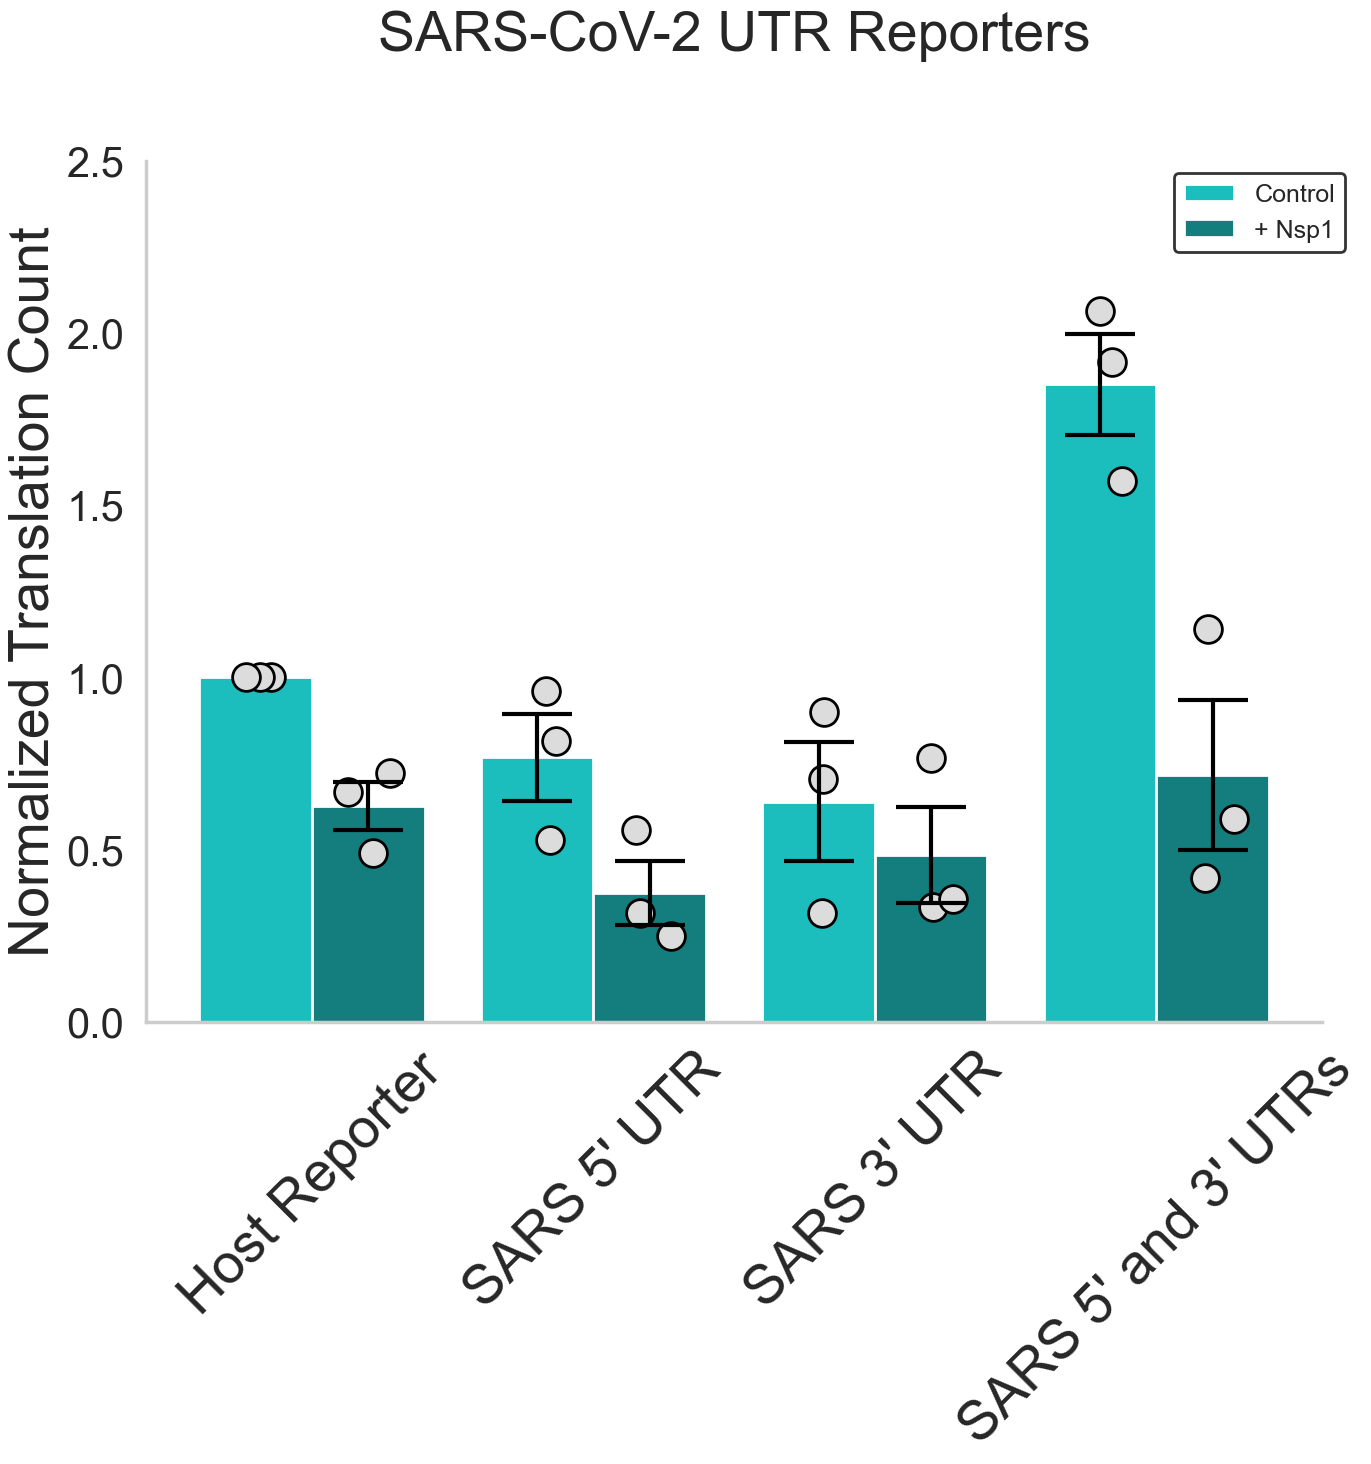


mRNA replicate SEM statistics:


,Experimental Group,Experimental Type,mean,sd,sem,n_replicates
0,SARS_CTRL,No Nsp1,1.000000,0.000000,0.000000,3
1,SARS_CTRL,Nsp1,0.514547,0.133727,0.077207,3
2,SARS_5'UTR,No Nsp1,0.694533,0.218870,0.126364,3
3,SARS_5'UTR,Nsp1,0.207092,0.046507,0.026851,3
4,SARS_3'UTR,No Nsp1,0.436435,0.210841,0.121729,3
5,SARS_3'UTR,Nsp1,0.405863,0.193467,0.111698,3
6,SARS_5'UTR_3'UTR,No Nsp1,0.964697,0.120641,0.069652,3
7,SARS_5'UTR_3'UTR,Nsp1,0.425286,0.152869,0.088259,3



[hue=No Nsp1] Scaled conditions vs 1.0
[hue=No Nsp1] SARS_5'UTR vs 1.0: n=3, mean=0.695, p=0.137, ns
[hue=No Nsp1] SARS_3'UTR vs 1.0: n=3, mean=0.436, p=0.0436, *
[hue=No Nsp1] SARS_5'UTR_3'UTR vs 1.0: n=3, mean=0.965, p=0.663, ns

[hue=No Nsp1] Direct experimental-type comparisons
----------------------------------------------------------------------
[hue=No Nsp1] SARS_5'UTR vs SARS_3'UTR: paired n=3, means=0.695 vs 0.436, p=0.396, ns
[hue=No Nsp1] SARS_5'UTR vs SARS_5'UTR_3'UTR: paired n=3, means=0.695 vs 0.965, p=0.118, ns
[hue=No Nsp1] SARS_3'UTR vs SARS_5'UTR_3'UTR: paired n=3, means=0.436 vs 0.965, p=0.106, ns

[hue=Nsp1] Scaled conditions vs 1.0
[hue=Nsp1] SARS_5'UTR vs 1.0: n=3, mean=0.207, p=0.00114, **
[hue=Nsp1] SARS_3'UTR vs 1.0: n=3, mean=0.406, p=0.0336, *
[hue=Nsp1] SARS_5'UTR_3'UTR vs 1.0: n=3, mean=0.425, p=0.0228, *

[hue=Nsp1] Direct experimental-type comparisons
----------------------------------------------------------------------
[hue=Nsp1] SARS_5'UTR vs SARS_3'U

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2019491301.py:1361: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


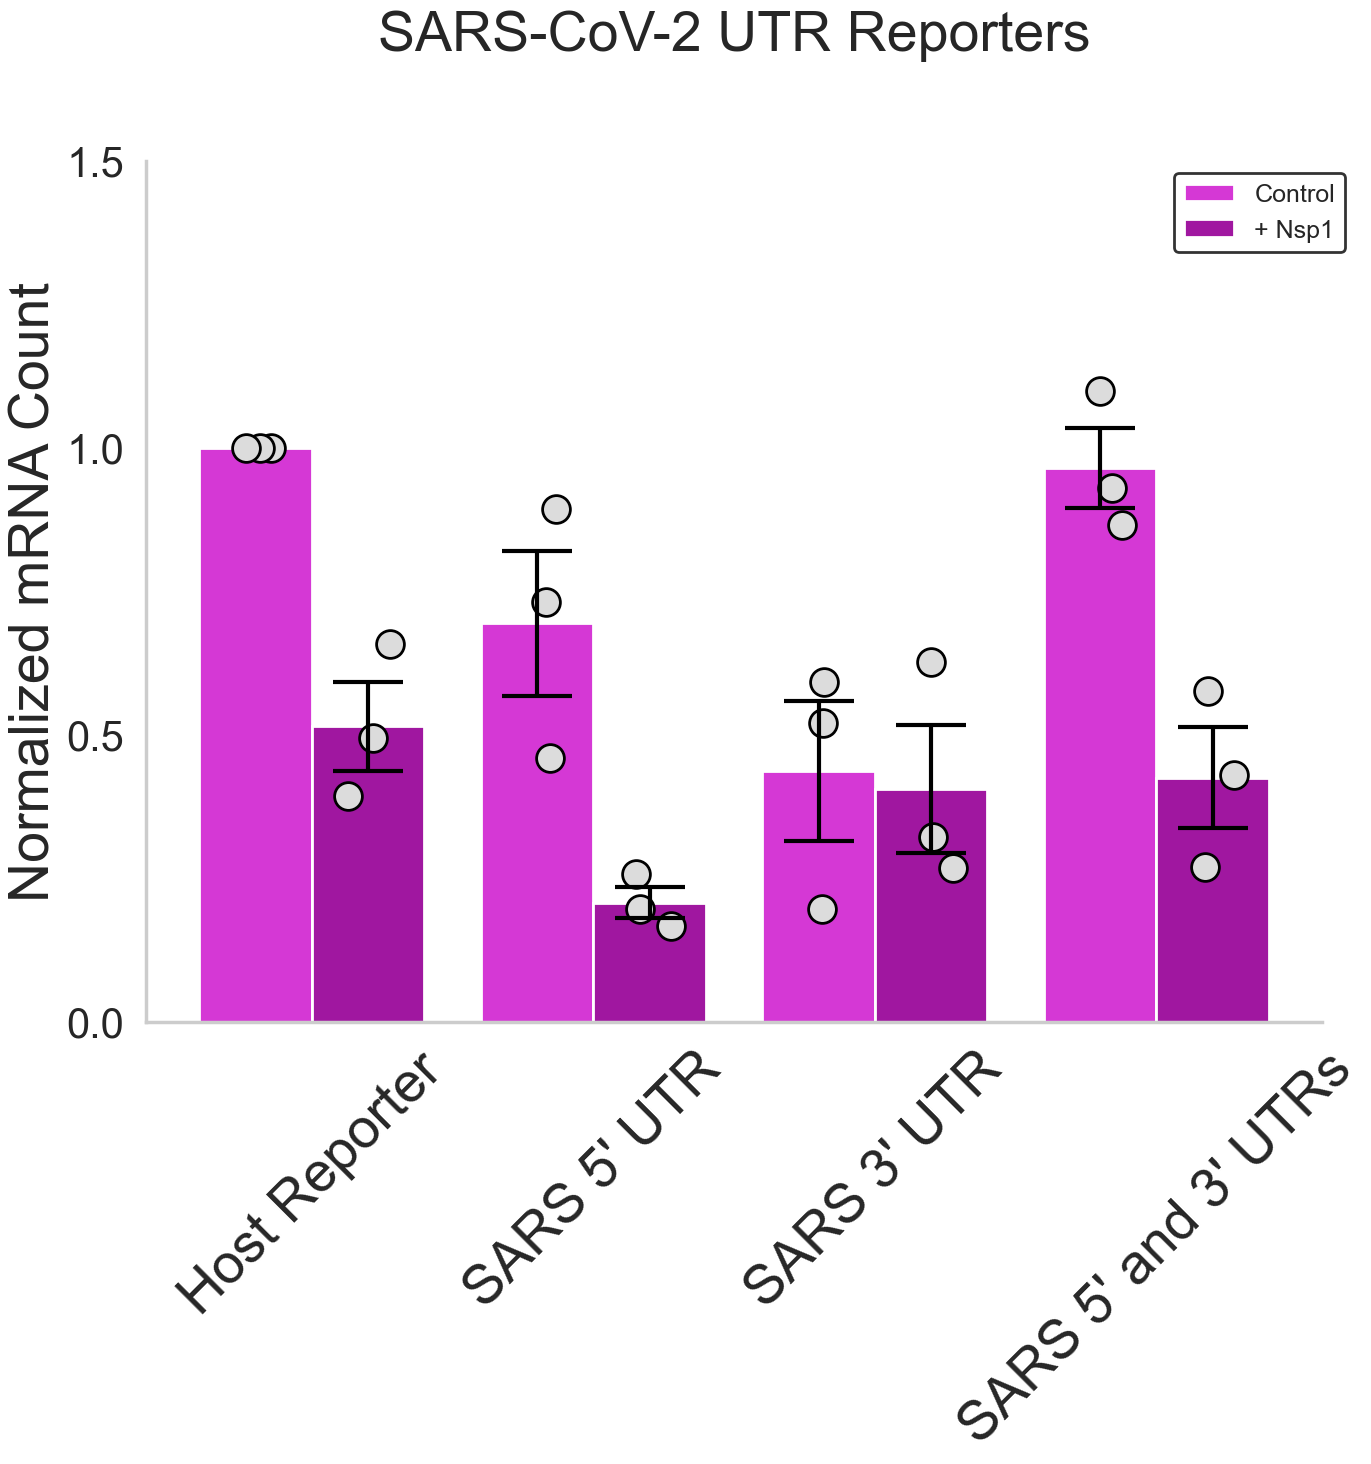

In [124]:
# Plot 3b +Nsp1 All groups:
# Normalize all SARS UTR groups to SARS_CTRL / No Nsp1,
# then plot replicate-level superplot bars with SEM across
# biological replicate averages.

import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ---------------------------------------------------------
# Plot style
# ---------------------------------------------------------

sns.set(font_scale=1.9)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)


# ---------------------------------------------------------
# Category orders
# ---------------------------------------------------------

group_order = [
    "SARS_CTRL",
    "SARS_5'UTR",
    "SARS_3'UTR",
    "SARS_5'UTR_3'UTR",
]


type_order = [
    "No Nsp1",
    "Nsp1",
]


new_labels = [
    "Host Reporter",
    "SARS 5' UTR",
    "SARS 3' UTR",
    "SARS 5' and 3' UTRs",
]


legend_labels = [
    "Control",
    "+ Nsp1",
]


ref_group = "SARS_CTRL"

ref_type = "No Nsp1"


raw_trans_col = (
    "Average Total Translation Spots"
)

raw_rna_col = (
    "Average Total RNA Spots"
)


norm_trans_col = (
    "Average Total Translation Spots (scaled)"
)

norm_rna_col = (
    "Average Total RNA Spots (scaled)"
)


# ---------------------------------------------------------
# Prepare data
# ---------------------------------------------------------

data = average_spot_count.loc[

    (
        average_spot_count[
            "Experimental Group"
        ].isin(
            group_order
        )
    )

    &

    (
        average_spot_count[
            "Experimental Type"
        ].isin(
            type_order
        )
    )

].copy()


# ---------------------------------------------------------
# Optional cell-level outlier removal before normalization
# ---------------------------------------------------------

outlier_df, data = (
    detect_and_drop_cell_outliers_by_fov(

        data,

        col_rna=
            raw_rna_col,

        col_trnl=
            raw_trans_col,
    )
)


# ---------------------------------------------------------
# Make replicate number numeric for normalization
# ---------------------------------------------------------

data[
    "Replicate_Number"
] = pd.to_numeric(

    data[
        "Replicate_Number"
    ],

    errors="coerce"

).astype(
    "Int64"
)


# ---------------------------------------------------------
# Normalize everything to SARS_CTRL / No Nsp1
#
# Reference value is calculated separately for each
# biological replicate.
#
# Therefore:
#
# SARS_CTRL / No Nsp1 replicate averages = approximately 1.
# ---------------------------------------------------------

ref_means = (

    data.loc[

        (
            data[
                "Experimental Group"
            ]
            ==
            ref_group
        )

        &

        (
            data[
                "Experimental Type"
            ]
            ==
            ref_type
        )

    ]

    .groupby(
        "Replicate_Number"
    )[
        [
            raw_trans_col,
            raw_rna_col,
        ]
    ]

    .mean()

    .rename(

        columns={

            raw_trans_col:
                "__ref_mean_translation",

            raw_rna_col:
                "__ref_mean_rna",
        }
    )

    .replace(
        0,
        np.nan
    )
)


data_norm = data.merge(

    ref_means,

    left_on=
        "Replicate_Number",

    right_index=True,

    how="left",
)


data_norm[
    norm_trans_col
] = (

    data_norm[
        raw_trans_col
    ]

    /

    data_norm[
        "__ref_mean_translation"
    ]
)


data_norm[
    norm_rna_col
] = (

    data_norm[
        raw_rna_col
    ]

    /

    data_norm[
        "__ref_mean_rna"
    ]
)


# ---------------------------------------------------------
# Keep only useful columns
# ---------------------------------------------------------

data_norm = data_norm[
    [
        "Experimental Group",
        "fov",
        "Experimental Type",
        "Replicate_Number",
        norm_trans_col,
        norm_rna_col,
    ]
].copy()


# ---------------------------------------------------------
# Generate BIOLOGICAL REPLICATE-level superplot data
# ---------------------------------------------------------

superplot_translation = calculate_grouped_average(

    data_norm,

    norm_trans_col,

    [
        "Experimental Group",
        "Experimental Type",
        "Replicate_Number",
    ],
)


superplot_rna = calculate_grouped_average(

    data_norm,

    norm_rna_col,

    [
        "Experimental Group",
        "Experimental Type",
        "Replicate_Number",
    ],
)


# ---------------------------------------------------------
# Helper:
# Mean +/- SEM across BIOLOGICAL REPLICATE averages
# ---------------------------------------------------------

def calculate_replicate_sem_stats(
    df,
    value_col,
    group_order,
    type_order,
    group_col="Experimental Group",
    type_col="Experimental Type",
):
    """
    Calculate one bar mean and SEM from biological replicate
    averages.

    For every Experimental Group × Experimental Type:

        mean = mean of biological replicate averages

        SD = sample standard deviation of biological
             replicate averages

        SEM = SD / sqrt(number of biological replicates)

    Returns one row per plotted bar.
    """

    rows = []


    for group in group_order:

        for exp_type in type_order:


            vals = (

                df.loc[

                    (
                        df[
                            group_col
                        ]
                        ==
                        group
                    )

                    &

                    (
                        df[
                            type_col
                        ]
                        ==
                        exp_type
                    ),

                    value_col,

                ]

                .dropna()

                .to_numpy(
                    dtype=float
                )
            )


            n_replicates = len(
                vals
            )


            if n_replicates == 0:

                mean_val = np.nan

                sd_val = np.nan

                sem_val = np.nan


            else:

                mean_val = float(
                    np.mean(
                        vals
                    )
                )


                if n_replicates > 1:

                    sd_val = float(

                        np.std(
                            vals,
                            ddof=1
                        )
                    )


                    sem_val = (

                        sd_val

                        /

                        np.sqrt(
                            n_replicates
                        )
                    )


                else:

                    sd_val = np.nan

                    sem_val = np.nan


            rows.append(
                {
                    group_col:
                        group,

                    type_col:
                        exp_type,

                    "mean":
                        mean_val,

                    "sd":
                        sd_val,

                    "sem":
                        sem_val,

                    "n_replicates":
                        n_replicates,
                }
            )


    return pd.DataFrame(
        rows
    )


# =========================================================
# Plot 1:
# Normalized Translation Count
# =========================================================

plot_col = (
    "Super Average Total Translation Spots (scaled)"
)


translation_stats = (
    calculate_replicate_sem_stats(

        df=
            superplot_translation,

        value_col=
            plot_col,

        group_order=
            group_order,

        type_order=
            type_order,
    )
)


print(
    "\nTranslation replicate SEM statistics:"
)

display(
    translation_stats
)


fig1, ax1 = plt.subplots(

    figsize=(16, 12),

    constrained_layout=True
)


sns.despine(

    fig=fig1,

    top=True,

    right=True,

    left=False,

    bottom=False
)


# ---------------------------------------------------------
# Bars = mean of biological replicate averages
# ---------------------------------------------------------

sns.barplot(

    x="Experimental Group",

    y=plot_col,

    hue="Experimental Type",

    data=
        superplot_translation,

    order=
        group_order,

    hue_order=
        type_order,

    ax=ax1,

    palette=
        blue_palette[:2],

    errorbar=None,
)


# ---------------------------------------------------------
# Capture bar containers immediately after barplot.
#
# container 0 = No Nsp1
# container 1 = Nsp1
# ---------------------------------------------------------

bar_containers_1 = (
    ax1.containers[
        :len(
            type_order
        )
    ]
)


# ---------------------------------------------------------
# Save clean legend handles before open-circle overlay
# ---------------------------------------------------------

handles1, labels1 = (
    ax1.get_legend_handles_labels()
)


# ---------------------------------------------------------
# Biological replicate averages
# ---------------------------------------------------------

plot_open_circles_with_hue(

    ax1,

    superplot_translation,

    order=
        group_order,

    x=
        "Experimental Group",

    y=
        plot_col,

    hue=
        "Experimental Type",

    hue_order=
        type_order,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,
)


# ---------------------------------------------------------
# Add SEM across biological replicate averages
#
# Skip SARS_CTRL / No Nsp1 because this is the
# normalization reference.
# ---------------------------------------------------------

for type_idx, container in enumerate(
    bar_containers_1
):


    exp_type = (
        type_order[
            type_idx
        ]
    )


    for group_idx, patch in enumerate(
        container
    ):


        group = (
            group_order[
                group_idx
            ]
        )


        # Normalized reference = 1.
        # Do not display an error bar.
        if (
            group == ref_group
            and
            exp_type == ref_type
        ):

            continue


        row = translation_stats.loc[

            (
                translation_stats[
                    "Experimental Group"
                ]
                ==
                group
            )

            &

            (
                translation_stats[
                    "Experimental Type"
                ]
                ==
                exp_type
            )

        ]


        if row.empty:

            continue


        mean_val = (
            row[
                "mean"
            ].iloc[0]
        )


        sem_val = (
            row[
                "sem"
            ].iloc[0]
        )


        if (
            pd.isna(
                mean_val
            )

            or

            pd.isna(
                sem_val
            )
        ):

            continue


        x_center = (

            patch.get_x()

            +

            patch.get_width()
            /
            2.0
        )


        ax1.errorbar(

            x_center,

            mean_val,

            yerr=
                sem_val,

            fmt="none",

            elinewidth=3,

            capsize=25,

            capthick=3,

            color="black",

            alpha=1,

            zorder=10,
        )


# ---------------------------------------------------------
# Formatting
# ---------------------------------------------------------

ax1.set_ylabel(
    "Normalized Translation Count",
    fontsize=40
)


ax1.set_title(
    "SARS-CoV-2 UTR Reporters",
    fontsize=40,
    pad=80
)


ax1.tick_params(
    axis="both",
    which="major",
    labelsize=30
)


ax1.set_ylim(
    0,
    2.5
)


ax1.set_xticklabels(
    new_labels,
    fontsize=40,
    rotation=45
)


ax1.set_xlabel(
    ""
)


ax1.yaxis.set_major_locator(

    MaxNLocator(
        nbins=6
    )
)


# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

if ax1.get_legend() is not None:

    ax1.get_legend().remove()


ax1.legend(

    handles1[
        :len(
            type_order
        )
    ],

    legend_labels,

    title=None,

    facecolor="white",

    edgecolor="black",

    fontsize=18,

    loc="upper right",

    bbox_to_anchor=(
        1.03,
        1
    ),
)


# ---------------------------------------------------------
# Statistics
# ---------------------------------------------------------

res_scaled1 = (
    print_scaled_one_sample_summary(

        data=
            superplot_translation,

        x=
            "Experimental Group",

        y=
            plot_col,

        hue=
            "Experimental Type",

        baseline_x=
            ref_group,

        order=
            group_order,

        hue_order=
            type_order,
    )
)


print(
    res_scaled1
)


# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

filename_svg_translation = os.path.join(

    save_directory
    +
    spot_count_folder,

    "Normalized_Total_Translation_Spots_SARS_UTRs_to_Host_Control.svg",
)


filename_png_translation = os.path.join(

    save_directory
    +
    spot_count_folder,

    "Normalized_Total_Translation_Spots_SARS_UTRs_to_Host_Control.png",
)


fig1.savefig(

    filename_svg_translation,

    format="svg",

    dpi=300
)


fig1.savefig(

    filename_png_translation,

    format="png",

    dpi=300
)


plt.tight_layout()

plt.show()


# =========================================================
# Plot 2:
# Normalized mRNA Count
# =========================================================

plot_col = (
    "Super Average Total RNA Spots (scaled)"
)


rna_stats = (
    calculate_replicate_sem_stats(

        df=
            superplot_rna,

        value_col=
            plot_col,

        group_order=
            group_order,

        type_order=
            type_order,
    )
)


print(
    "\nmRNA replicate SEM statistics:"
)

display(
    rna_stats
)


fig2, ax2 = plt.subplots(

    figsize=(16, 12),

    constrained_layout=True
)


sns.despine(

    fig=fig2,

    top=True,

    right=True,

    left=False,

    bottom=False
)


# ---------------------------------------------------------
# Bars = mean of biological replicate averages
# ---------------------------------------------------------

sns.barplot(

    x="Experimental Group",

    y=plot_col,

    hue="Experimental Type",

    data=
        superplot_rna,

    order=
        group_order,

    hue_order=
        type_order,

    ax=ax2,

    palette=
        magenta_palette[:2],

    errorbar=None,
)


# ---------------------------------------------------------
# Capture bar containers immediately after barplot
# ---------------------------------------------------------

bar_containers_2 = (
    ax2.containers[
        :len(
            type_order
        )
    ]
)


# ---------------------------------------------------------
# Save clean legend handles before open-circle overlay
# ---------------------------------------------------------

handles2, labels2 = (
    ax2.get_legend_handles_labels()
)


# ---------------------------------------------------------
# Biological replicate averages
# ---------------------------------------------------------

plot_open_circles_with_hue(

    ax2,

    superplot_rna,

    order=
        group_order,

    x=
        "Experimental Group",

    y=
        plot_col,

    hue=
        "Experimental Type",

    hue_order=
        type_order,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,
)


# ---------------------------------------------------------
# Add SEM across biological replicate averages
#
# Skip SARS_CTRL / No Nsp1 because this is the
# normalization reference.
# ---------------------------------------------------------

for type_idx, container in enumerate(
    bar_containers_2
):


    exp_type = (
        type_order[
            type_idx
        ]
    )


    for group_idx, patch in enumerate(
        container
    ):


        group = (
            group_order[
                group_idx
            ]
        )


        # Normalized reference = 1.
        # Do not display an error bar.
        if (
            group == ref_group
            and
            exp_type == ref_type
        ):

            continue


        row = rna_stats.loc[

            (
                rna_stats[
                    "Experimental Group"
                ]
                ==
                group
            )

            &

            (
                rna_stats[
                    "Experimental Type"
                ]
                ==
                exp_type
            )

        ]


        if row.empty:

            continue


        mean_val = (
            row[
                "mean"
            ].iloc[0]
        )


        sem_val = (
            row[
                "sem"
            ].iloc[0]
        )


        if (
            pd.isna(
                mean_val
            )

            or

            pd.isna(
                sem_val
            )
        ):

            continue


        x_center = (

            patch.get_x()

            +

            patch.get_width()
            /
            2.0
        )


        ax2.errorbar(

            x_center,

            mean_val,

            yerr=
                sem_val,

            fmt="none",

            elinewidth=3,

            capsize=25,

            capthick=3,

            color="black",

            alpha=1,

            zorder=10,
        )


# ---------------------------------------------------------
# Formatting
# ---------------------------------------------------------

ax2.set_ylabel(
    "Normalized mRNA Count",
    fontsize=40
)


ax2.set_title(
    "SARS-CoV-2 UTR Reporters",
    fontsize=40,
    pad=80
)


ax2.tick_params(
    axis="both",
    which="major",
    labelsize=30
)


ax2.set_ylim(
    0,
    1.5
)


ax2.set_xticklabels(
    new_labels,
    fontsize=40,
    rotation=45
)


ax2.set_xlabel(
    ""
)


ax2.yaxis.set_major_locator(

    MaxNLocator(
        nbins=3
    )
)


# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

if ax2.get_legend() is not None:

    ax2.get_legend().remove()


ax2.legend(

    handles2[
        :len(
            type_order
        )
    ],

    legend_labels,

    title=None,

    facecolor="white",

    edgecolor="black",

    fontsize=18,

    loc="upper right",

    bbox_to_anchor=(
        1.03,
        1
    ),
)


# ---------------------------------------------------------
# Statistics
# ---------------------------------------------------------

res_scaled2 = (
    print_scaled_one_sample_summary(

        data=
            superplot_rna,

        x=
            "Experimental Group",

        y=
            plot_col,

        hue=
            "Experimental Type",

        baseline_x=
            ref_group,

        order=
            group_order,

        hue_order=
            type_order,
    )
)


print(
    res_scaled2
)


# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

filename_svg_rna = os.path.join(

    save_directory
    +
    spot_count_folder,

    "Normalized_Total_RNA_Spots_SARS_UTRs_to_Host_Control.svg",
)


filename_png_rna = os.path.join(

    save_directory
    +
    spot_count_folder,

    "Normalized_Total_RNA_Spots_SARS_UTRs_to_Host_Control.png",
)


fig2.savefig(

    filename_svg_rna,

    format="svg",

    dpi=300
)


fig2.savefig(

    filename_png_rna,

    format="png",

    dpi=300
)


plt.tight_layout()

plt.show()

In [ ]:
# Plot 4: +NSP1 Total Translation Spots and Total RNA Spots with Black Background
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Set the font and style for a black background with white text
sns.set(font_scale=1.9)
sns.set_style("darkgrid", {'axes.facecolor': 'black', 'grid.color': 'gray', 'axes.edgecolor': 'white'})


data = average_spot_count[average_spot_count["Experimental Type"].isin(["Nsp1", "No Nsp1"])]

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_5'UTR_3'UTR", "SARS_3'UTR"]

# Create a figure with 2 subplots, one for each y-variable
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 16), facecolor='black')  # Set figure facecolor to black

# Plot the Translational Efficiency for each Experimental Group (Barplot)
sns.barplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", data=data, order=order, ax=ax1, palette='Set1', errcolor='white')

# Overlay a scatterplot to represent individual data points (with white dots)
sns.stripplot(x="Experimental Group", y="Average Total Translation Spots", hue="Experimental Type", data=data, order=order, palette=["white", "white", "white"], size=5, jitter=True, dodge=True, ax=ax1)

# Set titles, labels, and y-limits with white text for the first subplot
ax1.set_title('Translation', fontsize=36, color='white')
ax1.set_ylabel('Total Translation Spots (#)', color='white')
ax1.set_ylim(0, 15)
ax1.set_xlabel('')
ax1.tick_params(axis='x', colors='white')
ax1.tick_params(axis='y', colors='white')

# Plot the RNA spots on the second subplot (Barplot)
sns.barplot(x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type", data=data, order=order, ax=ax2, palette="Set1", errcolor='white')

# Overlay a scatterplot to represent individual data points (with white dots)
sns.stripplot(x="Experimental Group", y="Average Total RNA Spots", hue="Experimental Type", data=data, order=order, palette=["white", "white", "white"], size=5, jitter=True, dodge=True, ax=ax2)

# Set titles, labels, and y-limits with white text for the second subplot
ax2.set_title('RNA', fontsize=36, color='white')
ax2.set_ylabel('Total RNA Spots (#)', color='white')
ax2.set_ylim(0, 40)
ax2.set_xlabel('')
ax2.tick_params(axis='x', colors='white')
ax2.tick_params(axis='y', colors='white')

# Set the x-tick labels for both plots with white text
new_labels = ["Host UTR Control", "SARS 5' UTR", "SARS 5' and 3' UTRs", "SARS 3' UTR"]
for ax in [ax1, ax2]:
    ax.set_xticklabels(new_labels, color='white')

    # Handle the legend: Only keep the barplot's legend
    handles, labels = ax.get_legend_handles_labels()
    legend = ax.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='black', edgecolor='white', fontsize=16, title_fontsize=18)
    plt.setp(legend.get_texts(), color='white')  # Set legend text to white
        # Set the legend text color to white
    plt.setp(legend.get_texts(), color='white')  # Legend text
    plt.setp(legend.get_title(), color='white')  # Legend title

# Set a white title for the whole figure
plt.suptitle('Number of Spots per Cell', fontsize=40, color='white', y=1.04, x=0.5)

# Adjust layout and spacing
plt.tight_layout()
plt.subplots_adjust(top=0.95)

# Define the filenames for saving with '(k)' for the black version
filename_svg = os.path.join(save_directory, "Average Spots per Cell (Nsp1)(k).svg")
filename_png = os.path.join(save_directory, "Average Spots per Cell (Nsp1)(k).png")

# Save the figure as SVG with black background
fig.savefig(filename_svg, format='svg', bbox_inches='tight', facecolor='black')

# Save the figure as PNG with black background
fig.savefig(filename_png, format='png', bbox_inches='tight', facecolor='black')

# Show the plot
plt.show()


In [ ]:
# Plot 5: Host UTR Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Group"] == "SARS_CTRL"]

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1", "+\u0394 Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


sns.stripplot(x="Experimental Type", y="Average Total Translation Spots", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)



ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 40)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_title('Host UTR', fontsize=40, pad=80)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Average Total Translation Spots", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots Host UTR.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots Host UTR.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total RNA Spots",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_ylim(0, 100)
ax2.set_title('Host UTR', fontsize=40, pad=80)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Average Total RNA Spots", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots Host UTR.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots Host UTR.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3161004645.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",



[hue=SARS_CTRL] Scaled conditions vs 1.0
[hue=SARS_CTRL] Nsp1 vs 1.0: n=3, mean=0.766, p=0.0908, ns
[hue=SARS_CTRL] NoCTD Nsp1 vs 1.0: n=3, mean=1.57, p=0.0463, *

[hue=SARS_CTRL] Direct experimental-type comparisons
----------------------------------------------------------------------
[hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1: paired n=3, means=0.766 vs 1.57, p=0.0516, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=SARS_CTRL]
No Nsp1: 1 ± 0 SEM (n=3)
Nsp1: 0.766 ± 0.0758 SEM (n=3)
NoCTD Nsp1: 1.57 ± 0.128 SEM (n=3)

    test_group          test_type            contrast          x1          x2  \
0  scaled_vs_1  one-sample t-test         Nsp1 vs 1.0        Nsp1           1   
1  scaled_vs_1  one-sample t-test   NoCTD Nsp1 vs 1.0  NoCTD Nsp1           1   
2   cross_type      paired t-test  Nsp1 vs NoCTD Nsp1        Nsp1  NoCTD Nsp1   

         hue  n  n1   n2     mean1     mean2  mean_difference       sd1  \
0  SARS_CTRL  3   3  NaN  0.765825  1.000000        -0.234175  0.131358   
1  S

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3161004645.py:116: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


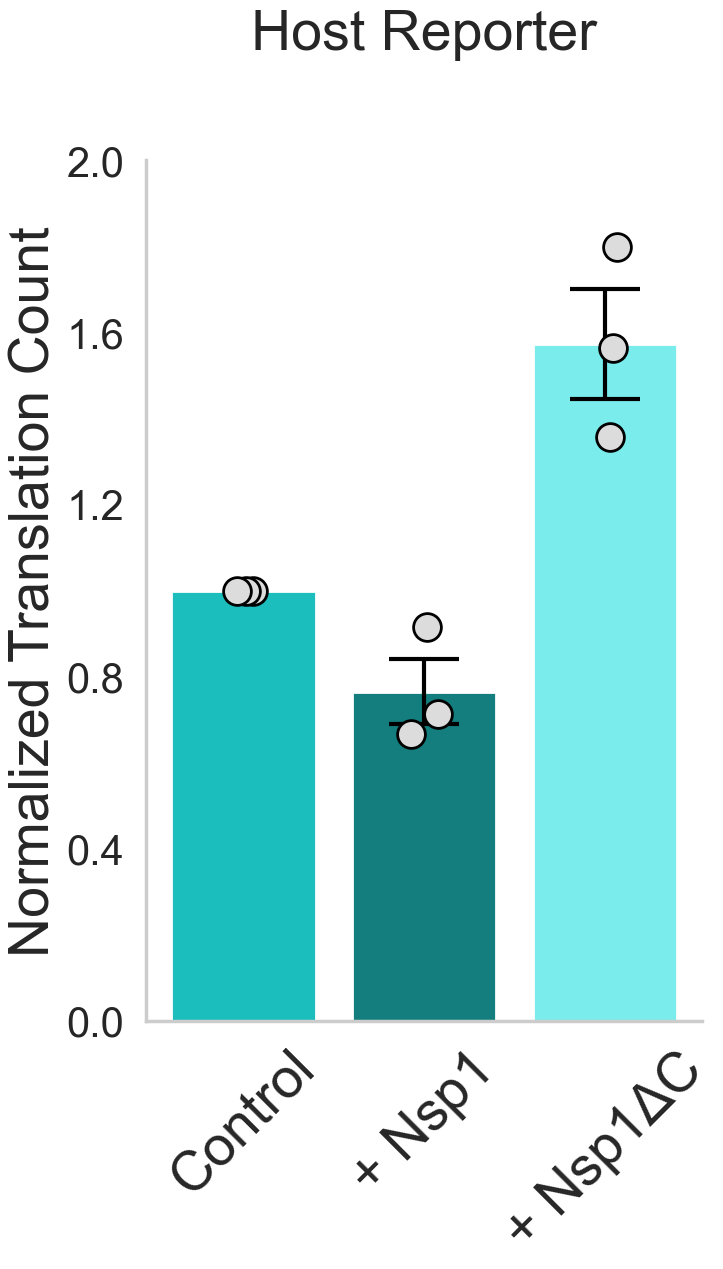

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3161004645.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",



[hue=SARS_CTRL] Scaled conditions vs 1.0
[hue=SARS_CTRL] Nsp1 vs 1.0: n=3, mean=0.542, p=0.0319, *
[hue=SARS_CTRL] NoCTD Nsp1 vs 1.0: n=3, mean=1.03, p=0.572, ns

[hue=SARS_CTRL] Direct experimental-type comparisons
----------------------------------------------------------------------
[hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1: paired n=3, means=0.542 vs 1.03, p=0.0289, *

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=SARS_CTRL]
No Nsp1: 1 ± 9.06e-17 SEM (n=3)
Nsp1: 0.542 ± 0.0838 SEM (n=3)
NoCTD Nsp1: 1.03 ± 0.0376 SEM (n=3)

    test_group          test_type            contrast          x1          x2  \
0  scaled_vs_1  one-sample t-test         Nsp1 vs 1.0        Nsp1           1   
1  scaled_vs_1  one-sample t-test   NoCTD Nsp1 vs 1.0  NoCTD Nsp1           1   
2   cross_type      paired t-test  Nsp1 vs NoCTD Nsp1        Nsp1  NoCTD Nsp1   

         hue  n  n1   n2     mean1     mean2  mean_difference       sd1  \
0  SARS_CTRL  3   3  NaN  0.542097  1.000000        -0.457903  0.145163  

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3161004645.py:206: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


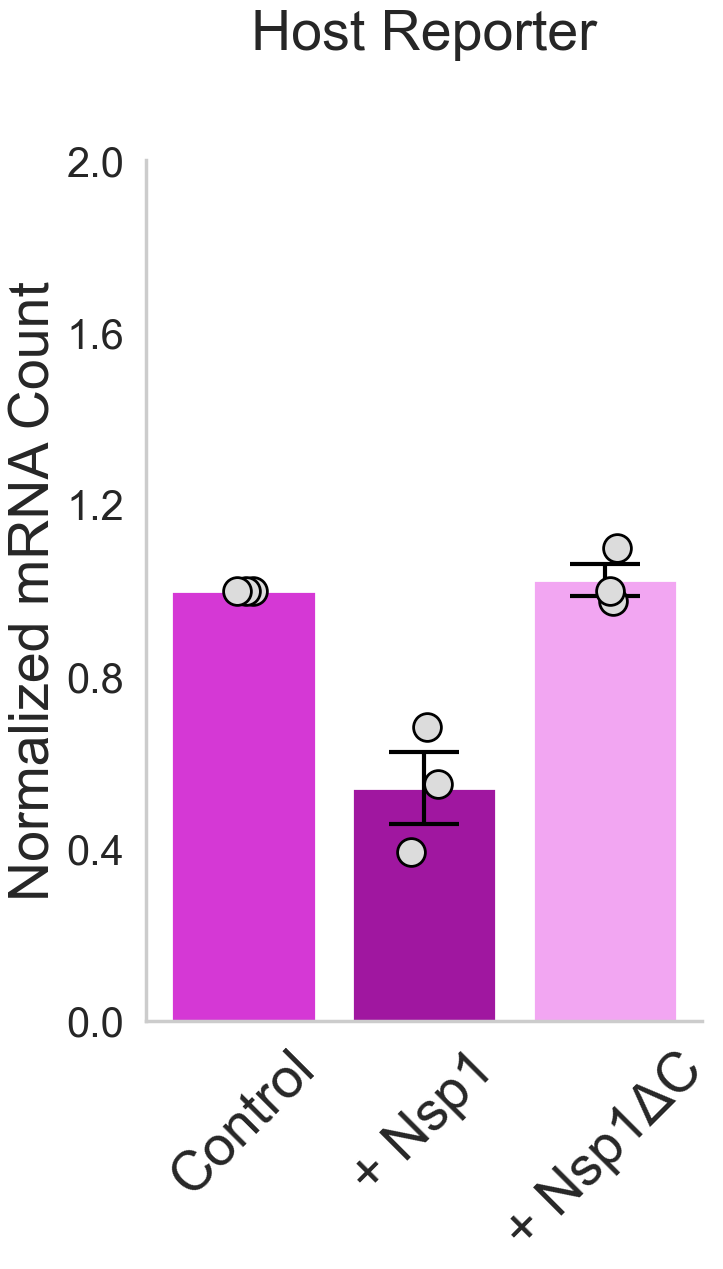

In [134]:
# Plot 5b: Scaled Host UTR Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the order for the x-axis categories
data = data = scale_by_reference(
    df=average_spot_count[average_spot_count["Experimental Group"] == "SARS_CTRL"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="SARS_CTRL",
    ref_type="No Nsp1",
)
# Generate Per-Replicate dataframe for superplots
superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])

col = "Super Average Total Translation Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, bar_stats = replicate_sem_bar_stats(
    data=superplot_translation,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
)




# Define the x-tick labels
new_labels = ["Control", "+ Nsp1", "+ Nsp1\u0394C"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)", 
            data=superplot_translation, order=order, ax=ax1, palette= blue_palette, errorbar=None)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

xpos = np.arange(
    len(cats)
)


for i, cat in enumerate(
    cats
):
    # Normalized Control = 1.
    # Do not display an error bar.
    if cat == ref_type:
        continue
    sem = yerr[
        0,
        i
    ]
    if (
        np.isnan(means[i])
        or np.isnan(sem)
    ):
        continue
    ax1.errorbar(
        xpos[i],
        means[i],
        yerr=sem,
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )
    
ax1.set_ylabel('Normalized Translation Count', fontsize=40)
ax1.set_title('Host Reporter', fontsize=40, pad=80)
ax1.set_ylim(0, 2)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res_scaled1 = print_scaled_one_sample_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Total Translation Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots Host UTR.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots Host UTR.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()

col = "Super Average Total RNA Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, bar_stats = replicate_sem_bar_stats(
    data=superplot_rna,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
)

# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)", 
            data=superplot_rna, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

xpos = np.arange(
    len(cats)
)


for i, cat in enumerate(
    cats
):
    # Normalized Control = 1.
    # Do not display an error bar.
    if cat == ref_type:
        continue
    sem = yerr[
        0,
        i
    ]
    if (
        np.isnan(means[i])
        or np.isnan(sem)
    ):
        continue
    ax2.errorbar(
        xpos[i],
        means[i],
        yerr=sem,
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )


ax2.set_ylabel('Normalized mRNA Count', fontsize=40)
ax2.set_ylim(0, 2)
ax2.set_title('Host Reporter', fontsize=40, pad=80)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res_scaled2 = print_scaled_one_sample_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots Host UTR.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots Host UTR.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

In [ ]:
# Plot 7: BoxB MS2 Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Group"] == "BoxB_MS2"]

outlier_df, data = detect_and_drop_replicate_outliers(
    data,
    col_rna="Average Total RNA Spots",
    col_trnl="Average Total Translation Spots",
)

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1", "+\u0394 Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total Translation Spots", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_title('No ORF', fontsize=40, pad=80)
ax1.set_ylim(0, 1)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Average Total Translation Spots", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots BoxB MS2.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots BoxB MS2.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total RNA Spots",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_title('No ORF', fontsize=40, pad=80)
ax2.set_ylim(0, 100)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Average Total RNA Spots", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots BoxB MS2.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots BoxB MS2.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\numpy\lib\nanfunctions.py:1556: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\numpy\lib\nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\numpy\lib\nanfunctions.py:1556: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\numpy\lib\nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\numpy\lib\nanfunctions.py:1556: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-pa


Manual drop requested for (Type → Replicates):
  No Nsp1: [5]
  Nsp1: [5]
  noCTD Nsp1: [5]

Drop mode: manual. Rows removed: 177

[hue=BoxB_MS2] Scaled conditions vs 1.0
[hue=BoxB_MS2] Nsp1 vs 1.0: n=4, mean=1.11, p=0.0157, *

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=BoxB_MS2]
No Nsp1: 1 ± 9.61e-17 SEM (n=4)
Nsp1: 1.11 ± 0.0226 SEM (n=4)

    test_group          test_type     contrast    x1 x2       hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  BoxB_MS2  4   4 NaN   

      mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue stars  
0  1.112138    1.0         0.112138  0.045157  NaN   4.966574  0.015678     *  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2256619709.py:121: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


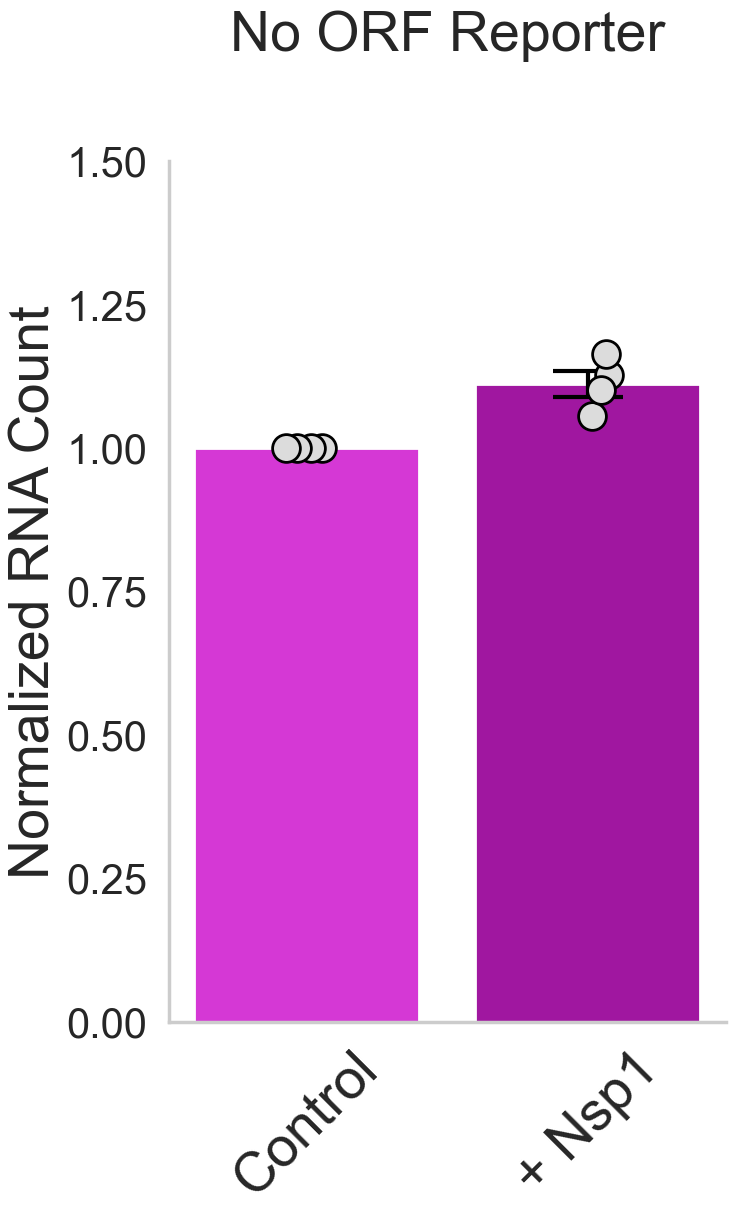

In [200]:
# Plot 7b: Scaled BoxB MS2 Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = scale_by_reference(
    df=df_no_outliers[df_no_outliers["Experimental Group"] == "BoxB_MS2"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="BoxB_MS2",
    ref_type="No Nsp1",
)
outlier_df, data = detect_and_drop_replicate_outliers(
    data,
    drop_mode="manual",
    manual_drop={
        "No Nsp1": [5],   # drop reps 1 & 3 for this Type
        "Nsp1": [5],      # drop reps 1 & 3 for this Type
        "noCTD Nsp1": [5] # drop reps 4 & 5 for this Type
    }
)

superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]
col = "Super Average Total RNA Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, bar_stats = replicate_sem_bar_stats(
    data=superplot_rna,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
)


# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)", 
            data=superplot_rna, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

xpos = np.arange(
    len(cats)
)


for i, cat in enumerate(
    cats
):
    # Normalized Control = 1.
    # Do not display an error bar.
    if cat == ref_type:
        continue
    sem = yerr[
        0,
        i
    ]
    if (
        np.isnan(means[i])
        or np.isnan(sem)
    ):
        continue
    ax2.errorbar(
        xpos[i],
        means[i],
        yerr=sem,
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )


ax2.set_ylabel('Normalized RNA Count', fontsize=40)
ax2.set_title('No ORF Reporter', fontsize=40, pad=80)
ax2.set_ylim(0, 1.5)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res_scaled2 = print_scaled_one_sample_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots BoxB MS2.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots BoxB MS2.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\273804415.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\273804415.py:57: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


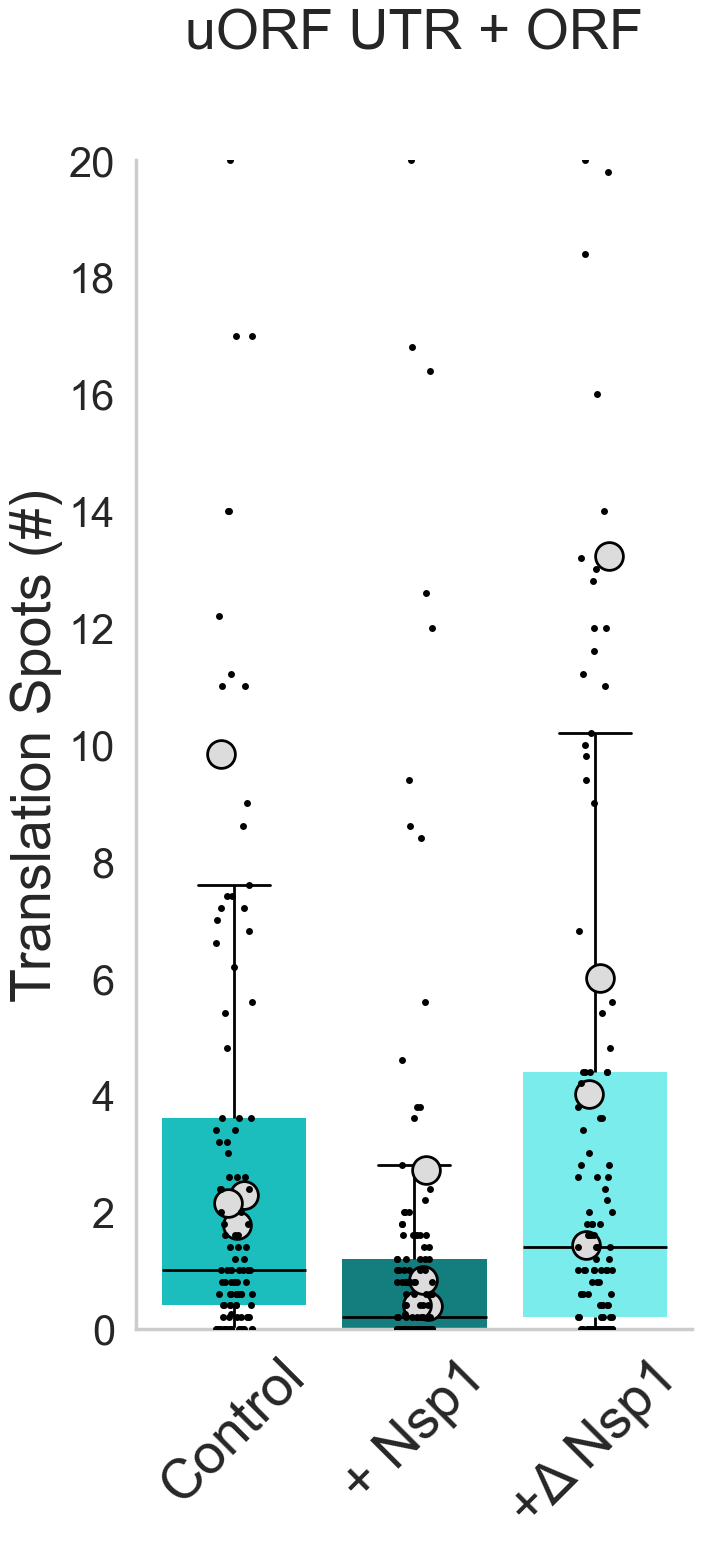

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\273804415.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\273804415.py:98: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


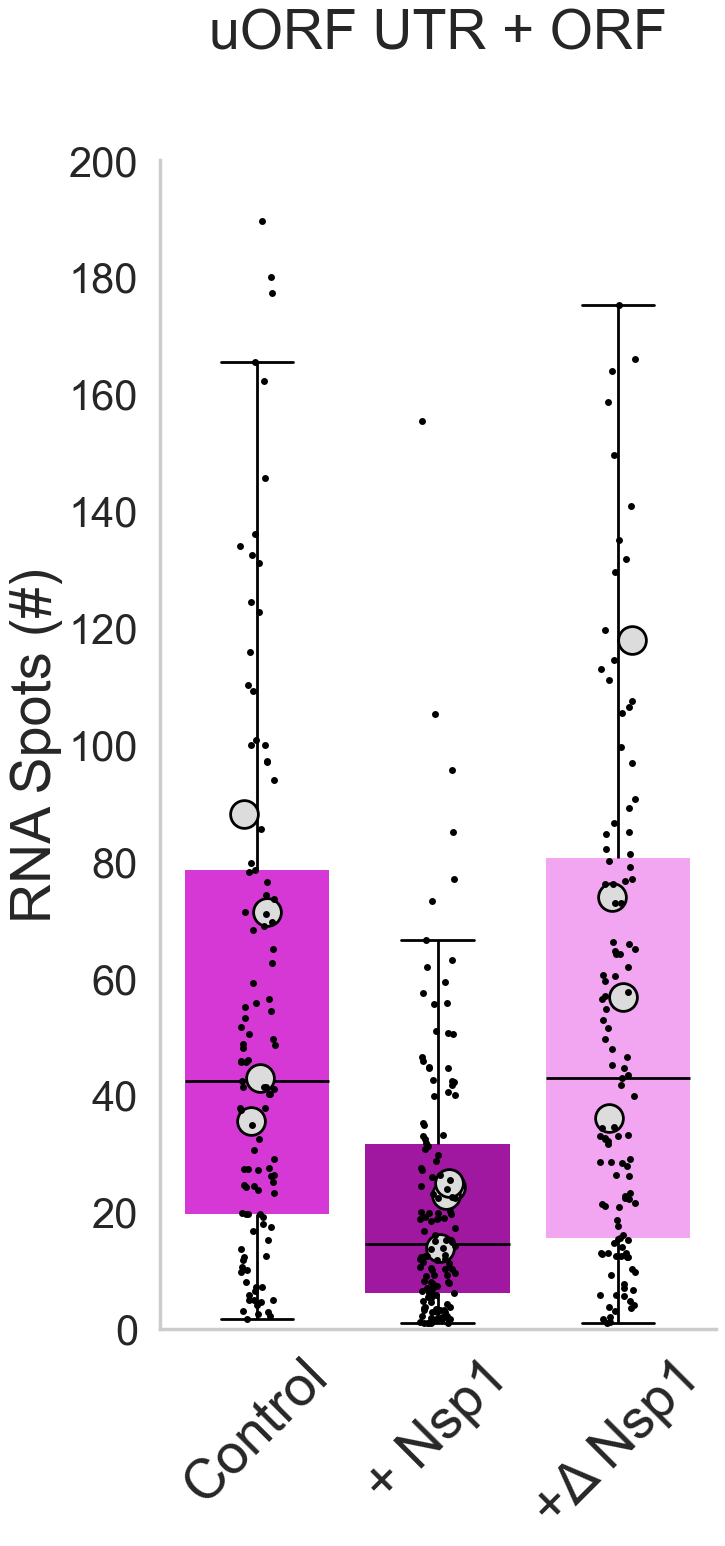

In [136]:
# Plot 8: Emi KDM5B Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Group"] == "Emi_KDM5B"]

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1", "+\u0394 Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total Translation Spots", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_title('uORF UTR + ORF', fontsize=40, pad=80)
ax1.set_ylim(0, 20)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()


# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots EMI.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots EMI.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total RNA Spots",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_title('uORF UTR + ORF', fontsize=40, pad=80)
ax2.set_ylim(0, 200)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()


# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots EMI.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots EMI.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()


Manual drop requested for (Type → Replicates):
  No Nsp1: [3]
  Nsp1: [3]
  noCTD Nsp1: [3]

Drop mode: manual. Rows removed: 48

[hue=Emi_KDM5B] Scaled conditions vs 1.0
[hue=Emi_KDM5B] Nsp1 vs 1.0: n=3, mean=0.177, p=0.00103, **

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=Emi_KDM5B]
No Nsp1: 1 ± 0 SEM (n=3)
Nsp1: 0.177 ± 0.0265 SEM (n=3)

    test_group          test_type     contrast    x1 x2        hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  Emi_KDM5B  3   3 NaN   

      mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue stars  
0  0.177015    1.0        -0.822985  0.045848  NaN -31.091172  0.001033    **  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3889025266.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3889025266.py:51: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3889025266.py:122: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


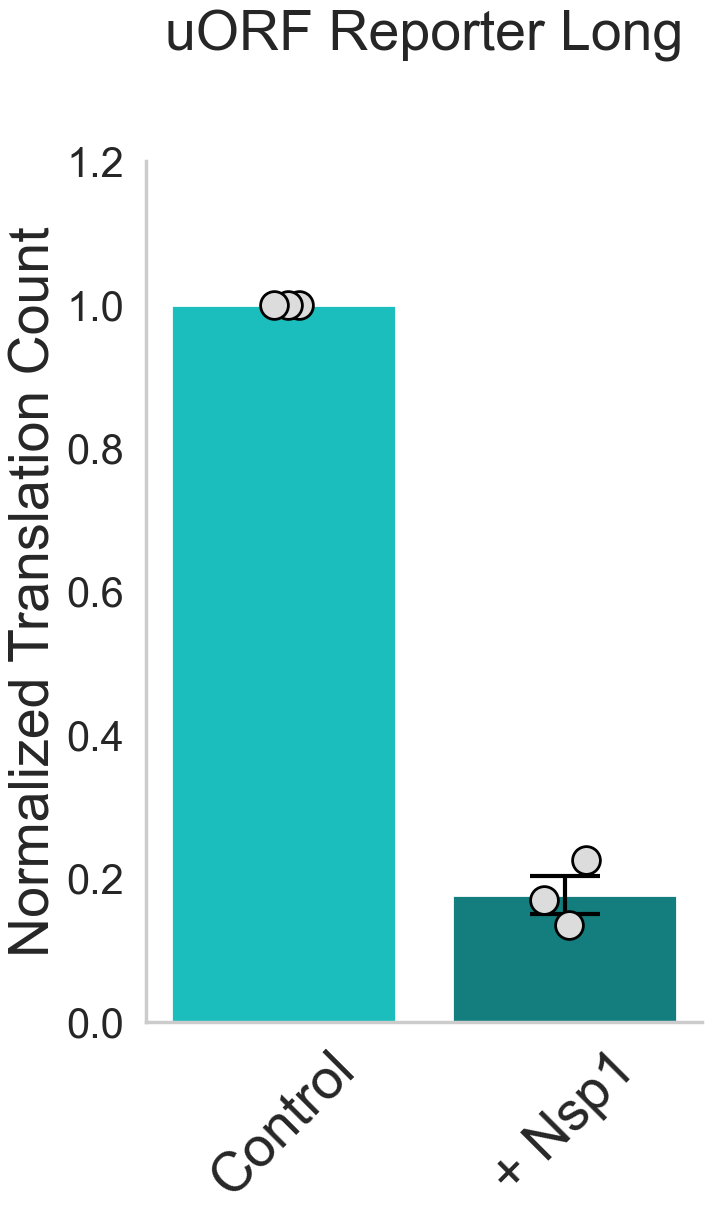

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3889025266.py:144: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3889025266.py:144: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",



[hue=Emi_KDM5B] Scaled conditions vs 1.0
[hue=Emi_KDM5B] Nsp1 vs 1.0: n=3, mean=0.305, p=0.00147, **

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=Emi_KDM5B]
No Nsp1: 1 ± 9.06e-17 SEM (n=3)
Nsp1: 0.305 ± 0.0266 SEM (n=3)

    test_group          test_type     contrast    x1 x2        hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  Emi_KDM5B  3   3 NaN   

      mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue stars  
0  0.305253    1.0        -0.694747  0.046155  NaN -26.071603  0.001468    **  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3889025266.py:214: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


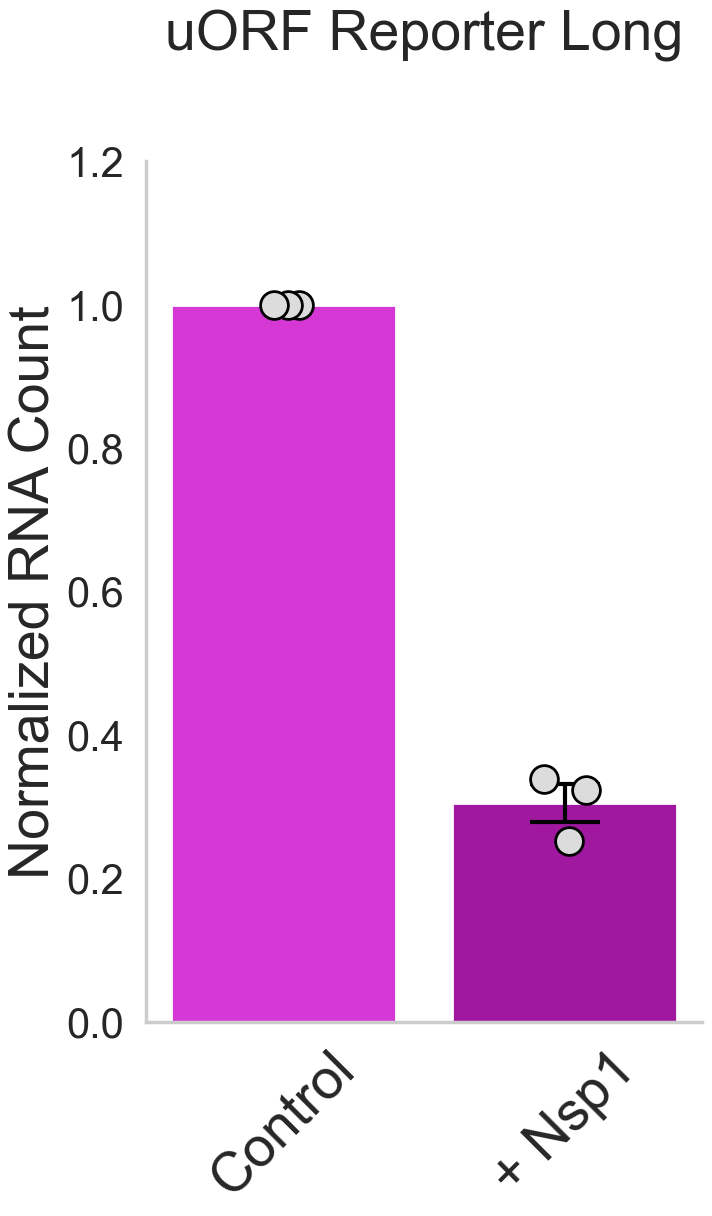

In [137]:
# Plot 8b: Scaled Emi KDM5B Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = scale_by_reference(
    df=df_no_outliers[df_no_outliers["Experimental Group"] == "Emi_KDM5B"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="Emi_KDM5B",
    ref_type="No Nsp1",
)
outlier_df, data = detect_and_drop_replicate_outliers(
    data,
    drop_mode="manual",
    manual_drop={
        "No Nsp1": [3],   # drop reps 1 & 3 for this Type
        "Nsp1": [3],      # drop reps 1 & 3 for this Type
        "noCTD Nsp1": [3] # drop reps 4 & 5 for this Type
    }
)
superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])

col = "Super Average Total Translation Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, bar_stats = replicate_sem_bar_stats(
    data=superplot_translation,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
)

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)", 
            data=superplot_translation, order=order, ax=ax1, palette= blue_palette, errorbar=None)


plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

xpos = np.arange(
    len(cats)
)


for i, cat in enumerate(
    cats
):
    # Normalized Control = 1.
    # Do not display an error bar.
    if cat == ref_type:
        continue
    sem = yerr[
        0,
        i
    ]
    if (
        np.isnan(means[i])
        or np.isnan(sem)
    ):
        continue
    ax1.errorbar(
        xpos[i],
        means[i],
        yerr=sem,
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )
    
ax1.set_ylabel('Normalized Translation Count', fontsize=40)
ax1.set_title("uORF Reporter Long", fontsize=40, pad=80)
ax1.set_ylim(0, 1.2)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res_scaled1 = print_scaled_one_sample_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Total Translation Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots EMI.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots EMI.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()

# Plot 2: Total RNA Spots

col = "Super Average Total RNA Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, bar_stats = replicate_sem_bar_stats(
    data=superplot_rna,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
)

fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)", 
            data=superplot_rna, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

xpos = np.arange(
    len(cats)
)


for i, cat in enumerate(
    cats
):
    # Normalized Control = 1.
    # Do not display an error bar.
    if cat == ref_type:
        continue
    sem = yerr[
        0,
        i
    ]
    if (
        np.isnan(means[i])
        or np.isnan(sem)
    ):
        continue
    ax2.errorbar(
        xpos[i],
        means[i],
        yerr=sem,
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )
    
ax2.set_ylabel('Normalized RNA Count', fontsize=40)
ax2.set_title("uORF Reporter Long", fontsize=40, pad=80)
ax2.set_ylim(0, 1.2)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res_scaled2 = print_scaled_one_sample_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots EMI.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots EMI.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

In [ ]:
# Plot 9: BoxB IRES Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Group"] == "BoxB_IRES"]

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total Translation Spots", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_title('IRES', fontsize=40, pad=80)
ax1.set_ylim(0, 80)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Average Total Translation Spots", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots BoxB IRES.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots BoxB IRES.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total RNA Spots",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_title('IRES', fontsize=40, pad=80)
ax2.set_ylim(0, 120)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Average Total RNA Spots", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots BoxB IRES.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots BoxB IRES.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1480045865.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1480045865.py:46: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",



[hue=BoxB_IRES] Scaled conditions vs 1.0
[hue=BoxB_IRES] Nsp1 vs 1.0: n=3, mean=1.11, p=0.385, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=BoxB_IRES]
No Nsp1: 1 ± 0 SEM (n=3)
Nsp1: 1.11 ± 0.103 SEM (n=3)

    test_group          test_type     contrast    x1 x2        hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  BoxB_IRES  3   3 NaN   

      mean1  mean2  mean_difference      sd1  sd2  statistic    pvalue stars  
0  1.113201    1.0         0.113201  0.17776  NaN   1.103007  0.384996    ns  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1480045865.py:117: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


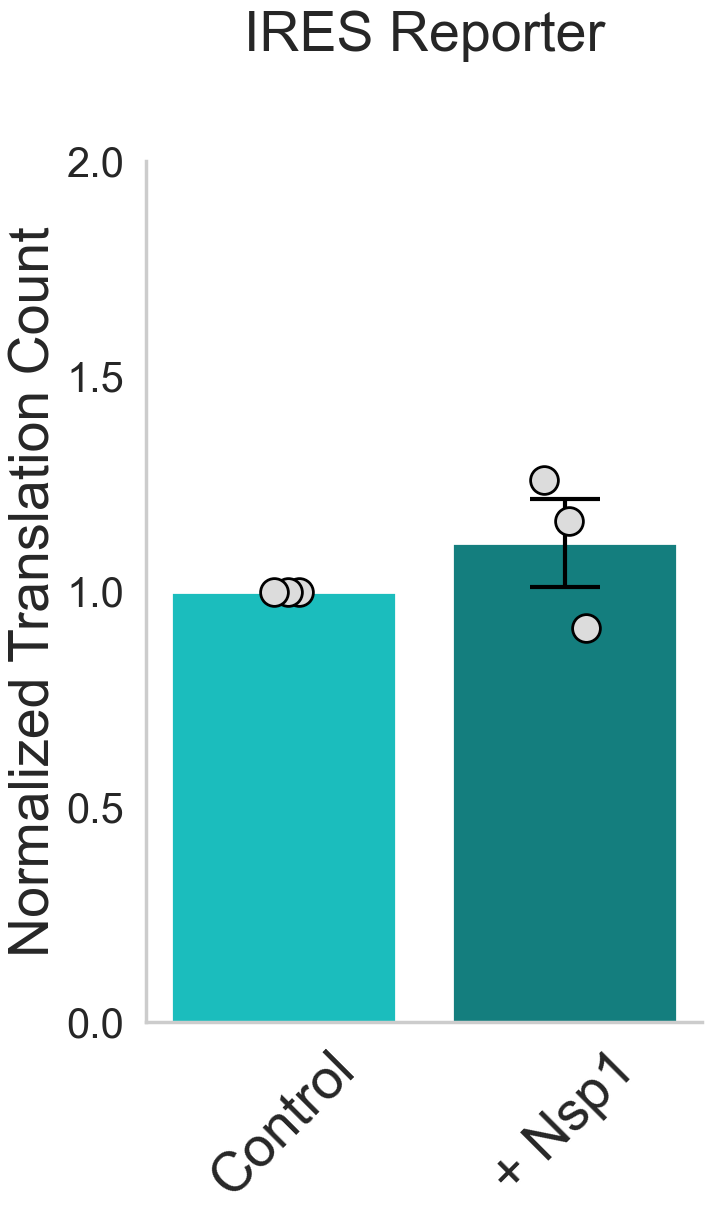

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1480045865.py:136: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1480045865.py:136: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",



[hue=BoxB_IRES] Scaled conditions vs 1.0
[hue=BoxB_IRES] Nsp1 vs 1.0: n=3, mean=1.2, p=0.152, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=BoxB_IRES]
No Nsp1: 1 ± 9.06e-17 SEM (n=3)
Nsp1: 1.2 ± 0.0905 SEM (n=3)

    test_group          test_type     contrast    x1 x2        hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  BoxB_IRES  3   3 NaN   

      mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue stars  
0  1.204839    1.0         0.204839  0.156756  NaN   2.263336  0.151939    ns  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1480045865.py:206: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


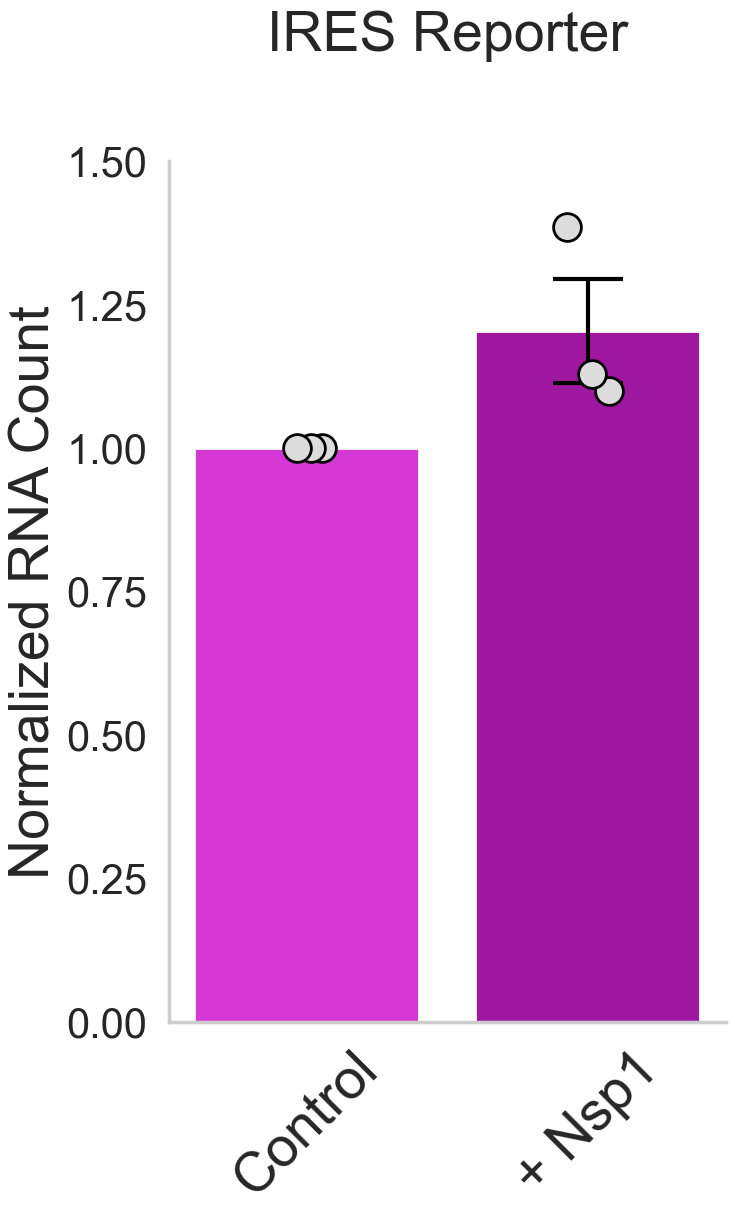

In [201]:
# Plot 9b: Scaled BoxB IRES Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = data = scale_by_reference(
    df=average_spot_count[average_spot_count["Experimental Group"] == "BoxB_IRES"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="BoxB_IRES",
    ref_type="No Nsp1",
)

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])

col = "Super Average Total Translation Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, bar_stats = replicate_sem_bar_stats(
    data=superplot_translation,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
)




# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)", 
            data=superplot_translation, order=order, ax=ax1, palette= blue_palette, errorbar=None)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI
xpos = np.arange(
    len(cats)
)


for i, cat in enumerate(
    cats
):
    # Normalized Control = 1.
    # Do not display an error bar.
    if cat == ref_type:
        continue
    sem = yerr[
        0,
        i
    ]
    if (
        np.isnan(means[i])
        or np.isnan(sem)
    ):
        continue
    ax1.errorbar(
        xpos[i],
        means[i],
        yerr=sem,
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )
    
ax1.set_ylabel('Normalized Translation Count', fontsize=40)
ax1.set_title('IRES Reporter', fontsize=40, pad=80)
ax1.set_ylim(0, 2)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res_scaled1 = print_scaled_one_sample_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Total Translation Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots BoxB IRES.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots BoxB IRES.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()

col = "Super Average Total RNA Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, bar_stats = replicate_sem_bar_stats(
    data=superplot_rna,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
)

# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)", 
            data=superplot_rna, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

xpos = np.arange(
    len(cats)
)


for i, cat in enumerate(
    cats
):
    # Normalized Control = 1.
    # Do not display an error bar.
    if cat == ref_type:
        continue
    sem = yerr[
        0,
        i
    ]
    if (
        np.isnan(means[i])
        or np.isnan(sem)
    ):
        continue
    ax2.errorbar(
        xpos[i],
        means[i],
        yerr=sem,
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )

ax2.set_ylabel('Normalized RNA Count', fontsize=40)
ax2.set_title('IRES Reporter', fontsize=40, pad=80)
ax2.set_ylim(0, 1.5)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res_scaled2 = print_scaled_one_sample_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots BoxB IRES.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots BoxB IRES.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

In [ ]:
# Plot 10: EMI NoORF Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Group"] == "EMI_NoORF"]

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total Translation Spots", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_title('uORF UTR', fontsize=40, pad=80)
ax1.set_ylim(0, 20)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Average Total Translation Spots", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots EMI NoORF.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots EMI NoORF.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total RNA Spots",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_title('uORF UTR', fontsize=40, pad=80)
ax2.set_ylim(0, 130)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Average Total RNA Spots", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots EMI NoORF.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots EMI NoORF.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2450282345.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2450282345.py:44: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",



[hue=EMI_NoORF] Scaled conditions vs 1.0
[hue=EMI_NoORF] Nsp1 vs 1.0: n=3, mean=0.652, p=0.0018, **

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=EMI_NoORF]
No Nsp1: 1 ± 1.28e-16 SEM (n=3)
Nsp1: 0.652 ± 0.0148 SEM (n=3)

    test_group          test_type     contrast    x1 x2        hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  EMI_NoORF  3   3 NaN   

      mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue stars  
0  0.651855    1.0        -0.348145  0.025599  NaN  -23.55567  0.001797    **  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2450282345.py:114: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


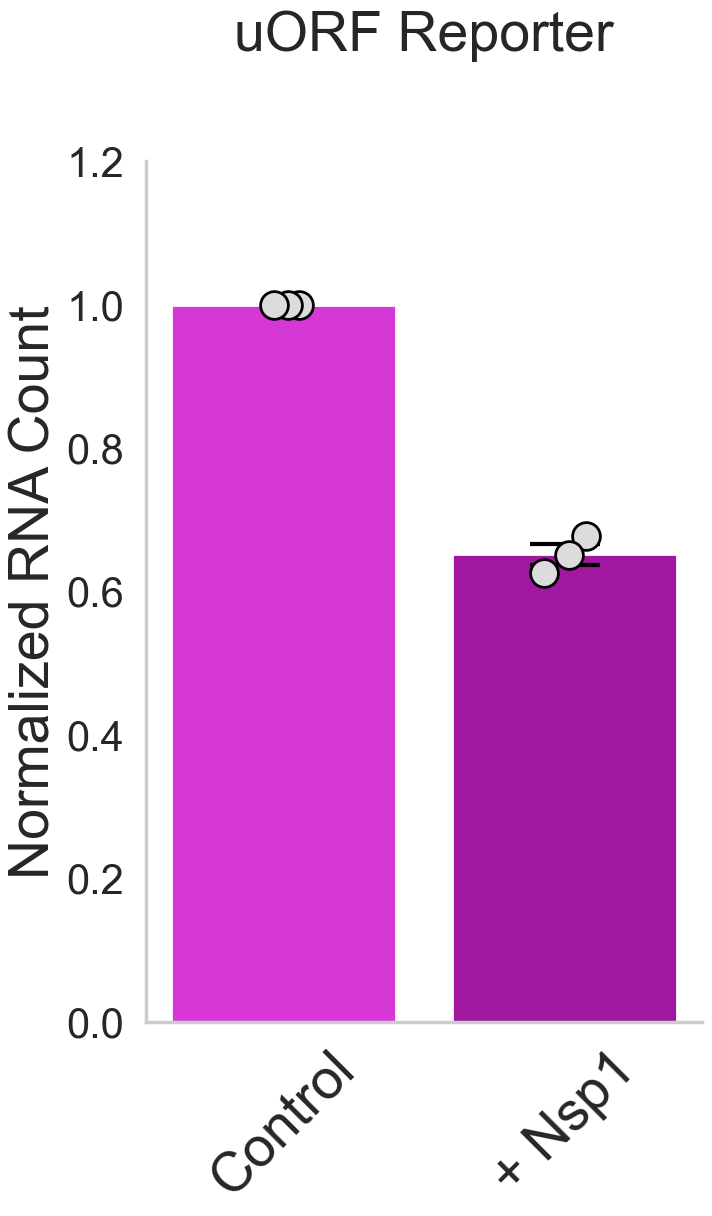

In [139]:
# Plot 10b: Scaled Emi NoORF Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = scale_by_reference(
    df=df_no_outliers[df_no_outliers["Experimental Group"] == "EMI_NoORF"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="EMI_NoORF",
    ref_type="No Nsp1",
)
superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]

# Plot 2: Total RNA Spots

col = "Super Average Total RNA Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, bar_stats = replicate_sem_bar_stats(
    data=superplot_rna,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
)

fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)", 
            data=superplot_rna, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

xpos = np.arange(
    len(cats)
)


for i, cat in enumerate(
    cats
):
    # Normalized Control = 1.
    # Do not display an error bar.
    if cat == ref_type:
        continue
    sem = yerr[
        0,
        i
    ]
    if (
        np.isnan(means[i])
        or np.isnan(sem)
    ):
        continue
    ax2.errorbar(
        xpos[i],
        means[i],
        yerr=sem,
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )
    
ax2.set_ylabel('Normalized RNA Count', fontsize=40)
ax2.set_title('uORF Reporter', fontsize=40, pad=80)
ax2.set_ylim(0, 1.2)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res_scaled2 = print_scaled_one_sample_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots EMI NoORF.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots EMI NoORF.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

In [ ]:
# Plot 11: EMI NoStart Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Group"] == "Emi_NoStart"]

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Average Total Translation Spots", 
            data=data, order=order, ax=ax1, palette= blue_palette, capsize=0.35, err_kws={"color":"black", "linewidth": 3, "alpha": 1})

sns.stripplot(x="Experimental Type", y="Average Total Translation Spots", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_title('\u0394 uORF UTR', fontsize=40, pad=80)
ax1.set_ylim(0, 20)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Average Total Translation Spots", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots EMI NoStart.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots EMI NoStart.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total RNA Spots",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_title('\u0394 uORF UTR', fontsize=40, pad=80)
ax2.set_ylim(0, 90)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Average Total RNA Spots", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots EMI NoStart.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots EMI NoStart.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\660030679.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\660030679.py:43: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",



[hue=Emi_NoStart] Scaled conditions vs 1.0
[hue=Emi_NoStart] Nsp1 vs 1.0: n=3, mean=0.931, p=0.304, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=Emi_NoStart]
No Nsp1: 1 ± 9.06e-17 SEM (n=3)
Nsp1: 0.931 ± 0.0506 SEM (n=3)

    test_group          test_type     contrast    x1 x2          hue  n  n1  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  Emi_NoStart  3   3   

   n2     mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue  \
0 NaN  0.930675    1.0        -0.069325  0.087699  NaN  -1.369166  0.304428   

  stars  
0    ns  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\660030679.py:113: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


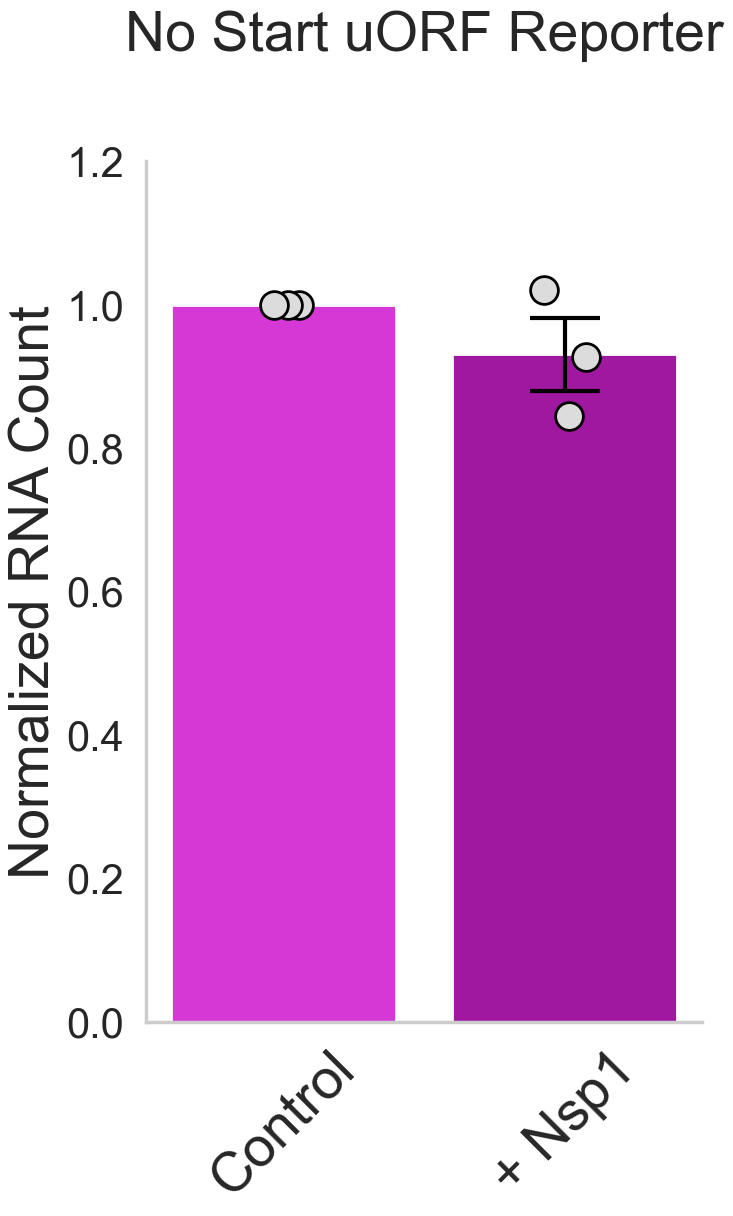

In [140]:
# Plot 11b: Scaled Emi NoStart Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = scale_by_reference(
    df=df_no_outliers[df_no_outliers["Experimental Group"] == "Emi_NoStart"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="Emi_NoStart",
    ref_type="No Nsp1",
)
superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]
# Plot 2: Total RNA Spots

col = "Super Average Total RNA Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, bar_stats = replicate_sem_bar_stats(
    data=superplot_rna,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
)

fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)", 
            data=superplot_rna, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

xpos = np.arange(
    len(cats)
)


for i, cat in enumerate(
    cats
):
    # Normalized Control = 1.
    # Do not display an error bar.
    if cat == ref_type:
        continue
    sem = yerr[
        0,
        i
    ]
    if (
        np.isnan(means[i])
        or np.isnan(sem)
    ):
        continue
    ax2.errorbar(
        xpos[i],
        means[i],
        yerr=sem,
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )
    
ax2.set_ylabel('Normalized RNA Count', fontsize=40)
ax2.set_title('No Start uORF Reporter', fontsize=40, pad=80)
ax2.set_ylim(0, 1.2)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res_scaled2 = print_scaled_one_sample_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots EMI NoStart.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots EMI NoStart.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

In [ ]:
#Prepare data for combined plot of scaled Total Translation Spots and Total RNA Spots for all three groups (SARS_CTRL, Emi_KDM5B, BoxB_MS2)
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the order for the x-axis categories
data = data = scale_by_reference(
    df=average_spot_count[average_spot_count["Experimental Group"] == "SARS_CTRL"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="SARS_CTRL",
    ref_type="No Nsp1",
)
data1 = scale_by_reference(
    df=df_no_outliers[df_no_outliers["Experimental Group"] == "Emi_KDM5B"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="Emi_KDM5B",
    ref_type="No Nsp1",
)
outlier_df, data1 = detect_and_drop_replicate_outliers(
    data1,
    drop_mode="manual",
    manual_drop={
        "No Nsp1": [3],   # drop reps 1 & 3 for this Type
        "Nsp1": [3],      # drop reps 1 & 3 for this Type
        "noCTD Nsp1": [3] # drop reps 4 & 5 for this Type
    }
)
data2 = scale_by_reference(
    df=df_no_outliers[df_no_outliers["Experimental Group"] == "BoxB_MS2"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="BoxB_MS2",
    ref_type="No Nsp1",
)
outlier_df, data2 = detect_and_drop_replicate_outliers(
    data2,
    drop_mode="manual",
    manual_drop={
        "No Nsp1": [5],   # drop reps 1 & 3 for this Type
        "Nsp1": [5],      # drop reps 1 & 3 for this Type
        "noCTD Nsp1": [5] # drop reps 4 & 5 for this Type
    }
)
data2["Average Total Translation Spots (scaled)"] = data2["Average Total Translation Spots (scaled)"].fillna(0)
combined_data_norm = pd.concat([data, data1, data2], ignore_index=True)

data = average_spot_count[average_spot_count["Experimental Group"] == "SARS_CTRL"]
data1 = average_spot_count[average_spot_count["Experimental Group"] == "Emi_KDM5B"]
data2 = average_spot_count[average_spot_count["Experimental Group"] == "BoxB_MS2"]
combined_data = pd.concat([data, data1, data2], ignore_index=True)


In [ ]:
# Plot 12: Combined Scaled Total Translation Spots and Total RNA Spots for SARS_CTRL, Emi_KDM5B, BoxB_MS2
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch

# -------------------------------------------------------
# Global plotting style
# -------------------------------------------------------
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# -------------------------------------------------------
# Category orders and label maps
# -------------------------------------------------------
type_order  = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]
group_order = ["SARS_CTRL", "Emi_KDM5B", "BoxB_MS2"]

type_label_map = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
    "NoCTD Nsp1": "ΔNsp1",
}

group_label_map = {
    "SARS_CTRL": "Host UTR",
    "Emi_KDM5B": "uORF UTR",
    "BoxB_MS2": "No ORF",
}

hatch_map = {
    "SARS_CTRL": "",
    "Emi_KDM5B": "//",
    "BoxB_MS2": "\\\\",
}

# Keep only the three groups of interest
combined_data_norm = combined_data_norm[
    combined_data_norm["Experimental Group"].isin(group_order)
].copy()

trans_col = "Average Total Translation Spots (scaled)"
rna_col   = "Average Total RNA Spots (scaled)"

# Map type → color
type_color_map_trans = {t: blue_palette[i] for i, t in enumerate(type_order)}
type_color_map_rna   = {t: magenta_palette[i] for i, t in enumerate(type_order)}

# -------------------------------------------------------
# Superplot data (replicate-level averages)
# -------------------------------------------------------
superplot_translation = calculate_grouped_average(
    combined_data_norm,
    trans_col,
    ["Experimental Group", "Experimental Type", "Replicate_Number"],
)

superplot_rna = calculate_grouped_average(
    combined_data_norm,
    rna_col,
    ["Experimental Group", "Experimental Type", "Replicate_Number"],
)

n_types = len(type_order)
n_groups = len(group_order)

# -------------------------------------------------------
# Helper to compute per-bar CI from superplot data
# -------------------------------------------------------
def compute_grouped_bar_ci(data, value_col, type_order, group_order, ref_type="No Nsp1", n_boot=1000, ci=95):
    rows = []

    for t in type_order:
        for g in group_order:
            sub = data[
                (data["Experimental Type"] == t) &
                (data["Experimental Group"] == g)
            ][value_col].dropna()

            if len(sub) == 0:
                mean_val = np.nan
                low = np.nan
                high = np.nan
            else:
                mean_val = sub.mean()

                if t == ref_type:
                    low = mean_val
                    high = mean_val
                else:
                    boot_means = []
                    vals = sub.to_numpy()

                    for _ in range(n_boot):
                        sample = np.random.choice(vals, size=len(vals), replace=True)
                        boot_means.append(np.mean(sample))

                    alpha = (100 - ci) / 2
                    low = np.percentile(boot_means, alpha)
                    high = np.percentile(boot_means, 100 - alpha)

            rows.append({
                "Experimental Type": t,
                "Experimental Group": g,
                "mean": mean_val,
                "ci_low": low,
                "ci_high": high,
                "yerr_low": mean_val - low if pd.notna(mean_val) and pd.notna(low) else np.nan,
                "yerr_high": high - mean_val if pd.notna(mean_val) and pd.notna(high) else np.nan,
            })

    return pd.DataFrame(rows)

# =====================================================================
# PLOT 1: Translation Spots (scaled)
# =====================================================================
plot_col_trans = "Super Average Total Translation Spots (scaled)"
stats_tr = compute_grouped_bar_ci(
    data=superplot_translation,
    value_col=plot_col_trans,
    type_order=type_order,
    group_order=group_order,
    ref_type="No Nsp1",
    n_boot=1000,
    ci=95,
)

fig1, ax1 = plt.subplots(figsize=(16, 16), constrained_layout=True)
sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(
    x="Experimental Type",
    y=plot_col_trans,
    hue="Experimental Group",
    data=superplot_translation,
    order=type_order,
    hue_order=group_order,
    ax=ax1,
    palette="Greys",
    errorbar=None,
)

# Re-color & hatch bars
for i, patch in enumerate(ax1.patches):
    group_idx = i // n_types
    type_idx  = i % n_types

    if group_idx >= n_groups or type_idx >= n_types:
        continue

    g = group_order[group_idx]
    t = type_order[type_idx]

    patch.set_facecolor(type_color_map_trans[t])
    patch.set_edgecolor("black")
    patch.set_hatch(hatch_map.get(g, ""))

# Superplot circles with jitter
plot_open_circles_with_hue(
    ax1,
    superplot_translation,
    order=type_order,
    x="Experimental Type",
    y=plot_col_trans,
    hue="Experimental Group",
    hue_order=group_order,
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

# Per-bar error bars, skipping the Control category
for i, patch in enumerate(ax1.patches):
    group_idx = i // n_types
    type_idx  = i % n_types

    if group_idx >= n_groups or type_idx >= n_types:
        continue

    g = group_order[group_idx]
    t = type_order[type_idx]

    if t == "No Nsp1":
        continue

    row = stats_tr[
        (stats_tr["Experimental Type"] == t) &
        (stats_tr["Experimental Group"] == g)
    ]

    if row.empty or row["mean"].isna().iloc[0]:
        continue

    mean_val = row["mean"].iloc[0]
    yerr_low = row["yerr_low"].iloc[0]
    yerr_high = row["yerr_high"].iloc[0]

    x_center = patch.get_x() + patch.get_width() / 2.0
    ax1.errorbar(
        x_center,
        mean_val,
        yerr=[[yerr_low], [yerr_high]],
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )

ax1.set_ylabel("Normalized Translation Count", fontsize=40)
ax1.set_ylim(0, 2)
ax1.tick_params(axis="both", which="major", labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax1.set_xlabel("")

ax1.set_xticklabels(
    [type_label_map[t] for t in type_order],
    fontsize=40,
    rotation=0,
)

if ax1.get_legend() is not None:
    ax1.get_legend().remove()

legend_patches = [
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch=hatch_map[g],
        label=group_label_map[g],
    )
    for g in group_order
]
ax1.legend(
    handles=legend_patches,
    title="Experimental Group",
    fontsize=20,
    title_fontsize=22,
    loc="upper left",
)

res1 = print_ttest_summary(
    x="Experimental Type",
    y=plot_col_trans,
    hue="Experimental Group",
    data=superplot_translation,
    order=type_order,
)
print(res1)

filename_svg_translation = os.path.join(
    save_directory + spot_count_folder, "Combined_Normalized_Total_Translation_Spots.svg"
)
filename_png_translation = os.path.join(
    save_directory + spot_count_folder, "Combined_Normalized_Total_Translation_Spots.png"
)
fig1.savefig(filename_svg_translation, format="svg", dpi=300)
fig1.savefig(filename_png_translation, format="png", dpi=300)

plt.tight_layout()
plt.show()

# =====================================================================
# PLOT 2: RNA Spots (scaled)
# =====================================================================
plot_col_rna = "Super Average Total RNA Spots (scaled)"
stats_rna = compute_grouped_bar_ci(
    data=superplot_rna,
    value_col=plot_col_rna,
    type_order=type_order,
    group_order=group_order,
    ref_type="No Nsp1",
    n_boot=1000,
    ci=95,
)

fig2, ax2 = plt.subplots(figsize=(16, 16), constrained_layout=True)
sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(
    x="Experimental Type",
    y=plot_col_rna,
    hue="Experimental Group",
    data=superplot_rna,
    order=type_order,
    hue_order=group_order,
    ax=ax2,
    palette="Greys",
    errorbar=None,
)

# Re-color & hatch bars
for i, patch in enumerate(ax2.patches):
    group_idx = i // n_types
    type_idx  = i % n_types

    if group_idx >= n_groups or type_idx >= n_types:
        continue

    g = group_order[group_idx]
    t = type_order[type_idx]

    patch.set_facecolor(type_color_map_rna[t])
    patch.set_edgecolor("black")
    patch.set_hatch(hatch_map.get(g, ""))

# Superplot circles with jitter
plot_open_circles_with_hue(
    ax2,
    superplot_rna,
    order=type_order,
    x="Experimental Type",
    y=plot_col_rna,
    hue="Experimental Group",
    hue_order=group_order,
    jitter=True,
    jitter_strength=0.08,
    random_state=100,
)

# Per-bar error bars, skipping the Control category
for i, patch in enumerate(ax2.patches):
    group_idx = i // n_types
    type_idx  = i % n_types

    if group_idx >= n_groups or type_idx >= n_types:
        continue

    g = group_order[group_idx]
    t = type_order[type_idx]

    if t == "No Nsp1":
        continue

    row = stats_rna[
        (stats_rna["Experimental Type"] == t) &
        (stats_rna["Experimental Group"] == g)
    ]

    if row.empty or row["mean"].isna().iloc[0]:
        continue

    mean_val = row["mean"].iloc[0]
    yerr_low = row["yerr_low"].iloc[0]
    yerr_high = row["yerr_high"].iloc[0]

    x_center = patch.get_x() + patch.get_width() / 2.0
    ax2.errorbar(
        x_center,
        mean_val,
        yerr=[[yerr_low], [yerr_high]],
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )

ax2.set_ylabel("Normalized RNA Count", fontsize=40)
ax2.set_ylim(0, 2)
ax2.tick_params(axis="both", which="major", labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax2.set_xlabel("")

ax2.set_xticklabels(
    [type_label_map[t] for t in type_order],
    fontsize=40,
    rotation=0,
)

if ax2.get_legend() is not None:
    ax2.get_legend().remove()

legend_patches2 = [
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch=hatch_map[g],
        label=group_label_map[g],
    )
    for g in group_order
]
ax2.legend(
    handles=legend_patches2,
    title="Experimental Group",
    fontsize=20,
    title_fontsize=22,
    loc="upper right",
)

res2 = print_ttest_summary(
    x="Experimental Type",
    y=plot_col_rna,
    hue="Experimental Group",
    data=superplot_rna,
    order=type_order,
)
print(res2)

filename_svg_rna = os.path.join(
    save_directory + spot_count_folder, "Combined_Normalized_Total_RNA_Spots.svg"
)
filename_png_rna = os.path.join(
    save_directory + spot_count_folder, "Combined_Normalized_Total_RNA_Spots.png"
)
fig2.savefig(filename_svg_rna, format="svg", dpi=300)
fig2.savefig(filename_png_rna, format="png", dpi=300)

plt.tight_layout()
plt.show()

In [ ]:
#Simulate expected data with tight bounds for No Nsp1 and Nsp1 conditions, reflecting the new baseline where Trnl_None has 0 translation but 1 RNA in the absence of Nsp1. This will help us verify that our plotting code can accurately represent the expected patterns and that the error bars are correctly calculated and displayed.

import numpy as np
import pandas as pd

def simulate_expected_df(
    n_fov_per_rep: int = 30,
    seed: int = 0,
    sd: float = 0.2,
    max_dev: float = 0.15,
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)

    exp_groups = ["Trnl_High", "Trnl_Low", "Trnl_None"]
    reps = [1, 2, 3]

    # --- UPDATED TARGETS ---
    # Baseline (No Nsp1): RNA=1.0 everywhere, but Translation=0.0 for Trnl_None
    no_nsp1_rna_target = {g: 1.0 for g in exp_groups}
    no_nsp1_tr_target  = {"Trnl_High": 1.0, "Trnl_Low": 1.0, "Trnl_None": 0.0}

    # Nsp1 targets (same as before)
    nsp1_rna_target = {"Trnl_High": 0.5, "Trnl_Low": 0.75, "Trnl_None": 1.0}
    nsp1_tr_target  = {"Trnl_High": 1.0, "Trnl_Low": 1.0, "Trnl_None": 0.0}

    def gen_values(target: float, size: int, nonneg: bool = True) -> np.ndarray:
        # If target is 0 and values must be non-negative, enforce exact zeros.
        if target == 0.0 and nonneg:
            return np.zeros(size, dtype=float)

        vals = rng.normal(loc=target, scale=sd, size=size)

        lo = target - max_dev
        hi = target + max_dev
        if nonneg:
            lo = max(0.0, lo)

        vals = np.clip(vals, lo, hi)

        # recenter while preserving bounds
        for _ in range(5):
            vals = vals + (target - vals.mean())
            vals = np.clip(vals, lo, hi)
            if abs(vals.mean() - target) < 1e-3:
                break

        return vals

    no_nsp1_rows = []
    for g in exp_groups:
        for r in reps:
            fovs = np.arange(n_fov_per_rep)

            tr_vals  = gen_values(no_nsp1_tr_target[g],  n_fov_per_rep)
            rna_vals = gen_values(no_nsp1_rna_target[g], n_fov_per_rep)

            for f, tr, rna in zip(fovs, tr_vals, rna_vals):
                no_nsp1_rows.append((g, int(f), "No Nsp1", r, float(tr), float(rna)))

    nsp1_rows = []
    for g in exp_groups:
        for r in reps:
            fovs = np.arange(n_fov_per_rep)

            tr_vals  = gen_values(nsp1_tr_target[g],  n_fov_per_rep)
            rna_vals = gen_values(nsp1_rna_target[g], n_fov_per_rep)

            for f, tr, rna in zip(fovs, tr_vals, rna_vals):
                nsp1_rows.append((g, int(f), "Nsp1", r, float(tr), float(rna)))

    # ΔNsp1 mirrors No Nsp1 exactly (row-by-row copy)
    delta_rows = [(g, f, "ΔNsp1", r, tr, rna) for (g, f, _, r, tr, rna) in no_nsp1_rows]

    df = pd.DataFrame(
        no_nsp1_rows + nsp1_rows + delta_rows,
        columns=[
            "Experimental Group",
            "fov",
            "Experimental Type",
            "Replicate_Number",
            "Average Total Translation Spots (scaled)",
            "Average Total RNA Spots (scaled)",
        ],
    )
    return df


# --- Example usage ---
df_expected = simulate_expected_df(n_fov_per_rep=30, seed=1)

means = (
    df_expected
    .groupby(["Experimental Group", "Experimental Type"])[
        ["Average Total Translation Spots (scaled)", "Average Total RNA Spots (scaled)"]
    ]
    .mean()
)
print(means)

# Updated bounds check consistent with the new baseline for Trnl_None translation
def verify_tight_bounds(df, max_dev=0.15):
    no_nsp1_tr = {"Trnl_High": 1.0, "Trnl_Low": 1.0, "Trnl_None": 0.0}
    no_nsp1_rna = {"Trnl_High": 1.0, "Trnl_Low": 1.0, "Trnl_None": 1.0}

    nsp1_rna = {"Trnl_High": 0.5, "Trnl_Low": 0.75, "Trnl_None": 1.0}
    nsp1_tr  = {"Trnl_High": 1.0, "Trnl_Low": 1.0, "Trnl_None": 0.0}

    for (g, t), sub in df.groupby(["Experimental Group", "Experimental Type"]):
        if t in ["No Nsp1", "ΔNsp1"]:
            tr_target, rna_target = no_nsp1_tr[g], no_nsp1_rna[g]
        else:
            tr_target, rna_target = nsp1_tr[g], nsp1_rna[g]

        tr = sub["Average Total Translation Spots (scaled)"].to_numpy()
        rna = sub["Average Total RNA Spots (scaled)"].to_numpy()

        if tr_target == 0.0:
            assert np.all(tr == 0.0), f"{g}/{t}: translation not all zeros as requested"
        else:
            assert tr.min() >= max(0.0, tr_target - max_dev) - 1e-9 and tr.max() <= tr_target + max_dev + 1e-9, \
                f"{g}/{t}: translation out of bounds"

        assert rna.min() >= max(0.0, rna_target - max_dev) - 1e-9 and rna.max() <= rna_target + max_dev + 1e-9, \
            f"{g}/{t}: RNA out of bounds"

verify_tight_bounds(df_expected)
print("All bounds checks passed.")

In [ ]:
#Plot 13: Combined Scaled Total Translation Spots and Total RNA Spots for SARS_CTRL, Emi_KDM5B, BoxB_MS2 with simulated expected data
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch

# -------------------------------------------------------
# Global plotting style
# -------------------------------------------------------
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# -------------------------------------------------------
# Category orders and label maps (SIM DATA)
# -------------------------------------------------------
type_order  = ["No Nsp1", "Nsp1", "ΔNsp1"]
group_order = ["Trnl_High", "Trnl_Low", "Trnl_None"]

type_label_map = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
    "ΔNsp1": "ΔNsp1",
}

group_label_map = {
    "Trnl_High": "Trnl High",
    "Trnl_Low":  "Trnl Low",
    "Trnl_None": "Trnl None",
}

hatch_map = {
    "Trnl_High": "",
    "Trnl_Low":  "//",
    "Trnl_None": "\\\\",
}

ref_type = None

# -------------------------------------------------------
# Use your simulated dataframe
# -------------------------------------------------------
combined_data_norm = df_expected.copy()
combined_data_norm = combined_data_norm[
    combined_data_norm["Experimental Group"].isin(group_order)
].copy()

trans_col = "Average Total Translation Spots (scaled)"
rna_col   = "Average Total RNA Spots (scaled)"

# -------------------------------------------------------
# Superplot data (replicate-level)
# -------------------------------------------------------
superplot_translation = calculate_grouped_average(
    combined_data_norm,
    trans_col,
    ["Experimental Group", "Experimental Type", "Replicate_Number"],
)

superplot_rna = calculate_grouped_average(
    combined_data_norm,
    rna_col,
    ["Experimental Group", "Experimental Type", "Replicate_Number"],
)

ci_mult = 1.96

# -------------------------------------------------------
# Helpers
# -------------------------------------------------------
def set_gray_bars_and_hatches(ax, group_order, hatch_map, facecolor="0.75"):
    """
    Make all bars gray, keep hatch patterns by group (hue).
    Seaborn barplot creates one BarContainer per hue level (group_order).
    """
    for g_idx, container in enumerate(ax.containers):
        if g_idx >= len(group_order):
            continue
        g = group_order[g_idx]
        for patch in container.patches:
            patch.set_facecolor(facecolor)          # gray fill
            patch.set_edgecolor("black")
            patch.set_hatch(hatch_map.get(g, ""))   # hatch by group

def add_ci_errorbars(ax, df, y_col, type_order, group_order, ref_type, ci_mult):
    summary = (
        df.groupby(["Experimental Type", "Experimental Group"], observed=True)[y_col]
          .agg(["mean", "sem"])
          .reset_index()
    )

    for g_idx, container in enumerate(ax.containers):
        if g_idx >= len(group_order):
            continue
        g = group_order[g_idx]

        for t_idx, patch in enumerate(container.patches):
            if t_idx >= len(type_order):
                continue
            t = type_order[t_idx]

            row = summary[
                (summary["Experimental Type"] == t) &
                (summary["Experimental Group"] == g)
            ]
            if row.empty:
                continue

            mean_val = row["mean"].values[0]
            if t == ref_type:
                yerr = 0.0
            else:
                sem = row["sem"].values[0]
                yerr = ci_mult * sem if (sem is not None and not np.isnan(sem)) else 0.0

            x_center = patch.get_x() + patch.get_width() / 2.0
            ax.errorbar(
                x_center,
                mean_val,
                yerr=yerr,
                fmt="none",
                elinewidth=3,
                capsize=25,
                capthick=3,
                color="black",
                alpha=1,
            )

def set_common_axes_format(ax, type_order, type_label_map, ylabel, ylim_top):
    ax.set_ylabel(ylabel, fontsize=40)
    ax.tick_params(axis="both", which="major", labelsize=30)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=10))
    ax.set_xlabel("")
    ax.set_xticklabels([type_label_map[t] for t in type_order], fontsize=40, rotation=0)
    ax.set_ylim(0, ylim_top)

# =====================================================================
# PLOT 1: Translation
# =====================================================================
fig1, ax1 = plt.subplots(figsize=(16, 16), constrained_layout=True)
sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(
    x="Experimental Type",
    y=trans_col,
    hue="Experimental Group",
    data=combined_data_norm,
    order=type_order,
    hue_order=group_order,
    ax=ax1,
    palette=["0.75"] * len(group_order),  # all gray (one per hue level)
    errorbar=None,
)

# Force consistent gray + keep hatches
set_gray_bars_and_hatches(ax1, group_order, hatch_map, facecolor="0.75")



add_ci_errorbars(ax1, combined_data_norm, trans_col, type_order, group_order, ref_type, ci_mult)

set_common_axes_format(ax1, type_order, type_label_map, ylabel="Translation Spots (#, scaled)", ylim_top=1.3)

if ax1.get_legend() is not None:
    ax1.get_legend().remove()

legend_patches = [
    Patch(facecolor="white", edgecolor="black", hatch=hatch_map[g], label=group_label_map[g])
    for g in group_order
]
ax1.legend(handles=legend_patches, title="Experimental Group", fontsize=20, title_fontsize=22, loc="upper left")
ax1.set_ylabel("Normalized Translation Count", fontsize=40)
ax1.set_ylim(0, 1.5)
ax1.tick_params(axis="both", which="major", labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=3))
ax1.set_xlabel("")

res1 = print_ttest_summary(
    x="Experimental Type",
    y=trans_col,
    hue="Experimental Group",
    data=combined_data_norm,
    order=type_order,
)
print(res1)

fig1.savefig(os.path.join(save_directory+ spot_count_folder, "Expected_Normalized_Total_Translation_Spots.svg"), format="svg", dpi=300)
fig1.savefig(os.path.join(save_directory+ spot_count_folder, "Expected_Normalized_Total_Translation_Spots.png"), format="png", dpi=300)

plt.tight_layout()
plt.show()

# =====================================================================
# PLOT 2: RNA
# =====================================================================
fig2, ax2 = plt.subplots(figsize=(16, 16), constrained_layout=True)
sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(
    x="Experimental Type",
    y=rna_col,
    hue="Experimental Group",
    data=combined_data_norm,
    order=type_order,
    hue_order=group_order,
    ax=ax2,
    palette=["0.75"] * len(group_order),
    errorbar=None,
)

set_gray_bars_and_hatches(ax2, group_order, hatch_map, facecolor="0.75")


add_ci_errorbars(ax2, combined_data_norm, rna_col, type_order, group_order, ref_type, ci_mult)

set_common_axes_format(ax2, type_order, type_label_map, ylabel="RNA Spots (#, scaled)", ylim_top=1.3)

if ax2.get_legend() is not None:
    ax2.get_legend().remove()

legend_patches2 = [
    Patch(facecolor="white", edgecolor="black", hatch=hatch_map[g], label=group_label_map[g])
    for g in group_order
]
ax2.legend(handles=legend_patches2, title="Experimental Group", fontsize=20, title_fontsize=22, loc="upper right")
ax2.set_ylabel("Normalized Translation Count", fontsize=40)
ax2.set_ylim(0, 1.5)
ax2.tick_params(axis="both", which="major", labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=3))
ax2.set_xlabel("")

res2 = print_ttest_summary(
    x="Experimental Type",
    y=rna_col,
    hue="Experimental Group",
    data=combined_data_norm,
    order=type_order,
)
print(res2)

fig2.savefig(os.path.join(save_directory + spot_count_folder, "Expected_Normalized_Total_RNA_Spots.svg"), format="svg", dpi=300)
fig2.savefig(os.path.join(save_directory + spot_count_folder, "Expected_Normalized_Total_RNA_Spots.png"), format="png", dpi=300)

plt.tight_layout()
plt.show()

In [ ]:
# Plot 14: KDM5B Standard Reporter Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Group"] == "KDM5B"]

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


sns.stripplot(x="Experimental Type", y="Average Total Translation Spots", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)



ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 20)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_title('KDM5B Reporter', fontsize=40, pad=80)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Total Translation Spots",
    hue="Experimental Group",
    pair_col="Replicate_Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots KDM5B.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots KDM5B.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total RNA Spots",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_ylim(0, 40)
ax2.set_title('KDM5B Reporter', fontsize=40, pad=80)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots",
    hue="Experimental Group",
    pair_col="Replicate_Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res1)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots KDM5B.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots KDM5B.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1041540899.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1041540899.py:48: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",



[hue=KDM5B] Scaled conditions vs 1.0
[hue=KDM5B] Nsp1 vs 1.0: n=3, mean=0.138, p=0.00183, **

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=KDM5B]
No Nsp1: 1 ± 4.53e-17 SEM (n=3)
Nsp1: 0.138 ± 0.0369 SEM (n=3)

    test_group          test_type     contrast    x1 x2    hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  KDM5B  3   3 NaN   

      mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue stars  
0  0.138201    1.0        -0.861799  0.063968  NaN -23.334701  0.001831    **  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1041540899.py:104: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


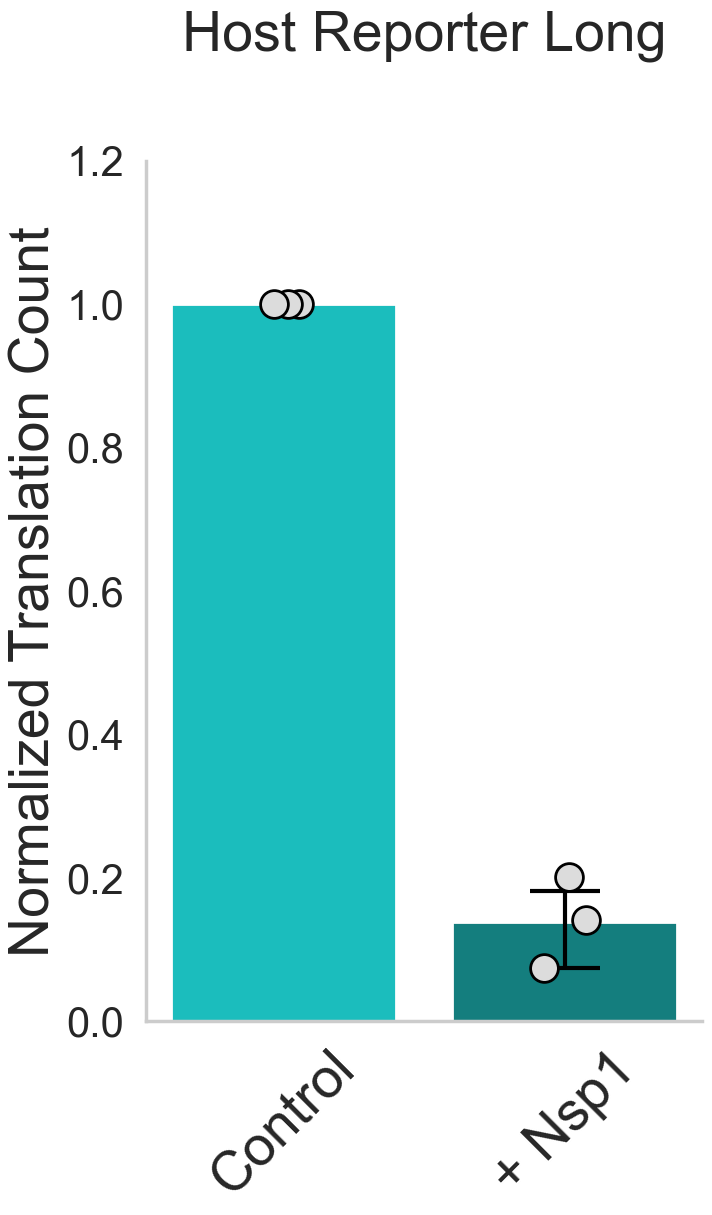

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1041540899.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1041540899.py:125: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",



[hue=KDM5B] Scaled conditions vs 1.0
[hue=KDM5B] Nsp1 vs 1.0: n=3, mean=0.254, p=0.00165, **

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=KDM5B]
No Nsp1: 1 ± 4.53e-17 SEM (n=3)
Nsp1: 0.254 ± 0.0303 SEM (n=3)

    test_group          test_type     contrast    x1 x2    hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  KDM5B  3   3 NaN   

     mean1  mean2  mean_difference       sd1  sd2  statistic   pvalue stars  
0  0.25432    1.0         -0.74568  0.052534  NaN -24.585008  0.00165    **  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1041540899.py:182: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


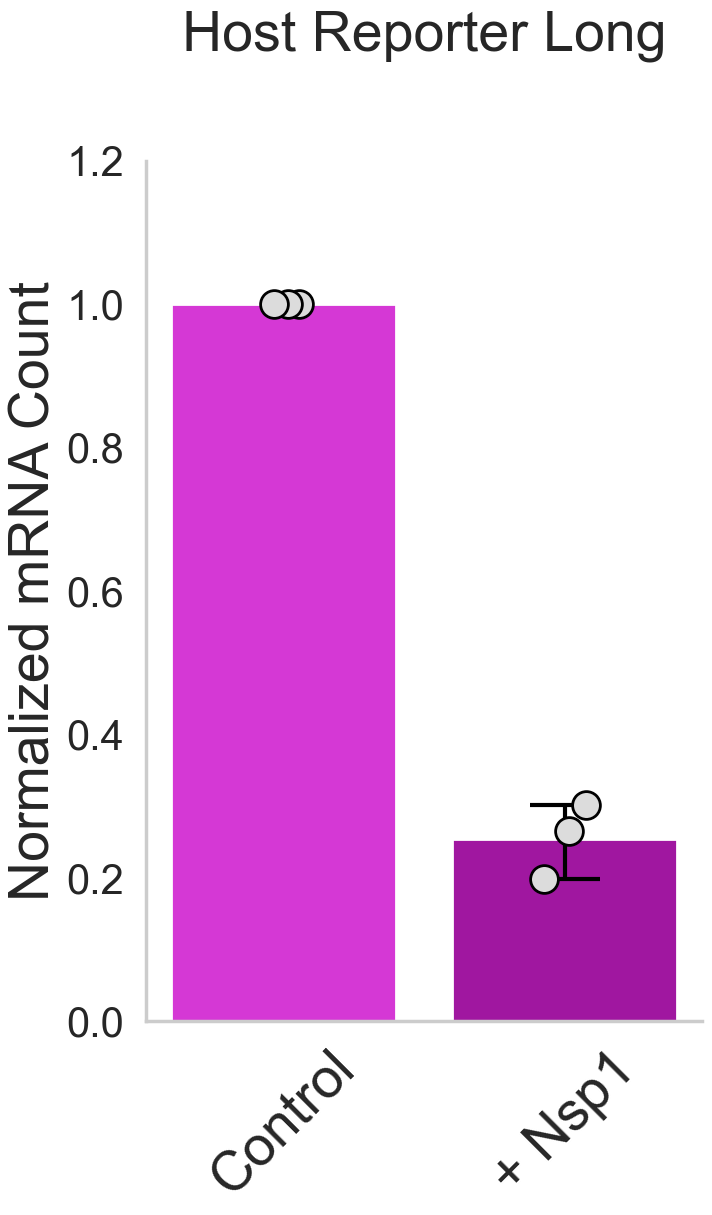

In [141]:
# Plot 14b: Scaled KDM5B Standard Reporter Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = data = scale_by_reference(
    df=average_spot_count[average_spot_count["Experimental Group"] == "KDM5B"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="KDM5B",
    ref_type="No Nsp1",
)
# Generate Per-Replicate dataframe for superplots
superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])

col = "Super Average Total Translation Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=superplot_translation,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)




# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)", 
            data=superplot_translation, order=order, ax=ax1, palette= blue_palette, errorbar=None)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI
xpos = np.arange(len(cats))

for i in range(len(cats)):
    if i == 0:
        continue  # skip the first category

    ax1.errorbar(
        xpos[i],
        means[i],
        yerr=[[yerr[0, i]], [yerr[1, i]]],  # asymmetric error for one bar
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )
    
ax1.set_ylabel('Normalized Translation Count', fontsize=40)
ax1.set_title('Host Reporter Long', fontsize=40, pad=80)
ax1.set_ylim(0, 1.2)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res_scaled1 = print_scaled_one_sample_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Total Translation Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots KDM5B.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots KDM5B.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()

col = "Super Average Total RNA Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=superplot_rna,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)

# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)", 
            data=superplot_rna, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI
xpos = np.arange(len(cats))

for i in range(len(cats)):
    if i == 0:
        continue  # skip the first category

    ax2.errorbar(
        xpos[i],
        means[i],
        yerr=[[yerr[0, i]], [yerr[1, i]]],  # asymmetric error for one bar
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )


ax2.set_ylabel('Normalized mRNA Count', fontsize=40)
ax2.set_ylim(0, 1.2)
ax2.set_title('Host Reporter Long', fontsize=40, pad=80)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res_scaled2 = print_scaled_one_sample_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots KDM5B.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots KDM5B.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\224655753.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\224655753.py:48: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",



[hue=ZNF_KDM5B] Scaled conditions vs 1.0
[hue=ZNF_KDM5B] Nsp1 vs 1.0: n=3, mean=0.579, p=0.0525, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_KDM5B]
No Nsp1: 1 ± 4.53e-17 SEM (n=3)
Nsp1: 0.579 ± 0.1 SEM (n=3)

    test_group          test_type     contrast    x1 x2        hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  ZNF_KDM5B  3   3 NaN   

      mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue stars  
0  0.579365    1.0        -0.420635  0.173911  NaN  -4.189265  0.052531    ns  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\224655753.py:104: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


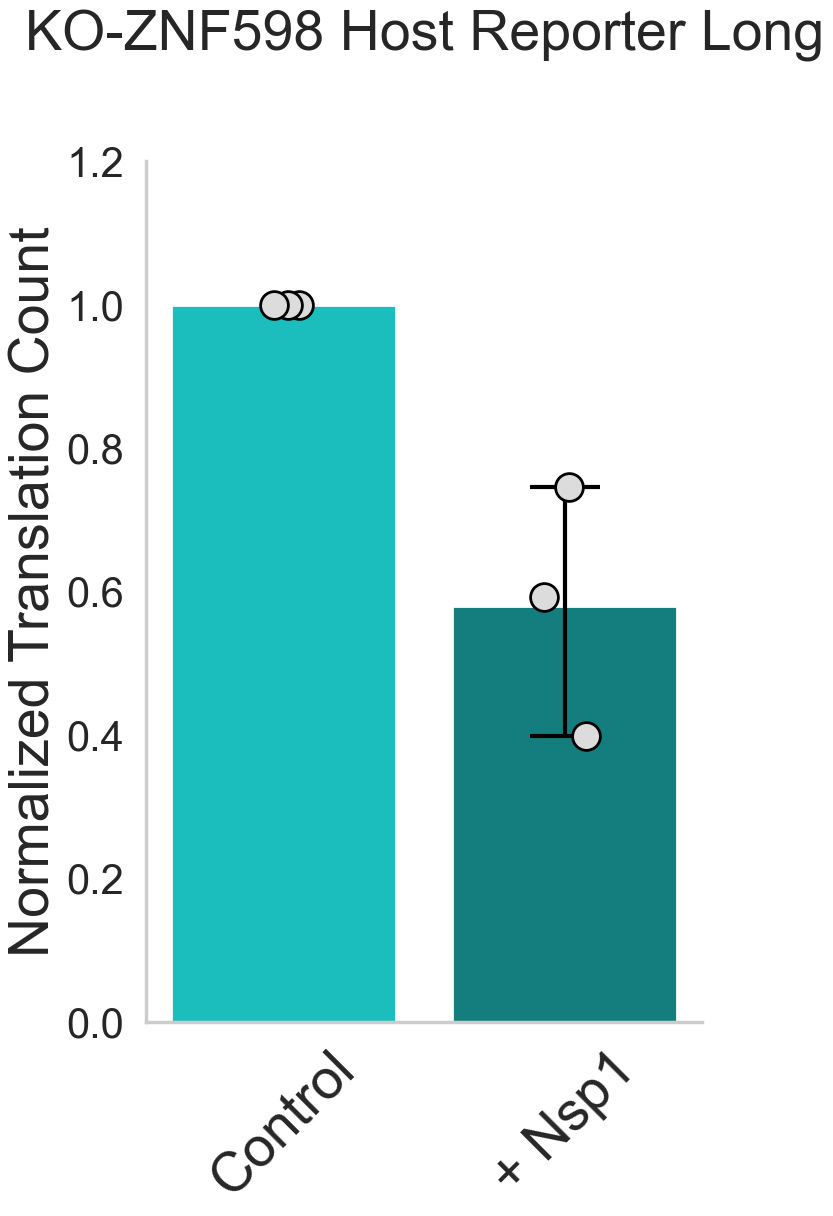

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\224655753.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\224655753.py:125: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",



[hue=ZNF_KDM5B] Scaled conditions vs 1.0
[hue=ZNF_KDM5B] Nsp1 vs 1.0: n=3, mean=0.953, p=0.414, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_KDM5B]
No Nsp1: 1 ± 9.06e-17 SEM (n=3)
Nsp1: 0.953 ± 0.0462 SEM (n=3)

    test_group          test_type     contrast    x1 x2        hue  n  n1  n2  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  ZNF_KDM5B  3   3 NaN   

      mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue stars  
0  0.952789    1.0        -0.047211  0.080014  NaN  -1.021964  0.414288    ns  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\224655753.py:182: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


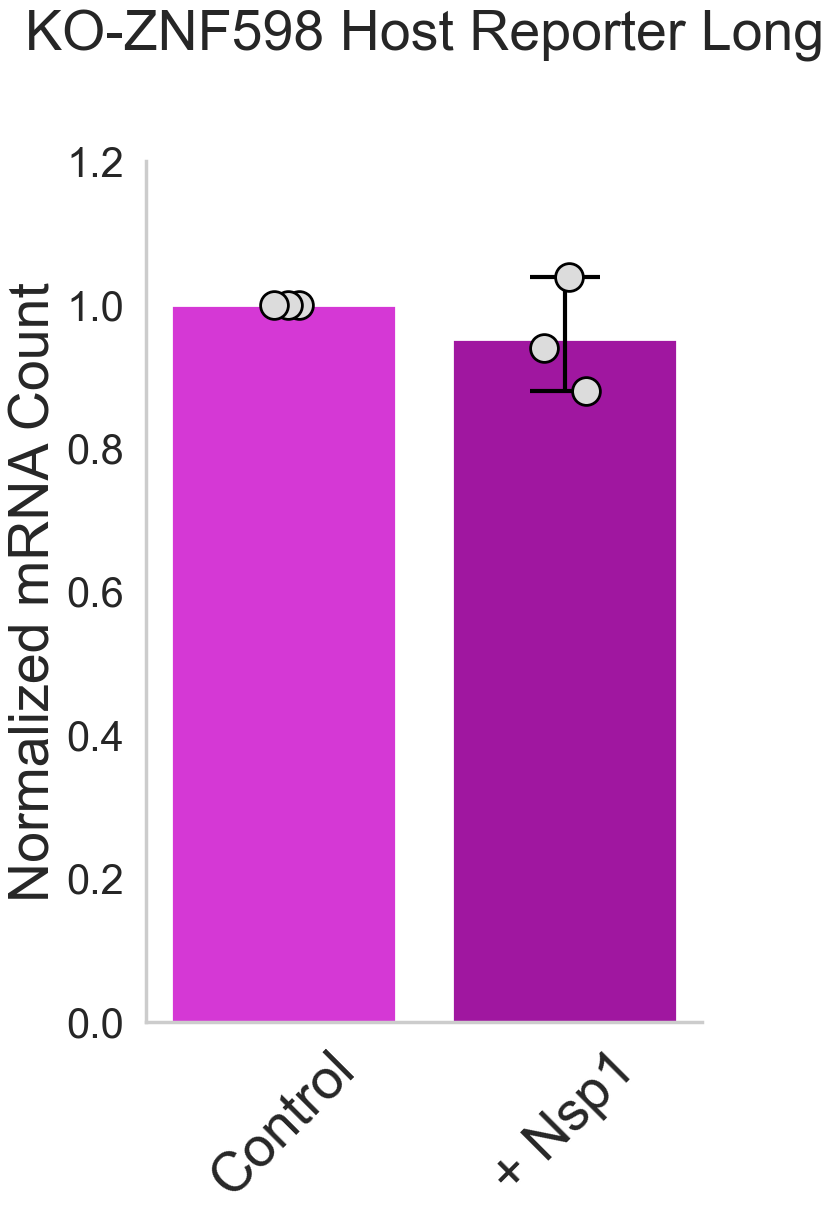

In [142]:
# Plot 15b: Scaled ZNF KDM5B Standard Reporter Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = data = scale_by_reference(
    df=average_spot_count[average_spot_count["Experimental Group"] == "ZNF_KDM5B"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="ZNF_KDM5B",
    ref_type="No Nsp1",
)
# Generate Per-Replicate dataframe for superplots
superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])

col = "Super Average Total Translation Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=superplot_translation,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)




# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)", 
            data=superplot_translation, order=order, ax=ax1, palette= blue_palette, errorbar=None)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI
xpos = np.arange(len(cats))

for i in range(len(cats)):
    if i == 0:
        continue  # skip the first category

    ax1.errorbar(
        xpos[i],
        means[i],
        yerr=[[yerr[0, i]], [yerr[1, i]]],  # asymmetric error for one bar
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )
    
ax1.set_ylabel('Normalized Translation Count', fontsize=40)
ax1.set_title('KO-ZNF598 Host Reporter Long', fontsize=40, pad=80)
ax1.set_ylim(0, 1.2)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res_scaled1 = print_scaled_one_sample_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Total Translation Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots ZNF KDM5B.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots ZNF KDM5B.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()

col = "Super Average Total RNA Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=superplot_rna,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)

# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)", 
            data=superplot_rna, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI
xpos = np.arange(len(cats))

for i in range(len(cats)):
    if i == 0:
        continue  # skip the first category

    ax2.errorbar(
        xpos[i],
        means[i],
        yerr=[[yerr[0, i]], [yerr[1, i]]],  # asymmetric error for one bar
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )


ax2.set_ylabel('Normalized mRNA Count', fontsize=40)
ax2.set_ylim(0, 1.2)
ax2.set_title('KO-ZNF598 Host Reporter Long', fontsize=40, pad=80)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res_scaled2 = print_scaled_one_sample_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots ZNF KDM5B.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots ZNF KDM5B.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4275363282.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4275363282.py:27: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", lin

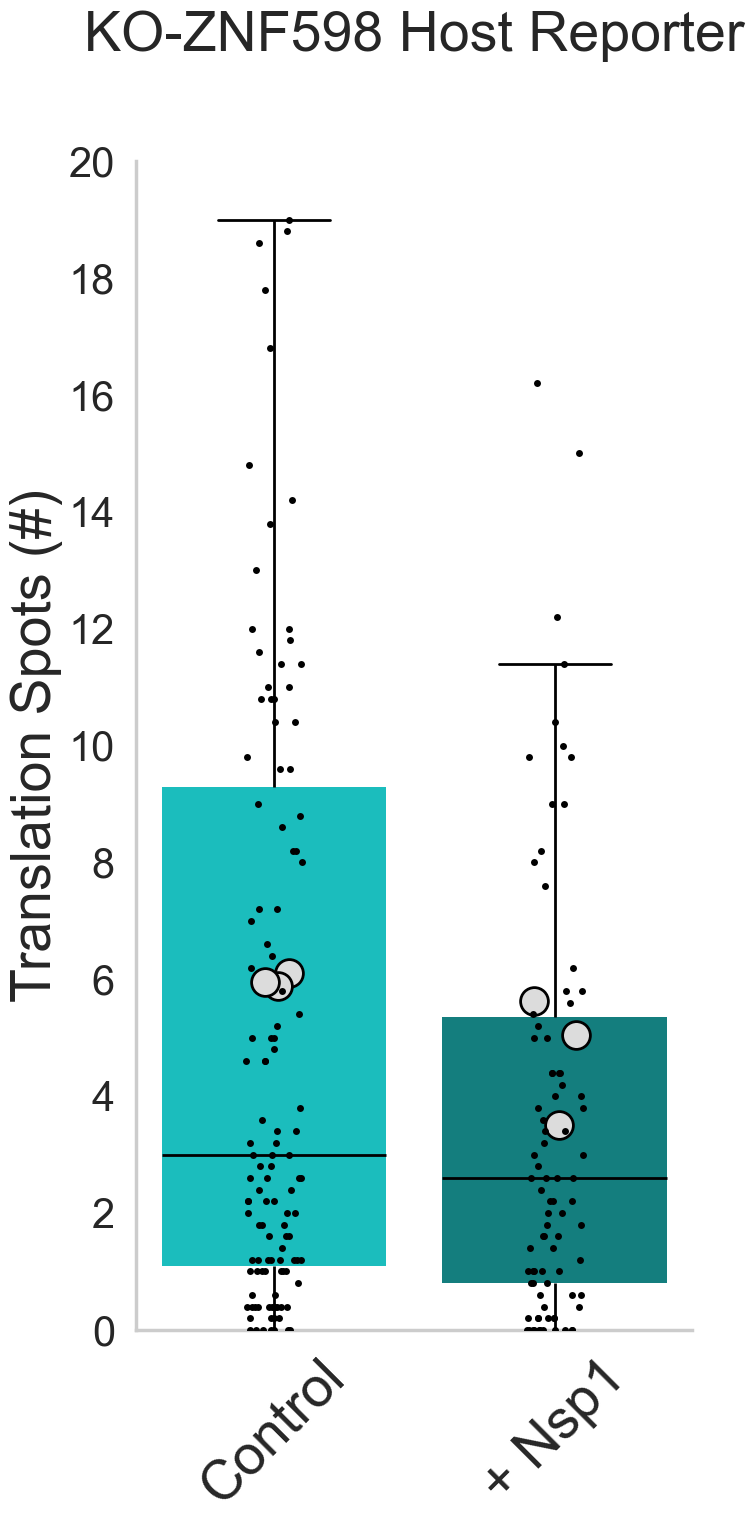

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4275363282.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4275363282.py:68: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),

Across x within hue, paired by replicate:
[hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=54.8/39.4, mean_diff=-15.4, p=0.299, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_SARS_CTRL]
No Nsp1: 54.8 ± 12.1 SEM (n=3)
Nsp1: 39.4 ± 3.12 SEM (n=3)

                     test_group                             contrast       x0  \
0  x|within_hue|paired_baseline  [hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1  No Nsp1   

     x1           hue0           hue1  n_pairs      mean0      mean1  \
0  Nsp1  ZNF_SARS_CTRL  ZNF_SARS_CTRL        3  54.756667  39.403704   

     pvalue stars         paired_by  mean_diff_x1_minus_x0  
0  0.298681    ns  Replicate_Number             -15.352963  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4275363282.py:109: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


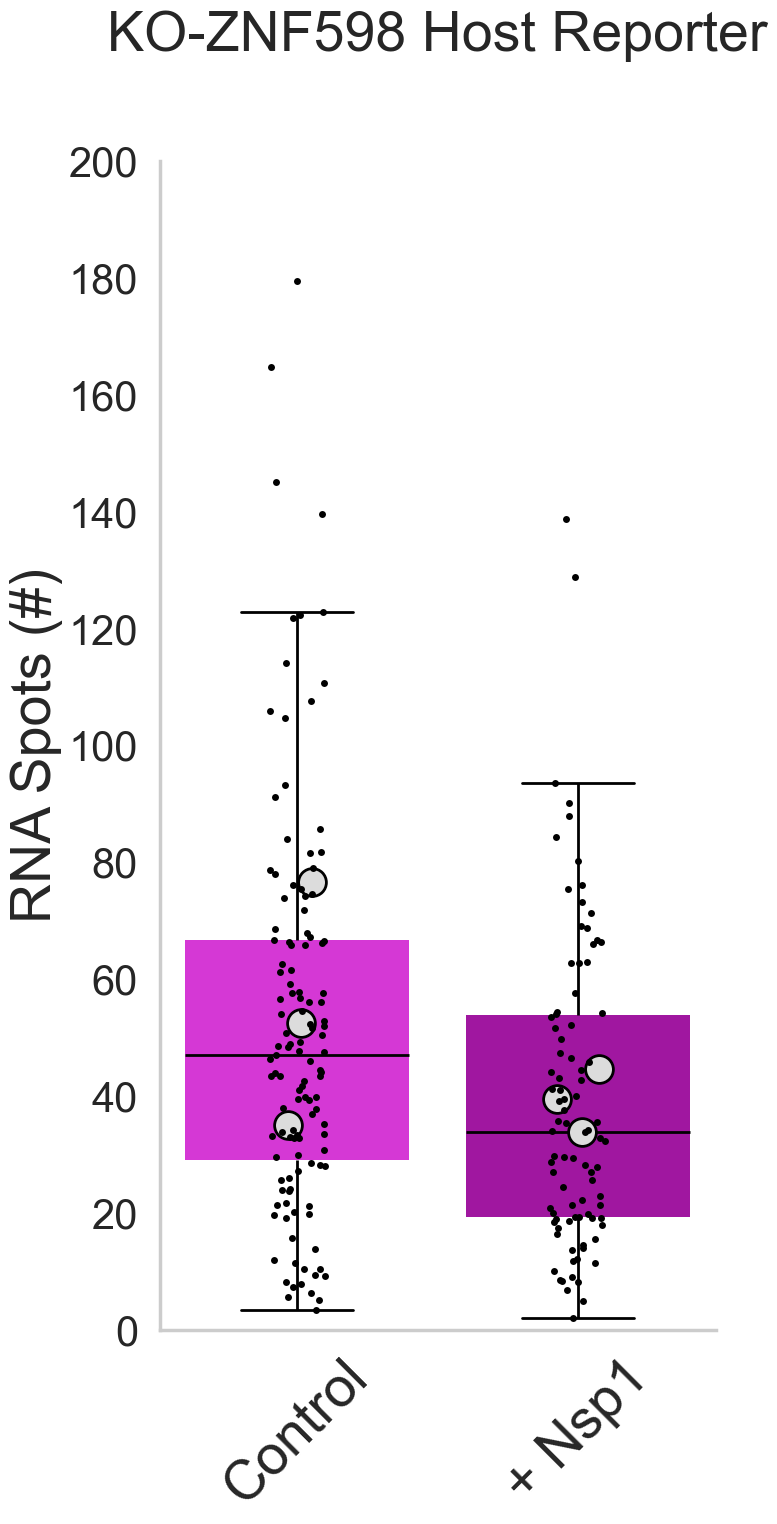

In [205]:
# Plot 16a: ZNF host reporter Total Translation Spots and Total RNA Spots
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = average_spot_count[average_spot_count["Experimental Group"] == "ZNF_SARS_CTRL"]

superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots", ["Experimental Group", "Experimental Type", "Replicate_Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total Translation Spots", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total Translation Spots", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_title('KO-ZNF598 Host Reporter', fontsize=40, pad=80)
ax1.set_ylim(0, 20)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()


# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots ZNF_SARS_CTRL.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Total Translation Spots ZNF_SARS_CTRL.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Total RNA Spots", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Average Total RNA Spots",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_title('KO-ZNF598 Host Reporter', fontsize=40, pad=80)
ax2.set_ylim(0, 200)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()
res = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots",
    hue="Experimental Group",
    pair_col="Replicate_Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots ZNF_SARS_CTRL.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Total RNA Spots ZNF_SARS_CTRL.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1205696039.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1205696039.py:48: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)",



[hue=ZNF_SARS_CTRL] Scaled conditions vs 1.0
[hue=ZNF_SARS_CTRL] Nsp1 vs 1.0: n=3, mean=0.79, p=0.176, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_SARS_CTRL]
No Nsp1: 1 ± 0 SEM (n=3)
Nsp1: 0.79 ± 0.102 SEM (n=3)

    test_group          test_type     contrast    x1 x2            hue  n  n1  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  ZNF_SARS_CTRL  3   3   

   n2     mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue  \
0 NaN  0.789966    1.0        -0.210034  0.176701  NaN  -2.058794  0.175732   

  stars  
0    ns  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1205696039.py:104: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


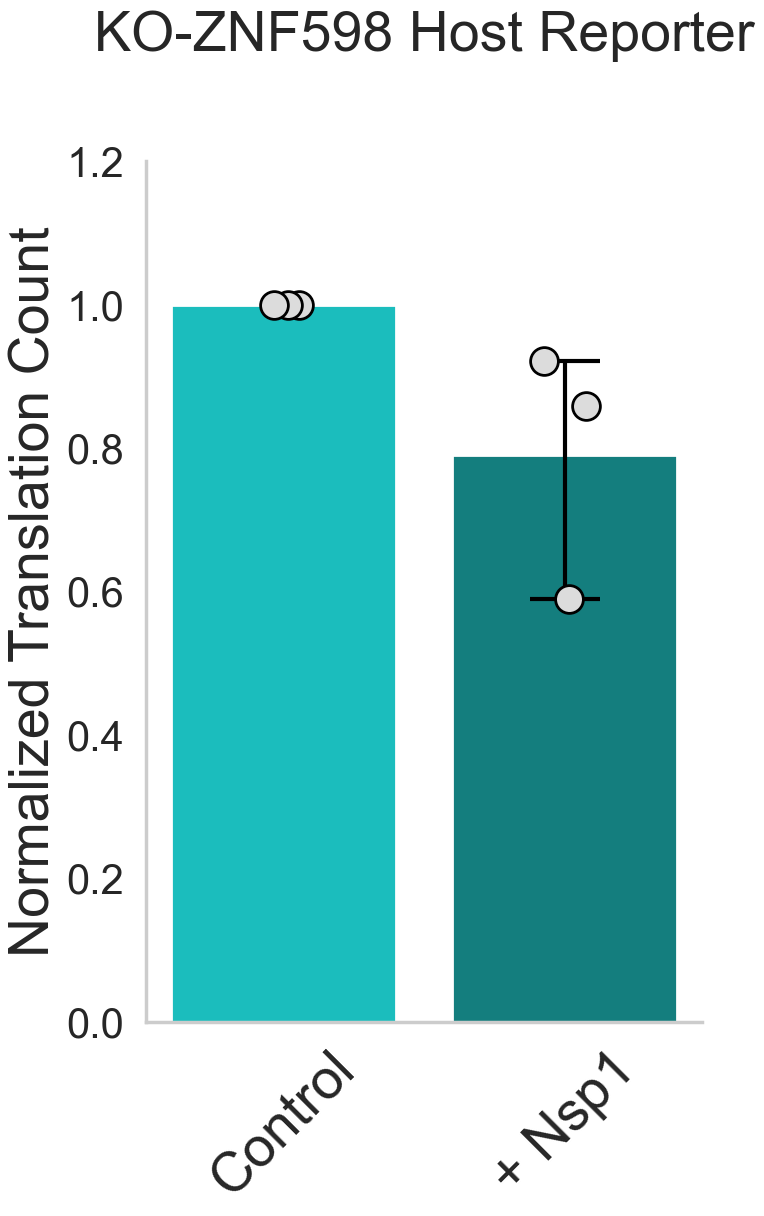

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1205696039.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1205696039.py:125: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)",



[hue=ZNF_SARS_CTRL] Scaled conditions vs 1.0
[hue=ZNF_SARS_CTRL] Nsp1 vs 1.0: n=3, mean=0.778, p=0.243, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_SARS_CTRL]
No Nsp1: 1 ± 9.06e-17 SEM (n=3)
Nsp1: 0.778 ± 0.135 SEM (n=3)

    test_group          test_type     contrast    x1 x2            hue  n  n1  \
0  scaled_vs_1  one-sample t-test  Nsp1 vs 1.0  Nsp1  1  ZNF_SARS_CTRL  3   3   

   n2     mean1  mean2  mean_difference       sd1  sd2  statistic    pvalue  \
0 NaN  0.778341    1.0        -0.221659  0.234352  NaN  -1.638237  0.243034   

  stars  
0    ns  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1205696039.py:182: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


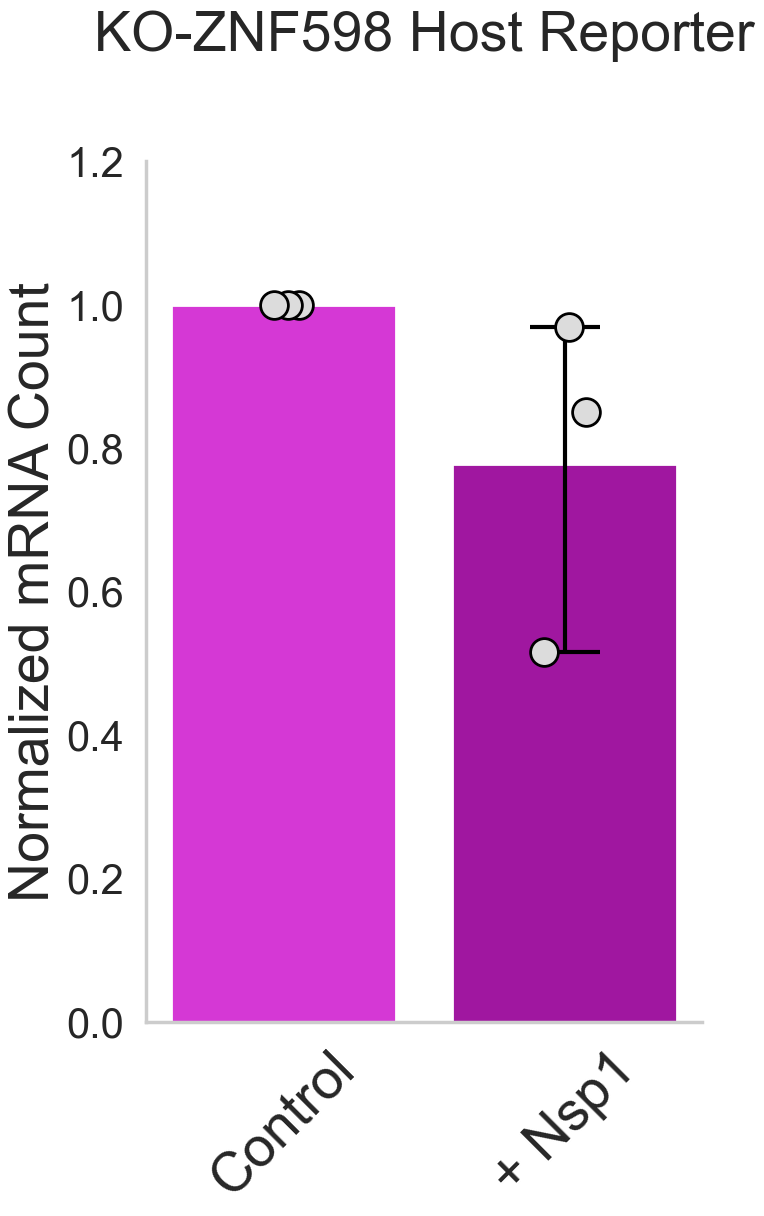

In [143]:
# Plot 16b: Scaled ZNF SARS CTRL Standard Reporter Total Translation Spots and Total RNA Spots
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["No Nsp1", "Nsp1"]

# Define the order for the x-axis categories
data = data = scale_by_reference(
    df=average_spot_count[average_spot_count["Experimental Group"] == "ZNF_SARS_CTRL"],
    value_cols=("Average Total Translation Spots", "Average Total RNA Spots"),
    ref_group="ZNF_SARS_CTRL",
    ref_type="No Nsp1",
)
# Generate Per-Replicate dataframe for superplots
superplot_translation = calculate_grouped_average(data, "Average Total Translation Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])
superplot_rna = calculate_grouped_average(data, "Average Total RNA Spots (scaled)", ["Experimental Group", "Experimental Type", "Replicate_Number"])

col = "Super Average Total Translation Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=superplot_translation,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)




# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total Translation Spots (scaled)", 
            data=superplot_translation, order=order, ax=ax1, palette= blue_palette, errorbar=None)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Total Translation Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI
xpos = np.arange(len(cats))

for i in range(len(cats)):
    if i == 0:
        continue  # skip the first category

    ax1.errorbar(
        xpos[i],
        means[i],
        yerr=[[yerr[0, i]], [yerr[1, i]]],  # asymmetric error for one bar
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )
    
ax1.set_ylabel('Normalized Translation Count', fontsize=40)
ax1.set_title('KO-ZNF598 Host Reporter', fontsize=40, pad=80)
ax1.set_ylim(0, 1.2)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res_scaled1 = print_scaled_one_sample_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Total Translation Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots ZNF SARS CTRL.svg")
filename_png_translation = os.path.join(save_directory + spot_count_folder, "Normalized Total Translation Spots ZNF SARS CTRL.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()

col = "Super Average Total RNA Spots (scaled)"
ref_type = "No Nsp1"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=superplot_rna,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)

# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Super Average Total RNA Spots (scaled)", 
            data=superplot_rna, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average Total RNA Spots (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI
xpos = np.arange(len(cats))

for i in range(len(cats)):
    if i == 0:
        continue  # skip the first category

    ax2.errorbar(
        xpos[i],
        means[i],
        yerr=[[yerr[0, i]], [yerr[1, i]]],  # asymmetric error for one bar
        fmt="none",
        elinewidth=3,
        capsize=25,
        capthick=3,
        color="black",
        alpha=1,
    )


ax2.set_ylabel('Normalized mRNA Count', fontsize=40)
ax2.set_ylim(0, 1.2)
ax2.set_title('KO-ZNF598 Host Reporter', fontsize=40, pad=80)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res_scaled2 = print_scaled_one_sample_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average Total RNA Spots (scaled)",
    hue="Experimental Group",
    baseline_x="No Nsp1",
    order=order,
    hue_order=None,
)

print(res_scaled2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots ZNF SARS CTRL.svg")
filename_png_rna = os.path.join(save_directory + spot_count_folder, "Normalized Total RNA Spots ZNF SARS CTRL.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

## Localization Plotting

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_5'UTR_3'UTR",
         "SARS_3'UTR" ,]
# Define the order for the hue levels
hue_order = ["No Nsp1", "Low Nsp1", "High Nsp1"]

# Create a FacetGrid
g = sns.FacetGrid(average_efficiency_df, row="Location", height=4, aspect=2)

# Plot the Translational Efficiency for each Experimental Group
g.map_dataframe(sns.barplot, x="Experimental Group", y="Translational Efficiency", hue="Experimental Condition", order=order, palette='Set1')

# Overlay a scatterplot to represent individual data points
g.map_dataframe(sns.stripplot, x="Experimental Group", y="Translational Efficiency", hue="Experimental Condition",  order=order, color="black", size=5, jitter=True, dodge=True)

# Set the titles for each subplot
g.set_titles('Translational Efficiency for each Experimental Group in {row_name}')

# Set the x-tick labels
new_labels = ["No SARS UTR Control", "SARS 5' UTR", "SARS 5' and 3' UTRs", "SARS 3' UTR"]
g.set_xticklabels(new_labels)
g.set_ylabels('Translational Efficiency (%)')

# Handle the legend
g.add_legend(bbox_to_anchor=(1, 1))

# Show the plot
plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.5)
sns.set_style("whitegrid")
# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_5'UTR_3'UTR",
         "SARS_3'UTR" ,]
# Define the order for the hue levels
hue_order = ["No Nsp1", "Low Nsp1", "High Nsp1"]

row_order = ["Nuclear Periphery", "Cytoplasm", "Cytoplasmic Periphery"]

# Create a FacetGrid
g = sns.FacetGrid(average_efficiency_df, row="Location", row_order=row_order, height=4, aspect=2)

# Plot the Translational Efficiency for each Experimental Group
g.map_dataframe(sns.barplot, x="Experimental Group", y="Translational Efficiency", hue="Experimental Type", order=order, palette='Set1')

# Overlay a scatterplot to represent individual data points
g.map_dataframe(sns.stripplot, x="Experimental Group", y="Translational Efficiency", hue="Experimental Type",  order=order, color="black", size=5, jitter=True, dodge=True)

# Set the titles for each subplot
g.set_titles('{row_name}', size=36)

# Set the x-tick labels
new_labels = ["No SARS UTR Control", "SARS 5' UTR", "SARS 5' and 3' UTRs", "SARS 3' UTR"]
g.set_xticklabels(new_labels)
g.set_ylabels('Translational Efficiency (%)')

# Handle the legend
g.add_legend(bbox_to_anchor=(1, 1))

# Show the plot
plt.tight_layout()
plt.show()

# Define the filenames
filename_svg = os.path.join(save_directory, "Translational Efficiency by Location.svg")
filename_png = os.path.join(save_directory, "Translational Efficiency by Location.png")

# Save the figure as SVG
g.savefig(filename_svg, format='svg',bbox_inches='tight')

# Save the figure as PNG
g.savefig(filename_png, format='png',bbox_inches='tight')

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_5'UTR_3'UTR",
         "SARS_3'UTR" ,]

# Define the order for the hue levels
hue_order = ["No Nsp1", "Low Nsp1", "High Nsp1"]

# Create a figure
fig, ax = plt.subplots(figsize=(12, 6))

# Plot the Translational Efficiency for each Experimental Group
sns.barplot(x="Experimental Group", y="Translational Efficiency",hue = "Experimental Condition", data=average_efficiency_df, order=order, ax=ax, palette='Set1')

# Overlay a scatterplot to represent individual data points
# Replace 'Individual Data' with the name of the column that represents the individual data points
sns.stripplot(x="Experimental Group", y="Translational Efficiency", hue="Experimental Condition", data=average_efficiency_df, order=order, color="black", size=5, jitter=True, dodge=True, ax=ax)

ax.set_title('Average Translational Efficiency for each Experimental Group')

# Set the x-tick labels
new_labels = ["No SARS UTR Control", "SARS 5' UTR", "SARS 5' and 3' UTRs", "SARS 3' UTR"]
# ax.set_xticks([.5, 2.5, 4.5, 6.5])  # Position the x-ticks in the middle of the groups of bars
ax.set_xticklabels(new_labels)
ax.set_ybound(0, 100)
ax.set_ylabel('Translational Efficiency (%)')

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[-3:], labels[-3:])  # Only keep the first two legend items

# Show the plot
plt.tight_layout()
plt.show()

## Translation Efficiency Plotting

In [51]:
per_cell_efficiency_df = (
    average_efficiency_df
    .groupby(
        [
            "Experimental Group",
            
            "Experimental Type",
            "Replicate_Number",
            "fov",
            "Experimental Condition"
        ],
        as_index=False
    )["Translational Efficiency"]
    .mean()
    .rename(columns={"Translational Efficiency": "Average Translational Efficiency"})
)

per_cell_efficiency_df


,Experimental Group,Experimental Type,Replicate_Number,fov,Experimental Condition,Average Translational Efficiency
0,BoxB_IRES,No Nsp1,1.0,0,No Nsp1,66.774897
1,BoxB_IRES,No Nsp1,1.0,1,No Nsp1,85.820297
2,BoxB_IRES,No Nsp1,1.0,2,No Nsp1,68.910679
3,BoxB_IRES,No Nsp1,1.0,3,No Nsp1,79.634960
4,BoxB_IRES,No Nsp1,1.0,4,No Nsp1,89.148148
...,...,...,...,...,...,...
1065,ZNF_SARS_CTRL,Nsp1,3.0,25,No Nsp1,13.785469
1066,ZNF_SARS_CTRL,Nsp1,3.0,26,No Nsp1,17.189673
1067,ZNF_SARS_CTRL,Nsp1,3.0,27,No Nsp1,17.145331
1068,ZNF_SARS_CTRL,Nsp1,3.0,28,No Nsp1,1.098352


In [52]:
outlier_cells_ht, per_cell_efficiency_df_no_outlier = detect_and_drop_cell_outliers_by_fov_single_metric(
    per_cell_efficiency_df,
    col_group="Experimental Group",
    col_type="Experimental Type",
    col_rep="Replicate_Number",
    col_fov="fov",
    col_value="Average Translational Efficiency",
    iqr_k=1.5,
    print_summary=True,
)

BoxB_IRES | No Nsp1 | fov 29 | rep 3 is outlier (Average Translational Efficiency)
BoxB_IRES | Nsp1 | fov 11 | rep 2 is outlier (Average Translational Efficiency)
Emi_KDM5B | No Nsp1 | fov 22 | rep 3 is outlier (Average Translational Efficiency)
Emi_KDM5B | No Nsp1 | fov 32 | rep 4 is outlier (Average Translational Efficiency)
Emi_KDM5B | No Nsp1 | fov 34 | rep 4 is outlier (Average Translational Efficiency)
Emi_KDM5B | No Nsp1 | fov 37 | rep 4 is outlier (Average Translational Efficiency)
Emi_KDM5B | NoCTD Nsp1 | fov 3 | rep 1 is outlier (Average Translational Efficiency)
Emi_KDM5B | NoCTD Nsp1 | fov 4 | rep 1 is outlier (Average Translational Efficiency)
Emi_KDM5B | NoCTD Nsp1 | fov 8 | rep 1 is outlier (Average Translational Efficiency)
Emi_KDM5B | NoCTD Nsp1 | fov 14 | rep 1 is outlier (Average Translational Efficiency)
Emi_KDM5B | NoCTD Nsp1 | fov 29 | rep 3 is outlier (Average Translational Efficiency)
Emi_KDM5B | NoCTD Nsp1 | fov 36 | rep 4 is outlier (Average Translational Effi

In [ ]:
# Plot 1: Translational Efficiency All Groups
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")

# Define the order for the x-axis categories
data = average_efficiency_df[average_efficiency_df['Experimental Type'] == "No Nsp1"]
superplot = calculate_grouped_average(data, "Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate_Number"])
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]
# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]

# Define the order for the hue levels
hue_order = ["No Nsp1", "Low Nsp1", "High Nsp1"]

# Create a figure
fig, ax = plt.subplots(figsize=(14, 14), constrained_layout=True)

# Plot the Translational Efficiency for each Experimental Group
sns.barplot(x="Experimental Group", y="Translational Efficiency",hue = "Experimental Type", data=data, order=order, ax=ax, palette= green_palette)

sns.stripplot(x="Experimental Group", y="Translational Efficiency", hue="Experimental Type", data=data, order=order, color="black", alpha = 0.6, size=7, jitter=True, dodge=True, ax=ax)

sns.stripplot(x="Experimental Group", y="Super Translational Efficiency", hue="Experimental Type", data=superplot, order=order, color="black", alpha = 1, size=14, jitter=True, dodge=True, ax=ax, marker = "8")

ax.set_title('Fraction of mRNA with Nascent Signal', fontsize=50)
ax.tick_params(axis='both', which='major', labelsize=30)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ylim(0, 100)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
# Set exactly 10 y-ticks
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

res1 = print_ttest_summary( x="Experimental Group", y="Translational Efficiency", hue="Experimental Type",
            data=data, order=order)
print(res1)

# Show the plot
plt.tight_layout()
plt.show()

# Define the filenames
filename_svg = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency Viral UTR.svg")
filename_png = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency Viral UTR.png")

# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)

# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)

In [ ]:
# Plot 2: Translational Efficiency All Groups Nsp1
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = average_efficiency_df[average_efficiency_df["Experimental Type"].isin(["Nsp1", "No Nsp1"])]
superplot = calculate_grouped_average(data, "Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate_Number"])
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]


# Create a figure
fig, ax = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(x="Experimental Group", y="Translational Efficiency",hue = "Experimental Type", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),)


sns.stripplot(x="Experimental Group", y="Translational Efficiency", hue="Experimental Type", data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax, zorder=9)

plot_open_circles_with_hue(ax, superplot, order=order, x="Experimental Group", y="Super Translational Efficiency", hue="Experimental Type")

ax.tick_params(axis='both', which='major', labelsize=30)

ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ybound(0, 100)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right", bbox_to_anchor=(1.05, 1.02))

res1 = print_ttest_summary( x="Experimental Group", y="Translational Efficiency", hue="Experimental Type",
            data=data, order=order)
print(res1)

# Show the plot
plt.tight_layout()
plt.show()

# Define the filenames
filename_svg = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency Viral UTR (Nsp1).svg")
filename_png = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency Viral UTR (Nsp1).png")

# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)

# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)

In [ ]:
# Plot 3: Translational Efficiency All Groups Black Background
import seaborn as sns
import matplotlib.pyplot as plt
import os
data = average_efficiency_df[average_efficiency_df['Experimental Type'] == "No Nsp1"]
# Set the font and style for a black background with white text
sns.set(font_scale=1.9)
sns.set_style("darkgrid", {'axes.facecolor': 'black', 'grid.color': 'gray', 'axes.edgecolor': 'white'})

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_5'UTR_3'UTR", "SARS_3'UTR"]

# Define the order for the hue levels
hue_order = ["No Nsp1", "Low Nsp1", "High Nsp1"]

# Create a figure
fig, ax = plt.subplots(figsize=(12, 6), facecolor='black')  # Set facecolor to black

# Plot the Translational Efficiency for each Experimental Group (Barplot)
sns.barplot(x="Experimental Group", y="Translational Efficiency", hue="Experimental Type", data=data, order=order, ax=ax, palette='Set1', errcolor='white')

# Overlay a scatterplot to represent individual data points (with white dots)
sns.stripplot(x="Experimental Group", y="Translational Efficiency", hue="Experimental Type", data=data, order=order, palette=["white", "white", "white"], size=5, jitter=True, dodge=True, ax=ax)

# Set the title and labels with white text
ax.set_title('Translational Efficiency', fontsize=36, color='white')
ax.set_ylabel('Translational Efficiency (%)', color='white')
ax.set_xlabel('')

# Set the x-tick labels with white text
new_labels = ["Host UTR Control", "SARS 5' UTR", "SARS 5' and 3' UTRs", "SARS 3' UTR"]
ax.set_xticklabels(new_labels, color='white')

# Set y-tick label colors
ax.tick_params(axis='y', colors='white')

# Set limits and styles for axes
ax.set_ybound(0, 100)
ax.spines['bottom'].set_color('white')
ax.spines['left'].set_color('white')

# Handle the legend: Only keep the barplot's legend
handles, labels = ax.get_legend_handles_labels()
legend = ax.legend().remove()


# Tight layout
plt.tight_layout()

# Define the filenames for saving with '(k)' for the black version
filename_svg = os.path.join(save_directory, "Translation Efficiency (k).svg")
filename_png = os.path.join(save_directory, "Translation Efficiency (k).png")

# Save the figure as SVG with black background
fig.savefig(filename_svg, format='svg', bbox_inches='tight', facecolor='black')

# Save the figure as PNG with black background
fig.savefig(filename_png, format='png', bbox_inches='tight', facecolor='black')

# Show the plot
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2245242046.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


Across x within hue, paired by replicate:
[hue=SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=27.7/39.9, mean_diff=12.2, p=0.0623, ns
[hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=27.7/39.3, mean_diff=11.6, p=0.00216, **
[hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=39.9/39.3, mean_diff=-0.641, p=0.875, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=SARS_CTRL]
No Nsp1: 27.7 ± 1.85 SEM (n=3)
Nsp1: 39.9 ± 1.8 SEM (n=3)
NoCTD Nsp1: 39.3 ± 2.06 SEM (n=3)

                     test_group                               contrast  \
0  x|within_hue|paired_baseline        [hue=SARS_CTRL] No Nsp1 vs Nsp1   
1  x|within_hue|paired_baseline  [hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1   
2     x|within_hue|paired_cross     [hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1   

        x0          x1       hue0       hue1  n_pairs      mean0      mean1  \
0  No Nsp1        Nsp1  SARS_CTRL  SARS_CTRL        3  27.737883  39.943717   
1  No Nsp1  NoCTD Nsp1  SARS_CTRL  SARS_CTRL        3  27.737883  39.30235

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2245242046.py:67: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


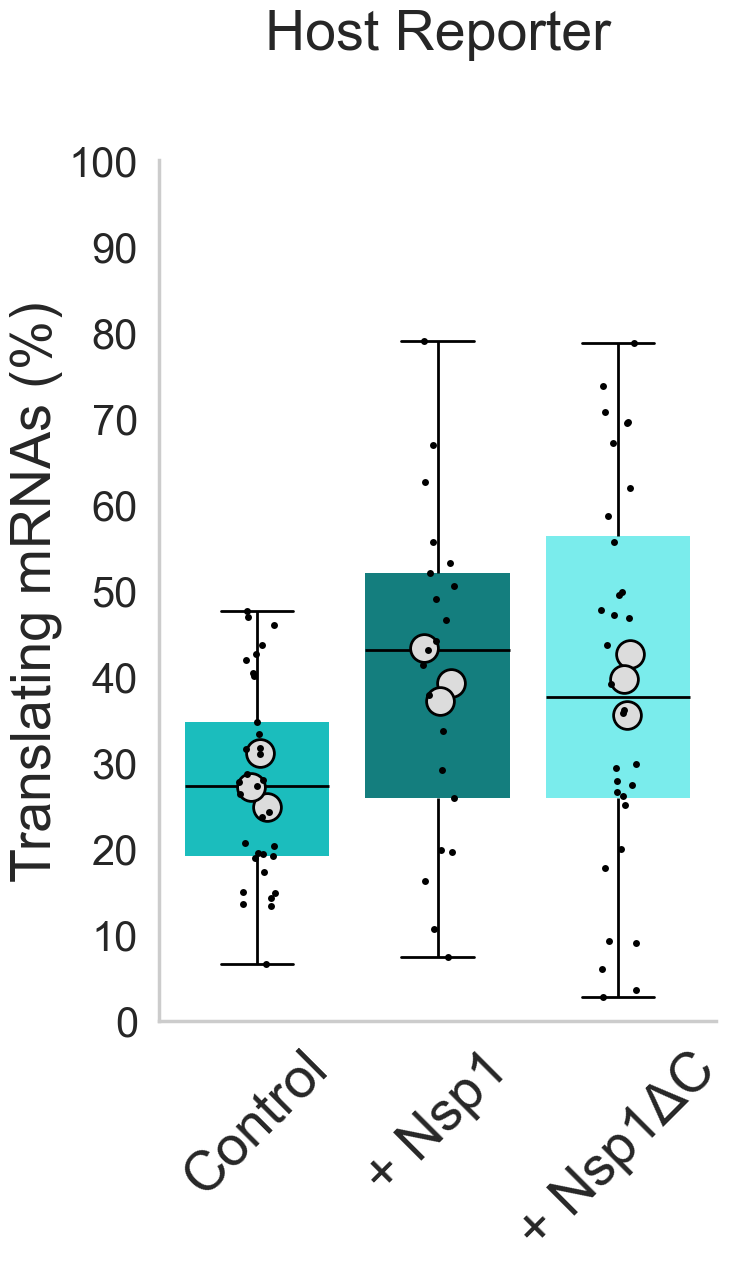

In [144]:
# Plot 4: Translational Efficiency Host UTR
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = per_cell_efficiency_df_no_outlier[per_cell_efficiency_df_no_outlier["Experimental Group"] == "SARS_CTRL"]
superplot = calculate_grouped_average(data, "Average Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate_Number"])
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1", "+ Nsp1\u0394C"]


# Create a figure
fig, ax = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


sns.stripplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax, zorder=9)

plot_open_circles_with_hue(ax, superplot, order=order, x="Experimental Type", y="Super Average Translational Efficiency", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax.tick_params(axis='both', which='major', labelsize=30)
ax.set_title('Host Reporter', fontsize=40, pad=80)

ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ybound(0, 100)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

res = print_paired_ttest_summary(
    data=superplot,
    x="Experimental Type",
    y="Super Average Translational Efficiency",
    hue="Experimental Group",
    pair_col="Replicate_Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res)

# Define the filenames
filename_svg = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency Host UTR.svg")
filename_png = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency Host UTR.png")
# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)
# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)
# Show the plot
plt.tight_layout()
plt.show()

Across x within hue, paired by replicate:
[hue=Emi_KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=3.93/3.78, mean_diff=-0.145, p=0.762, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=Emi_KDM5B]
No Nsp1: 3.93 ± 1.54 SEM (n=3)
Nsp1: 3.78 ± 1.54 SEM (n=3)

                     test_group                         contrast       x0  \
0  x|within_hue|paired_baseline  [hue=Emi_KDM5B] No Nsp1 vs Nsp1  No Nsp1   

     x1       hue0       hue1  n_pairs   mean0     mean1    pvalue stars  \
0  Nsp1  Emi_KDM5B  Emi_KDM5B        3  3.9254  3.780171  0.762328    ns   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate_Number              -0.145229  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4136920364.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2), fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4136920364.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", li

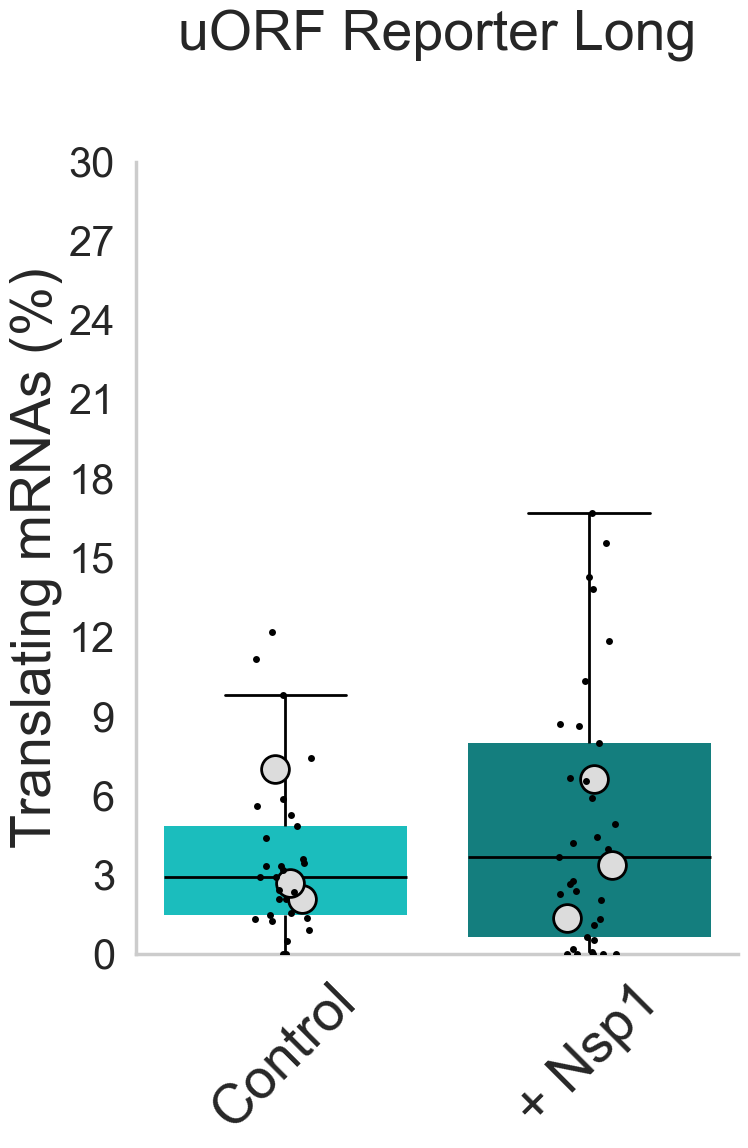

In [145]:
# Plot 4: Translational Efficiency Emi KDM5B
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = per_cell_efficiency_df_no_outlier[per_cell_efficiency_df_no_outlier["Experimental Group"] == "Emi_KDM5B"].copy()
data = data.query("Replicate_Number != 3").reset_index(drop=True)
superplot = calculate_grouped_average(data, "Average Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate_Number"])

order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Create a figure
fig, ax = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2), fliersize=0)


sns.stripplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax, zorder=9)

plot_open_circles_with_hue(ax, superplot, order=order, x="Experimental Type", y="Super Average Translational Efficiency", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax.tick_params(axis='both', which='major', labelsize=30)
ax.set_title("uORF Reporter Long", fontsize=40, pad=80)

ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ybound(0, 30)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

res = print_paired_ttest_summary(
    data=superplot,
    x="Experimental Type",
    y="Super Average Translational Efficiency",
    hue="Experimental Group",
    pair_col="Replicate_Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res)

# Show the plot
plt.tight_layout()
plt.show()

# Define the filenames
filename_svg = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency Emi KDM5B.svg")
filename_png = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency Emi KDM5B.png")
fig.savefig(filename_svg, format='svg', dpi=300, bbox_inches='tight')
fig.savefig(filename_png, format='png', dpi=300, bbox_inches='tight')

# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)

# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3397233403.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2), fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3397233403.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", li

Across x within hue, paired by replicate:
[hue=BoxB_IRES] No Nsp1 vs Nsp1: n_pairs=3, mean=71/62.8, mean_diff=-8.21, p=0.173, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=BoxB_IRES]
No Nsp1: 71 ± 1.82 SEM (n=3)
Nsp1: 62.8 ± 2.54 SEM (n=3)

                     test_group                         contrast       x0  \
0  x|within_hue|paired_baseline  [hue=BoxB_IRES] No Nsp1 vs Nsp1  No Nsp1   

     x1       hue0       hue1  n_pairs      mean0      mean1    pvalue stars  \
0  Nsp1  BoxB_IRES  BoxB_IRES        3  71.043528  62.836034  0.172632    ns   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate_Number              -8.207495  


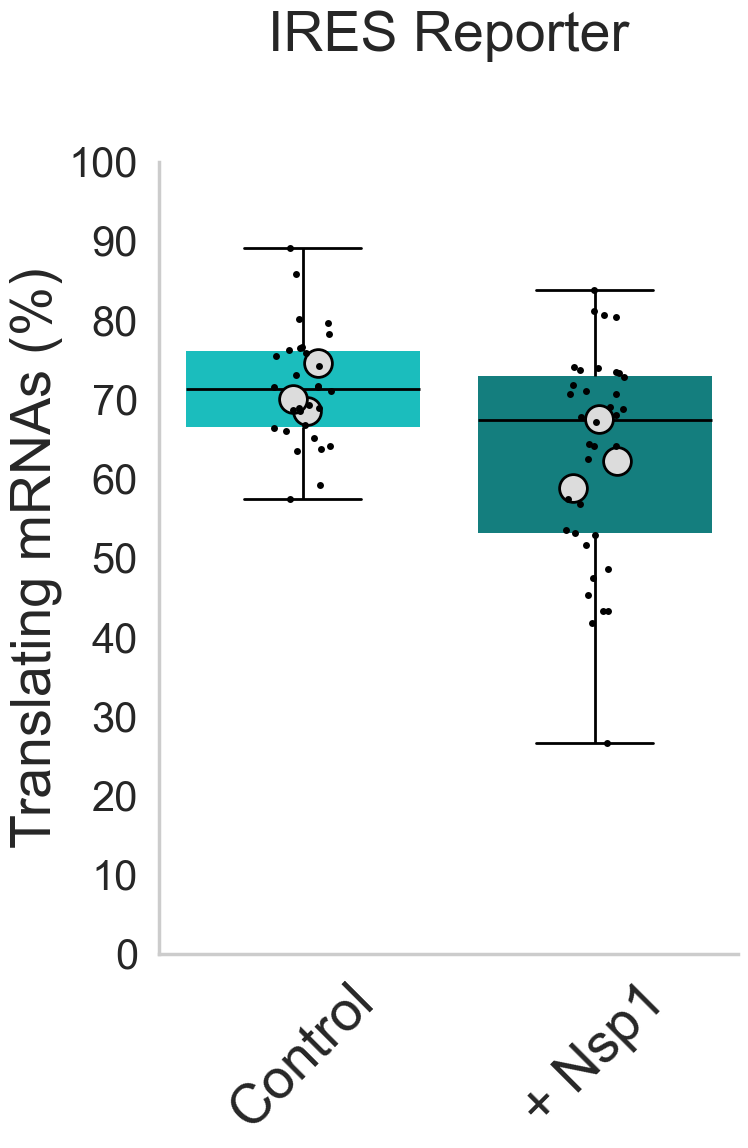

In [146]:
# Plot 4: Translational Efficiency IRES
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = per_cell_efficiency_df_no_outlier[per_cell_efficiency_df_no_outlier["Experimental Group"] == "BoxB_IRES"].copy()
# data = data.query("Replicate_Number != 3").reset_index(drop=True)
superplot = calculate_grouped_average(data, "Average Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate_Number"])

order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Create a figure
fig, ax = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2), fliersize=0)


sns.stripplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax, zorder=9)

plot_open_circles_with_hue(ax, superplot, order=order, x="Experimental Type", y="Super Average Translational Efficiency", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax.tick_params(axis='both', which='major', labelsize=30)
ax.set_title('IRES Reporter', fontsize=40, pad=80)

ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ybound(0, 100)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

res = print_paired_ttest_summary(
    data=superplot,
    x="Experimental Type",
    y="Super Average Translational Efficiency",
    hue="Experimental Group",
    pair_col="Replicate_Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res)

# Show the plot
plt.tight_layout()
plt.show()

# Define the filenames
filename_svg = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency BoxB IRES.svg")
filename_png = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency BoxB IRES.png")
fig.savefig(filename_svg, format='svg', dpi=300, bbox_inches='tight')
fig.savefig(filename_png, format='png', dpi=300, bbox_inches='tight')

# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)

# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3198597373.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3198597373.py:23: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


Across x within hue, paired by replicate:
[hue=KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=46.5/26.8, mean_diff=-19.7, p=0.0862, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=KDM5B]
No Nsp1: 46.5 ± 3.09 SEM (n=3)
Nsp1: 26.8 ± 5.29 SEM (n=3)

                     test_group                     contrast       x0    x1  \
0  x|within_hue|paired_baseline  [hue=KDM5B] No Nsp1 vs Nsp1  No Nsp1  Nsp1   

    hue0   hue1  n_pairs      mean0      mean1    pvalue stars  \
0  KDM5B  KDM5B        3  46.527841  26.843215  0.086168    ns   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate_Number             -19.684626  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3198597373.py:67: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


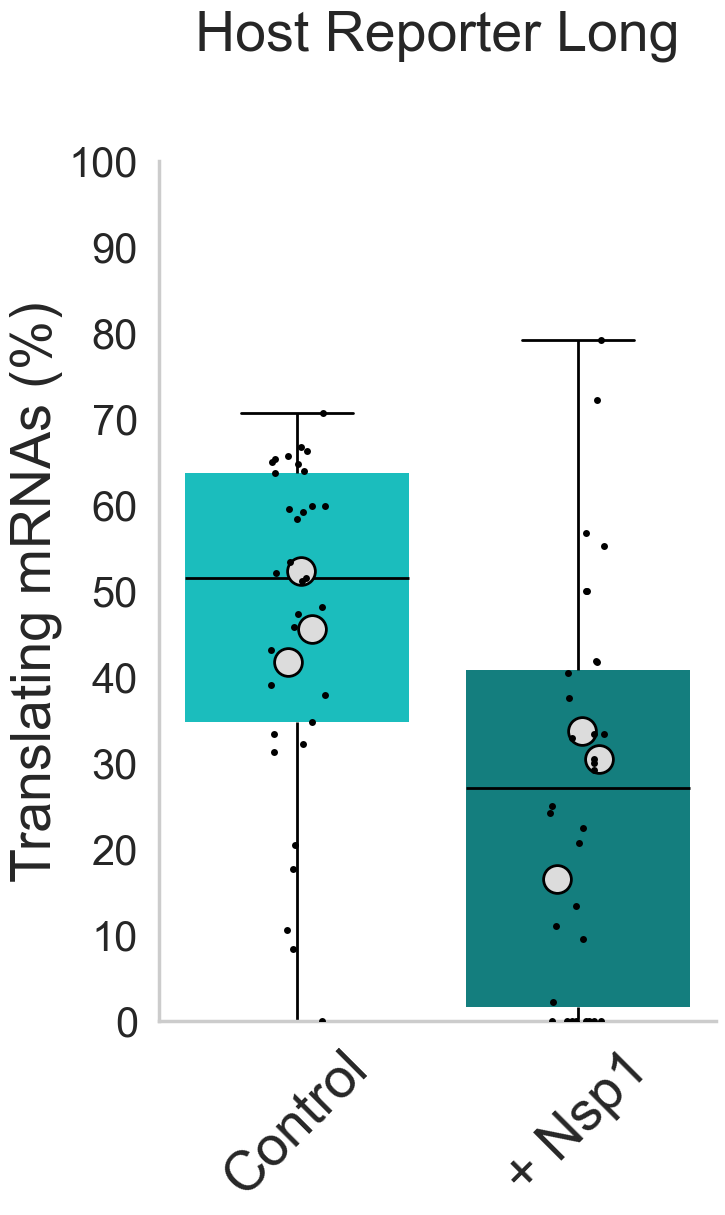

In [147]:
# Plot 7: Translational Efficiency KDM5B
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = per_cell_efficiency_df_no_outlier[per_cell_efficiency_df_no_outlier["Experimental Group"] == "KDM5B"]
superplot = calculate_grouped_average(data, "Average Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate_Number"])
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Create a figure
fig, ax = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


sns.stripplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax, zorder=9)

plot_open_circles_with_hue(ax, superplot, order=order, x="Experimental Type", y="Super Average Translational Efficiency", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax.tick_params(axis='both', which='major', labelsize=30)
ax.set_title('Host Reporter Long', fontsize=40, pad=80)

ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ybound(0, 100)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

res = print_paired_ttest_summary(
    data=superplot,
    x="Experimental Type",
    y="Super Average Translational Efficiency",
    hue="Experimental Group",
    pair_col="Replicate_Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res)

# Define the filenames
filename_svg = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency KDM5B.svg")
filename_png = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency KDM5B.png")
# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)
# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)
# Show the plot
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\88901639.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\88901639.py:23: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


Across x within hue, paired by replicate:
[hue=ZNF_KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=41.1/26.1, mean_diff=-14.9, p=0.077, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_KDM5B]
No Nsp1: 41.1 ± 3.49 SEM (n=3)
Nsp1: 26.1 ± 2.57 SEM (n=3)

                     test_group                         contrast       x0  \
0  x|within_hue|paired_baseline  [hue=ZNF_KDM5B] No Nsp1 vs Nsp1  No Nsp1   

     x1       hue0       hue1  n_pairs      mean0      mean1    pvalue stars  \
0  Nsp1  ZNF_KDM5B  ZNF_KDM5B        3  41.055419  26.108458  0.076991    ns   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate_Number             -14.946961  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\88901639.py:67: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


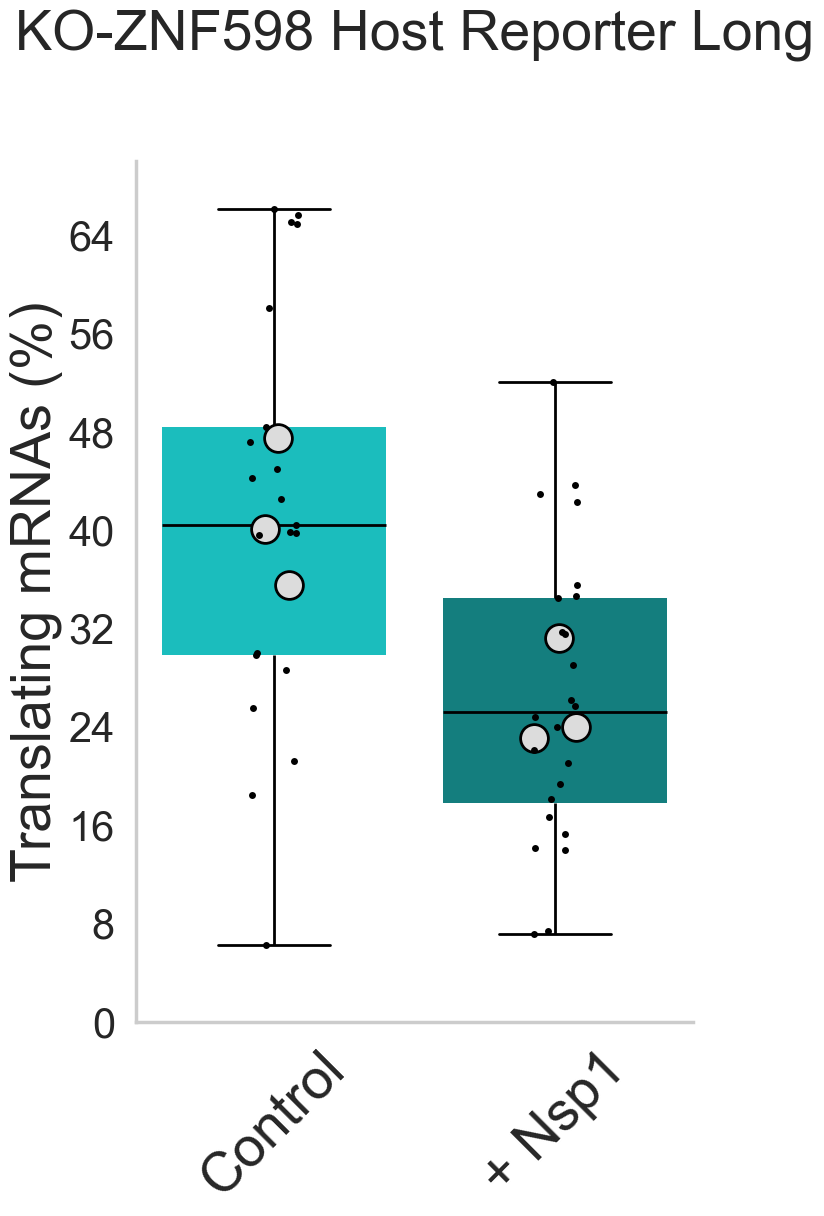

In [148]:
# Plot 8: Translational Efficiency ZNF_KDM5B
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = per_cell_efficiency_df_no_outlier[per_cell_efficiency_df_no_outlier["Experimental Group"] == "ZNF_KDM5B"]
superplot = calculate_grouped_average(data, "Average Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate_Number"])
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Create a figure
fig, ax = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


sns.stripplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax, zorder=9)

plot_open_circles_with_hue(ax, superplot, order=order, x="Experimental Type", y="Super Average Translational Efficiency", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax.tick_params(axis='both', which='major', labelsize=30)
ax.set_title('KO-ZNF598 Host Reporter Long', fontsize=40, pad=80)

ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ybound(0, 70)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

res = print_paired_ttest_summary(
    data=superplot,
    x="Experimental Type",
    y="Super Average Translational Efficiency",
    hue="Experimental Group",
    pair_col="Replicate_Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res)

# Define the filenames
filename_svg = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency ZNF_KDM5B.svg")
filename_png = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency ZNF_KDM5B.png")
# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)
# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)
# Show the plot
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\227019303.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\227019303.py:23: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


Across x within hue, paired by replicate:
[hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=10.1/10, mean_diff=-0.0565, p=0.98, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_SARS_CTRL]
No Nsp1: 10.1 ± 1.85 SEM (n=3)
Nsp1: 10 ± 1.95 SEM (n=3)

                     test_group                             contrast       x0  \
0  x|within_hue|paired_baseline  [hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1  No Nsp1   

     x1           hue0           hue1  n_pairs      mean0      mean1  \
0  Nsp1  ZNF_SARS_CTRL  ZNF_SARS_CTRL        3  10.075405  10.018867   

     pvalue stars         paired_by  mean_diff_x1_minus_x0  
0  0.979592    ns  Replicate_Number              -0.056537  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\227019303.py:67: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


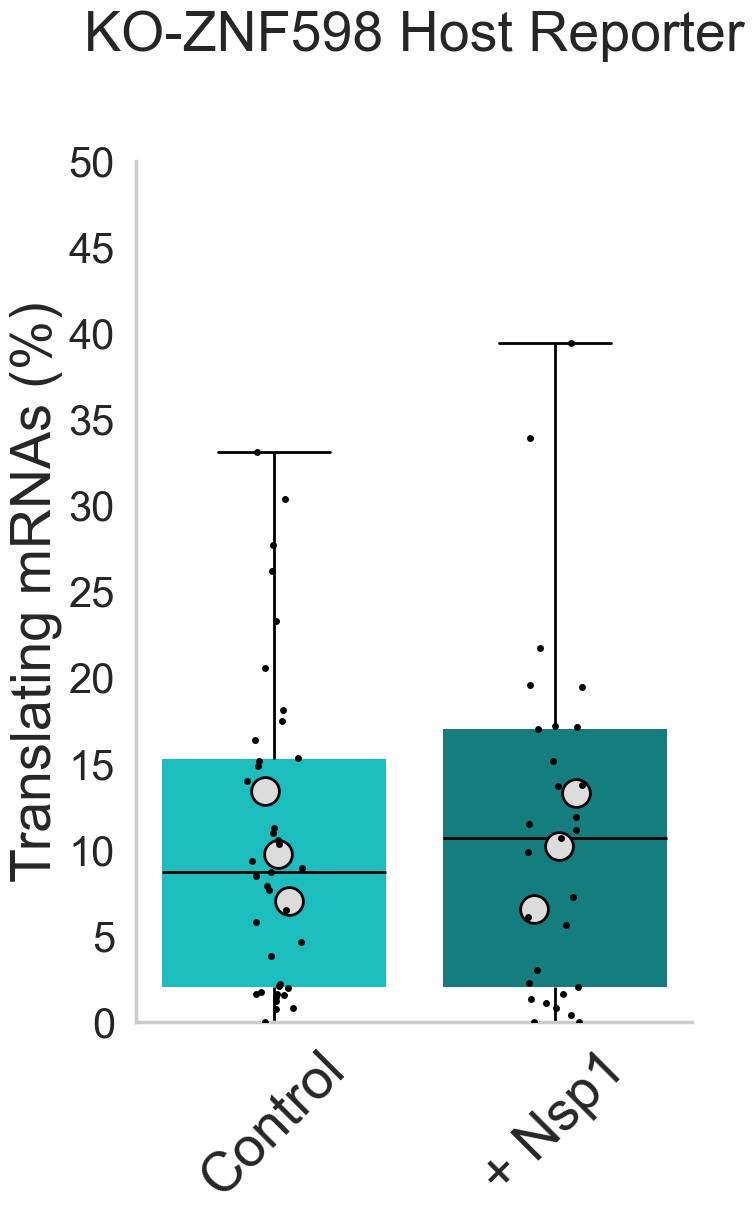

In [149]:
# Plot 8: Translational Efficiency ZNF_SARS_CTRL
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = per_cell_efficiency_df_no_outlier[per_cell_efficiency_df_no_outlier["Experimental Group"] == "ZNF_SARS_CTRL"]
superplot = calculate_grouped_average(data, "Average Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate_Number"])
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Create a figure
fig, ax = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


sns.stripplot(x="Experimental Type", y="Average Translational Efficiency", data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax, zorder=9)

plot_open_circles_with_hue(ax, superplot, order=order, x="Experimental Type", y="Super Average Translational Efficiency", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax.tick_params(axis='both', which='major', labelsize=30)
ax.set_title('KO-ZNF598 Host Reporter', fontsize=40, pad=80)

ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ybound(0, 50)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

res = print_paired_ttest_summary(
    data=superplot,
    x="Experimental Type",
    y="Super Average Translational Efficiency",
    hue="Experimental Group",
    pair_col="Replicate_Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res)

# Define the filenames
filename_svg = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency ZNF_SARS_CTRL.svg")
filename_png = os.path.join(save_directory + trnl_eff_folder, "Translation Efficiency ZNF_SARS_CTRL.png")
# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)
# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)
# Show the plot
plt.tight_layout()
plt.show()


Translational-efficiency cells:


,Experimental Group,Experimental Type,Replicate_Number,Cells
0,SARS_3'UTR,No Nsp1,1,5
1,SARS_3'UTR,No Nsp1,2,2
2,SARS_3'UTR,No Nsp1,3,10
3,SARS_3'UTR,Nsp1,1,4
4,SARS_3'UTR,Nsp1,2,5
5,SARS_3'UTR,Nsp1,3,5
6,SARS_5'UTR,No Nsp1,1,11
7,SARS_5'UTR,No Nsp1,2,4
8,SARS_5'UTR,No Nsp1,3,5
9,SARS_5'UTR,Nsp1,1,9



Across hue within x, paired by replicate:
[x=SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=27.7/39.9, mean_diff=12.2, p=0.0623, ns
[x=SARS_5'UTR] No Nsp1 vs Nsp1: n_pairs=3, mean=41.6/54.2, mean_diff=12.6, p=0.0727, ns
[x=SARS_3'UTR] No Nsp1 vs Nsp1: n_pairs=3, mean=48.9/40.4, mean_diff=-8.54, p=0.323, ns
[x=SARS_5'UTR_3'UTR] No Nsp1 vs Nsp1: n_pairs=3, mean=54.3/45, mean_diff=-9.27, p=0.302, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=No Nsp1]
SARS_CTRL: 27.7 ± 1.85 SEM (n=3)
SARS_5'UTR: 41.6 ± 5.4 SEM (n=3)
SARS_3'UTR: 48.9 ± 7.04 SEM (n=3)
SARS_5'UTR_3'UTR: 54.3 ± 2.27 SEM (n=3)

[hue=Nsp1]
SARS_CTRL: 39.9 ± 1.8 SEM (n=3)
SARS_5'UTR: 54.2 ± 4.12 SEM (n=3)
SARS_3'UTR: 40.4 ± 3.36 SEM (n=3)
SARS_5'UTR_3'UTR: 45 ± 7.61 SEM (n=3)

                     test_group                              contrast  \
0  hue|within_x|paired_baseline         [x=SARS_CTRL] No Nsp1 vs Nsp1   
1  hue|within_x|paired_baseline        [x=SARS_5'UTR] No Nsp1 vs Nsp1   
2  hue|within_x|paired_baseline     

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3788276513.py:202: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3788276513.py:427: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


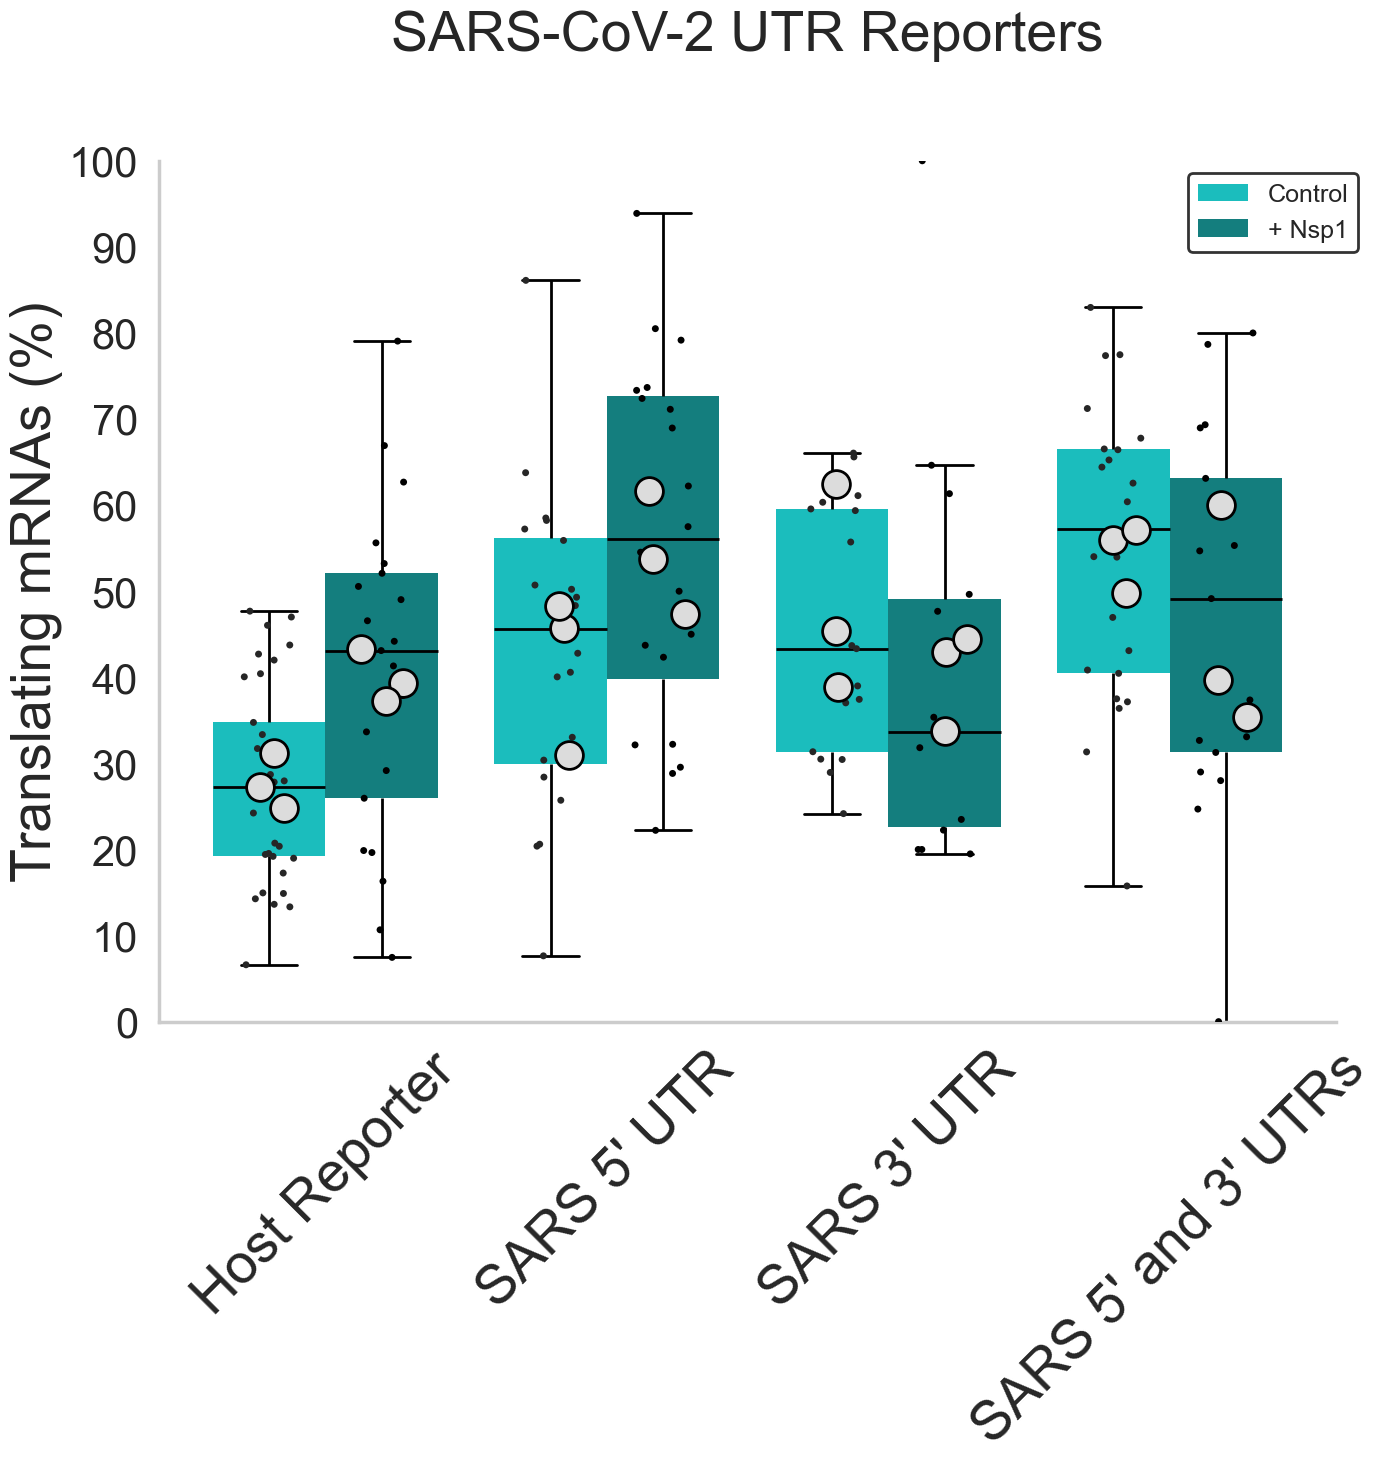

In [150]:
# Plot 9: ALL SARS-CoV-2 UTR REPORTERS

import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator

sns.set(
    font_scale=1.9
)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)

group_order = [
    "SARS_CTRL",
    "SARS_5'UTR",
    "SARS_3'UTR",
    "SARS_5'UTR_3'UTR",
]


type_order = [
    "No Nsp1",
    "Nsp1",
]


new_labels = [
    "Host Reporter",
    "SARS 5' UTR",
    "SARS 3' UTR",
    "SARS 5' and 3' UTRs",
]


legend_labels = [
    "Control",
    "+ Nsp1",
]

data = (

    per_cell_efficiency_df_no_outlier.loc[

        per_cell_efficiency_df_no_outlier[
            "Experimental Group"
        ].isin(
            group_order
        )

        &

        per_cell_efficiency_df_no_outlier[
            "Experimental Type"
        ].isin(
            type_order
        )

    ]

    .copy()

    .reset_index(
        drop=True
    )
)

data[
    "Replicate_Number"
] = pd.to_numeric(

    data[
        "Replicate_Number"
    ],

    errors="coerce"
)


superplot = calculate_grouped_average(

    data,

    "Average Translational Efficiency",

    [
        "Experimental Group",
        "Experimental Type",
        "Replicate_Number",
    ]
)


print(
    "\nTranslational-efficiency cells:"
)


display(

    data

    .groupby(
        [
            "Experimental Group",
            "Experimental Type",
            "Replicate_Number",
        ]
    )

    .size()

    .rename(
        "Cells"
    )

    .reset_index()
)

fig, ax = plt.subplots(

    figsize=(16, 12),

    constrained_layout=True
)


sns.despine(

    fig=fig,

    top=True,

    right=True,

    left=False,

    bottom=False
)

sns.boxplot(

    x="Experimental Group",

    y="Average Translational Efficiency",

    hue="Experimental Type",

    data=data,

    order=
        group_order,

    hue_order=
        type_order,

    ax=ax,

    palette=
        blue_palette[:2],

    boxprops=dict(
        linewidth=0
    ),

    whiskerprops=dict(
        color="black",
        linewidth=2
    ),

    capprops=dict(
        color="black",
        linewidth=2
    ),

    medianprops=dict(
        color="black",
        linewidth=2
    ),

    showfliers=False,
)


# Save clean legend before overlays.
handles, labels = (
    ax.get_legend_handles_labels()
)

sns.stripplot(

    x="Experimental Group",

    y="Average Translational Efficiency",

    hue="Experimental Type",

    data=data,

    order=
        group_order,

    hue_order=
        type_order,

    dodge=True,

    jitter=0.20,

    color="black",

    alpha=1,

    size=5,

    ax=ax,

    zorder=9,
)

plot_open_circles_with_hue(

    ax,

    superplot,

    order=
        group_order,

    x=
        "Experimental Group",

    y=
        "Super Average Translational Efficiency",

    hue=
        "Experimental Type",

    hue_order=
        type_order,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,

    zorder=10,
)

ax.set_title(

    "SARS-CoV-2 UTR Reporters",

    fontsize=40,

    pad=80
)


ax.set_ylabel(

    "Translating mRNAs (%)",

    fontsize=40
)


ax.set_xlabel(
    ""
)


ax.tick_params(

    axis="both",

    which="major",

    labelsize=30
)


ax.set_xticklabels(

    new_labels,

    fontsize=40,

    rotation=45
)


ax.set_ylim(
    0,
    100
)


ax.yaxis.set_major_locator(

    MaxNLocator(
        nbins=10
    )
)


if ax.get_legend() is not None:

    ax.get_legend().remove()


ax.legend(

    handles[
        :len(
            type_order
        )
    ],

    legend_labels,

    title=None,

    facecolor="white",

    edgecolor="black",

    fontsize=18,

    loc="upper right",

    bbox_to_anchor=(
        1.03,
        1
    ),
)

res = print_paired_ttest_summary(

    data=
        superplot,

    x=
        "Experimental Group",

    y=
        "Super Average Translational Efficiency",

    hue=
        "Experimental Type",

    pair_col=
        "Replicate_Number",

    order=
        group_order,

    hue_order=
        type_order,

    compare_x=False,

    compare_hue=True,

    verbose=True,
)


print(
    res
)


filename_svg = os.path.join(

    save_directory
    +
    trnl_eff_folder,

    "Translation Efficiency SARS UTR Reporters.svg"
)


filename_png = os.path.join(

    save_directory
    +
    trnl_eff_folder,

    "Translation Efficiency SARS UTR Reporters.png"
)


fig.savefig(

    filename_svg,

    format="svg",

    dpi=300
)


fig.savefig(

    filename_png,

    format="png",

    dpi=300
)


plt.tight_layout()

plt.show()

## Total Brightness plotting

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_5'UTR_3'UTR",
         "SARS_3'UTR" ]

# Create a figure with 2 subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12))

# Plot the Average Total Translation Signal for each Experimental Group
sns.barplot(x="Experimental Group", y="Average Total Translation Signal", hue="Experimental Type", data=average_total_signals_df, order=order, ax=ax1, palette='Set1')
sns.stripplot(x="Experimental Group", y="Average Total Translation Signal",hue = "Experimental Type", data=average_total_signals_df, order=order, color="black", size=5, jitter=True, dodge=True, ax=ax1)
ax1.set_ybound(0, 70000)
ax1.set_ylabel('Total Translation Spot Signal (a.u.)')
ax1.set_title('Total Translation Signal for each Experimental Group')

# Plot the Average Total RNA Signal for each Experimental Group
sns.barplot(x="Experimental Group", y="Average Total RNA Signal", hue="Experimental Type", data=average_total_signals_df, order=order, ax=ax2, palette='Set1')
sns.stripplot(x="Experimental Group", y="Average Total RNA Signal",hue = "Experimental Type", data=average_total_signals_df, order=order, color="black", size=5, jitter=True, dodge=True, ax=ax2)
ax2.set_ylabel('Total RNA Spot Signal (a.u.)')
ax2.set_title('Total RNA Signal for each Experimental Group')

# Set the x-tick labels for both plots
new_labels = ["No SARS UTR Control", "SARS 5' UTR", "SARS 5' and 3' UTRs", "SARS 3' UTR"]
for ax in [ax1, ax2]:
    ax.set_xticklabels(new_labels)

    # Handle the legend
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[-2:], labels[-2:])  # Only keep the first two legend items

# Show the plot
plt.tight_layout()
plt.show()

# Define the filenames
filename_svg = os.path.join(save_directory, "Total Signal per Cell.svg")
filename_png = os.path.join(save_directory, "Total Signal per Cell.png")

# Save the figure as SVG
fig.savefig(filename_svg, format='svg')

# Save the figure as PNG
fig.savefig(filename_png, format='png')

## Spot intensity graphs

### Data Prep

In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Group by unique cells using the combination of columns and sum the translation spot signal for each time point
total_intensity_df = all_df.groupby(['Experimental_Group', 'fov', 'Experimental_Type', 'Replicate_Number', 't']).agg(
    {'translation_spot_sig': 'sum'}
).reset_index()

# Filter to include only the first 5 time points
filtered_df = total_intensity_df[total_intensity_df['t'] < 5]

# Calculate the average translation signal over the first 5 time points for each cell
average_translation_signal = filtered_df.groupby(['Experimental_Group', 'fov', 'Experimental_Type', 'Replicate_Number']).agg(
    {'translation_spot_sig': 'mean'}
).reset_index()



In [46]:
outlier_cells, df_avg_sig_no_outliers = detect_and_drop_cell_outliers_by_fov(
    average_sig_df,
    col_group="Experimental Group",
    col_type="Experimental Type",
    col_rep="Replicate Number",
    col_fov="fov",
    col_trnl="Average Translation Signal",
    col_rna="Average RNA Signal",
    iqr_k=1.5,
)


BoxB_IRES | Nsp1 | fov 19 | rep 2 is outlier (Translation)
BoxB_MS2 | No Nsp1 | fov 63 | rep 3 is outlier (RNA)
BoxB_MS2 | NoCTD Nsp1 | fov 42 | rep 3 is outlier (RNA)
BoxB_MS2 | NoCTD Nsp1 | fov 43 | rep 3 is outlier (RNA)
EMI_NoORF | No Nsp1 | fov 6 | rep 1 is outlier (RNA)
EMI_NoORF | No Nsp1 | fov 15 | rep 1 is outlier (RNA)
Emi_KDM5B | No Nsp1 | fov 22 | rep 3 is outlier (Translation)
Emi_KDM5B | No Nsp1 | fov 27 | rep 4 is outlier (RNA)
Emi_KDM5B | No Nsp1 | fov 33 | rep 4 is outlier (RNA)
Emi_KDM5B | No Nsp1 | fov 37 | rep 4 is outlier (Translation)
Emi_KDM5B | NoCTD Nsp1 | fov 3 | rep 1 is outlier (Translation)
Emi_KDM5B | NoCTD Nsp1 | fov 4 | rep 1 is outlier (Translation)
Emi_KDM5B | NoCTD Nsp1 | fov 7 | rep 1 is outlier (RNA)
Emi_KDM5B | NoCTD Nsp1 | fov 14 | rep 1 is outlier (Translation)
Emi_KDM5B | NoCTD Nsp1 | fov 29 | rep 3 is outlier (Translation)
Emi_KDM5B | NoCTD Nsp1 | fov 36 | rep 4 is outlier (Translation)
Emi_KDM5B | Nsp1 | fov 28 | rep 4 is outlier (Translation)

In [47]:
import pandas as pd

# --- RNA Signal ---

# Filter only rows where RNA signal > 0
df_rna = df_avg_sig_no_outliers[df_avg_sig_no_outliers['Average RNA Signal'] > 0]

# Group and compute average RNA signal per cell
cell_avg_df_rna = df_rna.groupby(
    ['Experimental Group', 'fov', 'Experimental Type', 'Replicate Number'],
    as_index=False
)['Average RNA Signal'].mean()

# Rename column
cell_avg_df_rna = cell_avg_df_rna.rename(columns={'Average RNA Signal': 'Cell Average RNA Signal'})


# --- Translation Signal ---

# Filter only rows where Translation signal > 0
df_trnl = df_avg_sig_no_outliers[df_avg_sig_no_outliers['Average Translation Signal'] > 0]

# Group and compute average Translation signal per cell
cell_avg_df_trnl = df_trnl.groupby(
    ['Experimental Group', 'fov', 'Experimental Type', 'Replicate Number'],
    as_index=False
)['Average Translation Signal'].mean()

# Rename column
cell_avg_df_trnl = cell_avg_df_trnl.rename(columns={'Average Translation Signal': 'Cell Average Translation Signal'})


### Graphing

In [ ]:
# Plot 1: Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = average_sig_df[average_sig_df['Experimental Type'] == "No Nsp1"]
data_translation = data[data['Average Translation Signal'] > 0]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data, average_column = "Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]


# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Group", y="Average Translation Signal", hue="Experimental Type", 
            data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0), 
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Group", y="Average Translation Signal", hue="Experimental Type", 
              data=data_translation, order=order, color="gray", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Group", y="Super Average Translation Signal", hue="Experimental Type")

ax1.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary(x="Experimental Group", y="Average Translation Signal", hue="Experimental Type",
            data=data_translation, order=order)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Average Translation Signal.svg")
filename_png_translation = os.path.join(save_directory, "Average Translation Signal.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Group", y="Average RNA Signal", hue="Experimental Type", 
            data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Group", y="Average RNA Signal", hue="Experimental Type", 
              data=data, order=order, color="gray", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Group", y="Super Average RNA Signal", hue="Experimental Type")

ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 3000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary(x="Experimental Group", y="Average RNA Signal", hue="Experimental Type",
            data=data, order=order)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory, "Average RNA Signal.svg")
filename_png_rna = os.path.join(save_directory, "Average RNA Signal.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


In [ ]:
# Plot 1b: Cell Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data_rna = cell_avg_df_rna[cell_avg_df_rna['Experimental Type'] == "No Nsp1"]
data_translation = cell_avg_df_trnl[cell_avg_df_trnl['Experimental Type'] == "No Nsp1"]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Cell Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data_rna, average_column = "Cell Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]


# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Group", y="Cell Average Translation Signal", hue="Experimental Type", 
            data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0), 
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Group", y="Cell Average Translation Signal", hue="Experimental Type", 
              data=data_translation, order=order, color="gray", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Group", y="Super Cell Average Translation Signal", hue="Experimental Type")

ax1.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary(x="Experimental Group", y="Cell Average Translation Signal", hue="Experimental Type",
            data=data_translation, order=order)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Cell Average Translation Signal.svg")
filename_png_translation = os.path.join(save_directory, "Cell Average Translation Signal.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Group", y="Cell Average RNA Signal", hue="Experimental Type", 
            data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Group", y="Cell Average RNA Signal", hue="Experimental Type", 
              data=data_rna, order=order, color="gray", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Group", y="Super Cell Average RNA Signal", hue="Experimental Type")

ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 3000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary(x="Experimental Group", y="Cell Average RNA Signal", hue="Experimental Type",
            data=data_rna, order=order)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory, "Cell Average RNA Signal.svg")
filename_png_rna = os.path.join(save_directory, "Cell Average RNA Signal.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


In [ ]:
# Plot 2: Nsp1 Average Signal Intensity Translation and RNA
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
# Define the order for the x-axis categories
data = average_sig_df[average_sig_df["Experimental Type"].isin(["Nsp1", "No Nsp1"])]
data_translation = data[data['Average Translation Signal'] > 0]

superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data, average_column = "Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]


# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Group", y="Average Translation Signal", hue="Experimental Type",    
            data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0), 
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Group", y="Average Translation Signal", hue="Experimental Type", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Group", y="Super Average Translation Signal", hue="Experimental Type")

ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right", bbox_to_anchor=(1.05, 1.02))

res1 = print_ttest_summary(x="Experimental Group", y="Average Translation Signal", hue="Experimental Type",
            data=data_translation, order=order)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Average Translation Signal (Nsp1).svg")
filename_png_translation = os.path.join(save_directory, "Average Translation Signal (Nsp1).png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Group", y="Average RNA Signal", hue="Experimental Type",
            data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Group", y="Average RNA Signal", hue="Experimental Type",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Group", y="Super Average RNA Signal", hue="Experimental Type")


ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.set_ylim(0, 3000)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right", bbox_to_anchor=(1.05, 1.02))

res2 = print_ttest_summary(x="Experimental Group", y="Average RNA Signal", hue="Experimental Type",
            data=data, order=order)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory, "Average RNA Signal (Nsp1).svg")
filename_png_rna = os.path.join(save_directory, "Average RNA Signal (Nsp1).png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


In [ ]:
# Plot 2b: Nsp1 Cell Average Signal Intensity Translation and RNA
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
# Define the order for the x-axis categories
data_rna = cell_avg_df_rna[cell_avg_df_rna["Experimental Type"].isin(["Nsp1", "No Nsp1"])]
data_translation = cell_avg_df_trnl[cell_avg_df_trnl["Experimental Type"].isin(["Nsp1", "No Nsp1"])]

superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Cell Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data_rna, average_column = "Cell Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]


# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Group", y="Cell Average Translation Signal", hue="Experimental Type",    
            data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0), 
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Group", y="Cell Average Translation Signal", hue="Experimental Type", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Group", y="Super Cell Average Translation Signal", hue="Experimental Type")

ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right", bbox_to_anchor=(1.05, 1.02))

res1 = print_ttest_summary(x="Experimental Group", y="Cell Average Translation Signal", hue="Experimental Type",
            data=data_translation, order=order)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Cell Average Translation Signal (Nsp1).svg")
filename_png_translation = os.path.join(save_directory, "Cell Average Translation Signal (Nsp1).png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(16, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Group", y="Cell Average RNA Signal", hue="Experimental Type",
            data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Group", y="Cell Average RNA Signal", hue="Experimental Type",
              data=data_rna, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Group", y="Super Cell Average RNA Signal", hue="Experimental Type")


ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.set_ylim(0, 3000)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right", bbox_to_anchor=(1.05, 1.02))

res2 = print_ttest_summary(x="Experimental Group", y="Cell Average RNA Signal", hue="Experimental Type",
            data=data_rna, order=order)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory, "Cell Average RNA Signal (Nsp1).svg")
filename_png_rna = os.path.join(save_directory, "Cell Average RNA Signal (Nsp1).png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


In [ ]:
# Plot 3: Average Signal Intensity Translation and RNA With Black Background

import seaborn as sns
import matplotlib.pyplot as plt
data = average_sig_df[average_sig_df['Experimental Type'] == "No Nsp1"]
# Set the font and style for a black background with white text
sns.set(font_scale=1.9)
sns.set_style("darkgrid", {'axes.facecolor': 'black', 'grid.color': 'gray', 'axes.edgecolor': 'white'})

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_5'UTR_3'UTR", "SARS_3'UTR"]

# Create a figure with 2 subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 16), facecolor='black')  # Set facecolor to black

# Plot the Average Total Translation Signal for each Experimental Group (Barplot)
sns.barplot(x="Experimental Group", y="Average Translation Signal", hue="Experimental Type", data=data, order=order, ax=ax1, palette='Set1', errcolor='white')

# Overlay a Stripplot on top of the Barplot (with white dots)
sns.stripplot(x="Experimental Group", y="Average Translation Signal", hue="Experimental Type", data=data, order=order, palette=["white", "white"], size=5, jitter=True, dodge=True, ax=ax1)

# Adjust plot 1 settings
ax1.set_ylabel('Translation Spot Signal (a.u.)', color='white')
ax1.set_title('Translation', fontsize=36, color='white')
ax1.set_xlabel('')
ax1.set_ylim(0, 3500)
ax1.tick_params(axis='x', colors='white')  # X-axis tick labels
ax1.tick_params(axis='y', colors='white')  # Y-axis tick labels
ax1.spines['bottom'].set_color('white')  # Bottom axis line
ax1.spines['left'].set_color('white')  # Left axis line

# Plot the Average Total RNA Signal for each Experimental Group (Barplot)
sns.barplot(x="Experimental Group", y="Average RNA Signal", hue="Experimental Type", data=data, order=order, ax=ax2, palette='Set1', errcolor='white')

# Overlay a Stripplot on top of the Barplot (with white dots)
sns.stripplot(x="Experimental Group", y="Average RNA Signal", hue="Experimental Type", data=data, order=order, palette=["white", "white"], size=5, jitter=True, dodge=True, ax=ax2)

# Adjust plot 2 settings
ax2.set_ylabel('RNA Spot Signal (a.u.)', color='white')
ax2.set_title('RNA', fontsize=36, color='white')
ax2.set_xlabel('')
ax2.set_ylim(0, 3500)
ax2.tick_params(axis='x', colors='white')  # X-axis tick labels
ax2.tick_params(axis='y', colors='white')  # Y-axis tick labels
ax2.spines['bottom'].set_color('white')  # Bottom axis line
ax2.spines['left'].set_color('white')  # Left axis line

# Set the x-tick labels for both plots
new_labels = ["Host UTR Control", "SARS 5'UTR", "SARS 5' and 3'UTRs", "SARS 3'UTR"]
for ax in [ax1, ax2]:
    ax.set_xticklabels(new_labels, color='white')  # Set x-tick labels to white

    # Handle the legend: Only keep the barplot's legend
    handles, labels = ax.get_legend_handles_labels()
    legend = ax.legend().remove()  # Remove the legend


# Set a super title
plt.suptitle('Average Spot Intensity', fontsize=40, color='white', y=1.04, x=0.5)

# Tight layout and adjustments
plt.tight_layout()
plt.subplots_adjust(top=0.95)

# Define the filenames for saving
filename_svg = os.path.join(save_directory, "Average Signal per Cell(k).svg")
filename_png = os.path.join(save_directory, "Average Signal per Cell(k).png")

# Save the figure as SVG
fig.savefig(filename_svg, format='svg', bbox_inches='tight', facecolor='black')

# Save the figure as PNG
fig.savefig(filename_png, format='png', bbox_inches='tight', facecolor='black')

# Show the plot
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4285541052.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=442/679, mean_diff=237, p=0.0194, *
[hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=442/430, mean_diff=-11.6, p=0.803, ns
[hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=679/430, mean_diff=-249, p=0.0175, *

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=SARS_CTRL]
No Nsp1: 442 ± 11.6 SEM (n=3)
Nsp1: 679 ± 33.3 SEM (n=3)
NoCTD Nsp1: 430 ± 30.9 SEM (n=3)

                     test_group                               contrast  \
0  x|within_hue|paired_baseline        [hue=SARS_CTRL] No Nsp1 vs Nsp1   
1  x|within_hue|paired_baseline  [hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1   
2     x|within_hue|paired_cross     [hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1   

        x0          x1       hue0       hue1  n_pairs       mean0       mean1  \
0  No Nsp1        Nsp1  SARS_CTRL  SARS_CTRL        3  442.017207  679.070670   
1  No Nsp1  NoCTD Nsp1  SARS_CTRL  SARS_CTRL        3  442.017207  430.429655   
2 

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4285541052.py:73: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


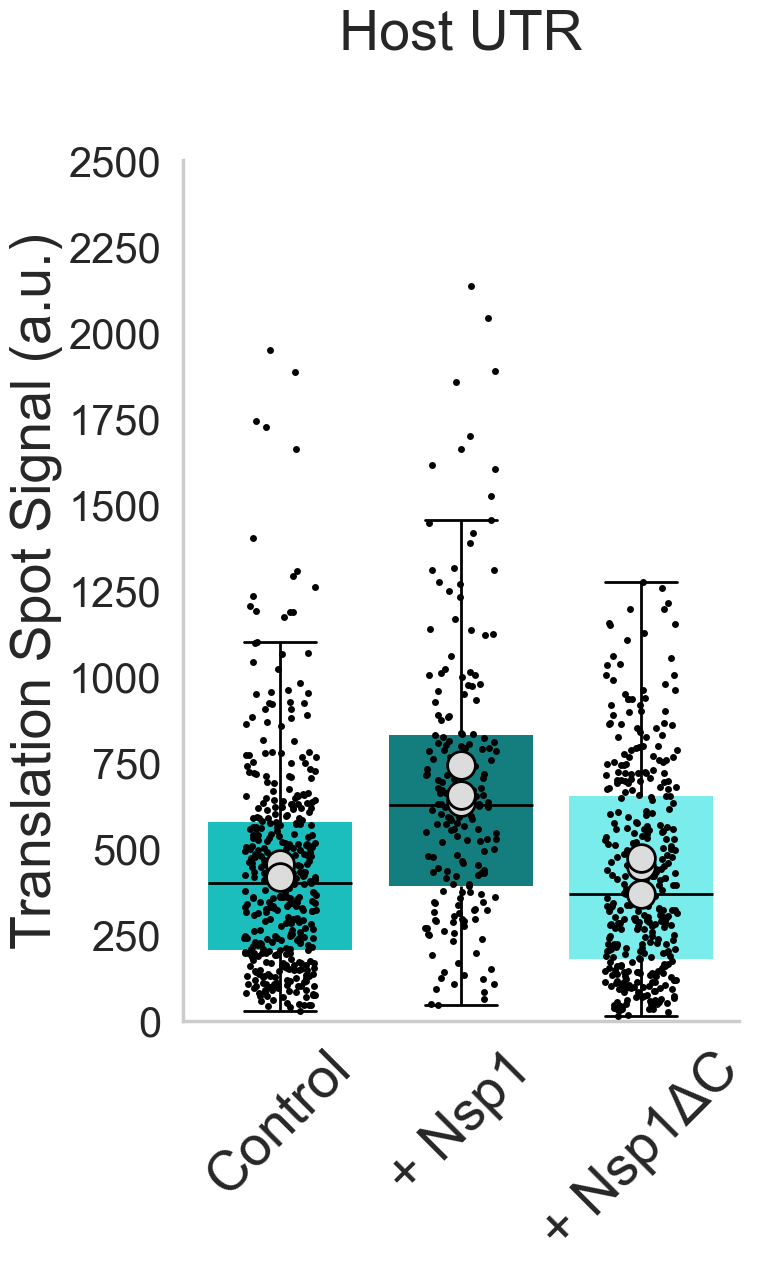

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4285541052.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=1.61e+03/1.6e+03, mean_diff=-18.7, p=0.715, ns
[hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=1.61e+03/1.61e+03, mean_diff=-3.75, p=0.963, ns
[hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=1.6e+03/1.61e+03, mean_diff=14.9, p=0.753, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=SARS_CTRL]
No Nsp1: 1.61e+03 ± 45 SEM (n=3)
Nsp1: 1.6e+03 ± 34.9 SEM (n=3)
NoCTD Nsp1: 1.61e+03 ± 76.4 SEM (n=3)

                     test_group                               contrast  \
0  x|within_hue|paired_baseline        [hue=SARS_CTRL] No Nsp1 vs Nsp1   
1  x|within_hue|paired_baseline  [hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1   
2     x|within_hue|paired_cross     [hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1   

        x0          x1       hue0       hue1  n_pairs        mean0  \
0  No Nsp1        Nsp1  SARS_CTRL  SARS_CTRL        3  1614.582579   
1  No Nsp1  NoCTD Nsp1  SARS_CTRL  SARS_CTRL        3  1614.582

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\4285541052.py:123: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


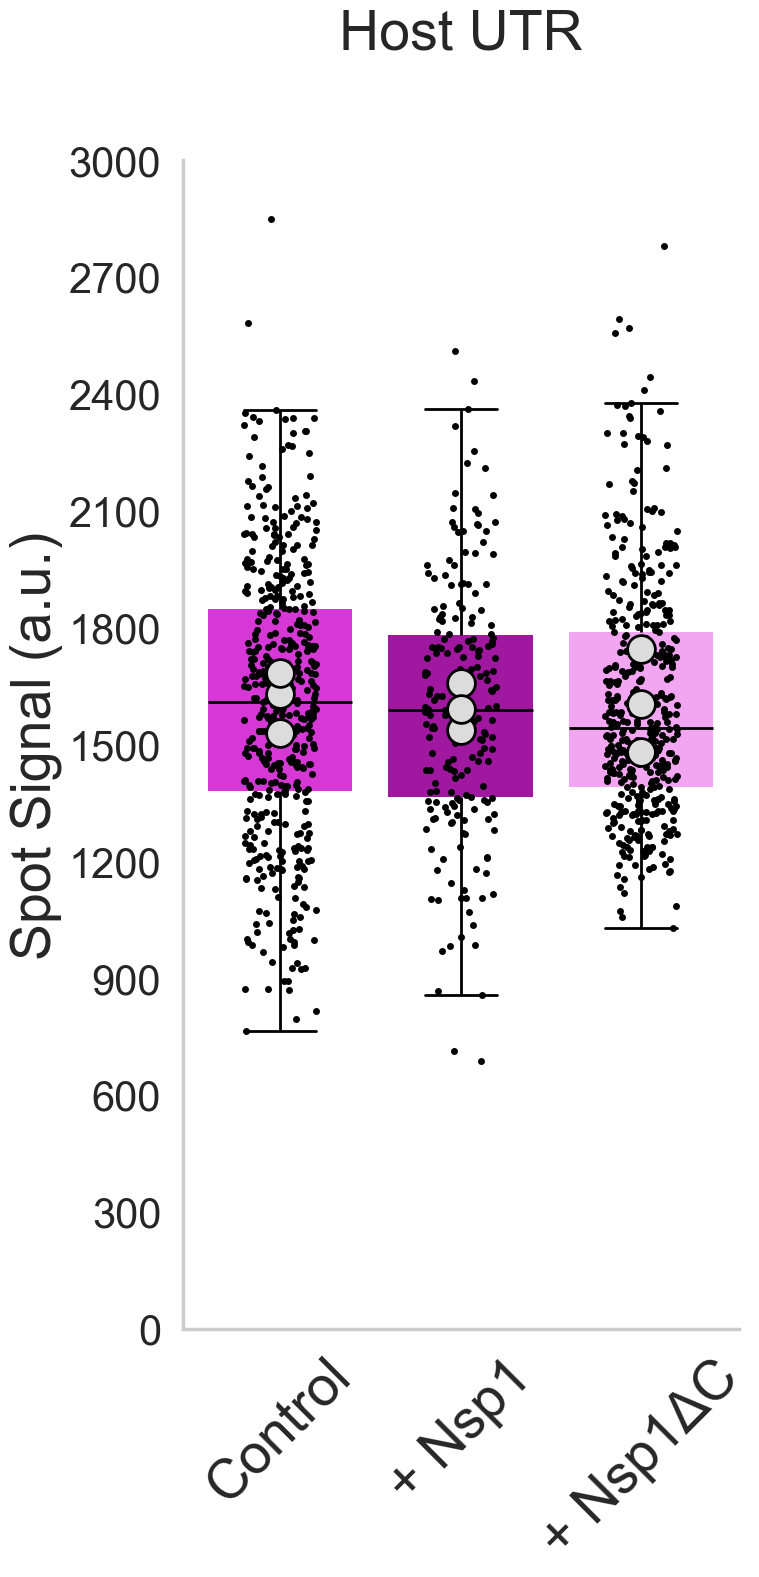

In [207]:
# Plot 4: Host UTR Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = df_avg_sig_no_outliers[df_avg_sig_no_outliers['Experimental Group'] == "SARS_CTRL"]
data_translation = data[data['Average Translation Signal'] > 0]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data, average_column = "Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1", "+ Nsp1\u0394C"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Translation Signal", hue="Experimental Group", zorder=10)
ax1.set_title('Host UTR', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Average Translation Signal Host UTR.svg")
filename_png_translation = os.path.join(save_directory, "Average Translation Signal Host UTR.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average RNA Signal",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average RNA Signal", hue="Experimental Group", zorder=10)
ax2.set_title('Host UTR', fontsize=40, pad=80)
ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 3000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Average RNA Signal Host UTR.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Average RNA Signal Host UTR.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2306263795.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=437/686, mean_diff=249, p=0.0129, *
[hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=437/403, mean_diff=-33.2, p=0.545, ns
[hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=686/403, mean_diff=-282, p=0.0245, *

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=SARS_CTRL]
No Nsp1: 437 ± 15.7 SEM (n=3)
Nsp1: 686 ± 30.5 SEM (n=3)
NoCTD Nsp1: 403 ± 30.7 SEM (n=3)

                     test_group                               contrast  \
0  x|within_hue|paired_baseline        [hue=SARS_CTRL] No Nsp1 vs Nsp1   
1  x|within_hue|paired_baseline  [hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1   
2     x|within_hue|paired_cross     [hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1   

        x0          x1       hue0       hue1  n_pairs       mean0       mean1  \
0  No Nsp1        Nsp1  SARS_CTRL  SARS_CTRL        3  436.508161  685.561411   
1  No Nsp1  NoCTD Nsp1  SARS_CTRL  SARS_CTRL        3  436.508161  403.332896   
2 

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2306263795.py:72: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


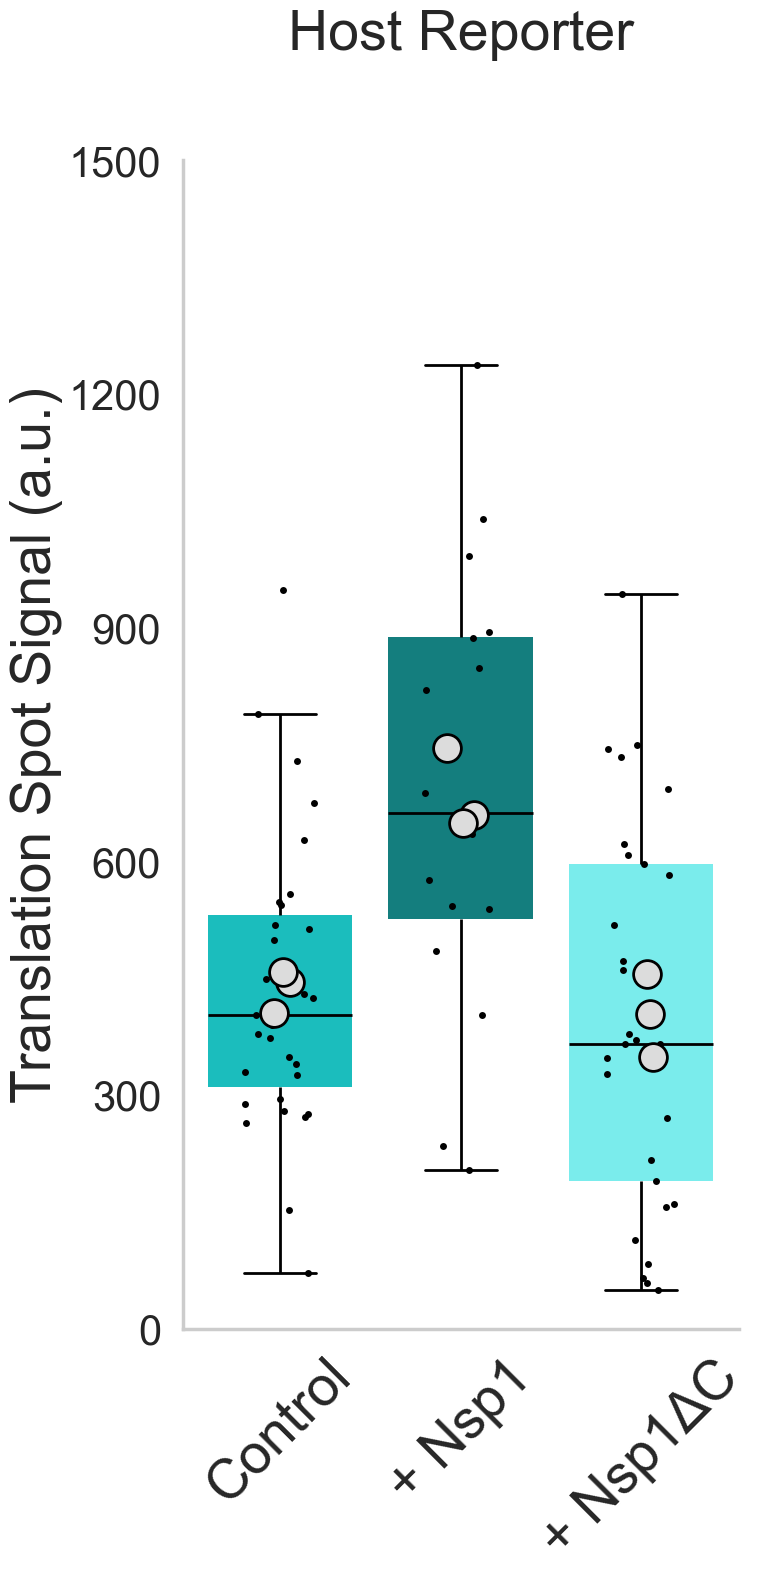

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2306263795.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=1.61e+03/1.57e+03, mean_diff=-48.7, p=0.411, ns
[hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=1.61e+03/1.61e+03, mean_diff=-7.52, p=0.926, ns
[hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=1.57e+03/1.61e+03, mean_diff=41.2, p=0.451, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=SARS_CTRL]
No Nsp1: 1.61e+03 ± 45 SEM (n=3)
Nsp1: 1.57e+03 ± 30.5 SEM (n=3)
NoCTD Nsp1: 1.61e+03 ± 74.6 SEM (n=3)

                     test_group                               contrast  \
0  x|within_hue|paired_baseline        [hue=SARS_CTRL] No Nsp1 vs Nsp1   
1  x|within_hue|paired_baseline  [hue=SARS_CTRL] No Nsp1 vs NoCTD Nsp1   
2     x|within_hue|paired_cross     [hue=SARS_CTRL] Nsp1 vs NoCTD Nsp1   

        x0          x1       hue0       hue1  n_pairs        mean0  \
0  No Nsp1        Nsp1  SARS_CTRL  SARS_CTRL        3  1614.596514   
1  No Nsp1  NoCTD Nsp1  SARS_CTRL  SARS_CTRL        3  1614.

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2306263795.py:121: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


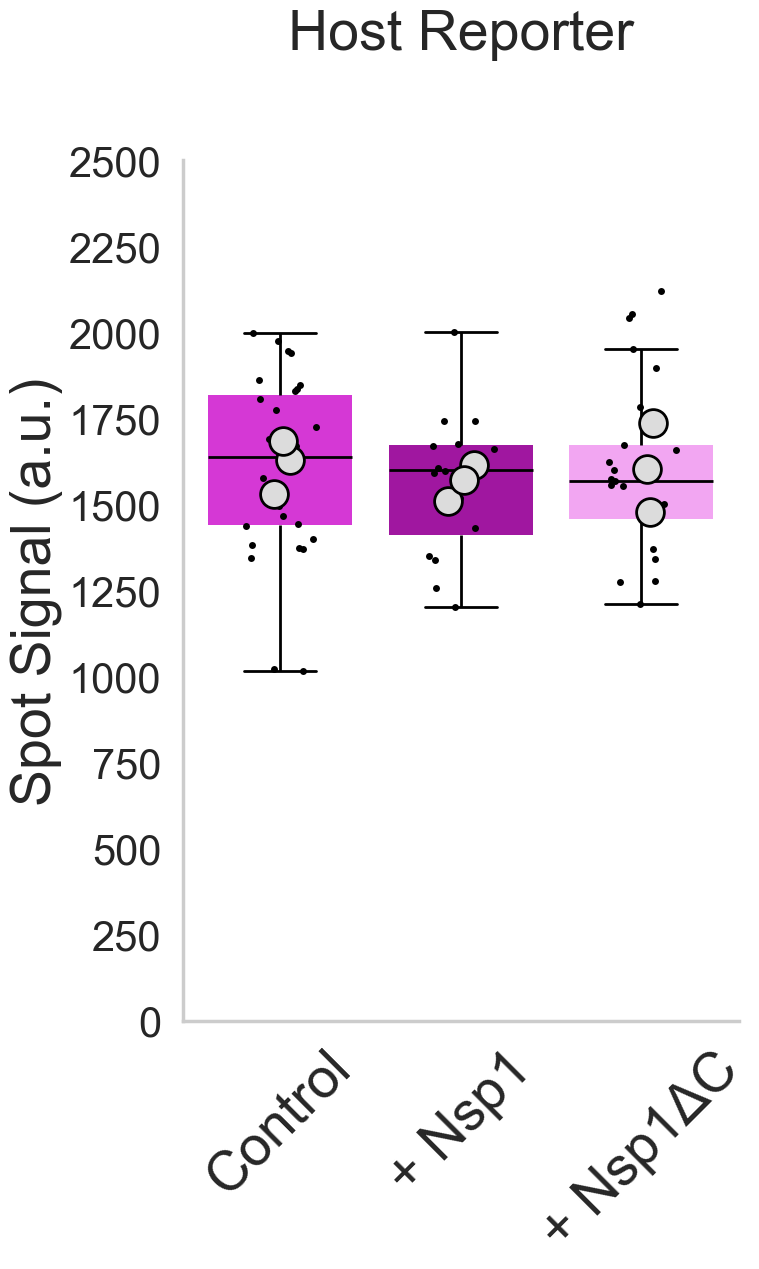

In [151]:
# Plot 4b: Host UTR Cell Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data_rna = cell_avg_df_rna[cell_avg_df_rna['Experimental Group'] == "SARS_CTRL"]
data_translation = cell_avg_df_trnl[cell_avg_df_trnl['Experimental Group'] == "SARS_CTRL"]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Cell Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data_rna, average_column = "Cell Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1", "+ Nsp1\u0394C"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Cell Average Translation Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax1.set_title('Host Reporter', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 1500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=5))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Cell Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal Host UTR.svg")
filename_png_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal Host UTR.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average RNA Signal",
              data=data_rna, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cell Average RNA Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax2.set_title('Host Reporter', fontsize=40, pad=80)
ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 2500)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Cell Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal Host UTR.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal Host UTR.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


In [ ]:
# Plot 5: BoxB MS2 Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = average_sig_df[average_sig_df['Experimental Group'] == "BoxB_MS2"]
superplot_translation = calculate_grouped_average(df = data, average_column = "Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data, average_column = "Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the x-tick labels
new_labels = ["No ORF", "+ Nsp1", "\u0394 Nsp1"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average Translation Signal", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Translation Signal", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=65)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary(x="Experimental Type", y="Average Translation Signal", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Average Translation Signal BoxB MS2.svg")
filename_png_translation = os.path.join(save_directory, "Average Translation Signal BoxB MS2.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average RNA Signal",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average RNA Signal", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 3000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=65)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary(x="Experimental Type", y="Average RNA Signal", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory, "Average RNA Signal BoxB MS2.svg")
filename_png_rna = os.path.join(save_directory, "Average RNA Signal BoxB MS2.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


In [ ]:
# Plot 5b: BoxB MS2 Cell Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data_rna = cell_avg_df_rna[cell_avg_df_rna['Experimental Group'] == "BoxB_MS2"]
data_translation = cell_avg_df_trnl[cell_avg_df_trnl['Experimental Group'] == "BoxB_MS2"]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Cell Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data_rna, average_column = "Cell Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the x-tick labels
new_labels = ["No ORF", "+ Nsp1", "\u0394 Nsp1"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Cell Average Translation Signal", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=65)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary(x="Experimental Type", y="Cell Average Translation Signal", hue="Experimental Group",
            data=data_translation, order=order)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Cell Average Translation Signal BoxB MS2.svg")
filename_png_translation = os.path.join(save_directory, "Cell Average Translation Signal BoxB MS2.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average RNA Signal",
              data=data_rna, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cell Average RNA Signal", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 3000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=65)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary(x="Experimental Type", y="Cell Average RNA Signal", hue="Experimental Group",
            data=data_rna, order=order)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory, "Cell Average RNA Signal BoxB MS2.svg")
filename_png_rna = os.path.join(save_directory, "Cell Average RNA Signal BoxB MS2.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


In [ ]:
# Plot 6: Emi KDM5B Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = average_sig_df[average_sig_df['Experimental Group'] == "Emi_KDM5B"]
data_translation = data[data['Average Translation Signal'] > 0]
superplot_translation = calculate_grouped_average(df=data_translation, average_column="Average Translation Signal",
                                                  group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df=data, average_column="Average RNA Signal",
                                          group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1", "NoCTD Nsp1"]

# Define the x-tick labels
new_labels = ["Emi", "+ Nsp1", "\u0394 Nsp1"]



# Plot 1: Average Total Translation Signal with Broken Y-axis
fig, (ax1_top, ax1_bottom) = plt.subplots(2, 1, sharex=True, figsize=(8, 16),
                                         gridspec_kw={'height_ratios': [1, 2]}, constrained_layout=True)
sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Top plot (800 - 2000)
sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1_top,
            palette=blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2),
            capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average Translation Signal",
              data=data_translation, order=order, color="black", alpha=1, size=5, jitter=0.2, dodge=True, ax=ax1_top)

plot_open_circles_with_hue(ax1_top, superplot_translation, order=order, x="Experimental Type", y="Super Average Translation Signal", hue="Experimental Group")

ax1_top.set_ylim(1000, 2000)
ax1_top.spines['bottom'].set_visible(False)
ax1_top.set_ylabel("", fontsize=40)
ax1_top.tick_params(labeltop=False, labelsize=30)  # Hide x labels on top plot
ax1_top.yaxis.set_major_locator(MaxNLocator(nbins=3))

# Bottom plot (0 - 500)
sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1_bottom,
            palette=blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2),
            capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average Translation Signal",
              data=data_translation, order=order, color="black", alpha=1, size=5, jitter=0.2, dodge=True, ax=ax1_bottom)

plot_open_circles_with_hue(ax1_bottom, superplot_translation, order=order, x="Experimental Type", y="Super Average Translation Signal", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax1_bottom.set_ylim(0, 700)
ax1_bottom.spines['top'].set_visible(False)
ax1_bottom.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1_bottom.yaxis.set_label_coords(-0.195, 0.8)  # Adjust y-label position
ax1_bottom.tick_params(axis='both', which='major', labelsize=30)
ax1_bottom.set_xticklabels(new_labels, fontsize=40, rotation=65)
ax1_bottom.set_xlabel('')
ax1_bottom.yaxis.set_major_locator(MaxNLocator(nbins=5))



# Remove the legend from both plots
handles, labels = ax1_top.get_legend_handles_labels()
ax1_top.legend().remove()
ax1_bottom.legend().remove()

res1 = print_ttest_summary(x="Experimental Type", y="Average Translation Signal", hue="Experimental Group",
            data=data_translation, order=order)
print(res1)

# Save the figure for Translation Signal with y-axis break
filename_svg_translation = os.path.join(save_directory, "Average Translation Signal Emi KDM5B Broken Axis.svg")
filename_png_translation = os.path.join(save_directory, "Average Translation Signal Emi KDM5B Broken Axis.png")
fig.savefig(filename_svg_translation, format='svg', dpi=300)
fig.savefig(filename_png_translation, format='png', dpi=300)

plt.show()


# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average RNA Signal",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average RNA Signal", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)

ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 3000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=65)
ax2.yaxis.set_label_coords(-0.195, 0.5)  # Adjust y-label position
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary(x="Experimental Type", y="Average RNA Signal", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory, "Average RNA Signal Emi KDM5B.svg")
filename_png_rna = os.path.join(save_directory, "Average RNA Signal Emi KDM5B.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2536403469.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2536403469.py:48: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=Emi_KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=100/117, mean_diff=16.5, p=0.315, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=Emi_KDM5B]
No Nsp1: 100 ± 16.7 SEM (n=3)
Nsp1: 117 ± 29 SEM (n=3)

                     test_group                         contrast       x0  \
0  x|within_hue|paired_baseline  [hue=Emi_KDM5B] No Nsp1 vs Nsp1  No Nsp1   

     x1       hue0       hue1  n_pairs       mean0       mean1    pvalue  \
0  Nsp1  Emi_KDM5B  Emi_KDM5B        3  100.319594  116.790866  0.314736   

  stars         paired_by  mean_diff_x1_minus_x0  
0    ns  Replicate Number              16.471271  


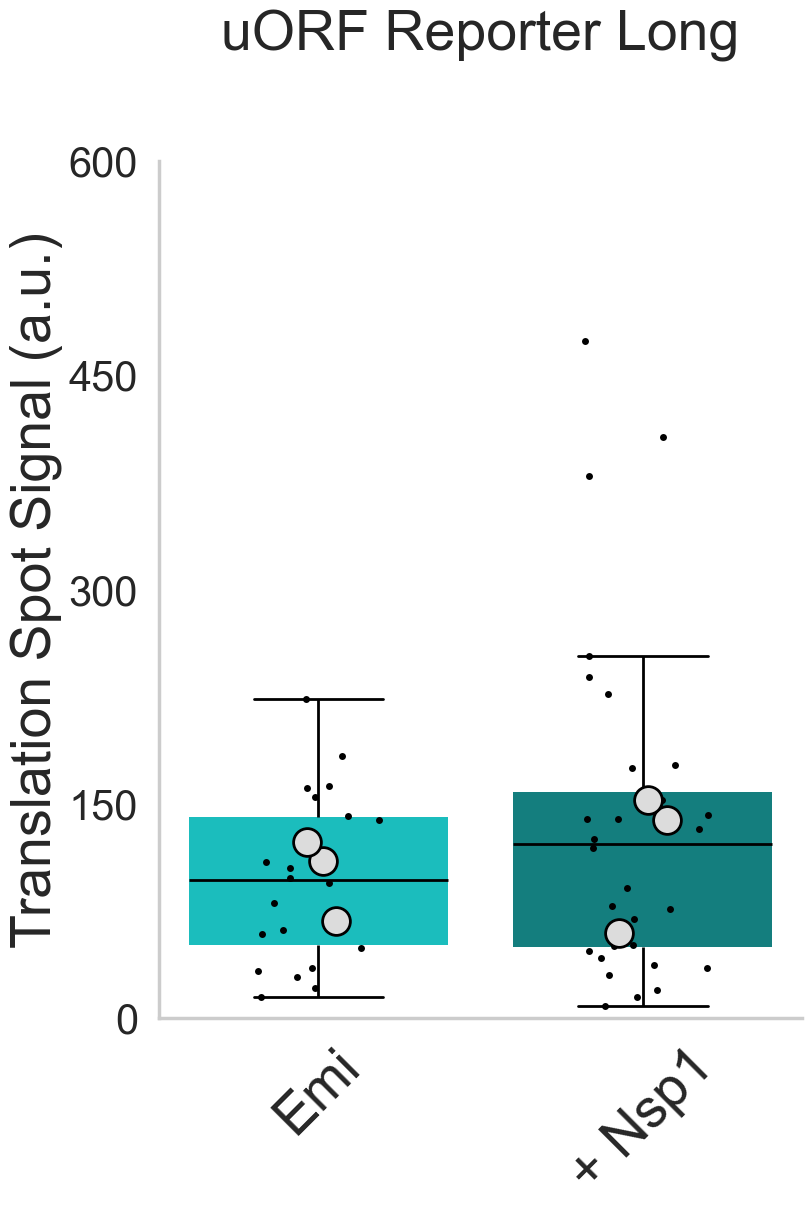

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2536403469.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2536403469.py:96: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=Emi_KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=852/736, mean_diff=-116, p=0.396, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=Emi_KDM5B]
No Nsp1: 852 ± 179 SEM (n=3)
Nsp1: 736 ± 79.7 SEM (n=3)

                     test_group                         contrast       x0  \
0  x|within_hue|paired_baseline  [hue=Emi_KDM5B] No Nsp1 vs Nsp1  No Nsp1   

     x1       hue0       hue1  n_pairs       mean0    mean1    pvalue stars  \
0  Nsp1  Emi_KDM5B  Emi_KDM5B        3  852.258427  736.325  0.395856    ns   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate Number            -115.933427  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\2536403469.py:140: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


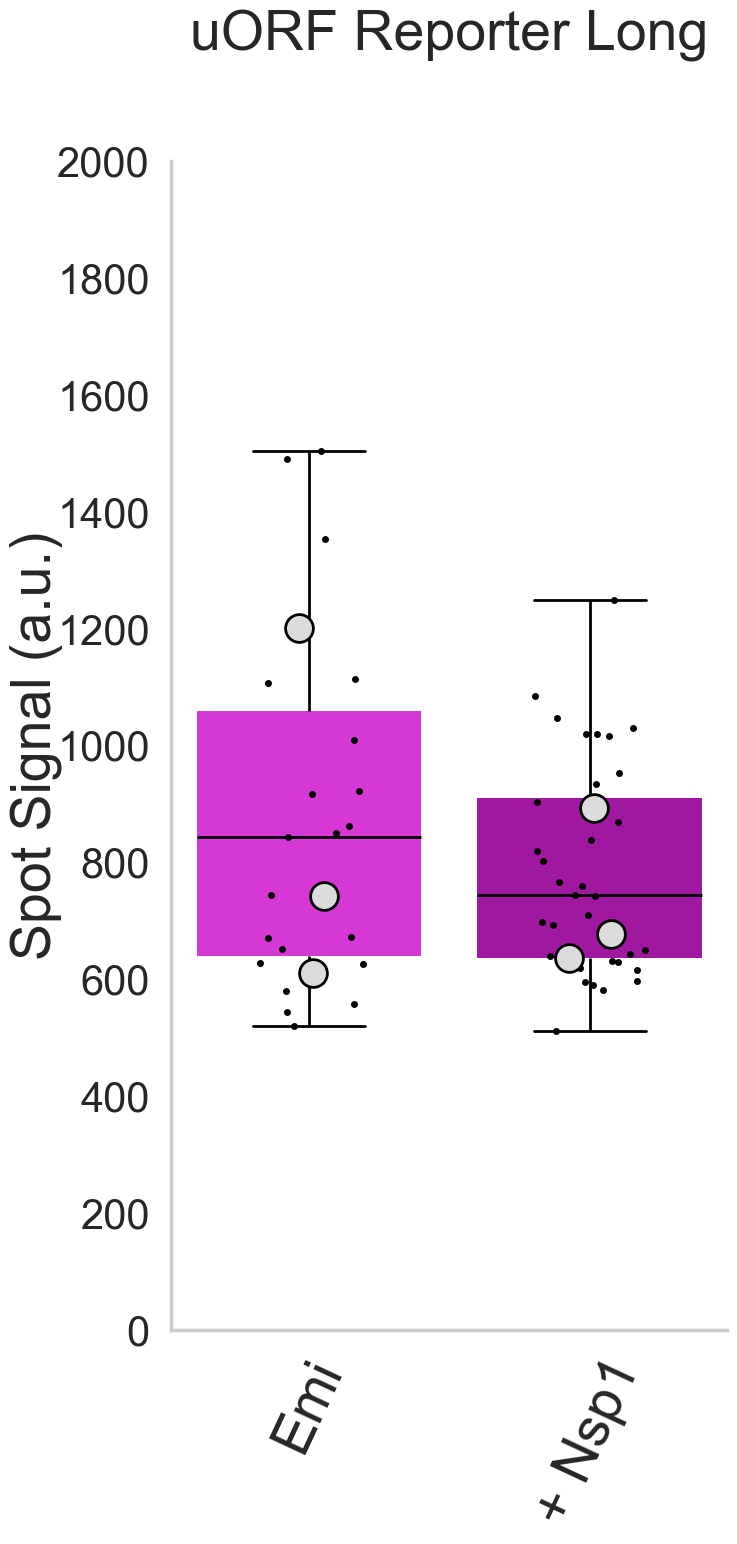

In [152]:
# Plot 6b: Emi KDM5B Cell Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data_rna = (
    cell_avg_df_rna[
        cell_avg_df_rna["Experimental Group"] == "Emi_KDM5B"
    ]
    .query("`Replicate Number` != 2")
    .reset_index(drop=True)
)

data_translation = (
    cell_avg_df_trnl[
        cell_avg_df_trnl["Experimental Group"] == "Emi_KDM5B"
    ]
    .query("`Replicate Number` != 2")
    .reset_index(drop=True)
)

superplot_translation = calculate_grouped_average(df=data_translation, average_column="Cell Average Translation Signal",
                                                  group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df=data_rna, average_column="Cell Average RNA Signal",
                                          group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Emi", "+ Nsp1"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Cell Average Translation Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax1.set_title('uORF Reporter Long', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 600)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=5))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Cell Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal Emi KDM5B.svg")
filename_png_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal Emi KDM5B.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

plt.show()


# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average RNA Signal",
              data=data_rna, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cell Average RNA Signal", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.set_title('uORF Reporter Long', fontsize=40,pad=80)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 2000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=65)
ax2.yaxis.set_label_coords(-0.195, 0.5)  # Adjust y-label position
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Cell Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal Emi KDM5B.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal Emi KDM5B.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1568543724.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1568543724.py:35: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=BoxB_IRES] No Nsp1 vs Nsp1: n_pairs=3, mean=247/63.7, mean_diff=-183, p=0.015, *

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=BoxB_IRES]
No Nsp1: 247 ± 31.1 SEM (n=3)
Nsp1: 63.7 ± 8.4 SEM (n=3)

                     test_group                         contrast       x0  \
0  x|within_hue|paired_baseline  [hue=BoxB_IRES] No Nsp1 vs Nsp1  No Nsp1   

     x1       hue0       hue1  n_pairs       mean0      mean1    pvalue stars  \
0  Nsp1  BoxB_IRES  BoxB_IRES        3  247.119307  63.691196  0.014969     *   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate Number            -183.428111  


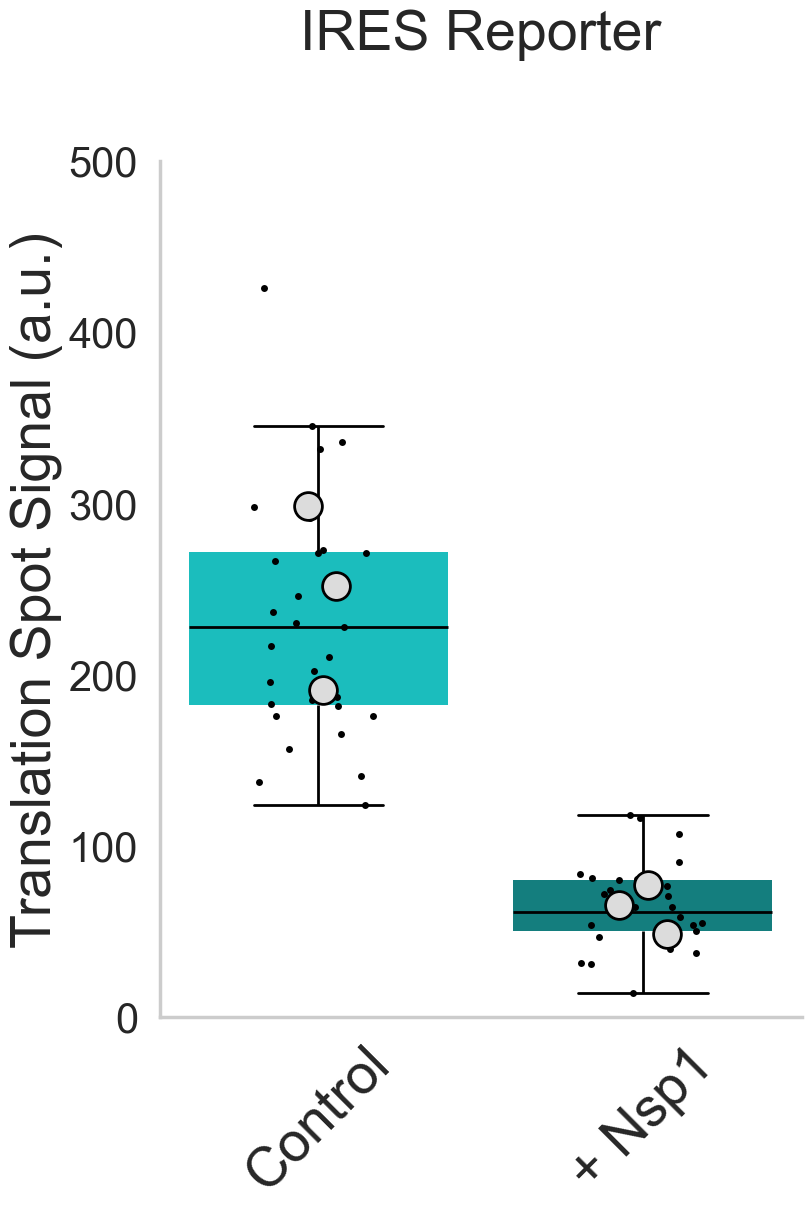

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1568543724.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1568543724.py:83: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=BoxB_IRES] No Nsp1 vs Nsp1: n_pairs=3, mean=785/885, mean_diff=100, p=0.435, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=BoxB_IRES]
No Nsp1: 785 ± 8.61 SEM (n=3)
Nsp1: 885 ± 95.7 SEM (n=3)

                     test_group                         contrast       x0  \
0  x|within_hue|paired_baseline  [hue=BoxB_IRES] No Nsp1 vs Nsp1  No Nsp1   

     x1       hue0       hue1  n_pairs       mean0       mean1    pvalue  \
0  Nsp1  BoxB_IRES  BoxB_IRES        3  785.054251  885.115399  0.435005   

  stars         paired_by  mean_diff_x1_minus_x0  
0    ns  Replicate Number             100.061147  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\1568543724.py:127: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


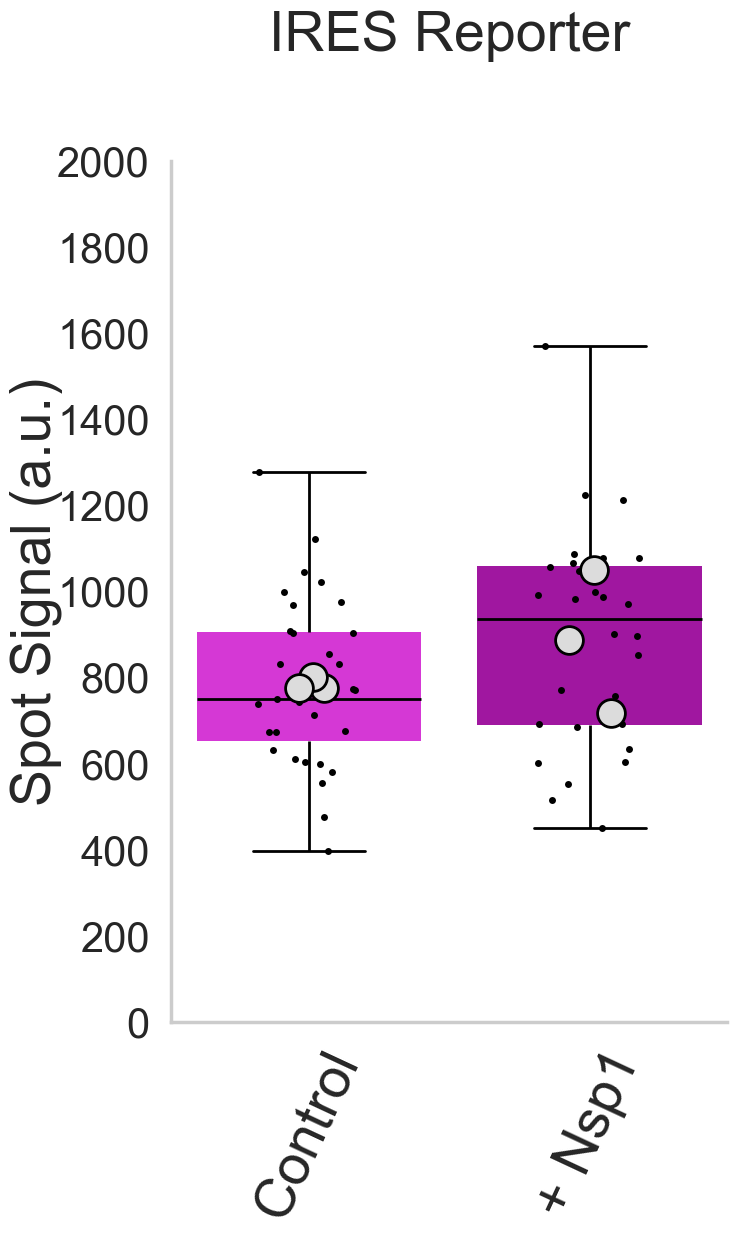

In [202]:
# Plot 6b: IRES Cell Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data_rna = cell_avg_df_rna[cell_avg_df_rna['Experimental Group'] == "BoxB_IRES"]
data_translation = cell_avg_df_trnl[cell_avg_df_trnl['Experimental Group'] == "BoxB_IRES"]

superplot_translation = calculate_grouped_average(df=data_translation, average_column="Cell Average Translation Signal",
                                                  group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df=data_rna, average_column="Cell Average RNA Signal",
                                          group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]



# Plot 1: Average Total Translation Signal with Broken Y-axis
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Cell Average Translation Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax1.set_title('IRES Reporter', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=5))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Cell Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res)

# Save the figure for Translation Signal with y-axis break
filename_svg_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal IRES.svg")
filename_png_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal IRES.png")
fig1.savefig(filename_svg_translation, format='svg', dpi=300)
fig1.savefig(filename_png_translation, format='png', dpi=300)

plt.show()


# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average RNA Signal",
              data=data_rna, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cell Average RNA Signal", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.set_title('IRES Reporter', fontsize=40,pad=80)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 2000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=65)
ax2.yaxis.set_label_coords(-0.195, 0.5)  # Adjust y-label position
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Cell Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res1)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal IRES.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal IRES.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_36528\2821583194.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=848/903, mean_diff=55.1, p=0.59, ns
            test_group                     contrast       x0    x1   hue0  \
0  x|within_hue|paired  [hue=KDM5B] No Nsp1 vs Nsp1  No Nsp1  Nsp1  KDM5B   

    hue1  n_pairs       mean0       mean1  mean_diff_x1_minus_x0    pvalue  \
0  KDM5B        3  847.770574  902.873493              55.102919  0.589751   

  stars         paired_by  
0    ns  Replicate Number  


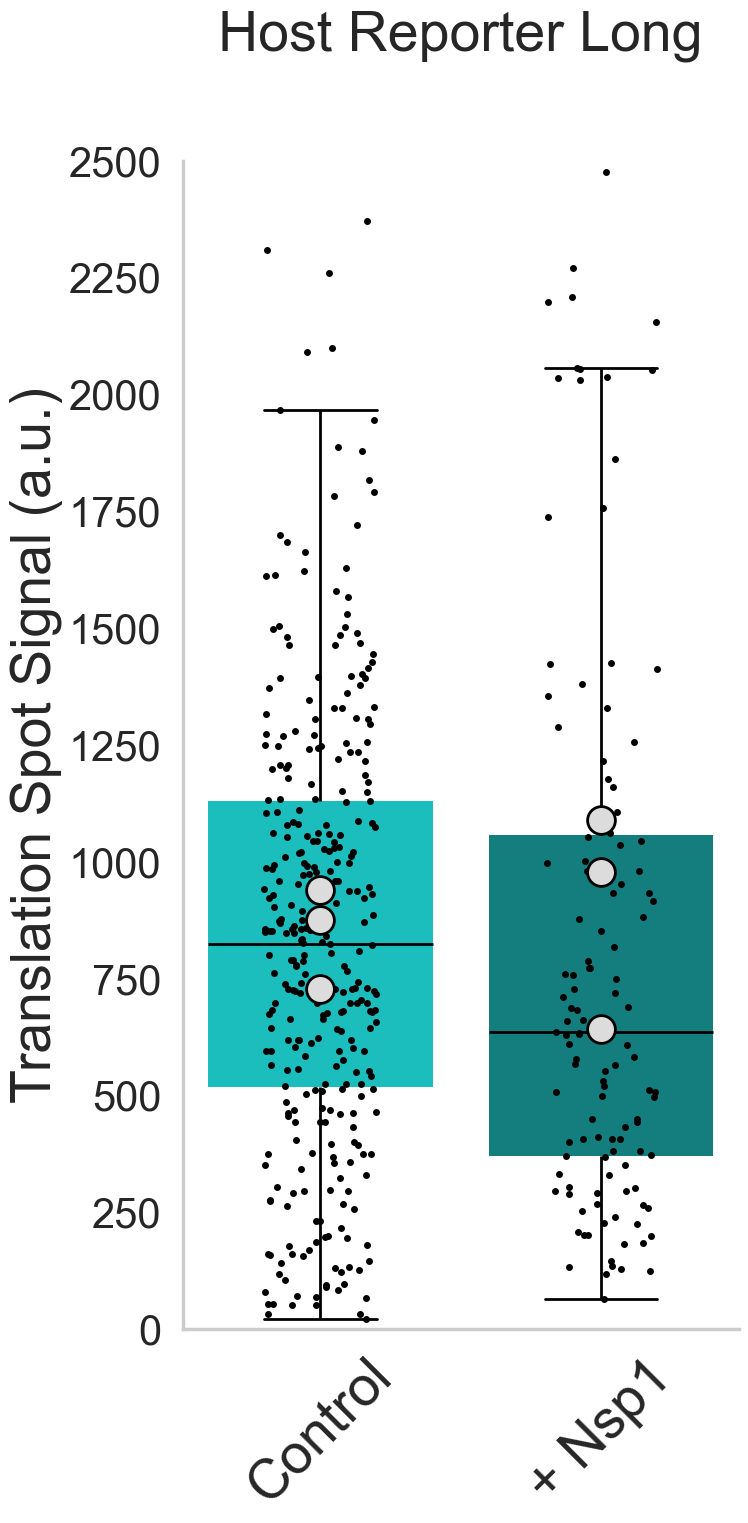

C:\Users\AdamC\AppData\Local\Temp\ipykernel_36528\2821583194.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=556/534, mean_diff=-22.1, p=0.296, ns
            test_group                     contrast       x0    x1   hue0  \
0  x|within_hue|paired  [hue=KDM5B] No Nsp1 vs Nsp1  No Nsp1  Nsp1  KDM5B   

    hue1  n_pairs       mean0       mean1  mean_diff_x1_minus_x0    pvalue  \
0  KDM5B        3  556.475499  534.349534             -22.125965  0.296021   

  stars         paired_by  
0    ns  Replicate Number  


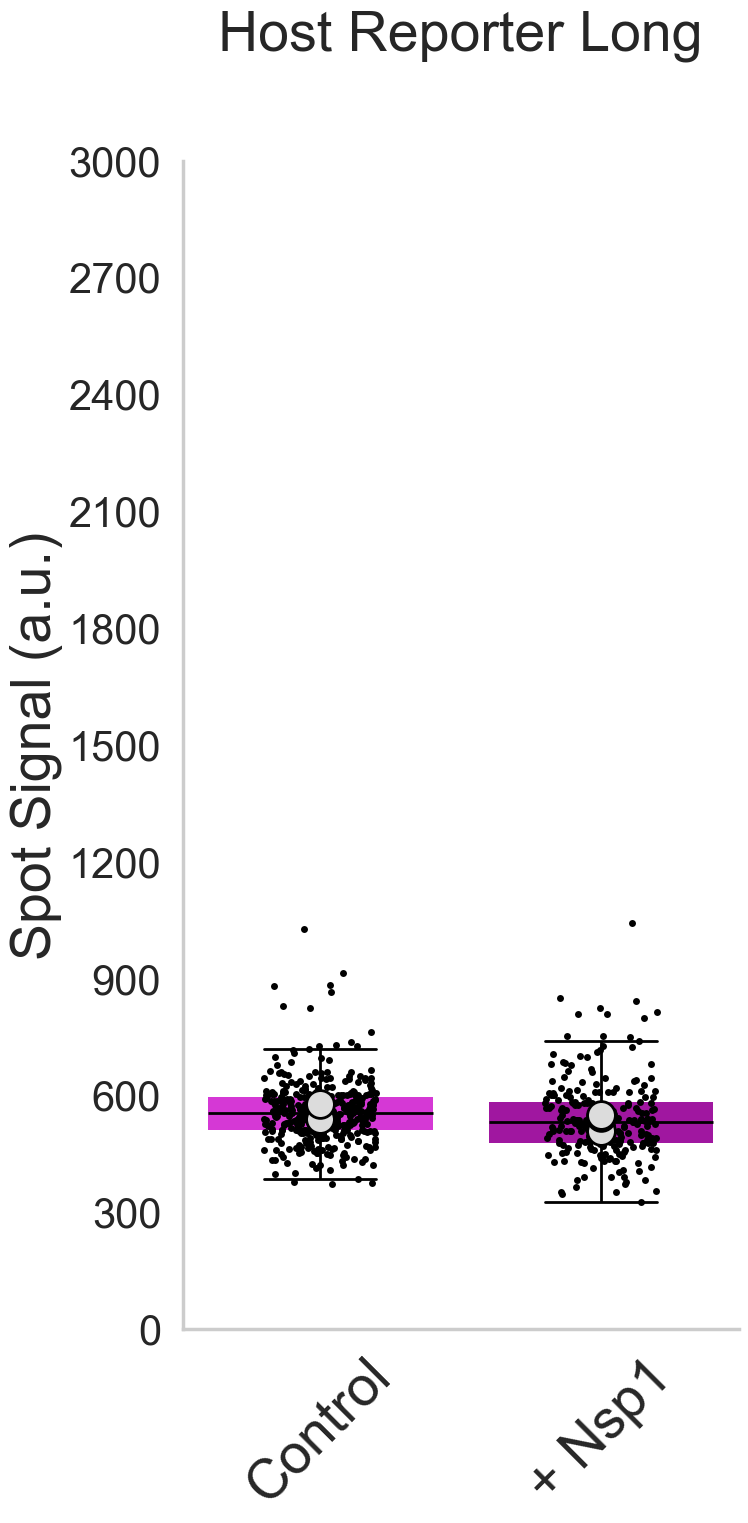

In [ ]:
# Plot 7: KDM5B Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = df_avg_sig_no_outliers[df_avg_sig_no_outliers['Experimental Group'] == "KDM5B"]
data_translation = data[data['Average Translation Signal'] > 0]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data, average_column = "Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Translation Signal", hue="Experimental Group", zorder=10)
ax1.set_title('Host Reporter Long', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Average Translation Signal KDM5B.svg")
filename_png_translation = os.path.join(save_directory, "Average Translation Signal KDM5B.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average RNA Signal",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average RNA Signal", hue="Experimental Group", zorder=10)
ax2.set_title('Host Reporter Long', fontsize=40, pad=80)
ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 3000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Average RNA Signal KDM5B.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Average RNA Signal KDM5B.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3494716419.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3494716419.py:31: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=843/982, mean_diff=139, p=0.272, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=KDM5B]
No Nsp1: 843 ± 71.5 SEM (n=3)
Nsp1: 982 ± 76.2 SEM (n=3)

                     test_group                     contrast       x0    x1  \
0  x|within_hue|paired_baseline  [hue=KDM5B] No Nsp1 vs Nsp1  No Nsp1  Nsp1   

    hue0   hue1  n_pairs      mean0       mean1    pvalue stars  \
0  KDM5B  KDM5B        3  843.30591  981.899488  0.272057    ns   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate Number             138.593577  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3494716419.py:72: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


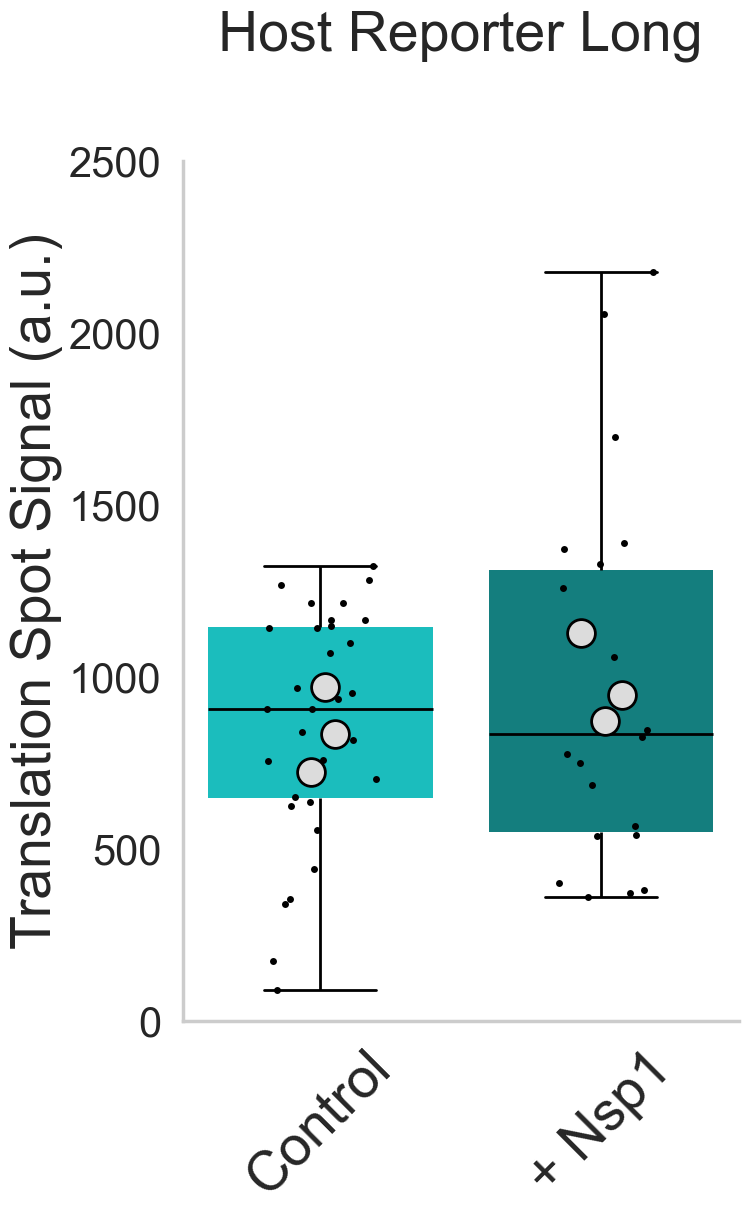

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3494716419.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3494716419.py:80: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=550/522, mean_diff=-28.2, p=0.318, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=KDM5B]
No Nsp1: 550 ± 15.1 SEM (n=3)
Nsp1: 522 ± 17.3 SEM (n=3)

                     test_group                     contrast       x0    x1  \
0  x|within_hue|paired_baseline  [hue=KDM5B] No Nsp1 vs Nsp1  No Nsp1  Nsp1   

    hue0   hue1  n_pairs     mean0       mean1    pvalue stars  \
0  KDM5B  KDM5B        3  550.1944  522.002937  0.318299    ns   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate Number             -28.191463  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3494716419.py:121: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


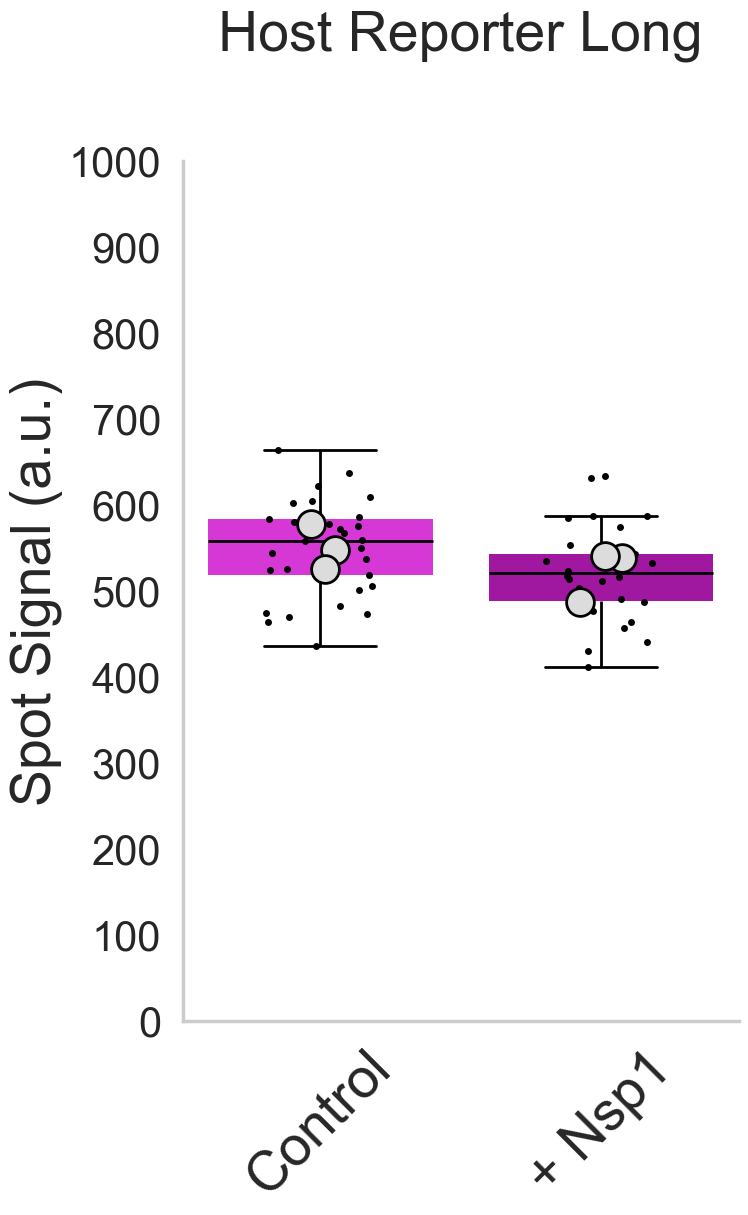

In [154]:
# Plot 7b: KDM5B Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data_rna = cell_avg_df_rna[cell_avg_df_rna['Experimental Group'] == "KDM5B"]
data_translation = cell_avg_df_trnl[cell_avg_df_trnl['Experimental Group'] == "KDM5B"]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Cell Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data_rna, average_column = "Cell Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Cell Average Translation Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax1.set_title('Host Reporter Long', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=5))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Cell Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal KDM5B.svg")
filename_png_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal KDM5B.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average RNA Signal",
              data=data_rna, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cell Average RNA Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax2.set_title('Host Reporter Long', fontsize=40, pad=80)
ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 1000)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Cell Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal KDM5B.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal KDM5B.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_36528\1193401183.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=ZNF_KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=697/365, mean_diff=-332, p=0.00902, **
            test_group                         contrast       x0    x1  \
0  x|within_hue|paired  [hue=ZNF_KDM5B] No Nsp1 vs Nsp1  No Nsp1  Nsp1   

        hue0       hue1  n_pairs       mean0       mean1  \
0  ZNF_KDM5B  ZNF_KDM5B        3  697.056417  364.642916   

   mean_diff_x1_minus_x0    pvalue stars         paired_by  
0              -332.4135  0.009018    **  Replicate Number  


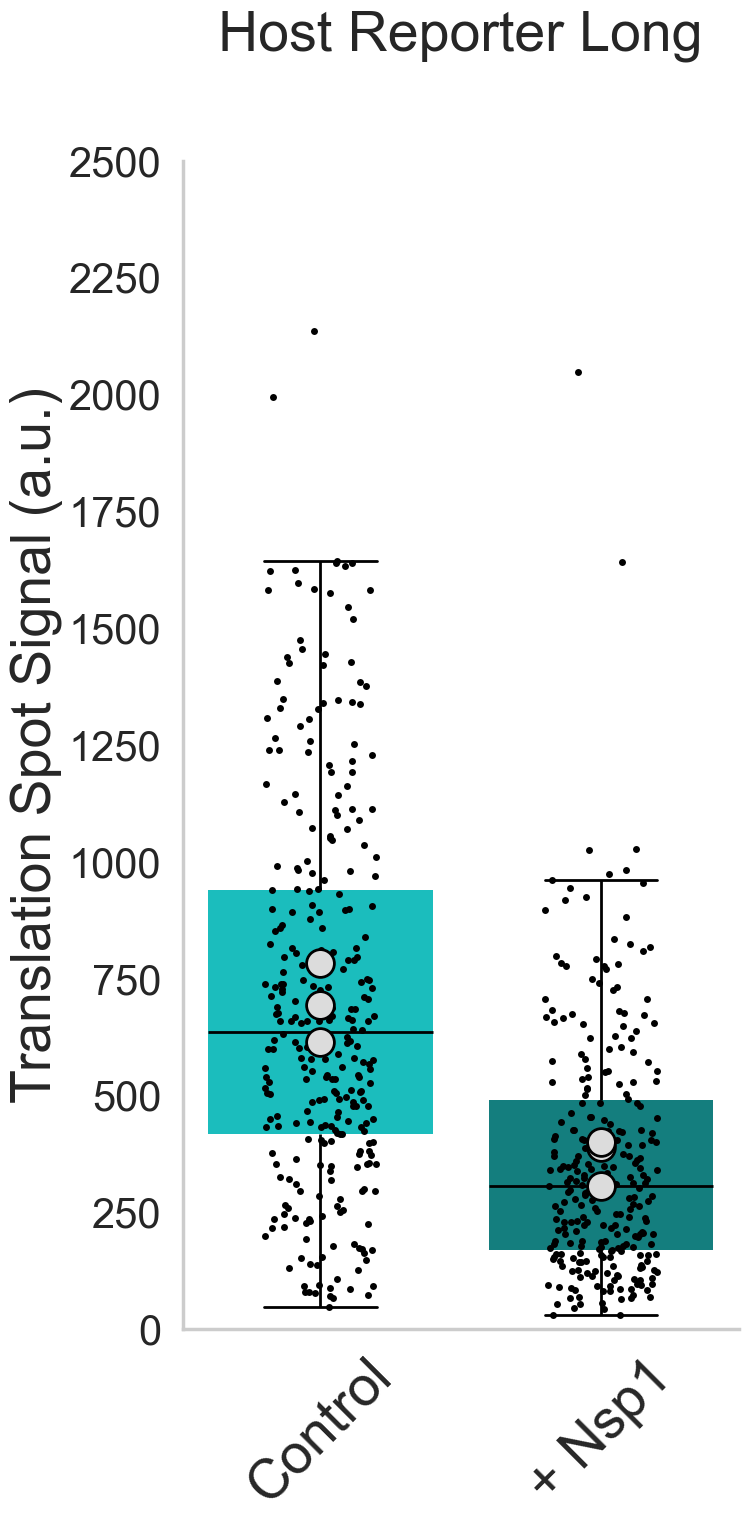

C:\Users\AdamC\AppData\Local\Temp\ipykernel_36528\1193401183.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=ZNF_KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=333/335, mean_diff=2.93, p=0.85, ns
            test_group                         contrast       x0    x1  \
0  x|within_hue|paired  [hue=ZNF_KDM5B] No Nsp1 vs Nsp1  No Nsp1  Nsp1   

        hue0       hue1  n_pairs       mean0       mean1  \
0  ZNF_KDM5B  ZNF_KDM5B        3  332.533826  335.468702   

   mean_diff_x1_minus_x0    pvalue stars         paired_by  
0               2.934876  0.850095    ns  Replicate Number  


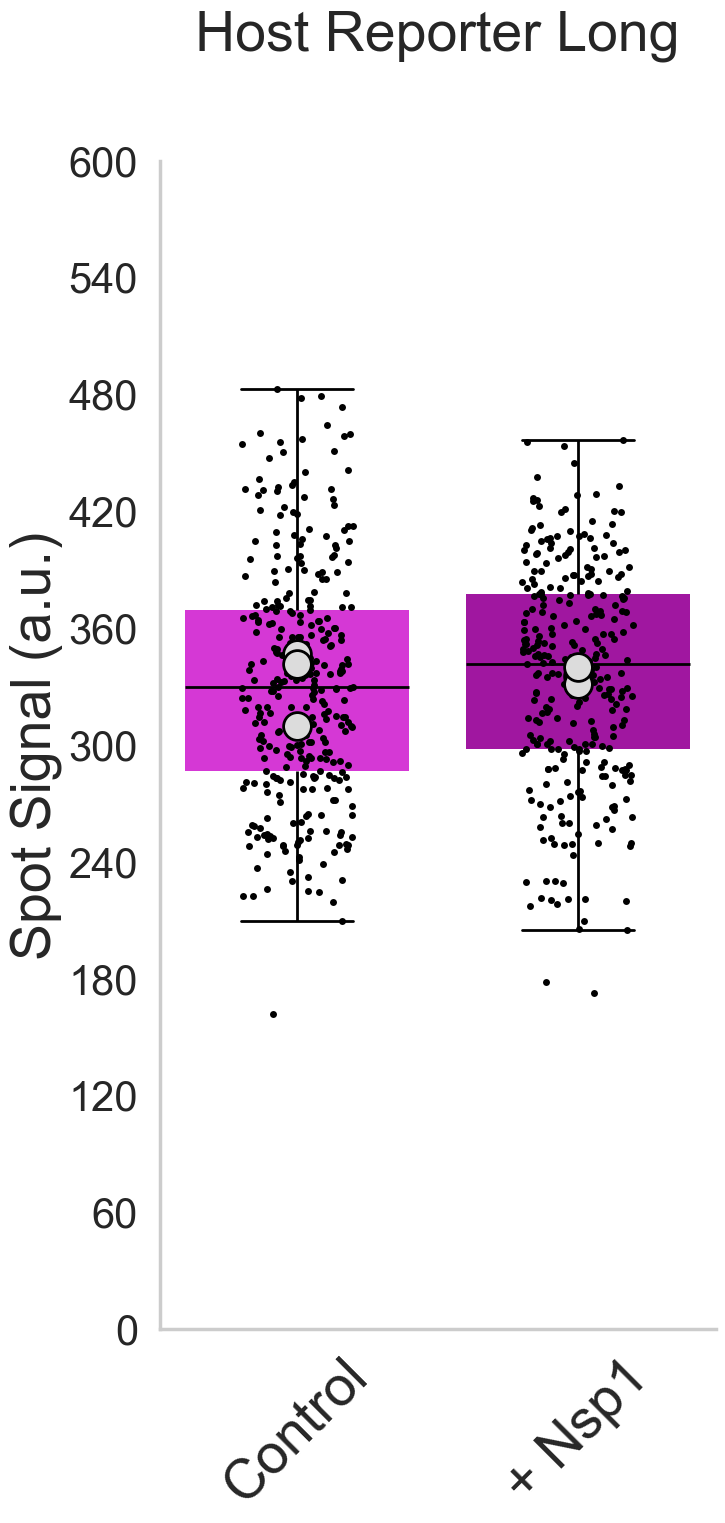

In [ ]:
# Plot 8: KO-ZNF598 KDM5B Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = df_avg_sig_no_outliers[df_avg_sig_no_outliers['Experimental Group'] == "ZNF_KDM5B"]
data_translation = data[data['Average Translation Signal'] > 0]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data, average_column = "Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Translation Signal", hue="Experimental Group", zorder=10)
ax1.set_title('Host Reporter Long', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Average Translation Signal KO-ZNF598 KDM5B.svg")
filename_png_translation = os.path.join(save_directory, "Average Translation Signal KO-ZNF598 KDM5B.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average RNA Signal",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average RNA Signal", hue="Experimental Group", zorder=10)
ax2.set_title('Host Reporter Long', fontsize=40, pad=80)
ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 600)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Average RNA Signal KO-ZNF598 KDM5B.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Average RNA Signal KO-ZNF598 KDM5B.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\528973525.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\528973525.py:31: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=ZNF_KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=680/355, mean_diff=-325, p=0.0152, *

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_KDM5B]
No Nsp1: 680 ± 60.5 SEM (n=3)
Nsp1: 355 ± 30.1 SEM (n=3)

                     test_group                         contrast       x0  \
0  x|within_hue|paired_baseline  [hue=ZNF_KDM5B] No Nsp1 vs Nsp1  No Nsp1   

     x1       hue0       hue1  n_pairs       mean0       mean1   pvalue stars  \
0  Nsp1  ZNF_KDM5B  ZNF_KDM5B        3  679.945334  355.186724  0.01522     *   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate Number             -324.75861  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\528973525.py:72: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


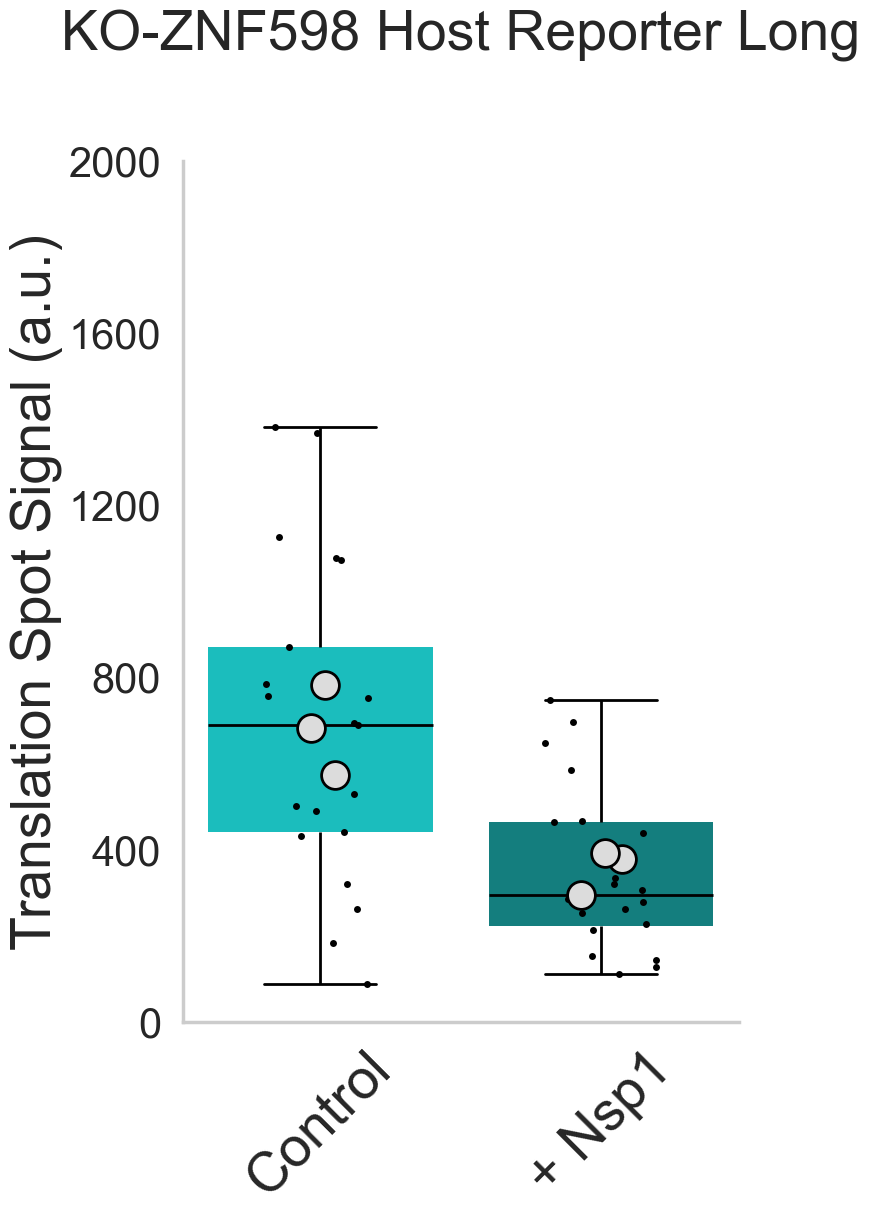

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\528973525.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\528973525.py:80: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=ZNF_KDM5B] No Nsp1 vs Nsp1: n_pairs=3, mean=332/335, mean_diff=3.7, p=0.81, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_KDM5B]
No Nsp1: 332 ± 11.3 SEM (n=3)
Nsp1: 335 ± 2.59 SEM (n=3)

                     test_group                         contrast       x0  \
0  x|within_hue|paired_baseline  [hue=ZNF_KDM5B] No Nsp1 vs Nsp1  No Nsp1   

     x1       hue0       hue1  n_pairs      mean0       mean1   pvalue stars  \
0  Nsp1  ZNF_KDM5B  ZNF_KDM5B        3  331.62554  335.324617  0.81003    ns   

          paired_by  mean_diff_x1_minus_x0  
0  Replicate Number               3.699077  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\528973525.py:121: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


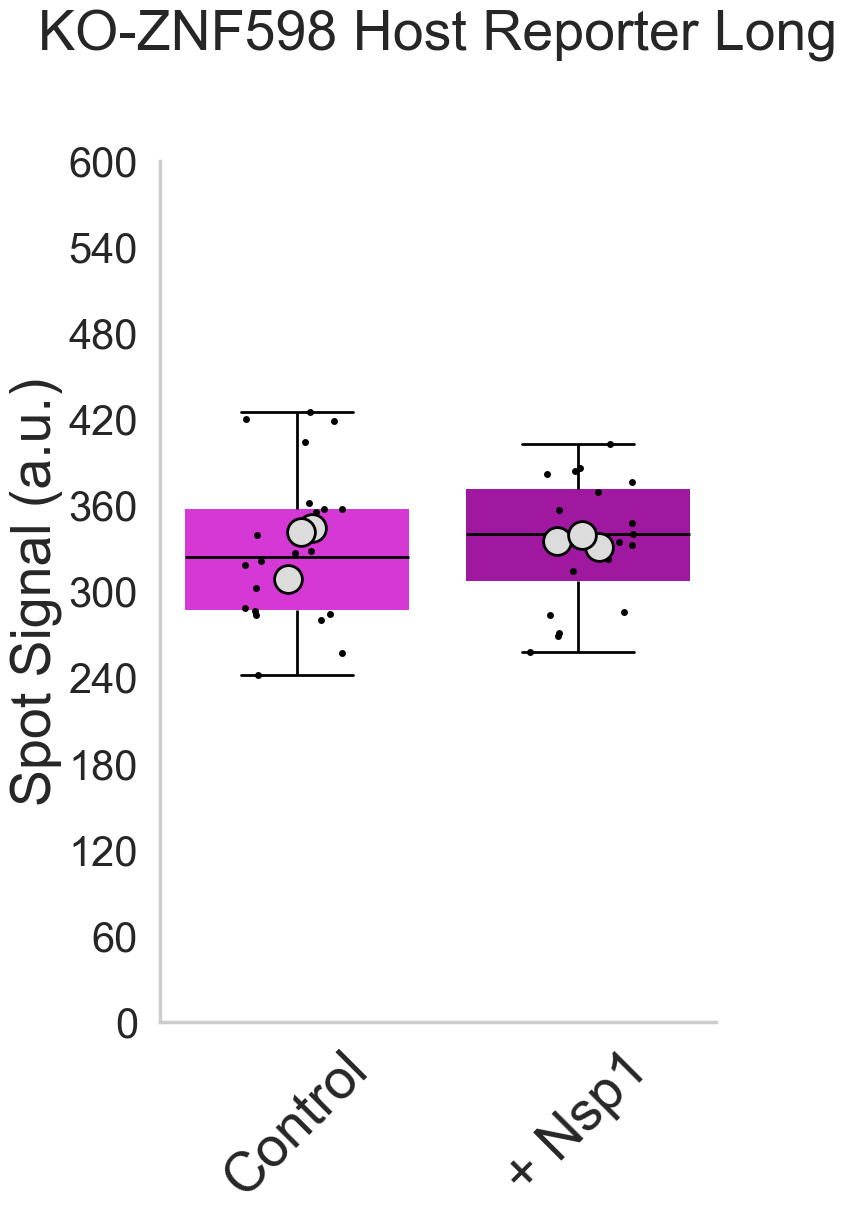

In [155]:
# Plot 8b: ZNF KDM5B Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data_rna = cell_avg_df_rna[cell_avg_df_rna['Experimental Group'] == "ZNF_KDM5B"]
data_translation = cell_avg_df_trnl[cell_avg_df_trnl['Experimental Group'] == "ZNF_KDM5B"]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Cell Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data_rna, average_column = "Cell Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Cell Average Translation Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax1.set_title('KO-ZNF598 Host Reporter Long', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 2000)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=5))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Cell Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal ZNF_KDM5B.svg")
filename_png_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal ZNF_KDM5B.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average RNA Signal",
              data=data_rna, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cell Average RNA Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax2.set_title('KO-ZNF598 Host Reporter Long', fontsize=40, pad=80)
ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 600)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Cell Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal ZNF_KDM5B.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal ZNF_KDM5B.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_36528\3946619089.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=120/137, mean_diff=16.7, p=0.588, ns
            test_group                             contrast       x0    x1  \
0  x|within_hue|paired  [hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1  No Nsp1  Nsp1   

            hue0           hue1  n_pairs       mean0       mean1  \
0  ZNF_SARS_CTRL  ZNF_SARS_CTRL        3  119.939291  136.611645   

   mean_diff_x1_minus_x0    pvalue stars         paired_by  
0              16.672354  0.587734    ns  Replicate Number  


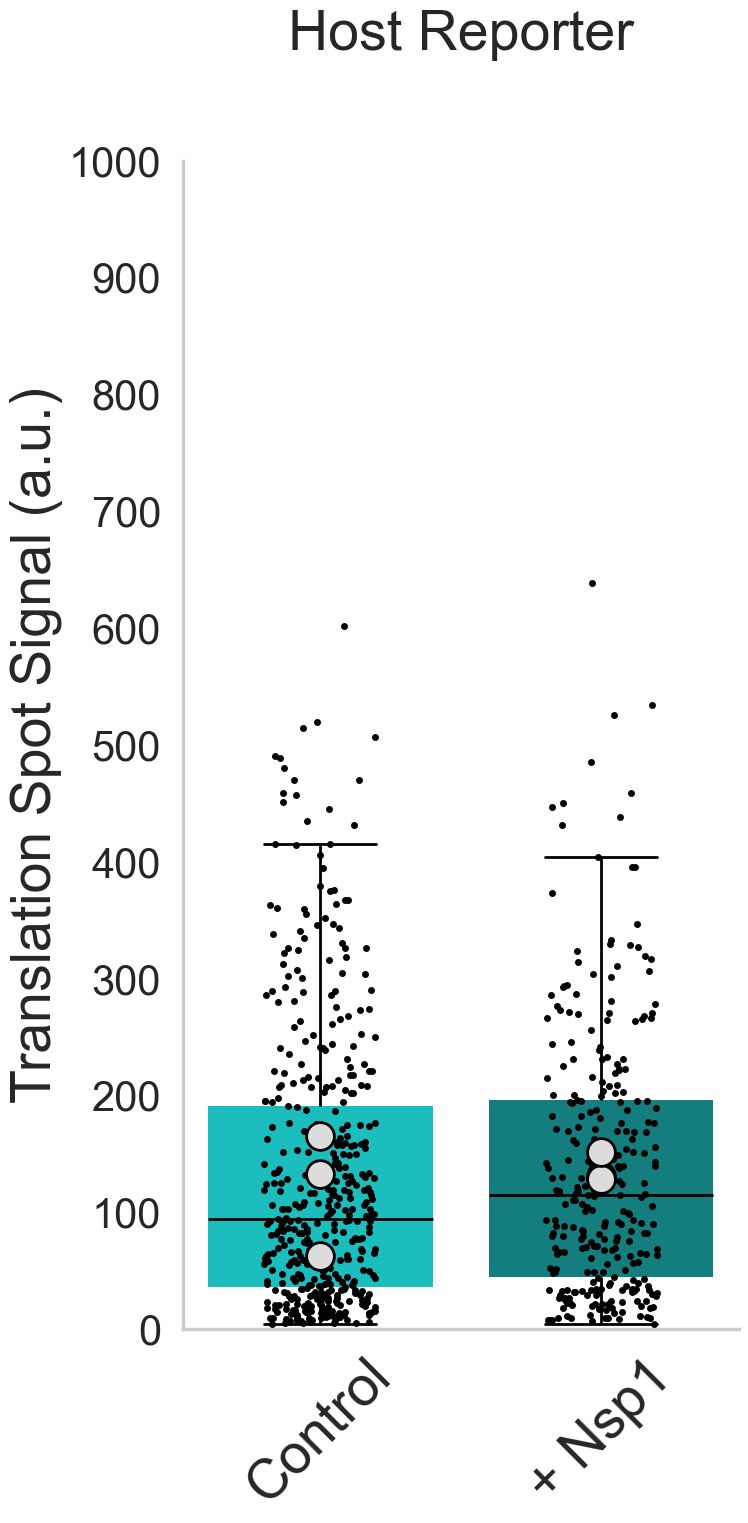

C:\Users\AdamC\AppData\Local\Temp\ipykernel_36528\3946619089.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=345/315, mean_diff=-29.7, p=0.167, ns
            test_group                             contrast       x0    x1  \
0  x|within_hue|paired  [hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1  No Nsp1  Nsp1   

            hue0           hue1  n_pairs       mean0       mean1  \
0  ZNF_SARS_CTRL  ZNF_SARS_CTRL        3  344.619413  314.957836   

   mean_diff_x1_minus_x0    pvalue stars         paired_by  
0             -29.661577  0.166956    ns  Replicate Number  


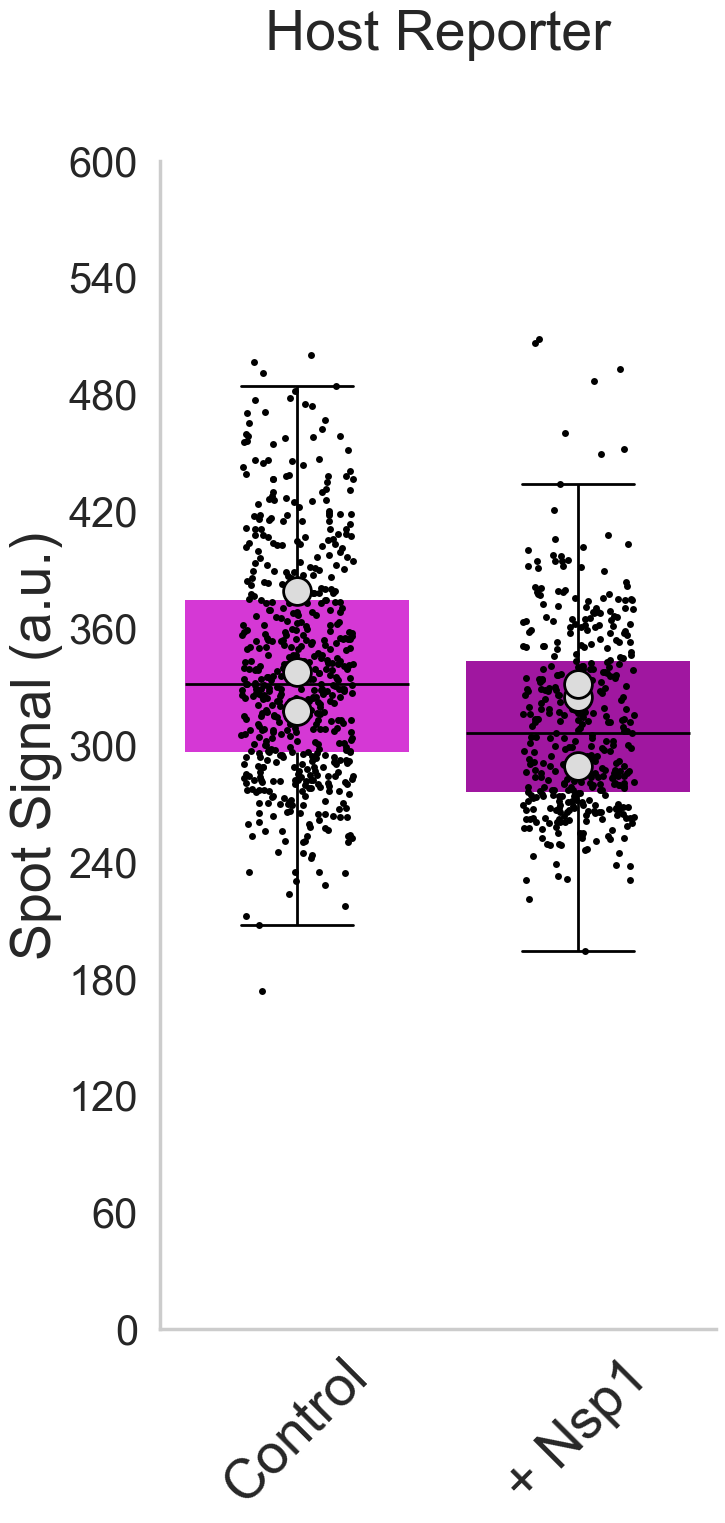

In [ ]:
# Plot 9: KO-ZNF598  SARS CTRL Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = df_avg_sig_no_outliers[df_avg_sig_no_outliers['Experimental Group'] == "ZNF_SARS_CTRL"]
data_translation = data[data['Average Translation Signal'] > 0]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data, average_column = "Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Average Translation Signal", hue="Experimental Group", zorder=10)
ax1.set_title('Host Reporter', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 1000)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Average Translation Signal KO-ZNF598 SARS CTRL.svg")
filename_png_translation = os.path.join(save_directory, "Average Translation Signal KO-ZNF598 SARS CTRL.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Average RNA Signal", data=data, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Average RNA Signal",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Average RNA Signal", hue="Experimental Group", zorder=10)
ax2.set_title('Host Reporter', fontsize=40, pad=80)
ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 600)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)

print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Average RNA Signal KO-ZNF598 SARS CTRL.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Average RNA Signal KO-ZNF598 SARS CTRL.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\277680337.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\277680337.py:31: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=107/119, mean_diff=11.6, p=0.686, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_SARS_CTRL]
No Nsp1: 107 ± 27.4 SEM (n=3)
Nsp1: 119 ± 6.66 SEM (n=3)

                     test_group                             contrast       x0  \
0  x|within_hue|paired_baseline  [hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1  No Nsp1   

     x1           hue0           hue1  n_pairs       mean0       mean1  \
0  Nsp1  ZNF_SARS_CTRL  ZNF_SARS_CTRL        3  106.926997  118.575294   

     pvalue stars         paired_by  mean_diff_x1_minus_x0  
0  0.686259    ns  Replicate Number              11.648297  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\277680337.py:72: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


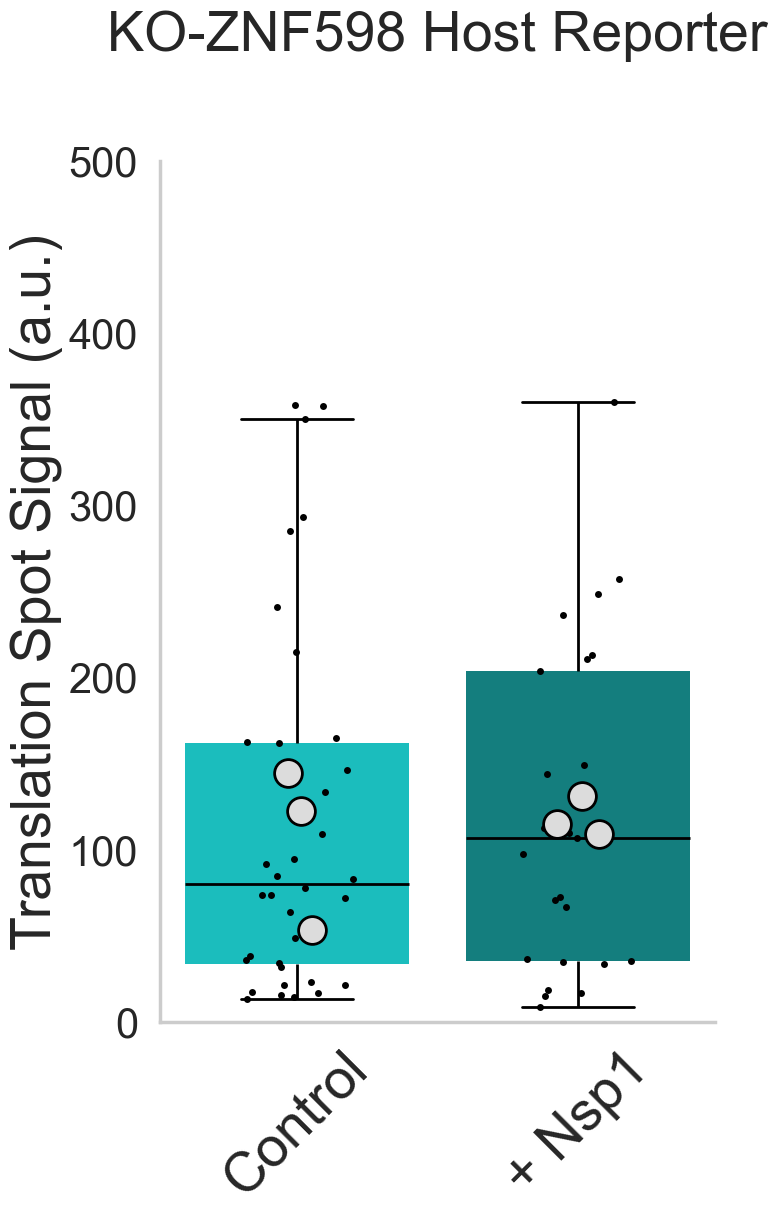

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\277680337.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\277680337.py:80: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),


Across x within hue, paired by replicate:
[hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=345/315, mean_diff=-29.7, p=0.167, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=ZNF_SARS_CTRL]
No Nsp1: 345 ± 18.1 SEM (n=3)
Nsp1: 315 ± 13.1 SEM (n=3)

                     test_group                             contrast       x0  \
0  x|within_hue|paired_baseline  [hue=ZNF_SARS_CTRL] No Nsp1 vs Nsp1  No Nsp1   

     x1           hue0           hue1  n_pairs       mean0       mean1  \
0  Nsp1  ZNF_SARS_CTRL  ZNF_SARS_CTRL        3  344.619413  314.957836   

     pvalue stars         paired_by  mean_diff_x1_minus_x0  
0  0.166956    ns  Replicate Number             -29.661577  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\277680337.py:121: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


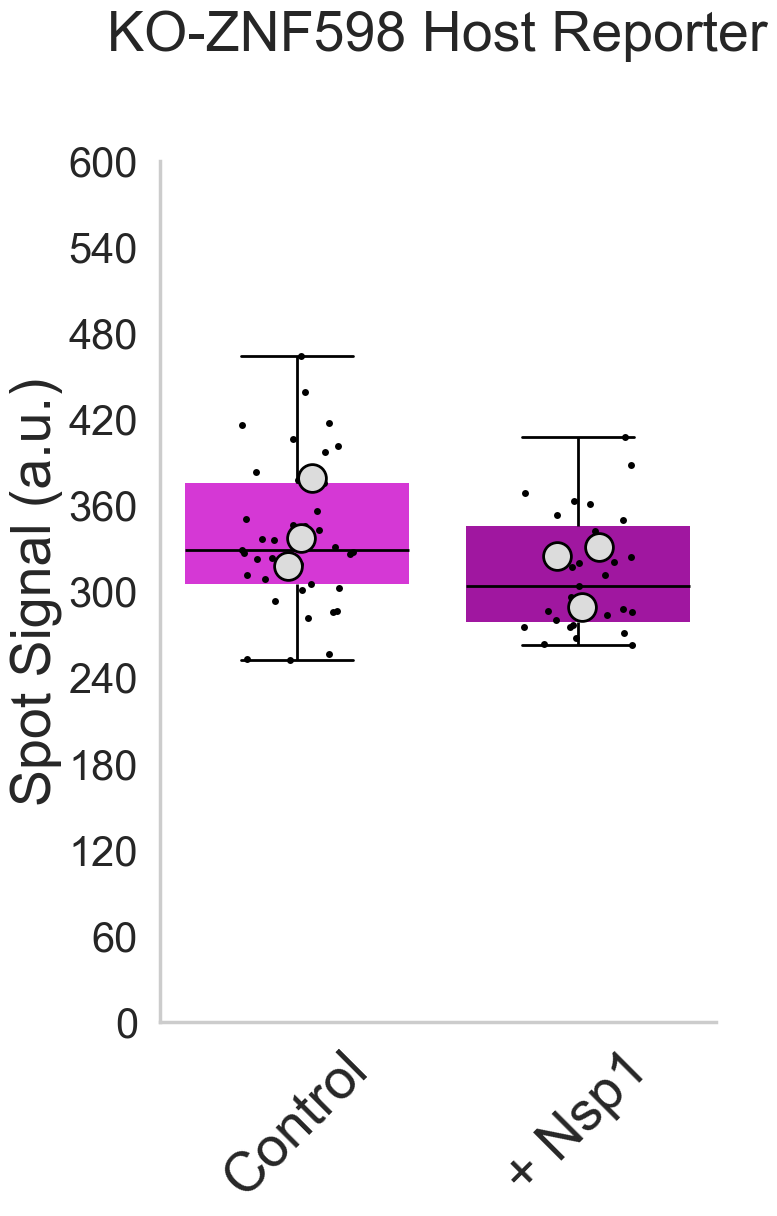

In [156]:
# Plot 9b: ZNF SARS CTRL Average Signal Intensity Translation and RNA

import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data_rna = cell_avg_df_rna[cell_avg_df_rna['Experimental Group'] == "ZNF_SARS_CTRL"]
data_translation = cell_avg_df_trnl[cell_avg_df_trnl['Experimental Group'] == "ZNF_SARS_CTRL"]
superplot_translation = calculate_grouped_average(df = data_translation, average_column = "Cell Average Translation Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
superplot_rna = calculate_grouped_average(df = data_rna, average_column = "Cell Average RNA Signal", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["No Nsp1", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average Translation Signal", data=data_translation, order=order, ax=ax1, palette=blue_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average Translation Signal", 
              data=data_translation, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax1)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Cell Average Translation Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax1.set_title('KO-ZNF598 Host Reporter', fontsize=40,pad=80)
ax1.set_ylabel('Translation Spot Signal (a.u.)', fontsize=40)
ax1.set_ylim(0, 500)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=5))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_paired_ttest_summary(
    data=superplot_translation,
    x="Experimental Type",
    y="Super Cell Average Translation Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res1)

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal ZNF_SARS_CTRL.svg")
filename_png_translation = os.path.join(save_directory + brightness_folder, "Cell Average Translation Signal ZNF_SARS_CTRL.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()

# Plot 2: Average Total RNA Signal
fig2, ax2 = plt.subplots(figsize=(8, 12), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cell Average RNA Signal", data=data_rna, order=order, ax=ax2, palette=magenta_palette, boxprops=dict(linewidth=0),
            whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2),
            medianprops=dict(color="black", linewidth=2), showfliers=False)

sns.stripplot(x="Experimental Type", y="Cell Average RNA Signal",
              data=data_rna, order=order, color="black", alpha = 1, size=5, jitter=0.2, dodge=True, ax=ax2)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cell Average RNA Signal", hue="Experimental Group", zorder=10, jitter = True, jitter_strength = 0.08, random_state = 100)
ax2.set_title('KO-ZNF598 Host Reporter', fontsize=40, pad=80)
ax2.set_ylabel('Spot Signal (a.u.)', fontsize=40)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.set_ylim(0, 600)
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax2.set_xlabel('')
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_paired_ttest_summary(
    data=superplot_rna,
    x="Experimental Type",
    y="Super Cell Average RNA Signal",
    hue="Experimental Group",
    pair_col="Replicate Number",
    order=order,
    hue_order=None,
    compare_x=True,
    compare_hue=False,
    verbose=True
)
print(res2)

# Save the figure for RNA Signal
filename_svg_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal ZNF_SARS_CTRL.svg")
filename_png_rna = os.path.join(save_directory + brightness_folder, "Cell Average RNA Signal ZNF_SARS_CTRL.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for RNA Signal
plt.tight_layout()
plt.show()



Translation intensity cells:


,Experimental Group,Experimental Type,Replicate Number,Cells
0,SARS_3'UTR,No Nsp1,1,5
1,SARS_3'UTR,No Nsp1,2,2
2,SARS_3'UTR,No Nsp1,3,9
3,SARS_3'UTR,Nsp1,1,4
4,SARS_3'UTR,Nsp1,2,3
5,SARS_3'UTR,Nsp1,3,4
6,SARS_5'UTR,No Nsp1,1,7
7,SARS_5'UTR,No Nsp1,2,4
8,SARS_5'UTR,No Nsp1,3,5
9,SARS_5'UTR,Nsp1,1,7



RNA intensity cells:


,Experimental Group,Experimental Type,Replicate Number,Cells
0,SARS_3'UTR,No Nsp1,1,5
1,SARS_3'UTR,No Nsp1,2,2
2,SARS_3'UTR,No Nsp1,3,9
3,SARS_3'UTR,Nsp1,1,4
4,SARS_3'UTR,Nsp1,2,3
5,SARS_3'UTR,Nsp1,3,4
6,SARS_5'UTR,No Nsp1,1,7
7,SARS_5'UTR,No Nsp1,2,4
8,SARS_5'UTR,No Nsp1,3,5
9,SARS_5'UTR,Nsp1,1,7



Across hue within x, paired by replicate:
[x=SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=437/686, mean_diff=249, p=0.0129, *
[x=SARS_5'UTR] No Nsp1 vs Nsp1: n_pairs=3, mean=561/1.39e+03, mean_diff=827, p=0.0968, ns
[x=SARS_3'UTR] No Nsp1 vs Nsp1: n_pairs=3, mean=687/685, mean_diff=-1.88, p=0.991, ns
[x=SARS_5'UTR_3'UTR] No Nsp1 vs Nsp1: n_pairs=3, mean=1.14e+03/1.04e+03, mean_diff=-102, p=0.752, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=No Nsp1]
SARS_CTRL: 437 ± 15.7 SEM (n=3)
SARS_5'UTR: 561 ± 27.3 SEM (n=3)
SARS_3'UTR: 687 ± 85.4 SEM (n=3)
SARS_5'UTR_3'UTR: 1.14e+03 ± 83.3 SEM (n=3)

[hue=Nsp1]
SARS_CTRL: 686 ± 30.5 SEM (n=3)
SARS_5'UTR: 1.39e+03 ± 288 SEM (n=3)
SARS_3'UTR: 685 ± 89.7 SEM (n=3)
SARS_5'UTR_3'UTR: 1.04e+03 ± 243 SEM (n=3)

                     test_group                              contrast  \
0  hue|within_x|paired_baseline         [x=SARS_CTRL] No Nsp1 vs Nsp1   
1  hue|within_x|paired_baseline        [x=SARS_5'UTR] No Nsp1 vs Nsp1   
2  hue|within_x|paired

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\290396359.py:306: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\290396359.py:542: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


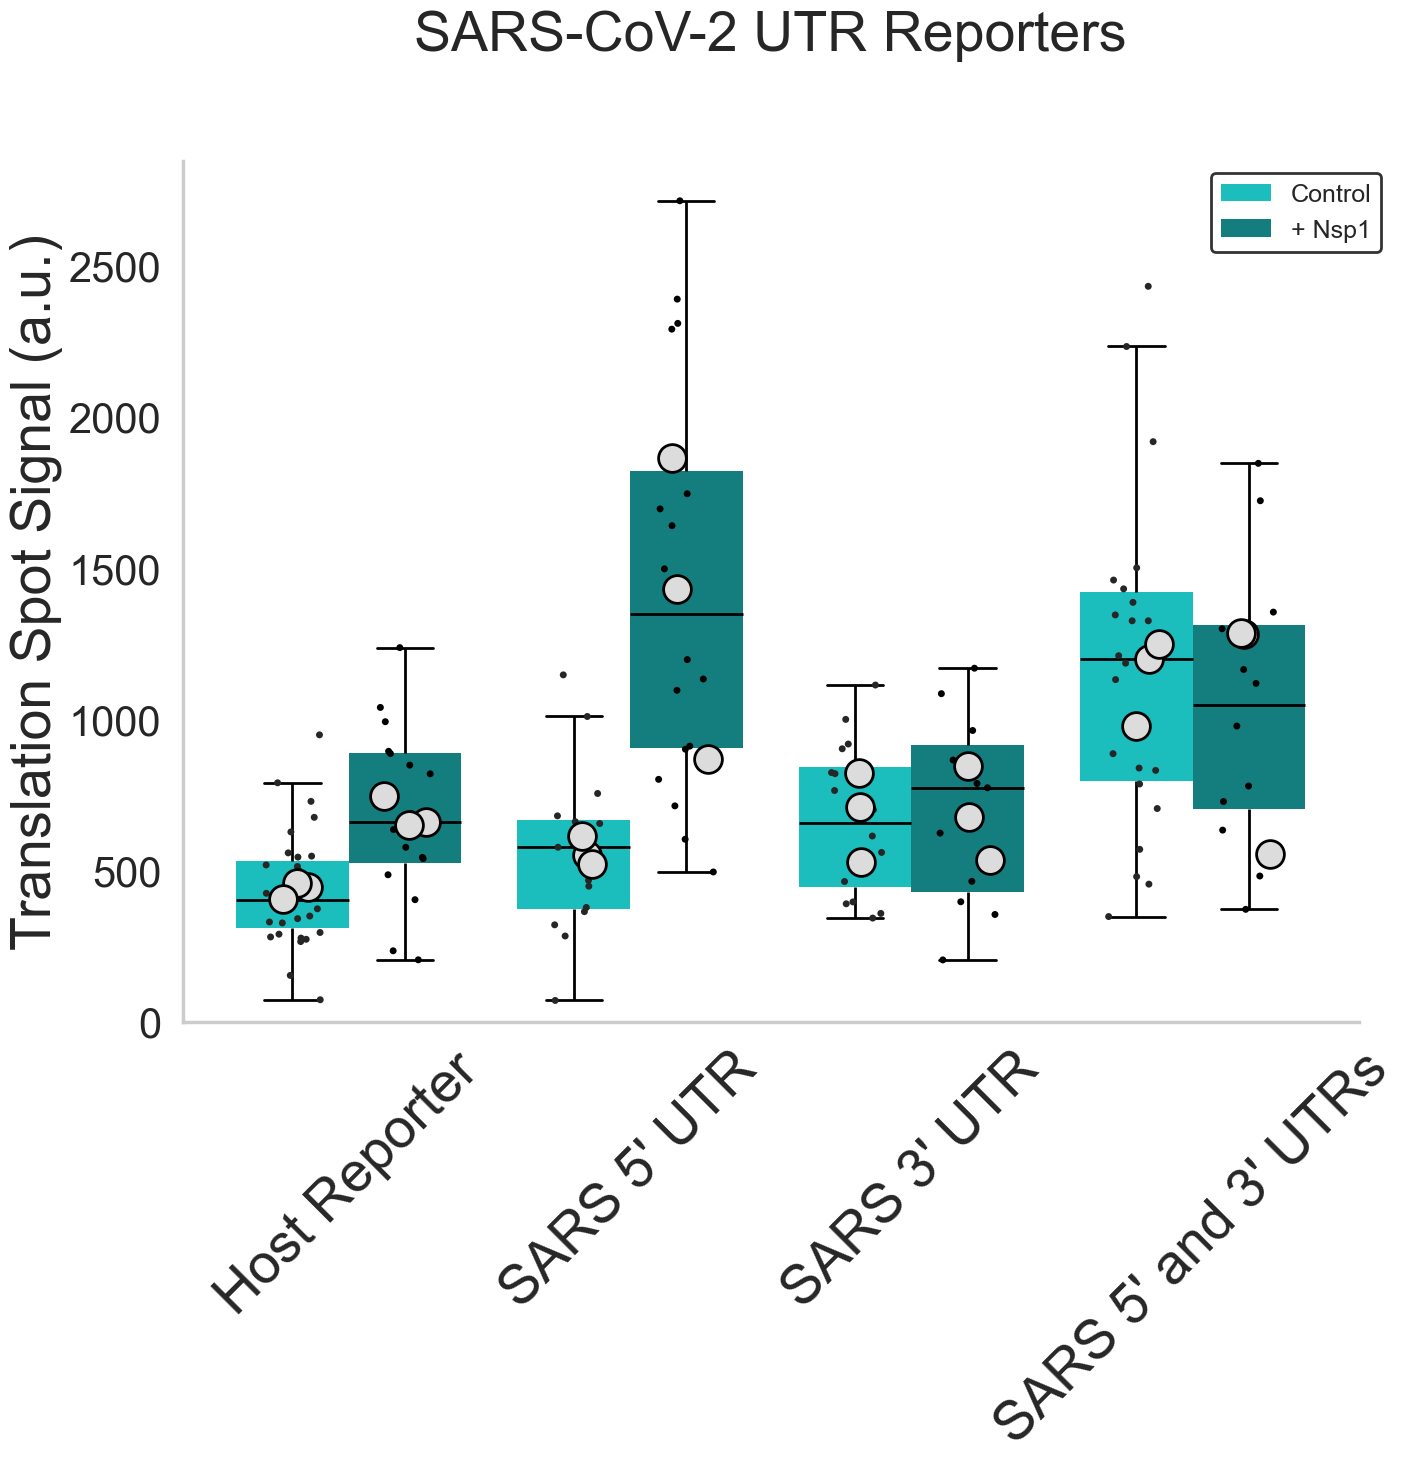

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\290396359.py:628: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(



Across hue within x, paired by replicate:
[x=SARS_CTRL] No Nsp1 vs Nsp1: n_pairs=3, mean=1.61e+03/1.57e+03, mean_diff=-48.7, p=0.411, ns
[x=SARS_5'UTR] No Nsp1 vs Nsp1: n_pairs=3, mean=1.47e+03/1.4e+03, mean_diff=-64.4, p=0.413, ns
[x=SARS_3'UTR] No Nsp1 vs Nsp1: n_pairs=3, mean=1.24e+03/1.46e+03, mean_diff=212, p=0.0699, ns
[x=SARS_5'UTR_3'UTR] No Nsp1 vs Nsp1: n_pairs=3, mean=1.43e+03/1.37e+03, mean_diff=-57.6, p=0.696, ns

MEAN ± SEM ACROSS BIOLOGICAL REPLICATES

[hue=No Nsp1]
SARS_CTRL: 1.61e+03 ± 45 SEM (n=3)
SARS_5'UTR: 1.47e+03 ± 39 SEM (n=3)
SARS_3'UTR: 1.24e+03 ± 53.4 SEM (n=3)
SARS_5'UTR_3'UTR: 1.43e+03 ± 90.5 SEM (n=3)

[hue=Nsp1]
SARS_CTRL: 1.57e+03 ± 30.5 SEM (n=3)
SARS_5'UTR: 1.4e+03 ± 89.2 SEM (n=3)
SARS_3'UTR: 1.46e+03 ± 26.1 SEM (n=3)
SARS_5'UTR_3'UTR: 1.37e+03 ± 139 SEM (n=3)

                     test_group                              contrast  \
0  hue|within_x|paired_baseline         [x=SARS_CTRL] No Nsp1 vs Nsp1   
1  hue|within_x|paired_baseline        [x=SARS_

C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\290396359.py:860: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


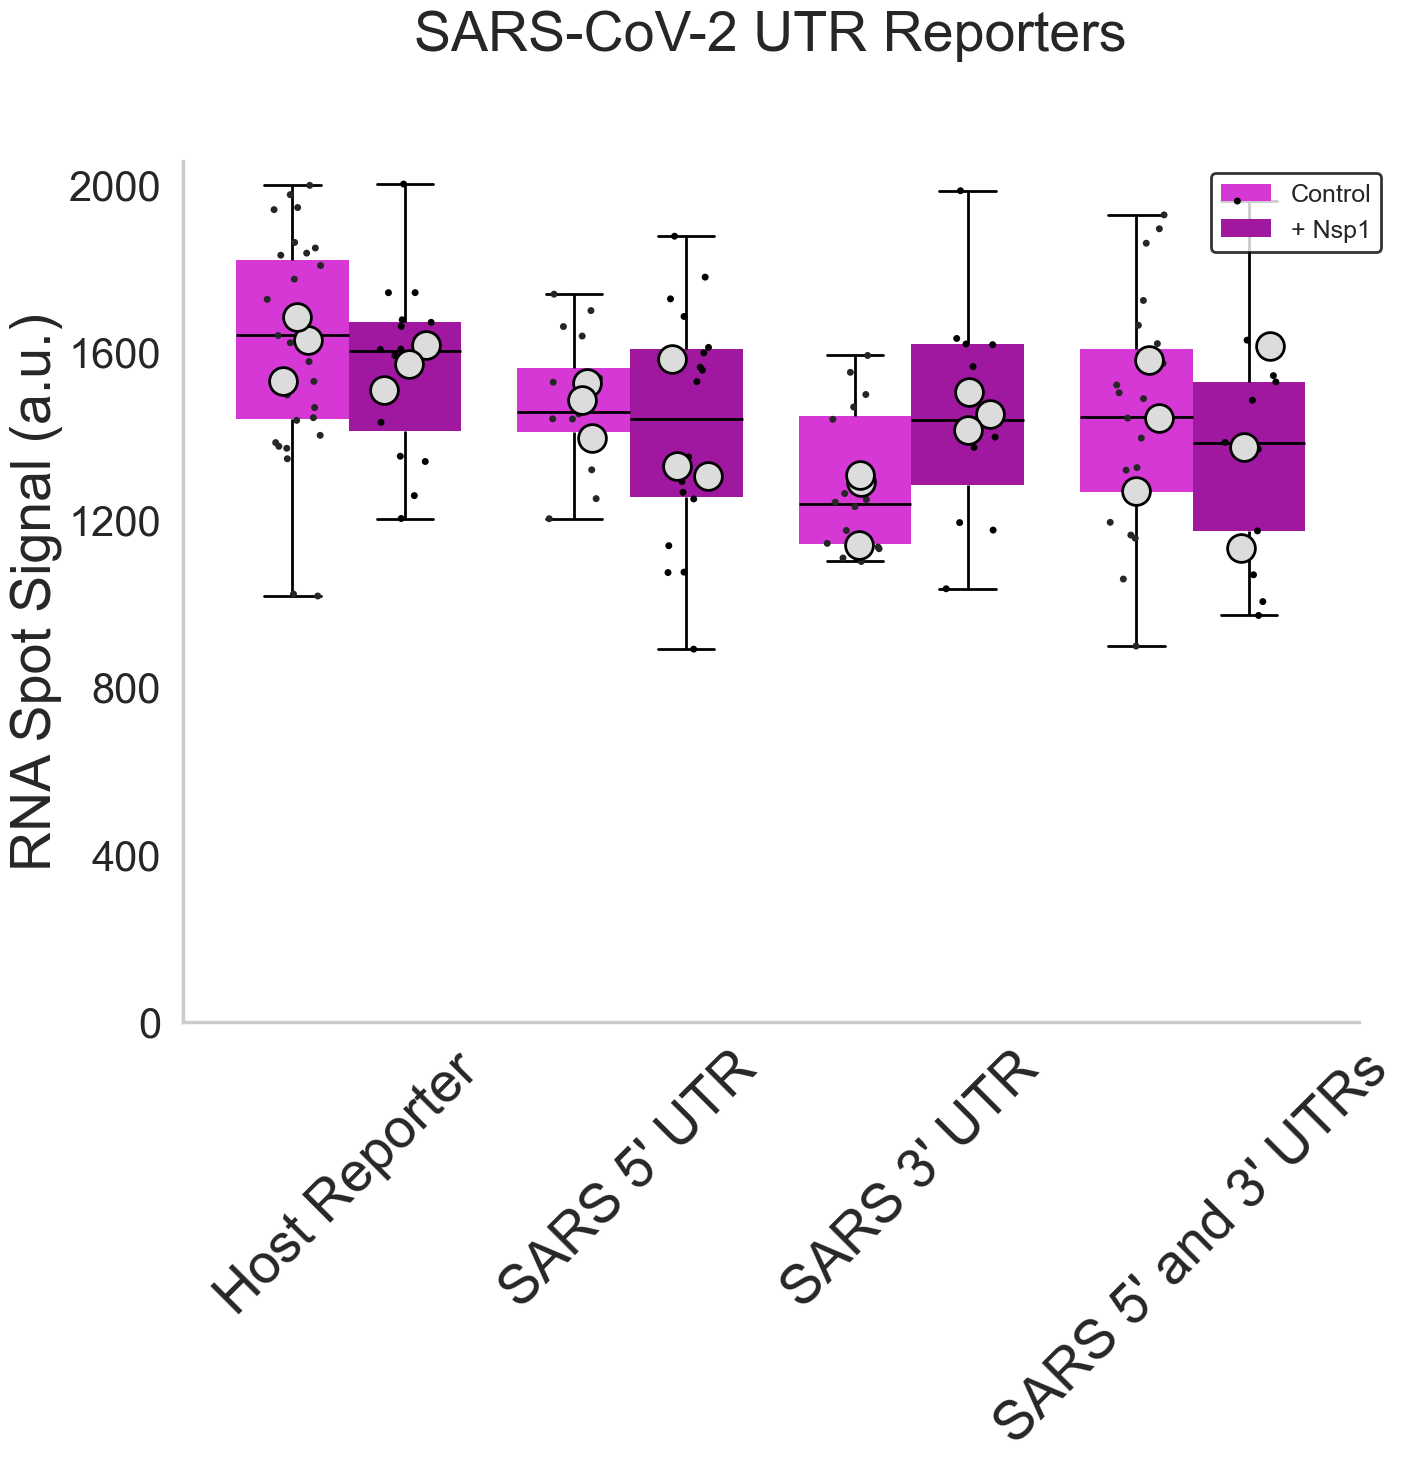

In [213]:
# Plot 10b: ALL SARS-CoV-2 UTR REPORTERS
# ALL SARS-CoV-2 UTR REPORTERS


import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator

sns.set(
    font_scale=1.9
)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)

group_order = [
    "SARS_CTRL",
    "SARS_5'UTR",
    "SARS_3'UTR",
    "SARS_5'UTR_3'UTR",
]


type_order = [
    "No Nsp1",
    "Nsp1",
]


new_labels = [
    "Host Reporter",
    "SARS 5' UTR",
    "SARS 3' UTR",
    "SARS 5' and 3' UTRs",
]


legend_labels = [
    "Control",
    "+ Nsp1",
]


data_translation = (

    cell_avg_df_trnl.loc[

        cell_avg_df_trnl[
            "Experimental Group"
        ].isin(
            group_order
        )

        &

        cell_avg_df_trnl[
            "Experimental Type"
        ].isin(
            type_order
        )

    ]

    .copy()

    .reset_index(
        drop=True
    )
)


data_rna = (

    cell_avg_df_rna.loc[

        cell_avg_df_rna[
            "Experimental Group"
        ].isin(
            group_order
        )

        &

        cell_avg_df_rna[
            "Experimental Type"
        ].isin(
            type_order
        )

    ]

    .copy()

    .reset_index(
        drop=True
    )
)


data_translation[
    "Replicate Number"
] = pd.to_numeric(

    data_translation[
        "Replicate Number"
    ],

    errors="coerce"
)


data_rna[
    "Replicate Number"
] = pd.to_numeric(

    data_rna[
        "Replicate Number"
    ],

    errors="coerce"
)

superplot_translation = calculate_grouped_average(

    df=
        data_translation,

    average_column=
        "Cell Average Translation Signal",

    group_by_columns=[
        "Experimental Group",
        "Experimental Type",
        "Replicate Number",
    ],
)


superplot_rna = calculate_grouped_average(

    df=
        data_rna,

    average_column=
        "Cell Average RNA Signal",

    group_by_columns=[
        "Experimental Group",
        "Experimental Type",
        "Replicate Number",
    ],
)

print(
    "\nTranslation intensity cells:"
)

display(

    data_translation

    .groupby(
        [
            "Experimental Group",
            "Experimental Type",
            "Replicate Number",
        ]
    )

    .size()

    .rename(
        "Cells"
    )

    .reset_index()
)


print(
    "\nRNA intensity cells:"
)

display(

    data_rna

    .groupby(
        [
            "Experimental Group",
            "Experimental Type",
            "Replicate Number",
        ]
    )

    .size()

    .rename(
        "Cells"
    )

    .reset_index()
)


translation_y_max = None

rna_y_max = None


translation_col = (
    "Cell Average Translation Signal"
)


super_translation_col = (
    "Super Cell Average Translation Signal"
)


fig1, ax1 = plt.subplots(

    figsize=(16, 12),

    constrained_layout=True
)


sns.despine(

    fig=fig1,

    top=True,

    right=True,

    left=False,

    bottom=False
)


sns.boxplot(

    x="Experimental Group",

    y=translation_col,

    hue="Experimental Type",

    data=
        data_translation,

    order=
        group_order,

    hue_order=
        type_order,

    ax=ax1,

    palette=
        blue_palette[:2],

    boxprops=dict(
        linewidth=0
    ),

    whiskerprops=dict(
        color="black",
        linewidth=2
    ),

    capprops=dict(
        color="black",
        linewidth=2
    ),

    medianprops=dict(
        color="black",
        linewidth=2
    ),

    showfliers=False,
)


# Save clean boxplot legend handles before adding overlays.
handles1, labels1 = (
    ax1.get_legend_handles_labels()
)


sns.stripplot(

    x="Experimental Group",

    y=translation_col,

    hue="Experimental Type",

    data=
        data_translation,

    order=
        group_order,

    hue_order=
        type_order,

    dodge=True,

    jitter=0.20,

    color="black",

    alpha=1,

    size=5,

    ax=ax1,

    zorder=9,
)


plot_open_circles_with_hue(

    ax1,

    superplot_translation,

    order=
        group_order,

    x=
        "Experimental Group",

    y=
        super_translation_col,

    hue=
        "Experimental Type",

    hue_order=
        type_order,

    zorder=10,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,
)


ax1.set_title(

    "SARS-CoV-2 UTR Reporters",

    fontsize=40,

    pad=80
)


ax1.set_ylabel(

    "Translation Spot Signal (a.u.)",

    fontsize=40
)


ax1.set_xlabel(
    ""
)


ax1.tick_params(

    axis="both",

    which="major",

    labelsize=30
)


ax1.set_xticklabels(

    new_labels,

    fontsize=40,

    rotation=45
)


if translation_y_max is None:

    ax1.set_ylim(
        bottom=0
    )

else:

    ax1.set_ylim(
        0,
        translation_y_max
    )


ax1.yaxis.set_major_locator(

    MaxNLocator(
        nbins=6
    )
)


if ax1.get_legend() is not None:

    ax1.get_legend().remove()


ax1.legend(

    handles1[
        :len(
            type_order
        )
    ],

    legend_labels,

    title=None,

    facecolor="white",

    edgecolor="black",

    fontsize=18,

    loc="upper right",

    bbox_to_anchor=(
        1.03,
        1
    ),
)


res_translation = print_paired_ttest_summary(

    data=
        superplot_translation,

    x=
        "Experimental Group",

    y=
        super_translation_col,

    hue=
        "Experimental Type",

    pair_col=
        "Replicate Number",

    order=
        group_order,

    hue_order=
        type_order,

    compare_x=False,

    compare_hue=True,

    verbose=True,
)


print(
    res_translation
)

filename_svg_translation = os.path.join(

    save_directory
    +
    brightness_folder,

    "Cell Average Translation Signal SARS UTR Reporters.svg"
)


filename_png_translation = os.path.join(

    save_directory
    +
    brightness_folder,

    "Cell Average Translation Signal SARS UTR Reporters.png"
)


fig1.savefig(

    filename_svg_translation,

    format="svg",

    dpi=300
)


fig1.savefig(

    filename_png_translation,

    format="png",

    dpi=300
)


plt.tight_layout()

plt.show()


rna_col = (
    "Cell Average RNA Signal"
)


super_rna_col = (
    "Super Cell Average RNA Signal"
)


fig2, ax2 = plt.subplots(

    figsize=(16, 12),

    constrained_layout=True
)


sns.despine(

    fig=fig2,

    top=True,

    right=True,

    left=False,

    bottom=False
)

sns.boxplot(

    x="Experimental Group",

    y=rna_col,

    hue="Experimental Type",

    data=
        data_rna,

    order=
        group_order,

    hue_order=
        type_order,

    ax=ax2,

    palette=
        magenta_palette[:2],

    boxprops=dict(
        linewidth=0
    ),

    whiskerprops=dict(
        color="black",
        linewidth=2
    ),

    capprops=dict(
        color="black",
        linewidth=2
    ),

    medianprops=dict(
        color="black",
        linewidth=2
    ),

    showfliers=False,
)


# Save clean boxplot legend handles.
handles2, labels2 = (
    ax2.get_legend_handles_labels()
)

sns.stripplot(

    x="Experimental Group",

    y=rna_col,

    hue="Experimental Type",

    data=
        data_rna,

    order=
        group_order,

    hue_order=
        type_order,

    dodge=True,

    jitter=0.20,

    color="black",

    alpha=1,

    size=5,

    ax=ax2,

    zorder=9,
)

plot_open_circles_with_hue(

    ax2,

    superplot_rna,

    order=
        group_order,

    x=
        "Experimental Group",

    y=
        super_rna_col,

    hue=
        "Experimental Type",

    hue_order=
        type_order,

    zorder=10,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,
)

ax2.set_title(

    "SARS-CoV-2 UTR Reporters",

    fontsize=40,

    pad=80
)


ax2.set_ylabel(

    "RNA Spot Signal (a.u.)",

    fontsize=40
)


ax2.set_xlabel(
    ""
)


ax2.tick_params(

    axis="both",

    which="major",

    labelsize=30
)


ax2.set_xticklabels(

    new_labels,

    fontsize=40,

    rotation=45
)


if rna_y_max is None:

    ax2.set_ylim(
        bottom=0
    )

else:

    ax2.set_ylim(
        0,
        rna_y_max
    )


ax2.yaxis.set_major_locator(

    MaxNLocator(
        nbins=6
    )
)

if ax2.get_legend() is not None:

    ax2.get_legend().remove()


ax2.legend(

    handles2[
        :len(
            type_order
        )
    ],

    legend_labels,

    title=None,

    facecolor="white",

    edgecolor="black",

    fontsize=18,

    loc="upper right",

    bbox_to_anchor=(
        1.03,
        1
    ),
)

res_rna = print_paired_ttest_summary(

    data=
        superplot_rna,

    x=
        "Experimental Group",

    y=
        super_rna_col,

    hue=
        "Experimental Type",

    pair_col=
        "Replicate Number",

    order=
        group_order,

    hue_order=
        type_order,

    compare_x=False,

    compare_hue=True,

    verbose=True,
)


print(
    res_rna
)

filename_svg_rna = os.path.join(

    save_directory
    +
    brightness_folder,

    "Cell Average RNA Signal SARS UTR Reporters.svg"
)


filename_png_rna = os.path.join(

    save_directory
    +
    brightness_folder,

    "Cell Average RNA Signal SARS UTR Reporters.png"
)


fig2.savefig(

    filename_svg_rna,

    format="svg",

    dpi=300
)


fig2.savefig(

    filename_png_rna,

    format="png",

    dpi=300
)


plt.tight_layout()

plt.show()

## Ribosome Occupancy

### Data Prep

In [85]:
# Ribosome occupancy calibration: settings and replicate-level uncertainty
# ======================================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# General settings
# ------------------------------------------------------------

SIGNAL_COLUMN = "Average Translation Signal"

# Absolute scale from the published KDM5B calibration.
#
# The replicate-balanced mean KDM5B signal measured in THIS
# dataset is assigned to 14.6 ribosomes.
REFERENCE_GROUP = "KDM5B"
REFERENCE_TYPE = "No Nsp1"
REFERENCE_RIBOSOME_OCCUPANCY = 14.6


# ------------------------------------------------------------
# SARS imaging-batch bridge
# ------------------------------------------------------------

SARS_ANCHOR_GROUP = "SARS_CTRL"
SARS_ANCHOR_TYPE = "NoCTD Nsp1"

MAIN_SARS_BRIDGE_GROUP = "SARS_CTRL"
MAIN_SARS_BRIDGE_TYPE = "No Nsp1"


MAIN_SARS_GROUPS = [
    "SARS_CTRL",
    "SARS_3'UTR",
    "SARS_5'UTR",
    "SARS_5'UTR_3'UTR",
]


EXCLUDED_GROUPS = [
    "Normalization_SARS_CTRL",
]


CALIBRATION_LOCATION = None

INCLUDE_ZERO_SIGNAL = False


# ------------------------------------------------------------
# Validate input dataframe
# ------------------------------------------------------------

required_columns = [
    "Experimental Group",
    "Experimental Type",
    "Replicate Number",
    SIGNAL_COLUMN,
]

missing_columns = [
    column
    for column in required_columns
    if column not in average_sig_df.columns
]

if missing_columns:

    raise KeyError(
        "average_sig_df is missing required columns: "
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# Create working dataframe
# ------------------------------------------------------------

ribosome_occupancy_df = (
    average_sig_df
    .copy()
)


ribosome_occupancy_df = (
    ribosome_occupancy_df.loc[
        ~ribosome_occupancy_df[
            "Experimental Group"
        ]
        .isin(
            EXCLUDED_GROUPS
        )
    ]
    .copy()
)


ribosome_occupancy_df[
    SIGNAL_COLUMN
] = pd.to_numeric(
    ribosome_occupancy_df[
        SIGNAL_COLUMN
    ],
    errors="coerce",
)


ribosome_occupancy_df = (
    ribosome_occupancy_df.loc[
        np.isfinite(
            ribosome_occupancy_df[
                SIGNAL_COLUMN
            ]
        )
    ]
    .copy()
)


if INCLUDE_ZERO_SIGNAL:

    ribosome_occupancy_df = (
        ribosome_occupancy_df.loc[
            ribosome_occupancy_df[
                SIGNAL_COLUMN
            ]
            >= 0
        ]
        .copy()
    )

else:

    ribosome_occupancy_df = (
        ribosome_occupancy_df.loc[
            ribosome_occupancy_df[
                SIGNAL_COLUMN
            ]
            > 0
        ]
        .copy()
    )


# ------------------------------------------------------------
# Replicate-balanced signal helper
# ------------------------------------------------------------

def get_replicate_balanced_signal_stats(
    data,
    experimental_group,
    experimental_type,
    signal_column=SIGNAL_COLUMN,
    location=None,
):
    """
    Calculate signal statistics while giving each biological
    replicate equal weight.

    First:
        mean signal within each biological replicate

    Then:
        mean, SD, and SEM across replicate means
    """

    condition_mask = (
        data[
            "Experimental Group"
        ]
        .eq(
            experimental_group
        )
        &
        data[
            "Experimental Type"
        ]
        .eq(
            experimental_type
        )
    )


    if location is not None:

        if "Location" not in data.columns:

            raise KeyError(
                "CALIBRATION_LOCATION was specified, but "
                "'Location' is not present."
            )

        condition_mask &= (
            data[
                "Location"
            ]
            .eq(
                location
            )
        )


    condition_data = (
        data.loc[
            condition_mask
        ]
        .copy()
    )


    if condition_data.empty:

        raise ValueError(
            "No rows matched:\n"
            f"{experimental_group} / "
            f"{experimental_type}"
        )


    replicate_means = (
        condition_data
        .groupby(
            "Replicate Number",
            dropna=False,
        )[
            signal_column
        ]
        .mean()
        .dropna()
    )


    n_replicates = int(
        replicate_means.shape[0]
    )


    overall_mean = float(
        replicate_means.mean()
    )


    if n_replicates > 1:

        replicate_sd = float(
            replicate_means.std(
                ddof=1
            )
        )

        replicate_sem = float(
            replicate_sd
            / np.sqrt(
                n_replicates
            )
        )

    else:

        replicate_sd = np.nan
        replicate_sem = np.nan


    if (
        not np.isfinite(
            overall_mean
        )
        or overall_mean <= 0
    ):

        raise ValueError(
            "Invalid replicate-balanced mean for "
            f"{experimental_group} / "
            f"{experimental_type}: "
            f"{overall_mean}"
        )


    return {
        "mean": overall_mean,
        "sd": replicate_sd,
        "sem": replicate_sem,
        "n_replicates": n_replicates,
        "replicate_means": replicate_means,
    }


print(
    "Rows retained for ribosome occupancy analysis: "
    f"{len(ribosome_occupancy_df):,}"
)

print(
    f"Excluded groups: {EXCLUDED_GROUPS}"
)

Rows retained for ribosome occupancy analysis: 6,148
Excluded groups: ['Normalization_SARS_CTRL']


In [86]:
# Absolute KDM5B calibration and SARS bridge with replicate-level SEM
# ==================================================================


# ============================================================
# 1. KDM5B absolute reference
# ============================================================

reference_stats = (
    get_replicate_balanced_signal_stats(
        data=ribosome_occupancy_df,
        experimental_group=REFERENCE_GROUP,
        experimental_type=REFERENCE_TYPE,
        location=CALIBRATION_LOCATION,
    )
)


reference_mean_signal = (
    reference_stats[
        "mean"
    ]
)

reference_signal_sem = (
    reference_stats[
        "sem"
    ]
)

reference_replicate_signals = (
    reference_stats[
        "replicate_means"
    ]
)


# ------------------------------------------------------------
# Mean KDM5B signal corresponds to 14.6 ribosomes
# ------------------------------------------------------------

ribosomes_per_signal_unit = (
    REFERENCE_RIBOSOME_OCCUPANCY
    / reference_mean_signal
)


# ------------------------------------------------------------
# Convert each KDM5B replicate mean to ribosomes.
#
# Their mean is exactly 14.6 by definition.
# Their spread determines the calibration SEM.
# ------------------------------------------------------------

reference_replicate_occupancies = (
    REFERENCE_RIBOSOME_OCCUPANCY
    * reference_replicate_signals
    / reference_mean_signal
)


if (
    len(
        reference_replicate_occupancies
    )
    > 1
):

    REFERENCE_RIBOSOME_OCCUPANCY_SEM = float(

        reference_replicate_occupancies.std(
            ddof=1
        )
        / np.sqrt(
            len(
                reference_replicate_occupancies
            )
        )
    )

else:

    REFERENCE_RIBOSOME_OCCUPANCY_SEM = np.nan


reference_relative_sem = (
    REFERENCE_RIBOSOME_OCCUPANCY_SEM
    / REFERENCE_RIBOSOME_OCCUPANCY
)


# ============================================================
# 2. SARS_CTRL / NoCTD anchor
# ============================================================

sars_anchor_stats = (
    get_replicate_balanced_signal_stats(
        data=ribosome_occupancy_df,
        experimental_group=SARS_ANCHOR_GROUP,
        experimental_type=SARS_ANCHOR_TYPE,
        location=CALIBRATION_LOCATION,
    )
)


sars_anchor_mean_signal = (
    sars_anchor_stats[
        "mean"
    ]
)

sars_anchor_signal_sem = (
    sars_anchor_stats[
        "sem"
    ]
)

sars_anchor_replicate_signals = (
    sars_anchor_stats[
        "replicate_means"
    ]
)


sars_anchor_occupancy = (
    REFERENCE_RIBOSOME_OCCUPANCY
    * sars_anchor_mean_signal
    / reference_mean_signal
)


sars_anchor_relative_signal_sem = (
    sars_anchor_signal_sem
    / sars_anchor_mean_signal
)


# ------------------------------------------------------------
# Propagate:
#
# N_anchor = N_KDM5B * I_anchor / I_KDM5B
# ------------------------------------------------------------

sars_anchor_occupancy_sem = (
    sars_anchor_occupancy
    * np.sqrt(
        reference_relative_sem ** 2
        +
        sars_anchor_relative_signal_sem ** 2
    )
)


# ============================================================
# 3. Main SARS imaging-batch bridge
# ============================================================

main_sars_bridge_stats = (
    get_replicate_balanced_signal_stats(
        data=ribosome_occupancy_df,
        experimental_group=MAIN_SARS_BRIDGE_GROUP,
        experimental_type=MAIN_SARS_BRIDGE_TYPE,
        location=CALIBRATION_LOCATION,
    )
)


main_sars_bridge_signal = (
    main_sars_bridge_stats[
        "mean"
    ]
)

main_sars_bridge_signal_sem = (
    main_sars_bridge_stats[
        "sem"
    ]
)

main_sars_bridge_replicate_signals = (
    main_sars_bridge_stats[
        "replicate_means"
    ]
)


main_sars_correction_factor = (
    sars_anchor_mean_signal
    / main_sars_bridge_signal
)


main_sars_bridge_relative_signal_sem = (
    main_sars_bridge_signal_sem
    / main_sars_bridge_signal
)


# ------------------------------------------------------------
# Error in bridge correction factor
#
# C = I_anchor / I_bridge
# ------------------------------------------------------------

main_sars_correction_factor_sem = (
    main_sars_correction_factor
    * np.sqrt(
        sars_anchor_relative_signal_sem ** 2
        +
        main_sars_bridge_relative_signal_sem ** 2
    )
)


# ============================================================
# Report calibration
# ============================================================

print(
    "Ribosome occupancy calibration"
)

print(
    "=============================="
)


print(
    f"\nKDM5B reference:\n"
    f"  {REFERENCE_RIBOSOME_OCCUPANCY:.2f} "
    f"± {REFERENCE_RIBOSOME_OCCUPANCY_SEM:.2f} ribosomes"
)


print(
    f"\nKDM5B mean signal:\n"
    f"  {reference_mean_signal:.3f} "
    f"± {reference_signal_sem:.3f} SEM"
)


print(
    f"\nRelative KDM5B calibration SEM:\n"
    f"  {100 * reference_relative_sem:.2f}%"
)


print(
    f"\nSARS_CTRL NoCTD anchor occupancy:\n"
    f"  {sars_anchor_occupancy:.2f} "
    f"± {sars_anchor_occupancy_sem:.2f} ribosomes"
)


print(
    f"\nMain SARS correction factor:\n"
    f"  {main_sars_correction_factor:.4f} "
    f"± {main_sars_correction_factor_sem:.4f}"
)


print(
    "\nKDM5B signal by replicate:"
)

print(
    reference_replicate_signals
    .round(3)
    .to_string()
)


print(
    "\nKDM5B inferred occupancy by replicate:"
)

print(
    reference_replicate_occupancies
    .round(3)
    .to_string()
)

Ribosome occupancy calibration

KDM5B reference:
  14.60 ± 1.09 ribosomes

KDM5B mean signal:
  847.771 ± 63.100 SEM

Relative KDM5B calibration SEM:
  7.44%

SARS_CTRL NoCTD anchor occupancy:
  8.59 ± 0.93 ribosomes

Main SARS correction factor:
  1.0758 ± 0.0855

KDM5B signal by replicate:
Replicate Number
1.0    875.957
2.0    940.209
3.0    727.146

KDM5B inferred occupancy by replicate:
Replicate Number
1.0    15.085
2.0    16.192
3.0    12.523


In [87]:
# Apply calibration, summarize biological replicates, and export HT reference
# ===========================================================================

corrected_occupancy_df = (
    ribosome_occupancy_df
    .copy()
)


# ============================================================
# Imaging-batch correction
# ============================================================

corrected_occupancy_df[
    "Imaging Batch"
] = (
    "KDM5B-calibrated / unchanged"
)

corrected_occupancy_df[
    "Batch Correction Factor"
] = 1.0


main_sars_mask = (
    corrected_occupancy_df[
        "Experimental Group"
    ]
    .isin(
        MAIN_SARS_GROUPS
    )
    &
    ~corrected_occupancy_df[
        "Experimental Type"
    ]
    .eq(
        SARS_ANCHOR_TYPE
    )
)


corrected_occupancy_df.loc[
    main_sars_mask,
    "Imaging Batch",
] = (
    "Main SARS imaging batch"
)


corrected_occupancy_df.loc[
    main_sars_mask,
    "Batch Correction Factor",
] = (
    main_sars_correction_factor
)


# ============================================================
# Convert fluorescence to ribosomes
# ============================================================

corrected_occupancy_df[
    "Uncorrected Estimated Ribosomes"
] = (
    corrected_occupancy_df[
        SIGNAL_COLUMN
    ]
    * ribosomes_per_signal_unit
)


corrected_occupancy_df[
    "Batch-Corrected Translation Signal"
] = (
    corrected_occupancy_df[
        SIGNAL_COLUMN
    ]
    * corrected_occupancy_df[
        "Batch Correction Factor"
    ]
)


corrected_occupancy_df[
    "Estimated Ribosomes"
] = (
    corrected_occupancy_df[
        "Batch-Corrected Translation Signal"
    ]
    * ribosomes_per_signal_unit
)


# ============================================================
# One mean per biological replicate
# ============================================================

replicate_ribosome_summary = (
    corrected_occupancy_df
    .groupby(
        [
            "Experimental Group",
            "Experimental Type",
            "Replicate Number",
        ],
        dropna=False,
        as_index=False,
    )
    .agg(
        Mean_Uncorrected_Ribosomes=(
            "Uncorrected Estimated Ribosomes",
            "mean",
        ),

        Mean_Corrected_Ribosomes=(
            "Estimated Ribosomes",
            "mean",
        ),

        Mean_Correction_Factor=(
            "Batch Correction Factor",
            "mean",
        ),

        Number_of_Rows=(
            "Estimated Ribosomes",
            "size",
        ),
    )
)


# ============================================================
# Biological-replicate summary
# ============================================================

ribosome_summary = (
    replicate_ribosome_summary
    .groupby(
        [
            "Experimental Group",
            "Experimental Type",
        ],
        dropna=False,
        as_index=False,
    )
    .agg(
        Uncorrected_Average_Ribosomes=(
            "Mean_Uncorrected_Ribosomes",
            "mean",
        ),

        Average_Ribosomes=(
            "Mean_Corrected_Ribosomes",
            "mean",
        ),

        SD_Ribosomes=(
            "Mean_Corrected_Ribosomes",
            "std",
        ),

        Number_of_Replicates=(
            "Replicate Number",
            "nunique",
        ),

        Correction_Factor=(
            "Mean_Correction_Factor",
            "mean",
        ),
    )
)


ribosome_summary[
    "SEM_Ribosomes"
] = (
    ribosome_summary[
        "SD_Ribosomes"
    ]
    / np.sqrt(
        ribosome_summary[
            "Number_of_Replicates"
        ]
    )
)


# ============================================================
# Shared calibration uncertainty
# ============================================================

def shared_calibration_relative_sem(
    experimental_group,
    experimental_type,
):

    group = str(
        experimental_group
    )

    experimental_type = str(
        experimental_type
    )


    # --------------------------------------------------------
    # KDM5B / No Nsp1 defines the calibration.
    #
    # Its replicate SEM already IS the calibration SEM.
    # Do not add it a second time.
    # --------------------------------------------------------

    if (
        group
        == str(
            REFERENCE_GROUP
        )
        and
        experimental_type
        == str(
            REFERENCE_TYPE
        )
    ):

        return 0.0


    # --------------------------------------------------------
    # Main SARS imaging batch
    # --------------------------------------------------------

    if (
        group
        in {
            str(value)
            for value
            in MAIN_SARS_GROUPS
        }
        and
        experimental_type
        != str(
            SARS_ANCHOR_TYPE
        )
    ):

        # SARS_CTRL / No Nsp1 is the bridge condition itself.
        # Its own replicate variability is already represented
        # by SEM_Ribosomes, so bridge variability is not added
        # twice.
        if (
            group
            == str(
                MAIN_SARS_BRIDGE_GROUP
            )
            and
            experimental_type
            == str(
                MAIN_SARS_BRIDGE_TYPE
            )
        ):

            return float(
                np.sqrt(
                    reference_relative_sem ** 2
                    +
                    sars_anchor_relative_signal_sem ** 2
                )
            )


        return float(
            np.sqrt(
                reference_relative_sem ** 2
                +
                sars_anchor_relative_signal_sem ** 2
                +
                main_sars_bridge_relative_signal_sem ** 2
            )
        )


    # --------------------------------------------------------
    # Everything else is directly calibrated to KDM5B
    # --------------------------------------------------------

    return float(
        reference_relative_sem
    )


ribosome_summary[
    "Shared_Calibration_Relative_SEM"
] = (
    ribosome_summary.apply(
        lambda row:
        shared_calibration_relative_sem(
            row[
                "Experimental Group"
            ],
            row[
                "Experimental Type"
            ],
        ),
        axis=1,
    )
)


ribosome_summary[
    "Shared_Calibration_SEM_Ribosomes"
] = (
    ribosome_summary[
        "Average_Ribosomes"
    ]
    * ribosome_summary[
        "Shared_Calibration_Relative_SEM"
    ]
)


# ============================================================
# Total propagated SEM
#
# Biological replicate SEM and shared calibration SEM are
# independent and therefore combined in quadrature.
# ============================================================

ribosome_summary[
    "Propagated_SEM_Ribosomes"
] = np.sqrt(
    ribosome_summary[
        "SEM_Ribosomes"
    ]
    .fillna(0.0) ** 2
    +
    ribosome_summary[
        "Shared_Calibration_SEM_Ribosomes"
    ]
    .fillna(0.0) ** 2
)


ribosome_summary = (
    ribosome_summary
    .sort_values(
        [
            "Experimental Group",
            "Experimental Type",
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# Select the value used by the HT notebook
# ============================================================

HT_REFERENCE_SOURCE_GROUP = (
    "SARS_CTRL"
)

HT_REFERENCE_SOURCE_TYPE = (
    "No Nsp1"
)


ht_reference_row = (
    ribosome_summary.loc[
        ribosome_summary[
            "Experimental Group"
        ]
        .eq(
            HT_REFERENCE_SOURCE_GROUP
        )
        &
        ribosome_summary[
            "Experimental Type"
        ]
        .eq(
            HT_REFERENCE_SOURCE_TYPE
        )
    ]
)


if len(
    ht_reference_row
) != 1:

    raise ValueError(
        "Could not uniquely identify the HT reference condition:\n"
        f"{HT_REFERENCE_SOURCE_GROUP} / "
        f"{HT_REFERENCE_SOURCE_TYPE}"
    )


HT_REFERENCE_RIBOSOME_OCCUPANCY = float(
    ht_reference_row[
        "Average_Ribosomes"
    ]
    .iloc[0]
)


HT_REFERENCE_RIBOSOME_OCCUPANCY_SEM = float(
    ht_reference_row[
        "Propagated_SEM_Ribosomes"
    ]
    .iloc[0]
)


# ============================================================
# Output values to transfer
# ============================================================

print(
    "\nValue to copy into the tethered HT notebook"
)

print(
    "==========================================="
)


print(
    "REFERENCE_RIBOSOME_OCCUPANCY = "
    f"{HT_REFERENCE_RIBOSOME_OCCUPANCY:.6f}"
)


print(
    "REFERENCE_RIBOSOME_OCCUPANCY_SEM = "
    f"{HT_REFERENCE_RIBOSOME_OCCUPANCY_SEM:.6f}"
)


print(
    "\nFull occupancy summary"
)


display(
    ribosome_summary[
        [
            "Experimental Group",
            "Experimental Type",
            "Number_of_Replicates",
            "Average_Ribosomes",
            "SEM_Ribosomes",
            "Shared_Calibration_SEM_Ribosomes",
            "Propagated_SEM_Ribosomes",
        ]
    ]
    .round(3)
)


Value to copy into the tethered HT notebook
REFERENCE_RIBOSOME_OCCUPANCY = 8.591010
REFERENCE_RIBOSOME_OCCUPANCY_SEM = 0.935213

Full occupancy summary


,Experimental Group,Experimental Type,Number_of_Replicates,Average_Ribosomes,SEM_Ribosomes,Shared_Calibration_SEM_Ribosomes,Propagated_SEM_Ribosomes
0,BoxB_IRES,No Nsp1,3,4.181,0.475,0.311,0.568
1,BoxB_IRES,Nsp1,3,1.165,0.087,0.087,0.123
2,Emi_KDM5B,No Nsp1,4,1.839,0.387,0.137,0.411
3,Emi_KDM5B,NoCTD Nsp1,4,2.041,0.252,0.152,0.295
4,Emi_KDM5B,Nsp1,4,2.760,0.591,0.205,0.625
5,KDM5B,No Nsp1,3,14.600,1.087,0.000,1.087
6,KDM5B,Nsp1,3,15.369,2.269,1.144,2.541
7,NORAD,No Nsp1,1,2.312,NaN,0.172,0.172
8,NORAD,NoCTD Nsp1,1,2.160,NaN,0.161,0.161
9,NORAD,Nsp1,1,3.167,NaN,0.236,0.236


,Reporter,Mean,SD,SEM,N
0,KDM5B Reference,14.60000,1.882194,1.086685,3
1,Host Reporter,8.59101,1.158834,0.669053,3


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\353992617.py:140: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\353992617.py:140: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(


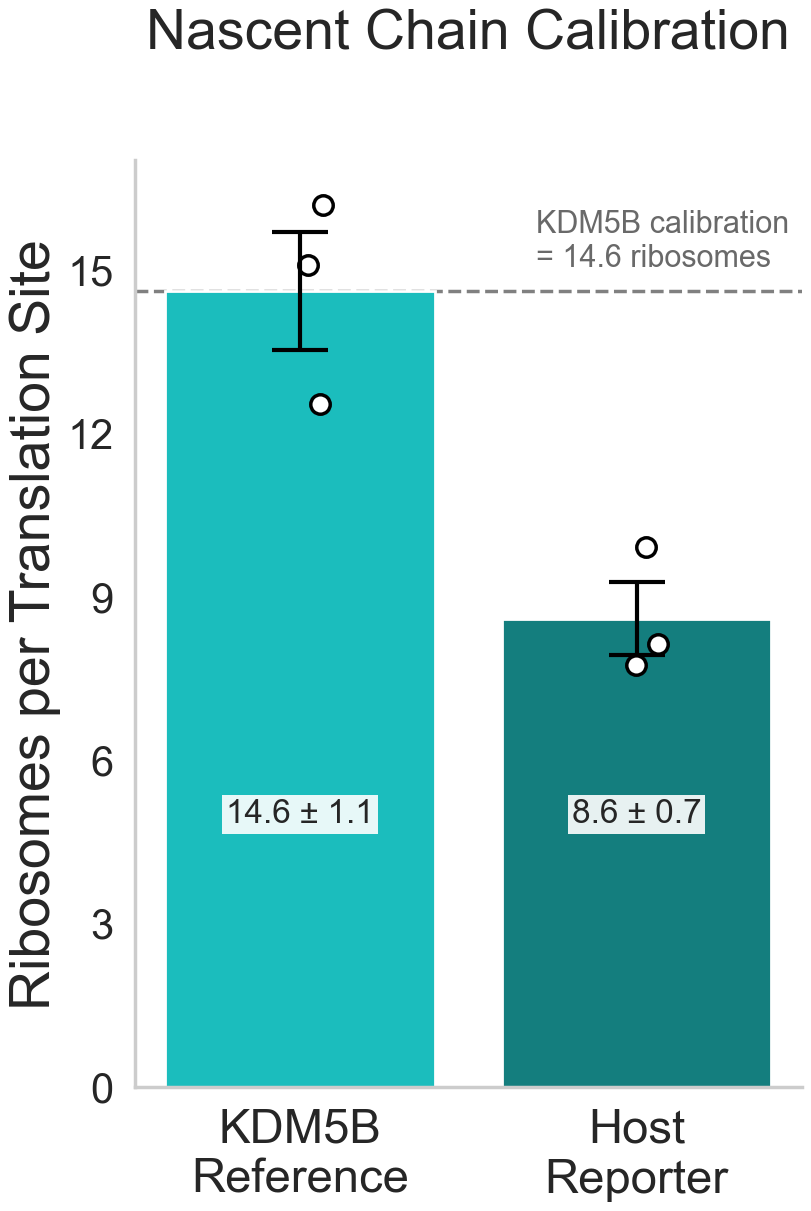

In [94]:
# ============================================================
# FIG. S2A
# RIBOSOME OCCUPANCY CALIBRATION
#
# Published KDM5B occupancy:
#     KDM5B = 14.6 ribosomes
#
# The measured KDM5B signal in this dataset defines the
# signal -> ribosome conversion factor.
#
# SARS_CTRL / NoCTD Nsp1 is then converted to absolute
# ribosome occupancy using the same calibration.
# ============================================================

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ============================================================
# BUILD REPLICATE-LEVEL CALIBRATION DATA
# ============================================================

# KDM5B replicate occupancies were already calculated above:
#
# reference_replicate_occupancies =
#     14.6 * replicate signal / mean KDM5B signal
#
# Do the equivalent calculation for SARS_CTRL / NoCTD.

sars_anchor_replicate_occupancies = (
    REFERENCE_RIBOSOME_OCCUPANCY
    * sars_anchor_replicate_signals
    / reference_mean_signal
)


# ============================================================
# CONVERT TO PLOTTING DATAFRAME
# ============================================================

kdm5b_plot_df = pd.DataFrame({
    "Reporter": "KDM5B Reference",
    "Replicate_Number": reference_replicate_occupancies.index,
    "Ribosome Occupancy": reference_replicate_occupancies.values,
})

sars_plot_df = pd.DataFrame({
    "Reporter": "Host Reporter",
    "Replicate_Number": sars_anchor_replicate_occupancies.index,
    "Ribosome Occupancy": sars_anchor_replicate_occupancies.values,
})

calibration_plot_df = pd.concat(
    [
        kdm5b_plot_df,
        sars_plot_df,
    ],
    ignore_index=True,
)


# ============================================================
# SUMMARY STATISTICS
#
# Mean and SEM are calculated from biological replicate values.
# ============================================================

calibration_summary_df = (
    calibration_plot_df
    .groupby(
        "Reporter",
        sort=False,
    )["Ribosome Occupancy"]
    .agg(
        Mean="mean",
        SD="std",
        SEM="sem",
        N="count",
    )
    .reset_index()
)

reporter_order = [
    "KDM5B Reference",
    "Host Reporter",
]

calibration_summary_df = (
    calibration_summary_df
    .set_index("Reporter")
    .reindex(reporter_order)
    .reset_index()
)

display(calibration_summary_df)


# ============================================================
# STYLE
# ============================================================

sns.set(font_scale=1.9)
sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)
sns.set_context("poster")


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 12),
    constrained_layout=True,
)

sns.despine(
    fig=fig,
    top=True,
    right=True,
    left=False,
    bottom=False,
)


# ============================================================
# BARS
#
# These are means of the replicate-derived occupancies.
# ============================================================

sns.barplot(
    x="Reporter",
    y="Ribosome Occupancy",
    data=calibration_plot_df,
    order=reporter_order,
    estimator=np.mean,
    errorbar=None,
    palette=blue_palette,
    ax=ax,
    zorder=2,
)


# ============================================================
# BIOLOGICAL REPLICATE VALUES
# ============================================================

sns.stripplot(
    x="Reporter",
    y="Ribosome Occupancy",
    data=calibration_plot_df,
    order=reporter_order,
    color="white",
    edgecolor="black",
    linewidth=2.5,
    size=14,
    jitter=0.08,
    ax=ax,
    zorder=10,
)


# ============================================================
# SEM ACROSS BIOLOGICAL REPLICATES
# ============================================================

x_positions = np.arange(len(reporter_order))

ax.errorbar(
    x=x_positions,
    y=calibration_summary_df["Mean"].to_numpy(),
    yerr=calibration_summary_df["SEM"].to_numpy(),
    fmt="none",
    color="black",
    elinewidth=3,
    capsize=20,
    capthick=3,
    zorder=11,
)


# ============================================================
# PUBLISHED KDM5B REFERENCE
#
# Explicitly mark the absolute calibration value.
# ============================================================

ax.axhline(
    REFERENCE_RIBOSOME_OCCUPANCY,
    color="gray",
    linestyle="--",
    linewidth=2.5,
    zorder=1,
)

ax.text(
    .7,
    REFERENCE_RIBOSOME_OCCUPANCY + 0.35,
    "KDM5B calibration\n= 14.6 ribosomes",
    color="dimgrey",
    fontsize=22,
    ha="left",
    va="bottom",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.85,
        pad=4,
    ),
)


# ============================================================
# LABELS
# ============================================================

ax.set_title(
    "Nascent Chain Calibration",
    fontsize=40,
    pad=80,
)

ax.set_ylabel(
    "Ribosomes per Translation Site",
    fontsize=40,
)

ax.set_xlabel("")

new_labels = [
    "KDM5B\nReference",
    "Host\nReporter",
]

ax.set_xticks(x_positions)

ax.set_xticklabels(
    new_labels,
    fontsize=34,
    rotation=0,
)

ax.tick_params(
    axis="y",
    which="major",
    labelsize=30,
)

ax.set_ylim(bottom=0)

ax.yaxis.set_major_locator(
    MaxNLocator(nbins=6)
)


# ============================================================
# ADD OCCUPANCY VALUES IN A FIXED READABLE POSITION
# ============================================================

occupancy_label_y = 5.0

for i, row in calibration_summary_df.iterrows():

    mean_value = row["Mean"]
    sem_value = row["SEM"]

    ax.text(
        i,
        occupancy_label_y,
        f"{mean_value:.1f} ± {sem_value:.1f}",
        ha="center",
        va="center",
        fontsize=24,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.9,
            pad=3,
        ),
        zorder=12,
    )


# ============================================================
# SAVE
# ============================================================

filename_svg = os.path.join(
    save_directory,
    "Figure S2A Nascent Chain Ribosome Calibration.svg"
)

filename_png = os.path.join(
    save_directory,
    "Figure S2A Nascent Chain Ribosome Calibration.png"
)

fig.savefig(
    filename_svg,
    format="svg",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    filename_png,
    format="png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Graphing

In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")
data = average_translation_signal[average_translation_signal['Experimental_Type'] == "No Nsp1"]

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_3'UTR", "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]

# Define custom color palettes
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])

# Create the plot
fig, ax = plt.subplots(figsize=(14, 14))

# Violin plot for total translation signal
sns.barplot(x='Experimental_Group', y='translation_spot_sig', hue='Experimental_Type',
               data=data, order=order, palette=green_palette, ax=ax)

# Overlay with strip plot for individual data points
sns.stripplot(x="Experimental_Group", y="translation_spot_sig", hue="Experimental_Type", 
              data=data, order=order, color="gray", alpha=0.6, size=7, jitter=True, dodge=True, ax=ax)

# Customize labels and titles
ax.set_ylabel(' Total Translation Signal (a.u.)', fontsize=40)
ax.set_title('Total Translation Signal', fontsize=50)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_xlabel('')
ax.set_ylim(-20000, 100000)

# Remove extra legend and customize it
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

# Save the figure in multiple formats
filename_svg = os.path.join(save_directory, "Total_Translation_Signal.svg")
filename_png = os.path.join(save_directory, "Total_Translation_Signal.png")
fig.savefig(filename_svg, format='svg', dpi = 300)
fig.savefig(filename_png, format='png', dpi = 300)

# Show the plot with tight layout
plt.tight_layout()
plt.show()


In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
data = average_translation_signal

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_3'UTR", "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]

# Define custom color palettes
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])

# Create the plot
fig, ax = plt.subplots(figsize=(14, 14))

# Violin plot for total translation signal
sns.violinplot(x='Experimental_Group', y='translation_spot_sig', hue='Experimental_Type',
               data=data, order=order, palette=green_palette, ax=ax)

# # Overlay with strip plot for individual data points
sns.stripplot(x="Experimental_Group", y="translation_spot_sig", hue="Experimental_Type", 
              data=data, order=order, color="gray", alpha=0.3, size=5, jitter=True, dodge=True, ax=ax)

# Customize labels and titles
ax.set_ylabel(' Total Translation Signal (a.u.)', fontsize=40)
ax.set_title('Total Translation Signal', fontsize=50)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_xlabel('')
ax.set_ylim(-20000, 150000)

# Remove extra legend and customize it
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right")

# Save the figure in multiple formats
filename_svg = os.path.join(save_directory, "Total_Translation_Signal (Nsp1).svg")
filename_png = os.path.join(save_directory, "Total_Translation_Signal (Nsp1).png")
fig.savefig(filename_svg, format='svg', bbox_inches='tight')
fig.savefig(filename_png, format='png', bbox_inches='tight')

# Show the plot with tight layout
plt.tight_layout()
plt.show()


In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = average_sig_df[average_sig_df['Experimental Type'] == "No Nsp1"]
data = data[data['Occupancy'] > 0]
superplot = calculate_grouped_average(df = data, average_column = "Occupancy", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(14, 14), constrained_layout=True)

sns.barplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
            data=data, order=order, ax=ax1, palette=green_palette)

sns.stripplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
              data=data, order=order, color="gray", alpha = 0.4, size=7, jitter=0.2, dodge=True, ax=ax1)

sns.stripplot(x="Experimental Group", y="Super Occupancy", hue="Experimental Type", 
              data=superplot, order=order, color="gray", alpha = 1, size=14, jitter=0, dodge=True, marker = "8", ax=ax1)

ax1.set_ylabel('Ribosomes (#)', fontsize=40)
ax1.set_title('Ribosome Occupancy', fontsize=50)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_ylim(0, 40)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)   
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Ribosome Occupancy.svg")
filename_png_translation = os.path.join(save_directory, "Ribosome Occupancy.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()



In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = average_sig_df
data = data[data['Occupancy'] > 0]
superplot = calculate_grouped_average(df = data, average_column = "Occupancy", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])


# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(24, 12), constrained_layout=True)

sns.barplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
            data=data, order=order, ax=ax1, palette=green_palette)

sns.stripplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
              data=data, order=order, color="gray", alpha = 0.4, size=7, jitter=0.2, dodge=True, ax=ax1)

sns.stripplot(x="Experimental Group", y="Super Occupancy", hue="Experimental Type", 
              data=superplot, order=order, color="gray", alpha = 1, size=14, jitter=0, dodge=True, marker = "8", ax=ax1)

ax1.set_ylabel('Ribosomes (#)', fontsize=40)
ax1.set_title('Ribosome Occupancy', fontsize=50)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_ylim(0, 60)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right")

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Ribosome Occupancy (Nsp1).svg")
filename_png_translation = os.path.join(save_directory, "Ribosome Occupancy (Nsp1).png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()



In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")
data = average_translation_signal[average_translation_signal['Experimental_Type'] == "No Nsp1"]

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_3'UTR", "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]

# Define custom color palettes
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])

# Create the plot
fig, ax = plt.subplots(figsize=(14, 14))

# Violin plot for total translation signal
sns.barplot(x='Experimental_Group', y='translation_spot_sig', hue='Experimental_Type',
               data=data, order=order, palette=green_palette, ax=ax)

# Overlay with strip plot for individual data points
sns.stripplot(x="Experimental_Group", y="translation_spot_sig", hue="Experimental_Type", 
              data=data, order=order, color="gray", alpha=0.6, size=7, jitter=True, dodge=True, ax=ax)

# Customize labels and titles
ax.set_ylabel(' Total Translation Signal (a.u.)', fontsize=40)
ax.set_title('Total Translation Signal', fontsize=50)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_xlabel('')
ax.set_ylim(-20000, 100000)

# Remove extra legend and customize it
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

# Save the figure in multiple formats
filename_svg = os.path.join(save_directory, "Total_Translation_Signal.svg")
filename_png = os.path.join(save_directory, "Total_Translation_Signal.png")
fig.savefig(filename_svg, format='svg', dpi = 300)
fig.savefig(filename_png, format='png', dpi = 300)

# Show the plot with tight layout
plt.tight_layout()
plt.show()


In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
data = average_translation_signal

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_3'UTR", "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]

# Define custom color palettes
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])

# Create the plot
fig, ax = plt.subplots(figsize=(14, 14))

# Violin plot for total translation signal
sns.violinplot(x='Experimental_Group', y='translation_spot_sig', hue='Experimental_Type',
               data=data, order=order, palette=green_palette, ax=ax)

# # Overlay with strip plot for individual data points
sns.stripplot(x="Experimental_Group", y="translation_spot_sig", hue="Experimental_Type", 
              data=data, order=order, color="gray", alpha=0.3, size=5, jitter=True, dodge=True, ax=ax)

# Customize labels and titles
ax.set_ylabel(' Total Translation Signal (a.u.)', fontsize=40)
ax.set_title('Total Translation Signal', fontsize=50)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_xlabel('')
ax.set_ylim(-20000, 150000)

# Remove extra legend and customize it
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right")

# Save the figure in multiple formats
filename_svg = os.path.join(save_directory, "Total_Translation_Signal (Nsp1).svg")
filename_png = os.path.join(save_directory, "Total_Translation_Signal (Nsp1).png")
fig.savefig(filename_svg, format='svg', bbox_inches='tight')
fig.savefig(filename_png, format='png', bbox_inches='tight')

# Show the plot with tight layout
plt.tight_layout()
plt.show()


In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = average_sig_df[average_sig_df['Experimental Type'] == "No Nsp1"]
data = data[data['Occupancy'] > 0]
superplot = calculate_grouped_average(df = data, average_column = "Occupancy", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(14, 14), constrained_layout=True)

sns.barplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
            data=data, order=order, ax=ax1, palette=green_palette)

sns.stripplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
              data=data, order=order, color="gray", alpha = 0.4, size=7, jitter=0.2, dodge=True, ax=ax1)

sns.stripplot(x="Experimental Group", y="Super Occupancy", hue="Experimental Type", 
              data=superplot, order=order, color="gray", alpha = 1, size=14, jitter=0, dodge=True, marker = "8", ax=ax1)

ax1.set_ylabel('Ribosomes (#)', fontsize=40)
ax1.set_title('Ribosome Occupancy', fontsize=50)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_ylim(0, 40)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)   
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Ribosome Occupancy.svg")
filename_png_translation = os.path.join(save_directory, "Ribosome Occupancy.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()



In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = average_sig_df
data = data[data['Occupancy'] > 0]
superplot = calculate_grouped_average(df = data, average_column = "Occupancy", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])


# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(24, 12), constrained_layout=True)

sns.barplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
            data=data, order=order, ax=ax1, palette=green_palette)

sns.stripplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
              data=data, order=order, color="gray", alpha = 0.4, size=7, jitter=0.2, dodge=True, ax=ax1)

sns.stripplot(x="Experimental Group", y="Super Occupancy", hue="Experimental Type", 
              data=superplot, order=order, color="gray", alpha = 1, size=14, jitter=0, dodge=True, marker = "8", ax=ax1)

ax1.set_ylabel('Ribosomes (#)', fontsize=40)
ax1.set_title('Ribosome Occupancy', fontsize=50)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_ylim(0, 60)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right")

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Ribosome Occupancy (Nsp1).svg")
filename_png_translation = os.path.join(save_directory, "Ribosome Occupancy (Nsp1).png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()



In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")
data = average_translation_signal[average_translation_signal['Experimental_Type'] == "No Nsp1"]

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_3'UTR", "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]

# Define custom color palettes
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])

# Create the plot
fig, ax = plt.subplots(figsize=(14, 14))

# Violin plot for total translation signal
sns.barplot(x='Experimental_Group', y='translation_spot_sig', hue='Experimental_Type',
               data=data, order=order, palette=green_palette, ax=ax)

# Overlay with strip plot for individual data points
sns.stripplot(x="Experimental_Group", y="translation_spot_sig", hue="Experimental_Type", 
              data=data, order=order, color="gray", alpha=0.6, size=7, jitter=True, dodge=True, ax=ax)

# Customize labels and titles
ax.set_ylabel(' Total Translation Signal (a.u.)', fontsize=40)
ax.set_title('Total Translation Signal', fontsize=50)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_xlabel('')
ax.set_ylim(-20000, 100000)

# Remove extra legend and customize it
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

# Save the figure in multiple formats
filename_svg = os.path.join(save_directory, "Total_Translation_Signal.svg")
filename_png = os.path.join(save_directory, "Total_Translation_Signal.png")
fig.savefig(filename_svg, format='svg', dpi = 300)
fig.savefig(filename_png, format='png', dpi = 300)

# Show the plot with tight layout
plt.tight_layout()
plt.show()


In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
data = average_translation_signal

# Define the order for the x-axis categories
order = ["SARS_CTRL", "SARS_5'UTR", "SARS_3'UTR", "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]

# Define custom color palettes
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])

# Create the plot
fig, ax = plt.subplots(figsize=(14, 14))

# Violin plot for total translation signal
sns.violinplot(x='Experimental_Group', y='translation_spot_sig', hue='Experimental_Type',
               data=data, order=order, palette=green_palette, ax=ax)

# # Overlay with strip plot for individual data points
sns.stripplot(x="Experimental_Group", y="translation_spot_sig", hue="Experimental_Type", 
              data=data, order=order, color="gray", alpha=0.3, size=5, jitter=True, dodge=True, ax=ax)

# Customize labels and titles
ax.set_ylabel(' Total Translation Signal (a.u.)', fontsize=40)
ax.set_title('Total Translation Signal', fontsize=50)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_xlabel('')
ax.set_ylim(-20000, 150000)

# Remove extra legend and customize it
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right")

# Save the figure in multiple formats
filename_svg = os.path.join(save_directory, "Total_Translation_Signal (Nsp1).svg")
filename_png = os.path.join(save_directory, "Total_Translation_Signal (Nsp1).png")
fig.savefig(filename_svg, format='svg', bbox_inches='tight')
fig.savefig(filename_png, format='png', bbox_inches='tight')

# Show the plot with tight layout
plt.tight_layout()
plt.show()


In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = average_sig_df[average_sig_df['Experimental Type'] == "No Nsp1"]
data = data[data['Occupancy'] > 0]
superplot = calculate_grouped_average(df = data, average_column = "Occupancy", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])

# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])



# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(14, 14), constrained_layout=True)

sns.barplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
            data=data, order=order, ax=ax1, palette=green_palette)

sns.stripplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
              data=data, order=order, color="gray", alpha = 0.4, size=7, jitter=0.2, dodge=True, ax=ax1)

sns.stripplot(x="Experimental Group", y="Super Occupancy", hue="Experimental Type", 
              data=superplot, order=order, color="gray", alpha = 1, size=14, jitter=0, dodge=True, marker = "8", ax=ax1)

ax1.set_ylabel('Ribosomes (#)', fontsize=40)
ax1.set_title('Ribosome Occupancy', fontsize=50)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_ylim(0, 40)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)   
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Ribosome Occupancy.svg")
filename_png_translation = os.path.join(save_directory, "Ribosome Occupancy.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()



In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid")
sns.set_context("poster")

# Filter the data for "No Nsp1" condition
data = average_sig_df
data = data[data['Occupancy'] > 0]
superplot = calculate_grouped_average(df = data, average_column = "Occupancy", group_by_columns=['Experimental Group', 'Experimental Type', 'Replicate Number'])
# Define the order for the x-axis categories
order = ["SARS_CTRL",
         "SARS_5'UTR",
         "SARS_3'UTR",
         "SARS_5'UTR_3'UTR"]

# Define the x-tick labels
new_labels = ["Host UTR", "SARS 5' UTR", "SARS 3' UTR", "SARS 5' and 3' UTRs"]
green_palette = sns.color_palette(["#08c41f", "#027510", "#0F4C0F"])
magenta_palette = sns.color_palette(["#FF00FF", "#940194", "#990099"])


# Plot 1: Average Total Translation Signal
fig1, ax1 = plt.subplots(figsize=(24, 12), constrained_layout=True)

sns.barplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
            data=data, order=order, ax=ax1, palette=green_palette)

sns.stripplot(x="Experimental Group", y="Occupancy", hue="Experimental Type", 
              data=data, order=order, color="gray", alpha = 0.4, size=7, jitter=0.2, dodge=True, ax=ax1)

sns.stripplot(x="Experimental Group", y="Super Occupancy", hue="Experimental Type", 
              data=superplot, order=order, color="gray", alpha = 1, size=14, jitter=0, dodge=True, marker = "8", ax=ax1)

ax1.set_ylabel('Ribosomes (#)', fontsize=40)
ax1.set_title('Ribosome Occupancy', fontsize=50)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.set_ylim(0, 60)
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax1.set_xlabel('')
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles[:2], labels[:2], title="Experimental Type", facecolor='white', edgecolor='black', fontsize=16, title_fontsize=18, loc = "upper right")

# Save the figure for Translation Signal
filename_svg_translation = os.path.join(save_directory, "Ribosome Occupancy (Nsp1).svg")
filename_png_translation = os.path.join(save_directory, "Ribosome Occupancy (Nsp1).png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Translation Signal
plt.tight_layout()
plt.show()



## Crop Array Plotting

In [ ]:
blue_palette = sns.color_palette(["#00D8D8", "#029090", "#67FFFF"])
magenta_palette = sns.color_palette(["#Ef1EEF", "#B700B7", "#FF99FF"])

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from typing import Optional

def white_to_hex_cmap(
    hex_color: str,
    name: Optional[str] = None,
    n: int = 256,
    *,
    under: Optional[str] = "white",
    over: Optional[str] = None,
    bad: Optional[str] = None,
):
    """
    Create a colormap that goes from white -> hex_color (e.g., '#00FFFF' or '#FF00FF').
    'under' sets the color for values <= vmin (useful for forcing <=0 to white).
    """
    # Validate/normalize the target color (accepts hex or named colors)
    _ = mcolors.to_rgba(hex_color)

    if name is None:
        name = f"white_to_{hex_color.lstrip('#')}"

    # Build the gradient white -> target
    cmap = LinearSegmentedColormap.from_list(name, ["#FFFFFF", hex_color], N=n)

    # Optional special colors
    if under is not None:
        cmap.set_under(under)
    if over is not None:
        cmap.set_over(over)
    if bad is not None:
        cmap.set_bad(bad)

    return cmap


In [ ]:
import os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xarray as xr
from matplotlib.transforms import Bbox

def montage_avg_bestz_by_time(
    ds,
    exp_g="SARS_CTRL",
    ch=1,
    time_points=None,                 # list/array of t values; None = all
    use_spot_mask=False,              # optionally mask pixels to spot pixels only
    respect_flags=True,               # apply Include/Exclude if present
    # --- NEW: minimal filtering for a "general" dataset ---
    filter_mode="spot_sig",           # "spot_sig" (recommended), "crop_sum", or None
    spot_var_by_ch=None,              # mapping ch -> spot var name (defaults below)
    min_sum=0,                        # threshold for filter_mode (> min_sum)
    # --- Plot/layout ---
    cols=7,
    figsize_per_cell=2.4,
    cmap="Greys",
    # --- Time labeling (UPDATED) ---
    time_label_mode="t",
    time_origin_t=0,                  # "t" -> title "t=<value>" using ds coordinate
    time_step=None,                   # numeric step per frame; e.g. 1, 0.05, 50
    time_unit=None,                   # unit string; e.g. "sec", "ms", "min"
    time_zero=None,                   # numeric offset applied after scaling (default 0)
    time_decimals=None,               # decimals for display; if None, auto
    # --- Saving ---
    savename=None,
    outdir=r"Z:\koch\Presentations and Figures\Figures\CA Plots",
):
    """
    Build a montage of average best-z crop images at each time point.
    Averages across all crops (fov, n) that pass minimal filters.

    Filtering options:
      - filter_mode="spot_sig" (recommended): keep crops where the relevant spot-mask sum > min_sum
          * ch==0 -> RNA_spot.sum(x,y)
          * ch==1 -> translation_spot.sum(x,y)
      - filter_mode="crop_sum": keep crops where best_z.sum(y,x) > min_sum
      - filter_mode=None: no additional filtering besides Include/Exclude (if enabled)

    Plotted image source is always: ds["best_z"].sel(ch=ch)

    Display scaling:
      - vmin just above 0 so <=0 goes to "under" (white), robust shared vmax.

    Time labeling (new):
      - Default: titles are "t=<t_value>" using the dataset's t coordinate.
      - If you provide time_step + time_unit:
          displayed_time = (t - t0) * time_step + time_zero
        and titles become e.g. "0 sec", "1 sec", ... or "0 ms", "50 ms", ...
        where t0 is the first plotted t value.
    """

    # --- Select group ---
    dsg = ds.sel(Exp_G=exp_g)

    # --- Pick best_z crops to plot ---
    if "best_z" not in dsg:
        raise KeyError("Dataset is missing variable 'best_z'.")
    best = dsg["best_z"].sel(ch=ch).astype("float32")

    # --- Build a per-crop pass mask: dims (fov, n, t) ---
    if filter_mode is None:
        pass_mask = xr.ones_like(best.isel(y=0, x=0), dtype=bool)

    elif filter_mode == "crop_sum":
        crop_sum = best.sum(dim=("y", "x"), skipna=True)
        pass_mask = crop_sum > float(min_sum)

    elif filter_mode == "spot_sig":
        if spot_var_by_ch is None:
            spot_var_by_ch = {0: "RNA_spot", 1: "translation_spot"}

        spot_var = spot_var_by_ch.get(int(ch), None)
        if (spot_var is None) or (spot_var not in dsg):
            raise KeyError(
                f"filter_mode='spot_sig' requires a spot variable for ch={ch}. "
                f"Tried '{spot_var}'. Available vars include: {list(dsg.data_vars)}"
            )

        spot_sum = dsg[spot_var].sum(dim=("x", "y"), skipna=True)  # -> (fov, n, t)
        pass_mask = spot_sum > float(min_sum)

    else:
        raise ValueError("filter_mode must be one of: 'spot_sig', 'crop_sum', or None.")

    # --- Optionally respect Include/Exclude flags (broadcast across y,x) ---
    if respect_flags and ("Include" in dsg.data_vars) and ("Exclude" in dsg.data_vars):
        inc = dsg["Include"].fillna(1)
        exc = dsg["Exclude"].fillna(0)
        pass_mask = pass_mask & (inc == 1) & (exc == 0)

    # Apply per-crop mask
    best = best.where(pass_mask)

    # --- Optionally: mask pixels to spot pixels only ---
    if use_spot_mask:
        if spot_var_by_ch is None:
            spot_var_by_ch = {0: "RNA_spot", 1: "translation_spot"}
        spot_var = spot_var_by_ch.get(int(ch), None)
        if (spot_var is None) or (spot_var not in dsg):
            raise KeyError(
                f"use_spot_mask=True requires spot mask variable for ch={ch}. "
                f"Tried '{spot_var}'."
            )
        spot_yx = dsg[spot_var].transpose("fov", "n", "t", "y", "x")
        best = best.where((spot_yx > 0).fillna(False))

    # --- Average across crops -> (t, y, x) ---
    avg_img_per_t = best.mean(dim=("fov", "n"), skipna=True)

    # --- Restrict to specific time points (if provided) ---
    if time_points is not None:
        desired = np.asarray(time_points, dtype=int)
        available = avg_img_per_t["t"].values
        keep = desired[np.isin(desired, available)]
        if keep.size == 0:
            raise ValueError(
                f"None of the requested time points are present: {desired}. "
                f"Available t: {available}."
            )
        avg_img_per_t = avg_img_per_t.sel(t=keep)

    t_vals = avg_img_per_t["t"].values
    T = len(t_vals)
    if T == 0:
        raise ValueError("No time points to plot (after filtering).")

    # --- Common display range across plotted frames (debug-like montage scaling) ---
    vals = avg_img_per_t.values.astype(np.float32)
    vmin = np.nextafter(0, 1)

    p98_by_t = []
    for t in avg_img_per_t["t"].values:
        img_t = avg_img_per_t.sel(t=t).values.astype(np.float32)
        pos_t = img_t[np.isfinite(img_t) & (img_t > 0)]
        if pos_t.size:
            p98_by_t.append(np.nanpercentile(pos_t, 98))

    p98_by_t = np.asarray(p98_by_t, dtype=np.float32)
    if p98_by_t.size:
        vmax = np.nanpercentile(p98_by_t, 90)
    else:
        vmax = np.nanpercentile(vals[np.isfinite(vals)], 98)

    if (not np.isfinite(vmax)) or vmax <= vmin:
        finite = vals[np.isfinite(vals)]
        vmax = np.nanmax(finite) if finite.size else 1.0

    cmap_use = plt.get_cmap(cmap).with_extremes(under="white")

    # --- Time labeling setup (UPDATED) ---
    if time_zero is None:
        time_zero = 0.0

    def _format_time_value(val):
        if time_decimals is not None:
            return f"{val:.{int(time_decimals)}f}"
        if np.isclose(val, round(val)):
            return f"{int(round(val))}"
        return f"{val:.3f}".rstrip("0").rstrip(".")

    def _title_for_t(t):
        if (time_step is None) or (time_unit is None):
            return f"t={int(t) if np.isclose(t, round(t)) else t}"
        displayed = (float(t) - float(time_origin_t)) * float(time_step) + float(time_zero)
        return f"{_format_time_value(displayed)} {time_unit}"

    # --- Layout ---
    rows = math.ceil(T / cols)
    fig, axes = plt.subplots(
        rows, cols,
        figsize=(cols * figsize_per_cell, rows * figsize_per_cell),
        squeeze=False
    )
    sns.set_context("poster")
    fig.set_dpi(300)

    # --- Plot ---
    im = None
    for i, t in enumerate(t_vals):
        r, c = divmod(i, cols)
        ax = axes[r][c]
        img = avg_img_per_t.sel(t=t).values
        im = ax.imshow(img, vmin=vmin, vmax=vmax, cmap=cmap_use, origin="lower")

        ax.set_title(_title_for_t(t), fontsize=40)
        ax.set_xticks([]); ax.set_yticks([])

    # Hide unused tiles
    for j in range(T, rows * cols):
        r, c = divmod(j, cols)
        axes[r][c].axis("off")

    # --- Shared colorbar below montage ---
    grid_bbox = Bbox.union([ax.get_position() for ax in axes.ravel()])

    pad    = 0.03
    cbar_h = 0.04
    cbar_w = 0.60 * grid_bbox.width
    cbar_x = grid_bbox.x0 + (grid_bbox.width - cbar_w) / 2.0
    cbar_y = grid_bbox.y0 - pad - cbar_h

    cax = fig.add_axes([cbar_x, cbar_y, cbar_w, cbar_h])
    cbar = fig.colorbar(im, cax=cax, orientation="horizontal", extend="min")
    cbar.set_label("Mean intensity (a.u.)", fontsize=40, labelpad=20)
    cbar.ax.tick_params(labelsize=32)

    plt.subplots_adjust(wspace=0.05, hspace=0.15, right=0.98, top=0.95, bottom=0.18)

    # --- Save ---
    if savename:
        os.makedirs(outdir, exist_ok=True)
        base = os.path.splitext(savename)[0]
        svg = os.path.join(outdir, f"{base}.svg")
        png = os.path.join(outdir, f"{base}.png")
        fig.savefig(svg, format="svg", bbox_inches="tight")
        fig.savefig(png, format="png", bbox_inches="tight", dpi=300)

    plt.show()


In [ ]:
#Plot montages for each Exp_G, for ch=0 (mRNA) and ch=1 (translation)
cmap1 = white_to_hex_cmap("#00D8D8")  # ch=1 (translation)
cmap2 = white_to_hex_cmap("#FF00FF")  # ch=0 (mRNA)

# keep your current specifics
time_points = list(range(1,11))  # t=1..10
time_step = 1
time_unit = "sec"
time_origin_t = 0
filter_mode = "spot_sig"
min_sum = 0
cols = 10
respect_flags = True

exp_g_list = [str(v) for v in combined_ds_1["Exp_G"].values]

for i, exp_g in enumerate(exp_g_list, start=1):
    print(f"[{i}/{len(exp_g_list)}] Plotting Exp_G='{exp_g}' ...")

    # --- ch=0: mRNA ---
    print(f"  -> ch=0 (mRNA): time_points={time_points}, time_step={time_step} {time_unit}")
    montage_avg_bestz_by_time(
        combined_ds_1,
        exp_g=exp_g,
        ch=0,
        time_points=time_points,
        time_step=time_step,
        time_unit=time_unit,
        time_origin_t=time_origin_t,
        cmap=cmap2,
        filter_mode=filter_mode,
        min_sum=min_sum,
        cols=cols,
        respect_flags=respect_flags,
        savename=f"{exp_g} montage (mRNA)",
    )

    # --- ch=1: translation ---
    print(f"  -> ch=1 (translation): time_points={time_points}, time_step={time_step} {time_unit}")
    montage_avg_bestz_by_time(
        combined_ds_1,
        exp_g=exp_g,
        ch=1,
        time_points=time_points,
        time_step=time_step,
        time_unit=time_unit,
        time_origin_t=time_origin_t,
        cmap=cmap1,
        filter_mode=filter_mode,
        min_sum=min_sum,
        cols=cols,
        respect_flags=respect_flags,
        savename=f"{exp_g} montage (translation)",
    )

print("Done.")


## MSD Plotting

In [ ]:
# mRNA TRACKING — SETTINGS + CLEAN CELL WHITELIST
#
# Place AFTER creation of:
#     outlier_cells
#     df_no_outliers
# ============================================================

import gc
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import trackpy as tp
import xarray as xr


# ============================================================
# DATA SOURCES
# ============================================================

TRACKING_SOURCE_DS = combined_ds_1

# IMPORTANT:
# This is used as a CELL WHITELIST.
# Cells removed by your existing outlier analysis cannot
# re-enter the tracking dataset.
TRACKING_CLEAN_CELL_SOURCE = df_no_outliers


# ============================================================
# CYTOPLASMIC / NUCLEAR FILTERING
# ============================================================

# These are the three cytoplasmic localization masks already
# stored in combined_ds_1.
#
# "Nuclear Periphery" means the cytoplasmic region nearest the
# nucleus — NOT the nuclear interior.
CYTOPLASMIC_LOCATION_MASKS = [
    "Nuclear Periphery",
    "Cytoplasm",
    "Cytoplasmic Periphery",
]

# Only spots belonging to one of the above masks will be linked.
# Therefore nuclear RNA spots are excluded BEFORE Trackpy linking.
REQUIRE_CYTOPLASMIC_LOCATION = True

# Continue respecting CropArray Include / Exclude flags.
RESPECT_INCLUDE_EXCLUDE = True


# ============================================================
# TRACKPY DEFAULT SETTINGS
# ============================================================

DEFAULT_LINK_SETTINGS = {

    # Normal maximum XY displacement between consecutive frames
    "search_range": 7.0,

    # Number of missing frames Trackpy may bridge
    "memory": 1,

    # Do not delete shorter tracks.
    # Instead they are flagged keep_for_msd=False.
    "min_track_length": 5,

    # EDIT if necessary.
    # May also be overridden separately for each condition.
    "frame_interval_s": 1.0,

    # --------------------------------------------------------
    # Adaptive search
    # --------------------------------------------------------
    # If a dense region creates an oversized Trackpy subnet,
    # Trackpy progressively reduces the local search radius.
    #
    # It will never reduce below adaptive_stop.
    "adaptive_stop": 2.0,

    # Multiply the radius by this value after an oversized subnet.
    "adaptive_step": 0.90,
}


# ============================================================
# OPTIONAL CONDITION-SPECIFIC SETTINGS
# ============================================================
#
# Any value here overrides DEFAULT_LINK_SETTINGS for that
# Experimental Group x Experimental Type only.
#
# Example:
#
# LINK_SETTINGS = {
#
#     ("SARS_CTRL", "No Nsp1"): {
#         "search_range": 4.0,
#         "memory": 1,
#         "frame_interval_s": 1.0,
#     },
#
#     ("SARS_CTRL", "Nsp1"): {
#         "search_range": 6.0,
#         "memory": 1,
#         "frame_interval_s": 2.0,
#     },
# }

LINK_SETTINGS = {}


def get_link_settings(group, exp_type):

    settings = DEFAULT_LINK_SETTINGS.copy()

    settings.update(
        LINK_SETTINGS.get(
            (str(group), str(exp_type)),
            {}
        )
    )

    return settings


# ============================================================
# OUTPUT / MEMORY SETTINGS
# ============================================================

TRACKING_OUTPUT_DIR = (
    Path(r"C:\Temp_data\Rapid")
    / "Linked mRNA Tracking CSV"
)

TRACKING_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Number of cells whose linked rows may accumulate before
# being appended to disk.
#
# 5 should be extremely conservative for RAM.
SAVE_BUFFER_CELLS = 5


# IMPORTANT:
#
# Set True for this first corrected run so old tracking files
# from the previous version are replaced.
#
# After a successful complete run, you can change this to False.
# Then already-completed conditions will be skipped on reruns.
OVERWRITE_EXISTING = True


# ============================================================
# BUILD RETAINED CELL WHITELIST
# ============================================================

clean_cell_keys = (
    TRACKING_CLEAN_CELL_SOURCE[
        [
            "Experimental Group",
            "Experimental Type",
            "Replicate_Number",
            "fov",
        ]
    ]
    .drop_duplicates()
    .copy()
)


clean_cell_keys["Replicate_Number"] = pd.to_numeric(
    clean_cell_keys["Replicate_Number"],
    errors="coerce"
).astype("Int64")


clean_cell_keys["fov"] = pd.to_numeric(
    clean_cell_keys["fov"],
    errors="coerce"
).astype("Int64")


clean_cell_keys = clean_cell_keys.dropna(
    subset=[
        "Experimental Group",
        "Experimental Type",
        "Replicate_Number",
        "fov",
    ]
).reset_index(drop=True)


print(
    f"Retained cells available for tracking: "
    f"{len(clean_cell_keys):,}"
)


condition_cell_counts = (
    clean_cell_keys
    .groupby(
        [
            "Experimental Group",
            "Experimental Type"
        ],
        dropna=False
    )
    .size()
    .rename("n_cells")
    .reset_index()
)


display(condition_cell_counts)

Retained cells available for tracking: 935


,Experimental Group,Experimental Type,n_cells
0,BoxB_IRES,No Nsp1,30
1,BoxB_IRES,Nsp1,27
2,BoxB_MS2,No Nsp1,90
3,BoxB_MS2,NoCTD Nsp1,81
4,BoxB_MS2,Nsp1,78
5,EMI_NoORF,No Nsp1,40
6,EMI_NoORF,Nsp1,28
7,Emi_KDM5B,No Nsp1,34
8,Emi_KDM5B,NoCTD Nsp1,35
9,Emi_KDM5B,Nsp1,36


In [ ]:
# mRNA TRACKING — CYTOPLASMIC SPOT EXTRACTION
# ============================================================


def _experimental_group_from_exp_g(exp_g):
    """
    Match the Experimental_Group naming already used in the notebook.
    """

    return (
        str(exp_g)
        .replace("Nsp1_NoCTD_", "")
        .replace("Nsp1_", "")
    )


def _scalar_value(obj, default=np.nan):
    """
    Convert scalar xarray values safely into Python scalars.
    """

    try:

        arr = np.asarray(
            obj.values
            if hasattr(obj, "values")
            else obj
        )

        if arr.size == 0:
            return default

        return arr.reshape(-1)[0]

    except Exception:
        return default


def _select_ch0_if_present(data_array):
    """
    Select the mRNA channel when a variable carries a ch dimension.
    Leave variables without ch unchanged.
    """

    if "ch" in data_array.dims:
        return data_array.sel(ch=0)

    return data_array


def _build_condition_to_exp_g_lookup(ds):
    """
    Build:

        (Experimental Group, Experimental Type)
                         ->
                       Exp_G
    """

    lookup = {}

    for raw_exp_g in ds["Exp_G"].values:

        raw_exp_g = str(raw_exp_g)

        dsg = ds.sel(
            Exp_G=raw_exp_g
        )

        group = (
            _experimental_group_from_exp_g(
                raw_exp_g
            )
        )

        if "Experimental_Type" in dsg.coords:

            exp_type = str(
                _scalar_value(
                    dsg["Experimental_Type"]
                )
            )

        elif "Experimental_Type" in dsg:

            exp_type = str(
                _scalar_value(
                    dsg["Experimental_Type"]
                )
            )

        else:

            raise KeyError(
                "Experimental_Type was not found for "
                f"Exp_G={raw_exp_g}"
            )


        key = (
            group,
            exp_type
        )


        if (
            key in lookup
            and lookup[key] != raw_exp_g
        ):

            raise ValueError(
                f"More than one Exp_G maps to {key}: "
                f"{lookup[key]} and {raw_exp_g}"
            )


        lookup[key] = raw_exp_g


    return lookup


CONDITION_TO_EXP_G = (
    _build_condition_to_exp_g_lookup(
        TRACKING_SOURCE_DS
    )
)


def extract_mrna_detections_for_cell(
    ds,
    *,
    raw_exp_g,
    fov,
    group,
    exp_type,
    replicate_number,
    frame_interval_s,
):
    """
    Extract cytoplasmic mRNA detections from ONE retained cell.

    Filtering order:

        positive RNA
            ↓
        Include / Exclude flags
            ↓
        localization mask
            ↓
        CYTOPLASMIC spots only

    The three localization masks are the cytoplasmic radial
    regions already stored in combined_ds_1.

    Nuclear spots therefore never reach Trackpy.
    """


    cell = (
        ds
        .sel(
            Exp_G=raw_exp_g
        )
        .isel(
            fov=int(fov)
        )
    )


    # --------------------------------------------------------
    # Validate required variables
    # --------------------------------------------------------

    required = [
        "RNA_spot_sig",
        "xc",
        "yc",
        "zc",
    ] + CYTOPLASMIC_LOCATION_MASKS


    missing = [
        name
        for name in required
        if name not in cell
    ]


    if missing:

        raise KeyError(
            f"Missing tracking variable(s) for "
            f"{raw_exp_g}, fov={fov}:\n"
            f"{missing}"
        )


    # --------------------------------------------------------
    # Build minimal xarray subset
    # --------------------------------------------------------

    cell_vars = {

        "RNA_spot_sig":
            _select_ch0_if_present(
                cell["RNA_spot_sig"]
            ),

        "xc":
            _select_ch0_if_present(
                cell["xc"]
            ),

        "yc":
            _select_ch0_if_present(
                cell["yc"]
            ),

        "zc":
            _select_ch0_if_present(
                cell["zc"]
            ),
    }


    # Add existing cytoplasmic localization masks
    for mask_name in CYTOPLASMIC_LOCATION_MASKS:

        cell_vars[mask_name] = (
            _select_ch0_if_present(
                cell[mask_name]
            )
        )


    # Include / Exclude flags
    if (
        RESPECT_INCLUDE_EXCLUDE
        and "Include" in cell
    ):

        cell_vars["Include"] = (
            _select_ch0_if_present(
                cell["Include"]
            )
        )


    if (
        RESPECT_INCLUDE_EXCLUDE
        and "Exclude" in cell
    ):

        cell_vars["Exclude"] = (
            _select_ch0_if_present(
                cell["Exclude"]
            )
        )


    # Only convert this single cell to pandas.
    cell_df = (
        xr.Dataset(cell_vars)
        .to_dataframe()
        .reset_index()
    )


    # ========================================================
    # 1. POSITIVE RNA
    # ========================================================

    positive_rna = pd.to_numeric(
        cell_df["RNA_spot_sig"],
        errors="coerce"
    ).gt(0)


    cell_df = (
        cell_df
        .loc[positive_rna]
        .copy()
    )


    n_positive_rna = len(cell_df)


    # ========================================================
    # 2. INCLUDE / EXCLUDE FLAGS
    # ========================================================

    if (
        RESPECT_INCLUDE_EXCLUDE
        and "Include" in cell_df
    ):

        cell_df = cell_df.loc[
            cell_df["Include"]
            .fillna(1)
            .astype(bool)
        ].copy()


    if (
        RESPECT_INCLUDE_EXCLUDE
        and "Exclude" in cell_df
    ):

        cell_df = cell_df.loc[
            ~cell_df["Exclude"]
            .fillna(0)
            .astype(bool)
        ].copy()


    n_after_include_exclude = (
        len(cell_df)
    )


    # ========================================================
    # 3. CYTOPLASMIC LOCATION FILTER
    # ========================================================

    for mask_name in CYTOPLASMIC_LOCATION_MASKS:

        cell_df[mask_name] = (
            cell_df[mask_name]
            .fillna(0)
            .astype(bool)
        )


    in_cytoplasm = np.zeros(
        len(cell_df),
        dtype=bool
    )


    for mask_name in CYTOPLASMIC_LOCATION_MASKS:

        in_cytoplasm |= (
            cell_df[mask_name]
            .to_numpy(dtype=bool)
        )


    # Also retain which cytoplasmic region each detection belongs to.
    cell_df["Location"] = np.select(

        [
            cell_df[
                "Nuclear Periphery"
            ].to_numpy(dtype=bool),

            cell_df[
                "Cytoplasm"
            ].to_numpy(dtype=bool),

            cell_df[
                "Cytoplasmic Periphery"
            ].to_numpy(dtype=bool),
        ],

        [
            "Nuclear Periphery",
            "Cytoplasm",
            "Cytoplasmic Periphery",
        ],

        default="Non-cytoplasmic",
    )


    n_cytoplasmic = int(
        in_cytoplasm.sum()
    )


    n_noncytoplasmic_excluded = int(
        len(cell_df)
        - n_cytoplasmic
    )


    if REQUIRE_CYTOPLASMIC_LOCATION:

        cell_df = (
            cell_df
            .loc[in_cytoplasm]
            .copy()
        )


    # We no longer need three separate boolean columns.
    cell_df = cell_df.drop(
        columns=CYTOPLASMIC_LOCATION_MASKS
    )


    # ========================================================
    # EXTRACTION QC
    # ========================================================

    extraction_qc = {

        "Experimental_Group":
            str(group),

        "Experimental_Type":
            str(exp_type),

        "Replicate_Number":
            int(replicate_number),

        "fov":
            int(fov),

        "positive_RNA_before_filters":
            int(n_positive_rna),

        "RNA_after_include_exclude":
            int(n_after_include_exclude),

        "cytoplasmic_RNA_retained":
            int(n_cytoplasmic),

        "noncytoplasmic_RNA_excluded":
            int(n_noncytoplasmic_excluded),
    }


    if cell_df.empty:

        return (
            cell_df,
            extraction_qc
        )


    # ========================================================
    # COORDINATES
    # ========================================================

    if "xy_pad" in cell:

        xy_pad = _scalar_value(
            cell["xy_pad"],
            default=0.0
        )

    else:

        xy_pad = 0.0


    xy_pad = (
        float(xy_pad)
        if pd.notna(xy_pad)
        else 0.0
    )


    # Keep original crop coordinates
    cell_df["xc_crop"] = pd.to_numeric(
        cell_df["xc"],
        errors="coerce"
    )


    cell_df["yc_crop"] = pd.to_numeric(
        cell_df["yc"],
        errors="coerce"
    )


    # Convert back into image coordinates using the same
    # convention as assign_masks() in this notebook.
    cell_df["x"] = (
        cell_df["xc_crop"]
        - xy_pad
    )


    cell_df["y"] = (
        cell_df["yc_crop"]
        - xy_pad
    )


    # z is carried into the trajectory but is NOT used
    # to make the Trackpy linking decision.
    cell_df["z"] = pd.to_numeric(
        cell_df["zc"],
        errors="coerce"
    )


    cell_df["frame"] = pd.to_numeric(
        cell_df["t"],
        errors="coerce"
    )


    cell_df = (
        cell_df
        .dropna(
            subset=[
                "frame",
                "x",
                "y"
            ]
        )
        .copy()
    )


    if cell_df.empty:

        return (
            cell_df,
            extraction_qc
        )


    cell_df["frame"] = (
        cell_df["frame"]
        .astype(int)
    )


    cell_df["source_n"] = pd.to_numeric(
        cell_df["n"],
        errors="coerce"
    ).astype("Int64")


    cell_df["time_s"] = (
        cell_df["frame"]
        * float(frame_interval_s)
    )


    # ========================================================
    # METADATA
    # ========================================================

    cell_df["Experimental_Group"] = (
        str(group)
    )

    cell_df["Experimental_Type"] = (
        str(exp_type)
    )

    cell_df["Raw_Exp_G"] = (
        str(raw_exp_g)
    )

    cell_df["Replicate_Number"] = (
        int(replicate_number)
    )

    cell_df["fov"] = (
        int(fov)
    )


    if (
        "Cell_Number" in cell.coords
        or "Cell_Number" in cell
    ):

        cell_number = _scalar_value(
            cell["Cell_Number"]
        )

    else:

        cell_number = np.nan


    cell_df["Cell_Number"] = (
        cell_number
    )

    extraction_qc["Cell_Number"] = (
        cell_number
    )


    if (
        "Date" in cell.coords
        or "Date" in cell
    ):

        date_value = _scalar_value(
            cell["Date"]
        )

        cell_df["Date"] = pd.to_datetime(
            date_value,
            errors="coerce"
        )

    else:

        cell_df["Date"] = pd.NaT


    if (
        "Dish" in cell.coords
        or "Dish" in cell
    ):

        cell_df["Dish"] = str(
            _scalar_value(
                cell["Dish"],
                default=""
            )
        )

    else:

        cell_df["Dish"] = ""


    if (
        "Imaging_Settings" in cell.coords
        or "Imaging_Settings" in cell
    ):

        cell_df["Imaging_Settings"] = str(
            _scalar_value(
                cell[
                    "Imaging_Settings"
                ],
                default=""
            )
        )

    else:

        cell_df["Imaging_Settings"] = ""


    cell_df["RNA_spot_sig"] = (
        pd.to_numeric(
            cell_df["RNA_spot_sig"],
            errors="coerce"
        )
        .astype("float32")
    )


    cell_df = (
        cell_df
        .sort_values(
            [
                "frame",
                "source_n",
                "y",
                "x"
            ]
        )
        .reset_index(drop=True)
    )


    # Stable identifier for merging Trackpy results back
    cell_df["source_row_id"] = np.arange(
        len(cell_df),
        dtype=np.int64
    )


    return (
        cell_df,
        extraction_qc
    )

In [ ]:
# mRNA TRACKING — TRACKPY LINKING + QC
# ============================================================


def link_one_mrna_cell(
    detections,
    settings
):
    """
    Link ONE cell through time.

    Linking dimensions:
        time
        x
        y

    z is carried with the linked trajectory for later 3D MSD.

    Adaptive search is used only when crowded regions create
    oversized Trackpy subnets.
    """


    if (
        detections is None
        or detections.empty
    ):

        return pd.DataFrame()


    link_input = detections[
        [
            "source_row_id",
            "frame",
            "x",
            "y"
        ]
    ].copy()


    search_range = float(
        settings["search_range"]
    )


    link_kwargs = {

        "search_range":
            search_range,

        "memory":
            int(
                settings["memory"]
            ),

        "t_column":
            "frame",
    }


    # --------------------------------------------------------
    # Adaptive search
    # --------------------------------------------------------

    adaptive_stop = settings.get(
        "adaptive_stop",
        None
    )


    adaptive_step = settings.get(
        "adaptive_step",
        None
    )


    # Only activate if stop is meaningful relative to
    # the normal search radius.
    if (
        adaptive_stop is not None
        and float(adaptive_stop) > 0
        and float(adaptive_stop) < search_range
    ):

        link_kwargs[
            "adaptive_stop"
        ] = float(
            adaptive_stop
        )


        if adaptive_step is not None:

            link_kwargs[
                "adaptive_step"
            ] = float(
                adaptive_step
            )


    # --------------------------------------------------------
    # Run Trackpy
    # --------------------------------------------------------

    linked_ids = tp.link_df(
        link_input,
        **link_kwargs
    )


    if "particle" not in linked_ids.columns:

        raise RuntimeError(
            "Trackpy did not return a "
            "'particle' column."
        )


    # --------------------------------------------------------
    # Merge particle IDs onto full spot information
    # --------------------------------------------------------

    linked = detections.merge(

        linked_ids[
            [
                "source_row_id",
                "particle"
            ]
        ],

        on="source_row_id",

        how="inner",

        validate="one_to_one",
    )


    linked["particle"] = pd.to_numeric(
        linked["particle"],
        errors="raise"
    ).astype(int)


    linked = (
        linked
        .sort_values(
            [
                "particle",
                "frame"
            ]
        )
        .reset_index(drop=True)
    )


    # ========================================================
    # TRAJECTORY PROPERTIES
    # ========================================================

    grp = linked.groupby(
        "particle",
        sort=False
    )


    linked["track_length_frames"] = (
        grp["frame"]
        .transform("size")
        .astype(int)
    )


    linked["frame_gap"] = (
        grp["frame"]
        .diff()
    )


    linked["dx_px"] = (
        grp["x"]
        .diff()
    )


    linked["dy_px"] = (
        grp["y"]
        .diff()
    )


    linked["dz_slices"] = (
        grp["z"]
        .diff()
    )


    linked["step_2d_px"] = np.sqrt(
        linked["dx_px"] ** 2
        +
        linked["dy_px"] ** 2
    )


    linked["keep_for_msd"] = (
        linked["track_length_frames"]
        >= int(
            settings[
                "min_track_length"
            ]
        )
    )


    # ========================================================
    # UNIQUE TRACK IDENTIFIER
    # ========================================================

    group = str(
        linked[
            "Experimental_Group"
        ].iloc[0]
    )


    exp_type = str(
        linked[
            "Experimental_Type"
        ].iloc[0]
    )


    rep = int(
        linked[
            "Replicate_Number"
        ].iloc[0]
    )


    fov = int(
        linked[
            "fov"
        ].iloc[0]
    )


    linked["track_uid"] = (

        group
        + "|"
        + exp_type
        + "|R"
        + str(rep)
        + "|F"
        + str(fov)
        + "|P"
        + linked[
            "particle"
        ].astype(str)
    )


    # ========================================================
    # SAVE EXACT SETTINGS WITH DATA
    # ========================================================

    linked[
        "link_search_range_px"
    ] = search_range


    linked[
        "link_memory_frames"
    ] = int(
        settings["memory"]
    )


    linked[
        "link_min_track_length"
    ] = int(
        settings[
            "min_track_length"
        ]
    )


    linked[
        "frame_interval_s"
    ] = float(
        settings[
            "frame_interval_s"
        ]
    )


    linked[
        "link_adaptive_stop_px"
    ] = (
        float(adaptive_stop)
        if adaptive_stop is not None
        else np.nan
    )


    linked[
        "link_adaptive_step"
    ] = (
        float(adaptive_step)
        if adaptive_step is not None
        else np.nan
    )


    return linked



def make_track_summary(
    linked_df
):
    """
    Create one row per trajectory.
    """

    if (
        linked_df is None
        or linked_df.empty
    ):

        return pd.DataFrame()


    return (
        linked_df
        .groupby(
            "track_uid",
            as_index=False
        )
        .agg(

            Experimental_Group=(
                "Experimental_Group",
                "first"
            ),

            Experimental_Type=(
                "Experimental_Type",
                "first"
            ),

            Raw_Exp_G=(
                "Raw_Exp_G",
                "first"
            ),

            Replicate_Number=(
                "Replicate_Number",
                "first"
            ),

            fov=(
                "fov",
                "first"
            ),

            Cell_Number=(
                "Cell_Number",
                "first"
            ),

            Date=(
                "Date",
                "first"
            ),

            Location_start=(
                "Location",
                "first"
            ),

            track_length_frames=(
                "track_length_frames",
                "first"
            ),

            keep_for_msd=(
                "keep_for_msd",
                "first"
            ),

            mean_step_2d_px=(
                "step_2d_px",
                "mean"
            ),

            max_step_2d_px=(
                "step_2d_px",
                "max"
            ),

            link_search_range_px=(
                "link_search_range_px",
                "first"
            ),

            link_memory_frames=(
                "link_memory_frames",
                "first"
            ),

            link_adaptive_stop_px=(
                "link_adaptive_stop_px",
                "first"
            ),

            link_adaptive_step=(
                "link_adaptive_step",
                "first"
            ),

            frame_interval_s=(
                "frame_interval_s",
                "first"
            ),
        )
    )



def _is_subnet_oversize_exception(exc):
    """
    Avoid depending on Trackpy's exact exception import path,
    which has changed between Trackpy versions.
    """

    return (
        exc.__class__.__name__
        == "SubnetOversizeException"
    )



def _make_link_failure_row(
    detections,
    group,
    exp_type,
    rep,
    fov,
    settings,
    exc,
):

    if (
        detections is not None
        and len(detections)
    ):

        spots_per_frame = (
            detections
            .groupby("frame")
            .size()
        )


        max_spots = int(
            spots_per_frame.max()
        )


        max_spot_frame = int(
            spots_per_frame.idxmax()
        )

    else:

        max_spots = 0
        max_spot_frame = np.nan


    return {

        "Experimental_Group":
            group,

        "Experimental_Type":
            exp_type,

        "Replicate_Number":
            int(rep),

        "fov":
            int(fov),

        "n_cytoplasmic_detections":
            len(detections),

        "max_spots_in_frame":
            max_spots,

        "frame_with_max_spots":
            max_spot_frame,

        "search_range_px":
            settings[
                "search_range"
            ],

        "adaptive_stop_px":
            settings.get(
                "adaptive_stop",
                np.nan
            ),

        "adaptive_step":
            settings.get(
                "adaptive_step",
                np.nan
            ),

        "error_type":
            exc.__class__.__name__,

        "error":
            str(exc),
    }



def link_preview_cells(
    cell_key_df
):
    """
    Small in-memory linker used ONLY for parameter preview.
    """

    linked_cells = []
    qc_rows = []
    failure_rows = []


    total = len(
        cell_key_df
    )


    for i, row in enumerate(
        cell_key_df.itertuples(
            index=False
        ),
        start=1
    ):

        group = getattr(
            row,
            "_0"
        ) if False else None


        # itertuples changes spaces in column names,
        # so use positional extraction instead below.


    for i, values in enumerate(

        cell_key_df[
            [
                "Experimental Group",
                "Experimental Type",
                "Replicate_Number",
                "fov"
            ]
        ].itertuples(
            index=False,
            name=None
        ),

        start=1
    ):

        (
            group,
            exp_type,
            rep,
            fov
        ) = values


        rep = int(rep)
        fov = int(fov)


        key = (
            str(group),
            str(exp_type)
        )


        if key not in CONDITION_TO_EXP_G:

            print(
                f"[skip] No Exp_G mapping "
                f"for {key}"
            )

            continue


        raw_exp_g = (
            CONDITION_TO_EXP_G[key]
        )


        settings = get_link_settings(
            group,
            exp_type
        )


        (
            detections,
            extraction_qc
        ) = extract_mrna_detections_for_cell(

            TRACKING_SOURCE_DS,

            raw_exp_g=
                raw_exp_g,

            fov=
                fov,

            group=
                group,

            exp_type=
                exp_type,

            replicate_number=
                rep,

            frame_interval_s=
                settings[
                    "frame_interval_s"
                ],
        )


        qc_rows.append(
            extraction_qc
        )


        try:

            linked = link_one_mrna_cell(
                detections,
                settings
            )


        except Exception as exc:

            if not _is_subnet_oversize_exception(
                exc
            ):

                raise


            failure_rows.append(

                _make_link_failure_row(
                    detections,
                    group,
                    exp_type,
                    rep,
                    fov,
                    settings,
                    exc,
                )
            )


            print(
                f"Subnet too large: "
                f"{group} | {exp_type} | "
                f"Rep {rep} | FOV {fov}"
            )


            continue


        if not linked.empty:

            linked_cells.append(
                linked
            )


    if linked_cells:

        linked_df = pd.concat(
            linked_cells,
            ignore_index=True
        )

    else:

        linked_df = pd.DataFrame()


    return (
        linked_df,
        pd.DataFrame(qc_rows),
        pd.DataFrame(failure_rows),
    )



def summarize_link_quality(
    linked_df,
    settings
):
    """
    Non-saved preview histogram.
    """

    if (
        linked_df is None
        or linked_df.empty
    ):

        print(
            "No linked detections."
        )

        return


    track_table = (
        linked_df[
            [
                "track_uid",
                "track_length_frames",
                "keep_for_msd"
            ]
        ]
        .drop_duplicates(
            "track_uid"
        )
    )


    # Only consecutive frames.
    one_frame_steps = linked_df.loc[
        linked_df[
            "frame_gap"
        ].eq(1),
        "step_2d_px"
    ].dropna()


    search_range = float(
        settings[
            "search_range"
        ]
    )


    print(
        f"Linked detections: "
        f"{len(linked_df):,}"
    )


    print(
        f"Tracks: "
        f"{track_table['track_uid'].nunique():,}"
    )


    print(
        "Median track length: "
        f"{track_table['track_length_frames'].median():.1f} "
        "frames"
    )


    print(
        f"Tracks >= "
        f"{settings['min_track_length']} frames: "
        f"{track_table['keep_for_msd'].mean()*100:.1f}%"
    )


    if len(one_frame_steps):

        near_limit = (
            one_frame_steps
            >= 0.8 * search_range
        ).mean() * 100


        print(
            "One-frame jumps >= 80% "
            f"of search range: "
            f"{near_limit:.1f}%"
        )


        plt.figure(
            figsize=(8, 5)
        )


        plt.hist(
            one_frame_steps,
            bins=40
        )


        plt.axvline(
            search_range,
            linestyle="--",
            linewidth=2,
            label=(
                f"Normal search range = "
                f"{search_range:g} px"
            )
        )


        plt.xlabel(
            "Frame-to-frame XY displacement (pixels)"
        )

        plt.ylabel(
            "Linked steps"
        )

        plt.title(
            "Trackpy link-quality preview"
        )

        plt.legend()

        plt.tight_layout()

        plt.show()

Frame 19: 73 trajectories present.

Cytoplasmic filtering:


,Experimental_Group,Experimental_Type,Replicate_Number,fov,positive_RNA_before_filters,RNA_after_include_exclude,cytoplasmic_RNA_retained,noncytoplasmic_RNA_excluded
0,SARS_CTRL,No Nsp1,1,8,294,294,256,38
1,SARS_CTRL,No Nsp1,2,14,849,849,795,54
2,SARS_CTRL,No Nsp1,3,31,1539,1539,1471,68


Linked detections: 2,522
Tracks: 961
Median track length: 1.0 frames
Tracks >= 5 frames: 13.7%
One-frame jumps >= 80% of search range: 9.0%


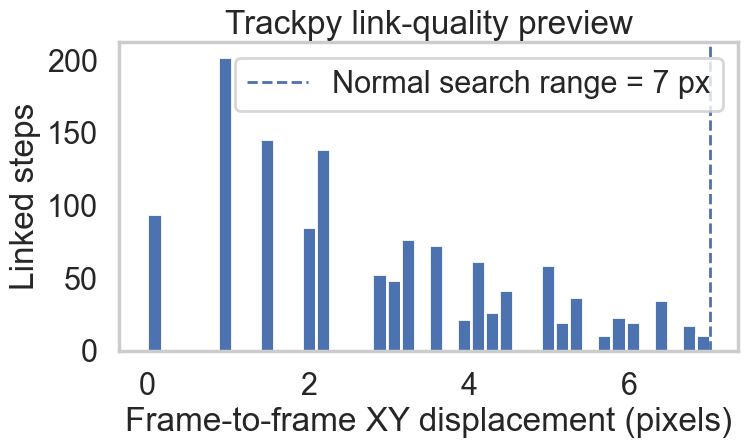

c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
c:\Users\AdamC\anaconda\envs\croparray_pip_env\lib\site-packages\xarray\coding\times.py:250: RuntimeWarning: inv

In [ ]:
# TRACKING PREVIEW
#
# Small subset only.
# NOTHING is saved by this cell.
# ============================================================


PREVIEW_GROUP = "SARS_CTRL"
PREVIEW_TYPE = "No Nsp1"


PREVIEW_CELLS_PER_REPLICATE = 1
PREVIEW_MAX_REPLICATES = 4
PREVIEW_RANDOM_STATE = 7


# ============================================================
# SELECT SAMPLE
# ============================================================

preview_pool = clean_cell_keys.loc[

    clean_cell_keys[
        "Experimental Group"
    ].eq(
        PREVIEW_GROUP
    )

    &

    clean_cell_keys[
        "Experimental Type"
    ].eq(
        PREVIEW_TYPE
    )

].copy()


if preview_pool.empty:

    raise ValueError(
        f"No retained cells for "
        f"{PREVIEW_GROUP} | {PREVIEW_TYPE}"
    )


available_reps = (
    preview_pool[
        "Replicate_Number"
    ]
    .drop_duplicates()
)


n_preview_reps = min(
    PREVIEW_MAX_REPLICATES,
    len(available_reps)
)


preview_reps = (
    available_reps
    .sample(
        n=n_preview_reps,
        random_state=
            PREVIEW_RANDOM_STATE
    )
    .tolist()
)


preview_pool = preview_pool.loc[
    preview_pool[
        "Replicate_Number"
    ].isin(
        preview_reps
    )
].copy()


preview_cell_keys = (
    preview_pool
    .groupby(
        "Replicate_Number",
        group_keys=False
    )
    .apply(
        lambda g:
            g.sample(
                n=min(
                    PREVIEW_CELLS_PER_REPLICATE,
                    len(g)
                ),
                random_state=
                    PREVIEW_RANDOM_STATE
            )
    )
    .reset_index(drop=True)
)


preview_settings = (
    get_link_settings(
        PREVIEW_GROUP,
        PREVIEW_TYPE
    )
)


print(
    f"Preview: "
    f"{PREVIEW_GROUP} | "
    f"{PREVIEW_TYPE}"
)

print(
    f"Settings: "
    f"{preview_settings}"
)

print(
    f"Cells sampled: "
    f"{len(preview_cell_keys)}"
)


display(
    preview_cell_keys
)


# ============================================================
# LINK SAMPLE
# ============================================================

(
    preview_linked_mrna_df,
    preview_cell_qc_df,
    preview_failed_cells_df

) = link_preview_cells(
    preview_cell_keys
)


# ============================================================
# NUCLEAR / CYTOPLASMIC FILTER QC
# ============================================================

print(
    "\nCytoplasmic filtering:"
)


display(
    preview_cell_qc_df[
        [
            "Experimental_Group",
            "Experimental_Type",
            "Replicate_Number",
            "fov",
            "positive_RNA_before_filters",
            "RNA_after_include_exclude",
            "cytoplasmic_RNA_retained",
            "noncytoplasmic_RNA_excluded",
        ]
    ]
)


# ============================================================
# LINKING QC
# ============================================================

summarize_link_quality(
    preview_linked_mrna_df,
    preview_settings
)


if not preview_failed_cells_df.empty:

    print(
        "\nWARNING: Preview cells with "
        "unresolved oversized subnets:"
    )

    display(
        preview_failed_cells_df
    )

In [162]:
# MSD ANALYSIS — CONFIGURATION
#
# Run after the linked mRNA CSV files have been created.
# ============================================================

from pathlib import Path
import gc
import re

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ============================================================
# INPUT / OUTPUT
# ============================================================

TRACKING_OUTPUT_DIR = (
    Path(r"C:\Temp_data\Rapid")
    / "Linked mRNA Tracking CSV"
)

MSD_OUTPUT_DIR = (
    TRACKING_OUTPUT_DIR
    / "MSD"
)

MSD_TRACK_DIR = MSD_OUTPUT_DIR / "Track MSD"
MSD_CELL_DIR = MSD_OUTPUT_DIR / "Cell MSD"
MSD_REPLICATE_DIR = MSD_OUTPUT_DIR / "Replicate MSD"
MSD_GROUP_DIR = MSD_OUTPUT_DIR / "Group MSD"
MSD_FIGURE_DIR = Path(r"Z:\koch\Presentations and Figures\Figures\MSD Plots")

for directory in (
    MSD_TRACK_DIR,
    MSD_CELL_DIR,
    MSD_REPLICATE_DIR,
    MSD_GROUP_DIR,
    MSD_FIGURE_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)


# ============================================================
# SPATIAL CALIBRATION
#
# Preserved from tracked_mRNA_MSD.ipynb
# ============================================================

XY_PIXEL_SIZE_UM = 0.130
Z_STEP_SIZE_UM = 0.500


# ============================================================
# CONDITION-SPECIFIC FRAME INTERVALS
#
# IMPORTANT:
# Enter the TRUE time between complete frames/volumes for each
# Experimental Group x Experimental Type combination.
#
# Values are in SECONDS.
#
# The two KDM5B values below come directly from your older
# tracked_mRNA_MSD notebook.
# ============================================================

FRAME_INTERVAL_SECONDS = {

    ("KDM5B", "No Nsp1"): 1.56,
    ("KDM5B", "Nsp1"): 2.34,
    ("SARS_CTRL", "NoCTD Nsp1"): 2,
    ("SARS_CTRL", "No Nsp1"): 2.6,
    ("SARS_CTRL", "Nsp1"): 2.6,
    ("Emi_KDM5B", "NoCTD Nsp1"): 1.56,
    ("Emi_KDM5B", "No Nsp1"): 1.56,
    ("Emi_KDM5B", "Nsp1"): 1.56,
    ("BoxB_IRES", "No Nsp1"): 1.56,
    ("BoxB_IRES", "Nsp1"): 1.56,
    ("BoxB_MS2", "No Nsp1"): 1.56,
    ("BoxB_MS2", "NoCTD Nsp1"): 1.56,
    ("BoxB_MS2", "Nsp1"): 1.56,
    ("EMI_NoORF", "No Nsp1"): 1.56,
    ("EMI_NoORF", "Nsp1"): 1.56,
    ("Emi_NoStart", "No Nsp1"): 1.56,
    ("Emi_NoStart", "Nsp1"): 1.56,
    ("NORAD", "No Nsp1"): 1.56,
    ("NORAD", "NoCTD Nsp1"): 1.56,
    ("NORAD", "Nsp1"): 1.56,
    ("Normalization_SARS_CTRL", "No Nsp1"): 1.56,
    ("SARS_3'UTR", "No Nsp1"): 2.6,
    ("SARS_3'UTR", "Nsp1"): 2.6,
    ("SARS_5'UTR_3'UTR", "No Nsp1"): 2.6,
    ("SARS_5'UTR_3'UTR", "Nsp1"): 2.6,
    ("SARS_5'UTR", "No Nsp1"): 2.6,
    ("SARS_5'UTR", "Nsp1"): 2.6,
    ("ZNF_KDM5B", "No Nsp1"): 1.56,
    ("ZNF_KDM5B", "Nsp1"): 1.56,
    ("ZNF_SARS_CTRL", "No Nsp1"): 1.56,
    ("ZNF_SARS_CTRL", "Nsp1"): 1.56,
}


# Require an explicit entry above for every linked condition.
# This prevents silently assigning the wrong time axis.
REQUIRE_EXPLICIT_FRAME_INTERVAL = True


# ============================================================
# MSD SETTINGS
#
# Preserved from the previous MSD notebook.
# ============================================================

MSD_MIN_TRACK_LENGTH_FRAMES = 5

# Maximum lag used for each individual trajectory.
MSD_MAX_LAG_FRAMES = 10

# A lag must have at least this many valid displacement pairs.
MSD_MIN_PAIRS_PER_LAG = 3


# ============================================================
# MEMORY SETTINGS
# ============================================================

# Read the linked trajectory CSV incrementally.
MSD_CSV_CHUNK_ROWS = 100_000

# Periodically write track-level MSD to disk.
MSD_SAVE_BUFFER_TRACKS = 500

# True = replace old MSD outputs for a condition.
OVERWRITE_MSD_EXISTING = True


# ============================================================
# PLOTTING SETTINGS
#
# Colors and global style match the main analysis notebook.
# ============================================================

sns.set(font_scale=1.9)
sns.set_style(
    "whitegrid",
    {"grid.linestyle": ""}
)
sns.set_context("poster")


# Same cyan palette used in the original analysis notebook.
blue_palette = sns.color_palette(
    [
        "#00D8D8",
        "#029090",
        "#67FFFF"
    ]
)


TYPE_ORDER = [
    "No Nsp1",
    "Nsp1",
    "NoCTD Nsp1",
]


TYPE_LABELS = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
    "NoCTD Nsp1": "+Δ Nsp1",
}


TYPE_COLORS = {
    experimental_type:
        blue_palette[index]

    for index, experimental_type
    in enumerate(TYPE_ORDER)
}


# Optional display titles matching the main notebook.
GROUP_TITLES = {
    "SARS_CTRL": "Host UTR",
    "Emi_KDM5B": "uORF UTR + ORF",
    "BoxB_MS2": "No ORF",
    "BoxB_IRES": "IRES",
    "KDM5B": "KDM5B Reporter",
    "NORAD": "NORAD",
}


# Same displayed time range for all conditions.
# This is independent of MSD_MAX_LAG_FRAMES.
MSD_X_MIN_SECONDS = 0
MSD_X_MAX_SECONDS = 15


# None = automatic y-axis.
MSD_2D_YLIM = None
MSD_3D_YLIM = None


SAVE_MSD_FIGURES = True
FIGURE_DPI = 300


print(
    f"Linked trajectory input:\n"
    f"{TRACKING_OUTPUT_DIR}"
)

print(
    f"\nMSD output:\n"
    f"{MSD_OUTPUT_DIR}"
)

Linked trajectory input:
C:\Temp_data\Rapid\Linked mRNA Tracking CSV

MSD output:
C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MSD


In [ ]:
# MEMORY-SAFE FULL mRNA TRACKING + STREAMING CSV SAVE
#
# This replaces BOTH:
#     old "FULL LINKING" cell
#     old "SAVE LINKED mRNA TRACKS" cell
# ============================================================


def make_tracking_safe_filename(
    text
):

    text = str(
        text
    ).strip()


    text = re.sub(
        r'[<>:"/\\|?*]',
        "_",
        text
    )


    text = re.sub(
        r"\s+",
        "_",
        text
    )


    return text



def _append_dataframe_to_csv(
    df,
    path
):
    """
    Append dataframe to CSV without retaining previous rows in RAM.
    """

    if (
        df is None
        or df.empty
    ):

        return


    write_header = (
        not path.exists()
    )


    df.to_csv(
        path,
        mode="a",
        header=write_header,
        index=False,
        date_format="%Y-%m-%d"
    )



def process_condition_to_disk(
    condition_keys,
    group,
    exp_type,
):
    """
    Link and save ONE Group x Type condition.

    Only SAVE_BUFFER_CELLS cells are held before writing.
    """


    settings = get_link_settings(
        group,
        exp_type
    )


    safe_group = (
        make_tracking_safe_filename(
            group
        )
    )


    safe_type = (
        make_tracking_safe_filename(
            exp_type
        )
    )


    base_name = (
        f"{safe_group}_"
        f"{safe_type}"
    )


    # ========================================================
    # OUTPUT PATHS
    # ========================================================

    linked_final = (
        TRACKING_OUTPUT_DIR
        /
        f"{base_name}_mRNA_linked.csv"
    )


    summary_final = (
        TRACKING_OUTPUT_DIR
        /
        f"{base_name}_mRNA_track_summary.csv"
    )


    qc_final = (
        TRACKING_OUTPUT_DIR
        /
        f"{base_name}_mRNA_cell_QC.csv"
    )


    failures_final = (
        TRACKING_OUTPUT_DIR
        /
        f"{base_name}_mRNA_link_failures.csv"
    )


    # Write active jobs into *.partial.csv.
    linked_partial = (
        TRACKING_OUTPUT_DIR
        /
        f"{base_name}_mRNA_linked.partial.csv"
    )


    summary_partial = (
        TRACKING_OUTPUT_DIR
        /
        f"{base_name}_mRNA_track_summary.partial.csv"
    )


    # ========================================================
    # EXISTING OUTPUT
    # ========================================================

    if (
        linked_final.exists()
        and not OVERWRITE_EXISTING
    ):

        print(
            "Already complete — skipping:"
        )

        print(
            linked_final
        )


        return {

            "Experimental_Group":
                group,

            "Experimental_Type":
                exp_type,

            "status":
                "skipped_existing",

            "linked_file":
                str(linked_final),

            "summary_file":
                str(summary_final),

            "n_cells_requested":
                len(condition_keys),

            "search_range_px":
                settings["search_range"],

            "memory_frames":
                settings["memory"],

            "adaptive_stop_px":
                settings.get(
                    "adaptive_stop",
                    np.nan
                ),
        }


    # ========================================================
    # CLEAN OLD OUTPUT IF OVERWRITING
    # ========================================================

    if OVERWRITE_EXISTING:

        for path in [
            linked_final,
            summary_final,
            qc_final,
            failures_final,
            linked_partial,
            summary_partial,
        ]:

            if path.exists():

                path.unlink()


    else:

        # Remove stale partial output from an interrupted prior run.
        for path in [
            linked_partial,
            summary_partial,
        ]:

            if path.exists():

                path.unlink()


    # ========================================================
    # PROCESS CELLS
    # ========================================================

    linked_buffer = []

    qc_rows = []

    failure_rows = []


    n_cells_successful = 0

    n_linked_rows = 0

    n_tracks = 0

    n_msd_tracks = 0


    total_cells = len(
        condition_keys
    )


    for cell_i, values in enumerate(

        condition_keys[
            [
                "Experimental Group",
                "Experimental Type",
                "Replicate_Number",
                "fov"
            ]
        ].itertuples(
            index=False,
            name=None
        ),

        start=1
    ):

        (
            cell_group,
            cell_type,
            rep,
            fov
        ) = values


        rep = int(rep)
        fov = int(fov)


        key = (
            str(cell_group),
            str(cell_type)
        )


        if key not in CONDITION_TO_EXP_G:

            print(
                f"[skip] No Exp_G mapping "
                f"for {key}"
            )

            continue


        raw_exp_g = (
            CONDITION_TO_EXP_G[key]
        )


        # ----------------------------------------------------
        # Extract CYTOPLASMIC RNA only
        # ----------------------------------------------------

        (
            detections,
            extraction_qc
        ) = extract_mrna_detections_for_cell(

            TRACKING_SOURCE_DS,

            raw_exp_g=
                raw_exp_g,

            fov=
                fov,

            group=
                cell_group,

            exp_type=
                cell_type,

            replicate_number=
                rep,

            frame_interval_s=
                settings[
                    "frame_interval_s"
                ],
        )


        qc_rows.append(
            extraction_qc
        )


        # ----------------------------------------------------
        # Link
        # ----------------------------------------------------

        try:

            linked = link_one_mrna_cell(
                detections,
                settings
            )


        except Exception as exc:

            if not _is_subnet_oversize_exception(
                exc
            ):

                raise


            failure_row = (
                _make_link_failure_row(
                    detections,
                    cell_group,
                    cell_type,
                    rep,
                    fov,
                    settings,
                    exc,
                )
            )


            failure_rows.append(
                failure_row
            )


            print(
                "\n*** OVERSIZED SUBNET ***"
            )

            print(
                f"{cell_group} | "
                f"{cell_type} | "
                f"Rep {rep} | "
                f"FOV {fov}"
            )

            print(
                str(exc)
            )

            print(
                "Cell skipped; analysis continues.\n"
            )


            del detections

            gc.collect()

            continue


        del detections


        if linked.empty:

            continue


        n_cells_successful += 1

        n_linked_rows += len(
            linked
        )


        track_summary = (
            make_track_summary(
                linked
            )
        )


        n_tracks += len(
            track_summary
        )


        if (
            "keep_for_msd"
            in track_summary
        ):

            n_msd_tracks += int(
                track_summary[
                    "keep_for_msd"
                ].sum()
            )


        linked_buffer.append(
            linked
        )


        # ----------------------------------------------------
        # FLUSH BUFFER TO DISK
        # ----------------------------------------------------

        if (
            len(linked_buffer)
            >= SAVE_BUFFER_CELLS
        ):

            buffer_df = pd.concat(
                linked_buffer,
                ignore_index=True
            )


            buffer_summary = (
                make_track_summary(
                    buffer_df
                )
            )


            _append_dataframe_to_csv(
                buffer_df,
                linked_partial
            )


            _append_dataframe_to_csv(
                buffer_summary,
                summary_partial
            )


            del (
                buffer_df,
                buffer_summary,
                linked_buffer
            )


            linked_buffer = []


            gc.collect()


        if (
            cell_i == 1
            or cell_i % 10 == 0
            or cell_i == total_cells
        ):

            print(
                f"  {group} | {exp_type}: "
                f"{cell_i}/{total_cells} cells"
            )


    # ========================================================
    # FINAL BUFFER FLUSH
    # ========================================================

    if linked_buffer:

        buffer_df = pd.concat(
            linked_buffer,
            ignore_index=True
        )


        buffer_summary = (
            make_track_summary(
                buffer_df
            )
        )


        _append_dataframe_to_csv(
            buffer_df,
            linked_partial
        )


        _append_dataframe_to_csv(
            buffer_summary,
            summary_partial
        )


        del (
            buffer_df,
            buffer_summary,
            linked_buffer
        )


        gc.collect()


    # ========================================================
    # SAVE CELL QC
    # ========================================================

    cell_qc_df = pd.DataFrame(
        qc_rows
    )


    cell_qc_df.to_csv(
        qc_final,
        index=False
    )


    # ========================================================
    # SAVE FAILURES
    # ========================================================

    if failure_rows:

        failure_df = pd.DataFrame(
            failure_rows
        )


        failure_df.to_csv(
            failures_final,
            index=False
        )


    else:

        failure_df = pd.DataFrame()


    # ========================================================
    # FINALIZE PARTIAL FILES
    # ========================================================

    if linked_partial.exists():

        if linked_final.exists():
            linked_final.unlink()

        linked_partial.replace(
            linked_final
        )


    if summary_partial.exists():

        if summary_final.exists():
            summary_final.unlink()

        summary_partial.replace(
            summary_final
        )


    # ========================================================
    # REPORT
    # ========================================================

    noncyto_excluded = int(
        cell_qc_df[
            "noncytoplasmic_RNA_excluded"
        ].sum()
    ) if len(cell_qc_df) else 0


    cyto_retained = int(
        cell_qc_df[
            "cytoplasmic_RNA_retained"
        ].sum()
    ) if len(cell_qc_df) else 0


    print(
        "\nFinished condition:"
    )

    print(
        f"  {group} | {exp_type}"
    )

    print(
        f"  Cells successfully linked: "
        f"{n_cells_successful}/{total_cells}"
    )

    print(
        f"  Cytoplasmic RNA retained: "
        f"{cyto_retained:,}"
    )

    print(
        f"  Noncytoplasmic RNA excluded: "
        f"{noncyto_excluded:,}"
    )

    print(
        f"  Linked rows: "
        f"{n_linked_rows:,}"
    )

    print(
        f"  Tracks: "
        f"{n_tracks:,}"
    )

    print(
        f"  MSD-eligible tracks: "
        f"{n_msd_tracks:,}"
    )

    print(
        f"  Failed cells: "
        f"{len(failure_rows)}"
    )

    print(
        f"  Saved: {linked_final}"
    )


    del (
        cell_qc_df,
        failure_df,
        qc_rows,
        failure_rows
    )


    gc.collect()


    return {

        "Experimental_Group":
            group,

        "Experimental_Type":
            exp_type,

        "status":
            "complete",

        "n_cells_requested":
            total_cells,

        "n_cells_successful":
            n_cells_successful,

        "n_failed_cells":
            len(failure_rows)
            if "failure_rows" in locals()
            else 0,

        "n_linked_rows":
            n_linked_rows,

        "n_tracks":
            n_tracks,

        "n_msd_tracks":
            n_msd_tracks,

        "cytoplasmic_RNA_retained":
            cyto_retained,

        "noncytoplasmic_RNA_excluded":
            noncyto_excluded,

        "search_range_px":
            settings[
                "search_range"
            ],

        "memory_frames":
            settings[
                "memory"
            ],

        "adaptive_stop_px":
            settings.get(
                "adaptive_stop",
                np.nan
            ),

        "adaptive_step":
            settings.get(
                "adaptive_step",
                np.nan
            ),

        "frame_interval_s":
            settings[
                "frame_interval_s"
            ],

        "linked_file":
            str(linked_final),

        "summary_file":
            str(summary_final),

        "cell_QC_file":
            str(qc_final),

        "failure_file":
            (
                str(failures_final)
                if failures_final.exists()
                else ""
            ),
    }



# ============================================================
# RUN ENTIRE EXPERIMENT
#
# Outer loop = Experimental Group
# Inner loop = Experimental Type
#
# Data are written and cleared before moving forward.
# ============================================================

tracking_manifest_rows = []


experimental_groups = (
    clean_cell_keys[
        "Experimental Group"
    ]
    .drop_duplicates()
    .tolist()
)


for group_i, group in enumerate(
    experimental_groups,
    start=1
):


    print(
        "\n"
        + "=" * 70
    )

    print(
        f"EXPERIMENTAL GROUP "
        f"{group_i}/{len(experimental_groups)}: "
        f"{group}"
    )

    print(
        "=" * 70
    )


    group_keys = clean_cell_keys.loc[
        clean_cell_keys[
            "Experimental Group"
        ].eq(
            group
        )
    ].copy()


    experimental_types = (
        group_keys[
            "Experimental Type"
        ]
        .drop_duplicates()
        .tolist()
    )


    for exp_type in experimental_types:


        condition_keys = (
            group_keys.loc[
                group_keys[
                    "Experimental Type"
                ].eq(
                    exp_type
                )
            ]
            .copy()
            .reset_index(drop=True)
        )


        print(
            "\nProcessing condition:"
        )

        print(
            f"  {group} | {exp_type}"
        )

        print(
            f"  Cells: "
            f"{len(condition_keys)}"
        )

        print(
            f"  Settings: "
            f"{get_link_settings(group, exp_type)}"
        )


        result = (
            process_condition_to_disk(
                condition_keys,
                group,
                exp_type
            )
        )


        tracking_manifest_rows.append(
            result
        )


        # Explicitly free condition data before continuing.
        del (
            condition_keys,
            result
        )


        gc.collect()


    # Explicitly free the complete group before the next group.
    del group_keys

    gc.collect()


# ============================================================
# SMALL MANIFEST ONLY
# ============================================================

tracking_manifest_df = pd.DataFrame(
    tracking_manifest_rows
)


manifest_path = (
    TRACKING_OUTPUT_DIR
    /
    "mRNA_tracking_manifest.csv"
)


tracking_manifest_df.to_csv(
    manifest_path,
    index=False
)


print(
    "\n"
    + "=" * 70
)

print(
    "TRACKING COMPLETE"
)

print(
    "=" * 70
)


display(
    tracking_manifest_df
)


print(
    f"\nManifest saved:\n"
    f"{manifest_path}"
)

Frame 19: 92 trajectories present.
  ZNF_SARS_CTRL | No Nsp1: 36/36 cells

Finished condition:
  ZNF_SARS_CTRL | No Nsp1
  Cells successfully linked: 36/36
  Cytoplasmic RNA retained: 91,866
  Noncytoplasmic RNA excluded: 25,061
  Linked rows: 91,866
  Tracks: 25,728
  MSD-eligible tracks: 6,078
  Failed cells: 0
  Saved: C:\Temp_data\Rapid\Linked mRNA Tracking CSV\ZNF_SARS_CTRL_No_Nsp1_mRNA_linked.csv

TRACKING COMPLETE


,Experimental_Group,Experimental_Type,status,n_cells_requested,n_cells_successful,n_failed_cells,n_linked_rows,n_tracks,n_msd_tracks,cytoplasmic_RNA_retained,noncytoplasmic_RNA_excluded,search_range_px,memory_frames,adaptive_stop_px,adaptive_step,frame_interval_s,linked_file,summary_file,cell_QC_file,failure_file
0,BoxB_IRES,No Nsp1,complete,30,30,0,54011,14056,3382,54011,25533,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,
1,BoxB_IRES,Nsp1,complete,27,27,0,57771,17391,3464,57771,40756,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,
2,BoxB_MS2,No Nsp1,complete,90,90,0,195488,64561,11225,195488,124505,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,
3,BoxB_MS2,NoCTD Nsp1,complete,81,81,0,158275,51355,9084,158275,87476,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,
4,BoxB_MS2,Nsp1,complete,78,78,0,191769,58791,11771,191769,120045,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,
5,EMI_NoORF,No Nsp1,complete,40,40,0,77812,24533,4382,77812,55881,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...,
6,EMI_NoORF,Nsp1,complete,28,28,0,34616,11400,1877,34616,28281,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...,
7,Emi_KDM5B,No Nsp1,complete,34,34,0,102929,28511,6874,102929,40145,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,
8,Emi_KDM5B,NoCTD Nsp1,complete,35,35,0,94684,27731,6090,94684,37060,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,
9,Emi_KDM5B,Nsp1,complete,36,36,0,32900,12472,1635,32900,35990,7.0,1,2.0,0.9,1.0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,



Manifest saved:
C:\Temp_data\Rapid\Linked mRNA Tracking CSV\mRNA_tracking_manifest.csv


In [287]:
# MSD ANALYSIS — CALCULATION + STREAMING HELPERS
# ============================================================


def make_safe_filename(text):

    text = str(text).strip()

    text = re.sub(
        r'[<>:"/\\|?*]',
        "_",
        text
    )

    text = re.sub(
        r"\s+",
        "_",
        text
    )

    return text



def get_frame_interval_seconds(
    group,
    exp_type
):
    """
    Return the explicitly configured acquisition interval for
    one Experimental Group x Experimental Type.
    """

    key = (
        str(group),
        str(exp_type)
    )


    if key in FRAME_INTERVAL_SECONDS:

        value = float(
            FRAME_INTERVAL_SECONDS[key]
        )


        if (
            not np.isfinite(value)
            or value <= 0
        ):

            raise ValueError(
                f"Invalid frame interval "
                f"for {key}: {value}"
            )


        return value


    if REQUIRE_EXPLICIT_FRAME_INTERVAL:

        raise KeyError(
            "No frame interval has been configured for "
            f"{key}. Add it to FRAME_INTERVAL_SECONDS."
        )


    return np.nan



def inspect_linked_conditions():
    """
    Discover completed linked mRNA CSVs and report whether each
    condition has an explicit frame interval.
    """

    files = sorted(
        TRACKING_OUTPUT_DIR.glob(
            "*_mRNA_linked.csv"
        )
    )


    rows = []


    for path in files:

        if ".partial" in path.name:
            continue


        preview = pd.read_csv(
            path,
            nrows=1
        )


        if preview.empty:
            continue


        required = {
            "Experimental_Group",
            "Experimental_Type"
        }


        missing = required.difference(
            preview.columns
        )


        if missing:

            raise KeyError(
                f"{path.name} is missing columns: "
                f"{sorted(missing)}"
            )


        group = str(
            preview[
                "Experimental_Group"
            ].iloc[0]
        )


        exp_type = str(
            preview[
                "Experimental_Type"
            ].iloc[0]
        )


        key = (
            group,
            exp_type
        )


        rows.append({

            "Experimental_Group":
                group,

            "Experimental_Type":
                exp_type,

            "Linked_CSV":
                str(path),

            "Frame_Interval_Seconds":
                FRAME_INTERVAL_SECONDS.get(
                    key,
                    np.nan
                ),

            "Frame_Interval_Configured":
                key in FRAME_INTERVAL_SECONDS,
        })


    return pd.DataFrame(
        rows
    )



def iter_tracks_from_linked_csv(
    csv_path,
    chunksize=MSD_CSV_CHUNK_ROWS
):
    """
    Yield one COMPLETE trajectory at a time without loading
    the entire condition CSV into memory.

    The carry-over block protects a trajectory if pandas
    happens to split it across two CSV chunks.
    """

    csv_path = Path(
        csv_path
    )


    carry = pd.DataFrame()


    required = {
        "track_uid",
        "frame",
        "x",
        "y",
        "z",
        "Experimental_Group",
        "Experimental_Type",
        "Replicate_Number",
        "fov"
    }


    for chunk in pd.read_csv(
        csv_path,
        chunksize=int(chunksize)
    ):


        missing = required.difference(
            chunk.columns
        )


        if missing:

            raise KeyError(
                f"{csv_path.name} is missing columns: "
                f"{sorted(missing)}"
            )


        if not carry.empty:

            chunk = pd.concat(
                [
                    carry,
                    chunk
                ],
                ignore_index=True
            )

            carry = pd.DataFrame()


        if chunk.empty:
            continue


        # The final track may continue into the next CSV chunk.
        last_track_uid = str(
            chunk[
                "track_uid"
            ].iloc[-1]
        )


        is_last_track = (
            chunk[
                "track_uid"
            ]
            .astype(str)
            .eq(
                last_track_uid
            )
        )


        complete = (
            chunk.loc[
                ~is_last_track
            ]
            .copy()
        )


        carry = (
            chunk.loc[
                is_last_track
            ]
            .copy()
        )


        if not complete.empty:

            for track_uid, track in (
                complete.groupby(
                    "track_uid",
                    sort=False
                )
            ):

                yield (
                    str(track_uid),
                    track.copy()
                )


        del chunk
        del complete

        gc.collect()


    # Final track in the file
    if not carry.empty:

        for track_uid, track in (
            carry.groupby(
                "track_uid",
                sort=False
            )
        ):

            yield (
                str(track_uid),
                track.copy()
            )



def calculate_single_track_msd(
    track,
    *,
    frame_interval_seconds,
    max_lag_frames=
        MSD_MAX_LAG_FRAMES,
    min_pairs_per_lag=
        MSD_MIN_PAIRS_PER_LAG,
    min_track_length=
        MSD_MIN_TRACK_LENGTH_FRAMES
):
    """
    Calculate time-averaged 2D and 3D MSD for ONE trajectory.

    Logic matches the previous tracked_mRNA_MSD notebook:

        1. sort by time
        2. one localization per frame
        3. convert into µm
        4. calculate exact frame-separated displacement pairs
        5. explicitly handle missing frames
        6. average squared displacement for each lag
    """


    if (
        track is None
        or track.empty
    ):

        return pd.DataFrame()


    track = (
        track
        .sort_values(
            "frame"
        )
        .drop_duplicates(
            "frame",
            keep="last"
        )
        .reset_index(
            drop=True
        )
    )


    if len(track) < int(
        min_track_length
    ):

        return pd.DataFrame()


    # ========================================================
    # NUMERIC POSITION VALUES
    # ========================================================

    for column in [
        "frame",
        "x",
        "y",
        "z"
    ]:

        track[column] = pd.to_numeric(
            track[column],
            errors="coerce"
        )


    track = (
        track
        .dropna(
            subset=[
                "frame",
                "x",
                "y",
                "z"
            ]
        )
        .copy()
    )


    if len(track) < int(
        min_track_length
    ):

        return pd.DataFrame()


    track["frame"] = (
        track["frame"]
        .astype(int)
    )


    # ========================================================
    # CONVERT TO PHYSICAL UNITS
    # ========================================================

    track["x_um"] = (
        track["x"]
        * float(
            XY_PIXEL_SIZE_UM
        )
    )


    track["y_um"] = (
        track["y"]
        * float(
            XY_PIXEL_SIZE_UM
        )
    )


    track["z_um"] = (
        track["z"]
        * float(
            Z_STEP_SIZE_UM
        )
    )


    # ========================================================
    # FRAME LOOKUP
    # ========================================================

    frame_to_index = {

        int(frame):
            index

        for index, frame
        in enumerate(
            track["frame"]
        )
    }


    maximum_possible_lag = int(

        track[
            "frame"
        ].max()

        -

        track[
            "frame"
        ].min()
    )


    current_max_lag = min(

        int(
            max_lag_frames
        ),

        maximum_possible_lag
    )


    first = track.iloc[0]


    group = str(
        first[
            "Experimental_Group"
        ]
    )


    exp_type = str(
        first[
            "Experimental_Type"
        ]
    )


    replicate = int(
        first[
            "Replicate_Number"
        ]
    )


    fov = int(
        first[
            "fov"
        ]
    )


    cell_number = (

        first["Cell_Number"]

        if "Cell_Number"
        in track.columns

        else np.nan
    )


    date_value = (

        first["Date"]

        if "Date"
        in track.columns

        else np.nan
    )


    track_uid = str(
        first[
            "track_uid"
        ]
    )


    cell_uid = (

        f"{group}|"
        f"{exp_type}|"
        f"R{replicate}|"
        f"F{fov}"
    )


    rows = []


    # ========================================================
    # MSD AT EACH LAG
    # ========================================================

    for lag_frames in range(
        1,
        current_max_lag + 1
    ):


        displacement_2d = []
        displacement_3d = []

        dx_values = []
        dy_values = []
        dz_values = []


        for index, row in (
            track.iterrows()
        ):


            target_frame = (

                int(
                    row["frame"]
                )

                +

                lag_frames
            )


            target_index = (
                frame_to_index.get(
                    target_frame
                )
            )


            # -----------------------------------------------
            # GAP HANDLING
            #
            # If that exact target frame was not detected,
            # this pair simply does not contribute.
            # -----------------------------------------------

            if target_index is None:
                continue


            target = (
                track.iloc[
                    target_index
                ]
            )


            dx = float(

                target[
                    "x_um"
                ]

                -

                row[
                    "x_um"
                ]
            )


            dy = float(

                target[
                    "y_um"
                ]

                -

                row[
                    "y_um"
                ]
            )


            dz = float(

                target[
                    "z_um"
                ]

                -

                row[
                    "z_um"
                ]
            )


            dx_values.append(
                dx
            )

            dy_values.append(
                dy
            )

            dz_values.append(
                dz
            )


            # 2D squared displacement
            displacement_2d.append(

                dx**2
                +
                dy**2
            )


            # 3D squared displacement
            displacement_3d.append(

                dx**2
                +
                dy**2
                +
                dz**2
            )


        pair_count = len(
            displacement_2d
        )


        if pair_count < int(
            min_pairs_per_lag
        ):

            continue


        rows.append({

            "Track_UID":
                track_uid,

            "Cell_UID":
                cell_uid,

            "Experimental_Group":
                group,

            "Experimental_Type":
                exp_type,

            "Replicate_Number":
                replicate,

            "Date":
                date_value,

            "fov":
                fov,

            "Cell_Number":
                cell_number,

            "Lag_Frames":
                int(
                    lag_frames
                ),

            "Lag_Seconds":
                float(
                    lag_frames
                    *
                    frame_interval_seconds
                ),

            "Pair_Count":
                int(
                    pair_count
                ),

            "MSD_2D_um2":
                float(
                    np.mean(
                        displacement_2d
                    )
                ),

            "MSD_3D_um2":
                float(
                    np.mean(
                        displacement_3d
                    )
                ),

            "Mean_Dx_um":
                float(
                    np.mean(
                        dx_values
                    )
                ),

            "Mean_Dy_um":
                float(
                    np.mean(
                        dy_values
                    )
                ),

            "Mean_Dz_um":
                float(
                    np.mean(
                        dz_values
                    )
                ),

            "Track_Length":
                int(
                    len(track)
                ),

            "Frame_Interval_Seconds":
                float(
                    frame_interval_seconds
                ),
        })


    return pd.DataFrame(
        rows
    )

In [288]:
# MSD ANALYSIS — PROCESS LINKED CSVs MEMORY-SAFELY
# ============================================================


MSD_METRICS = [
    "MSD_2D_um2",
    "MSD_3D_um2",
    "Mean_Dx_um",
    "Mean_Dy_um",
    "Mean_Dz_um",
]



def _append_csv(
    dataframe,
    path
):

    if (
        dataframe is None
        or dataframe.empty
    ):

        return


    path = Path(
        path
    )


    dataframe.to_csv(

        path,

        mode="a",

        header=
            not path.exists(),

        index=False
    )



def _normalize_key_value(
    value
):

    if pd.isna(
        value
    ):

        return None


    return value



def _update_cell_accumulator(
    accumulator,
    track_msd
):
    """
    Add track-level MSD values into per-cell sums.

    IMPORTANT:
    Tracks contribute equally.

    Pair_Count is retained for QC but is NOT used to weight
    the MSD average.
    """


    if (
        track_msd is None
        or track_msd.empty
    ):

        return


    for row in (
        track_msd.itertuples(
            index=False
        )
    ):


        key = (

            str(
                row.Experimental_Group
            ),

            str(
                row.Experimental_Type
            ),

            int(
                row.Replicate_Number
            ),

            _normalize_key_value(
                row.Date
            ),

            str(
                row.Cell_UID
            ),

            int(
                row.fov
            ),

            _normalize_key_value(
                row.Cell_Number
            ),

            int(
                row.Lag_Frames
            ),

            float(
                row.Lag_Seconds
            ),

            float(
                row.Frame_Interval_Seconds
            ),
        )


        if key not in accumulator:

            accumulator[key] = {

                "Track_Count":
                    0,

                "Total_Pairs":
                    0,

                **{
                    f"{metric}_sum":
                        0.0

                    for metric
                    in MSD_METRICS
                },
            }


        entry = (
            accumulator[key]
        )


        entry[
            "Track_Count"
        ] += 1


        entry[
            "Total_Pairs"
        ] += int(
            row.Pair_Count
        )


        for metric in (
            MSD_METRICS
        ):


            value = getattr(
                row,
                metric
            )


            if pd.notna(
                value
            ):

                entry[
                    f"{metric}_sum"
                ] += float(
                    value
                )



def _cell_msd_from_accumulator(
    accumulator
):
    """
    Convert running per-cell values into the final cell-level
    MSD dataframe.
    """


    rows = []


    for key, values in (
        accumulator.items()
    ):


        (
            group,
            exp_type,
            replicate,
            date_value,
            cell_uid,
            fov,
            cell_number,
            lag_frames,
            lag_seconds,
            frame_interval
        ) = key


        track_count = int(
            values[
                "Track_Count"
            ]
        )


        if track_count <= 0:
            continue


        output = {

            "Experimental_Group":
                group,

            "Experimental_Type":
                exp_type,

            "Replicate_Number":
                replicate,

            "Date":
                date_value,

            "Cell_UID":
                cell_uid,

            "fov":
                fov,

            "Cell_Number":
                cell_number,

            "Lag_Frames":
                lag_frames,

            "Lag_Seconds":
                lag_seconds,

            "Frame_Interval_Seconds":
                frame_interval,

            "Track_Count":
                track_count,

            "Total_Pairs":
                int(
                    values[
                        "Total_Pairs"
                    ]
                ),
        }


        for metric in (
            MSD_METRICS
        ):


            output[
                metric
            ] = (

                values[
                    f"{metric}_sum"
                ]

                /

                track_count
            )


        rows.append(
            output
        )


    return pd.DataFrame(
        rows
    )



def _make_replicate_msd(
    cell_msd
):
    """
    Average cells within each biological replicate.

    Each cell contributes equally.
    """


    if (
        cell_msd is None
        or cell_msd.empty
    ):

        return pd.DataFrame()


    replicate_group_columns = [

        "Experimental_Group",
        "Experimental_Type",
        "Replicate_Number",
        "Lag_Frames",
        "Lag_Seconds",
        "Frame_Interval_Seconds",
    ]


    replicate_msd = (

        cell_msd

        .groupby(
            replicate_group_columns,
            dropna=False
        )

        .agg(

            **{
                metric: (
                    metric,
                    "mean"
                )

                for metric
                in MSD_METRICS
            },

            Cell_Count=(
                "Cell_UID",
                "nunique"
            ),

            Track_Count=(
                "Track_Count",
                "sum"
            ),

            Total_Pairs=(
                "Total_Pairs",
                "sum"
            ),
        )

        .reset_index()
    )


    return replicate_msd



def process_linked_csv_to_msd(
    linked_csv
):
    """
    Process ONE Experimental Group x Type CSV.

    Track-level MSD is periodically written to disk.
    Only compact per-cell sums remain in memory.
    """


    linked_csv = Path(
        linked_csv
    )


    preview = pd.read_csv(
        linked_csv,
        nrows=1
    )


    if preview.empty:

        raise ValueError(
            f"Linked CSV is empty:\n"
            f"{linked_csv}"
        )


    group = str(
        preview[
            "Experimental_Group"
        ].iloc[0]
    )


    exp_type = str(
        preview[
            "Experimental_Type"
        ].iloc[0]
    )


    frame_interval = (
        get_frame_interval_seconds(
            group,
            exp_type
        )
    )


    safe_group = (
        make_safe_filename(
            group
        )
    )


    safe_type = (
        make_safe_filename(
            exp_type
        )
    )


    base_name = (

        f"{safe_group}_"
        f"{safe_type}"
    )


    # ========================================================
    # OUTPUT FILES
    # ========================================================

    track_final = (

        MSD_TRACK_DIR
        /
        f"{base_name}_track_MSD.csv"
    )


    track_partial = (

        MSD_TRACK_DIR
        /
        f"{base_name}_track_MSD.partial.csv"
    )


    cell_final = (

        MSD_CELL_DIR
        /
        f"{base_name}_cell_MSD.csv"
    )


    replicate_final = (

        MSD_REPLICATE_DIR
        /
        f"{base_name}_replicate_MSD.csv"
    )


    # ========================================================
    # EXISTING OUTPUT
    # ========================================================

    if (

        track_final.exists()
        and cell_final.exists()
        and replicate_final.exists()
        and not OVERWRITE_MSD_EXISTING

    ):


        print(
            f"Already complete — skipping: "
            f"{group} | {exp_type}"
        )


        return {

            "Experimental_Group":
                group,

            "Experimental_Type":
                exp_type,

            "Frame_Interval_Seconds":
                frame_interval,

            "Status":
                "skipped_existing",

            "Track_MSD_CSV":
                str(
                    track_final
                ),

            "Cell_MSD_CSV":
                str(
                    cell_final
                ),

            "Replicate_MSD_CSV":
                str(
                    replicate_final
                ),
        }


    if OVERWRITE_MSD_EXISTING:


        for path in (

            track_final,
            track_partial,
            cell_final,
            replicate_final

        ):


            if path.exists():

                path.unlink()


    elif track_partial.exists():

        track_partial.unlink()


    # ========================================================
    # STREAM TRACKS
    # ========================================================

    track_buffer = []

    buffered_tracks = 0

    cell_accumulator = {}


    tracks_seen = 0
    tracks_used = 0

    tracks_too_short = 0

    tracks_without_valid_lags = 0

    track_lag_rows = 0


    for (
        track_uid,
        track
    ) in iter_tracks_from_linked_csv(
        linked_csv
    ):


        tracks_seen += 1


        n_unique_frames = (

            pd.to_numeric(
                track[
                    "frame"
                ],
                errors="coerce"
            )

            .dropna()

            .nunique()
        )


        # ----------------------------------------------------
        # LENGTH FILTER
        # ----------------------------------------------------

        if (
            n_unique_frames
            <
            MSD_MIN_TRACK_LENGTH_FRAMES
        ):


            tracks_too_short += 1

            del track

            continue


        # ----------------------------------------------------
        # CALCULATE MSD
        # ----------------------------------------------------

        track_msd = (
            calculate_single_track_msd(

                track,

                frame_interval_seconds=
                    frame_interval
            )
        )


        del track


        if track_msd.empty:


            tracks_without_valid_lags += 1

            continue


        tracks_used += 1


        track_lag_rows += (
            len(
                track_msd
            )
        )


        # ----------------------------------------------------
        # ADD TO CELL AVERAGE
        # ----------------------------------------------------

        _update_cell_accumulator(

            cell_accumulator,

            track_msd
        )


        # ----------------------------------------------------
        # SAVE BUFFER
        # ----------------------------------------------------

        track_buffer.append(
            track_msd
        )


        buffered_tracks += 1


        if (
            buffered_tracks
            >=
            MSD_SAVE_BUFFER_TRACKS
        ):


            buffer_df = pd.concat(

                track_buffer,

                ignore_index=True
            )


            _append_csv(

                buffer_df,

                track_partial
            )


            del buffer_df
            del track_buffer


            track_buffer = []

            buffered_tracks = 0


            gc.collect()


        if (
            tracks_seen == 1
            or tracks_seen % 1000 == 0
        ):


            print(

                f"  {group} | {exp_type}: "
                f"{tracks_seen:,} tracks read"
            )


    # ========================================================
    # FINAL TRACK BUFFER
    # ========================================================

    if track_buffer:


        buffer_df = pd.concat(

            track_buffer,

            ignore_index=True
        )


        _append_csv(

            buffer_df,

            track_partial
        )


        del buffer_df
        del track_buffer


        gc.collect()


    # ========================================================
    # TRACK -> CELL
    # ========================================================

    cell_msd = (
        _cell_msd_from_accumulator(
            cell_accumulator
        )
    )


    # ========================================================
    # CELL -> BIOLOGICAL REPLICATE
    # ========================================================

    replicate_msd = (
        _make_replicate_msd(
            cell_msd
        )
    )


    # ========================================================
    # SAVE
    # ========================================================

    cell_msd.to_csv(
        cell_final,
        index=False
    )


    replicate_msd.to_csv(
        replicate_final,
        index=False
    )


    # Rename partial file only after successful completion.
    if track_partial.exists():


        if track_final.exists():

            track_final.unlink()


        track_partial.replace(
            track_final
        )


    # ========================================================
    # REPORT
    # ========================================================

    print(
        f"\nFinished MSD: "
        f"{group} | {exp_type}"
    )


    print(
        f"  Frame interval: "
        f"{frame_interval:g} s"
    )


    print(
        f"  Tracks read: "
        f"{tracks_seen:,}"
    )


    print(
        f"  Tracks used: "
        f"{tracks_used:,}"
    )


    print(
        f"  Too short: "
        f"{tracks_too_short:,}"
    )


    print(
        f"  No lag with >= "
        f"{MSD_MIN_PAIRS_PER_LAG} pairs: "
        f"{tracks_without_valid_lags:,}"
    )


    print(
        f"  Track-lag rows: "
        f"{track_lag_rows:,}"
    )


    print(
        f"  Cell-lag rows: "
        f"{len(cell_msd):,}"
    )


    print(
        f"  Replicate-lag rows: "
        f"{len(replicate_msd):,}"
    )


    result = {

        "Experimental_Group":
            group,

        "Experimental_Type":
            exp_type,

        "Frame_Interval_Seconds":
            frame_interval,

        "Status":
            "complete",

        "Tracks_Read":
            tracks_seen,

        "Tracks_Used":
            tracks_used,

        "Tracks_Too_Short":
            tracks_too_short,

        "Tracks_Without_Valid_Lags":
            tracks_without_valid_lags,

        "Track_Lag_Rows":
            track_lag_rows,

        "Track_MSD_CSV":
            str(
                track_final
            ),

        "Cell_MSD_CSV":
            str(
                cell_final
            ),

        "Replicate_MSD_CSV":
            str(
                replicate_final
            ),
    }


    del cell_accumulator
    del cell_msd
    del replicate_msd


    gc.collect()


    return result


# ============================================================
# DISCOVER CONDITIONS
# ============================================================

linked_condition_manifest = (
    inspect_linked_conditions()
)


if linked_condition_manifest.empty:


    raise RuntimeError(

        "No completed *_mRNA_linked.csv files were found in:\n"

        f"{TRACKING_OUTPUT_DIR}"
    )


print(
    "Linked conditions found:"
)


display(
    linked_condition_manifest
)


# ============================================================
# REQUIRE ALL FRAME INTERVALS BEFORE PROCESSING
# ============================================================

missing_intervals = (

    linked_condition_manifest.loc[

        ~linked_condition_manifest[
            "Frame_Interval_Configured"
        ]
    ]
)


if not missing_intervals.empty:


    print(
        "\nFRAME INTERVALS STILL NEEDED:"
    )


    display(

        missing_intervals[
            [
                "Experimental_Group",
                "Experimental_Type"
            ]
        ]
    )


    raise KeyError(

        "Add the missing Group x Type entries to "
        "FRAME_INTERVAL_SECONDS in the configuration cell, "
        "then rerun this cell."
    )


# ============================================================
# PROCESS ONE EXPERIMENTAL GROUP AT A TIME
# ============================================================

msd_manifest_rows = []


for group, group_manifest in (

    linked_condition_manifest.groupby(

        "Experimental_Group",

        sort=False
    )
):


    print(
        "\n"
        + "=" * 70
    )


    print(
        f"MSD EXPERIMENTAL GROUP: "
        f"{group}"
    )


    print(
        "=" * 70
    )


    group_condition_results = []


    # --------------------------------------------------------
    # Process each Type within this Experimental Group
    # --------------------------------------------------------

    for row in (

        group_manifest.itertuples(
            index=False
        )
    ):


        result = (
            process_linked_csv_to_msd(
                row.Linked_CSV
            )
        )


        msd_manifest_rows.append(
            result
        )


        group_condition_results.append(
            result
        )


        gc.collect()


    # ========================================================
    # COMBINE ONLY THE SMALL CELL/REPLICATE TABLES
    #
    # This gives us convenient group-level plotting files
    # without loading the full track-level data.
    # ========================================================

    group_cell_frames = []

    group_replicate_frames = []


    for result in (
        group_condition_results
    ):


        cell_path = Path(
            result[
                "Cell_MSD_CSV"
            ]
        )


        replicate_path = Path(
            result[
                "Replicate_MSD_CSV"
            ]
        )


        if cell_path.exists():

            group_cell_frames.append(

                pd.read_csv(
                    cell_path
                )
            )


        if replicate_path.exists():

            group_replicate_frames.append(

                pd.read_csv(
                    replicate_path
                )
            )


    safe_group = (
        make_safe_filename(
            group
        )
    )


    group_cell_path = (

        MSD_GROUP_DIR
        /
        f"{safe_group}_cell_MSD_all_types.csv"
    )


    group_replicate_path = (

        MSD_GROUP_DIR
        /
        f"{safe_group}_replicate_MSD_all_types.csv"
    )


    if group_cell_frames:


        group_cell_msd = pd.concat(

            group_cell_frames,

            ignore_index=True
        )


        group_cell_msd.to_csv(

            group_cell_path,

            index=False
        )


        del group_cell_msd
        del group_cell_frames


    if group_replicate_frames:


        group_replicate_msd = pd.concat(

            group_replicate_frames,

            ignore_index=True
        )


        group_replicate_msd.to_csv(

            group_replicate_path,

            index=False
        )


        del group_replicate_msd
        del group_replicate_frames


    del group_condition_results


    gc.collect()


# ============================================================
# SAVE COMPACT MANIFEST
# ============================================================

msd_manifest_df = pd.DataFrame(
    msd_manifest_rows
)


msd_manifest_path = (

    MSD_OUTPUT_DIR
    /
    "MSD_manifest.csv"
)


msd_manifest_df.to_csv(

    msd_manifest_path,

    index=False
)


print(
    "\nMSD processing complete."
)


display(
    msd_manifest_df
)


print(
    f"\nManifest saved:\n"
    f"{msd_manifest_path}"
)

Linked conditions found:


,Experimental_Group,Experimental_Type,Linked_CSV,Frame_Interval_Seconds,Frame_Interval_Configured
0,BoxB_IRES,No Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,1.56,True
1,BoxB_IRES,Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,1.56,True
2,BoxB_MS2,No Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,1.56,True
3,BoxB_MS2,NoCTD Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,1.56,True
4,BoxB_MS2,Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...,1.56,True
5,Emi_KDM5B,No Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,1.56,True
6,Emi_KDM5B,NoCTD Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,1.56,True
7,Emi_KDM5B,Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...,1.56,True
8,EMI_NoORF,No Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...,1.56,True
9,EMI_NoORF,Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...,1.56,True



MSD EXPERIMENTAL GROUP: BoxB_IRES
  BoxB_IRES | No Nsp1: 1 tracks read


  BoxB_IRES | No Nsp1: 3,000 tracks read
  BoxB_IRES | No Nsp1: 4,000 tracks read
  BoxB_IRES | No Nsp1: 5,000 tracks read

Finished MSD: BoxB_IRES | No Nsp1
  Frame interval: 1.56 s
  Tracks read: 14,056
  Tracks used: 3,374
  Too short: 10,674
  No lag with >= 3 pairs: 8
  Track-lag rows: 20,630
  Cell-lag rows: 300
  Replicate-lag rows: 30
  BoxB_IRES | Nsp1: 1,000 tracks read
  BoxB_IRES | Nsp1: 2,000 tracks read
  BoxB_IRES | Nsp1: 4,000 tracks read
  BoxB_IRES | Nsp1: 11,000 tracks read

Finished MSD: BoxB_IRES | Nsp1
  Frame interval: 1.56 s
  Tracks read: 17,391
  Tracks used: 3,441
  Too short: 13,927
  No lag with >= 3 pairs: 23
  Track-lag rows: 19,881
  Cell-lag rows: 270
  Replicate-lag rows: 30

MSD EXPERIMENTAL GROUP: BoxB_MS2
  BoxB_MS2 | No Nsp1: 2,000 tracks read
  BoxB_MS2 | No Nsp1: 11,000 tracks read
  BoxB_MS2 | No Nsp1: 17,000 tracks read
  BoxB_MS2 | No Nsp1: 20,000 tracks read
  BoxB_MS2 | No Nsp1: 22,000 tracks read
  BoxB_MS2 | No Nsp1: 24,000 tracks read
  B

,Experimental_Group,Experimental_Type,Frame_Interval_Seconds,Status,Tracks_Read,Tracks_Used,Tracks_Too_Short,Tracks_Without_Valid_Lags,Track_Lag_Rows,Track_MSD_CSV,Cell_MSD_CSV,Replicate_MSD_CSV
0,BoxB_IRES,No Nsp1,1.56,complete,14056,3374,10674,8,20630,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...
1,BoxB_IRES,Nsp1,1.56,complete,17391,3441,13927,23,19881,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...
2,BoxB_MS2,No Nsp1,1.56,complete,64561,11158,53336,67,61790,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...
3,BoxB_MS2,NoCTD Nsp1,1.56,complete,51355,9030,42271,54,49917,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...
4,BoxB_MS2,Nsp1,1.56,complete,58791,11698,47020,73,64740,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...
5,Emi_KDM5B,No Nsp1,1.56,complete,28511,6826,21637,48,38211,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...
6,Emi_KDM5B,NoCTD Nsp1,1.56,complete,27731,6057,21641,33,33203,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...
7,Emi_KDM5B,Nsp1,1.56,complete,12472,1625,10837,10,8836,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...
8,EMI_NoORF,No Nsp1,1.56,complete,24533,4357,20151,25,25343,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...
9,EMI_NoORF,Nsp1,1.56,complete,11400,1868,9523,9,10992,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MS...



Manifest saved:
C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MSD\MSD_manifest.csv


In [165]:
# MSD PLOTTING — DATA PREPARATION HELPERS ONLY
#
# This cell DOES NOT plot anything.
# It only prepares summarized data used by plotting cells.
# ============================================================

from scipy.stats import t as student_t


def prepare_msd_plot_data(
    replicate_data,
    *,
    experimental_group,
    types_to_plot,
    metric,
):
    """
    Prepare replicate-level MSD data for plotting.

    Input hierarchy has already been reduced as:

        tracks
          ↓
        cell averages
          ↓
        biological replicate averages

    At each lag time this calculates:

        Mean across biological replicates
        SD
        SEM
        95% CI using Student's t distribution
        N biological replicates

    IMPORTANT:
    Mean is calculated once and is independent of whether
    SEM or CI95 is later displayed.
    """


    # ========================================================
    # SELECT EXPERIMENTAL GROUP
    # ========================================================

    data = replicate_data.loc[
        replicate_data[
            "Experimental_Group"
        ].astype(str).eq(
            str(experimental_group)
        )
    ].copy()


    if data.empty:

        raise ValueError(
            f"No MSD data found for "
            f"Experimental Group: {experimental_group}"
        )


    # ========================================================
    # CHECK REQUESTED EXPERIMENTAL TYPES
    # ========================================================

    available_types = sorted(
        data[
            "Experimental_Type"
        ]
        .astype(str)
        .unique()
    )


    missing_types = [
        experimental_type
        for experimental_type in types_to_plot
        if experimental_type not in available_types
    ]


    if missing_types:

        raise ValueError(
            f"Requested Experimental Type(s) not found:\n"
            f"{missing_types}\n\n"
            f"Available types:\n"
            f"{available_types}"
        )


    # ========================================================
    # KEEP SELECTED TYPES
    # ========================================================

    data = data.loc[
        data[
            "Experimental_Type"
        ].isin(
            types_to_plot
        )
    ].copy()


    # Keep valid values only
    data = data.loc[
        data[
            metric
        ].notna()
    ].copy()


    # ========================================================
    # SUMMARY ACROSS BIOLOGICAL REPLICATES
    # ========================================================

    summary = (

        data

        .groupby(
            [
                "Experimental_Type",
                "Lag_Seconds"
            ],
            dropna=False
        )[metric]

        .agg(
            Mean="mean",
            SD="std",
            SEM="sem",
            N="count",
        )

        .reset_index()

        .sort_values(
            [
                "Experimental_Type",
                "Lag_Seconds"
            ]
        )
    )


    # ========================================================
    # 95% CONFIDENCE INTERVAL
    #
    # mean +/- t * SEM
    # ========================================================

    summary["t_critical_95"] = (
        summary["N"].apply(
            lambda n:
                student_t.ppf(
                    0.975,
                    df=int(n) - 1
                )
                if n > 1
                else np.nan
        )
    )


    summary["CI95"] = (
        summary["t_critical_95"]
        *
        summary["SEM"]
    )


    # ========================================================
    # ERROR BOUNDS
    # ========================================================

    summary["SEM_Low"] = (
        summary["Mean"]
        -
        summary["SEM"]
    )


    summary["SEM_High"] = (
        summary["Mean"]
        +
        summary["SEM"]
    )


    summary["CI95_Low"] = (
        summary["Mean"]
        -
        summary["CI95"]
    )


    summary["CI95_High"] = (
        summary["Mean"]
        +
        summary["CI95"]
    )


    return summary

In [158]:
# LOAD SAVED LINKED mRNA TRAJECTORIES
#
# This cell can be run after restarting the notebook.
#
# It discovers the previously saved:
#     *_mRNA_linked.csv
#
# files and allows one Experimental Group x Type to be loaded.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# SAVED TRACKING DIRECTORY
# ============================================================

TRACKING_OUTPUT_DIR = (
    Path(r"C:\Temp_data\Rapid")
    / "Linked mRNA Tracking CSV"
)


# ============================================================
# DISCOVER AVAILABLE SAVED CONDITIONS
# ============================================================

def discover_saved_mrna_tracking(
    tracking_directory=TRACKING_OUTPUT_DIR,
):
    """
    Find completed linked-mRNA CSV files and identify the
    Experimental Group x Type stored in each one.
    """

    tracking_directory = Path(
        tracking_directory
    )

    files = sorted(
        tracking_directory.glob(
            "*_mRNA_linked.csv"
        )
    )

    rows = []


    for path in files:

        # Ignore an interrupted partial file if one exists.
        if ".partial" in path.name:
            continue


        preview = pd.read_csv(
            path,
            nrows=1
        )


        if preview.empty:
            continue


        required = {
            "Experimental_Group",
            "Experimental_Type",
        }


        missing = required.difference(
            preview.columns
        )


        if missing:

            print(
                f"Skipping {path.name}: "
                f"missing {sorted(missing)}"
            )

            continue


        rows.append({

            "Experimental_Group":
                str(
                    preview[
                        "Experimental_Group"
                    ].iloc[0]
                ),

            "Experimental_Type":
                str(
                    preview[
                        "Experimental_Type"
                    ].iloc[0]
                ),

            "Linked_CSV":
                str(path),
        })


    return pd.DataFrame(
        rows
    )


saved_tracking_catalog = (
    discover_saved_mrna_tracking()
)


print(
    "Saved linked mRNA conditions:"
)

display(
    saved_tracking_catalog
)


# ============================================================
# LOAD ONE CONDITION
# ============================================================

def load_saved_mrna_tracks(
    experimental_group,
    experimental_type,
    tracking_directory=TRACKING_OUTPUT_DIR,
):
    """
    Load previously saved linked trajectories for one
    Experimental Group x Experimental Type.
    """

    catalog = discover_saved_mrna_tracking(
        tracking_directory
    )


    matches = catalog.loc[

        catalog[
            "Experimental_Group"
        ].astype(str).eq(
            str(experimental_group)
        )

        &

        catalog[
            "Experimental_Type"
        ].astype(str).eq(
            str(experimental_type)
        )

    ].copy()


    if matches.empty:

        print(
            "Available saved conditions:"
        )

        display(
            catalog[
                [
                    "Experimental_Group",
                    "Experimental_Type",
                ]
            ]
        )

        raise FileNotFoundError(
            "No saved linked mRNA data found for:\n"
            f"  {experimental_group} | "
            f"{experimental_type}"
        )


    frames = []


    for path_string in matches[
        "Linked_CSV"
    ]:

        path = Path(
            path_string
        )

        data = pd.read_csv(
            path
        )

        frames.append(
            data
        )


    linked_tracks = pd.concat(
        frames,
        ignore_index=True
    )


    # --------------------------------------------------------
    # Restore useful numeric columns
    # --------------------------------------------------------

    numeric_columns = [
        "Replicate_Number",
        "fov",
        "Cell_Number",
        "particle",
        "source_n",
        "frame",
        "x",
        "y",
        "z",
        "RNA_spot_sig",
        "track_length_frames",
        "frame_interval_s",
    ]


    for column in numeric_columns:

        if column in linked_tracks.columns:

            linked_tracks[column] = (
                pd.to_numeric(
                    linked_tracks[column],
                    errors="coerce"
                )
            )


    if "Date" in linked_tracks.columns:

        linked_tracks["Date"] = (
            pd.to_datetime(
                linked_tracks["Date"],
                errors="coerce"
            )
        )


    linked_tracks = (
        linked_tracks
        .sort_values(
            [
                "track_uid",
                "frame",
            ]
        )
        .reset_index(drop=True)
    )


    print(
        f"Loaded: "
        f"{experimental_group} | "
        f"{experimental_type}"
    )

    print(
        f"Rows: "
        f"{len(linked_tracks):,}"
    )

    print(
        f"Tracks: "
        f"{linked_tracks['track_uid'].nunique():,}"
    )

    print(
        f"Cells: "
        f"{linked_tracks['fov'].nunique():,}"
    )


    return linked_tracks

Saved linked mRNA conditions:


,Experimental_Group,Experimental_Type,Linked_CSV
0,BoxB_IRES,No Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...
1,BoxB_IRES,Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...
2,BoxB_MS2,No Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...
3,BoxB_MS2,NoCTD Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...
4,BoxB_MS2,Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Bo...
5,Emi_KDM5B,No Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...
6,Emi_KDM5B,NoCTD Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...
7,Emi_KDM5B,Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Em...
8,EMI_NoORF,No Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...
9,EMI_NoORF,Nsp1,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\EM...


In [159]:
# MSD PLOTTING — LOAD REPLICATE-LEVEL DATA
#
# Add this cell immediately BEFORE the MSD plotting cell.
#
# This loads the compact replicate-level MSD table generated
# by the MSD calculation section.
# ============================================================

from pathlib import Path

import pandas as pd


def load_group_replicate_msd(
    experimental_group,
):
    """
    Load replicate-level MSD data for one Experimental Group.

    Preferred source
    ----------------
    The combined all-types file created in MSD_GROUP_DIR:

        <group>_replicate_MSD_all_types.csv

    Fallback
    --------
    If that combined file is absent, load and combine the
    individual Group x Type replicate MSD files from
    MSD_REPLICATE_DIR.
    """

    experimental_group = str(
        experimental_group
    )


    safe_group = make_safe_filename(
        experimental_group
    )


    # ========================================================
    # PREFERRED COMBINED GROUP FILE
    # ========================================================

    combined_path = (

        MSD_GROUP_DIR
        /
        f"{safe_group}_replicate_MSD_all_types.csv"
    )


    if combined_path.exists():

        replicate_data = pd.read_csv(
            combined_path
        )


        source_description = str(
            combined_path
        )


    else:

        # ====================================================
        # FALLBACK: INDIVIDUAL CONDITION FILES
        # ====================================================

        condition_paths = sorted(

            MSD_REPLICATE_DIR.glob(
                f"{safe_group}_*_replicate_MSD.csv"
            )
        )


        condition_frames = []


        for path in condition_paths:


            condition_data = pd.read_csv(
                path
            )


            # Protect against a filename-prefix collision.
            if (
                "Experimental_Group"
                in condition_data.columns
            ):

                condition_data = condition_data.loc[

                    condition_data[
                        "Experimental_Group"
                    ]
                    .astype(str)
                    .eq(
                        experimental_group
                    )

                ].copy()


            if not condition_data.empty:

                condition_frames.append(
                    condition_data
                )


        if not condition_frames:


            available_group_files = sorted(

                path.name

                for path in
                MSD_GROUP_DIR.glob(
                    "*_replicate_MSD_all_types.csv"
                )
            )


            available_condition_files = sorted(

                path.name

                for path in
                MSD_REPLICATE_DIR.glob(
                    "*_replicate_MSD.csv"
                )
            )


            raise FileNotFoundError(

                "No replicate-level MSD data were found for:\n"
                f"  Experimental Group = {experimental_group}\n\n"

                "Expected combined file:\n"
                f"  {combined_path}\n\n"

                "Combined group files currently available:\n"
                f"  {available_group_files}\n\n"

                "Individual replicate MSD files currently available:\n"
                f"  {available_condition_files}"
            )


        replicate_data = pd.concat(

            condition_frames,

            ignore_index=True
        )


        source_description = (

            f"{len(condition_frames)} individual files "
            f"from {MSD_REPLICATE_DIR}"
        )


    # ========================================================
    # VALIDATE REQUIRED COLUMNS
    # ========================================================

    required_columns = {

        "Experimental_Group",
        "Experimental_Type",
        "Replicate_Number",
        "Lag_Seconds",
    }


    missing_columns = required_columns.difference(
        replicate_data.columns
    )


    if missing_columns:

        raise KeyError(

            "The replicate-level MSD data are missing required "
            f"columns:\n  {sorted(missing_columns)}\n\n"

            "Columns found:\n"
            f"  {list(replicate_data.columns)}"
        )


    # ========================================================
    # RESTRICT TO REQUESTED GROUP
    # ========================================================

    replicate_data = replicate_data.loc[

        replicate_data[
            "Experimental_Group"
        ]
        .astype(str)
        .eq(
            experimental_group
        )

    ].copy()


    if replicate_data.empty:

        raise ValueError(

            "The MSD file was found, but it contained no rows "
            f"for Experimental Group {experimental_group!r}."
        )


    # ========================================================
    # ENSURE NUMERIC PLOTTING COLUMNS
    # ========================================================

    numeric_columns = [

        "Replicate_Number",
        "Lag_Frames",
        "Lag_Seconds",
        "MSD_2D_um2",
        "MSD_3D_um2",
        "Mean_Dx_um",
        "Mean_Dy_um",
        "Mean_Dz_um",
        "Cell_Count",
        "Track_Count",
        "Total_Pairs",
    ]


    for column in numeric_columns:

        if column in replicate_data.columns:

            replicate_data[
                column
            ] = pd.to_numeric(

                replicate_data[
                    column
                ],

                errors="coerce"
            )


    replicate_data = (

        replicate_data

        .sort_values(
            [
                "Experimental_Type",
                "Replicate_Number",
                "Lag_Seconds",
            ]
        )

        .reset_index(
            drop=True
        )
    )


    # ========================================================
    # QC OUTPUT
    # ========================================================

    print(
        "Loaded replicate-level MSD data from:"
    )


    print(
        f"  {source_description}"
    )


    print(
        f"\nExperimental Group:"
        f" {experimental_group}"
    )


    print(
        f"Rows loaded:"
        f" {len(replicate_data):,}"
    )


    print(
        "\nExperimental Types found:"
    )


    print(

        sorted(
            replicate_data[
                "Experimental_Type"
            ]
            .astype(str)
            .unique()
        )
    )


    print(
        "\nBiological replicates per type:"
    )


    display(

        replicate_data

        .groupby(
            "Experimental_Type"
        )[
            "Replicate_Number"
        ]

        .nunique()

        .rename(
            "Biological Replicates"
        )

        .reset_index()
    )


    return replicate_data

In [160]:
import matplotlib.colors as mcolors

for color in magenta_palette:
    print(mcolors.to_hex(color))

#ef1eef
#b700b7
#ff99ff


In [164]:
# MSD PLOT — Host Reporter MSD
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ============================================================
# SELECT DATA
# ============================================================

data = "SARS_CTRL"


types_to_plot = [
    "No Nsp1",
    "Nsp1",
    "NoCTD Nsp1"
]


# Plot:
#
# "MSD_2D_um2"
# "MSD_3D_um2"

metric = "MSD_2D_um2"


# Error:
#
# "sem"
# "ci95"
# "none"

error_style = "sem"


# ============================================================
# LABELS
# ============================================================

plot_title = "Host Reporter"

x_label = "Lag Time (s)"

y_label = "2D MSD (µm²)"


type_labels = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
    "NoCTD Nsp1": "+ Nsp1ΔC",
}


# ============================================================
# COLORS
#
# Same palette convention as the main analysis notebook.
# ============================================================

blue_palette = sns.color_palette(
    [
        "#ef1eef",
        "#b700b7",
        "#ff99ff"
    ]
)


type_colors = {
    "No Nsp1": blue_palette[0],
    "Nsp1": blue_palette[1],
    "NoCTD Nsp1": blue_palette[2],
}


# ============================================================
# FIGURE SETTINGS
# ============================================================

figsize = (
    8,
    12
)


x_min = 0
x_max = 20


# Set manually if desired:
#
# y_min = 0
# y_max = 0.4
#
# OR use None for automatic scaling based on the MEAN lines.

y_min = 0
y_max = None


# Extra space above the highest mean if y_max=None
automatic_y_padding = 1.15


line_width = 4
marker_size = 9

error_alpha = 0.20


# If True, error shading cannot extend below zero.
clip_error_at_zero = True


# ============================================================
# SAVE SETTINGS
# ============================================================

save_figure = True

figure_name = "Host Reporter MSD"

figure_dpi = 300


# ============================================================
# STYLE
#
# Same general formatting used elsewhere in this notebook.
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)


# ============================================================
# LOAD REPLICATE-LEVEL DATA
# ============================================================

replicate_msd_data = (
    load_group_replicate_msd(
        data
    )
)


# ============================================================
# PREPARE SUMMARY DATA
# ============================================================

plot_data = prepare_msd_plot_data(

    replicate_msd_data,

    experimental_group=
        data,

    types_to_plot=
        types_to_plot,

    metric=
        metric,
)


# ============================================================
# SHOW EXACT NUMBERS USED IN PLOT
# ============================================================

display(
    plot_data[
        [
            "Experimental_Type",
            "Lag_Seconds",
            "N",
            "Mean",
            "SEM",
            "CI95",
        ]
    ]
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(

    figsize=figsize,

    constrained_layout=True
)


sns.despine(

    fig=fig,

    top=True,

    right=True,

    left=False,

    bottom=False
)


# ============================================================
# PLOT EACH EXPERIMENTAL TYPE
# ============================================================

for experimental_type in types_to_plot:


    condition = plot_data.loc[
        plot_data[
            "Experimental_Type"
        ].eq(
            experimental_type
        )
    ].copy()


    condition = condition.sort_values(
        "Lag_Seconds"
    )


    color = (
        type_colors[
            experimental_type
        ]
    )


    x = condition[
        "Lag_Seconds"
    ].to_numpy(
        dtype=float
    )


    y = condition[
        "Mean"
    ].to_numpy(
        dtype=float
    )


    # ========================================================
    # ERROR REGION
    # ========================================================

    if error_style == "sem":


        error_low = condition[
            "SEM_Low"
        ].to_numpy(
            dtype=float
        )


        error_high = condition[
            "SEM_High"
        ].to_numpy(
            dtype=float
        )


    elif error_style == "ci95":


        error_low = condition[
            "CI95_Low"
        ].to_numpy(
            dtype=float
        )


        error_high = condition[
            "CI95_High"
        ].to_numpy(
            dtype=float
        )


    elif error_style == "none":


        error_low = None
        error_high = None


    else:

        raise ValueError(
            "error_style must be "
            "'sem', 'ci95', or 'none'."
        )


    # --------------------------------------------------------
    # Optional physical clipping at zero
    # --------------------------------------------------------

    if (
        error_style != "none"
        and clip_error_at_zero
    ):

        error_low = np.maximum(
            error_low,
            0
        )


    # --------------------------------------------------------
    # Draw error band
    # --------------------------------------------------------

    if error_style != "none":


        ax.fill_between(

            x,

            error_low,

            error_high,

            color=color,

            alpha=error_alpha,

            linewidth=0,

            zorder=2
        )


    # ========================================================
    # MEAN LINE
    #
    # IMPORTANT:
    # This is ALWAYS condition["Mean"].
    # Changing SEM <-> CI95 cannot change this line.
    # ========================================================

    ax.plot(

        x,

        y,

        color=color,

        linewidth=line_width,

        marker="o",

        markersize=marker_size,

        markerfacecolor=
            color,

        markeredgecolor=
            "black",

        markeredgewidth=
            1,

        label=
            type_labels.get(
                experimental_type,
                experimental_type
            ),

        zorder=6
    )


# ============================================================
# AXIS LABELS
# ============================================================

ax.set_xlabel(

    x_label,

    fontsize=40
)


ax.set_ylabel(

    y_label,

    fontsize=40
)


ax.set_title(

    plot_title,

    fontsize=40,

    pad=80
)


# ============================================================
# AXIS LIMITS
# ============================================================

ax.set_xlim(
    x_min,
    x_max
)


# ------------------------------------------------------------
# Y-axis
#
# If y_max is None:
# calculate the scale from the MEAN curves only.
#
# Therefore SEM and CI95 give IDENTICAL axis scaling.
# ------------------------------------------------------------

if y_max is None:


    visible_mean_data = plot_data.loc[

        plot_data[
            "Lag_Seconds"
        ].between(
            x_min,
            x_max
        )

    ]


    max_mean = (

        visible_mean_data[
            "Mean"
        ]
        .max()
    )


    calculated_y_max = (
        max_mean
        *
        automatic_y_padding
    )


    ax.set_ylim(

        y_min,

        calculated_y_max
    )


else:


    ax.set_ylim(

        y_min,

        y_max
    )


# ============================================================
# TICKS
# ============================================================

ax.tick_params(

    axis="both",

    which="major",

    labelsize=30
)


ax.xaxis.set_major_locator(

    MaxNLocator(
        nbins=10
    )
)


ax.yaxis.set_major_locator(

    MaxNLocator(
        nbins=10
    )
)


# ============================================================
# LEGEND
# ============================================================

ax.legend(

    frameon=False,

    fontsize=24
)


# ============================================================
# SAVE
# ============================================================

if save_figure:


    png_path = (

        MSD_FIGURE_DIR
        /
        f"{figure_name}.png"
    )


    svg_path = (

        MSD_FIGURE_DIR
        /
        f"{figure_name}.svg"
    )


    fig.savefig(

        png_path,

        format="png",

        dpi=figure_dpi,

        bbox_inches="tight"
    )


    fig.savefig(

        svg_path,

        format="svg",

        dpi=figure_dpi,

        bbox_inches="tight"
    )


    print(
        f"Saved:\n{png_path}"
    )


    print(
        f"\nSaved:\n{svg_path}"
    )


plt.show()

Loaded replicate-level MSD data from:
  C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MSD\Group MSD\SARS_CTRL_replicate_MSD_all_types.csv

Experimental Group: SARS_CTRL
Rows loaded: 90

Experimental Types found:
['No Nsp1', 'NoCTD Nsp1', 'Nsp1']

Biological replicates per type:


,Experimental_Type,Biological Replicates
0,No Nsp1,3
1,NoCTD Nsp1,3
2,Nsp1,3


NameError: name 'prepare_msd_plot_data' is not defined

Loaded replicate-level MSD data from:
  C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MSD\Group MSD\ZNF_SARS_CTRL_replicate_MSD_all_types.csv

Experimental Group: ZNF_SARS_CTRL
Rows loaded: 60

Experimental Types found:
['No Nsp1', 'Nsp1']

Biological replicates per type:


,Experimental_Type,Biological Replicates
0,No Nsp1,3
1,Nsp1,3


,Experimental_Type,Lag_Seconds,N,Mean,SEM,CI95
0,No Nsp1,1.56,3,0.203709,0.013947,0.060011
1,No Nsp1,3.12,3,0.330179,0.020460,0.088031
2,No Nsp1,4.68,3,0.439572,0.031323,0.134770
3,No Nsp1,6.24,3,0.521342,0.044553,0.191697
4,No Nsp1,7.80,3,0.598009,0.061449,0.264396
5,No Nsp1,9.36,3,0.667802,0.066519,0.286207
6,No Nsp1,10.92,3,0.723182,0.070776,0.304523
7,No Nsp1,12.48,3,0.780156,0.108836,0.468283
8,No Nsp1,14.04,3,0.823740,0.131553,0.566028
9,No Nsp1,15.60,3,0.866080,0.166031,0.714374


Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\KO0znf598 SARS_CTRL.png

Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\KO0znf598 SARS_CTRL.svg


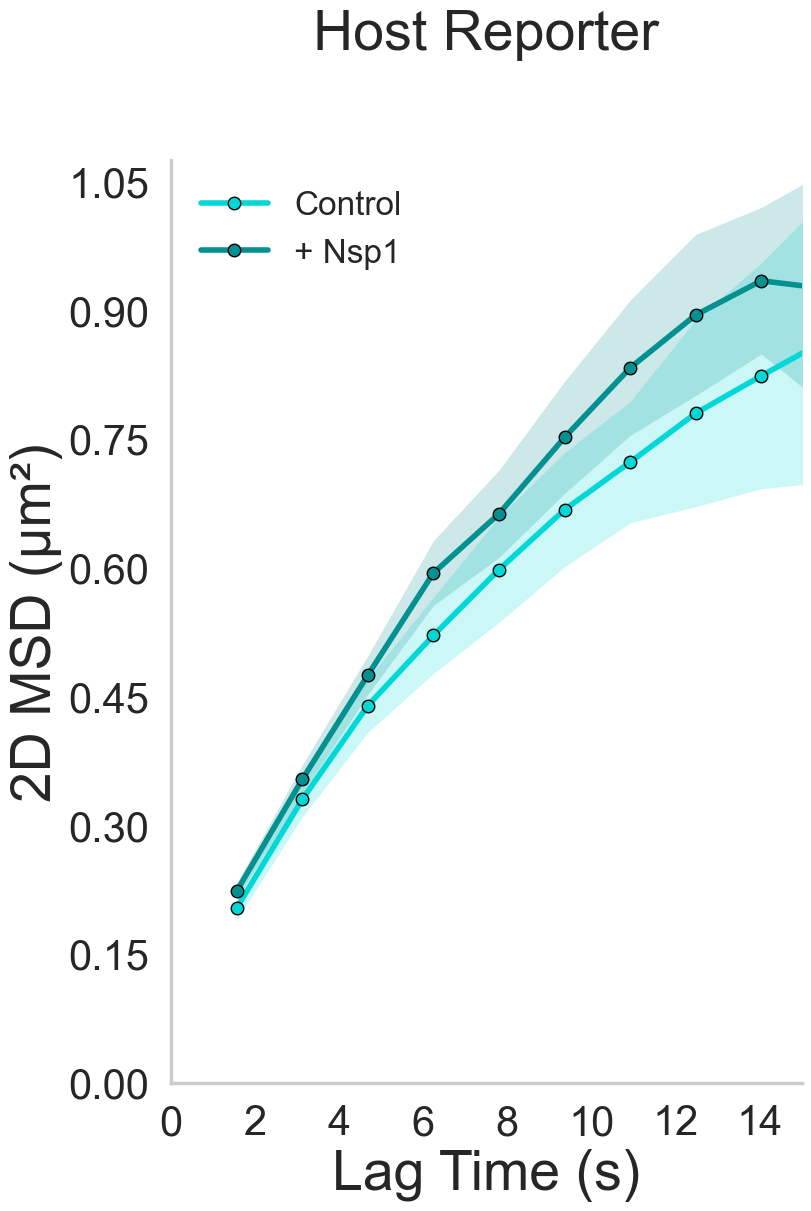

In [319]:
# MSD PLOT — KO ZNF598 SARS_CTRL
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ============================================================
# SELECT DATA
# ============================================================

data = "ZNF_SARS_CTRL"


types_to_plot = [
    "No Nsp1",
    "Nsp1",
]


# Plot:
#
# "MSD_2D_um2"
# "MSD_3D_um2"

metric = "MSD_2D_um2"


# Error:
#
# "sem"
# "ci95"
# "none"

error_style = "sem"


# ============================================================
# LABELS
# ============================================================

plot_title = "Host Reporter"

x_label = "Lag Time (s)"

y_label = "2D MSD (µm²)"


type_labels = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
}


# ============================================================
# COLORS
#
# Same palette convention as the main analysis notebook.
# ============================================================

blue_palette = sns.color_palette(
    [
        "#00D8D8",
        "#029090",
        "#67FFFF"
    ]
)


type_colors = {
    "No Nsp1": blue_palette[0],
    "Nsp1": blue_palette[1],
}


# ============================================================
# FIGURE SETTINGS
# ============================================================

figsize = (
    8,
    12
)


x_min = 0
x_max = 15


# Set manually if desired:
#
# y_min = 0
# y_max = 0.4
#
# OR use None for automatic scaling based on the MEAN lines.

y_min = 0
y_max = None


# Extra space above the highest mean if y_max=None
automatic_y_padding = 1.15


line_width = 4
marker_size = 9

error_alpha = 0.20


# If True, error shading cannot extend below zero.
clip_error_at_zero = True


# ============================================================
# SAVE SETTINGS
# ============================================================

save_figure = True

figure_name = "KO0znf598 SARS_CTRL"

figure_dpi = 300


# ============================================================
# STYLE
#
# Same general formatting used elsewhere in this notebook.
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)


# ============================================================
# LOAD REPLICATE-LEVEL DATA
# ============================================================

replicate_msd_data = (
    load_group_replicate_msd(
        data
    )
)


# ============================================================
# PREPARE SUMMARY DATA
# ============================================================

plot_data = prepare_msd_plot_data(

    replicate_msd_data,

    experimental_group=
        data,

    types_to_plot=
        types_to_plot,

    metric=
        metric,
)


# ============================================================
# SHOW EXACT NUMBERS USED IN PLOT
# ============================================================

display(
    plot_data[
        [
            "Experimental_Type",
            "Lag_Seconds",
            "N",
            "Mean",
            "SEM",
            "CI95",
        ]
    ]
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(

    figsize=figsize,

    constrained_layout=True
)


sns.despine(

    fig=fig,

    top=True,

    right=True,

    left=False,

    bottom=False
)


# ============================================================
# PLOT EACH EXPERIMENTAL TYPE
# ============================================================

for experimental_type in types_to_plot:


    condition = plot_data.loc[
        plot_data[
            "Experimental_Type"
        ].eq(
            experimental_type
        )
    ].copy()


    condition = condition.sort_values(
        "Lag_Seconds"
    )


    color = (
        type_colors[
            experimental_type
        ]
    )


    x = condition[
        "Lag_Seconds"
    ].to_numpy(
        dtype=float
    )


    y = condition[
        "Mean"
    ].to_numpy(
        dtype=float
    )


    # ========================================================
    # ERROR REGION
    # ========================================================

    if error_style == "sem":


        error_low = condition[
            "SEM_Low"
        ].to_numpy(
            dtype=float
        )


        error_high = condition[
            "SEM_High"
        ].to_numpy(
            dtype=float
        )


    elif error_style == "ci95":


        error_low = condition[
            "CI95_Low"
        ].to_numpy(
            dtype=float
        )


        error_high = condition[
            "CI95_High"
        ].to_numpy(
            dtype=float
        )


    elif error_style == "none":


        error_low = None
        error_high = None


    else:

        raise ValueError(
            "error_style must be "
            "'sem', 'ci95', or 'none'."
        )


    # --------------------------------------------------------
    # Optional physical clipping at zero
    # --------------------------------------------------------

    if (
        error_style != "none"
        and clip_error_at_zero
    ):

        error_low = np.maximum(
            error_low,
            0
        )


    # --------------------------------------------------------
    # Draw error band
    # --------------------------------------------------------

    if error_style != "none":


        ax.fill_between(

            x,

            error_low,

            error_high,

            color=color,

            alpha=error_alpha,

            linewidth=0,

            zorder=2
        )


    # ========================================================
    # MEAN LINE
    #
    # IMPORTANT:
    # This is ALWAYS condition["Mean"].
    # Changing SEM <-> CI95 cannot change this line.
    # ========================================================

    ax.plot(

        x,

        y,

        color=color,

        linewidth=line_width,

        marker="o",

        markersize=marker_size,

        markerfacecolor=
            color,

        markeredgecolor=
            "black",

        markeredgewidth=
            1,

        label=
            type_labels.get(
                experimental_type,
                experimental_type
            ),

        zorder=6
    )


# ============================================================
# AXIS LABELS
# ============================================================

ax.set_xlabel(

    x_label,

    fontsize=40
)


ax.set_ylabel(

    y_label,

    fontsize=40
)


ax.set_title(

    plot_title,

    fontsize=40,

    pad=80
)


# ============================================================
# AXIS LIMITS
# ============================================================

ax.set_xlim(
    x_min,
    x_max
)


# ------------------------------------------------------------
# Y-axis
#
# If y_max is None:
# calculate the scale from the MEAN curves only.
#
# Therefore SEM and CI95 give IDENTICAL axis scaling.
# ------------------------------------------------------------

if y_max is None:


    visible_mean_data = plot_data.loc[

        plot_data[
            "Lag_Seconds"
        ].between(
            x_min,
            x_max
        )

    ]


    max_mean = (

        visible_mean_data[
            "Mean"
        ]
        .max()
    )


    calculated_y_max = (
        max_mean
        *
        automatic_y_padding
    )


    ax.set_ylim(

        y_min,

        calculated_y_max
    )


else:


    ax.set_ylim(

        y_min,

        y_max
    )


# ============================================================
# TICKS
# ============================================================

ax.tick_params(

    axis="both",

    which="major",

    labelsize=30
)


ax.xaxis.set_major_locator(

    MaxNLocator(
        nbins=8
    )
)


ax.yaxis.set_major_locator(

    MaxNLocator(
        nbins=10
    )
)


# ============================================================
# LEGEND
# ============================================================

ax.legend(

    frameon=False,

    fontsize=24
)


# ============================================================
# SAVE
# ============================================================

if save_figure:


    png_path = (

        MSD_FIGURE_DIR
        /
        f"{figure_name}.png"
    )


    svg_path = (

        MSD_FIGURE_DIR
        /
        f"{figure_name}.svg"
    )


    fig.savefig(

        png_path,

        format="png",

        dpi=figure_dpi,

        bbox_inches="tight"
    )


    fig.savefig(

        svg_path,

        format="svg",

        dpi=figure_dpi,

        bbox_inches="tight"
    )


    print(
        f"Saved:\n{png_path}"
    )


    print(
        f"\nSaved:\n{svg_path}"
    )


plt.show()

Loaded replicate-level MSD data from:
  C:\Temp_data\Rapid\Linked mRNA Tracking CSV\MSD\Group MSD\ZNF_KDM5B_replicate_MSD_all_types.csv

Experimental Group: ZNF_KDM5B
Rows loaded: 60

Experimental Types found:
['No Nsp1', 'Nsp1']

Biological replicates per type:


,Experimental_Type,Biological Replicates
0,No Nsp1,3
1,Nsp1,3


,Experimental_Type,Lag_Seconds,N,Mean,SEM,CI95
0,No Nsp1,1.56,3,0.176314,0.013703,0.058960
1,No Nsp1,3.12,3,0.283731,0.024805,0.106727
2,No Nsp1,4.68,3,0.370421,0.035668,0.153465
3,No Nsp1,6.24,3,0.444064,0.051619,0.222101
4,No Nsp1,7.80,3,0.460006,0.082311,0.354155
5,No Nsp1,9.36,3,0.515793,0.083750,0.360349
6,No Nsp1,10.92,3,0.582252,0.090080,0.387583
7,No Nsp1,12.48,3,0.649467,0.091467,0.393552
8,No Nsp1,14.04,3,0.648887,0.119103,0.512459
9,No Nsp1,15.60,3,0.685297,0.111387,0.479261


Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\KO0znf598 Host Reporter Long.png

Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\KO0znf598 Host Reporter Long.svg


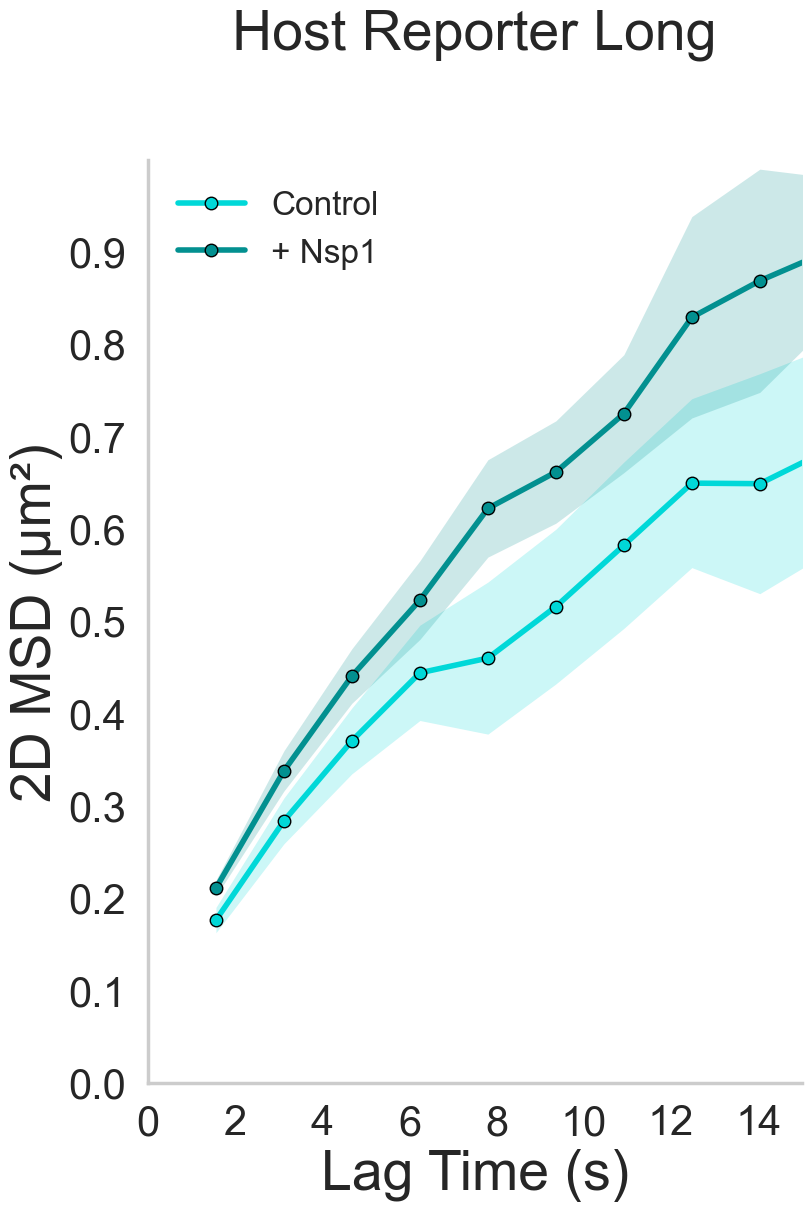

In [166]:
# MSD PLOT — KO ZNF598 KDM5B
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


# ============================================================
# SELECT DATA
# ============================================================

data = "ZNF_KDM5B"


types_to_plot = [
    "No Nsp1",
    "Nsp1",
]


# Plot:
#
# "MSD_2D_um2"
# "MSD_3D_um2"

metric = "MSD_2D_um2"


# Error:
#
# "sem"
# "ci95"
# "none"

error_style = "sem"


# ============================================================
# LABELS
# ============================================================

plot_title = "Host Reporter Long"

x_label = "Lag Time (s)"

y_label = "2D MSD (µm²)"


type_labels = {
    "No Nsp1": "Control",
    "Nsp1": "+ Nsp1",
}


# ============================================================
# COLORS
#
# Same palette convention as the main analysis notebook.
# ============================================================

blue_palette = sns.color_palette(
    [
        "#00D8D8",
        "#029090",
        "#67FFFF"
    ]
)


type_colors = {
    "No Nsp1": blue_palette[0],
    "Nsp1": blue_palette[1],
}


# ============================================================
# FIGURE SETTINGS
# ============================================================

figsize = (
    8,
    12
)


x_min = 0
x_max = 15


# Set manually if desired:
#
# y_min = 0
# y_max = 0.4
#
# OR use None for automatic scaling based on the MEAN lines.

y_min = 0
y_max = None


# Extra space above the highest mean if y_max=None
automatic_y_padding = 1.15


line_width = 4
marker_size = 9

error_alpha = 0.20


# If True, error shading cannot extend below zero.
clip_error_at_zero = True


# ============================================================
# SAVE SETTINGS
# ============================================================

save_figure = True

figure_name = "KO0znf598 Host Reporter Long"

figure_dpi = 300


# ============================================================
# STYLE
#
# Same general formatting used elsewhere in this notebook.
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)


# ============================================================
# LOAD REPLICATE-LEVEL DATA
# ============================================================

replicate_msd_data = (
    load_group_replicate_msd(
        data
    )
)


# ============================================================
# PREPARE SUMMARY DATA
# ============================================================

plot_data = prepare_msd_plot_data(

    replicate_msd_data,

    experimental_group=
        data,

    types_to_plot=
        types_to_plot,

    metric=
        metric,
)


# ============================================================
# SHOW EXACT NUMBERS USED IN PLOT
# ============================================================

display(
    plot_data[
        [
            "Experimental_Type",
            "Lag_Seconds",
            "N",
            "Mean",
            "SEM",
            "CI95",
        ]
    ]
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(

    figsize=figsize,

    constrained_layout=True
)


sns.despine(

    fig=fig,

    top=True,

    right=True,

    left=False,

    bottom=False
)


# ============================================================
# PLOT EACH EXPERIMENTAL TYPE
# ============================================================

for experimental_type in types_to_plot:


    condition = plot_data.loc[
        plot_data[
            "Experimental_Type"
        ].eq(
            experimental_type
        )
    ].copy()


    condition = condition.sort_values(
        "Lag_Seconds"
    )


    color = (
        type_colors[
            experimental_type
        ]
    )


    x = condition[
        "Lag_Seconds"
    ].to_numpy(
        dtype=float
    )


    y = condition[
        "Mean"
    ].to_numpy(
        dtype=float
    )


    # ========================================================
    # ERROR REGION
    # ========================================================

    if error_style == "sem":


        error_low = condition[
            "SEM_Low"
        ].to_numpy(
            dtype=float
        )


        error_high = condition[
            "SEM_High"
        ].to_numpy(
            dtype=float
        )


    elif error_style == "ci95":


        error_low = condition[
            "CI95_Low"
        ].to_numpy(
            dtype=float
        )


        error_high = condition[
            "CI95_High"
        ].to_numpy(
            dtype=float
        )


    elif error_style == "none":


        error_low = None
        error_high = None


    else:

        raise ValueError(
            "error_style must be "
            "'sem', 'ci95', or 'none'."
        )


    # --------------------------------------------------------
    # Optional physical clipping at zero
    # --------------------------------------------------------

    if (
        error_style != "none"
        and clip_error_at_zero
    ):

        error_low = np.maximum(
            error_low,
            0
        )


    # --------------------------------------------------------
    # Draw error band
    # --------------------------------------------------------

    if error_style != "none":


        ax.fill_between(

            x,

            error_low,

            error_high,

            color=color,

            alpha=error_alpha,

            linewidth=0,

            zorder=2
        )


    # ========================================================
    # MEAN LINE
    #
    # IMPORTANT:
    # This is ALWAYS condition["Mean"].
    # Changing SEM <-> CI95 cannot change this line.
    # ========================================================

    ax.plot(

        x,

        y,

        color=color,

        linewidth=line_width,

        marker="o",

        markersize=marker_size,

        markerfacecolor=
            color,

        markeredgecolor=
            "black",

        markeredgewidth=
            1,

        label=
            type_labels.get(
                experimental_type,
                experimental_type
            ),

        zorder=6
    )


# ============================================================
# AXIS LABELS
# ============================================================

ax.set_xlabel(

    x_label,

    fontsize=40
)


ax.set_ylabel(

    y_label,

    fontsize=40
)


ax.set_title(

    plot_title,

    fontsize=40,

    pad=80
)


# ============================================================
# AXIS LIMITS
# ============================================================

ax.set_xlim(
    x_min,
    x_max
)


# ------------------------------------------------------------
# Y-axis
#
# If y_max is None:
# calculate the scale from the MEAN curves only.
#
# Therefore SEM and CI95 give IDENTICAL axis scaling.
# ------------------------------------------------------------

if y_max is None:


    visible_mean_data = plot_data.loc[

        plot_data[
            "Lag_Seconds"
        ].between(
            x_min,
            x_max
        )

    ]


    max_mean = (

        visible_mean_data[
            "Mean"
        ]
        .max()
    )


    calculated_y_max = (
        max_mean
        *
        automatic_y_padding
    )


    ax.set_ylim(

        y_min,

        calculated_y_max
    )


else:


    ax.set_ylim(

        y_min,

        y_max
    )


# ============================================================
# TICKS
# ============================================================

ax.tick_params(

    axis="both",

    which="major",

    labelsize=30
)


ax.xaxis.set_major_locator(

    MaxNLocator(
        nbins=8
    )
)


ax.yaxis.set_major_locator(

    MaxNLocator(
        nbins=10
    )
)


# ============================================================
# LEGEND
# ============================================================

ax.legend(

    frameon=False,

    fontsize=24
)


# ============================================================
# SAVE
# ============================================================

if save_figure:


    png_path = (

        MSD_FIGURE_DIR
        /
        f"{figure_name}.png"
    )


    svg_path = (

        MSD_FIGURE_DIR
        /
        f"{figure_name}.svg"
    )


    fig.savefig(

        png_path,

        format="png",

        dpi=figure_dpi,

        bbox_inches="tight"
    )


    fig.savefig(

        svg_path,

        format="svg",

        dpi=figure_dpi,

        bbox_inches="tight"
    )


    print(
        f"Saved:\n{png_path}"
    )


    print(
        f"\nSaved:\n{svg_path}"
    )


plt.show()

### 2D X,Y Plotting

In [167]:
# RECOVER RNA + TRANSLATION SIGNAL FOR SAVED TRAJECTORIES
#
# The linked CSV contains the mRNA trajectory but translation
# was NOT independently linked.
#
# source_n + frame + fov + Raw_Exp_G allow us to return to
# the exact crop in combined_ds_1 and recover:
#
#     RNA_spot_sig
#     translation_spot_sig
#
# This should only be run on the subset of tracks you want
# to visualize; there is no reason to reconstruct every track.
# ============================================================


def _select_source_crop_value(
    data_array,
    *,
    source_n,
    frame,
):
    """
    Select one n x t crop value robustly using coordinate labels.
    Falls back to positional indexing if necessary.
    """

    selected = data_array


    # --------------------------------------------------------
    # n
    # --------------------------------------------------------

    if "n" in selected.dims:

        try:

            selected = selected.sel(
                n=int(source_n)
            )

        except Exception:

            selected = selected.isel(
                n=int(source_n)
            )


    # --------------------------------------------------------
    # t
    # --------------------------------------------------------

    if "t" in selected.dims:

        try:

            selected = selected.sel(
                t=int(frame)
            )

        except Exception:

            selected = selected.isel(
                t=int(frame)
            )


    # Remove remaining singleton dimensions.
    selected = selected.squeeze(
        drop=True
    )


    values = np.asarray(
        selected.values
    )


    if values.size != 1:

        raise ValueError(
            "Expected one scalar crop value but obtained "
            f"shape {values.shape}."
        )


    return float(
        values.reshape(-1)[0]
    )



def attach_saved_track_signals(
    linked_tracks,
    source_dataset,
):
    """
    Recover RNA and translation signal from combined_ds_1
    for previously saved linked mRNA trajectories.
    """

    required_track_columns = {

        "Raw_Exp_G",
        "fov",
        "source_n",
        "frame",
    }


    missing = required_track_columns.difference(
        linked_tracks.columns
    )


    if missing:

        raise KeyError(
            "Saved linked data are missing required "
            f"source columns:\n{sorted(missing)}"
        )


    required_dataset_variables = {

        "RNA_spot_sig",
        "translation_spot_sig",
    }


    missing = required_dataset_variables.difference(
        source_dataset.data_vars
    )


    if missing:

        raise KeyError(
            "combined_ds_1 is missing required signal "
            f"variable(s):\n{sorted(missing)}"
        )


    output = linked_tracks.copy()


    output[
        "RNA_spot_sig_source"
    ] = np.nan


    output[
        "translation_spot_sig"
    ] = np.nan


    # ========================================================
    # Work one cell at a time
    # ========================================================

    grouped_indices = (

        output

        .groupby(
            [
                "Raw_Exp_G",
                "fov",
            ],
            sort=False,
        )

        .groups
    )


    for (
        raw_exp_g,
        fov
    ), indices in grouped_indices.items():


        cell = (

            source_dataset

            .sel(
                Exp_G=str(
                    raw_exp_g
                )
            )

            .isel(
                fov=int(
                    fov
                )
            )
        )


        rna_signal = (
            cell[
                "RNA_spot_sig"
            ]
        )


        translation_signal = (
            cell[
                "translation_spot_sig"
            ]
        )


        for index in indices:

            row = output.loc[
                index
            ]


            if (
                pd.isna(
                    row["source_n"]
                )
                or
                pd.isna(
                    row["frame"]
                )
            ):

                continue


            source_n = int(
                row[
                    "source_n"
                ]
            )


            frame = int(
                row[
                    "frame"
                ]
            )


            output.loc[
                index,
                "RNA_spot_sig_source"
            ] = (
                _select_source_crop_value(
                    rna_signal,
                    source_n=source_n,
                    frame=frame,
                )
            )


            output.loc[
                index,
                "translation_spot_sig"
            ] = (
                _select_source_crop_value(
                    translation_signal,
                    source_n=source_n,
                    frame=frame,
                )
            )


    # ========================================================
    # TRANSLATION STATUS AT EACH FRAME
    # ========================================================

    output[
        "Translation_Positive"
    ] = (

        pd.to_numeric(
            output[
                "translation_spot_sig"
            ],
            errors="coerce"
        )

        .fillna(0)

        .gt(0)
    )


    # ========================================================
    # VALIDATE SOURCE MAPPING
    #
    # The saved RNA signal should match the same crop recovered
    # from combined_ds_1.
    # ========================================================

    if "RNA_spot_sig" in output.columns:

        comparison = output.loc[

            output[
                "RNA_spot_sig"
            ].notna()

            &

            output[
                "RNA_spot_sig_source"
            ].notna()

        ].copy()


        if not comparison.empty:

            difference = (

                comparison[
                    "RNA_spot_sig"
                ]

                -

                comparison[
                    "RNA_spot_sig_source"
                ]

            ).abs()


            print(
                "Source-mapping validation:"
            )

            print(
                f"  Frames checked: "
                f"{len(comparison):,}"
            )

            print(
                f"  Maximum RNA signal difference: "
                f"{difference.max():.6g}"
            )


            if not np.allclose(

                comparison[
                    "RNA_spot_sig"
                ],

                comparison[
                    "RNA_spot_sig_source"
                ],

                rtol=1e-5,

                atol=1e-5,

                equal_nan=True,

            ):

                print(
                    "\nWARNING:"
                )

                print(
                    "Recovered RNA signal does not exactly match "
                    "the signal stored with the trajectory."
                )

                print(
                    "Check the fov/source_n mapping before using "
                    "the translation overlay."
                )


    return output

In [170]:
# TRAJECTORY PLOT PREPROCESSING
#
# Run this ONCE to classify trajectories for every saved
# Experimental Group x Experimental Type.
#
# Expensive work is done here:
#
#   1. Load linked mRNA trajectories
#   2. Apply minimum track-length requirement
#   3. Recover translation signal from combined_ds_1
#   4. Count translation-positive frames
#   5. Classify whole tracks
#   6. Save compact plotting files
#
# Track classes:
#
#   "Translation"
#       >= MIN_TRANSLATION_POSITIVE_FRAMES
#
#   "mRNA only"
#       exactly 0 translation-positive frames
#
#   "Intermediate"
#       > 0 but below translation threshold
#
# Intermediate tracks are retained in the summary but are
# NOT included in the trajectory plotting files.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# CLASSIFICATION SETTINGS
# ============================================================

MIN_TRACK_FRAMES_FOR_TRAJECTORY_PLOT = 10

MIN_TRANSLATION_POSITIVE_FRAMES = 4

ONLY_MSD_ELIGIBLE_TRACKS = True


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

TRAJECTORY_PLOT_DATA_DIR = (
    TRACKING_OUTPUT_DIR
    / "Trajectory Plot Data"
)

TRAJECTORY_PLOT_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# True:
#     rebuild existing classification files
#
# False:
#     skip conditions that have already been processed
OVERWRITE_TRAJECTORY_PLOT_DATA = False


# ============================================================
# HELPER
# ============================================================

def prepare_condition_trajectory_plot_data(
    experimental_group,
    experimental_type,
):
    """
    Prepare and save classified 2D trajectory data for one
    Experimental Group x Experimental Type.
    """

    safe_group = make_safe_filename(
        experimental_group
    )

    safe_type = make_safe_filename(
        experimental_type
    )


    trajectory_path = (
        TRAJECTORY_PLOT_DATA_DIR
        /
        (
            f"{safe_group}_"
            f"{safe_type}_"
            "trajectory_plot_data.csv"
        )
    )


    summary_path = (
        TRAJECTORY_PLOT_DATA_DIR
        /
        (
            f"{safe_group}_"
            f"{safe_type}_"
            "trajectory_class_summary.csv"
        )
    )


    # ========================================================
    # EXISTING OUTPUT
    # ========================================================

    if (
        trajectory_path.exists()
        and summary_path.exists()
        and not OVERWRITE_TRAJECTORY_PLOT_DATA
    ):

        print(
            f"Already prepared — skipping: "
            f"{experimental_group} | {experimental_type}"
        )

        return {
            "Experimental_Group":
                experimental_group,

            "Experimental_Type":
                experimental_type,

            "Status":
                "existing",

            "Trajectory_File":
                str(trajectory_path),

            "Summary_File":
                str(summary_path),
        }


    # ========================================================
    # LOAD SAVED LINKED TRAJECTORIES
    # ========================================================

    tracks = load_saved_mrna_tracks(
        experimental_group,
        experimental_type,
    )


    # ========================================================
    # ONE ROW PER TRACK FOR INITIAL FILTERING
    # ========================================================

    track_table = (

        tracks

        .groupby(
            "track_uid",
            as_index=False,
        )

        .agg(

            Track_Length=(
                "frame",
                "nunique",
            ),

            Replicate_Number=(
                "Replicate_Number",
                "first",
            ),

            fov=(
                "fov",
                "first",
            ),

            keep_for_msd=(
                "keep_for_msd",
                "first",
            ),
        )
    )


    # ========================================================
    # MINIMUM TRACK LENGTH
    # ========================================================

    track_table = track_table.loc[

        track_table[
            "Track_Length"
        ].ge(
            MIN_TRACK_FRAMES_FOR_TRAJECTORY_PLOT
        )

    ].copy()


    # ========================================================
    # OPTIONAL MSD ELIGIBILITY
    # ========================================================

    if (
        ONLY_MSD_ELIGIBLE_TRACKS
        and
        "keep_for_msd" in track_table.columns
    ):

        keep_mask = (

            track_table[
                "keep_for_msd"
            ]

            .astype(str)

            .str.lower()

            .isin(
                [
                    "true",
                    "1",
                    "yes",
                ]
            )
        )


        track_table = (
            track_table.loc[
                keep_mask
            ]
            .copy()
        )


    if track_table.empty:

        print(
            f"No eligible trajectories: "
            f"{experimental_group} | {experimental_type}"
        )

        return {
            "Experimental_Group":
                experimental_group,

            "Experimental_Type":
                experimental_type,

            "Status":
                "no_tracks",

            "Trajectory_File":
                "",

            "Summary_File":
                "",
        }


    # ========================================================
    # RESTRICT TO ELIGIBLE TRACKS BEFORE SIGNAL LOOKUP
    # ========================================================

    eligible_uids = set(
        track_table[
            "track_uid"
        ]
    )


    tracks = tracks.loc[

        tracks[
            "track_uid"
        ].isin(
            eligible_uids
        )

    ].copy()


    # ========================================================
    # RECOVER TRANSLATION SIGNAL
    #
    # This is the expensive operation.
    # It happens once here rather than every time a plot is made.
    # ========================================================

    tracks = attach_saved_track_signals(
        tracks,
        combined_ds_1,
    )


    # ========================================================
    # CLASSIFY ENTIRE TRAJECTORIES
    # ========================================================

    classification = (

        tracks

        .groupby(
            "track_uid",
            as_index=False,
        )

        .agg(

            Track_Length=(
                "frame",
                "nunique",
            ),

            Translation_Positive_Frames=(
                "Translation_Positive",
                "sum",
            ),

            Replicate_Number=(
                "Replicate_Number",
                "first",
            ),

            fov=(
                "fov",
                "first",
            ),
        )
    )


    classification[
        "Translation_Positive_Frames"
    ] = (

        classification[
            "Translation_Positive_Frames"
        ]

        .fillna(0)

        .astype(int)
    )


    classification[
        "Track_Class"
    ] = np.select(

        [
            classification[
                "Translation_Positive_Frames"
            ].ge(
                MIN_TRANSLATION_POSITIVE_FRAMES
            ),

            classification[
                "Translation_Positive_Frames"
            ].eq(
                0
            ),
        ],

        [
            "Translation",
            "mRNA only",
        ],

        default=
            "Intermediate",
    )


    # ========================================================
    # SAVE TRACK-LEVEL SUMMARY
    # ========================================================

    classification[
        "Experimental_Group"
    ] = str(
        experimental_group
    )


    classification[
        "Experimental_Type"
    ] = str(
        experimental_type
    )


    classification.to_csv(
        summary_path,
        index=False,
    )


    # ========================================================
    # ATTACH CLASSIFICATION TO TRAJECTORY ROWS
    # ========================================================

    trajectory_data = (

        tracks

        .merge(

            classification[
                [
                    "track_uid",
                    "Track_Class",
                    "Track_Length",
                    "Translation_Positive_Frames",
                ]
            ],

            on=
                "track_uid",

            how=
                "left",

            validate=
                "many_to_one",
        )
    )


    # ========================================================
    # KEEP ONLY THE TWO UNAMBIGUOUS CLASSES
    # ========================================================

    trajectory_data = trajectory_data.loc[

        trajectory_data[
            "Track_Class"
        ].isin(
            [
                "mRNA only",
                "Translation",
            ]
        )

    ].copy()


    # ========================================================
    # KEEP ONLY COLUMNS NEEDED FOR FUTURE PLOTTING
    # ========================================================

    columns_to_keep = [

        "track_uid",

        "Experimental_Group",
        "Experimental_Type",

        "Replicate_Number",
        "fov",
        "Cell_Number",

        "frame",

        "x",
        "y",

        "Track_Class",
        "Track_Length",
        "Translation_Positive_Frames",
    ]


    columns_to_keep = [

        column

        for column in columns_to_keep

        if column in trajectory_data.columns
    ]


    trajectory_data = (

        trajectory_data[
            columns_to_keep
        ]

        .sort_values(
            [
                "Track_Class",
                "track_uid",
                "frame",
            ]
        )

        .reset_index(
            drop=True
        )
    )


    # ========================================================
    # SAVE COMPACT TRAJECTORY FILE
    # ========================================================

    trajectory_data.to_csv(
        trajectory_path,
        index=False,
    )


    # ========================================================
    # REPORT
    # ========================================================

    class_counts = (

        classification

        .groupby(
            "Track_Class"
        )

        .size()

        .rename(
            "Track_Count"
        )

        .reset_index()
    )


    print(
        "\nPrepared:"
    )

    print(
        f"  {experimental_group} | "
        f"{experimental_type}"
    )

    display(
        class_counts
    )


    return {

        "Experimental_Group":
            experimental_group,

        "Experimental_Type":
            experimental_type,

        "Status":
            "complete",

        "mRNA_Only_Tracks":
            int(
                classification[
                    "Track_Class"
                ].eq(
                    "mRNA only"
                ).sum()
            ),

        "Translation_Tracks":
            int(
                classification[
                    "Track_Class"
                ].eq(
                    "Translation"
                ).sum()
            ),

        "Intermediate_Tracks":
            int(
                classification[
                    "Track_Class"
                ].eq(
                    "Intermediate"
                ).sum()
            ),

        "Trajectory_File":
            str(
                trajectory_path
            ),

        "Summary_File":
            str(
                summary_path
            ),
    }


# ============================================================
# PROCESS ALL SAVED GROUPS AND TYPES
# ============================================================

saved_conditions = (
    discover_saved_mrna_tracking()
)


trajectory_preprocessing_results = []


for row in saved_conditions.itertuples(
    index=False
):

    result = (
        prepare_condition_trajectory_plot_data(

            row.Experimental_Group,

            row.Experimental_Type,
        )
    )


    trajectory_preprocessing_results.append(
        result
    )


trajectory_preprocessing_manifest = pd.DataFrame(
    trajectory_preprocessing_results
)


display(
    trajectory_preprocessing_manifest
)


manifest_path = (
    TRAJECTORY_PLOT_DATA_DIR
    /
    "trajectory_plot_manifest.csv"
)


trajectory_preprocessing_manifest.to_csv(
    manifest_path,
    index=False,
)


print(
    "\nTrajectory plotting data prepared."
)

print(
    f"\nSaved manifest:\n"
    f"{manifest_path}"
)

Loaded: BoxB_IRES | No Nsp1
Rows: 54,011
Tracks: 14,056
Cells: 30
Source-mapping validation:
  Frames checked: 22,939
  Maximum RNA signal difference: 0

Prepared:
  BoxB_IRES | No Nsp1


,Track_Class,Track_Count
0,Intermediate,32
1,Translation,1428
2,mRNA only,4


Loaded: BoxB_IRES | Nsp1
Rows: 57,771
Tracks: 17,391
Cells: 27
Source-mapping validation:
  Frames checked: 20,111
  Maximum RNA signal difference: 0

Prepared:
  BoxB_IRES | Nsp1


,Track_Class,Track_Count
0,Intermediate,135
1,Translation,1169
2,mRNA only,15


Loaded: BoxB_MS2 | No Nsp1
Rows: 195,488
Tracks: 64,561
Cells: 90
Source-mapping validation:
  Frames checked: 60,198
  Maximum RNA signal difference: 0

Prepared:
  BoxB_MS2 | No Nsp1


...

,Track_Class,Track_Count
0,Intermediate,488
1,Translation,354
2,mRNA only,1223


Loaded: ZNF_SARS_CTRL | Nsp1
Rows: 53,245
Tracks: 16,775
Cells: 26
Source-mapping validation:
  Frames checked: 13,247
  Maximum RNA signal difference: 0

Prepared:
  ZNF_SARS_CTRL | Nsp1


,Track_Class,Track_Count
0,Intermediate,239
1,Translation,178
2,mRNA only,539


,Experimental_Group,Experimental_Type,Status,mRNA_Only_Tracks,Translation_Tracks,Intermediate_Tracks,Trajectory_File,Summary_File
0,BoxB_IRES,No Nsp1,complete,4,1428,32,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...
1,BoxB_IRES,Nsp1,complete,15,1169,135,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...
2,BoxB_MS2,No Nsp1,complete,3998,0,0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...
3,BoxB_MS2,NoCTD Nsp1,complete,3227,0,0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...
4,BoxB_MS2,Nsp1,complete,4137,0,0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...
5,Emi_KDM5B,No Nsp1,complete,1763,158,530,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...
6,Emi_KDM5B,NoCTD Nsp1,complete,1598,133,369,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...
7,Emi_KDM5B,Nsp1,complete,497,28,45,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...
8,EMI_NoORF,No Nsp1,complete,1747,0,0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...
9,EMI_NoORF,Nsp1,complete,751,0,0,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...,C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Tr...



Trajectory plotting data prepared.

Saved manifest:
C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Trajectory Plot Data\trajectory_plot_manifest.csv


Loaded:
C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Trajectory Plot Data\SARS_CTRL_No_Nsp1_trajectory_plot_data.csv

mRNA-only tracks available: 179
Translation tracks available: 287

Tracks plotted:
  mRNA only: 25
  Translation: 25

Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\SARS_CTRL_No Nsp1_individual_trajectories.png

Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\SARS_CTRL_No Nsp1_individual_trajectories.svg


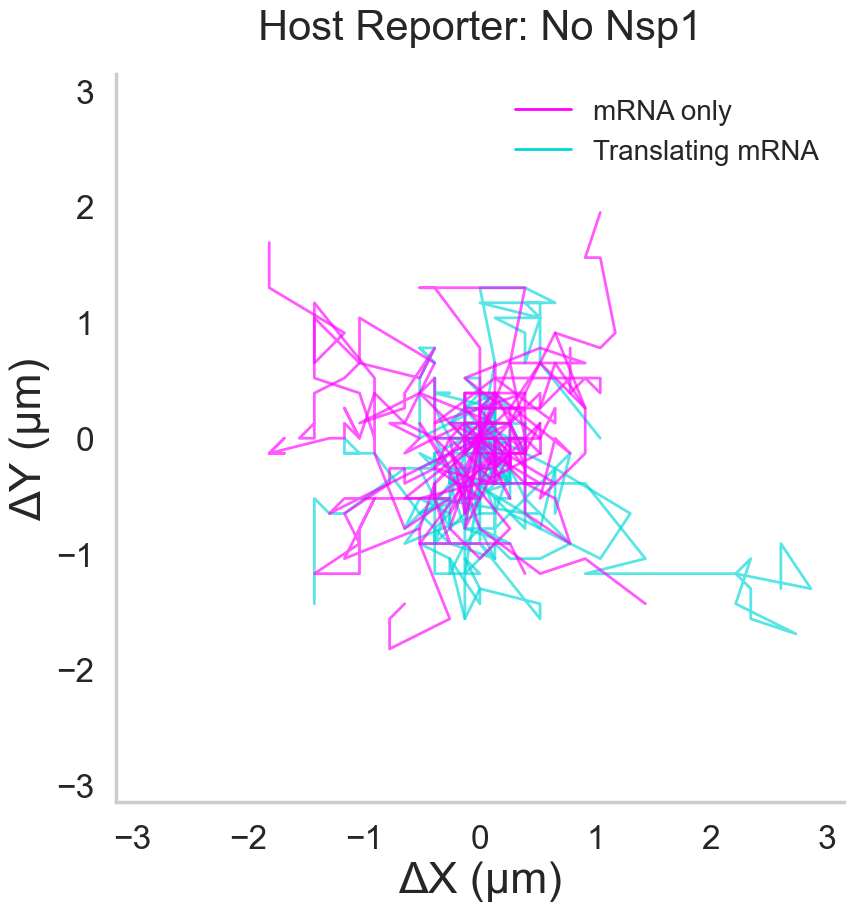

In [177]:
# PLOT INDIVIDUAL 2D TRAJECTORIES
#
# This cell performs NO translation detection or classification.
#
# All classifications were generated previously by the
# trajectory preprocessing cell.
#
# Magenta = mRNA-only tracks
# Cyan    = translation-associated tracks
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


# ============================================================
# SELECT DATA
# ============================================================

TRACE_EXPERIMENTAL_GROUP = "SARS_CTRL"

TRACE_EXPERIMENTAL_TYPE = "No Nsp1"


# Number sampled FROM EACH CLASS.
#
# 20 means:
#
#     up to 20 mRNA-only tracks
#     up to 20 translating tracks
#
N_TRACES_PER_CLASS = 25


# Reproducible sampling.
TRACE_RANDOM_STATE = 1


# ============================================================
# DISPLAY SETTINGS
# ============================================================

CENTER_TRACKS_AT_ORIGIN = True

XY_PIXEL_SIZE_UM = 0.130


RNA_COLOR = "#FF00FF"

TRANSLATION_COLOR = "#00D8D8"


# Identical line styling for both populations.
TRACE_LINE_WIDTH = 2.0

TRACE_ALPHA = 0.65


FIGSIZE = (
    9,
    9
)


# Optional manual XY limit in µm.
#
# None = automatically calculate from displayed trajectories.
#
# Example:
#     TRAJECTORY_XY_LIMIT = 2.0
#
TRAJECTORY_XY_LIMIT = None


# ============================================================
# SAVE
# ============================================================

SAVE_TRACE_FIGURE = True


TRACE_FIGURE_NAME = (
    f"{TRACE_EXPERIMENTAL_GROUP}_"
    f"{TRACE_EXPERIMENTAL_TYPE}_"
    "individual_trajectories"
)


# ============================================================
# FIND PRECOMPUTED FILE
# ============================================================

safe_group = make_safe_filename(
    TRACE_EXPERIMENTAL_GROUP
)


safe_type = make_safe_filename(
    TRACE_EXPERIMENTAL_TYPE
)


trajectory_path = (

    TRAJECTORY_PLOT_DATA_DIR

    /

    (
        f"{safe_group}_"
        f"{safe_type}_"
        "trajectory_plot_data.csv"
    )
)


if not trajectory_path.exists():

    raise FileNotFoundError(

        "Precomputed trajectory file was not found:\n"

        f"{trajectory_path}\n\n"

        "Run the trajectory preprocessing cell first."
    )


# ============================================================
# LOAD
# ============================================================

trajectory_data = pd.read_csv(
    trajectory_path
)


print(
    f"Loaded:\n"
    f"{trajectory_path}"
)


# ============================================================
# ONE ROW PER TRACK
# ============================================================

track_table = (

    trajectory_data

    .groupby(
        "track_uid",
        as_index=False,
    )

    .agg(

        Track_Class=(
            "Track_Class",
            "first",
        ),

        Track_Length=(
            "Track_Length",
            "first",
        ),

        Translation_Positive_Frames=(
            "Translation_Positive_Frames",
            "first",
        ),
    )
)


# ============================================================
# SPLIT TRACK CLASSES
# ============================================================

mrna_tracks = track_table.loc[

    track_table[
        "Track_Class"
    ].eq(
        "mRNA only"
    )

].copy()


translation_tracks = track_table.loc[

    track_table[
        "Track_Class"
    ].eq(
        "Translation"
    )

].copy()


print(
    f"\nmRNA-only tracks available: "
    f"{len(mrna_tracks):,}"
)


print(
    f"Translation tracks available: "
    f"{len(translation_tracks):,}"
)


# ============================================================
# SAMPLE
# ============================================================

n_mrna = min(
    N_TRACES_PER_CLASS,
    len(
        mrna_tracks
    ),
)


n_translation = min(
    N_TRACES_PER_CLASS,
    len(
        translation_tracks
    ),
)


selected_mrna = (

    mrna_tracks

    .sample(
        n=n_mrna,
        random_state=
            TRACE_RANDOM_STATE,
    )

    if n_mrna > 0

    else pd.DataFrame()
)


selected_translation = (

    translation_tracks

    .sample(
        n=n_translation,
        random_state=
            TRACE_RANDOM_STATE + 1,
    )

    if n_translation > 0

    else pd.DataFrame()
)


selected_uids = set(

    pd.concat(

        [
            selected_mrna,
            selected_translation,
        ],

        ignore_index=True,
    )[
        "track_uid"
    ]
)


selected_data = trajectory_data.loc[

    trajectory_data[
        "track_uid"
    ].isin(
        selected_uids
    )

].copy()


print(
    f"\nTracks plotted:"
)

print(
    f"  mRNA only: "
    f"{n_mrna}"
)

print(
    f"  Translation: "
    f"{n_translation}"
)


# ============================================================
# STYLE
# ============================================================

sns.set(
    font_scale=1.8
)


sns.set_style(
    "whitegrid",
    {
        "grid.linestyle":
            ""
    }
)


sns.set_context(
    "poster"
)


fig, ax = plt.subplots(

    figsize=
        FIGSIZE,

    constrained_layout=True,
)


sns.despine(

    ax=ax,

    top=True,

    right=True,
)


# ============================================================
# DRAW TRAJECTORIES
# ============================================================

all_x = []
all_y = []


for track_uid, track in (

    selected_data

    .groupby(
        "track_uid",
        sort=False,
    )
):


    track = (

        track

        .sort_values(
            "frame"
        )

        .drop_duplicates(
            "frame",
            keep="last",
        )

        .copy()
    )


    track_class = str(
        track[
            "Track_Class"
        ].iloc[0]
    )


    if track_class == "Translation":

        color = (
            TRANSLATION_COLOR
        )


    elif track_class == "mRNA only":

        color = (
            RNA_COLOR
        )


    else:

        continue


    x = (

        pd.to_numeric(
            track[
                "x"
            ],
            errors="coerce",
        )

        .to_numpy(
            dtype=float
        )

        *

        XY_PIXEL_SIZE_UM
    )


    y = (

        pd.to_numeric(
            track[
                "y"
            ],
            errors="coerce",
        )

        .to_numpy(
            dtype=float
        )

        *

        XY_PIXEL_SIZE_UM
    )


    valid = (

        np.isfinite(
            x
        )

        &

        np.isfinite(
            y
        )
    )


    x = x[
        valid
    ]


    y = y[
        valid
    ]


    if len(x) < 2:

        continue


    # --------------------------------------------------------
    # Recenter trajectory
    # --------------------------------------------------------

    if CENTER_TRACKS_AT_ORIGIN:

        x = (
            x
            -
            x[0]
        )


        y = (
            y
            -
            y[0]
        )


    all_x.extend(
        x
    )


    all_y.extend(
        y
    )


    # --------------------------------------------------------
    # Draw
    #
    # No markers.
    # Same linewidth for both track classes.
    # --------------------------------------------------------

    ax.plot(

        x,

        y,

        color=
            color,

        linewidth=
            TRACE_LINE_WIDTH,

        alpha=
            TRACE_ALPHA,
    )


# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "ΔX (µm)",
    fontsize=32,
)


ax.set_ylabel(
    "ΔY (µm)",
    fontsize=32,
)


ax.set_title(

    (
        f"Host Reporter: "
        f"{TRACE_EXPERIMENTAL_TYPE}"
    ),

    fontsize=30,

    pad=25,
)


ax.tick_params(

    axis="both",

    labelsize=24,
)


# Spatial geometry must be identical on X and Y.
ax.set_aspect(
    "equal",
    adjustable="box",
)


# ============================================================
# AXIS LIMITS
# ============================================================

if TRAJECTORY_XY_LIMIT is not None:


    limit = float(
        TRAJECTORY_XY_LIMIT
    )


else:


    if not all_x or not all_y:

        limit = 1.0


    else:

        limit = np.nanmax(

            np.abs(

                np.concatenate(
                    [
                        np.asarray(
                            all_x
                        ),

                        np.asarray(
                            all_y
                        ),
                    ]
                )
            )
        )


        limit *= (
            1.10
        )


ax.set_xlim(
    -limit,
    limit,
)


ax.set_ylim(
    -limit,
    limit,
)


# ============================================================
# LEGEND
# ============================================================

legend_handles = [

    Line2D(

        [0],
        [0],

        color=
            RNA_COLOR,

        linewidth=
            TRACE_LINE_WIDTH,

        label=
            "mRNA only",
    ),


    Line2D(

        [0],
        [0],

        color=
            TRANSLATION_COLOR,

        linewidth=
            TRACE_LINE_WIDTH,

        label=
            "Translating mRNA",
    ),
]


ax.legend(

    handles=
        legend_handles,

    frameon=False,

    fontsize=20,
)


# ============================================================
# SAVE
# ============================================================

if SAVE_TRACE_FIGURE:


    png_path = (

        MSD_FIGURE_DIR

        /

        f"{TRACE_FIGURE_NAME}.png"
    )


    svg_path = (

        MSD_FIGURE_DIR

        /

        f"{TRACE_FIGURE_NAME}.svg"
    )


    fig.savefig(

        png_path,

        dpi=300,

        bbox_inches="tight",
    )


    fig.savefig(

        svg_path,

        bbox_inches="tight",
    )


    print(
        f"\nSaved:\n{png_path}"
    )


    print(
        f"\nSaved:\n{svg_path}"
    )


plt.show()

Loaded:
C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Trajectory Plot Data\SARS_CTRL_Nsp1_trajectory_plot_data.csv

mRNA-only tracks available: 19
Translation tracks available: 37

Tracks plotted:
  mRNA only: 19
  Translation: 25

Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\SARS_CTRL_Nsp1_individual_trajectories.png

Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\SARS_CTRL_Nsp1_individual_trajectories.svg


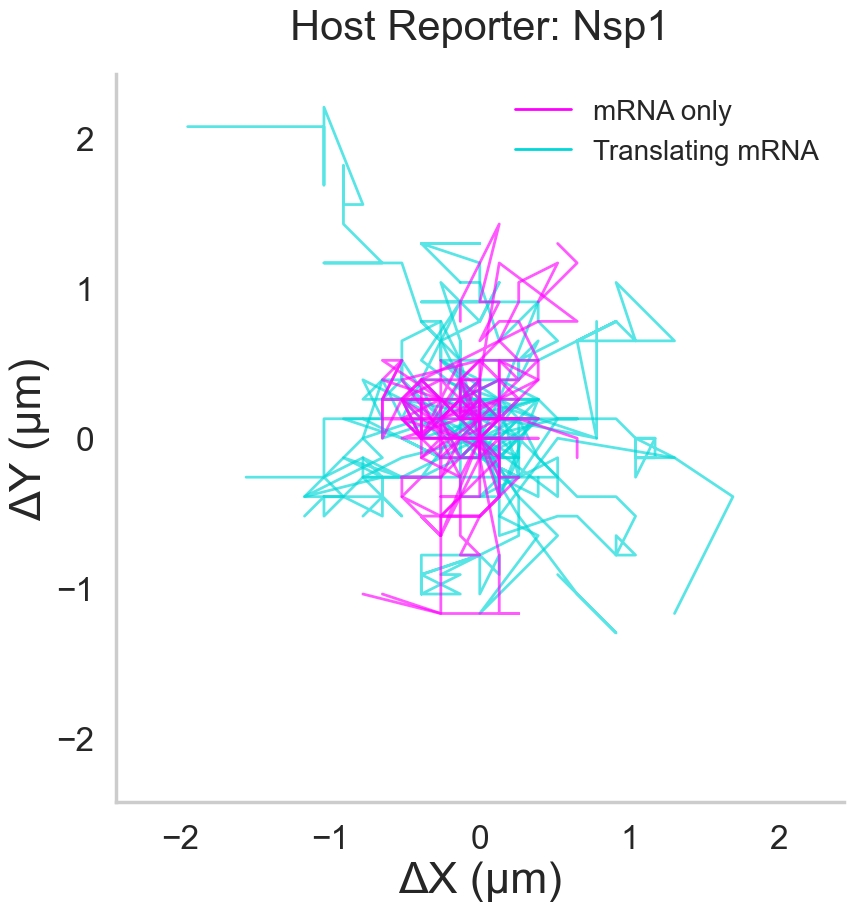

In [178]:
# PLOT INDIVIDUAL 2D TRAJECTORIES
#
# This cell performs NO translation detection or classification.
#
# All classifications were generated previously by the
# trajectory preprocessing cell.
#
# Magenta = mRNA-only tracks
# Cyan    = translation-associated tracks
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


# ============================================================
# SELECT DATA
# ============================================================

TRACE_EXPERIMENTAL_GROUP = "SARS_CTRL"

TRACE_EXPERIMENTAL_TYPE = "Nsp1"


# Number sampled FROM EACH CLASS.
#
# 20 means:
#
#     up to 20 mRNA-only tracks
#     up to 20 translating tracks
#
N_TRACES_PER_CLASS = 25


# Reproducible sampling.
TRACE_RANDOM_STATE = 1


# ============================================================
# DISPLAY SETTINGS
# ============================================================

CENTER_TRACKS_AT_ORIGIN = True

XY_PIXEL_SIZE_UM = 0.130


RNA_COLOR = "#FF00FF"

TRANSLATION_COLOR = "#00D8D8"


# Identical line styling for both populations.
TRACE_LINE_WIDTH = 2.0

TRACE_ALPHA = 0.65


FIGSIZE = (
    9,
    9
)


# Optional manual XY limit in µm.
#
# None = automatically calculate from displayed trajectories.
#
# Example:
#     TRAJECTORY_XY_LIMIT = 2.0
#
TRAJECTORY_XY_LIMIT = None


# ============================================================
# SAVE
# ============================================================

SAVE_TRACE_FIGURE = True


TRACE_FIGURE_NAME = (
    f"{TRACE_EXPERIMENTAL_GROUP}_"
    f"{TRACE_EXPERIMENTAL_TYPE}_"
    "individual_trajectories"
)


# ============================================================
# FIND PRECOMPUTED FILE
# ============================================================

safe_group = make_safe_filename(
    TRACE_EXPERIMENTAL_GROUP
)


safe_type = make_safe_filename(
    TRACE_EXPERIMENTAL_TYPE
)


trajectory_path = (

    TRAJECTORY_PLOT_DATA_DIR

    /

    (
        f"{safe_group}_"
        f"{safe_type}_"
        "trajectory_plot_data.csv"
    )
)


if not trajectory_path.exists():

    raise FileNotFoundError(

        "Precomputed trajectory file was not found:\n"

        f"{trajectory_path}\n\n"

        "Run the trajectory preprocessing cell first."
    )


# ============================================================
# LOAD
# ============================================================

trajectory_data = pd.read_csv(
    trajectory_path
)


print(
    f"Loaded:\n"
    f"{trajectory_path}"
)


# ============================================================
# ONE ROW PER TRACK
# ============================================================

track_table = (

    trajectory_data

    .groupby(
        "track_uid",
        as_index=False,
    )

    .agg(

        Track_Class=(
            "Track_Class",
            "first",
        ),

        Track_Length=(
            "Track_Length",
            "first",
        ),

        Translation_Positive_Frames=(
            "Translation_Positive_Frames",
            "first",
        ),
    )
)


# ============================================================
# SPLIT TRACK CLASSES
# ============================================================

mrna_tracks = track_table.loc[

    track_table[
        "Track_Class"
    ].eq(
        "mRNA only"
    )

].copy()


translation_tracks = track_table.loc[

    track_table[
        "Track_Class"
    ].eq(
        "Translation"
    )

].copy()


print(
    f"\nmRNA-only tracks available: "
    f"{len(mrna_tracks):,}"
)


print(
    f"Translation tracks available: "
    f"{len(translation_tracks):,}"
)


# ============================================================
# SAMPLE
# ============================================================

n_mrna = min(
    N_TRACES_PER_CLASS,
    len(
        mrna_tracks
    ),
)


n_translation = min(
    N_TRACES_PER_CLASS,
    len(
        translation_tracks
    ),
)


selected_mrna = (

    mrna_tracks

    .sample(
        n=n_mrna,
        random_state=
            TRACE_RANDOM_STATE,
    )

    if n_mrna > 0

    else pd.DataFrame()
)


selected_translation = (

    translation_tracks

    .sample(
        n=n_translation,
        random_state=
            TRACE_RANDOM_STATE + 1,
    )

    if n_translation > 0

    else pd.DataFrame()
)


selected_uids = set(

    pd.concat(

        [
            selected_mrna,
            selected_translation,
        ],

        ignore_index=True,
    )[
        "track_uid"
    ]
)


selected_data = trajectory_data.loc[

    trajectory_data[
        "track_uid"
    ].isin(
        selected_uids
    )

].copy()


print(
    f"\nTracks plotted:"
)

print(
    f"  mRNA only: "
    f"{n_mrna}"
)

print(
    f"  Translation: "
    f"{n_translation}"
)


# ============================================================
# STYLE
# ============================================================

sns.set(
    font_scale=1.8
)


sns.set_style(
    "whitegrid",
    {
        "grid.linestyle":
            ""
    }
)


sns.set_context(
    "poster"
)


fig, ax = plt.subplots(

    figsize=
        FIGSIZE,

    constrained_layout=True,
)


sns.despine(

    ax=ax,

    top=True,

    right=True,
)


# ============================================================
# DRAW TRAJECTORIES
# ============================================================

all_x = []
all_y = []


for track_uid, track in (

    selected_data

    .groupby(
        "track_uid",
        sort=False,
    )
):


    track = (

        track

        .sort_values(
            "frame"
        )

        .drop_duplicates(
            "frame",
            keep="last",
        )

        .copy()
    )


    track_class = str(
        track[
            "Track_Class"
        ].iloc[0]
    )


    if track_class == "Translation":

        color = (
            TRANSLATION_COLOR
        )


    elif track_class == "mRNA only":

        color = (
            RNA_COLOR
        )


    else:

        continue


    x = (

        pd.to_numeric(
            track[
                "x"
            ],
            errors="coerce",
        )

        .to_numpy(
            dtype=float
        )

        *

        XY_PIXEL_SIZE_UM
    )


    y = (

        pd.to_numeric(
            track[
                "y"
            ],
            errors="coerce",
        )

        .to_numpy(
            dtype=float
        )

        *

        XY_PIXEL_SIZE_UM
    )


    valid = (

        np.isfinite(
            x
        )

        &

        np.isfinite(
            y
        )
    )


    x = x[
        valid
    ]


    y = y[
        valid
    ]


    if len(x) < 2:

        continue


    # --------------------------------------------------------
    # Recenter trajectory
    # --------------------------------------------------------

    if CENTER_TRACKS_AT_ORIGIN:

        x = (
            x
            -
            x[0]
        )


        y = (
            y
            -
            y[0]
        )


    all_x.extend(
        x
    )


    all_y.extend(
        y
    )


    # --------------------------------------------------------
    # Draw
    #
    # No markers.
    # Same linewidth for both track classes.
    # --------------------------------------------------------

    ax.plot(

        x,

        y,

        color=
            color,

        linewidth=
            TRACE_LINE_WIDTH,

        alpha=
            TRACE_ALPHA,
    )


# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "ΔX (µm)",
    fontsize=32,
)


ax.set_ylabel(
    "ΔY (µm)",
    fontsize=32,
)


ax.set_title(

    (
        f"Host Reporter: "
        f"{TRACE_EXPERIMENTAL_TYPE}"
    ),

    fontsize=30,

    pad=25,
)


ax.tick_params(

    axis="both",

    labelsize=24,
)


# Spatial geometry must be identical on X and Y.
ax.set_aspect(
    "equal",
    adjustable="box",
)


# ============================================================
# AXIS LIMITS
# ============================================================

if TRAJECTORY_XY_LIMIT is not None:


    limit = float(
        TRAJECTORY_XY_LIMIT
    )


else:


    if not all_x or not all_y:

        limit = 1.0


    else:

        limit = np.nanmax(

            np.abs(

                np.concatenate(
                    [
                        np.asarray(
                            all_x
                        ),

                        np.asarray(
                            all_y
                        ),
                    ]
                )
            )
        )


        limit *= (
            1.10
        )


ax.set_xlim(
    -limit,
    limit,
)


ax.set_ylim(
    -limit,
    limit,
)


# ============================================================
# LEGEND
# ============================================================

legend_handles = [

    Line2D(

        [0],
        [0],

        color=
            RNA_COLOR,

        linewidth=
            TRACE_LINE_WIDTH,

        label=
            "mRNA only",
    ),


    Line2D(

        [0],
        [0],

        color=
            TRANSLATION_COLOR,

        linewidth=
            TRACE_LINE_WIDTH,

        label=
            "Translating mRNA",
    ),
]


ax.legend(

    handles=
        legend_handles,

    frameon=False,

    fontsize=20,
)


# ============================================================
# SAVE
# ============================================================

if SAVE_TRACE_FIGURE:


    png_path = (

        MSD_FIGURE_DIR

        /

        f"{TRACE_FIGURE_NAME}.png"
    )


    svg_path = (

        MSD_FIGURE_DIR

        /

        f"{TRACE_FIGURE_NAME}.svg"
    )


    fig.savefig(

        png_path,

        dpi=300,

        bbox_inches="tight",
    )


    fig.savefig(

        svg_path,

        bbox_inches="tight",
    )


    print(
        f"\nSaved:\n{png_path}"
    )


    print(
        f"\nSaved:\n{svg_path}"
    )


plt.show()

Loaded:
C:\Temp_data\Rapid\Linked mRNA Tracking CSV\Trajectory Plot Data\SARS_CTRL_NoCTD_Nsp1_trajectory_plot_data.csv

mRNA-only tracks available: 184
Translation tracks available: 428

Tracks plotted:
  mRNA only: 25
  Translation: 25

Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\SARS_CTRL_NoCTD Nsp1_individual_trajectories.png

Saved:
Z:\koch\Presentations and Figures\Figures\MSD Plots\SARS_CTRL_NoCTD Nsp1_individual_trajectories.svg


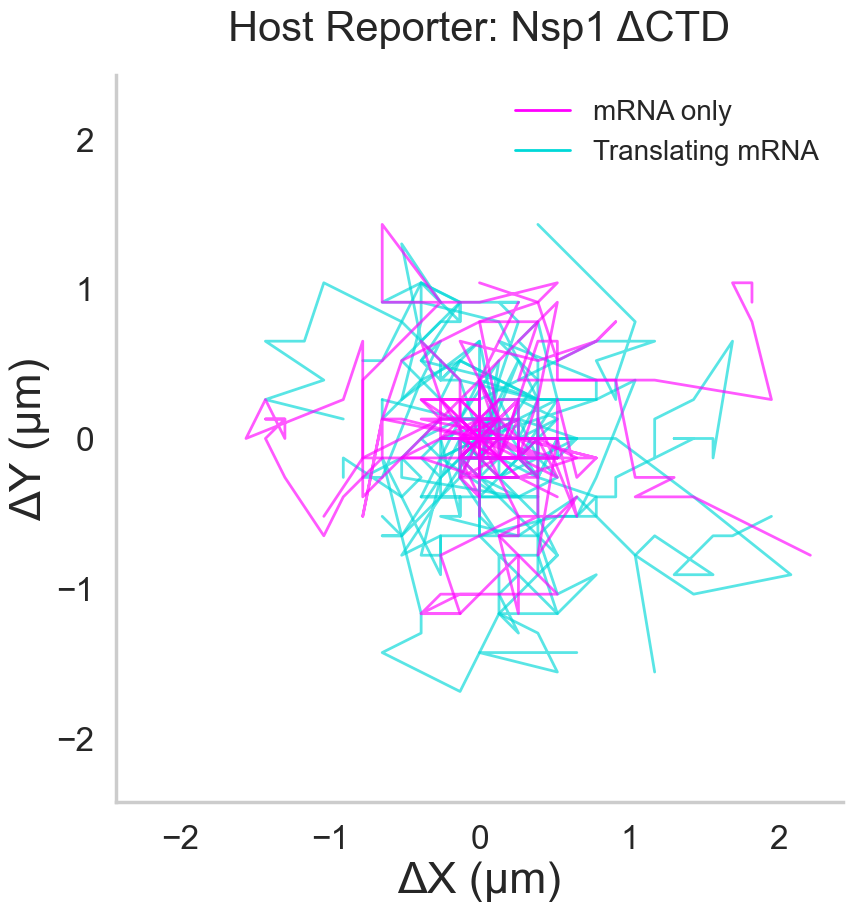

In [194]:
# PLOT INDIVIDUAL 2D TRAJECTORIES
#
# This cell performs NO translation detection or classification.
#
# All classifications were generated previously by the
# trajectory preprocessing cell.
#
# Magenta = mRNA-only tracks
# Cyan    = translation-associated tracks
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


# ============================================================
# SELECT DATA
# ============================================================

TRACE_EXPERIMENTAL_GROUP = "SARS_CTRL"

TRACE_EXPERIMENTAL_TYPE = "NoCTD Nsp1"


# Number sampled FROM EACH CLASS.
#
# 20 means:
#
#     up to 20 mRNA-only tracks
#     up to 20 translating tracks
#
N_TRACES_PER_CLASS = 25


# Reproducible sampling.
TRACE_RANDOM_STATE = 15


# ============================================================
# DISPLAY SETTINGS
# ============================================================

CENTER_TRACKS_AT_ORIGIN = True

XY_PIXEL_SIZE_UM = 0.130


RNA_COLOR = "#FF00FF"

TRANSLATION_COLOR = "#00D8D8"


# Identical line styling for both populations.
TRACE_LINE_WIDTH = 2.0

TRACE_ALPHA = 0.65


FIGSIZE = (
    9,
    9
)


# Optional manual XY limit in µm.
#
# None = automatically calculate from displayed trajectories.
#
# Example:
#     TRAJECTORY_XY_LIMIT = 2.0
#
TRAJECTORY_XY_LIMIT = None


# ============================================================
# SAVE
# ============================================================

SAVE_TRACE_FIGURE = True


TRACE_FIGURE_NAME = (
    f"{TRACE_EXPERIMENTAL_GROUP}_"
    f"{TRACE_EXPERIMENTAL_TYPE}_"
    "individual_trajectories"
)


# ============================================================
# FIND PRECOMPUTED FILE
# ============================================================

safe_group = make_safe_filename(
    TRACE_EXPERIMENTAL_GROUP
)


safe_type = make_safe_filename(
    TRACE_EXPERIMENTAL_TYPE
)


trajectory_path = (

    TRAJECTORY_PLOT_DATA_DIR

    /

    (
        f"{safe_group}_"
        f"{safe_type}_"
        "trajectory_plot_data.csv"
    )
)


if not trajectory_path.exists():

    raise FileNotFoundError(

        "Precomputed trajectory file was not found:\n"

        f"{trajectory_path}\n\n"

        "Run the trajectory preprocessing cell first."
    )


# ============================================================
# LOAD
# ============================================================

trajectory_data = pd.read_csv(
    trajectory_path
)


print(
    f"Loaded:\n"
    f"{trajectory_path}"
)


# ============================================================
# ONE ROW PER TRACK
# ============================================================

track_table = (

    trajectory_data

    .groupby(
        "track_uid",
        as_index=False,
    )

    .agg(

        Track_Class=(
            "Track_Class",
            "first",
        ),

        Track_Length=(
            "Track_Length",
            "first",
        ),

        Translation_Positive_Frames=(
            "Translation_Positive_Frames",
            "first",
        ),
    )
)


# ============================================================
# SPLIT TRACK CLASSES
# ============================================================

mrna_tracks = track_table.loc[

    track_table[
        "Track_Class"
    ].eq(
        "mRNA only"
    )

].copy()


translation_tracks = track_table.loc[

    track_table[
        "Track_Class"
    ].eq(
        "Translation"
    )

].copy()


print(
    f"\nmRNA-only tracks available: "
    f"{len(mrna_tracks):,}"
)


print(
    f"Translation tracks available: "
    f"{len(translation_tracks):,}"
)


# ============================================================
# SAMPLE
# ============================================================

n_mrna = min(
    N_TRACES_PER_CLASS,
    len(
        mrna_tracks
    ),
)


n_translation = min(
    N_TRACES_PER_CLASS,
    len(
        translation_tracks
    ),
)


selected_mrna = (

    mrna_tracks

    .sample(
        n=n_mrna,
        random_state=
            TRACE_RANDOM_STATE,
    )

    if n_mrna > 0

    else pd.DataFrame()
)


selected_translation = (

    translation_tracks

    .sample(
        n=n_translation,
        random_state=
            TRACE_RANDOM_STATE + 1,
    )

    if n_translation > 0

    else pd.DataFrame()
)


selected_uids = set(

    pd.concat(

        [
            selected_mrna,
            selected_translation,
        ],

        ignore_index=True,
    )[
        "track_uid"
    ]
)


selected_data = trajectory_data.loc[

    trajectory_data[
        "track_uid"
    ].isin(
        selected_uids
    )

].copy()


print(
    f"\nTracks plotted:"
)

print(
    f"  mRNA only: "
    f"{n_mrna}"
)

print(
    f"  Translation: "
    f"{n_translation}"
)


# ============================================================
# STYLE
# ============================================================

sns.set(
    font_scale=1.8
)


sns.set_style(
    "whitegrid",
    {
        "grid.linestyle":
            ""
    }
)


sns.set_context(
    "poster"
)


fig, ax = plt.subplots(

    figsize=
        FIGSIZE,

    constrained_layout=True,
)


sns.despine(

    ax=ax,

    top=True,

    right=True,
)


# ============================================================
# DRAW TRAJECTORIES
# ============================================================

all_x = []
all_y = []


for track_uid, track in (

    selected_data

    .groupby(
        "track_uid",
        sort=False,
    )
):


    track = (

        track

        .sort_values(
            "frame"
        )

        .drop_duplicates(
            "frame",
            keep="last",
        )

        .copy()
    )


    track_class = str(
        track[
            "Track_Class"
        ].iloc[0]
    )


    if track_class == "Translation":

        color = (
            TRANSLATION_COLOR
        )


    elif track_class == "mRNA only":

        color = (
            RNA_COLOR
        )


    else:

        continue


    x = (

        pd.to_numeric(
            track[
                "x"
            ],
            errors="coerce",
        )

        .to_numpy(
            dtype=float
        )

        *

        XY_PIXEL_SIZE_UM
    )


    y = (

        pd.to_numeric(
            track[
                "y"
            ],
            errors="coerce",
        )

        .to_numpy(
            dtype=float
        )

        *

        XY_PIXEL_SIZE_UM
    )


    valid = (

        np.isfinite(
            x
        )

        &

        np.isfinite(
            y
        )
    )


    x = x[
        valid
    ]


    y = y[
        valid
    ]


    if len(x) < 2:

        continue


    # --------------------------------------------------------
    # Recenter trajectory
    # --------------------------------------------------------

    if CENTER_TRACKS_AT_ORIGIN:

        x = (
            x
            -
            x[0]
        )


        y = (
            y
            -
            y[0]
        )


    all_x.extend(
        x
    )


    all_y.extend(
        y
    )


    # --------------------------------------------------------
    # Draw
    #
    # No markers.
    # Same linewidth for both track classes.
    # --------------------------------------------------------

    ax.plot(

        x,

        y,

        color=
            color,

        linewidth=
            TRACE_LINE_WIDTH,

        alpha=
            TRACE_ALPHA,
    )


# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "ΔX (µm)",
    fontsize=32,
)


ax.set_ylabel(
    "ΔY (µm)",
    fontsize=32,
)


ax.set_title(

    (
        f"Host Reporter: "
        f"Nsp1 ΔCTD"
    ),

    fontsize=30,

    pad=25,
)


ax.tick_params(

    axis="both",

    labelsize=24,
)


# Spatial geometry must be identical on X and Y.
ax.set_aspect(
    "equal",
    adjustable="box",
)


# ============================================================
# AXIS LIMITS
# ============================================================

if TRAJECTORY_XY_LIMIT is not None:


    limit = float(
        TRAJECTORY_XY_LIMIT
    )


else:


    if not all_x or not all_y:

        limit = 1.0


    else:

        limit = np.nanmax(

            np.abs(

                np.concatenate(
                    [
                        np.asarray(
                            all_x
                        ),

                        np.asarray(
                            all_y
                        ),
                    ]
                )
            )
        )


        limit *= (
            1.10
        )


ax.set_xlim(
    -limit,
    limit,
)


ax.set_ylim(
    -limit,
    limit,
)


# ============================================================
# LEGEND
# ============================================================

legend_handles = [

    Line2D(

        [0],
        [0],

        color=
            RNA_COLOR,

        linewidth=
            TRACE_LINE_WIDTH,

        label=
            "mRNA only",
    ),


    Line2D(

        [0],
        [0],

        color=
            TRANSLATION_COLOR,

        linewidth=
            TRACE_LINE_WIDTH,

        label=
            "Translating mRNA",
    ),
]


ax.legend(

    handles=
        legend_handles,

    frameon=False,

    fontsize=20,
)


# ============================================================
# SAVE
# ============================================================

if SAVE_TRACE_FIGURE:


    png_path = (

        MSD_FIGURE_DIR

        /

        f"{TRACE_FIGURE_NAME}.png"
    )


    svg_path = (

        MSD_FIGURE_DIR

        /

        f"{TRACE_FIGURE_NAME}.svg"
    )


    fig.savefig(

        png_path,

        dpi=300,

        bbox_inches="tight",
    )


    fig.savefig(

        svg_path,

        bbox_inches="tight",
    )


    print(
        f"\nSaved:\n{png_path}"
    )


    print(
        f"\nSaved:\n{svg_path}"
    )


plt.show()

# Ripley Clustering

In [79]:
# mRNA HARD-CORE LOCAL PAIR ENRICHMENT
# CONFIGURATION + SPATIAL HELPERS
#
# Runs on ALL Experimental Groups × Experimental Types
# represented in df_no_outliers.
# ============================================================

import gc
import zlib

from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

from tifffile import imread

from scipy.ndimage import (
    binary_fill_holes,
    binary_dilation,
)

from scipy.spatial.distance import pdist


# ============================================================
# OPTIONAL GROUP / TYPE FILTERS
#
# None = analyze everything available.
# ============================================================

CLUSTER_GROUPS_TO_RUN = None

# Example:
#
# CLUSTER_GROUPS_TO_RUN = [
#     "SARS_CTRL",
#     "KDM5B",
#     "Emi_KDM5B",
# ]


CLUSTER_TYPES_TO_RUN = None

# Example:
#
# CLUSTER_TYPES_TO_RUN = [
#     "No Nsp1",
#     "Nsp1",
#     "NoCTD Nsp1",
# ]


# ============================================================
# FRAMES
#
# Analyze frames independently.
# Then:
#
#     frame -> cell -> biological replicate
#
# Do NOT pool RNA coordinates across frames.
# ============================================================

CLUSTER_TIMEPOINTS = [
    0,
    1,
    2,
    3,
    4,
]


CLUSTER_MIN_VALID_FRAMES = 3

CLUSTER_MIN_RNA_PER_FRAME = 10


# ============================================================
# SPATIAL CALIBRATION
# ============================================================

CLUSTER_XY_UM_PER_PIXEL = 0.130


# ============================================================
# HARD-CORE DISTANCE
#
# mRNA detection uses a 5-pixel feature diameter.
#
#     5 px × 0.130 µm/px = 0.650 µm
#
# Simulated RNAs are therefore not allowed to be closer
# together than 0.65 µm.
# ============================================================

RNA_DETECTION_DIAMETER_PX = 5


CLUSTER_HARDCORE_MIN_UM = (
    RNA_DETECTION_DIAMETER_PX
    *
    CLUSTER_XY_UM_PER_PIXEL
)


# ============================================================
# PAIR DISTANCE RANGE
#
# Start one pixel above the hard-core distance.
#
# With 0.65 µm hard-core:
#
#     first point = 0.78 µm
#
# Current range:
#
#     0.78 - 1.56 µm
# ============================================================

CLUSTER_PAIR_RADIUS_STEP_UM = 0.13

CLUSTER_PAIR_RADIUS_BUFFER_UM = 0.13

CLUSTER_PAIR_RADIUS_MAX_UM = 1.56


def build_hardcore_pair_radii(
    min_separation_um,
):

    step = float(
        CLUSTER_PAIR_RADIUS_STEP_UM
    )


    start = (
        float(
            min_separation_um
        )
        +
        float(
            CLUSTER_PAIR_RADIUS_BUFFER_UM
        )
    )


    start = (
        np.ceil(
            start / step
        )
        *
        step
    )


    maximum = float(
        CLUSTER_PAIR_RADIUS_MAX_UM
    )


    if start > maximum:

        raise ValueError(
            "Hard-core distance is larger than the "
            "available pair-analysis range."
        )


    return np.arange(
        start,
        maximum + step / 2,
        step
    )


CLUSTER_PAIR_RADII_UM = (
    build_hardcore_pair_radii(
        CLUSTER_HARDCORE_MIN_UM
    )
)


# ============================================================
# RADIAL NULL MODEL
#
# Preserve broad intracellular localization with three
# approximately equal-area cytoplasmic sections:
#
#     1 = peri-nuclear
#     2 = middle cytoplasm
#     3 = peripheral cytoplasm
# ============================================================

CLUSTER_N_SECTIONS = 3


# ============================================================
# MONTE CARLO
# ============================================================

CLUSTER_N_SIMULATIONS = 199

CLUSTER_RANDOM_SEED = 2026


# ============================================================
# OUTPUT
# ============================================================

CLUSTER_OUTPUT_DIR = (

    Path(
        r"C:\Temp_data\Rapid"
    )

    /
    "Hard-Core Pair Enrichment"
)


CLUSTER_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


ALL_CLUSTER_OUTPUT_DIR = (

    CLUSTER_OUTPUT_DIR
    /
    "All Groups"
)


ALL_CLUSTER_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# BASIC HELPERS
# ============================================================

def clustering_scalar(
    obj,
    default=np.nan,
):

    try:

        arr = np.asarray(

            obj.values
            if hasattr(
                obj,
                "values"
            )
            else obj
        )


        if arr.size == 0:

            return default


        return arr.reshape(-1)[0]


    except Exception:

        return default



def clustering_select_ch0(
    data_array,
):

    if "ch" in data_array.dims:

        return data_array.sel(
            ch=0
        )


    return data_array



def clustering_stable_seed(
    *parts,
):

    text = "|".join(

        str(part)

        for part in parts
    )


    hashed = zlib.crc32(
        text.encode(
            "utf-8"
        )
    )


    return (

        int(
            CLUSTER_RANDOM_SEED
        )

        +

        int(
            hashed
        )

    ) % (2**32)


# ============================================================
# NOTEBOOK GROUP/TYPE -> RAW Exp_G
# ============================================================

def experimental_group_type_to_raw_exp_g(
    experimental_group,
    experimental_type,
):

    experimental_group = str(
        experimental_group
    )

    experimental_type = str(
        experimental_type
    )


    if experimental_type == "No Nsp1":

        return experimental_group


    elif experimental_type == "Nsp1":

        return (
            f"Nsp1_{experimental_group}"
        )


    elif experimental_type == "NoCTD Nsp1":

        return (
            f"Nsp1_NoCTD_{experimental_group}"
        )


    else:

        raise ValueError(
            "Unknown Experimental Type: "
            f"{experimental_type!r}"
        )


# ============================================================
# BUILD CONDITION TABLE
# ============================================================

def build_clustering_condition_table():

    conditions = (

        df_no_outliers[
            [
                "Experimental Group",
                "Experimental Type",
            ]
        ]

        .drop_duplicates()

        .reset_index(
            drop=True
        )
    )


    # --------------------------------------------------------
    # Optional user filters
    # --------------------------------------------------------

    if (
        CLUSTER_GROUPS_TO_RUN
        is not None
    ):

        conditions = conditions.loc[

            conditions[
                "Experimental Group"
            ].isin(
                CLUSTER_GROUPS_TO_RUN
            )

        ].copy()


    if (
        CLUSTER_TYPES_TO_RUN
        is not None
    ):

        conditions = conditions.loc[

            conditions[
                "Experimental Type"
            ].isin(
                CLUSTER_TYPES_TO_RUN
            )

        ].copy()


    # --------------------------------------------------------
    # Raw Exp_G name
    # --------------------------------------------------------

    conditions[
        "Raw Exp_G"
    ] = conditions.apply(

        lambda row:
            experimental_group_type_to_raw_exp_g(

                row[
                    "Experimental Group"
                ],

                row[
                    "Experimental Type"
                ],
            ),

        axis=1
    )


    # --------------------------------------------------------
    # Check against actual xarray groups
    # --------------------------------------------------------

    available_raw_groups = set(

        str(value)

        for value in

        np.asarray(
            combined_ds_1[
                "Exp_G"
            ].values
        ).reshape(-1)
    )


    conditions[
        "Raw Exp_G Exists"
    ] = conditions[
        "Raw Exp_G"
    ].isin(
        available_raw_groups
    )


    return (

        conditions

        .sort_values(
            [
                "Experimental Group",
                "Experimental Type",
            ]
        )

        .reset_index(
            drop=True
        )
    )


clustering_condition_table = (
    build_clustering_condition_table()
)


print(
    "\nClustering condition table"
)

print(
    "=========================="
)


display(
    clustering_condition_table
)


missing_conditions = (

    clustering_condition_table.loc[

        ~clustering_condition_table[
            "Raw Exp_G Exists"
        ]

    ]

    .copy()
)


if not missing_conditions.empty:

    print(
        "\nWARNING — conditions that cannot "
        "currently be matched:"
    )

    display(
        missing_conditions
    )


# ============================================================
# LOAD CELL + NUCLEAR MASKS
# ============================================================

def get_clustering_cell_masks(
    *,
    raw_exp_g,
    replicate_number,
    cell_number,
    dish="",
):

    rows = all_files_df.loc[

        all_files_df[
            "Exp_G"
        ]
        .astype(str)
        .eq(
            str(
                raw_exp_g
            )
        )

        &

        pd.to_numeric(
            all_files_df[
                "Replicate_Number"
            ],
            errors="coerce"
        ).eq(
            int(
                replicate_number
            )
        )

        &

        pd.to_numeric(
            all_files_df[
                "Cell_Number"
            ],
            errors="coerce"
        ).eq(
            int(
                cell_number
            )
        )

    ].copy()


    # --------------------------------------------------------
    # Dish can disambiguate repeated Cell_Number values
    # --------------------------------------------------------

    if (
        dish is not None
        and
        str(dish) != ""
        and
        "Dish" in rows.columns
    ):


        dish_rows = rows.loc[

            rows[
                "Dish"
            ]
            .astype(str)
            .eq(
                str(
                    dish
                )
            )

        ]


        if not dish_rows.empty:

            rows = (
                dish_rows.copy()
            )


    def get_one_path(
        role,
    ):


        hits = rows.loc[

            rows[
                "File_Role"
            ].eq(
                role
            )

        ]


        if len(hits) != 1:

            raise ValueError(

                f"Expected exactly one {role} for:\n"

                f"{raw_exp_g} | "
                f"Rep {replicate_number} | "
                f"Cell {cell_number} | "
                f"Dish {dish}\n"

                f"Found {len(hits)}"
            )


        return Path(

            hits[
                "File_Path"
            ].iloc[0]
        )


    cell_mask = np.squeeze(

        imread(

            get_one_path(
                "cytoplasmic_mask"
            )
        )

    ) > 0


    nucleus_mask = np.squeeze(

        imread(

            get_one_path(
                "nuclear_mask"
            )
        )

    ) > 0


    if (
        cell_mask.ndim != 2
        or
        nucleus_mask.ndim != 2
    ):

        raise ValueError(
            "Expected 2D cell/nuclear masks."
        )


    if (
        cell_mask.shape
        !=
        nucleus_mask.shape
    ):

        raise ValueError(
            "Cell and nuclear masks have different shapes."
        )


    cell_mask = binary_fill_holes(
        cell_mask
    )


    nucleus_mask = binary_fill_holes(
        nucleus_mask
    )


    return (
        cell_mask,
        nucleus_mask
    )


# ============================================================
# GENERATE THREE RADIAL CYTOPLASMIC SECTIONS
# ============================================================

def make_radial_cytoplasm_sections(
    nucleus_mask,
    cell_mask,
    n_sections=3,
):


    nucleus = binary_fill_holes(

        np.asarray(
            nucleus_mask
        ) > 0
    )


    cell = binary_fill_holes(

        np.asarray(
            cell_mask
        ) > 0
    )


    cytoplasm = (
        cell
        &
        ~nucleus
    )


    if not np.any(
        cytoplasm
    ):

        raise ValueError(
            "Cytoplasmic area is empty."
        )


    if int(
        n_sections
    ) == 1:

        return [
            cytoplasm
        ]


    total_area = int(
        cytoplasm.sum()
    )


    structure = np.ones(
        (3, 3),
        dtype=bool
    )


    cumulative_masks = []

    dilated = (
        nucleus.copy()
    )


    max_iterations = (

        max(
            nucleus.shape
        )

        +

        min(
            nucleus.shape
        )

        +

        10
    )


    # --------------------------------------------------------
    # Build cumulative boundaries at ~1/3 and ~2/3 area
    # --------------------------------------------------------

    for section_idx in range(
        1,
        int(
            n_sections
        )
    ):


        target_area = (

            total_area
            *
            section_idx

            /

            float(
                n_sections
            )
        )


        previous_area = -1


        for _ in range(
            max_iterations
        ):


            current_area = int(

                (
                    dilated
                    &
                    cell
                    &
                    ~nucleus
                ).sum()
            )


            if (
                current_area
                >=
                target_area
            ):

                break


            new_dilated = (

                binary_dilation(

                    dilated,

                    structure=
                        structure
                )

                &

                cell
            )


            new_area = int(

                (
                    new_dilated
                    &
                    cell
                    &
                    ~nucleus
                ).sum()
            )


            if (
                new_area
                ==
                previous_area
                or
                np.array_equal(
                    new_dilated,
                    dilated
                )
            ):

                dilated = (
                    new_dilated
                )

                break


            previous_area = (
                new_area
            )


            dilated = (
                new_dilated
            )


        cumulative_masks.append(

            dilated
            &
            cell
            &
            ~nucleus
        )


    # --------------------------------------------------------
    # Convert cumulative masks into non-overlapping sections
    # --------------------------------------------------------

    sections = []


    previous = np.zeros_like(
        cytoplasm,
        dtype=bool
    )


    for cumulative in (
        cumulative_masks
    ):


        section = (
            cumulative
            &
            ~previous
        )


        sections.append(
            section
        )


        previous |= (
            cumulative
        )


    sections.append(

        cytoplasm
        &
        ~previous
    )


    # --------------------------------------------------------
    # Final no-overlap cleanup
    # --------------------------------------------------------

    cleaned = []


    used = np.zeros_like(
        cytoplasm,
        dtype=bool
    )


    for section in sections:


        clean = (

            section
            &
            cytoplasm
            &
            ~used
        )


        cleaned.append(
            clean
        )


        used |= (
            clean
        )


    missing = (
        cytoplasm
        &
        ~used
    )


    if np.any(
        missing
    ):

        cleaned[-1] |= (
            missing
        )


    return cleaned


# ============================================================
# EXTRACT RNA XY POSITIONS FROM ONE FRAME
# ============================================================

def get_clustering_rna_positions(
    *,
    raw_exp_g,
    fov,
    frame,
):


    cell = (

        combined_ds_1

        .sel(
            Exp_G=
                raw_exp_g
        )

        .isel(
            fov=
                int(
                    fov
                )
        )
    )


    variables = {

        "RNA_spot_sig":
            clustering_select_ch0(
                cell[
                    "RNA_spot_sig"
                ]
            ),

        "xc":
            clustering_select_ch0(
                cell[
                    "xc"
                ]
            ),

        "yc":
            clustering_select_ch0(
                cell[
                    "yc"
                ]
            ),
    }


    frame_df = (

        xr.Dataset(
            variables
        )

        .to_dataframe()

        .reset_index()
    )


    frame_df = frame_df.loc[

        pd.to_numeric(
            frame_df[
                "t"
            ],
            errors="coerce"
        ).eq(
            int(
                frame
            )
        )

    ].copy()


    # --------------------------------------------------------
    # Positive RNA detections only
    # --------------------------------------------------------

    frame_df = frame_df.loc[

        pd.to_numeric(
            frame_df[
                "RNA_spot_sig"
            ],
            errors="coerce"
        ) > 0

    ].copy()


    if frame_df.empty:

        return np.empty(
            (0, 2),
            dtype=float
        )


    # --------------------------------------------------------
    # Convert crop coordinates to original-image coordinates
    # --------------------------------------------------------

    xy_pad = float(

        clustering_scalar(

            cell[
                "xy_pad"
            ],

            default=0
        )
    )


    x = (

        pd.to_numeric(
            frame_df[
                "xc"
            ],
            errors="coerce"
        )

        -

        xy_pad
    )


    y = (

        pd.to_numeric(
            frame_df[
                "yc"
            ],
            errors="coerce"
        )

        -

        xy_pad
    )


    xy = np.column_stack(
        [
            x,
            y
        ]
    )


    xy = xy[

        np.isfinite(
            xy
        ).all(
            axis=1
        )

    ]


    return xy.astype(
        float
    )


# ============================================================
# ASSIGN RNA TO RADIAL SECTIONS
# ============================================================

def assign_points_to_sections(
    xy_px,
    section_masks,
):


    xy_px = np.asarray(
        xy_px,
        dtype=float
    )


    if len(
        xy_px
    ) == 0:

        return (

            np.empty(
                (0, 2),
                dtype=float
            ),

            np.empty(
                0,
                dtype=int
            )
        )


    x_int = np.rint(
        xy_px[:, 0]
    ).astype(int)


    y_int = np.rint(
        xy_px[:, 1]
    ).astype(int)


    shape_y, shape_x = (
        section_masks[0].shape
    )


    in_bounds = (

        (x_int >= 0)
        &
        (x_int < shape_x)
        &
        (y_int >= 0)
        &
        (y_int < shape_y)
    )


    labels = np.full(
        len(
            xy_px
        ),
        -1,
        dtype=int
    )


    for section_index, mask in enumerate(
        section_masks
    ):


        valid_indices = np.where(

            in_bounds
            &
            (
                labels < 0
            )

        )[0]


        if len(
            valid_indices
        ) == 0:

            continue


        inside = mask[

            y_int[
                valid_indices
            ],

            x_int[
                valid_indices
            ]
        ]


        labels[

            valid_indices[
                inside
            ]

        ] = (
            section_index
        )


    keep = (
        labels >= 0
    )


    return (

        xy_px[
            keep
        ],

        labels[
            keep
        ]
    )


# ============================================================
# CUMULATIVE PAIR COUNTS
# ============================================================

def cumulative_pair_counts(
    xy_um,
    radii_um,
):


    xy_um = np.asarray(
        xy_um,
        dtype=float
    )


    if len(
        xy_um
    ) < 2:

        return np.zeros(

            len(
                radii_um
            ),

            dtype=float
        )


    distances = np.sort(
        pdist(
            xy_um
        )
    )


    return np.searchsorted(

        distances,

        radii_um,

        side="right"

    ).astype(
        float
    )


print(
    "\nHard-core minimum separation:"
    f" {CLUSTER_HARDCORE_MIN_UM:.3f} µm"
)


print(
    "Pair-analysis radii:"
)


print(
    np.round(
        CLUSTER_PAIR_RADII_UM,
        3
    )
)


Clustering condition table


,Experimental Group,Experimental Type,Raw Exp_G,Raw Exp_G Exists
0,BoxB_IRES,No Nsp1,BoxB_IRES,True
1,BoxB_IRES,Nsp1,Nsp1_BoxB_IRES,True
2,BoxB_MS2,No Nsp1,BoxB_MS2,True
3,BoxB_MS2,NoCTD Nsp1,Nsp1_NoCTD_BoxB_MS2,True
4,BoxB_MS2,Nsp1,Nsp1_BoxB_MS2,True
5,EMI_NoORF,No Nsp1,EMI_NoORF,True
6,EMI_NoORF,Nsp1,Nsp1_EMI_NoORF,True
7,Emi_KDM5B,No Nsp1,Emi_KDM5B,True
8,Emi_KDM5B,NoCTD Nsp1,Nsp1_NoCTD_Emi_KDM5B,True
9,Emi_KDM5B,Nsp1,Nsp1_Emi_KDM5B,True



Hard-core minimum separation: 0.650 µm
Pair-analysis radii:
[0.78 0.91 1.04 1.17 1.3  1.43 1.56]


In [80]:
# HARD-CORE LOCAL PAIR ENRICHMENT
# CALCULATION HELPERS
#
# Null model preserves:
#
#   1. cell shape
#   2. nuclear exclusion
#   3. total RNA number
#   4. RNA number in each radial section
#   5. minimum resolvable RNA-RNA distance
#
# Primary metric:
#
#     Hard-Core Pair Enrichment
#
#     1 = matched diffuse expectation
#    >1 = excess nearby RNA pairs
#    <1 = fewer nearby RNA pairs than expected
# ============================================================


# ============================================================
# HARD-CORE RANDOM PATTERN
# ============================================================

def generate_radial_hardcore_random_points(
    section_pixel_coordinates,
    section_counts,
    rng,
    *,
    min_separation_um,
    max_restarts=100,
    max_attempts_per_point=2500,
):


    min_separation_px = (

        float(
            min_separation_um
        )

        /

        CLUSTER_XY_UM_PER_PIXEL
    )


    min_sep_squared = (
        min_separation_px ** 2
    )


    # --------------------------------------------------------
    # Section membership required for every simulated RNA
    # --------------------------------------------------------

    required_sections = np.concatenate(
        [

            np.full(
                int(
                    count
                ),
                section_index,
                dtype=int
            )

            for section_index, count
            in enumerate(
                section_counts
            )

            if int(
                count
            ) > 0
        ]
    )


    if len(
        required_sections
    ) == 0:

        return np.empty(
            (0, 2),
            dtype=float
        )


    # ========================================================
    # COMPLETE PATTERN RESTARTS
    # ========================================================

    for restart in range(
        int(
            max_restarts
        )
    ):


        # Randomize which radial section gets placed first.
        placement_order = rng.permutation(
            required_sections
        )


        accepted_xy = []

        successful_pattern = True


        for section_index in (
            placement_order
        ):


            pixels_yx = (

                section_pixel_coordinates[
                    int(
                        section_index
                    )
                ]

            )


            if len(
                pixels_yx
            ) == 0:

                successful_pattern = False

                break


            point_was_placed = False


            for attempt in range(
                int(
                    max_attempts_per_point
                )
            ):


                pixel_index = rng.integers(
                    0,
                    len(
                        pixels_yx
                    )
                )


                candidate_yx = (

                    pixels_yx[
                        pixel_index
                    ]

                    .astype(
                        float
                    )
                )


                # Subpixel jitter
                candidate_yx += rng.uniform(

                    -0.49,
                    0.49,

                    size=2
                )


                candidate_xy = np.array(
                    [
                        candidate_yx[1],
                        candidate_yx[0],
                    ],
                    dtype=float
                )


                # First point always succeeds
                if not accepted_xy:

                    accepted_xy.append(
                        candidate_xy
                    )

                    point_was_placed = True

                    break


                existing = np.asarray(
                    accepted_xy,
                    dtype=float
                )


                displacement = (

                    existing
                    -
                    candidate_xy
                )


                distances_squared = np.sum(

                    displacement ** 2,

                    axis=1
                )


                if np.all(

                    distances_squared
                    >=
                    min_sep_squared

                ):

                    accepted_xy.append(
                        candidate_xy
                    )

                    point_was_placed = True

                    break


            if not point_was_placed:

                successful_pattern = False

                break


        if (
            successful_pattern
            and
            len(
                accepted_xy
            )
            ==
            len(
                required_sections
            )
        ):

            return np.asarray(
                accepted_xy,
                dtype=float
            )


    raise RuntimeError(

        "Could not generate a hard-core random pattern "
        f"after {max_restarts} restarts. "

        "The RNA density may be too high for the configured "
        "minimum separation."
    )


# ============================================================
# FRAME-LEVEL HARD-CORE PAIR ENRICHMENT
# ============================================================

def calculate_hardcore_pair_enrichment(
    observed_xy_px,
    section_labels,
    section_masks,
    *,
    radii_um=None,
    n_simulations=None,
    random_seed=None,
    min_separation_um=None,
):


    if radii_um is None:

        radii_um = np.asarray(
            CLUSTER_PAIR_RADII_UM,
            dtype=float
        )


    if n_simulations is None:

        n_simulations = int(
            CLUSTER_N_SIMULATIONS
        )


    if min_separation_um is None:

        min_separation_um = float(
            CLUSTER_HARDCORE_MIN_UM
        )


    observed_xy_px = np.asarray(
        observed_xy_px,
        dtype=float
    )


    section_labels = np.asarray(
        section_labels,
        dtype=int
    )


    n_rna = len(
        observed_xy_px
    )


    if n_rna < 2:

        return (
            None,
            None
        )


    # ========================================================
    # CELL AREA + RNA DENSITY
    # ========================================================

    cytoplasm_pixels = int(

        sum(

            np.asarray(
                mask
            ).sum()

            for mask in
            section_masks
        )
    )


    area_um2 = (

        cytoplasm_pixels
        *
        CLUSTER_XY_UM_PER_PIXEL ** 2
    )


    density = (

        n_rna
        /
        area_um2

    )


    # ========================================================
    # OBSERVED RNA NUMBER PER RADIAL SECTION
    # ========================================================

    section_counts = np.asarray(
        [

            np.sum(

                section_labels
                ==
                section_index
            )

            for section_index
            in range(
                len(
                    section_masks
                )
            )
        ],

        dtype=int
    )


    section_pixel_coordinates = [

        np.argwhere(
            section_mask
        )

        for section_mask
        in section_masks
    ]


    # ========================================================
    # OBSERVED PAIRS
    # ========================================================

    observed_xy_um = (

        observed_xy_px
        *
        CLUSTER_XY_UM_PER_PIXEL
    )


    observed_pair_distances = pdist(
        observed_xy_um
    )


    observed_pairs_below_hardcore = int(

        np.sum(

            observed_pair_distances
            <
            min_separation_um
        )
    )


    observed_pairs = (
        cumulative_pair_counts(

            observed_xy_um,

            radii_um
        )
    )


    observed_integral = float(

        np.trapz(

            observed_pairs,

            radii_um
        )
    )


    # ========================================================
    # HARD-CORE MONTE CARLO NULL
    # ========================================================

    rng = np.random.default_rng(
        random_seed
    )


    simulated_pairs = np.empty(

        (
            int(
                n_simulations
            ),
            len(
                radii_um
            )
        ),

        dtype=float
    )


    simulated_integrals = np.empty(

        int(
            n_simulations
        ),

        dtype=float
    )


    for simulation in range(
        int(
            n_simulations
        )
    ):


        random_xy_px = (
            generate_radial_hardcore_random_points(

                section_pixel_coordinates,

                section_counts,

                rng,

                min_separation_um=
                    min_separation_um,
            )
        )


        random_xy_um = (

            random_xy_px
            *
            CLUSTER_XY_UM_PER_PIXEL
        )


        random_pairs = (
            cumulative_pair_counts(

                random_xy_um,

                radii_um
            )
        )


        simulated_pairs[
            simulation,
            :
        ] = random_pairs


        simulated_integrals[
            simulation
        ] = np.trapz(

            random_pairs,

            radii_um
        )


    # ========================================================
    # EXPECTED PAIR CURVE
    # ========================================================

    expected_pairs = np.mean(

        simulated_pairs,

        axis=0
    )


    expected_lower = np.percentile(

        simulated_pairs,

        2.5,

        axis=0
    )


    expected_upper = np.percentile(

        simulated_pairs,

        97.5,

        axis=0
    )


    # ========================================================
    # ENRICHMENT CURVE
    # ========================================================

    enrichment_curve = np.divide(

        observed_pairs,

        expected_pairs,

        out=np.full(

            len(
                radii_um
            ),

            np.nan,

            dtype=float
        ),

        where=
            expected_pairs > 0
    )


    # ========================================================
    # PRIMARY SCALAR
    #
    # Ratio of AUCs across the selected local distance range.
    # ========================================================

    expected_integral = float(

        np.mean(
            simulated_integrals
        )
    )


    expected_integral_sd = float(

        np.std(
            simulated_integrals,
            ddof=1
        )
    )


    if expected_integral > 0:

        pair_enrichment = (

            observed_integral
            /
            expected_integral
        )

    else:

        pair_enrichment = (
            np.nan
        )


    # ========================================================
    # Z SCORE
    # ========================================================

    if (
        np.isfinite(
            expected_integral_sd
        )
        and
        expected_integral_sd > 0
    ):

        z_score = (

            observed_integral
            -
            expected_integral

        ) / expected_integral_sd

    else:

        z_score = (
            np.nan
        )


    # ========================================================
    # MONTE CARLO ONE-SIDED P VALUE
    # ========================================================

    clustering_p = (

        1
        +
        np.sum(

            simulated_integrals
            >=
            observed_integral
        )

    ) / (

        int(
            n_simulations
        )
        +
        1
    )


    # ========================================================
    # SUMMARY
    # ========================================================

    summary = {

        "RNA Count":
            int(
                n_rna
            ),

        "Cytoplasm Area (um2)":
            float(
                area_um2
            ),

        "RNA Density (per um2)":
            float(
                density
            ),

        "Section 1 RNA Count":
            int(
                section_counts[0]
            ),

        "Section 2 RNA Count":
            int(
                section_counts[1]
            ),

        "Section 3 RNA Count":
            int(
                section_counts[2]
            ),

        "Hard-Core Distance (um)":
            float(
                min_separation_um
            ),

        "Observed Pairs Below Hard-Core":
            observed_pairs_below_hardcore,

        "Observed Pair Integral":
            observed_integral,

        "Expected Pair Integral":
            expected_integral,

        # PRIMARY METRIC
        "Hard-Core Pair Enrichment":
            float(
                pair_enrichment
            ),

        "Pair Clustering Z Score":
            float(
                z_score
            ),

        "Monte Carlo Clustering p":
            float(
                clustering_p
            ),
    }


    # ========================================================
    # DISTANCE-DEPENDENT CURVE
    # ========================================================

    curve = pd.DataFrame({

        "Radius (um)":
            radii_um,

        "Observed Pair Count":
            observed_pairs,

        "Expected Pair Count":
            expected_pairs,

        "Expected Pair Lower 95":
            expected_lower,

        "Expected Pair Upper 95":
            expected_upper,

        "Hard-Core Pair Enrichment":
            enrichment_curve,

        "Hard-Core Distance (um)":
            float(
                min_separation_um
            ),
    })


    return (
        summary,
        curve
    )


print(
    "Hard-core pair-enrichment helpers loaded."
)

Hard-core pair-enrichment helpers loaded.


In [81]:
# CALCULATE HARD-CORE LOCAL PAIR ENRICHMENT
#
# ALL EXPERIMENTAL GROUPS × EXPERIMENTAL TYPES
# ============================================================


# ============================================================
# VALID CONDITIONS
# ============================================================

valid_conditions = (

    clustering_condition_table.loc[

        clustering_condition_table[
            "Raw Exp_G Exists"
        ]

    ]

    .copy()
)


if valid_conditions.empty:

    raise RuntimeError(
        "No valid Group × Type combinations were found."
    )


print(
    "\nConditions that will be analyzed:"
)


display(
    valid_conditions
)


# ============================================================
# SMALL TABLES RETAINED ACROSS GROUPS
# ============================================================

all_group_cell_frames = []

all_group_replicate_curve_frames = []

analysis_manifest = []


# ============================================================
# PROCESS ONE EXPERIMENTAL GROUP AT A TIME
# ============================================================

for experimental_group in (

    valid_conditions[
        "Experimental Group"
    ]

    .drop_duplicates()
):


    print(
        "\n"
        +
        "=" * 75
    )


    print(
        f"CLUSTERING GROUP: "
        f"{experimental_group}"
    )


    print(
        "=" * 75
    )


    # ========================================================
    # TYPES AVAILABLE FOR THIS GROUP
    # ========================================================

    group_conditions = (

        valid_conditions.loc[

            valid_conditions[
                "Experimental Group"
            ].eq(
                experimental_group
            )

        ]

        .copy()
    )


    group_types = (

        group_conditions[
            "Experimental Type"
        ]

        .drop_duplicates()

        .tolist()
    )


    print(
        "Experimental Types:"
    )


    print(
        group_types
    )


    # ========================================================
    # CELL WHITELIST
    #
    # Uses the exact cells that survived your main notebook's
    # cell-level outlier filtering.
    # ========================================================

    group_cells = (

        df_no_outliers.loc[

            df_no_outliers[
                "Experimental Group"
            ].eq(
                experimental_group
            )

            &

            df_no_outliers[
                "Experimental Type"
            ].isin(
                group_types
            )

        ][
            [
                "Experimental Group",
                "Experimental Type",
                "Replicate_Number",
                "fov",
            ]
        ]

        .drop_duplicates()

        .reset_index(
            drop=True
        )
    )


    total_cells = len(
        group_cells
    )


    print(
        f"Cells selected: "
        f"{total_cells}"
    )


    display(

        group_cells

        .groupby(
            [
                "Experimental Type",
                "Replicate_Number"
            ]
        )

        .size()

        .rename(
            "Cells"
        )

        .reset_index()
    )


    # ========================================================
    # GROUP-LEVEL TEMPORARY RESULTS
    # ========================================================

    frame_results = []

    curve_results = []

    skipped_frames = []


    # ========================================================
    # PROCESS CELLS
    # ========================================================

    for cell_i, values in enumerate(

        group_cells[
            [
                "Experimental Group",
                "Experimental Type",
                "Replicate_Number",
                "fov",
            ]
        ]

        .itertuples(
            index=False,
            name=None
        ),

        start=1
    ):


        (
            experimental_group_value,
            experimental_type,
            replicate_number,
            fov
        ) = values


        replicate_number = int(
            replicate_number
        )


        fov = int(
            fov
        )


        # ====================================================
        # RAW Exp_G FOR THIS CONDITION
        # ====================================================

        raw_matches = (

            group_conditions.loc[

                group_conditions[
                    "Experimental Type"
                ].eq(
                    experimental_type
                ),

                "Raw Exp_G"

            ]

            .drop_duplicates()
        )


        if len(
            raw_matches
        ) != 1:


            print(
                f"WARNING: could not uniquely resolve "
                f"{experimental_group_value} | "
                f"{experimental_type}"
            )


            continue


        raw_exp_g = str(
            raw_matches.iloc[0]
        )


        # ====================================================
        # CELL METADATA
        # ====================================================

        try:

            cell_ds = (

                combined_ds_1

                .sel(
                    Exp_G=
                        raw_exp_g
                )

                .isel(
                    fov=
                        fov
                )
            )


            cell_number = int(

                clustering_scalar(

                    cell_ds[
                        "Cell_Number"
                    ]
                )
            )


            dish = str(

                clustering_scalar(

                    cell_ds[
                        "Dish"
                    ],

                    default=""
                )
            )


            date_value = (

                clustering_scalar(

                    cell_ds[
                        "Date"
                    ],

                    default=np.nan
                )
            )


        except Exception as exc:


            skipped_frames.append({

                "Experimental Group":
                    experimental_group_value,

                "Experimental Type":
                    experimental_type,

                "Raw Exp_G":
                    raw_exp_g,

                "Replicate_Number":
                    replicate_number,

                "fov":
                    fov,

                "Cell_Number":
                    np.nan,

                "t":
                    np.nan,

                "RNA Count":
                    np.nan,

                "Reason":
                    (
                        "Metadata error: "
                        f"{type(exc).__name__}: "
                        f"{exc}"
                    ),
            })


            continue


        # ====================================================
        # CELL GEOMETRY
        # ====================================================

        try:

            (
                cell_mask,
                nucleus_mask
            ) = get_clustering_cell_masks(

                raw_exp_g=
                    raw_exp_g,

                replicate_number=
                    replicate_number,

                cell_number=
                    cell_number,

                dish=
                    dish,
            )


            section_masks = (
                make_radial_cytoplasm_sections(

                    nucleus_mask,

                    cell_mask,

                    n_sections=
                        CLUSTER_N_SECTIONS
                )
            )


        except Exception as exc:


            skipped_frames.append({

                "Experimental Group":
                    experimental_group_value,

                "Experimental Type":
                    experimental_type,

                "Raw Exp_G":
                    raw_exp_g,

                "Replicate_Number":
                    replicate_number,

                "fov":
                    fov,

                "Cell_Number":
                    cell_number,

                "t":
                    np.nan,

                "RNA Count":
                    np.nan,

                "Reason":
                    (
                        "Mask error: "
                        f"{type(exc).__name__}: "
                        f"{exc}"
                    ),
            })


            continue


        # ====================================================
        # ANALYZE FRAMES INDEPENDENTLY
        # ====================================================

        for frame in (
            CLUSTER_TIMEPOINTS
        ):


            try:

                xy_px = (
                    get_clustering_rna_positions(

                        raw_exp_g=
                            raw_exp_g,

                        fov=
                            fov,

                        frame=
                            frame,
                    )
                )


                (
                    xy_px,
                    section_labels
                ) = assign_points_to_sections(

                    xy_px,

                    section_masks
                )


            except Exception as exc:


                skipped_frames.append({

                    "Experimental Group":
                        experimental_group_value,

                    "Experimental Type":
                        experimental_type,

                    "Raw Exp_G":
                        raw_exp_g,

                    "Replicate_Number":
                        replicate_number,

                    "fov":
                        fov,

                    "Cell_Number":
                        cell_number,

                    "t":
                        frame,

                    "RNA Count":
                        np.nan,

                    "Reason":
                        (
                            "RNA extraction error: "
                            f"{type(exc).__name__}: "
                            f"{exc}"
                        ),
                })


                continue


            n_rna = len(
                xy_px
            )


            # ------------------------------------------------
            # Minimum RNA requirement
            # ------------------------------------------------

            if (
                n_rna
                <
                CLUSTER_MIN_RNA_PER_FRAME
            ):


                skipped_frames.append({

                    "Experimental Group":
                        experimental_group_value,

                    "Experimental Type":
                        experimental_type,

                    "Raw Exp_G":
                        raw_exp_g,

                    "Replicate_Number":
                        replicate_number,

                    "fov":
                        fov,

                    "Cell_Number":
                        cell_number,

                    "t":
                        frame,

                    "RNA Count":
                        n_rna,

                    "Reason":
                        "Too few cytoplasmic RNA spots",
                })


                continue


            seed = clustering_stable_seed(

                raw_exp_g,

                replicate_number,

                fov,

                frame,

                "hardcore"
            )


            # =================================================
            # HARD-CORE LOCAL PAIR ENRICHMENT
            # =================================================

            try:

                (
                    frame_summary,
                    frame_curve
                ) = calculate_hardcore_pair_enrichment(

                    xy_px,

                    section_labels,

                    section_masks,

                    random_seed=
                        seed,

                    min_separation_um=
                        CLUSTER_HARDCORE_MIN_UM,
                )


            except RuntimeError as exc:


                skipped_frames.append({

                    "Experimental Group":
                        experimental_group_value,

                    "Experimental Type":
                        experimental_type,

                    "Raw Exp_G":
                        raw_exp_g,

                    "Replicate_Number":
                        replicate_number,

                    "fov":
                        fov,

                    "Cell_Number":
                        cell_number,

                    "t":
                        frame,

                    "RNA Count":
                        n_rna,

                    "Reason":
                        str(
                            exc
                        ),
                })


                continue


            except Exception as exc:


                skipped_frames.append({

                    "Experimental Group":
                        experimental_group_value,

                    "Experimental Type":
                        experimental_type,

                    "Raw Exp_G":
                        raw_exp_g,

                    "Replicate_Number":
                        replicate_number,

                    "fov":
                        fov,

                    "Cell_Number":
                        cell_number,

                    "t":
                        frame,

                    "RNA Count":
                        n_rna,

                    "Reason":
                        (
                            "Calculation error: "
                            f"{type(exc).__name__}: "
                            f"{exc}"
                        ),
                })


                continue


            if frame_summary is None:

                continue


            # =================================================
            # METADATA
            # =================================================

            metadata = {

                "Experimental Group":
                    experimental_group_value,

                "Experimental Type":
                    experimental_type,

                "Raw Exp_G":
                    raw_exp_g,

                "Replicate_Number":
                    replicate_number,

                "fov":
                    fov,

                "Cell_Number":
                    cell_number,

                "Dish":
                    dish,

                "Date":
                    date_value,

                "t":
                    int(
                        frame
                    ),
            }


            frame_summary.update(
                metadata
            )


            frame_results.append(
                frame_summary
            )


            for key, value in (
                metadata.items()
            ):

                frame_curve[
                    key
                ] = value


            curve_results.append(
                frame_curve
            )


        # ====================================================
        # CELL PROGRESS
        # ====================================================

        if (
            cell_i == 1
            or
            cell_i % 10 == 0
            or
            cell_i == total_cells
        ):

            print(
                f"  Processed "
                f"{cell_i}/{total_cells} cells"
            )


        del cell_mask
        del nucleus_mask
        del section_masks

        gc.collect()


    # ========================================================
    # FRAME-LEVEL DATA FOR THIS GROUP
    # ========================================================

    group_frame_df = pd.DataFrame(
        frame_results
    )


    group_curve_df = (

        pd.concat(
            curve_results,
            ignore_index=True
        )

        if curve_results

        else pd.DataFrame()
    )


    group_skipped_df = (
        pd.DataFrame(
            skipped_frames
        )
    )


    # ========================================================
    # HANDLE GROUP WITH NO VALID DATA
    # ========================================================

    if group_frame_df.empty:


        print(
            f"\nNo valid clustering frames generated for "
            f"{experimental_group}."
        )


        analysis_manifest.append({

            "Experimental Group":
                experimental_group,

            "Status":
                "no_valid_data",

            "Cells Requested":
                total_cells,

            "Valid Cells":
                0,

            "Skipped Rows":
                len(
                    group_skipped_df
                ),
        })


        continue


    # ========================================================
    # FRAME -> CELL
    #
    # Mean over valid frames gives one clustering value
    # per biological cell.
    # ========================================================

    group_cell_df = (

        group_frame_df

        .groupby(
            [
                "Experimental Group",
                "Experimental Type",
                "Replicate_Number",
                "fov",
                "Cell_Number",
                "Dish",
            ],
            dropna=False
        )

        .agg(

            **{
                # PRIMARY METRIC
                "Hard-Core Pair Enrichment":
                    (
                        "Hard-Core Pair Enrichment",
                        "mean"
                    ),

                "Pair Clustering Z Score":
                    (
                        "Pair Clustering Z Score",
                        "mean"
                    ),

                "Mean Monte Carlo Clustering p":
                    (
                        "Monte Carlo Clustering p",
                        "mean"
                    ),

                "Mean RNA Count":
                    (
                        "RNA Count",
                        "mean"
                    ),

                "Mean RNA Density (per um2)":
                    (
                        "RNA Density (per um2)",
                        "mean"
                    ),

                "Cytoplasm Area (um2)":
                    (
                        "Cytoplasm Area (um2)",
                        "first"
                    ),

                "Mean Section 1 RNA Count":
                    (
                        "Section 1 RNA Count",
                        "mean"
                    ),

                "Mean Section 2 RNA Count":
                    (
                        "Section 2 RNA Count",
                        "mean"
                    ),

                "Mean Section 3 RNA Count":
                    (
                        "Section 3 RNA Count",
                        "mean"
                    ),

                "Observed Pairs Below Hard-Core":
                    (
                        "Observed Pairs Below Hard-Core",
                        "sum"
                    ),

                "Valid Frames":
                    (
                        "t",
                        "nunique"
                    ),
            }
        )

        .reset_index()
    )


    # --------------------------------------------------------
    # Require enough valid frames
    # --------------------------------------------------------

    group_cell_df = (

        group_cell_df.loc[

            group_cell_df[
                "Valid Frames"
            ]
            >=
            CLUSTER_MIN_VALID_FRAMES

        ]

        .reset_index(
            drop=True
        )
    )


    # ========================================================
    # FRAME CURVE -> CELL CURVE
    # ========================================================

    if not group_curve_df.empty:


        group_cell_curve_df = (

            group_curve_df

            .groupby(
                [
                    "Experimental Group",
                    "Experimental Type",
                    "Replicate_Number",
                    "fov",
                    "Cell_Number",
                    "Radius (um)",
                ],
                dropna=False
            )

            .agg(

                **{
                    "Hard-Core Pair Enrichment":
                        (
                            "Hard-Core Pair Enrichment",
                            "mean"
                        ),

                    "Observed Pair Count":
                        (
                            "Observed Pair Count",
                            "mean"
                        ),

                    "Expected Pair Count":
                        (
                            "Expected Pair Count",
                            "mean"
                        ),
                }
            )

            .reset_index()
        )


        # ====================================================
        # CELL CURVE -> BIOLOGICAL REPLICATE CURVE
        # ====================================================

        group_replicate_curve_df = (

            group_cell_curve_df

            .groupby(
                [
                    "Experimental Group",
                    "Experimental Type",
                    "Replicate_Number",
                    "Radius (um)",
                ],
                dropna=False
            )

            .agg(

                **{
                    "Hard-Core Pair Enrichment":
                        (
                            "Hard-Core Pair Enrichment",
                            "mean"
                        ),

                    "Cell Count":
                        (
                            "fov",
                            "nunique"
                        ),
                }
            )

            .reset_index()
        )


    else:


        group_cell_curve_df = (
            pd.DataFrame()
        )


        group_replicate_curve_df = (
            pd.DataFrame()
        )


    # ========================================================
    # SAFE FILE NAME
    # ========================================================

    safe_group = (

        str(
            experimental_group
        )

        .replace(
            "/",
            "_"
        )

        .replace(
            "\\",
            "_"
        )

        .replace(
            " ",
            "_"
        )
    )


    # ========================================================
    # SAVE THIS GROUP IMMEDIATELY
    # ========================================================

    group_frame_df.to_csv(

        ALL_CLUSTER_OUTPUT_DIR
        /
        f"{safe_group}_HardCore_Frame_Level.csv",

        index=False
    )


    group_cell_df.to_csv(

        ALL_CLUSTER_OUTPUT_DIR
        /
        f"{safe_group}_HardCore_Cell_Level.csv",

        index=False
    )


    group_curve_df.to_csv(

        ALL_CLUSTER_OUTPUT_DIR
        /
        f"{safe_group}_HardCore_Full_Curves.csv",

        index=False
    )


    group_replicate_curve_df.to_csv(

        ALL_CLUSTER_OUTPUT_DIR
        /
        f"{safe_group}_HardCore_Replicate_Curves.csv",

        index=False
    )


    group_skipped_df.to_csv(

        ALL_CLUSTER_OUTPUT_DIR
        /
        f"{safe_group}_HardCore_Skipped.csv",

        index=False
    )


    # ========================================================
    # RETAIN SMALL RESULTS FOR FINAL COMBINED TABLES
    # ========================================================

    if not group_cell_df.empty:

        all_group_cell_frames.append(
            group_cell_df.copy()
        )


    if not group_replicate_curve_df.empty:

        all_group_replicate_curve_frames.append(
            group_replicate_curve_df.copy()
        )


    analysis_manifest.append({

        "Experimental Group":
            experimental_group,

        "Status":
            "complete",

        "Cells Requested":
            total_cells,

        "Valid Cells":
            len(
                group_cell_df
            ),

        "Skipped Rows":
            len(
                group_skipped_df
            ),
    })


    print(
        f"\nFinished {experimental_group}: "
        f"{len(group_cell_df)} valid cells"
    )


    # ========================================================
    # FREE LARGE TEMPORARY DATA
    # ========================================================

    del frame_results
    del curve_results
    del skipped_frames

    del group_frame_df
    del group_curve_df
    del group_skipped_df

    del group_cell_curve_df
    del group_replicate_curve_df

    gc.collect()


# ============================================================
# COMBINE ALL GROUPS
# ============================================================

all_hc_pair_cell_df = (

    pd.concat(
        all_group_cell_frames,
        ignore_index=True
    )

    if all_group_cell_frames

    else pd.DataFrame()
)


all_hc_pair_replicate_curve_df = (

    pd.concat(
        all_group_replicate_curve_frames,
        ignore_index=True
    )

    if all_group_replicate_curve_frames

    else pd.DataFrame()
)


clustering_analysis_manifest_df = (
    pd.DataFrame(
        analysis_manifest
    )
)


# ============================================================
# SAVE COMBINED RESULTS
# ============================================================

all_hc_pair_cell_df.to_csv(

    ALL_CLUSTER_OUTPUT_DIR
    /
    "ALL_GROUPS_HardCore_Cell_Level.csv",

    index=False
)


all_hc_pair_replicate_curve_df.to_csv(

    ALL_CLUSTER_OUTPUT_DIR
    /
    "ALL_GROUPS_HardCore_Replicate_Curves.csv",

    index=False
)


clustering_analysis_manifest_df.to_csv(

    ALL_CLUSTER_OUTPUT_DIR
    /
    "ALL_GROUPS_HardCore_Manifest.csv",

    index=False
)


# ============================================================
# FINAL QC
# ============================================================

print(
    "\n"
    +
    "=" * 75
)


print(
    "ALL HARD-CORE LOCAL PAIR ENRICHMENT CALCULATIONS COMPLETE"
)


print(
    "=" * 75
)


print(
    "\nAnalysis manifest:"
)


display(
    clustering_analysis_manifest_df
)


print(
    "\nCells retained by Group × Type × Replicate:"
)


display(

    all_hc_pair_cell_df

    .groupby(
        [
            "Experimental Group",
            "Experimental Type",
            "Replicate_Number",
        ]
    )

    .agg(

        Cells=(
            "fov",
            "nunique"
        ),

        Mean_Enrichment=(
            "Hard-Core Pair Enrichment",
            "mean"
        ),

        Mean_RNA_Count=(
            "Mean RNA Count",
            "mean"
        ),

        Mean_RNA_Density=(
            "Mean RNA Density (per um2)",
            "mean"
        ),

        Pairs_Below_HardCore=(
            "Observed Pairs Below Hard-Core",
            "sum"
        ),
    )

    .reset_index()
)


print(
    "\nCombined cell-level dataframe:"
)


display(
    all_hc_pair_cell_df
)


Conditions that will be analyzed:


,Experimental Group,Experimental Type,Raw Exp_G,Raw Exp_G Exists
0,BoxB_IRES,No Nsp1,BoxB_IRES,True
1,BoxB_IRES,Nsp1,Nsp1_BoxB_IRES,True
2,BoxB_MS2,No Nsp1,BoxB_MS2,True
3,BoxB_MS2,NoCTD Nsp1,Nsp1_NoCTD_BoxB_MS2,True
4,BoxB_MS2,Nsp1,Nsp1_BoxB_MS2,True
5,EMI_NoORF,No Nsp1,EMI_NoORF,True
6,EMI_NoORF,Nsp1,Nsp1_EMI_NoORF,True
7,Emi_KDM5B,No Nsp1,Emi_KDM5B,True
8,Emi_KDM5B,NoCTD Nsp1,Nsp1_NoCTD_Emi_KDM5B,True
9,Emi_KDM5B,Nsp1,Nsp1_Emi_KDM5B,True



CLUSTERING GROUP: BoxB_IRES
Experimental Types:
['No Nsp1', 'Nsp1']
Cells selected: 57


,Experimental Type,Replicate_Number,Cells
0,No Nsp1,1,13
1,No Nsp1,2,10
2,No Nsp1,3,7
3,Nsp1,1,11
4,Nsp1,2,9
5,Nsp1,3,7


  Processed 1/57 cells
  Processed 10/57 cells
  Processed 20/57 cells
  Processed 30/57 cells
  Processed 40/57 cells
  Processed 50/57 cells
  Processed 57/57 cells

Finished BoxB_IRES: 57 valid cells

CLUSTERING GROUP: BoxB_MS2
Experimental Types:
['No Nsp1', 'NoCTD Nsp1', 'Nsp1']
Cells selected: 249


...

,Experimental Group,Status,Cells Requested,Valid Cells,Skipped Rows
0,BoxB_IRES,complete,57,57,2
1,BoxB_MS2,complete,249,247,2
2,EMI_NoORF,complete,68,68,0
3,Emi_KDM5B,complete,105,100,20
4,Emi_NoStart,complete,73,73,0
5,KDM5B,complete,61,25,170
6,NORAD,complete,41,30,55
7,Normalization_SARS_CTRL,complete,8,8,0
8,SARS_3'UTR,complete,26,18,38
9,SARS_5'UTR,complete,35,21,63



Cells retained by Group × Type × Replicate:


,Experimental Group,Experimental Type,Replicate_Number,Cells,Mean_Enrichment,Mean_RNA_Count,Mean_RNA_Density,Pairs_Below_HardCore
0,BoxB_IRES,No Nsp1,1,13,1.522893,84.317949,0.058718,0
1,BoxB_IRES,No Nsp1,2,10,1.196004,83.380000,0.067785,0
2,BoxB_IRES,No Nsp1,3,7,1.227893,130.285714,0.076622,0
3,BoxB_IRES,Nsp1,1,11,1.237350,119.709091,0.085272,0
4,BoxB_IRES,Nsp1,2,9,1.973799,109.444444,0.057048,0
...,...,...,...,...,...,...,...,...
88,ZNF_SARS_CTRL,No Nsp1,2,15,1.130572,157.253333,0.142966,0
89,ZNF_SARS_CTRL,No Nsp1,3,14,1.123470,99.485714,0.092324,0
90,ZNF_SARS_CTRL,Nsp1,1,5,1.052135,115.040000,0.116093,0
91,ZNF_SARS_CTRL,Nsp1,2,9,1.064786,113.422222,0.112956,0



Combined cell-level dataframe:


,Experimental Group,Experimental Type,Replicate_Number,fov,Cell_Number,Dish,Hard-Core Pair Enrichment,Pair Clustering Z Score,Mean Monte Carlo Clustering p,Mean RNA Count,Mean RNA Density (per um2),Cytoplasm Area (um2),Mean Section 1 RNA Count,Mean Section 2 RNA Count,Mean Section 3 RNA Count,Observed Pairs Below Hard-Core,Valid Frames
0,BoxB_IRES,No Nsp1,1,0,1,Dish01,1.051719,0.388557,0.363000,114.200000,0.084904,1345.0541,95.200000,15.4,3.600000,0,5
1,BoxB_IRES,No Nsp1,1,1,2,Dish01,1.255095,0.601786,0.329000,46.800000,0.022047,2122.7752,40.800000,6.0,0.000000,0,5
2,BoxB_IRES,No Nsp1,1,2,3,Dish01,0.975017,-0.259540,0.584000,198.800000,0.149784,1327.2415,112.600000,54.6,31.600000,0,5
3,BoxB_IRES,No Nsp1,1,3,4,Dish01,1.329018,0.563269,0.339000,49.800000,0.018018,2763.8767,33.600000,13.2,3.000000,0,5
4,BoxB_IRES,No Nsp1,1,4,5,Dish01,4.186474,1.466688,0.103333,13.333333,0.005069,2630.1132,7.666667,5.0,0.666667,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
842,ZNF_SARS_CTRL,Nsp1,3,25,4,Dish01,1.073680,1.065944,0.232000,219.400000,0.258781,847.8223,73.200000,80.2,66.000000,0,5
843,ZNF_SARS_CTRL,Nsp1,3,26,5,Dish01,1.271573,0.500172,0.308000,39.400000,0.038969,1011.0594,19.000000,8.6,11.800000,0,5
844,ZNF_SARS_CTRL,Nsp1,3,27,6,Dish01,1.143995,0.543672,0.330000,69.200000,0.070921,975.7384,32.800000,29.6,6.800000,0,5
845,ZNF_SARS_CTRL,Nsp1,3,28,8,Dish01,0.767519,-0.626264,0.713000,43.800000,0.061221,715.4446,20.800000,18.0,5.000000,0,5


Across x, paired by replicate:
No Nsp1 vs Nsp1: n_pairs=3, mean=1.38/2.77, mean_diff=1.39, p=0.0152, *
No Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=1.38/1.58, mean_diff=0.193, p=0.575, ns
Nsp1 vs NoCTD Nsp1: n_pairs=3, mean=2.77/1.58, mean_diff=-1.2, p=0.0454, *


,test_group,contrast,x0,x1,hue0,hue1,n_pairs,mean0,mean1,pvalue,stars,paired_by,mean_diff_x1_minus_x0
0,x|paired_baseline,No Nsp1 vs Nsp1,No Nsp1,Nsp1,None,None,3,1.383045,2.773567,0.015230,*,Replicate_Number,1.390522
1,x|paired_baseline,No Nsp1 vs NoCTD Nsp1,No Nsp1,NoCTD Nsp1,None,None,3,1.383045,1.576343,0.575185,ns,Replicate_Number,0.193298
2,x|paired_cross,Nsp1 vs NoCTD Nsp1,Nsp1,NoCTD Nsp1,None,None,3,2.773567,1.576343,0.045360,*,Replicate_Number,-1.197224


,Experimental Type,Mean,SD,SEM,N
0,No Nsp1,1.383045,0.248287,0.143349,3
1,Nsp1,2.773567,0.151880,0.087688,3
2,NoCTD Nsp1,1.576343,0.326307,0.188393,3


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\159707654.py:231: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\159707654.py:529: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


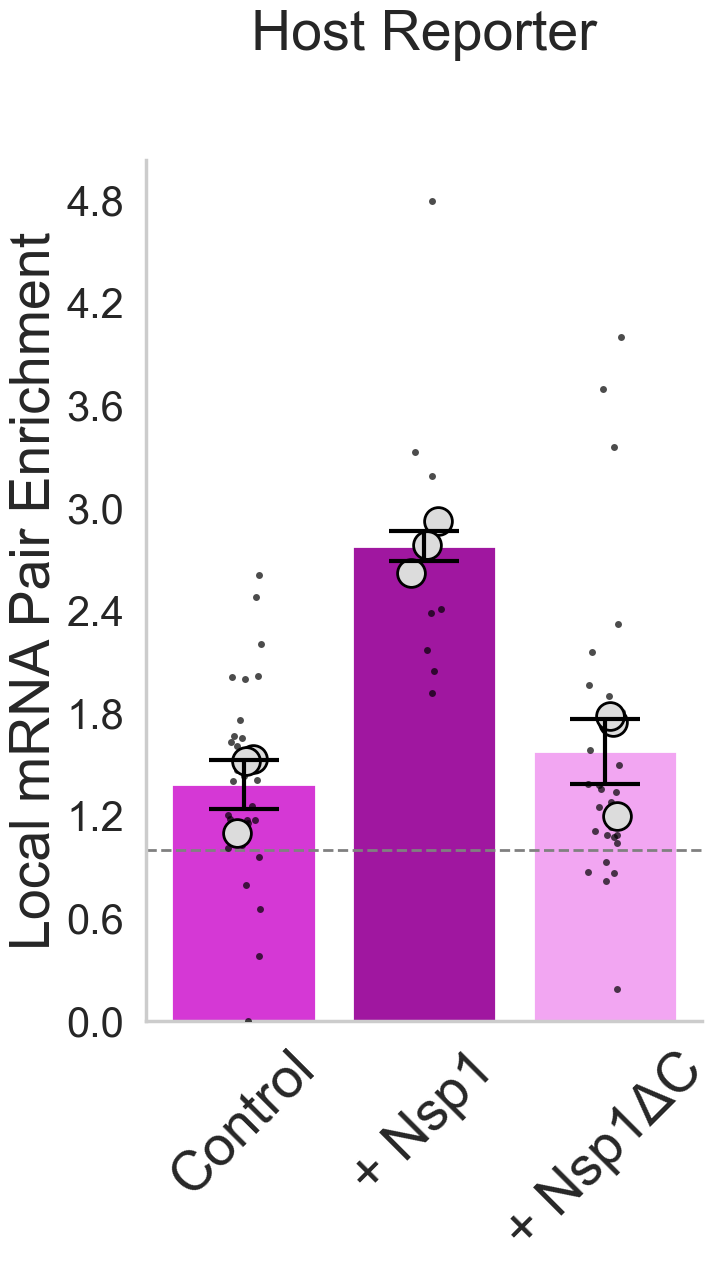

In [82]:
# HOST REPORTER
# HARD-CORE LOCAL mRNA PAIR ENRICHMENT
# ============================================================

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator


# ============================================================
# DATA
# ============================================================

# SELECT EXPERIMENTAL GROUP
# ============================================================

group_to_plot = "SARS_CTRL"


data = (

    all_hc_pair_cell_df.loc[

        all_hc_pair_cell_df[
            "Experimental Group"
        ].eq(
            group_to_plot
        )

    ]

    .copy()
)


order = [
    "No Nsp1",
    "Nsp1",
    "NoCTD Nsp1",
]


data = data.loc[
    data[
        "Experimental Type"
    ].isin(
        order
    )
].copy()


# ============================================================
# METRIC
# ============================================================

metric = (
    "Hard-Core Pair Enrichment"
)


# ============================================================
# LABELS
# ============================================================

new_labels = [
    "Control",
    "+ Nsp1",
    "+ Nsp1ΔC",
]


plot_title = (
    "Host Reporter"
)


y_label = (
    "Local mRNA Pair Enrichment"
)


# ============================================================
# BIOLOGICAL REPLICATE AVERAGES
# ============================================================

superplot = calculate_grouped_average(

    data,

    metric,

    [
        "Experimental Group",
        "Experimental Type",
        "Replicate_Number"
    ]
)


super_col = (
    f"Super {metric}"
)

pair_enrichment_stats = print_paired_ttest_summary(

    data=superplot,

    x="Experimental Type",

    y=super_col,

    pair_col="Replicate_Number",

    order=order,

    alternative="two-sided",

    hide_ns=False,

    verbose=True,
)


display(
    pair_enrichment_stats
)
# ============================================================
# MEAN +/- SEM ACROSS REPLICATES
# ============================================================

bar_stats = (

    superplot

    .groupby(
        "Experimental Type"
    )[
        super_col
    ]

    .agg(
        Mean="mean",
        SD="std",
        SEM="sem",
        N="count"
    )

    .reindex(
        order
    )

    .reset_index()
)


display(
    bar_stats
)


# ============================================================
# STYLE
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)


# ============================================================
# FIGURE SETTINGS
# ============================================================

figsize = (
    8,
    12
)


y_min = 0

# Change manually after inspecting plot.
y_max = None


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(

    figsize=figsize,

    constrained_layout=True
)


sns.despine(

    fig=fig,

    top=True,

    right=True,

    left=False,

    bottom=False
)


# ============================================================
# BARS
# ============================================================

sns.barplot(

    x="Experimental Type",

    y=super_col,

    data=superplot,

    order=order,

    ax=ax,

    palette=magenta_palette,

    errorbar=None,
)


# ============================================================
# CELL VALUES
# ============================================================

sns.stripplot(

    x="Experimental Type",

    y=metric,

    data=data,

    order=order,

    color="black",

    alpha=0.7,

    size=5,

    jitter=True,

    ax=ax,

    zorder=9,
)


# ============================================================
# BIOLOGICAL REPLICATE VALUES
# ============================================================

plot_open_circles_with_hue(

    ax,

    superplot,

    order=order,

    x="Experimental Type",

    y=super_col,

    hue="Experimental Group",

    size=20,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,

    zorder=10,
)


# ============================================================
# SEM
# ============================================================

xpos = np.arange(
    len(order)
)


for i, experimental_type in enumerate(
    order
):


    row = bar_stats.loc[

        bar_stats[
            "Experimental Type"
        ].eq(
            experimental_type
        )

    ]


    if row.empty:
        continue


    mean_value = row[
        "Mean"
    ].iloc[0]


    sem_value = row[
        "SEM"
    ].iloc[0]


    if (
        pd.isna(
            mean_value
        )
        or
        pd.isna(
            sem_value
        )
    ):

        continue


    ax.errorbar(

        xpos[i],

        mean_value,

        yerr=
            sem_value,

        fmt="none",

        elinewidth=3,

        capsize=25,

        capthick=3,

        color="black",

        zorder=11,
    )


# ============================================================
# DIFFUSE NULL
#
# 1 = expected local pairing after matching:
#
# cell geometry
# RNA density
# radial localization
# minimum resolvable distance
# ============================================================

ax.axhline(

    1,

    color="gray",

    linestyle="--",

    linewidth=2,

    zorder=1
)


# ============================================================
# LABELS
# ============================================================

ax.set_title(

    plot_title,

    fontsize=40,

    pad=80
)


ax.set_ylabel(

    y_label,

    fontsize=40
)


ax.set_xlabel(
    ""
)


# ============================================================
# AXES
# ============================================================

if y_max is None:

    current_low, current_high = (
        ax.get_ylim()
    )


    ax.set_ylim(
        y_min,
        current_high
    )

else:

    ax.set_ylim(
        y_min,
        y_max
    )


ax.tick_params(

    axis="both",

    which="major",

    labelsize=30
)


ax.yaxis.set_major_locator(

    MaxNLocator(
        nbins=10
    )
)


ax.set_xticklabels(

    new_labels,

    fontsize=40,

    rotation=45
)


# ============================================================
# REMOVE LEGEND
# ============================================================

if ax.get_legend() is not None:

    ax.get_legend().remove()


# ============================================================
# SAVE
# ============================================================

filename_svg = os.path.join(

    clustering_out_dir,

    "Host Reporter Hard-Core mRNA Pair Enrichment.svg"
)


filename_png = os.path.join(

    clustering_out_dir,

    "Host Reporter Hard-Core mRNA Pair Enrichment.png"
)


fig.savefig(
    filename_svg,
    format="svg",
    dpi=300
)


fig.savefig(
    filename_png,
    format="png",
    dpi=300
)


plt.tight_layout()

plt.show()

Across x, paired by replicate:
No Nsp1 vs Nsp1: n_pairs=3, mean=1.09/1.07, mean_diff=-0.0229, p=0.543, ns


,test_group,contrast,x0,x1,hue0,hue1,n_pairs,mean0,mean1,pvalue,stars,paired_by,mean_diff_x1_minus_x0
0,x|paired_baseline,No Nsp1 vs Nsp1,No Nsp1,Nsp1,None,None,3,1.089177,1.066265,0.54332,ns,Replicate_Number,-0.022912


,Experimental Type,Mean,SD,SEM,N
0,No Nsp1,1.089177,0.065643,0.037899,3
1,Nsp1,1.066265,0.014925,0.008617,3


C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3993339824.py:229: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3993339824.py:229: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(
C:\Users\AdamC\AppData\Local\Temp\ipykernel_30116\3993339824.py:527: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


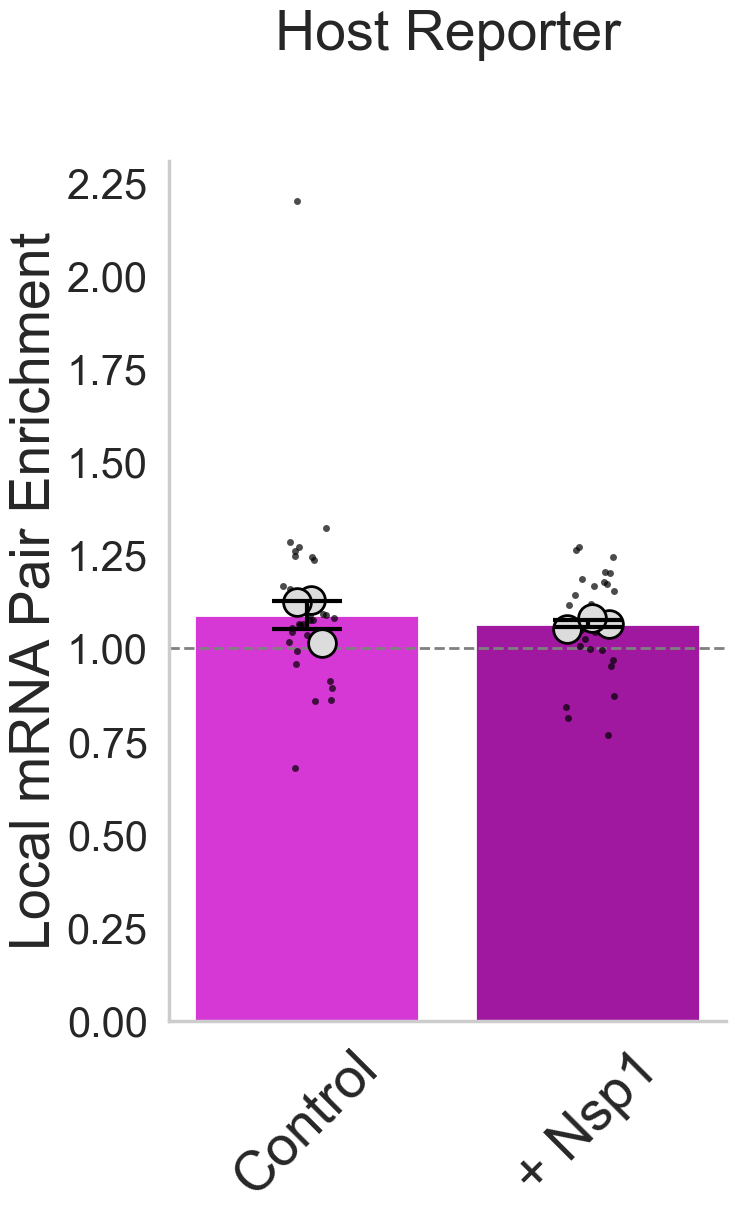

In [83]:
# ZNF_HOST REPORTER
# HARD-CORE LOCAL mRNA PAIR ENRICHMENT
# ============================================================

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator


# ============================================================
# DATA
# ============================================================

# SELECT EXPERIMENTAL GROUP
# ============================================================

group_to_plot = "ZNF_SARS_CTRL"


data = (

    all_hc_pair_cell_df.loc[

        all_hc_pair_cell_df[
            "Experimental Group"
        ].eq(
            group_to_plot
        )

    ]

    .copy()
)


order = [
    "No Nsp1",
    "Nsp1",
]


data = data.loc[
    data[
        "Experimental Type"
    ].isin(
        order
    )
].copy()


# ============================================================
# METRIC
# ============================================================

metric = (
    "Hard-Core Pair Enrichment"
)


# ============================================================
# LABELS
# ============================================================

new_labels = [
    "Control",
    "+ Nsp1",
]


plot_title = (
    "Host Reporter"
)


y_label = (
    "Local mRNA Pair Enrichment"
)


# ============================================================
# BIOLOGICAL REPLICATE AVERAGES
# ============================================================

superplot = calculate_grouped_average(

    data,

    metric,

    [
        "Experimental Group",
        "Experimental Type",
        "Replicate_Number"
    ]
)


super_col = (
    f"Super {metric}"
)

pair_enrichment_stats = print_paired_ttest_summary(

    data=superplot,

    x="Experimental Type",

    y=super_col,

    pair_col="Replicate_Number",

    order=order,

    alternative="two-sided",

    hide_ns=False,

    verbose=True,
)


display(
    pair_enrichment_stats
)
# ============================================================
# MEAN +/- SEM ACROSS REPLICATES
# ============================================================

bar_stats = (

    superplot

    .groupby(
        "Experimental Type"
    )[
        super_col
    ]

    .agg(
        Mean="mean",
        SD="std",
        SEM="sem",
        N="count"
    )

    .reindex(
        order
    )

    .reset_index()
)


display(
    bar_stats
)


# ============================================================
# STYLE
# ============================================================

sns.set(
    font_scale=1.9
)

sns.set_style(
    "whitegrid",
    {
        "grid.linestyle": ""
    }
)

sns.set_context(
    "poster"
)


# ============================================================
# FIGURE SETTINGS
# ============================================================

figsize = (
    8,
    12
)


y_min = 0

# Change manually after inspecting plot.
y_max = None


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(

    figsize=figsize,

    constrained_layout=True
)


sns.despine(

    fig=fig,

    top=True,

    right=True,

    left=False,

    bottom=False
)


# ============================================================
# BARS
# ============================================================

sns.barplot(

    x="Experimental Type",

    y=super_col,

    data=superplot,

    order=order,

    ax=ax,

    palette=magenta_palette,

    errorbar=None,
)


# ============================================================
# CELL VALUES
# ============================================================

sns.stripplot(

    x="Experimental Type",

    y=metric,

    data=data,

    order=order,

    color="black",

    alpha=0.7,

    size=5,

    jitter=True,

    ax=ax,

    zorder=9,
)


# ============================================================
# BIOLOGICAL REPLICATE VALUES
# ============================================================

plot_open_circles_with_hue(

    ax,

    superplot,

    order=order,

    x="Experimental Type",

    y=super_col,

    hue="Experimental Group",

    size=20,

    jitter=True,

    jitter_strength=0.08,

    random_state=100,

    zorder=10,
)


# ============================================================
# SEM
# ============================================================

xpos = np.arange(
    len(order)
)


for i, experimental_type in enumerate(
    order
):


    row = bar_stats.loc[

        bar_stats[
            "Experimental Type"
        ].eq(
            experimental_type
        )

    ]


    if row.empty:
        continue


    mean_value = row[
        "Mean"
    ].iloc[0]


    sem_value = row[
        "SEM"
    ].iloc[0]


    if (
        pd.isna(
            mean_value
        )
        or
        pd.isna(
            sem_value
        )
    ):

        continue


    ax.errorbar(

        xpos[i],

        mean_value,

        yerr=
            sem_value,

        fmt="none",

        elinewidth=3,

        capsize=25,

        capthick=3,

        color="black",

        zorder=11,
    )


# ============================================================
# DIFFUSE NULL
#
# 1 = expected local pairing after matching:
#
# cell geometry
# RNA density
# radial localization
# minimum resolvable distance
# ============================================================

ax.axhline(

    1,

    color="gray",

    linestyle="--",

    linewidth=2,

    zorder=1
)


# ============================================================
# LABELS
# ============================================================

ax.set_title(

    plot_title,

    fontsize=40,

    pad=80
)


ax.set_ylabel(

    y_label,

    fontsize=40
)


ax.set_xlabel(
    ""
)


# ============================================================
# AXES
# ============================================================

if y_max is None:

    current_low, current_high = (
        ax.get_ylim()
    )


    ax.set_ylim(
        y_min,
        current_high
    )

else:

    ax.set_ylim(
        y_min,
        y_max
    )


ax.tick_params(

    axis="both",

    which="major",

    labelsize=30
)


ax.yaxis.set_major_locator(

    MaxNLocator(
        nbins=10
    )
)


ax.set_xticklabels(

    new_labels,

    fontsize=40,

    rotation=45
)


# ============================================================
# REMOVE LEGEND
# ============================================================

if ax.get_legend() is not None:

    ax.get_legend().remove()


# ============================================================
# SAVE
# ============================================================

filename_svg = os.path.join(

    clustering_out_dir,

    "ZNF_Host Reporter Hard-Core mRNA Pair Enrichment.svg"
)


filename_png = os.path.join(

    clustering_out_dir,

    "ZNF_Host Reporter Hard-Core mRNA Pair Enrichment.png"
)


fig.savefig(
    filename_svg,
    format="svg",
    dpi=300
)


fig.savefig(
    filename_png,
    format="png",
    dpi=300
)


plt.tight_layout()

plt.show()